# One Number Can't Tell 8 Billion Stories
## Notebook de análisis reproducible · ASA International DataQuest 2026 · UN World Population Prospects 2024

**UNALSta-R · Statistics students · Universidad Nacional de Colombia, Bogotá** · cifras v1 congeladas el **2026-10-23** · datos: UN DESA, *World Population Prospects 2024* (CC BY 3.0 IGO).

Este notebook ejecuta, de principio a fin y en este orden, `R/01_preparar_datos.R`, `R/02_q1_palancas.R`, `R/03_q2_un_numero.R`, `R/04_q3_caminos.R` y `R/05_numbers_json.R`. El código de cada celda es **copia literal** de esos scripts (lo genera `notebook/construir_notebook.py`, que corta las celdas solo en los encabezados de sección y nunca dentro de una expresión de R): correr el notebook o correr los scripts con `Rscript` da las mismas cifras. Todas las cifras del vídeo y de las diapositivas salen de `figures/numbers.json`, que se escribe en la sección 7.

**Cómo se ejecuta** (desde la raíz del repositorio; ≈ 20 minutos con 14 núcleos, la mayor parte en Q1):

```bash
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600 notebook/analisis_wpp2024.ipynb
python -I notebook/exportar_html.py   # HTML (nbconvert + texto alternativo en cada figura)
```

Los archivos crudos de la ONU (`WPP2024_Demographic_Indicators_Medium_csv.gz`, `WPP2024_Demographic_Indicators_OtherVariants_csv.gz` y el suplemento `WPP2024_Supplement_Births_and_LE60.csv`) viven en la carpeta **padre** del repositorio (pesan demasiado para versionarse; ver `data/raw/README.md`).

**Contenido.** 0 Fuentes, licencia y aptitud de los datos · 1 Decisiones de datos (`R/01`) · 2 Hipótesis preinscritas · 3 Q1 — palancas (`R/02`) · 4 Q2 — un solo indicador (`R/03`) · 5 Q3 — caminos y qué vigilar (`R/04`) · 6 Estado de las hipótesis · 7 `numbers.json` (`R/05`) · 8 Lo que probamos y lo que no encontramos · 9 Limitaciones y consideraciones éticas · 10 Reproducibilidad · 11 Referencias.

> **Convenciones que valen para todo el notebook**
> - Código y comentarios en español; títulos, ejes y textos de las gráficas en inglés.
> - **País** = fila con `ISO3_code` no vacío: **237 países y áreas**, cada uno contado una vez. Los agregados de la ONU (mundo, regiones, grupos de ingreso) **nunca** entran en un análisis entre países; solo se usan para líneas regionales y comprobaciones.
> - Modelos, correlaciones, PCA, clustering, panel y Moran usan los **161 países con ≥ 1 M de habitantes en 2023**; mapas y conteos usan los 237.
> - **Estimaciones 1950–2023** ("Estimate") y **proyección Medium 2024–2100** ("UN medium projection") van siempre separadas y rotuladas; ningún estadístico usa una ventana que cruce 2023/2024.
> - **Intervalos:** IC 95 % por *bootstrap* por bloques de las 20 subregiones ONU (B = 2 000, semilla 2026), el único que puede salir en pantalla junto con Wilson (proporciones), Kaplan–Meier (tiempos) y los intervalos de predicción de la ONU. Describen la **sensibilidad a qué países (o regiones) entran**, no un error muestral: los países no son una muestra.
> - **Nada es causal.** Usamos "va con", "precede", "dentro del mismo país", "entre países"; nunca "causa", "impulsa" ni "efecto de".
> - Cada sección lleva su etiqueta: *Pre-specified (H…)* = la afirmación estaba fijada antes de la corrida final; *Exploratory* = sugerida por los propios datos; *Descriptive* = conteo o descripción sin hipótesis.
> - `set.seed(2026)` justo antes de cada remuestreo, permutación o k-means; `RNGkind("Mersenne-Twister", "Inversion", "Rejection")`.

## Tesis, tres preguntas y mapa a las preguntas oficiales (P1–P8)

**Tesis (una frase).** Ningún indicador cuenta por sí solo la historia de la población de un país; la historia útil para la ONU aparece cuando se leen juntos los tres componentes del balance — nacimientos, defunciones y migración — y se mira cómo se movieron durante 70 años, porque el componente que domina cambia con la etapa de la transición, la región y el nivel de ingreso.

**Gancho (2023, 237 países y áreas).** 130 tienen fecundidad bajo el reemplazo; 84 de ellos aún crecen: 66 porque nacen más personas de las que mueren y 18 solo porque llegan más de las que se van.

| # | Pregunta (texto en pantalla) | Preguntas oficiales | Sección |
|---|---|---|---|
| **Q1** | *Which lever moves each country's population — births, deaths or migration — and does the answer depend on region and income?* | **P7** (central) + **P4** + parte de **P1** (calendario) + nota **P2/P3** (incertidumbre de EAU) | 3 |
| **Q2** | *Can a single indicator tell the whole story, or does it only emerge when several are read together?* | **P8** (central) + **P5** | 4 |
| **Q3** | *Do countries travel the same demographic road at different speeds — and what should the UN watch on each?* | **P6** + **P1** + recomendaciones | 5 |

**Respuesta a cada pregunta oficial, con las cifras de esta corrida** (de `figures/numbers.json`):

| Pregunta oficial | Dónde | Respuesta corta |
|---|---|---|
| **P1** · ¿Divergen las estructuras de edad entre países? | Q3 §7; Q1 §6 | Depende del indicador: más cerca en esperanza de vida al nacer (DE entre países 12,2 → 7,4 años, 1950 → 2023), más lejos en edad mediana (DE 4,7 → 9,7) y en esperanza de vida a los 65 (DE 1,47 → 2,85); en mortalidad infantil, el décimo más alto pasó de 6 a 20 veces la tasa del décimo más bajo. |
| **P2/P3** (opcionales, OtherVariants) · Incertidumbre de las proyecciones | Q1 §9 | Una sola banda visible: EAU 2050 = 15,4 M (IP 95 % de la ONU 8,9–33,3 M); en 77 de 161 países el IP 95 % de 2050 incluye crecer y decrecer. Low/High se tratan como escenarios, no como incertidumbre. |
| **P4** · Migración neta frente a crecimiento, por región | Q1 §2–§3 | En los países hoy de ingreso alto la migración neta aporta el 70,7 % del crecimiento 2000–2023 (IC por bloques 55,5–133,3; 64,0 % con los agregados de ingreso de la ONU); en los otros grupos resta. 18 países y áreas crecen solo por migración en 2023. |
| **P5** · Un índice que combine indicadores | Q2 §8 | Los pesos deciden: en 2 000 diseños razonables, el 21,7 % de los países puede moverse más de 20 puestos; si solo cambian las fórmulas, el 2,5 %. Es un índice de etapa de la transición, no un ranking de desarrollo. |
| **P6** · ¿Forman grupos por cómo se movieron? | Q3 §2–§6 | Sí, con fronteras suaves: k = 4 (silueta 0,37) = tres tramos de un mismo camino (*Early, Fast, Recent movers*) más un grupo *Migration-led*; dos de cada tres enlaces entre vecinos unen países del mismo grupo (0,67 frente a 0,30 al azar), y el 42 % de los países queda entre dos grupos. |
| **P7** · Fecundidad, mortalidad y migración juntas; región e ingreso | Q1 §5–§8 | La mortalidad infantil empezó a caer primero en 106 de 109 países de alta fecundidad (97 %), típicamente al menos 22 años antes; la fecundidad empezó a caer hacia 1970 / 1984 / 2000 en los países hoy de ingreso medio-alto / medio-bajo / bajo. Dentro del mismo país, la mitad de mortalidad infantil va con −0,41 hijos por mujer en 20 años, frente a −1,05 entre países. La migración va por su cuenta: memoria corta (0,32–0,69 entre décadas) y casi sin vecindario (Moran 0,11; −0,03 sin el Golfo). |
| **P8** · ¿Un solo indicador cuenta toda la historia? | Q2 §2–§7 | No. La fecundidad sola reproduce el 77 % de las diferencias de edad mediana, el 59 % del crecimiento y nada de la migración; encuentra el 13 % de los 5 países más parecidos (dos ejes del PCA: 43 %; azar: 3 %). Hay 2 dimensiones reales: la transición y la migración. |

## 0. Fuentes, licencia y aptitud de los datos (*fitness for use*)

| Fuente | Qué usamos | Licencia / atribución |
|---|---|---|
| United Nations, DESA, Population Division (2024). *World Population Prospects 2024*, Online Edition | `WPP2024_Demographic_Indicators_Medium_csv.gz` (estimaciones 1950–2023 y proyección Medium 2024–2100; archivo original de julio de 2024) | CC BY 3.0 IGO. Cambios: agregamos, modelamos y graficamos los datos; la ONU no avala este trabajo. |
| ídem | `WPP2024_Demographic_Indicators_OtherVariants_csv.gz`, **solo** columnas de una lista blanca (`TPopulation1July, TFR, LEx, LExMale, LExFemale, CNMR, NetMigrations, CBR, CDR, IMR, Births, Deaths, NatChange, PopGrowthRate`) con el test de monotonía L95 ≤ L80 ≤ mediana ≤ U80 ≤ U95 | ídem; intervalos de predicción marginales por país, **no sumables** |
| Suplemento del DataQuest 2026 (organizadores, desde el UN Data Portal) | `WPP2024_Supplement_Births_and_LE60.csv` (LE60, nacimientos por sexo): solo robustez de P1 | crédito a los organizadores |
| World Bank (2026). *Country and Lending Groups, FY2027* | `data/raw/wb_api_income_2026-10-22.csv` (API, 2026-10-22): grupos de ingreso de hoy, **aplicados a todos los años** | CC BY 4.0 |
| Natural Earth | puntos y polígonos para Moran, vecinos y mapas de revisión | dominio público |

**Aptitud de los datos para lo que hacemos (ASA B.1, D.10).**
- Las cifras de 1950–2023 son **estimaciones modelizadas** por la ONU, no observaciones directas; desde 2024 todo es proyección Medium (media de trayectorias probabilísticas para fecundidad y esperanza de vida; mediana para migración, que en WPP 2024 es probabilística por primera vez).
- **La migración neta es el componente peor medido**: a menudo se estima como residuo entre censos, no distingue entradas de salidas y la ONU la ajusta para que el total mundial sea cero.
- La revisión de la población de EAU entre WPP 2022 y WPP 2024 (`are_revision_pct` = 12 %) es una **cifra externa** tomada del memo de ética: no se puede calcular con los archivos de WPP 2024 y debe verificarla una persona antes de usarse.
- **No calculado en este notebook:** la cobertura censal (`n_census_pre2009`, `n_census_2019plus`) necesita la tabla de fuentes censales de la ONU, que no está en el repositorio; la sensibilidad con la *Interim Update* de Togo (19-ene-2026) y el calendario de choques de las proyecciones (`n_shock_years_*`, `share_monotone_proj_lex`) tampoco se corrieron. Quedan como claves faltantes de `numbers.json` (sección 7), no como cifras.

La celda siguiente fija la carpeta de trabajo en la raíz del repositorio (como `Rscript` desde la raíz), confirma la corrida oficial (sin el modo rápido de desarrollo de Q1), comprueba que existen los crudos y deja dos ayudas del notebook en un entorno adjunto (`nb_ayudas`) que sobrevive al vaciado del entorno global de cada pregunta.

In [1]:
# Preparación del notebook (no forma parte de los scripts R/0X).
setwd(here::here())                       # raíz del repo, como `Rscript R/0X_*.R`
Sys.unsetenv("Q1_RAPIDO")                 # corrida oficial: B = 2000 (nunca el modo rápido)
options(width = 160, crayon.enabled = FALSE, cli.num_colors = 1)   # salida de consola sin códigos de color

crudos <- c(Medium        = file.path(dirname(getwd()), "WPP2024_Demographic_Indicators_Medium_csv.gz"),
            OtherVariants = file.path(dirname(getwd()), "WPP2024_Demographic_Indicators_OtherVariants_csv.gz"),
            Suplemento    = file.path(dirname(getwd()), "WPP2024_Supplement_Births_and_LE60.csv"))
stopifnot(all(file.exists(crudos)))
print(data.frame(archivo = basename(crudos), MB = round(file.size(crudos) / 2^20, 1),
                 sha256 = vapply(crudos, function(f) digest::digest(file = f, algo = "sha256"), character(1)),
                 row.names = names(crudos)))

# Ayudas del notebook en un entorno adjunto (sobrevive a rm(list = ls()) de cada pregunta).
if ("nb_ayudas" %in% search()) detach("nb_ayudas")
local({
  ayudas <- new.env()
  ayudas$NB_T0 <- Sys.time()
  # Muestra figuras de revisión reducidas a `ancho` px (los PNG originales no se tocan).
  ayudas$mostrar_figuras <- function(carpeta, nombres, ancho = 1200) {
    for (n in nombres) {
      f <- here::here("figures", "review", carpeta, paste0(n, ".png"))
      if (!file.exists(f)) { message("No existe ", f); next }
      img <- magick::image_resize(magick::image_read(f), paste0(ancho, "x"))
      tmp <- tempfile(fileext = ".png")
      magick::image_write(img, tmp, format = "png")
      IRdisplay::display_markdown(sprintf("**`figures/review/%s/%s.png`** (figura de revisión, no final)", carpeta, n))
      IRdisplay::display_png(file = tmp)
      unlink(tmp)
    }
    invisible(NULL)
  }
  # Ejecuta un script de pruebas en un proceso aparte (sale con estado 1 si falla).
  ayudas$correr_pruebas <- function(script) {
    salida <- system2(file.path(R.home("bin"), "Rscript"), shQuote(here::here("R", script)),
                      stdout = TRUE, stderr = TRUE)
    cat(salida, sep = "\n")
    st <- attr(salida, "status")
    if (!is.null(st) && st != 0) stop(script, " falló (estado ", st, ")", call. = FALSE)
    invisible(TRUE)
  }
  # Vacía el entorno global: cada pregunta corre como un Rscript nuevo.
  ayudas$entorno_limpio <- function() {
    rm(list = ls(envir = globalenv(), all.names = TRUE), envir = globalenv())
    invisible(gc())
    setwd(here::here())
    invisible(TRUE)
  }
  attach(ayudas, name = "nb_ayudas")
})
cat("R", R.version.string, "| inicio", format(get("NB_T0", "nb_ayudas")), "| carpeta", getwd(), "\n")

                                                          archivo   MB                                                           sha256
Medium               WPP2024_Demographic_Indicators_Medium_csv.gz 15.8 286ac36bb1415e2e1ade03acfef0a29f0e4c087e2f78e38c48f50c5df89082bc
OtherVariants WPP2024_Demographic_Indicators_OtherVariants_csv.gz 71.9 a860504df54877e4c19788bf6e16920d6017d021b4c149eaf8b5662674180a54
Suplemento                 WPP2024_Supplement_Births_and_LE60.csv  2.0 26d89cf8092b89c6a97a38da0009fcc7454c958b73fe80ed822fd4339ce72510


R R version 4.6.1 (2026-06-24) | inicio 2026-10-24 09:43:41 | carpeta /home/darkns/Documents/ASA_Dataquest/RepoGithub 


## 1. Decisiones de datos (`R/01_preparar_datos.R`)

Esta tabla es la §3 del plan analítico (`docs/00_plan_analitico.md`, versión 2), que manda sobre cualquier otra fuente. Cada decisión se implementa en `R/01_preparar_datos.R`, en `R/comun_analisis.R` (muestras, ventanas, tipos de palanca) o en el script de la pregunta que la usa.

| Decisión | Elección v2 | Justificación / sensibilidad |
|---|---|---|
| Archivo base | `WPP2024_Demographic_Indicators_Medium_csv.gz` (archivo original jul-2024) + suplemento LE60 (organizadores) + **OtherVariants solo con lista blanca** (ver abajo) | Guía oficial. Togo: sensibilidad con el *Interim Update* de ene-2026 **[ET #2]**. |
| Países vs agregados | País ⇔ `ISO3_code` no vacío (237 = 195 Estados soberanos + 42 territorios/áreas, columna `soberano` en `lookup_regiones.csv` **[01b A9]**). Agregados solo para líneas regionales. | Tests de `R/tests_datos.R` (suma por región SDG = agregado, dif. máx. 7×10⁻⁶ % **[03]**). |
| Región | 8 regiones SDG (`Region_SDG` en `paises.parquet`; `region_sdg` en `lookup_regiones.csv`), etiquetas exactas de `R/config.R` (`"Oceania (excluding Australia and New Zealand)"`, …); ParentID 918 a mano. En panel: Oceanía unida (3 países ≥ 1 M) **[PN]**. | Nomenclatura ONU. |
| Ingreso | **World Bank FY2027** (`data/raw/wb_api_income_2026-10-22.csv`, GNI per cápita 2025, Atlas), columna `Ingreso` / `ingreso_bm` con niveles `"Low income"`, `"Lower middle income"`, `"Upper middle income"`, `"High income"`, `"Not classified"`; **aplicada a todos los años**. Rotular siempre *"today's income groups (World Bank FY2027)"*. | FY2026 de v1 era un error de etiqueta **[ET #17][DEM O4][ST][MV][PN]**. El grupo de hoy es en parte **resultado** de la transición: todo gradiente por ingreso es descriptivo. **No validar contra los agregados de ingreso de la ONU** (usan la clasificación de mayo-2024: alto 1 261 M vs 1 393 M) **[DEM O5]**; usarlos solo como sensibilidad (H1: 64,0 % **[03]**). |
| Estimaciones vs proyecciones | ≤ 2023 = evidencia; ≥ 2024 = escenario Medium, gris/punteado, línea 2023/24. **Ningún** estadístico (correlación, rezago, β, σ, panel, Moran) usa ventanas que crucen 2023/24 **[ST §2.5]**. Animaciones: el contador de año cambia a gris "UN projection" tras 2023, pausa 1 s, sin interpolar 2023→2024. | Medium = **media** de trayectorias para TFR/LEx y **mediana** para migración; la migración es probabilística por primera vez en WPP2024 **[INF]**. |
| Año 2101 | Se elimina. | — |
| Microestados | ≥ 1 M en 2023 (`pob_1m`, 161 países) para correlaciones, modelos, PCA, índice, clustering, panel, Moran; los 237 en mapas y conteos (franja de pequeños Estados). Todo conteo en pantalla con ambos números: `18 (11 with ≥ 1 M people)`. | Los microestados cambian el signo de H5 **[ST][MV]**. Sensibilidad con 237 siempre. |
| **Año base de la palanca** | **2023** (una sola definición en portada, mapa, guion y `numbers.json`). Sensibilidad: 2017–19 (pre-COVID), 2021, 2022 y promedio 2021–23. Tipo C: 18 (2023) · 14 (2017–19) · 15 / 25 (2021 / 2022) · 24 (2021–23) → en pantalla `18 (15–25 depending on the year)` **[DEM][INF]**. | La ventana 2021–23 **no suaviza**: contiene el exceso de muertes por COVID y el desplazamiento desde Ucrania (Polonia pasaría a "crece solo por migración") **[DEM O3]**. Conflicto con ética/inferencia resuelto en `07` §3. |
| Tipos de palanca (Webb) | En el notebook, con 2023: **A** NatChange > 0, NetMigrations > 0, PopChange > 0 · **B** NatChange > 0, NetMigrations ≤ 0, PopChange > 0 · **C** NatChange < 0, PopChange > 0 · **D** NatChange < 0, PopChange < 0 · **E** NatChange > 0, PopChange < 0. (`R/01_preparar_datos.R` funde A y B en `A_B_crece_saldo_natural`; el notebook crea `tipo_palanca_2023` con A y B separados.) 2023: A 71 · B 94 · C 18 · D 35 · E 19 (≥ 1 M: 48 · 72 · 11 · 24 · 6) **[INT]**. | Definición en pantalla: `Lever type = which term of the balance dominates today — not a stage of development` **[DEM]**. |
| Reemplazo | TFR < 2,1 (principal, comparable); sensibilidad NRR < 1 (también 130; entran Indonesia y Myanmar) y umbrales 2,0 / 2,2 (124–138) **[DEM O2][INF]**. En pantalla: *"about 2.1 children per woman where almost every child survives"*. | — |
| Medición demográfica | Cambios con `PopChange` / 1 de enero; participaciones con **sumas de personas**, nunca sumas de tasas; ‰ y % nunca se suman; crecimiento acumulado con `exp(Σ r/100)` **[DEM §2.1]**. CDR solo como "carga de defunciones"; mortalidad se compara con LEx, Q5 (log), Q1560, LE65. | r(CDR, LEx) 2023 ≈ 0 **[DEM][INF]**. |
| P1 vejez | **LE65** (archivo oficial) principal; LE60 (suplemento) como robustez, con crédito a los organizadores **[DEM O16]**. | LE65: DE 1,47 → 2,85 (1950 → 2023) **[DEM]**. |
| Migración extrema | CNMR winsorizada ±3 DE solo para PCA y clustering; documentar a quién afecta: 7 países en 2023 (SSD, TCD, SDN, ARM, OMN, SYR, ARE) y 144 país-años en el panel (QAT 25, ARE 22, KWT 17, DJI 9, HKG 8, JOR 8) **[MV]**; sensibilidad `asinh(CNMR/5)` (ARI 0,93). Constante `GOLFO <- c("ARE","QAT","KWT","BHR","OMN","SAU")` **[PN]**. | — |
| Correlaciones en el tiempo | **Prohibido** correlacionar niveles a lo largo del tiempo (placebo: ρ(TFR, LEx) dentro de país −0,84 = ρ con un país al azar −0,84) **[ST]**. Solo: transversal por año, diferencias largas, panel en cambios. | — |
| Inferencia e incertidumbre | Unidad de remuestreo = país (nunca país-año); `set.seed(2026)` justo antes de cada remuestreo; B = 2 000 (BCa) para cocientes, R² y correlaciones; B = 1 000 (percentil) para PCA **[INF]**. **Todo intervalo que aparezca en pantalla** se calcula por **bootstrap por bloques de las 20 subregiones ONU** (`method: "block bootstrap by subregion"` en `numbers.json`; los IC por bloques salen 1,4–2,2× más anchos que los iid) **[SP]**; el notebook guarda ambos (`ci_iid_*`). Conteos = censo: sin IC, con rango entre definiciones (`none_census`). Proporciones de países: Wilson. Tiempos hasta el evento: KM / Turnbull. | Frase fija: los IC describen *"sensitivity to which countries (or regions) are included"*, no error muestral. Cero p-valores y cero "significant" en vídeo y diapositivas **[INF §4][ET #12]**. |
| Censura | Ningún análisis de "años hasta" descarta a los censurados (KM / Turnbull); se dice cuántos hay y por qué **[ST][FDA][INF]**. | — |
| OtherVariants | Lista blanca de columnas válidas en filas PI: `TPopulation1July, TFR, LEx, LExMale, LExFemale, CNMR, NetMigrations, CBR, CDR, IMR, Births, Deaths, NatChange, PopGrowthRate`; test de monotonía L95 ≤ L80 ≤ Median ≤ U80 ≤ U95. **Inválidas** (orden invertido): `MedianAgePop`, `LE15/LE65/LE80`, `Q5`, `Q0040…Q1560` **[INF]**. IP marginales, **no sumables**; Low/High/Constant = **escenarios**, nunca "range of uncertainty". | No existe IP válido de la edad mediana de China (corrige ética #7). |
| Panel | Medias quinquenales 1950–54 … 2020–23 (15 periodos), cambios entre quinquenios, rezagos 0–4 (0–20 años), FE país + periodo, EE agrupados por país; estimación 1975–2023 **[PN]**. Constantes `PERIODO_PANEL <- 5`, `REZAGOS_PANEL <- 0:4`. | Niveles anuales: residuos con autocorrelación 0,98–0,99 (espurio) **[ST][PN][FDA]**. |
| Suavizado funcional | B-splines cúbicos, penalización 2.ª derivada, **λ = 10 fijo** (GCV casi interpola); choques siempre sobre datos crudos **[FDA]**. | Grupos invariantes a λ = 1 y 100. |
| Dependencia espacial | Declarada: TFR conserva Moran I = 0,16 en residuos tras región + ingreso **[SP]**; W = 5 vecinos más cercanos (haversine), fila-estandarizada. | No se estima SAR ni GWR. |
| Identidad contable | `PopChange = NatChange + NetMigrations` (residuo máx. 4,9 mil, Ucrania 1989) y `PopGrowthRate ≈ (CBR − CDR + CNMR)/10`: se presenta como **identidad**; el R² 0,99 de la "escalera" va solo en nota al pie **[ET #8][MV]**. | — |
| Ponderación | País = 1 en modelos; agregados ONU para niveles; en barras de ingreso separar **China** (46 % de la población de medio-alto, 30 % de su saldo natural 2000–23) e **India** (50 % / 40 % de medio-bajo) **[DEM §2.2]**; prueba "¿se sostiene sin el país más grande?". | — |
| Semilla y versiones | `set.seed(2026)`, `RNGkind()` declarado, `sessionInfo()`, `renv.lock`, SHA-256 de los crudos. | ASA B.4, F.4. |

**Variables derivadas obligatorias** (español, en el notebook): `tipo_palanca_2023` (A–E con A y B separados), `inercia_bajo_reemplazo` (B & TFR < 2,1), `es_proyeccion`, `inicio_q5`, `inicio_tfr` (primer año con x ≤ 0,9·máx. previo que no vuelve a superarse; NA = no iniciado), `izq_q5`, `izq_tfr` (máximo en 1950 = censura izquierda), `rezago_inicio_lo/hi` (intervalo para Turnbull), `c4` (año continuo del **último** cruce de TFR = 4 en la curva suavizada; −Inf / +Inf = censura), `c5`, `c3`, `dur_5a3` + `evento_3`, `grupo_trayectoria`, `keep_share` (estabilidad bootstrap por país), `cnmr_w` (winsorizada), `gq5` = log(Q5). **Se eliminan** `anio_q5_100`, `anio_tfr_4` y `rezago` como variables principales (quedan solo en la rejilla de sensibilidad).

In [2]:
# Cada paso de datos corre en un entorno global vacío, como `Rscript R/01_preparar_datos.R`.
entorno_limpio()

In [3]:
#!/usr/bin/env Rscript
# =============================================================================
# 01_preparar_datos.R
# Limpieza y preparación de datos de UN WPP2024 para el ASA DataQuest 2026.
#
# Entrada (fuera del repo, ver data/raw/README.md):
#   ../WPP2024_Demographic_Indicators_Medium_csv.gz   (indicadores, 1950-2101)
#   ../WPP2024_Supplement_Births_and_LE60.csv         (LE60, nacimientos por sexo)
# Entrada (dentro del repo, pequeña, versionada):
#   data/raw/wb_api_income_2026-10-22.csv  (grupos de ingreso, API del Banco
#                                            Mundial, fuente PRINCIPAL)
#   data/raw/WB_income_groups.csv          (mismos grupos, tabla de contraste)
#
# Salida:
#   data/processed/paises.parquet        (NO versionado; 237 países x 1950-2100)
#   data/processed/agregados.parquet     (NO versionado; regiones SDG + ingreso + mundo)
#   data/processed/lookup_regiones.csv   (versionado; ISO3 -> región/ingreso/continente)
#   data/processed/diccionario_variables.csv (versionado; código -> nombre ES/EN, unidad)
#   data/README.md                       (versionado; fuente, licencia, decisiones)
#
# Uso:  Rscript R/01_preparar_datos.R
# =============================================================================

suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(tidyr)
  library(janitor)
  library(countrycode)
  library(here)
})

source(here::here("R", "config.R"))

cat("== 01_preparar_datos.R ==", format(Sys.time()), "\n")

== 01_preparar_datos.R == 2026-10-24 09:43:42 


#### §1 Lectura de los archivos crudos

`R/01_preparar_datos.R` líneas 37–60

In [4]:
# -----------------------------------------------------------------------------
# 1. Lectura de los archivos crudos
# -----------------------------------------------------------------------------
if (!file.exists(RUTA_WPP_MEDIUM)) {
  stop("No se encuentra ", RUTA_WPP_MEDIUM, ". Ver data/raw/README.md para ",
       "descargarlo, o define la variable de entorno WPP_MEDIUM.")
}
cat("Leyendo indicadores:", RUTA_WPP_MEDIUM, "\n")
# readr detecta y descarta el BOM UTF-8 automáticamente.
indicadores_raw <- readr::read_csv(
  RUTA_WPP_MEDIUM, guess_max = 100000, show_col_types = FALSE,
  progress = FALSE
) |> janitor::clean_names(case = "none")
# clean_names(case="none") solo quita el BOM/espacios del nombre de columna,
# sin tocar las mayúsculas (los nombres oficiales de la ONU se mantienen).

cat("Leyendo suplemento (LE60, nacimientos por sexo):", RUTA_WPP_SUPLEMENTO, "\n")
suplemento <- readr::read_csv(
  RUTA_WPP_SUPLEMENTO, show_col_types = FALSE, progress = FALSE
) |> janitor::clean_names(case = "none")

n_filas_crudas <- nrow(indicadores_raw)
cat("Filas leídas (indicadores):", n_filas_crudas, "\n")

Leyendo indicadores: /home/darkns/Documents/ASA_Dataquest/WPP2024_Demographic_Indicators_Medium_csv.gz 


Leyendo suplemento (LE60, nacimientos por sexo): /home/darkns/Documents/ASA_Dataquest/WPP2024_Supplement_Births_and_LE60.csv 


Filas leídas (indicadores): 84360 


#### §2 Año 2101: se descarta (decisión documentada)

`R/01_preparar_datos.R` líneas 61–69

In [5]:
# -----------------------------------------------------------------------------
# 2. Año 2101: se descarta (decisión documentada)
# -----------------------------------------------------------------------------
# 2101 solo trae TPopulation1Jan (todo lo demás es NA); lo dejamos fuera para
# no introducir NA artificiales en correlaciones/regresiones posteriores.
indicadores <- indicadores_raw |> filter(.data$Time <= ANIO_MAX_VALIDO)
cat("Filas tras quitar 2101:", nrow(indicadores),
    "(se quitaron", n_filas_crudas - nrow(indicadores), ")\n")

Filas tras quitar 2101: 83805 (se quitaron 555 )


#### §3 Países vs agregados

`R/01_preparar_datos.R` líneas 70–91

In [6]:
# -----------------------------------------------------------------------------
# 3. Países vs agregados
# -----------------------------------------------------------------------------
# País <=> ISO3_code no vacío (coincide con LocTypeName == "Country/Area").
es_pais <- !is.na(indicadores$ISO3_code) & indicadores$ISO3_code != ""
# readr convierte "" en NA para columnas de texto (default na = c("","NA")),
# así que LocTypeName de los grupos ad-hoc (ADB, BRIC, ...) llega como NA, no
# como "". Se trata esa NA como "no es Country/Area" para la comparación.
es_country_area <- !is.na(indicadores$LocTypeName) & indicadores$LocTypeName == "Country/Area"
n_tipo_pais_distinto <- sum(es_pais != es_country_area)
if (n_tipo_pais_distinto > 0) {
  cat("AVISO: ", n_tipo_pais_distinto, " filas donde ISO3_code vacío/no-vacío",
      " no coincide con LocTypeName == 'Country/Area'. Se usa ISO3_code.\n")
}

paises_raw <- indicadores |> filter(es_pais)
agregados_raw <- indicadores |> filter(!es_pais)

n_paises <- length(unique(paises_raw$ISO3_code))
cat("Países distintos (ISO3_code no vacío):", n_paises,
    "(se esperaban ~237, incl. Holy See)\n")

Países distintos (ISO3_code no vacío): 237 (se esperaban ~237, incl. Holy See)


#### §4 Jerarquía de regiones SDG a partir de ParentID

`R/01_preparar_datos.R` líneas 92–186

In [7]:
# -----------------------------------------------------------------------------
# 4. Jerarquía de regiones SDG a partir de ParentID
# -----------------------------------------------------------------------------
# IMPORTANTE (hallazgo verificado, no es lo que uno asumiría a primera vista):
# el ParentID de un país NO apunta directo a la región SDG. Apunta a la
# subregión geográfica M49 (p. ej. "South America", "Eastern Asia"), y esas
# subregiones a su vez apuntan a una "Geographic region" (Americas/Asia/...),
# que tampoco es la región SDG. Las filas "SDG region" del archivo son un
# agregado PARALELO (mismo LocID 1828 como padre de las 9), no heredado por
# ParentID desde los países. Por eso la región SDG se reconstruye mapeando el
# NOMBRE de la subregión M49 (tabla fija de la ONU) y no siguiendo ParentID
# varios niveles. Verificado: la suma de población de países por este mapeo
# reproduce el agregado SDG publicado para 2023 (ver sección 4.3 más abajo).
subregion_a_sdg <- c(
  "Eastern Africa"   = "Sub-Saharan Africa",
  "Middle Africa"    = "Sub-Saharan Africa",
  "Southern Africa"  = "Sub-Saharan Africa",
  "Western Africa"   = "Sub-Saharan Africa",
  "Northern Africa"  = "Northern Africa and Western Asia",
  "Western Asia"     = "Northern Africa and Western Asia",
  "Central Asia"     = "Central and Southern Asia",
  "Southern Asia"    = "Central and Southern Asia",
  "Eastern Asia"     = "Eastern and South-Eastern Asia",
  "South-Eastern Asia" = "Eastern and South-Eastern Asia",
  "Eastern Europe"   = "Europe and Northern America",
  "Northern Europe"  = "Europe and Northern America",
  "Southern Europe"  = "Europe and Northern America",
  "Western Europe"   = "Europe and Northern America",
  "Caribbean"        = "Latin America and the Caribbean",
  "Central America"  = "Latin America and the Caribbean",
  "South America"    = "Latin America and the Caribbean",
  "Australia/New Zealand" = "Australia/New Zealand",
  "Melanesia"        = "Oceania (excluding Australia and New Zealand)",
  "Micronesia"       = "Oceania (excluding Australia and New Zealand)",
  "Polynesia"        = "Oceania (excluding Australia and New Zealand)"
)
# Northern America (LocID 918) NO aparece como fila propia en este archivo de
# indicadores (hallazgo verificado: el LocID 918 no existe en ninguna fila).
# Se asigna a mano por composición conocida del M49 (ONU): EE.UU., Canadá,
# Bermudas, Groenlandia y Saint-Pierre-et-Miquelon -> "Europe and Northern America".
iso_norteamerica <- c("USA", "CAN", "BMU", "GRL", "SPM")

# Tabla LocID -> (nombre, tipo) en 2023 para resolver el padre de cada país
# (el ParentID es estable en el tiempo, basta con una foto de 2023).
tabla_2023 <- indicadores |> filter(.data$Time == 2023) |>
  select(LocID, Location, LocTypeName, ParentID) |>
  distinct()
id_a_nombre <- setNames(tabla_2023$Location, tabla_2023$LocID)

resolver_subregion <- function(parent_id) {
  id_a_nombre[as.character(parent_id)]
}

paises <- paises_raw |>
  mutate(
    .subregion_m49 = resolver_subregion(ParentID),
    Subregion = unname(.subregion_m49),
    Region_SDG = dplyr::case_when(
      ISO3_code %in% iso_norteamerica ~ "Europe and Northern America",
      TRUE ~ unname(subregion_a_sdg[.subregion_m49])
    )
  ) |>
  select(-.subregion_m49)

n_sin_region <- sum(is.na(paises$Region_SDG[paises$Time == 2023]))
cat("Países (2023) sin Region_SDG asignada:", n_sin_region, "\n")
if (n_sin_region > 0) {
  cat("  ->", paste(unique(paises$ISO3_code[paises$Time == 2023 &
                                             is.na(paises$Region_SDG)]), collapse = ", "), "\n")
}

# --- 4.3 Verificación: suma de países == agregado SDG publicado (2023) -----
pub_sdg_2023 <- agregados_raw |>
  filter(Time == 2023, LocTypeName == "SDG region") |>
  select(Location, TPopulation1July)

calc_sdg_2023 <- paises |> filter(Time == 2023) |>
  group_by(Region_SDG) |>
  summarise(pob_calc = sum(TPopulation1July), .groups = "drop")

verificacion_sdg <- pub_sdg_2023 |>
  inner_join(calc_sdg_2023, by = c("Location" = "Region_SDG")) |>
  mutate(diff_abs = pob_calc - TPopulation1July,
         diff_pct = 100 * diff_abs / TPopulation1July)

cat("\n-- Verificación: suma de países por región SDG vs agregado ONU (2023) --\n")
print(verificacion_sdg, n = 20)
max_diff_pct <- max(abs(verificacion_sdg$diff_pct))
cat("Diferencia porcentual máxima:", round(max_diff_pct, 6), "%\n")
if (max_diff_pct > 0.1) {
  warning("La diferencia máxima supera la tolerancia de 0.1% esperada.")
} else {
  cat("OK: dentro de la tolerancia de 0.1%.\n")
}

Países (2023) sin Region_SDG asignada: 0 



-- Verificación: suma de países por región SDG vs agregado ONU (2023) --


# A tibble: 8 × 5
  Location                                      TPopulation1July pob_calc  diff_abs      diff_pct
  <chr>                                                    <dbl>    <dbl>     <dbl>         <dbl>
1 Sub-Saharan Africa                                    1212229. 1212229. -0.00200  -0.000000165 
2 Northern Africa and Western Asia                       572507.  572507.  0.00300   0.000000524 
3 Central and Southern Asia                             2123893. 2123893. -0.00100  -0.0000000471
4 Eastern and South-Eastern Asia                        2350146. 2350146.  0.00200   0.0000000851
5 Latin America and the Caribbean                        658892.  658892.  0         0           
6 Oceania (excluding Australia and New Zealand)           13939.   13939. -0.001000 -0.00000717  
7 Australia/New Zealand                                   31624.   31624.  0         0           
8 Europe and Northern America                           1128506. 1128506. -0.001000 -0.0000000886


Diferencia porcentual máxima: 7e-06 %


OK: dentro de la tolerancia de 0.1%.


#### §5 Grupos de ingreso del Banco Mundial

`R/01_preparar_datos.R` líneas 187–219

In [8]:
# -----------------------------------------------------------------------------
# 5. Grupos de ingreso del Banco Mundial
# -----------------------------------------------------------------------------
# Fuente principal: copia del API oficial descargada 2026-10-22 (clasificación
# FY2027, publicada en julio de 2026 con el INB per cápita de 2025 -- ver
# data/raw/README.md). Fuente de contraste: WB_income_groups.csv (entregada
# con el proyecto). Verificado en este script: ambas fuentes coinciden al
# 100% en las 296 economías que cubren (0 discrepancias).
wb_api <- readr::read_csv(RUTA_WB_INCOME_API, show_col_types = FALSE) |>
  select(ISO3_code = ISO3, Ingreso = ingreso_api) |>
  mutate(Ingreso = ifelse(Ingreso == "Aggregates", NA_character_, Ingreso))
wb_contraste <- readr::read_csv(RUTA_WB_INCOME_CSV, show_col_types = FALSE) |>
  mutate(Ingreso = ifelse(Ingreso == "Aggregates", NA_character_, Ingreso))

comparacion_wb <- wb_api |>
  inner_join(wb_contraste, by = "ISO3_code", suffix = c("_api", "_csv")) |>
  filter(!is.na(Ingreso_api), !is.na(Ingreso_csv), Ingreso_api != Ingreso_csv)
cat("\nDiscrepancias entre wb_api_income y WB_income_groups.csv:",
    nrow(comparacion_wb), "\n")

paises <- paises |>
  left_join(wb_api, by = "ISO3_code") |>
  mutate(Ingreso = ifelse(is.na(Ingreso), "Not classified", Ingreso))

paises_sin_ingreso_2023 <- paises |> filter(Time == 2023, Ingreso == "Not classified")
cat("Países (2023) sin grupo de ingreso del Banco Mundial ('Not classified'):",
    nrow(paises_sin_ingreso_2023), "\n")
cat("  ->", paste(paises_sin_ingreso_2023$ISO3_code, collapse = ", "), "\n")
pob_m_sin_ingreso <- paises_sin_ingreso_2023 |>
  filter(TPopulation1July * 1000 >= UMBRAL_MICROESTADO)
cat("  de los cuales con población >= 1 millón (2023):",
    paste(pob_m_sin_ingreso$ISO3_code, collapse = ", "), "\n")


Discrepancias entre wb_api_income y WB_income_groups.csv: 0 


Países (2023) sin grupo de ingreso del Banco Mundial ('Not classified'): 21 


  -> MYT, REU, ESH, SHN, TWN, GGY, JEY, VAT, AIA, BES, GLP, MTQ, MSR, BLM, FLK, GUF, SPM, COK, NIU, TKL, WLF 


  de los cuales con población >= 1 millón (2023): TWN 


#### §6 Columnas derivadas

`R/01_preparar_datos.R` líneas 220–276

In [9]:
# -----------------------------------------------------------------------------
# 6. Columnas derivadas
# -----------------------------------------------------------------------------
paises <- paises |>
  mutate(
    es_estimacion = Time <= ANIO_CORTE_ESTIMACION,
    es_proyeccion = !es_estimacion,
    periodo = ifelse(es_estimacion, "Estimación", "Proyección"),
    Continente = countrycode::countrycode(ISO3_code, origin = "iso3c",
                                           destination = "continent",
                                           custom_match = c(VAT = "Europe", XKX = "Europe")),
    crec_natural_pct = NatChangeRT / 10,     # tasa (por 1000) -> porcentaje
    crec_migratorio_pct = CNMR / 10,
    # Identidad contable (para Q1 del plan analítico): residuo y su participación
    residuo_identidad = PopChange - (NatChange + NetMigrations),
    pob_1m_2023 = NA  # se completa abajo tras conocer la población 2023
  )

# Marca "pob_1m" con la población de 2023 (fija en el tiempo, como pide el
# plan de implementación: el umbral de microestado se decide con una sola foto).
pob_2023 <- paises |> filter(Time == 2023) |>
  transmute(ISO3_code, pob_2023_miles = TPopulation1July)
paises <- paises |> select(-pob_1m_2023) |>
  left_join(pob_2023, by = "ISO3_code") |>
  mutate(pob_1m = (pob_2023_miles * 1000) >= UMBRAL_MICROESTADO)

# --- 6.1 Clasificación simple de "palanca demográfica" (fila a fila) -------
# Webb simplificado: A/B creciendo por saldo natural positivo (se funden en
# una sola etiqueta porque ambas son NatChange>0 & PopChange>0); C crece SOLO
# por migración; D decrece con más muertes que nacimientos; E decrece pese a
# más nacimientos que muertes (emigración). Esta es una clasificación por FILA
# (cualquier año); la figura oficial de Q1 (ONU, "2023") usa el promedio
# 2021-2023 y la calcula el notebook de análisis, no este script de limpieza.
paises <- paises |>
  mutate(tipo_palanca = dplyr::case_when(
    NatChange > 0 & PopChange > 0 ~ "A_B_crece_saldo_natural",
    NatChange < 0 & PopChange > 0 ~ "C_crece_solo_migracion",
    NatChange < 0 & PopChange < 0 ~ "D_decrece_mas_muertes",
    NatChange > 0 & PopChange < 0 ~ "E_decrece_por_emigracion",
    TRUE ~ NA_character_
  ))

# --- 6.2 Verificación: crec_natural_pct + crec_migratorio_pct vs PopGrowthRate
paises <- paises |>
  mutate(crec_aprox_pct = crec_natural_pct + crec_migratorio_pct,
         error_crecimiento = abs(crec_aprox_pct - PopGrowthRate))
err_2023 <- paises |> filter(Time == 2023) |> pull(error_crecimiento)
cat("\n-- Verificación: (NatChangeRT+CNMR)/10 vs PopGrowthRate (2023) --\n")
cat("Error absoluto mediano:", round(median(err_2023, na.rm = TRUE), 5), "pp\n")
cat("Error absoluto máximo :", round(max(err_2023, na.rm = TRUE), 5), "pp (",
    paises$ISO3_code[paises$Time == 2023][which.max(err_2023)], ")\n")
cat("Explicación: PopGrowthRate es la tasa EXPONENCIAL (ln) de crecimiento;",
    "(NatChangeRT+CNMR)/10 es la suma de tasas ARITMÉTICAS (por 1000, sobre",
    "población de mitad de año). Coinciden casi siempre (mediana ~0.0004 pp);",
    "se separan solo en poblaciones muy pequeñas (Santa Elena, Niue, Tokelau,",
    "Holy See) donde un cambio chico es grande en términos relativos.\n")


-- Verificación: (NatChangeRT+CNMR)/10 vs PopGrowthRate (2023) --


Error absoluto mediano: 4e-04 pp


Error absoluto máximo : 0.3209 pp ( VAT )


Explicación: PopGrowthRate es la tasa EXPONENCIAL (ln) de crecimiento; (NatChangeRT+CNMR)/10 es la suma de tasas ARITMÉTICAS (por 1000, sobre población de mitad de año). Coinciden casi siempre (mediana ~0.0004 pp); se separan solo en poblaciones muy pequeñas (Santa Elena, Niue, Tokelau, Holy See) donde un cambio chico es grande en términos relativos.


#### §7 Año 2101 (documentación)

`R/01_preparar_datos.R` líneas 277–282

In [10]:
# -----------------------------------------------------------------------------
# 7. Año 2101 ya se excluyó arriba (sección 2); se documenta aquí también:
#    2101 solo trae TPopulation1Jan (el resto de columnas es NA), así que
#    incluirlo rompería cualquier serie 1950-2100 con un año final a medias.
# -----------------------------------------------------------------------------

#### §8 Agregados de la ONU para las líneas regionales

`R/01_preparar_datos.R` líneas 283–301

In [11]:
# -----------------------------------------------------------------------------
# 8. Agregados (regiones SDG, grupos de ingreso, mundo) para series ya
#    ponderadas por la ONU (nunca se construyen sumando países con pesos
#    propios, para no duplicar lo que la ONU ya ponderó).
# -----------------------------------------------------------------------------
agregados <- agregados_raw |>
  filter(LocTypeName %in% c("World", "SDG region", "Income group",
                             "Development group", "Geographic region", "Subregion")) |>
  mutate(
    es_estimacion = Time <= ANIO_CORTE_ESTIMACION,
    periodo = ifelse(es_estimacion, "Estimación", "Proyección")
  )

regiones_sdg <- agregados |> filter(LocTypeName == "SDG region")
grupos_ingreso_onu <- agregados |> filter(LocTypeName == "Income group")

cat("\nGrupos de ingreso agregados por la ONU disponibles (LocTypeName == 'Income group'):\n")
print(unique(grupos_ingreso_onu$Location))


Grupos de ingreso agregados por la ONU disponibles (LocTypeName == 'Income group'):


[1] "High-and-upper-middle-income countries" "Low-and-Lower-middle-income countries"  "High-income countries"                 
[4] "Low-and-middle-income countries"        "Middle-income countries"                "Upper-middle-income countries"         
[7] "Lower-middle-income countries"          "Low-income countries"                   "No income group available"             


#### §9 Tabla de mapeo país -> región/ingreso/continente (liviana, versionada)

`R/01_preparar_datos.R` líneas 302–317

In [12]:
# -----------------------------------------------------------------------------
# 9. Tabla de mapeo país -> región/ingreso/continente (liviana, versionada)
# -----------------------------------------------------------------------------
lookup_regiones <- paises |> filter(Time == 2023) |>
  transmute(
    ISO3 = ISO3_code,
    nombre = Location,
    region_sdg = Region_SDG,
    subregion = Subregion,
    ingreso_bm = Ingreso,
    continente = Continente,
    pob_2023 = TPopulation1July * 1000,
    pob_1m = pob_1m
  ) |>
  arrange(ISO3)

#### §10 Diccionario de variables (notas de la ONU + variables derivadas)

`R/01_preparar_datos.R` líneas 318–351

In [13]:
# -----------------------------------------------------------------------------
# 10. Diccionario de variables (de WPP2024_Demographic_Indicators_notes.csv
#     + las variables derivadas de este script)
# -----------------------------------------------------------------------------
notas_onu <- readr::read_csv(RUTA_WPP_NOTES, show_col_types = FALSE) |>
  transmute(codigo = Indicator, nombre_en = IndicatorName, unidad = Unit, tema = Topic)

derivadas <- tibble::tribble(
  ~codigo, ~nombre_en, ~unidad, ~tema,
  "es_estimacion", "Is an observed estimate (<=2023)?", "boolean (TRUE/FALSE)", "Derivada",
  "es_proyeccion", "Is a UN medium-variant projection (>=2024)?", "boolean", "Derivada",
  "periodo", "Estimate or Projection", "texto", "Derivada",
  "Region_SDG", "UN SDG region (derived from M49 subregion)", "texto", "Derivada",
  "Subregion", "UN M49 geographic subregion", "texto", "Derivada",
  "Ingreso", "World Bank income group (FY2027 classification)", "texto", "Derivada",
  "Continente", "Continent (countrycode package)", "texto", "Derivada",
  "crec_natural_pct", "Natural change rate, as percentage (NatChangeRT/10)", "%", "Derivada",
  "crec_migratorio_pct", "Net migration rate, as percentage (CNMR/10)", "%", "Derivada",
  "tipo_palanca", "Demographic lever type (row-level Webb classification)", "categoría", "Derivada",
  "pob_1m", "Population >= 1 million in 2023?", "boolean", "Derivada",
  "residuo_identidad", "PopChange - (NatChange + NetMigrations)", "thousands", "Derivada"
)
nombre_es <- c(
  TPopulation1July = "Población total", TFR = "Tasa de fecundidad total",
  LEx = "Esperanza de vida al nacer", IMR = "Mortalidad infantil",
  Q5 = "Mortalidad en menores de 5 años", MedianAgePop = "Edad mediana",
  CNMR = "Tasa de migración neta", PopGrowthRate = "Tasa de crecimiento poblacional",
  NetMigrations = "Migración neta", NatChange = "Cambio natural (nacimientos-muertes)",
  PopChange = "Cambio de población", CDR = "Tasa bruta de mortalidad",
  CBR = "Tasa bruta de natalidad"
)
diccionario_variables <- bind_rows(notas_onu, derivadas) |>
  mutate(nombre_es = ifelse(codigo %in% names(nombre_es), nombre_es[codigo], NA_character_))

#### §11 Guardar salidas

`R/01_preparar_datos.R` líneas 352–379

In [14]:
# -----------------------------------------------------------------------------
# 11. Guardar salidas
# -----------------------------------------------------------------------------
guardar_parquet_csv <- function(df, nombre, csv_gz = FALSE) {
  ruta_parquet <- file.path(RUTA_PROCESSED, paste0(nombre, ".parquet"))
  arrow::write_parquet(df, ruta_parquet)
  cat("Guardado:", ruta_parquet, "(", round(file.size(ruta_parquet)/1024^2, 2), "MB )\n")
  if (csv_gz) {
    ruta_csv <- file.path(RUTA_PROCESSED, paste0(nombre, ".csv.gz"))
    readr::write_csv(df, ruta_csv)
    cat("Guardado:", ruta_csv, "(", round(file.size(ruta_csv)/1024^2, 2), "MB )\n")
  }
}

guardar_parquet_csv(paises, "paises")
guardar_parquet_csv(agregados, "agregados")
guardar_parquet_csv(regiones_sdg, "regiones_sdg")
guardar_parquet_csv(grupos_ingreso_onu, "grupos_ingreso_onu")

readr::write_csv(lookup_regiones, file.path(RUTA_PROCESSED, "lookup_regiones.csv"))
cat("Guardado:", file.path(RUTA_PROCESSED, "lookup_regiones.csv"), "\n")

readr::write_csv(diccionario_variables, file.path(RUTA_PROCESSED, "diccionario_variables.csv"))
cat("Guardado:", file.path(RUTA_PROCESSED, "diccionario_variables.csv"), "\n")

cat("\n== 01_preparar_datos.R terminado ==", format(Sys.time()), "\n")
cat("Países:", n_paises, "| Filas país-año:", nrow(paises),
    "| Años:", min(paises$Time), "-", max(paises$Time), "\n")

Guardado: /home/darkns/Documents/ASA_Dataquest/RepoGithub/data/processed/paises.parquet ( 12.5 MB )


Guardado: /home/darkns/Documents/ASA_Dataquest/RepoGithub/data/processed/agregados.parquet ( 2.88 MB )


Guardado: /home/darkns/Documents/ASA_Dataquest/RepoGithub/data/processed/regiones_sdg.parquet ( 0.56 MB )


Guardado: /home/darkns/Documents/ASA_Dataquest/RepoGithub/data/processed/grupos_ingreso_onu.parquet ( 0.56 MB )


Guardado: /home/darkns/Documents/ASA_Dataquest/RepoGithub/data/processed/lookup_regiones.csv 


Guardado: /home/darkns/Documents/ASA_Dataquest/RepoGithub/data/processed/diccionario_variables.csv 



== 01_preparar_datos.R terminado == 2026-10-24 09:43:50 


Países: 237 | Filas país-año: 35787 | Años: 1950 - 2100 


#### Pruebas automáticas de los datos (`R/tests_datos.R`)

Se corren en un proceso aparte: si alguna falla, el script sale con estado 1 y esta celda para el notebook con error.

In [15]:
correr_pruebas("tests_datos.R")

== tests_datos.R == 2026-10-24 09:43:51 
OK: T1: suma de países = agregado SDG en las 8 regiones (diff máx 7e-06%). 
OK: T2: identidad PopChange=NatChange+NetMigrations OK (0.056% de filas fuera de tolerancia, de 24794 filas con |PopChange|>=5 mil). 
OK: T3: todos los países >=1M (2023) tienen region_sdg. 
OK: T4: 21 países 'Not classified' (<= 21). 
OK: T5: no hay filas de 2101. 
OK: T6: sin duplicados LocID-Time en países. 
OK: T7: 237 países, años 1950-2100. 

== Resumen tests_datos.R ==
TODOS LOS TESTS PASARON (7/7).


#### Lectura de resultados · preparación de datos

- `paises.parquet` queda con **35 787 filas país-año** = 237 países y áreas × 151 años (1950–2100; 2101 se descarta porque solo trae `TPopulation1Jan`). `agregados.parquet` guarda aparte las 52 ubicaciones agregadas de la ONU (mundo, regiones SDG, subregiones y grupos de ingreso), que nunca entran en un análisis entre países.
- Grupos de ingreso FY2027 entre los 237: bajo 25 · medio-bajo 47 · medio-alto 59 · alto 85 · **sin grupo 21** (entre los 161 ≥ 1 M: 25 · 41 · 44 · 50 y Taiwán, la única área ≥ 1 M sin grupo, que se excluye de las comparaciones por ingreso).
- Subregiones: 22 con los 237 y **20 con los 161** (los 5 países de Northern America tienen `ParentID` 918, que no está en el archivo de indicadores; `R/comun_analisis.R` los rellena como su propio bloque). Son los 20 bloques del *bootstrap* por subregión.
- Las 7 pruebas de `R/tests_datos.R` pasan: la suma de países por región SDG reproduce el agregado ONU (diferencia máxima 7 × 10⁻⁶ %); la identidad `PopChange = NatChange + NetMigrations` se cumple salvo en el 0,056 % de las filas con |cambio| ≥ 5 mil personas (residuo máximo 4,9 mil, Ucrania 1989); 21 áreas sin grupo de ingreso; sin filas de 2101 ni duplicados.

## 2. Hipótesis preinscritas (`docs/hipotesis_preinscritas.md`)

**Honestidad sobre el estatus (ASA B.3, C.3).** Todas las hipótesis se formularon **después** de análisis exploratorios de los mismos datos (EDA previo del equipo y prototipos de siete asesores, 22-oct-2026). *Pre-specified* significa que el enunciado, el filtro, el estadístico y la regla de decisión quedaron fijados **antes de la corrida final**; no son confirmaciones independientes ni un pre-registro externo. Cada hipótesis se reporta con su resultado, sea cual sea (tabla consolidada en la sección 6). En pantalla se usa "pre-specified", nunca "pre-registered" ni "confirmatory".

Familias de contraste: **F1** = H1–H25 (si hay p-valor, Holm); **F2** = rejillas de sensibilidad (Benjamini–Hochberg o distribución completa sin marcar); **F3** = ilustraciones por regla sin inferencia (gemelos, look-alikes de Colombia, países resaltados, nombres de grupos). Ningún p-valor sale en el vídeo ni en las diapositivas.

La celda siguiente comprueba que el archivo no cambió desde el commit que lo fijó y calcula su huella SHA-256 (la misma que publica `numbers.json`).

In [16]:
# Huella del archivo de hipótesis y commit que lo fijó (se publican en numbers.json y en la tarjeta de ética).
ruta_hip <- here::here("docs", "hipotesis_preinscritas.md")
sha_hip <- digest::digest(file = ruta_hip, algo = "sha256")
git <- function(...) suppressWarnings(system2("git", c("-C", shQuote(here::here()), ...), stdout = TRUE, stderr = FALSE))
commit_hip <- git("log", "-1", shQuote("--format=%H (%cd)"), "--date=short", "--", "docs/hipotesis_preinscritas.md")
cambios_hip <- git("status", "--porcelain", "--", "docs/hipotesis_preinscritas.md")
cat("sha256:", sha_hip, "\nprimeros 12:", substr(sha_hip, 1, 12),
    "\ncommit y fecha:", commit_hip,
    "\n¿cambios sin commit?:", if (length(cambios_hip) == 0) "no (el hash corresponde al commit)" else "SÍ: lo nuevo sería post hoc", "\n")

sha256: 83f98f6e1a3dbbcfa07b8435db7d11cc3eacc79faee9875591652bcbad3bb4b5 
primeros 12: 83f98f6e1a3d 
commit y fecha: 2a0ab7be7457630be9c2ce98d776873bbecad073 (2026-10-23) 
¿cambios sin commit?: no (el hash corresponde al commit) 


**Etiquetas de cada hipótesis** (resumen de `docs/hipotesis_preinscritas.md`; ✔/✘ = lo que dio el prototipo de los asesores, antes de esta corrida):

| ID | Estado inferencial | Prototipo | ID | Estado inferencial | Prototipo |
|---|---|---|---|---|---|
| H1 | pre-specified | ✔ | H11 | pre-specified | ⏳ → H11a |
| H2 | pre-specified | ⏳ | H11a | pre-specified | ✔ / ⏳ (CV) |
| H3 | pre-specified | ✘ | H12 | pre-specified | ✘ → H12a |
| H3a | pre-specified | ✔ | H12a | pre-specified | ✔ |
| H3b | exploratory | ✔ | H13 | pre-specified | ✔ |
| H4 | pre-specified | ✘ | H14 | pre-specified | ⏳ |
| H4a | exploratory | ✔ | H14a | pre-specified | ✔ |
| H5 | pre-specified | ✘ | H15 | exploratory | ✔ |
| H6 | pre-specified | ✔ | H16 | exploratory | ✔ |
| H7 | pre-specified | ✘ | H17 | exploratory | ✔ |
| H7a | exploratory | ✔ | H18 | exploratory | ✔ |
| H8 | pre-specified | ✘ → H8a | H19 | exploratory | ✔ |
| H8a | pre-specified | ✔ | H20 | exploratory | ✔ |
| H9 | pre-specified | ✘ → H9a | H21 | exploratory | ✔ |
| H9a | pre-specified | ✔ | H22–H25 | exploratory | ✔ |
| H10 | pre-specified | ✔ | | | |

## 3. Q1 — Which lever moves each country's population: births, deaths or migration? (P7 + P4 + P1 calendario)

Script: `R/02_q1_palancas.R` · lecturas: `docs/resultados_q1.md` · figuras de revisión: `figures/review/q1/`.

> Agente `notebook-Q1` · 2026-10-23 · Script: `R/02_q1_palancas.R` (se ejecuta de principio a fin con `Rscript R/02_q1_palancas.R` desde la raíz del repo; **8,9–11,6 min** según la carga de la máquina (corrida final: 8:54) con B = 2 000, sin errores ni avisos; tres corridas oficiales seguidas dan el mismo `numbers_q1.json` byte a byte, ver §14).
> Cifras: `figures/numbers_q1.json` (esquema v2 de 36 campos, `verified: false` hasta QA-stats). Tablas: `data/processed/resultados_q1*.parquet` (columnas documentadas al inicio del script) y `figures/miembros_tipo_palanca.csv`. Figuras de revisión (no finales): `figures/review/q1/q1_01…q1_18.png` (1600×900), revisadas una a una con la herramienta de lectura de imágenes.
> Universo: **237 países y áreas** para conteos, mapa y descomposición; **161 países ≥ 1 M** (población 2023) para modelos, supervivencia, registro, panel y Moran. Estimaciones 1950–2023; la proyección Medium (2024–2100) solo aparece rotulada "UN medium projection" y nunca entra en un estadístico junto con las estimaciones. Ingreso = **World Bank FY2027 aplicado a todos los años** ("today's income groups"): todo gradiente por ingreso es descriptivo.
> "IC" = intervalo 95 % por **bootstrap por bloques de las 20 subregiones ONU** (B = 2 000, semilla 2026), el único que puede salir en pantalla junto con Wilson, KM y los IP de la ONU. "iid" = bootstrap de países (BCa o percentil), solo para comparar. Los intervalos describen *sensibilidad a qué países (o regiones) entran*, no error muestral. Nada de lo que sigue es causal.

#### Resumen en 8 líneas (de `docs/resultados_q1.md`)

1. **Gancho (H12a ✔):** en 2023, **130** de 237 países y áreas están bajo reemplazo y **84** aún crecen: **66** porque nacen más de los que mueren y **18** solo porque llegan más de los que se van (rango 15–25 según el año).
2. **Ingreso (H1 ✔):** en los países hoy de ingreso alto, la migración neta aporta el **70,7 %** del crecimiento 2000–2023 [IC bloques 55,5; 133,3] [BCa 56,0; 111,9]; con los agregados de ingreso de la ONU (otra lista), 64,0 %. En los otros tres grupos la migración resta (−3,7 % a −8,6 %).
3. **Palancas 2023:** A 71 · B 94 · C 18 · D 35 · E 19. Ejemplos por regla: C = Germany, Spain, Belgium · D = China, Russian Federation, Japan · E = Nepal, Azerbaijan, Uruguay. **Inercia (H19 ✔):** 22 países bajo reemplazo crecen por nacimientos sin inmigración neta (**2,20 mil M** de personas; 18 con emigración neta estricta).
4. **Orden (H3a ✔):** la mortalidad infantil empezó su caída duradera antes que la fecundidad en **106 de 109** países de alta fecundidad (**97,2 %**, Wilson [92,2; 99,1]); la mediana del rezago no se puede identificar, pero es **al menos 22 años** [IC 16; 28]. La fecundidad empezó a caer hacia **1970 / 1984 / 2000** en los países hoy de ingreso medio-alto / medio-bajo / bajo (H3b ✔, log-rank χ² = 73,4).
5. **Mismo camino, distinto reloj (H17 ✔):** alinear a cada país en el año en que su TFR bajó de 4 elimina el **80 %** [IC 69; 85] de la varianza entre países; de 5 a 3 hijos China tardó **5,1 años** y Egipto **32,7**. Empezar tarde no fue ir más rápido (H18 ✔: 24,1 vs 18,8 años).
6. **Dentro vs entre (H15 ✔ con matiz):** dentro del mismo país, la mitad de Q5 va con **−0,41** hijos en 20 años, frente a **−1,05** entre países (2,5×); supera al placebo, pero **el IC por bloques de subregión incluye el 0** [−0,77; 0,05]. Claro en África subsahariana (−1,20) e ingreso bajo (−0,95); **invertido** en Europa y Norteamérica (+0,39).
7. **La migración va por su cuenta:** memoria corta (0,32–0,69 entre décadas frente a ≥ 0,95 de TFR y LEx; H4a ✔), casi sin vecindario (Moran 0,11; −0,03 sin el Golfo; H24 ✔), sin "compensación" dentro del país (+0,01 [−0,20; 0,17]; H16 ✔) y con una paradoja tipo Simpson con la mortalidad infantil (−0,45 en el mundo, ≈ 0 dentro de cada grupo de ingreso; H21 ✔).
8. **Incertidumbre visible una vez:** EAU 2050 = **15,4 M**, IP 95 % de la ONU **8,9–33,3 M**; en **77 de 161** países el IP 95 % de 2050 incluye crecer y decrecer (H22 ✔).

In [17]:
# Aislamiento: Q1 corre como `Rscript R/02_q1_palancas.R` (entorno global vacío, carpeta = raíz del repo).
entorno_limpio()

In [18]:
#!/usr/bin/env Rscript
# =============================================================================
# 02_q1_palancas.R — Pregunta Q1 (P7 + P4 + calendario de P1)
# "Which lever moves each country's population — births, deaths or migration —
#  and does the answer depend on region and income?"
#
# Ejecutar desde la raíz del repo:   Rscript R/02_q1_palancas.R
# (Solo para desarrollo: Q1_RAPIDO=1 Rscript R/02_q1_palancas.R usa menos
#  réplicas. La corrida oficial NO define esa variable y usa B = 2000.)
#
# Qué hace, en orden (cada sección explica QUÉ se calcula y POR QUÉ):
#   1. Universo y gancho de portada (130 bajo reemplazo -> 84 crecen = 66 + 18;
#      195 Estados + 42 territorios; población 1950 y 2023).
#   2. Identidad de balance y descomposición del crecimiento por grupo de
#      ingreso FY2027 (sumas de países) y por región SDG; sensibilidad con los
#      agregados de ingreso de la ONU (clasificación de mayo de 2024).
#   3. Tipología de palancas A-E (año base 2023; ventanas de sensibilidad),
#      ejemplos elegidos por regla, inercia bajo reemplazo y su "reloj".
#   4. ¿Se parecen los vecinos? Moran's I (5 vecinos más cercanos) y LISA.
#   5. Supervivencia: ¿qué cae primero, la mortalidad infantil o la fecundidad?
#   6. Registro por hitos (datos funcionales): mismo camino, distinta velocidad.
#   7. Panel en cambios quinquenales con efectos fijos país + periodo.
#   8. Migración: memoria corta y paradoja tipo Simpson con el ingreso.
#   9. Incertidumbre oficial de la ONU (OtherVariants): fan chart de EAU.
#  10. Europa y decrecimiento natural (H2, H14, H14a).
#  10b. Apéndice: Shapley por ingreso, misma fecundidad, tipo E histórico, GAM.
#  11. Contrastes formales, familias y estado de las hipótesis preinscritas.
#  12. Salidas: figures/numbers_q1.json, parquet, CSV y figuras de revisión.
#
# Decisiones (ASA 2022, B.2-B.4; plan analítico v2 §3-§4):
#   * País = ISO3_code no vacío (237); modelos, correlaciones, supervivencia,
#     registro, panel y Moran con los 161 países >= 1 M en 2023.
#   * Estimaciones (<= 2023) y proyección Medium (>= 2024) nunca se mezclan en
#     un estadístico; las cifras proyectadas se rotulan "UN medium projection".
#   * Ingreso = World Bank FY2027 aplicado a todos los años ("today's income
#     groups"): todo gradiente por ingreso es descriptivo.
#   * Intervalos que pueden salir en pantalla: bootstrap por bloques de las
#     subregiones ONU (B = 2000, semilla 2026); el iid se guarda en ci_iid_*.
#     Conteos = censo (sin IC; rango entre definiciones). Proporciones de
#     países = Wilson. Tiempos hasta el evento = Kaplan-Meier / Turnbull.
#   * Lenguaje descriptivo: "goes with", "precedes", nunca causal.
#   * set.seed(2026) justo antes de cada remuestreo, permutación o partición.
#
# Tablas que deja en data/processed/ (columnas documentadas):
#   resultados_q1.parquet — una fila por país (237):
#     ISO3_code, ISO2_code, Location, region_sdg, subregion, ingreso, pob_1m,
#     pop_2023_miles, TFR_2023, NRR_2023, NatChange_2023, NetMigrations_2023,
#     PopChange_2023 (miles de personas), tipo_palanca_2023 (A-E),
#     tipo_ab_2023 (A y B fundidos), tipo_2017_2019, tipo_2021, tipo_2022,
#     tipo_2021_2023, bajo_reemplazo_2023 (TFR < 2,1), inercia_bajo_reemplazo
#     (tipo B y TFR < 2,1), inercia_estricta (además NetMigrations < 0),
#     ejemplo_por_regla (texto: "C", "D", "E", "momentum" o NA),
#     tfr_1950, elegible_inicio (>= 1 M, TFR1950 >= 5, ingreso clasificado),
#     inicio_q5, inicio_tfr (año de inicio de la caída sostenida; NA = no
#     iniciado), izq_q5, izq_tfr (máximo en 1950 = censura izquierda),
#     rezago_inicio_lo, rezago_inicio_hi (intervalo del rezago para Turnbull;
#     -Inf/Inf = censura), mort_primero, caida_q5_al_inicio_tfr (%),
#     c5, c4, c3 (año continuo del último cruce de TFR suavizada; -Inf = ya
#     debajo en 1950, Inf = aún no cruza en 2023), dur_5a3, evento_3,
#     cohorte_c5, ventana_completa_c4 (c4 +- 20 dentro de 1950-2023).
#   resultados_q1_descomposicion.parquet — agrupacion (income / of which /
#     sdg_region), grupo, periodo, n_paises, nat_miles, mig_miles,
#     pop_change_miles, share_mig_pct.
#   resultados_q1_cuotas_ic.parquet — grupo, periodo, share_mig_pct, ci_bloques
#     (lo, hi), ci_bca (lo, hi), jk_min, jk_max, pais_jk_min, pais_jk_max.
#   resultados_q1_ventanas.parquet — ventana, tipo, n_237, n_1m.
#   resultados_q1_moran.parquet — indicador, anio, version, W, muestra, n, I,
#     p_perm, nulo_lo, nulo_hi, jk_lo, jk_hi.
#   resultados_q1_lisa.parquet — ISO3_code, Location, subregion, Ii (Moran
#     local), z, lag_z, p (permutación condicional), p_bh (Benjamini-Hochberg),
#     cuadrante (High-High, Low-Low, High-Low, Low-High), ventana (2010-2023 o
#     2023), sig_05, sig_fdr.
#   resultados_q1_km.parquet — curva, grupo, anio_o_t, surv, lower, upper,
#     n_risk, n_event.
#   resultados_q1_event_time.parquet — ingreso, variable, tau, mediana, p25,
#     p75, n.
#   resultados_q1_umbral_grid.parquet — q5_umbral, tfr_umbral, n, mediana_rezago,
#     pct_mort_primero.
#   resultados_q1_reglas_inicio.parquet — frac, tfr_min, n, x_mort_primero,
#     pct_mort_primero, cota_rezago.
#   resultados_q1_registro.parquet — ISO3_code, Time, tfr_suav, c4, tau.
#   resultados_q1_registro_dispersion.parquet — hito, tau, var_calendario,
#     var_alineado, p10/p50/p90 calendario y alineado.
#   resultados_q1_panel.parquet — bloque, grupo, n_paises, n_obs, beta_sum,
#     ee_cluster, halfq5, ci_cluster_lo, ci_cluster_hi, ci_boot_lo,
#     ci_boot_hi, metodo_boot.
#   resultados_q1_placebo.parquet — replica, beta_sum, halfq5.
#   resultados_q1_comparacion_modelos.parquet — modelo, k_pendientes, n,
#     r2_dentro_in, r2_dentro_oos, AIC, BIC.
#   resultados_q1_memoria.parquet — variable, version, decada_a, decada_b,
#     r_pearson, r_spearman, n.
#   resultados_q1_simpson.parquet — par, grupo, rho, ci_lo, ci_hi, n.
#   resultados_q1_fan_are.parquet — Time, serie, pop_millones.
#   resultados_q1_direccion_2050.parquet — ISO3_code, Location, pop2023,
#     l95, l80, mediana, u80, u95, dir95, dir80, cnmr_l80, cnmr_u80,
#     signo_cnmr_incierto.
#   resultados_q1_hipotesis.parquet — id, enunciado, estado, evidencia.
#   resultados_q1_contrastes.parquet — contraste, familia, hipotesis, p,
#     p_holm, p_bh.
#   resultados_q1_inercia.parquet — una fila por país con inercia (22) + China:
#     ISO3_code, Location, pob_1m, cruce_21 (último año en que la TFR bajó de
#     2,1; estimación), pico_obs (año de máxima población <= 2023), pico_futuro
#     (año de máxima población 2023-2100, UN medium projection), pop_2023_miles,
#     pop_pico_miles, edad_mediana_2023, edad_mediana_pico, es_inercia, pico
#     (pico_futuro para la inercia; pico_obs para China), pico_es_proyeccion,
#     anios_reloj (pico - cruce_21), anios_desde_2023, pico_censurado_2100.
#   resultados_q1_gancho.parquet — grupo (tipo de palanca de los países bajo
#     reemplazo en 2023, en inglés), n.
#   resultados_q1_shapley.parquet — grupo (World / ingreso), ventana (2023 o
#     2021-2023), n, componente (CBR, CDR, CNMR), share (Shapley/LMG del R²).
#   resultados_q1_misma_fecundidad.parquet — países >= 1 M con TFR 1,5-1,99 en
#     2023: identificación, TFR, NatChangeRT, MedianAgePop, CNMR, PopGrowthRate.
#   resultados_q1_tipoE_historico.parquet — ISO3_code, Location, racha, desde,
#     hasta, anios, tfr_media (años con NatChange > 0, PopChange < 0, TFR >= 3).
#   resultados_q1_gam.parquet — ingreso, Q5, lq5, q5_min, q5_max, tfr (TFR
#     esperada del GAM sin efecto de país), dentro_rango.
# Además: figures/miembros_tipo_palanca.csv, figures/numbers_q1.json y
# figures/review/q1/*.png (gráficas rápidas de revisión, NO finales).
#
# Convención: código y comentarios en español; textos de gráficas en inglés.
# =============================================================================

t_inicio <- Sys.time()

### Q1 · §0 Preparación: datos comunes, paquetes, registro y ayudas

`R/02_q1_palancas.R` líneas 125–198

In [19]:
# =============================================================================
# 0. Preparación: datos comunes, paquetes, registro y ayudas
# =============================================================================
# QUÉ: carga la infraestructura común (datos, constantes, incertidumbre).
# POR QUÉ: todas las preguntas usan las mismas muestras y el mismo registro.
suppressPackageStartupMessages(library(here))
source(here::here("R", "config.R"))
source(here::here("R", "utilidades.R"))
source(here::here("R", "comun_analisis.R"))
source(here::here("R", "incertidumbre.R"))

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(survival)
  library(fixest)
  library(sf)
  library(patchwork)
})
fixest::setFixest_notes(FALSE)
options(dplyr.summarise.inform = FALSE, width = 160)
RNGkind("Mersenne-Twister", "Inversion", "Rejection")
set.seed(SEMILLA)

RAPIDO <- nzchar(Sys.getenv("Q1_RAPIDO"))
B_Q1 <- if (RAPIDO) 200L else as.integer(B_BOOT_BLOQUES)   # cifras que pueden salir en pantalla
B_NB <- if (RAPIDO) 200L else 1000L                         # cifras solo de notebook (se declara en numbers)
B_PLAC <- if (RAPIDO) 60L else 300L                         # placebo del panel (plan §4)
B_PERM_Q1 <- if (RAPIDO) 199L else as.integer(B_PERM)       # Moran (999)
SEM <- SEMILLA
if (RAPIDO) message("AVISO: modo rápido (Q1_RAPIDO) — réplicas reducidas; NO es la corrida oficial.")

RUTA_FIG_Q1 <- file.path(RUTA_FIG_REVIEW, "q1")
dir.create(RUTA_FIG_Q1, recursive = TRUE, showWarnings = FALSE)
RUTA_NUMBERS_Q1 <- file.path(RUTA_FIGURAS, "numbers_q1.json")

reg <- nuevo_registro()
# Añade una cifra al registro (envoltorio de registrar_cifra).
anotar <- function(clave, ...) {
  reg <<- registrar_cifra(reg, clave, ...)
  invisible(NULL)
}
# Imprime una línea de log con formato.
informar <- function(fmt, ...) cat(sprintf(fmt, ...), "\n", sep = "")
seccion <- function(txt) cat("\n", strrep("=", 78), "\n", txt, "\n", strrep("=", 78), "\n", sep = "")
# Suma de rezagos con su EE (método delta lineal).
suma_rez <- function(m, vars = paste0("L", 0:4)) {
  b <- coef(m)[vars]; V <- vcov(m)[vars, vars]
  s <- sum(b); se <- sqrt(sum(V))
  list(beta_sum = s, ee = se, lo = s - 1.96 * se, hi = s + 1.96 * se, n = nobs(m))
}
# Mitad de Q5 -> hijos por mujer (multiplicar por ln 0,5).
LN05 <- log(0.5)
# Tema y guardado de las gráficas de revisión (1600x900).
tema_q1 <- function(base = 13) {
  theme_wpp(base_size = base) +
    theme(plot.title.position = "plot", plot.caption.position = "plot",
          plot.caption = element_text(size = rel(0.62)))
}
guardar_q1 <- function(p, nombre) guardar_png(p, nombre, carpeta = RUTA_FIG_Q1, ancho = 1600, alto = 900, res = 144)
pie_q1 <- function(...) paste(c("Source: UN DESA, World Population Prospects 2024 (CC BY 3.0 IGO).", ...), collapse = "\n")
COL_GRIS <- "#7F7F7F"
# Pie para figuras de modelos SIN intervalos por bloques (el PIE-3 promete bloques: solo se usa donde es cierto)
PIE_MODELOS <- "UN WPP 2024 · 161 countries ≥ 1 M people · estimates 1950–2023 · exploratory, not causal"
COLORES_RESALTE <- c("#AA4499", "#332288", "#DDAA33")   # resaltes neutros (sin rojo/verde)
PALETA_ING_Q1 <- PALETA_INGRESO[NIVELES_INGRESO]

# Datos de base que se reutilizan
c23 <- corte_anio(2023, "completa")
est1m <- paises_1m(periodo = "estimacion") |> arrange(ISO3_code, Time)
anual_est <- paises_todos(periodo = "estimacion")
pop23 <- c23 |> select(ISO3_code, pop_2023_miles = TPopulation1July)

comun_analisis.R listo: 237 países y áreas (161 >= 1 M; 22/20 subregiones), estimaciones 1950-2023, proyección Medium 2024-2100, semilla 2026.



### Q1 · §1 Universo y gancho de portada

*Pre-specified (H12, H12a)* · `R/02_q1_palancas.R` líneas 199–303

In [20]:
# =============================================================================
# 1. Universo y gancho de portada
# =============================================================================
# QUÉ: cuántos países están bajo reemplazo en 2023 y cuántos de ellos crecen,
#      separando los que crecen por saldo natural de los que crecen solo por
#      migración neta.
# POR QUÉ: es el gancho del vídeo y la prueba más simple de que una sola cifra
#      (la fecundidad) no basta para saber si un país crece.
seccion("1. Universo y gancho")

pop_mundo_bn <- agregado_mundo(2023)$TPopulation1July / 1e6
suma_paises_bn <- sum(c23$TPopulation1July) / 1e6
informar("Población mundial 2023: %.4f mil M (agregado ONU) vs %.4f (suma de 237 países); dif. %.2e %%",
         pop_mundo_bn, suma_paises_bn, 100 * abs(pop_mundo_bn - suma_paises_bn) / pop_mundo_bn)
stopifnot(abs(pop_mundo_bn - suma_paises_bn) / pop_mundo_bn < 1e-4)

gancho <- function(cond) {
  br <- c23[cond %in% TRUE, ]
  c(n = nrow(br), crecen = sum(br$PopChange > 0),
    nat = sum(br$NatChange > 0 & br$PopChange > 0),
    solo_mig = sum(br$NatChange < 0 & br$PopChange > 0))
}
g_def <- list(`TFR < 2.1` = c23$TFR < 2.1, `TFR < 2.0` = c23$TFR < 2.0,
              `TFR < 2.2` = c23$TFR < 2.2, `NRR < 1` = c23$NRR < 1)
g_tab <- do.call(rbind, lapply(g_def, gancho))
print(g_tab)
g_main <- g_tab["TFR < 2.1", ]
share_crecen <- 100 * g_tab[, "crecen"] / g_tab[, "n"]
informar("Bajo reemplazo (TFR < 2,1): %d; crecen %d (%.0f %%) = %d por saldo natural + %d solo por migración",
         g_main["n"], g_main["crecen"], share_crecen[1], g_main["nat"], g_main["solo_mig"])

anotar("world_pop_2023_bn", value = round(pop_mundo_bn, 4), unit = "billion", fmt = "0.0",
       def = "World population on 1 July 2023 (UN World aggregate; equals the sum of the 237 countries and areas)",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-1.1",
       used_in = c("cover.build1", "narration.cover"), method = "descriptive", status = "descriptive",
       say = "eight billion", n = N_PAISES, universe = UNIVERSO_237)
anotar("n_countries", value = N_PAISES, unit = "countries and areas", fmt = "0",
       def = "Rows with a non-empty ISO3 code in WPP 2024 (countries and areas, each counted once)",
       filter = "WPP 2024 Medium file", source_cell = "Q1-1.1", used_in = c("slide1.build0", "cover"),
       method = "none_census", status = "descriptive", n = N_PAISES, universe = UNIVERSO_237)
anotar("n_countries_1m", value = N_PAISES_1M, unit = "countries", fmt = "0",
       def = "Countries and areas with at least 1 million people on 1 July 2023",
       filter = "237 countries and areas, 2023", source_cell = "Q1-1.1", used_in = c("slide1.build0"),
       method = "none_census", status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("n_below_replacement_2023", value = unname(g_main["n"]), unit = "countries and areas", fmt = "0",
       def = "Countries and areas with total fertility below 2.1 children per woman in 2023",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-1.2",
       used_in = c("cover.build2", "narration.cover"), method = "none_census",
       sens_low = min(g_tab[, "n"]), sens_high = max(g_tab[, "n"]),
       sens_note = sprintf("TFR < 2.0: %d · TFR < 2.2: %d · NRR < 1: %d",
                           g_tab["TFR < 2.0", "n"], g_tab["TFR < 2.2", "n"], g_tab["NRR < 1", "n"]),
       status = "pre-specified", hypothesis_id = "H12a", n = N_PAISES, universe = UNIVERSO_237)
anotar("n_below_repl_growing_2023", value = unname(g_main["crecen"]), unit = "countries and areas", fmt = "0",
       def = "Countries and areas with TFR < 2.1 and positive population change (PopChange > 0) in 2023",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-1.2",
       used_in = c("cover.build3", "narration.cover"), method = "none_census",
       sens_low = min(g_tab[, "crecen"]), sens_high = max(g_tab[, "crecen"]),
       sens_note = sprintf("TFR < 2.0: %d of %d · TFR < 2.2: %d of %d · NRR < 1: %d of %d",
                           g_tab[2, 2], g_tab[2, 1], g_tab[3, 2], g_tab[3, 1], g_tab[4, 2], g_tab[4, 1]),
       status = "pre-specified", hypothesis_id = "H12a", n = unname(g_main["n"]), universe = UNIVERSO_237)
anotar("n_below_repl_natural_growth_2023", value = unname(g_main["nat"]), unit = "countries and areas", fmt = "0",
       def = "Countries and areas with TFR < 2.1, births > deaths (NatChange > 0) and PopChange > 0 in 2023",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-1.2",
       used_in = c("cover.build3", "narration.cover"), method = "none_census",
       sens_low = min(g_tab[, "nat"]), sens_high = max(g_tab[, "nat"]),
       sens_note = "range across TFR < 2.0 / 2.1 / 2.2 and NRR < 1",
       status = "pre-specified", hypothesis_id = "H12a", n = unname(g_main["n"]), universe = UNIVERSO_237)


1. Universo y gancho


Población mundial 2023: 8.0917 mil M (agregado ONU) vs 8.0917 (suma de 237 países); dif. 1.24e-08 %


            n crecen nat solo_mig
TFR < 2.1 130     84  66       18
TFR < 2.0 124     82  64       18
TFR < 2.2 138     91  73       18
NRR < 1   130     86  68       18


Bajo reemplazo (TFR < 2,1): 130; crecen 84 (65 %) = 66 por saldo natural + 18 solo por migración


In [21]:
# 1.2 Universo: Estados y territorios, población de 1950 y alias que pide el guion
# QUÉ: separa los 237 en 195 Estados (193 miembros de la ONU + Santa Sede y
#      Palestina) y 42 territorios o áreas con una lista ISO3 explícita.
# POR QUÉ: el jurado puede objetar "237 países"; la tarjeta de datos dice
#      "195 states + 42 territories" y esa cifra no se teclea (plan §3, 01b A9).
TERRITORIOS_42 <- c("ASM", "AIA", "ABW", "BMU", "BES", "VGB", "CYM", "HKG", "MAC", "TWN", "COK", "CUW", "FLK", "FRO",
                    "GUF", "PYF", "GIB", "GRL", "GLP", "GUM", "GGY", "IMN", "JEY", "XKX", "MTQ", "MYT", "MSR", "NCL",
                    "NIU", "MNP", "PRI", "REU", "BLM", "SHN", "MAF", "SPM", "SXM", "TKL", "TCA", "VIR", "WLF", "ESH")
stopifnot(length(unique(TERRITORIOS_42)) == 42, all(TERRITORIOS_42 %in% iso_muestra_completa),
          all(c("VAT", "PSE") %in% iso_muestra_completa))
n_estados <- N_PAISES - length(TERRITORIOS_42)
ter_1m <- intersect(TERRITORIOS_42, iso_muestra_1m)
informar("Universo: %d Estados + %d territorios/áreas = %d; territorios con >= 1 M: %s",
         n_estados, length(TERRITORIOS_42), N_PAISES, paste(ter_1m, collapse = ", "))
pop_1950_bn <- agregado_mundo(1950)$TPopulation1July / 1e6
F_SOB <- "WPP 2024 rows with an ISO3 code; territories = explicit list of 42 ISO3 codes (dependencies, special administrative regions and areas not UN members or observers)"
for (k in c("n_sovereign", "n_states")) {
  anotar(k, value = n_estados, unit = "states", fmt = "0",
         def = "Sovereign states among the 237 countries and areas: 193 UN Member States plus the two observer States (Holy See, State of Palestine)",
         filter = F_SOB, source_cell = "Q1-1.3", used_in = c("slide1.build0", "cover"), method = "none_census",
         status = "descriptive", sens_note = paste("Territories/areas:", paste(TERRITORIOS_42, collapse = ", ")),
         n = N_PAISES, universe = UNIVERSO_237)
}
anotar("n_territories", value = length(TERRITORIOS_42), unit = "territories and areas", fmt = "0",
       def = "Territories and areas among the 237 (not UN Member or observer States), explicit ISO3 list",
       filter = F_SOB, source_cell = "Q1-1.3", used_in = c("slide1.build0", "cover"), method = "none_census",
       status = "descriptive", sens_note = sprintf("%d of them have >= 1 M people: %s", length(ter_1m), paste(ter_1m, collapse = ", ")),
       n = N_PAISES, universe = UNIVERSO_237)
anotar("n_ge1m", value = N_PAISES_1M, unit = "countries", fmt = "0",
       def = "Alias of n_countries_1m used by the storyboard: countries and areas with at least 1 million people on 1 July 2023",
       filter = "237 countries and areas, 2023", source_cell = "Q1-1.3", used_in = c("slide1.build0", "slide1.build5", "slide3", "slide4"),
       method = "none_census", status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("world_pop_1950_bn", value = round(pop_1950_bn, 4), unit = "billion", fmt = "0.0",
       def = "World population on 1 July 1950 (UN World aggregate, estimate)", filter = "UN World aggregate, 1950 (estimate)",
       source_cell = "Q1-1.3", used_in = c("cover.build1"), method = "descriptive", status = "descriptive",
       say = "two and a half billion", n = N_PAISES, universe = UNIVERSO_237)

Universo: 195 Estados + 42 territorios/áreas = 237; territorios con >= 1 M: HKG, TWN, XKX, PRI


#### Lectura de resultados · §1 Universo y gancho de portada (sección 1 del script)

*Texto de `docs/resultados_q1.md` §1 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Contamos los países bajo reemplazo en 2023 y, entre ellos, cuántos crecen y por qué término del balance. Repetimos con TFR < 2,0, < 2,2 y NRR < 1.

| Definición de "bajo reemplazo" | Países | Crecen | Por saldo natural | Solo por migración |
|---|---|---|---|---|
| **TFR < 2,1 (principal)** | **130** | **84 (65 %)** | **66** | **18** |
| TFR < 2,0 | 124 | 82 (66 %) | 64 | 18 |
| TFR < 2,2 | 138 | 91 (66 %) | 73 | 18 |
| NRR < 1 | 130 | 86 (66 %) | 68 | 18 |

| Cifra de universo | Valor | Clave |
|---|---|---|
| Población mundial 2023 (agregado ONU = suma de los 237; dif. 1,2 × 10⁻⁸ %) | 8,09 mil M ("eight billion") | `world_pop_2023_bn` |
| Población mundial 1950 | 2,5 mil M | `world_pop_1950_bn` |
| Estados soberanos + territorios | 195 + 42 = 237 (territorios ≥ 1 M: HKG, TWN, XKX, PRI) | `n_states`, `n_sovereign`, `n_territories` |
| Países ≥ 1 M | 161 | `n_countries_1m`, `n_ge1m` |

**Lectura de resultados.** El gancho del plan se reproduce exacto: 130 → 84 = 66 + 18. Los "79" de la v1 son los países bajo reemplazo con más nacimientos que defunciones (79), no los que crecen (84): H12 cae como cifra, H12a se confirma con las cuatro definiciones (65–66 % crecen). Los 18 que crecen solo por migración no cambian con el umbral de fecundidad.

### Q1 · §2 Identidad de balance y descomposición del crecimiento

*Pre-specified (H1)* · `R/02_q1_palancas.R` líneas 304–516

In [22]:
# =============================================================================
# 2. Identidad de balance y descomposición del crecimiento
# =============================================================================
# QUÉ: comprueba PopChange = NatChange + NetMigrations y reparte el crecimiento
#      de cada grupo de ingreso (FY2027) y región SDG entre saldo natural y
#      migración neta, sumando personas (nunca tasas).
# POR QUÉ: es la respuesta contable de P4/P7: qué parte del crecimiento viene
#      de cada palanca en cada grupo, con la incertidumbre de "qué países".
seccion("2. Identidad de balance y descomposición")

# 2.1 Identidad contable (una identidad, no un hallazgo)
res_id <- anual_est |> mutate(res = PopChange - NatChange - NetMigrations)
i_max <- which.max(abs(res_id$res))
informar("Residuo máximo |PopChange - NatChange - NetMigrations| = %.2f mil (%s %d)",
         abs(res_id$res[i_max]), res_id$ISO3_code[i_max], res_id$Time[i_max])
chk_mundo <- anual_est |> group_by(Time) |> summarise(pop = sum(PopChange)) |>
  left_join(agregado_mundo(periodo = "estimacion") |> select(Time, pop_w = PopChange), by = "Time")
dif_mundo <- max(abs(chk_mundo$pop - chk_mundo$pop_w))
informar("Suma de grupos de ingreso (incl. Not classified) = World: dif. máx. %.4f mil personas/año", dif_mundo)
stopifnot(dif_mundo < 1)
chk_reg <- anual_est |> filter(Time >= 2000) |> group_by(region_sdg) |> summarise(pop = sum(PopChange)) |>
  left_join(agregados_region(2000:2023) |> mutate(region_sdg = as.character(region_sdg)) |>
              group_by(region_sdg) |> summarise(pop_r = sum(PopChange)), by = "region_sdg")
informar("Suma de países por región SDG = agregado SDG (2000-23): dif. relativa máx. %.2e",
         max(abs(chk_reg$pop - chk_reg$pop_r) / abs(chk_reg$pop_r)))

anotar("identity_residual_max", value = round(abs(res_id$res[i_max]), 4), unit = "thousand people", fmt = "0.0",
       def = "Largest |PopChange - NatChange - NetMigrations| over all country-years 1950-2023 (accounting identity check)",
       filter = "237 countries and areas, 1950-2023 (estimates)", source_cell = "Q1-2.1",
       used_in = c("notebook.T1"), method = "descriptive", status = "descriptive",
       sens_note = sprintf("country-year: %s %d", res_id$ISO3_code[i_max], res_id$Time[i_max]),
       n = N_PAISES, universe = UNIVERSO_237)


2. Identidad de balance y descomposición


Residuo máximo |PopChange - NatChange - NetMigrations| = 4.86 mil (UKR 1989)


Suma de grupos de ingreso (incl. Not classified) = World: dif. máx. 0.0000 mil personas/año


Suma de países por región SDG = agregado SDG (2000-23): dif. relativa máx. 0.00e+00


In [23]:
# 2.2 Descomposición por periodo (sumas de personas)
PERIODOS_DESC <- list(`1950-1959` = 1950:1959, `1960-1969` = 1960:1969, `1970-1979` = 1970:1979,
                      `1980-1989` = 1980:1989, `1990-1999` = 1990:1999, `2000-2009` = 2000:2009,
                      `2010-2023` = 2010:2023, `2000-2023` = 2000:2023)
grupo_chn <- as.character(c23$ingreso[c23$ISO3_code == "CHN"])
grupo_ind <- as.character(c23$ingreso[c23$ISO3_code == "IND"])
desc <- bind_rows(lapply(names(PERIODOS_DESC), function(pn) {
  d <- anual_est |> filter(Time %in% PERIODOS_DESC[[pn]])
  sumar <- function(x, agrup, col) x |> group_by(grupo = as.character(.data[[col]])) |>
    summarise(n_paises = n_distinct(ISO3_code), nat_miles = sum(NatChange), mig_miles = sum(NetMigrations),
              pop_change_miles = sum(PopChange)) |> mutate(agrupacion = agrup)
  bind_rows(
    sumar(d, "income", "ingreso"),
    sumar(d |> filter(ISO3_code == "CHN") |> mutate(g = paste("of which China:", grupo_chn)), "of which", "g"),
    sumar(d |> filter(ISO3_code == "IND") |> mutate(g = paste("of which India:", grupo_ind)), "of which", "g"),
    sumar(d, "sdg_region", "region_sdg")
  ) |> mutate(periodo = pn)
})) |> mutate(share_mig_pct = 100 * mig_miles / pop_change_miles) |>
  select(agrupacion, grupo, periodo, n_paises, nat_miles, mig_miles, pop_change_miles, share_mig_pct)
print(desc |> filter(periodo == "2000-2023") |> mutate(across(where(is.numeric), \(x) round(x, 1))))

# A tibble: 15 × 8
   agrupacion grupo                                         periodo   n_paises nat_miles mig_miles pop_change_miles share_mig_pct
   <chr>      <chr>                                         <chr>        <dbl>     <dbl>     <dbl>            <dbl>         <dbl>
 1 income     High income                                   2000-2023       85    49018.  118184.           167202.          70.7
 2 income     Low income                                    2000-2023       25   370265.  -13132.           357134.          -3.7
 3 income     Lower middle income                           2000-2023       47  1015225.  -80234.           934992.          -8.6
 4 income     Not classified                                2000-2023       21     1745.     -95.4            1649.          -5.8
 5 income     Upper middle income                           2000-2023       59   560766.  -24723.           536043.          -4.6
 6 of which   of which China: Upper middle income           2000-2023  

In [24]:
# 2.3 Cuotas 2000-2023 con incertidumbre de "qué países" (bloques + BCa + jackknife)
acumular <- function(anios) {
  paises_todos(anios) |> group_by(ISO3_code, subregion, region_sdg, ingreso, pob_1m) |>
    summarise(mig = sum(NetMigrations), pop = sum(PopChange), nat = sum(NatChange), .groups = "drop")
}
acc <- acumular(2000:2023)
acc1023 <- acumular(2010:2023)
cuota <- function(d) 100 * sum(d$mig) / sum(d$pop)
un_ing <- agregados_ingreso_onu(2000:2023) |> group_by(ingreso) |>
  summarise(share = 100 * sum(NetMigrations) / sum(PopChange))
cuotas <- list()
for (g in NIVELES_INGRESO) {
  d_g <- acc |> filter(ingreso == g)
  bb <- suppressWarnings(bootstrap_bloques(d_g, cuota, B = B_Q1, semilla = SEM))
  bc <- bootstrap_bca(d_g, cuota, B = B_Q1, semilla = SEM)
  jk <- jackknife_unidades(d_g, cuota)
  cuotas[[g]] <- list(bb = bb, bca = bc, jk = jk, n = nrow(d_g),
                      un = un_ing$share[un_ing$ingreso == g],
                      s1023 = cuota(acc1023 |> filter(ingreso == g)),
                      s1m = cuota(d_g |> filter(pob_1m)))
  informar("%-20s n=%2d  cuota %6.1f %%  bloques [%6.1f; %6.1f] (%d bloques)  BCa [%6.1f; %6.1f]  jackknife %.1f (%s) - %.1f (%s)",
           g, nrow(d_g), bb$valor, bb$ci_low, bb$ci_high, bb$n_bloques, bc$ci_low, bc$ci_high,
           jk$min, jk$unidad_min, jk$max, jk$unidad_max)
}
hi_acc <- acc |> filter(ingreso == "High income")
sens_hi <- c(un_agg = cuotas[["High income"]]$un, p2010_23 = cuotas[["High income"]]$s1023,
             ge1m = cuotas[["High income"]]$s1m, sin_usa = cuota(hi_acc |> filter(ISO3_code != "USA")),
             sin_golfo = cuota(hi_acc |> filter(!es_golfo(ISO3_code))),
             sin_rusia = cuota(hi_acc |> filter(ISO3_code != "RUS")))
print(round(sens_hi, 1))
bb_1023 <- suppressWarnings(bootstrap_bloques(acc1023 |> filter(ingreso == "High income"), cuota, B = B_Q1, semilla = SEM))
bc_1023 <- bootstrap_bca(acc1023 |> filter(ingreso == "High income"), cuota, B = B_Q1, semilla = SEM)
cuotas_tab <- bind_rows(lapply(NIVELES_INGRESO, function(g) {
  x <- cuotas[[g]]
  tibble(grupo = g, periodo = "2000-2023", share_mig_pct = x$bb$valor, ci_bloques_lo = x$bb$ci_low,
         ci_bloques_hi = x$bb$ci_high, ci_bca_lo = x$bca$ci_low, ci_bca_hi = x$bca$ci_high,
         jk_min = x$jk$min, jk_max = x$jk$max, pais_jk_min = x$jk$unidad_min, pais_jk_max = x$jk$unidad_max,
         n_paises = x$n, n_bloques = x$bb$n_bloques, un_agregado = x$un)
}), tibble(grupo = "High income", periodo = "2010-2023", share_mig_pct = bb_1023$valor,
           ci_bloques_lo = bb_1023$ci_low, ci_bloques_hi = bb_1023$ci_high, ci_bca_lo = bc_1023$ci_low,
           ci_bca_hi = bc_1023$ci_high, n_paises = bb_1023$n_unidades, n_bloques = bb_1023$n_bloques))

claves_cuota <- c("Low income" = "share_mig_low_2000_2023", "Lower middle income" = "share_mig_lowmid_2000_2023",
                  "Upper middle income" = "share_mig_upmid_2000_2023", "High income" = "share_mig_high_2000_2023")
for (g in NIVELES_INGRESO) {
  x <- cuotas[[g]]
  es_alto <- g == "High income"
  sens <- if (es_alto) sens_hi else c(un_agg = x$un, p2010_23 = x$s1023, ge1m = x$s1m, jk_min = x$jk$min, jk_max = x$jk$max)
  nota <- if (es_alto) {
    sprintf("UN income aggregates (WB May 2024) %.1f; 2010-23 %.1f; >=1M %.1f; without USA %.1f; without Gulf %.1f; without Russia %.1f; jackknife %.1f (%s out) to %.1f (%s out); BCa iid [%.1f; %.1f]",
            sens_hi["un_agg"], sens_hi["p2010_23"], sens_hi["ge1m"], sens_hi["sin_usa"], sens_hi["sin_golfo"],
            sens_hi["sin_rusia"], x$jk$min, x$jk$unidad_min, x$jk$max, x$jk$unidad_max, x$bca$ci_low, x$bca$ci_high)
  } else {
    sprintf("UN income aggregates %.1f; 2010-23 %.1f; >=1M %.1f; jackknife %.1f (%s out) to %.1f (%s out)",
            x$un, x$s1023, x$s1m, x$jk$min, x$jk$unidad_min, x$jk$max, x$jk$unidad_max)
  }
  anotar(claves_cuota[[g]], value = round(x$bb$valor, 4), unit = "%", fmt = "0.0",
         def = sprintf("Sum of NetMigrations / sum of PopChange, 2000-2023, today's World Bank FY2027 %s countries (sums of people)", g),
         filter = sprintf("%s (FY2027), all countries and areas in the group, 2000-2023 (estimates)", g),
         source_cell = "Q1-2.3", used_in = if (es_alto) c("slide1.build2", "slide1.message", "narration.slide1") else c("slide1.build2"),
         ic = x$bb, ic_iid = x$bca, sens_low = min(sens), sens_high = max(sens), sens_note = nota,
         status = if (es_alto) "pre-specified" else "descriptive", hypothesis_id = if (es_alto) "H1" else NA,
         say = if (es_alto) "seven in ten" else NA, n = x$n, universe = UNIVERSO_237)
}
anotar("share_mig_high_2010_2023", value = round(bb_1023$valor, 4), unit = "%", fmt = "0.0",
       def = "Sum of NetMigrations / sum of PopChange, 2010-2023, today's World Bank FY2027 high-income countries",
       filter = "High income (FY2027), 2010-2023 (estimates)", source_cell = "Q1-2.3",
       used_in = c("slide1.build2"), ic = bb_1023, ic_iid = bc_1023, status = "descriptive",
       n = bb_1023$n_unidades, universe = UNIVERSO_237)
anotar("share_mig_high_un_agg", value = round(cuotas[["High income"]]$un, 4), unit = "%", fmt = "0.0",
       def = "Same share with the UN 'High-income countries' aggregate (World Bank classification of May 2024), 2000-2023",
       filter = "UN income aggregate, 2000-2023 (estimates) — sensitivity only", source_cell = "Q1-2.3",
       used_in = c("slide1.build2"), method = "sensitivity", status = "descriptive",
       sens_note = "different classification vintage: never used to validate the FY2027 sums",
       n = 1L, universe = "UN 'High-income countries' aggregate (1 aggregate)")
# Rango "con otras listas de ingreso y otros periodos" que usa la diapositiva:
# rejilla 2 x 2 {FY2027 (sumas de países), agregados ONU de mayo-2024} x {2000-23, 2010-23}.
un_ing_1023 <- agregados_ingreso_onu(2010:2023) |> group_by(ingreso) |>
  summarise(share = 100 * sum(NetMigrations) / sum(PopChange))
rejilla_hi <- c(fy2027_2000_23 = cuotas[["High income"]]$bb$valor, fy2027_2010_23 = cuotas[["High income"]]$s1023,
                un_2000_23 = cuotas[["High income"]]$un, un_2010_23 = un_ing_1023$share[un_ing_1023$ingreso == "High income"])
informar("Rejilla ingreso alto (lista x periodo): %s", paste(sprintf("%s %.1f", names(rejilla_hi), rejilla_hi), collapse = "; "))
anotar("share_mig_high_sens_range", value = formatear_rango(min(rejilla_hi), max(rejilla_hi), "0"), unit = "%", fmt = "text",
       def = "Range of the high-income share of growth from net migration over 2 income lists (World Bank FY2027 sums of countries; UN income aggregates, WB May 2024) x 2 periods (2000-2023; 2010-2023)",
       filter = "High-income countries, estimates 2000-2023 and 2010-2023", source_cell = "Q1-2.3",
       used_in = c("slide1.build2"), method = "sensitivity", status = "descriptive",
       sens_low = round(min(rejilla_hi), 2), sens_high = round(max(rejilla_hi), 2),
       sens_note = paste(sprintf("%s %.1f", names(rejilla_hi), rejilla_hi), collapse = "; "),
       n = cuotas[["High income"]]$n, universe = UNIVERSO_237)

# China e India dentro de su grupo
d_up <- acc |> filter(ingreso == grupo_chn); d_lm <- acc |> filter(ingreso == grupo_ind)
chn_nat <- 100 * d_up$nat[d_up$ISO3_code == "CHN"] / sum(d_up$nat)
ind_nat <- 100 * d_lm$nat[d_lm$ISO3_code == "IND"] / sum(d_lm$nat)
chn_pop <- 100 * pop23$pop_2023_miles[pop23$ISO3_code == "CHN"] / sum(pop23$pop_2023_miles[pop23$ISO3_code %in% d_up$ISO3_code])
ind_pop <- 100 * pop23$pop_2023_miles[pop23$ISO3_code == "IND"] / sum(pop23$pop_2023_miles[pop23$ISO3_code %in% d_lm$ISO3_code])
informar("China: %.1f %% del saldo natural 2000-23 de %s (%.1f %% de su población 2023); India: %.1f %% de %s (%.1f %%)",
         chn_nat, grupo_chn, chn_pop, ind_nat, grupo_ind, ind_pop)
anotar("china_share_natchange_upmid", value = round(chn_nat, 4), unit = "%", fmt = "0",
       def = sprintf("China's share of the natural change (births - deaths) of its FY2027 group (%s), sum 2000-2023", grupo_chn),
       filter = sprintf("%s countries, 2000-2023 (estimates)", grupo_chn), source_cell = "Q1-2.3",
       used_in = c("slide1.build2"), method = "descriptive", status = "descriptive",
       sens_note = sprintf("China = %.1f %% of the group's 2023 population", chn_pop),
       n = nrow(d_up), universe = UNIVERSO_237)
anotar("india_share_natchange_lowmid", value = round(ind_nat, 4), unit = "%", fmt = "0",
       def = sprintf("India's share of the natural change of its FY2027 group (%s), sum 2000-2023", grupo_ind),
       filter = sprintf("%s countries, 2000-2023 (estimates)", grupo_ind), source_cell = "Q1-2.3",
       used_in = c("slide1.build2"), method = "descriptive", status = "descriptive",
       sens_note = sprintf("India = %.1f %% of the group's 2023 population", ind_pop),
       n = nrow(d_lm), universe = UNIVERSO_237)

Low income           n=25  cuota   -3.7 %  bloques [  -9.3;   -1.6] (7 bloques)  BCa [  -7.7;   -1.1]  jackknife -4.7 (ETH) - -2.9 (SDN)
Lower middle income  n=47  cuota   -8.6 %  bloques [ -12.1;   -2.8] (14 bloques)  BCa [ -21.2;   -3.7]  jackknife -12.8 (IND) - -6.5 (BGD)
Upper middle income  n=59  cuota   -4.6 %  bloques [ -14.9;    0.5] (18 bloques)  BCa [ -11.3;    1.1]  jackknife -5.6 (MYS) - -3.4 (UKR)
High income          n=85  cuota   70.7 %  bloques [  55.5;  133.3] (16 bloques)  BCa [  56.0;  111.9]  jackknife 64.5 (RUS) - 81.6 (USA)


   un_agg  p2010_23      ge1m   sin_usa sin_golfo sin_rusia 
     64.0      77.5      71.1      81.6      75.0      64.5 


Rejilla ingreso alto (lista x periodo): fy2027_2000_23 70.7; fy2027_2010_23 77.5; un_2000_23 64.0; un_2010_23 72.8


China: 29.6 % del saldo natural 2000-23 de Upper middle income (46.3 % de su población 2023); India: 40.2 % de Lower middle income (50.1 %)


In [25]:
# 2.4 Regiones SDG (sumas de países) y % de países donde |migración| > |saldo natural|
reg_share <- acc |> group_by(region_sdg) |>
  summarise(n = n(), share = 100 * sum(mig) / sum(pop), pct_mig_domina = 100 * mean(abs(mig) > abs(nat))) |>
  arrange(desc(share))
print(reg_share |> mutate(across(where(is.numeric), \(x) round(x, 1))))
anotar("share_mig_region_2000_2023", value = setNames(round(reg_share$share, 1), ETIQUETAS_REGION_CORTAS_EN[reg_share$region_sdg]),
       unit = "%", fmt = "0.0",
       def = "Sum of NetMigrations / sum of PopChange by UN SDG region (sums of countries), 2000-2023",
       filter = "237 countries and areas, 2000-2023 (estimates)", source_cell = "Q1-2.4",
       used_in = c("notebook.T1"), method = "descriptive", status = "descriptive",
       n = N_PAISES, universe = UNIVERSO_237)
anotar("share_countries_mig_dominant_by_region", value = setNames(round(reg_share$pct_mig_domina, 1), ETIQUETAS_REGION_CORTAS_EN[reg_share$region_sdg]),
       unit = "% of countries", fmt = "0",
       def = "Share of countries in each SDG region whose |sum NetMigrations| > |sum NatChange|, 2000-2023",
       filter = "237 countries and areas, 2000-2023 (estimates)", source_cell = "Q1-2.4",
       used_in = c("notebook.T1"), method = "none_census", status = "descriptive",
       n = N_PAISES, universe = UNIVERSO_237)

# A tibble: 8 × 4
  region_sdg                                        n share pct_mig_domina
  <chr>                                         <dbl> <dbl>          <dbl>
1 Europe and Northern America                      55  84.4           74.5
2 Australia/New Zealand                             2  55.3          100  
3 Northern Africa and Western Asia                 25   5.8           32  
4 Oceania (excluding Australia and New Zealand)    21   3.2           33.3
5 Sub-Saharan Africa                               51  -1.3            2  
6 Eastern and South-Eastern Asia                   19  -2             10.5
7 Central and Southern Asia                        14  -9.7            0  
8 Latin America and the Caribbean                  50 -13.9           34  


In [26]:
# 2.5 Figura de revisión: componentes del crecimiento por ingreso y década
fig_desc <- desc |> filter(agrupacion == "income", grupo %in% NIVELES_INGRESO, periodo != "2000-2023") |>
  mutate(anios = vapply(PERIODOS_DESC[periodo], length, integer(1))) |>
  pivot_longer(c(nat_miles, mig_miles), names_to = "componente", values_to = "miles") |>
  mutate(componente = factor(ifelse(componente == "nat_miles", "Natural change (births minus deaths)", "Net migration"),
                             levels = names(PALETA_COMPONENTES_V2)),
         millones_anio = miles / 1e3 / anios,
         grupo = factor(ETIQUETAS_INGRESO_CORTAS_EN[grupo], levels = ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO]))
p1a <- ggplot(fig_desc, aes(periodo, millones_anio, fill = componente)) +
  geom_col(width = 0.8) + geom_hline(yintercept = 0, colour = "black", linewidth = 0.3) +
  facet_wrap(~grupo, nrow = 1) + scale_fill_manual(values = PALETA_COMPONENTES_V2) +
  labs(x = NULL, y = "Million people per year", fill = NULL,
       title = "Growth comes from births everywhere except in today's high-income countries",
       subtitle = "Sum over countries of natural change and net migration, average per year in each period (World Bank FY2027 groups)") +
  tema_q1(11) + theme(axis.text.x = element_text(angle = 60, hjust = 1, size = rel(0.75)))
fig_cuota <- cuotas_tab |> filter(periodo == "2000-2023") |>
  mutate(grupo = factor(ETIQUETAS_INGRESO_CORTAS_EN[grupo], levels = ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO]))
p1b <- ggplot(fig_cuota, aes(share_mig_pct, grupo)) +
  geom_vline(xintercept = c(0, 50), linetype = c("solid", "dashed"), colour = COL_GRIS) +
  geom_errorbar(aes(xmin = ci_bloques_lo, xmax = ci_bloques_hi), width = 0.2, orientation = "y", colour = COLOR_MIGRACION, linewidth = 1) +
  geom_point(size = 3, colour = "black") +
  geom_text(aes(label = sprintf("%.1f%%", share_mig_pct)), vjust = -1, size = 3.5) +
  labs(x = "Net migration as % of population change, 2000–2023", y = NULL,
       title = "Share of growth from net migration, 2000–2023",
       subtitle = sprintf("Bars: 95%% block bootstrap by UN subregion (B = %d)", B_Q1)) +
  scale_y_discrete(expand = expansion(add = c(0.6, 1))) + tema_q1(11)
p1 <- (p1a / p1b) + plot_layout(heights = c(1.4, 1)) +
  plot_annotation(caption = pie_q1(badge("PIE-4"), "Bookkeeping, not cause: shared calendar, not country-by-country compensation."))
guardar_q1(p1, "q1_01_descomposicion_ingreso")

**`figures/review/q1/q1_01_descomposicion_ingreso.png`** (figura de revisión, no final)

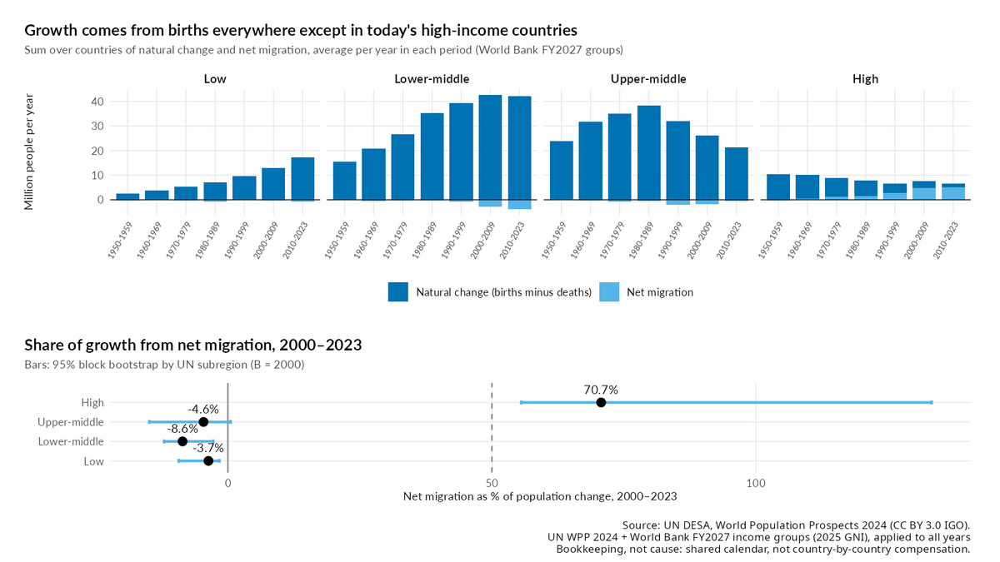

In [27]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_01_descomposicion_ingreso"))

#### Lectura de resultados · §2 Identidad de balance y descomposición por ingreso y región (sección 2)

*Texto de `docs/resultados_q1.md` §2 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Comprobamos `PopChange = NatChange + NetMigrations` y repartimos el crecimiento 2000–2023 de cada grupo de ingreso FY2027 (sumas de personas de sus países) entre saldo natural y migración. IC: bloques de subregión (pantalla), BCa iid y jackknife por país.

| Grupo FY2027 (n) | Migración / crecimiento 2000–23 | IC bloques | BCa iid | Jackknife (país que más mueve) | Agregado ONU (mayo-2024) |
|---|---|---|---|---|---|
| Bajo (25) | −3,7 % | [−9,3; −1,6] | [−7,7; −1,1] | −4,7 (sin ETH) a −2,9 (sin SDN) | — |
| Medio-bajo (47) | −8,6 % | [−12,1; −2,8] | [−21,2; −3,7] | −12,8 (sin IND) a −6,5 (sin BGD) | — |
| Medio-alto (59) | −4,6 % | [−14,9; 0,5] | [−11,3; 1,1] | −5,6 (sin MYS) a −3,4 (sin UKR) | — |
| **Alto (85)** | **70,7 %** | **[55,5; 133,3]** | **[56,0; 111,9]** | **64,5 (sin RUS) a 81,6 (sin USA)** | **64,0 %** |

Sensibilidades de ingreso alto: 2010–2023 77,5 % [57,5; 162,5]; ≥ 1 M 71,1 %; sin EE. UU. 81,6 %; sin Golfo 75,0 %; sin Rusia 64,5 %; agregados ONU 2010–23 72,8 %. Rango en pantalla (`share_mig_high_sens_range`, 2 listas × 2 periodos): **64–78 %**. China aporta el 29,6 % del saldo natural de medio-alto (46,3 % de su población); India el 40,2 % del de medio-bajo (50,1 %). Por región SDG: Europa y Norteamérica 84,4 %, Australia/NZ 55,3 %, Norte de África y Asia occidental 5,8 %, resto negativo (LAC −13,9 %). Identidad: residuo máximo 4,9 mil personas (Ucrania 1989); suma de grupos + "Not classified" = World (dif. 0).

Figura: `q1_01_descomposicion_ingreso.png`. Claves: `share_mig_*_2000_2023`, `share_mig_high_2010_2023`, `share_mig_high_un_agg`, `share_mig_high_sens_range`, `china_share_natchange_upmid`, `india_share_natchange_lowmid`, `share_mig_region_2000_2023`, `share_countries_mig_dominant_by_region`.

**Lectura de resultados.**
- H1 se confirma con su regla (estimación 70,7 > 50 y límite inferior BCa 56,0 > 50); también con bloques (55,5). El IC por bloques es muy asimétrico hacia arriba (133 %) porque al remuestrear subregiones hay réplicas con poco crecimiento total en el denominador.
- Reportamos los dos números que pide el encargo: **70,7 % (sumas de países FY2027)** y **64,0 % (agregados ONU, clasificación de mayo de 2024)**. No son contradictorios: son dos listas de países distintas (alto 1 393 M vs 1 261 M); el agregado ONU nunca se usa para validar.
- Fuera del ingreso alto, el crecimiento viene casi todo del saldo natural; la migración neta resta entre 4 y 9 de cada 100.
- Es contabilidad de un total de grupo: **no** dice que la migración compense, país a país, la caída de nacimientos (ver §6.5, H16).

### Q1 · §3 Tipología de palancas 2023, ventanas de sensibilidad, ejemplos e inercia

*Exploratory (H19) · conteos descriptivos* · `R/02_q1_palancas.R` líneas 517–820

In [28]:
# =============================================================================
# 3. Tipología de palancas 2023, ventanas de sensibilidad, ejemplos e inercia
# =============================================================================
# QUÉ: clasifica cada país por qué término del balance domina hoy (A-E),
#      repite la clasificación con otras ventanas y elige ejemplos por regla.
# POR QUÉ: responde "país por país" a P7 y fija una sola definición (2023)
#      para portada, mapa, guion y numbers.json, con su rango de sensibilidad.
seccion("3. Tipología de palancas")

ventanas <- c(list(`2023` = 2023), VENTANAS_SENS_ANIOS)
tv <- lapply(ventanas, function(a) tipo_palanca_ventana(a, "completa"))
t23 <- tv[["2023"]] |>
  left_join(c23 |> select(ISO3_code, TFR, NRR, pop_2023_miles = TPopulation1July), by = "ISO3_code")
stopifnot(!anyNA(t23$tipo))
tab_vent <- bind_rows(lapply(names(tv), function(v) {
  x <- tv[[v]]
  bind_rows(
    tibble(tipo = c("A", "B", "C", "D", "E", "AB", "NA")) |>
      mutate(n_237 = vapply(tipo, function(tp) if (tp == "AB") sum(x$tipo %in% c("A", "B")) else if (tp == "NA") sum(is.na(x$tipo)) else sum(x$tipo %in% tp), integer(1)),
             n_1m = vapply(tipo, function(tp) if (tp == "AB") sum(x$tipo[x$pob_1m] %in% c("A", "B")) else if (tp == "NA") sum(is.na(x$tipo[x$pob_1m])) else sum(x$tipo[x$pob_1m] %in% tp), integer(1)))
  ) |> mutate(ventana = v)
})) |> select(ventana, tipo, n_237, n_1m)
print(tab_vent |> pivot_wider(names_from = ventana, values_from = c(n_237, n_1m)))
VENT_SENS <- c("2021", "2022", "2023", "2021-2023")   # "depending on the year" (plan §3)
for (tp in c("A", "B", "C", "D", "E", "AB")) {
  for (m in c("237", "1m")) {
    col <- paste0("n_", m)
    v23 <- tab_vent[[col]][tab_vent$ventana == "2023" & tab_vent$tipo == tp]
    vs <- tab_vent[[col]][tab_vent$ventana %in% VENT_SENS & tab_vent$tipo == tp]
    v1719 <- tab_vent[[col]][tab_vent$ventana == "2017-2019" & tab_vent$tipo == tp]
    clave <- paste0("n_type_", tp, if (m == "1m") "_1m" else "")
    vals_txt <- paste(sprintf("%s: %d", tab_vent$ventana[tab_vent$tipo == tp], tab_vent[[col]][tab_vent$tipo == tp]), collapse = " · ")
    anotar(clave, value = as.integer(v23), unit = "countries and areas", fmt = "0",
           def = sprintf("Countries with lever type %s in 2023 (%s)", tp, ETIQUETAS_PALANCA_EN[[tp]]),
           filter = if (m == "1m") "161 countries >= 1 M, 2023 (estimate)" else "237 countries and areas, 2023 (estimate)",
           source_cell = "Q1-3.1", used_in = if (m == "237") c("slide1.build3") else c("notebook.T2"),
           method = "none_census", sens_low = min(vs), sens_high = max(vs),
           sens_note = paste0("Windows (sums of people): ", vals_txt, " · on-screen range uses 2021, 2022, 2023 and 2021-23; pre-COVID 2017-19 = ", v1719),
           status = "descriptive", n = if (m == "1m") N_PAISES_1M else N_PAISES,
           universe = if (m == "1m") UNIVERSO_1M else UNIVERSO_237)
  }
}
# El conteo C es también el de "crecen solo por migración" del gancho
for (m in c("237", "1m")) {
  col <- paste0("n_", m)
  v23 <- tab_vent[[col]][tab_vent$ventana == "2023" & tab_vent$tipo == "C"]
  vs <- tab_vent[[col]][tab_vent$ventana %in% VENT_SENS & tab_vent$tipo == "C"]
  vals_txt <- paste(sprintf("%s: %d", tab_vent$ventana[tab_vent$tipo == "C"], tab_vent[[col]][tab_vent$tipo == "C"]), collapse = " · ")
  anotar(if (m == "1m") "n_grow_only_migration_2023_1m" else "n_grow_only_migration_2023",
         value = as.integer(v23), unit = "countries and areas", fmt = "0",
         def = "Deaths exceed births (NatChange < 0) yet population grows (PopChange > 0), 2023 — growing only through net arrivals",
         filter = if (m == "1m") "161 countries >= 1 M, 2023 (estimate)" else "237 countries and areas, 2023 (estimate)",
         source_cell = "Q1-3.1",
         used_in = if (m == "237") c("cover.build3", "slide1.build3", "slide1.message", "narration.cover") else c("slide1.build3"),
         method = "none_census", sens_low = min(vs), sens_high = max(vs),
         sens_note = paste0(vals_txt, " (on screen: 'depending on the year' = 2021, 2022, 2023, 2021-23 avg)"),
         status = "pre-specified", hypothesis_id = "H12a", say = if (m == "237") as.character(v23) else NA,
         n = if (m == "1m") N_PAISES_1M else N_PAISES, universe = if (m == "1m") UNIVERSO_1M else UNIVERSO_237)
}
vs_c <- tab_vent$n_237[tab_vent$ventana %in% VENT_SENS & tab_vent$tipo == "C"]
anotar("n_grow_only_migration_sens_range", value = formatear_rango(min(vs_c), max(vs_c), "0"), unit = "countries and areas", fmt = "text",
       def = "Range of n_grow_only_migration_2023 when the lever type is computed with 2021, 2022, 2023 or the 2021-2023 sums ('depending on the year')",
       filter = "237 countries and areas, estimates 2021-2023", source_cell = "Q1-3.1", used_in = c("slide1.build3"),
       method = "sensitivity", status = "descriptive", sens_low = min(vs_c), sens_high = max(vs_c),
       sens_note = sprintf("pre-COVID 2017-2019: %d (not in the on-screen range)", tab_vent$n_237[tab_vent$ventana == "2017-2019" & tab_vent$tipo == "C"]),
       n = N_PAISES, universe = UNIVERSO_237)


3. Tipología de palancas


# A tibble: 7 × 11
  tipo  n_237_2023 `n_237_2017-2019` n_237_2021 n_237_2022 `n_237_2021-2023` n_1m_2023 `n_1m_2017-2019` n_1m_2021 n_1m_2022 `n_1m_2021-2023`
  <chr>      <int>             <int>      <int>      <int>             <int>     <int>            <int>     <int>     <int>            <int>
1 A             71                88         72         73                73        48               61        53        49               51
2 B             94                87         90         91                92        72               68        69        70               71
3 C             18                14         15         25                24        11                7         5        18               14
4 D             35                22         43         32                31        24               16        29        21               22
5 E             19                26         17         16                17         6                9         5         3            

In [29]:
# 3.2 Ejemplos por regla: los 3 países más poblados (>= 1 M) de cada tipo
ejemplos <- lapply(c(A = "A", B = "B", C = "C", D = "D", E = "E"), function(tp) {
  t23 |> filter(pob_1m, tipo == tp) |> arrange(desc(pop_2023_miles)) |> slice_head(n = 3)
})
for (tp in names(ejemplos)) {
  e <- ejemplos[[tp]]
  informar("Ejemplos tipo %s: %s", tp, paste(e$Location, collapse = ", "))
  anotar(paste0("examples_type_", tp), value = I(e$Location), unit = NA, fmt = "text",
         def = sprintf("Rule: the three most populous countries (>= 1 M) of lever type %s in 2023 (WPP names)", tp),
         filter = "161 countries >= 1 M, 2023 (estimate)", source_cell = "Q1-3.2",
         used_in = if (tp %in% c("C", "D", "E")) c("slide1.build4", "narration.slide1") else c("notebook.T2"),
         method = "descriptive", status = "descriptive", sens_note = paste("ISO3:", paste(e$ISO3_code, collapse = ", ")),
         n = sum(t23$pob_1m & t23$tipo == tp), universe = UNIVERSO_1M)
  anotar(paste0("examples_type_", tp, "_iso3"), value = I(e$ISO3_code), unit = NA, fmt = "text",
         def = sprintf("ISO3 codes of examples_type_%s (for flags)", tp),
         filter = "161 countries >= 1 M, 2023 (estimate)", source_cell = "Q1-3.2", used_in = c("slide1.build4"),
         method = "descriptive", status = "descriptive", n = sum(t23$pob_1m & t23$tipo == tp), universe = UNIVERSO_1M)
}
anotar("cover_flags", value = I(ejemplos$C$ISO2_code), unit = NA, fmt = "text",
       def = "ISO2 codes of examples_type_C (three most populous countries >= 1 M growing only through net arrivals, 2023)",
       filter = "161 countries >= 1 M, 2023 (estimate)", source_cell = "Q1-3.2", used_in = c("cover.build3"),
       method = "descriptive", status = "descriptive", n = sum(t23$pob_1m & t23$tipo == "C"), universe = UNIVERSO_1M)

Ejemplos tipo A: United States of America, Egypt, Iran (Islamic Republic of)
Ejemplos tipo B: India, Indonesia, Pakistan
Ejemplos tipo C: Germany, Spain, Belgium
Ejemplos tipo D: China, Russian Federation, Japan
Ejemplos tipo E: Nepal, Azerbaijan, Uruguay


In [30]:
# 3.3 Inercia: bajo reemplazo y aun así crecen por saldo natural (tipo B)
t23 <- t23 |> mutate(bajo_reemplazo_2023 = TFR < TFR_REEMPLAZO,
                     inercia_bajo_reemplazo = tipo == "B" & bajo_reemplazo_2023,
                     inercia_estricta = inercia_bajo_reemplazo & NetMigrations < 0)
inr <- t23 |> filter(inercia_bajo_reemplazo) |> arrange(desc(pop_2023_miles))
inr_nrr <- t23 |> filter(tipo == "B", NRR < 1)
n_inr <- nrow(inr); pop_inr <- sum(inr$pop_2023_miles) / 1e6
n_inr_e <- sum(inr$inercia_estricta); pop_inr_e <- sum(inr$pop_2023_miles[inr$inercia_estricta]) / 1e6
informar("Inercia: %d países, %.3f mil M (estricta: %d, %.3f mil M); con NRR < 1: %d, %.3f mil M; migración neta = 0: %s",
         n_inr, pop_inr, n_inr_e, pop_inr_e, nrow(inr_nrr), sum(inr_nrr$pop_2023_miles) / 1e6,
         paste(inr$ISO3_code[!inr$inercia_estricta], collapse = ", "))
ej_mom <- inr |> filter(pob_1m) |> slice_head(n = 3)
anotar("n_momentum_countries", value = n_inr, unit = "countries and areas", fmt = "0",
       def = "Below replacement (TFR < 2.1) and growing from births with no net immigration (type B: NatChange > 0, NetMigrations <= 0, PopChange > 0), 2023",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-3.3",
       used_in = c("slide1.build3", "narration.slide1", "slide4.table"), method = "none_census",
       sens_low = min(n_inr_e, nrow(inr_nrr)), sens_high = max(n_inr, nrow(inr_nrr)),
       sens_note = sprintf("strict net emigration (NetMigrations < 0): %d · NRR < 1 instead of TFR < 2.1: %d · net migration exactly 0: %s",
                           n_inr_e, nrow(inr_nrr), paste(inr$ISO3_code[!inr$inercia_estricta], collapse = ", ")),
       status = "exploratory", hypothesis_id = "H19", say = as.character(n_inr), n = N_PAISES, universe = UNIVERSO_237)
anotar("n_momentum_emig", value = n_inr_e, unit = "countries and areas", fmt = "0",
       def = "Strict variant of n_momentum_countries: type B, TFR < 2.1 and NetMigrations < 0 (net emigration), 2023",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-3.3", used_in = c("notebook.T2"),
       method = "none_census", status = "exploratory", hypothesis_id = "H19", n = N_PAISES, universe = UNIVERSO_237)
anotar("pop_momentum_bn", value = round(pop_inr, 4), unit = "billion people", fmt = "0.0",
       def = "Population (1 July 2023) of the n_momentum_countries",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-3.3",
       used_in = c("slide1.build3", "narration.slide1", "slide4.table"), method = "none_census",
       sens_low = round(min(pop_inr_e, sum(inr_nrr$pop_2023_miles) / 1e6), 4),
       sens_high = round(max(pop_inr, sum(inr_nrr$pop_2023_miles) / 1e6), 4),
       sens_note = sprintf("strict net emigration: %.2f bn · NRR < 1: %.2f bn", pop_inr_e, sum(inr_nrr$pop_2023_miles) / 1e6),
       status = "exploratory", hypothesis_id = "H19", say = "2.2", n = n_inr, universe = UNIVERSO_237)
anotar("examples_momentum", value = I(ej_mom$Location), unit = NA, fmt = "text",
       def = "Rule: the three most populous countries (>= 1 M) of n_momentum_countries", filter = "237 countries and areas, 2023",
       source_cell = "Q1-3.3", used_in = c("slide1.build3"), method = "descriptive", status = "descriptive",
       sens_note = paste("ISO3:", paste(ej_mom$ISO3_code, collapse = ", ")), n = n_inr, universe = UNIVERSO_237)

Inercia: 22 países, 2.201 mil M (estricta: 18, 2.200 mil M); con NRR < 1: 24, 2.536 mil M; migración neta = 0: BRN, LCA, ATG, KNA


In [31]:
# 3.3b "Reloj" de la inercia: años entre bajar de 2,1 hijos y el pico de población
# QUÉ: para cada país con inercia, el año en que su TFR quedó por debajo de 2,1
#      (último cruce, estimación) y el año del máximo de su población desde 2023
#      (UN medium projection); también los años que faltan desde 2023.
# POR QUÉ: la tabla de la Slide 4 dice cuántos años más crecerán; el método lo
#      pidió demografía [DEM] y China da el único caso ya observado (1991 -> 2021).
#      El pico es un escenario de la ONU, no una observación: se rotula así.
reloj <- datos_paises |> filter(ISO3_code %in% c(inr$ISO3_code, "CHN")) |> arrange(ISO3_code, Time) |>
  group_by(ISO3_code, Location, pob_1m) |>
  summarise(cruce_21 = { x <- TFR[Time <= ANIO_BASE]; t <- Time[Time <= ANIO_BASE]
                         if (all(x < TFR_REEMPLAZO)) NA_real_ else if (tail(x, 1) >= TFR_REEMPLAZO) Inf else t[max(which(x >= TFR_REEMPLAZO)) + 1] },
            pico_obs = Time[Time <= ANIO_BASE][which.max(TPopulation1July[Time <= ANIO_BASE])],
            pico_futuro = Time[Time >= ANIO_BASE][which.max(TPopulation1July[Time >= ANIO_BASE])],
            pop_2023_miles = TPopulation1July[Time == ANIO_BASE], pop_pico_miles = max(TPopulation1July[Time >= ANIO_BASE]),
            edad_mediana_2023 = MedianAgePop[Time == ANIO_BASE],
            edad_mediana_pico = MedianAgePop[Time >= ANIO_BASE][which.max(TPopulation1July[Time >= ANIO_BASE])], .groups = "drop") |>
  mutate(es_inercia = ISO3_code %in% inr$ISO3_code,
         pico = ifelse(es_inercia, pico_futuro, pico_obs),
         pico_es_proyeccion = pico >= ANIO_INICIO_PROYECCION,
         anios_reloj = pico - cruce_21, anios_desde_2023 = ifelse(es_inercia, pico - ANIO_BASE, NA_real_),
         pico_censurado_2100 = pico == ANIO_MAX_VALIDO)
stopifnot(all(is.finite(reloj$cruce_21)))
r_mom <- reloj |> filter(es_inercia)
r_mom1m <- r_mom |> filter(pob_1m)
chn_reloj <- reloj |> filter(ISO3_code == "CHN")
q_txt <- function(x) sprintf("P25-P50-P75 %.0f-%.0f-%.0f", quantile(x, 0.25), median(x), quantile(x, 0.75))
informar("Reloj de la inercia (>= 1 M, n = %d): %s años desde bajar de 2,1 al pico proyectado; desde 2023: %s | 22 países: %s | China (observado): %d -> %d = %d años",
         nrow(r_mom1m), q_txt(r_mom1m$anios_reloj), q_txt(r_mom1m$anios_desde_2023), q_txt(r_mom$anios_reloj),
         chn_reloj$cruce_21, chn_reloj$pico, chn_reloj$anios_reloj)
F_MOM <- sprintf("%d momentum countries >= 1 M (type B with TFR < 2.1 in 2023); TFR crossing = estimate; population peak = UN medium projection (2023-2100)", nrow(r_mom1m))
# Nota: la clave `momentum_years_range` de la tabla de la Slide 4 ("X more years
# of growth") la registra Q3 (R/04_q3_caminos.R, años desde 2023 hasta el pico,
# mediana ponderada por población). Q1 NO la registra para no chocar al combinar
# numbers_q*.json; aquí se guarda el "reloj" (desde el cruce de 2,1) con otro nombre.
anotar("momentum_clock_years_range", value = formatear_rango(quantile(r_mom1m$anios_reloj, 0.25), quantile(r_mom1m$anios_reloj, 0.75), "0"),
       unit = "years", fmt = "text",
       def = "Momentum clock: interquartile range of the years between the year fertility fell below 2.1 for the last time (estimate) and the year of maximum population (UN medium projection), momentum countries >= 1 M",
       filter = F_MOM, source_cell = "Q1-3.3b", used_in = c("notebook.T2"), method = "descriptive", status = "exploratory",
       hypothesis_id = "H19", sens_low = round(min(r_mom1m$anios_reloj), 1), sens_high = round(max(r_mom1m$anios_reloj), 1),
       sens_note = sprintf("median %.0f; all 22 momentum countries IQR %s; years still to go from 2023 to the projected peak (>= 1 M): IQR %s, median %.0f; China (observed): %d -> %d = %d years; peak is a UN scenario, not an observation",
                           median(r_mom1m$anios_reloj), formatear_rango(quantile(r_mom$anios_reloj, 0.25), quantile(r_mom$anios_reloj, 0.75), "0"),
                           formatear_rango(quantile(r_mom1m$anios_desde_2023, 0.25), quantile(r_mom1m$anios_desde_2023, 0.75), "0"),
                           median(r_mom1m$anios_desde_2023), chn_reloj$cruce_21, chn_reloj$pico, chn_reloj$anios_reloj),
       n = nrow(r_mom1m), universe = UNIVERSO_1M)
anotar("momentum_years_to_peak_range", value = formatear_rango(quantile(r_mom1m$anios_desde_2023, 0.25), quantile(r_mom1m$anios_desde_2023, 0.75), "0"),
       unit = "years", fmt = "text",
       def = "Years still to go from 2023 to the year of maximum population (UN medium projection), interquartile range across momentum countries >= 1 M (unweighted; the on-screen key momentum_years_range is registered by Q3, population-weighted)",
       filter = F_MOM, source_cell = "Q1-3.3b", used_in = c("notebook.T2"), method = "descriptive", status = "exploratory",
       hypothesis_id = "H19", sens_low = min(r_mom1m$anios_desde_2023), sens_high = max(r_mom1m$anios_desde_2023),
       sens_note = paste("peak year by country:", paste(sprintf("%s %d", r_mom1m$ISO3_code, r_mom1m$pico), collapse = "; ")),
       n = nrow(r_mom1m), universe = UNIVERSO_1M)
anotar("momentum_clock_chn_years", value = chn_reloj$anios_reloj, unit = "years", fmt = "0",
       def = "China: years between the last time its fertility fell below 2.1 and its population peak (both observed, estimates)",
       filter = "China, estimates 1950-2023", source_cell = "Q1-3.3b", used_in = c("notebook.T2"), method = "descriptive",
       status = "descriptive", sens_note = sprintf("TFR below 2.1 from %d; population peak %d (%.0f million)", chn_reloj$cruce_21, chn_reloj$pico, chn_reloj$pop_pico_miles / 1e3),
       say = "thirty", n = 1, universe = "China")

Reloj de la inercia (>= 1 M, n = 13): P25-P50-P75 32-36-40 años desde bajar de 2,1 al pico proyectado; desde 2023: P25-P50-P75 24-28-34 | 22 países: P25-P50-P75 30-36-41 | China (observado): 1991 -> 2021 = 30 años


In [32]:
# 3.3c Figura de revisión del gancho (130 -> 84 = 66 + 18) y del reloj de la inercia
gancho_df <- t23 |> filter(bajo_reemplazo_2023) |>
  mutate(grupo = case_when(tipo == "B" ~ "Growing from births, no net arrivals (momentum)",
                           tipo == "A" ~ "Growing from births, plus net arrivals",
                           tipo == "C" ~ "Growing only through net arrivals",
                           tipo == "D" ~ "Shrinking: deaths > births",
                           tipo == "E" ~ "Shrinking: more leave than arrive")) |>
  count(grupo) |>
  mutate(grupo = factor(grupo, levels = rev(c("Growing from births, no net arrivals (momentum)", "Growing from births, plus net arrivals",
                                              "Growing only through net arrivals", "Shrinking: deaths > births", "Shrinking: more leave than arrive"))))
p4a <- ggplot(gancho_df, aes(n, grupo, fill = grupo)) + geom_col(width = 0.7) +
  geom_text(aes(label = n), hjust = -0.3, size = 4) +
  scale_fill_manual(values = setNames(c(COLOR_EMIGRACION, COLOR_DEFUNCIONES, COLOR_MIGRACION, COLOR_NACIMIENTOS, "#004B7A"), levels(gancho_df$grupo)), guide = "none") +
  expand_limits(x = max(gancho_df$n) * 1.15) +
  labs(x = "Countries and areas (2023)", y = NULL,
       title = sprintf("A · %d below replacement: %d still grow (%d from births + %d only through net arrivals)",
                       g_main["n"], g_main["crecen"], g_main["nat"], g_main["solo_mig"])) + tema_q1(11)
fig_reloj <- r_mom1m |> mutate(Location = factor(Location, levels = Location[order(anios_reloj)]))
p4b <- ggplot(fig_reloj) +
  annotate("rect", xmin = ANIO_INICIO_PROYECCION - 0.5, xmax = ANIO_MAX_VALIDO, ymin = -Inf, ymax = Inf, fill = COLOR_PROYECCION_SOMBRA) +
  geom_segment(aes(x = cruce_21, xend = ANIO_BASE, y = Location, yend = Location), colour = "black", linewidth = 1.1) +
  geom_segment(aes(x = ANIO_BASE, xend = pico, y = Location, yend = Location), colour = COL_GRIS, linewidth = 1.1, linetype = "22") +
  geom_point(aes(cruce_21, Location), size = 2.4, colour = COLOR_NACIMIENTOS) +
  geom_point(aes(pico, Location), size = 2.4, shape = 21, fill = "white", colour = "black") +
  geom_text(aes(pico, Location, label = anios_reloj), hjust = -0.6, size = 3.2) +
  geom_vline(xintercept = ANIO_BASE + 0.5, linetype = "dotted") +
  labs(x = NULL, y = NULL,
       title = sprintf("B · Momentum clock: %s years from TFR < 2.1 to the projected population peak (IQR, %d countries >= 1 M)",
                       formatear_rango(quantile(r_mom1m$anios_reloj, 0.25), quantile(r_mom1m$anios_reloj, 0.75), "0"), nrow(r_mom1m)),
       subtitle = sprintf("Blue dot: last year TFR fell below 2.1 (estimate). Open dot: peak year (UN medium projection, shaded). China (observed): %d -> %d, %d years.",
                          chn_reloj$cruce_21, chn_reloj$pico, chn_reloj$anios_reloj)) + tema_q1(11)
p4 <- (p4a / p4b) + plot_layout(heights = c(1, 2)) +
  plot_annotation(caption = pie_q1(badge("PIE-1"), "Projected peaks are UN medium projection scenarios, not forecasts."))
guardar_q1(p4, "q1_04_gancho_inercia")

In [33]:
# 3.4 Bajo reemplazo por tipo, concordancia entre ventanas y tipo E con TFR alta
br_tipo <- table(factor(t23$tipo[t23$bajo_reemplazo_2023], levels = c("A", "B", "C", "D", "E")))
conc <- t23 |> select(ISO3_code, tipo) |> inner_join(tv[["2021-2023"]] |> select(ISO3_code, tipo2123 = tipo), by = "ISO3_code")
pct_conc <- 100 * mean(conc$tipo == conc$tipo2123, na.rm = TRUE)
pct_conc_ab <- 100 * mean(ifelse(conc$tipo %in% c("A", "B"), "AB", conc$tipo) == ifelse(conc$tipo2123 %in% c("A", "B"), "AB", conc$tipo2123), na.rm = TRUE)
e_alto <- t23 |> filter(tipo == "E", TFR >= TFR_REEMPLAZO)
informar("Bajo reemplazo por tipo: %s | concordancia 2023 vs 2021-23: %.1f %% (A/B fundidos %.1f %%) | tipo E con TFR >= 2,1: %d (%s; máx. %.0f mil hab.)",
         paste(names(br_tipo), br_tipo, sep = "=", collapse = " "), pct_conc, pct_conc_ab, nrow(e_alto),
         paste(e_alto$ISO3_code, collapse = ", "), max(e_alto$pop_2023_miles))
anotar("n_below_repl_by_type", value = setNames(as.integer(br_tipo), names(br_tipo)), unit = "countries and areas", fmt = "0",
       def = "Countries with TFR < 2.1 in 2023 by lever type (A-E)", filter = "237 countries and areas, 2023 (estimate)",
       source_cell = "Q1-3.4", used_in = c("notebook.T2"), method = "none_census", status = "descriptive",
       n = unname(g_main["n"]), universe = UNIVERSO_237)
anotar("type_concordance_2023_2021_23", value = round(pct_conc, 4), unit = "%", fmt = "0.0",
       def = "Share of countries with the same lever type (A-E) in 2023 and in the 2021-2023 window",
       filter = "237 countries and areas", source_cell = "Q1-3.4", used_in = c("notebook.T2"), method = "descriptive",
       status = "descriptive", sens_note = sprintf("with A and B merged: %.1f %%", pct_conc_ab), n = nrow(conc), universe = UNIVERSO_237)
anotar("n_type_E_tfr_ge21", value = nrow(e_alto), unit = "countries and areas", fmt = "0",
       def = "Countries shrinking although births exceed deaths (type E) with TFR >= 2.1, 2023",
       filter = "237 countries and areas, 2023 (estimate)", source_cell = "Q1-3.4", used_in = c("notebook.T2"),
       method = "none_census", status = "descriptive",
       sens_note = sprintf("%s; largest population %.0f thousand", paste(e_alto$ISO3_code, collapse = ", "), max(e_alto$pop_2023_miles)),
       n = N_PAISES, universe = UNIVERSO_237)

Bajo reemplazo por tipo: A=44 B=22 C=18 D=33 E=13 | concordancia 2023 vs 2021-23: 88.6 % (A/B fundidos 93.2 %) | tipo E con TFR >= 2,1: 6 (ASM, MAF, MHL, MNP, TON, TUV; máx. 105 mil hab.)


In [34]:
# 3.5 Lista completa por país (figures/miembros_tipo_palanca.csv)
tipos_por_ventana <- Reduce(function(a, b) left_join(a, b, by = "ISO3_code"),
                            lapply(names(tv), function(v) tv[[v]] |> select(ISO3_code, tipo) |> rename(!!paste0("tipo_", gsub("-", "_", v)) := tipo)))
miembros <- t23 |> select(ISO3_code, ISO2_code, Location, region_sdg, subregion, ingreso, pob_1m, pop_2023_miles, TFR, NRR,
                          NatChange_2023 = NatChange, NetMigrations_2023 = NetMigrations, PopChange_2023 = PopChange,
                          tipo_palanca_2023 = tipo, tipo_ab_2023 = tipo_ab, bajo_reemplazo_2023,
                          inercia_bajo_reemplazo, inercia_estricta) |>
  left_join(tipos_por_ventana |> select(-tipo_2023), by = "ISO3_code") |>
  mutate(ejemplo_por_regla = case_when(ISO3_code %in% ejemplos$C$ISO3_code ~ "C", ISO3_code %in% ejemplos$D$ISO3_code ~ "D",
                                       ISO3_code %in% ejemplos$E$ISO3_code ~ "E", ISO3_code %in% ej_mom$ISO3_code ~ "momentum",
                                       TRUE ~ NA_character_)) |>
  arrange(tipo_palanca_2023, desc(pop_2023_miles))
readr::write_csv(miembros, file.path(RUTA_FIGURAS, "miembros_tipo_palanca.csv"))

In [35]:
# 3.6 Figuras de revisión: mapa 2023 y ventanas
iso_natural_earth <- function(ne) {
  iso <- ifelse(ne$iso_a3_eh != "-99", ne$iso_a3_eh, ne$adm0_a3)
  recod <- c(SOL = "SOM", KOS = "XKX", CYN = "CYP", ALA = "FIN")   # códigos WPP (memo espacial)
  ifelse(iso %in% names(recod), recod[iso], iso)
}
ne <- rnaturalearth::ne_countries(scale = "medium", returnclass = "sf")
ne$iso3 <- iso_natural_earth(ne)
lab_tipo <- c(AB = sprintf("%s · %d", ETIQUETAS_PALANCA_EN[["AB"]], sum(t23$tipo_ab == "AB")),
              C = sprintf("%s · %d", ETIQUETAS_PALANCA_EN[["C"]], sum(t23$tipo == "C")),
              D = sprintf("%s · %d", ETIQUETAS_PALANCA_EN[["D"]], sum(t23$tipo == "D")),
              E = sprintf("%s · %d", ETIQUETAS_PALANCA_EN[["E"]], sum(t23$tipo == "E")))
mapa <- ne |> filter(iso3 != "ATA") |>
  left_join(t23 |> select(ISO3_code, tipo_ab, pob_1m, inercia_bajo_reemplazo), by = c("iso3" = "ISO3_code")) |>
  mutate(clase = factor(ifelse(is.na(tipo_ab), "nodata", tipo_ab), levels = c("AB", "C", "D", "E", "nodata")),
         alfa = ifelse(pob_1m %in% TRUE, 1, 0.45))
mapa <- suppressWarnings(sf::st_transform(mapa, "+proj=robin"))
p2 <- ggplot(mapa) +
  geom_sf(aes(fill = clase, alpha = alfa), colour = "white", linewidth = 0.08) +
  geom_sf(data = mapa |> filter(inercia_bajo_reemplazo %in% TRUE), fill = NA, colour = "black", linewidth = 0.35) +
  scale_fill_manual(values = c(AB = COLOR_NACIMIENTOS, C = COLOR_MIGRACION, D = COLOR_DEFUNCIONES, E = COLOR_EMIGRACION, nodata = COLOR_SIN_DATOS),
                    labels = c(lab_tipo, nodata = "No data / not matched"), name = NULL) +
  scale_alpha_identity() + coord_sf(crs = "+proj=robin", datum = NA) +
  labs(title = "Which lever moves each country's population in 2023",
       subtitle = sprintf("Black outline: below replacement yet growing from births (%d countries, %.2f bn people). Faded: < 1 M people.", n_inr, pop_inr),
       caption = pie_q1(badge("PIE-1"), DEF_PALANCA_EN,
                        "Boundaries and names shown do not imply official endorsement or acceptance by the United Nations. Map: Natural Earth (review map: Crimea not yet reassigned).")) +
  tema_q1(12) + theme(legend.position = "bottom", legend.text = element_text(size = rel(0.75))) +
  guides(fill = guide_legend(nrow = 2))
guardar_q1(p2, "q1_02_mapa_palancas_2023")

fig_vent <- tab_vent |> filter(tipo %in% c("A", "B", "C", "D", "E")) |>
  mutate(ventana = factor(ventana, levels = c("2017-2019", "2021", "2022", "2023", "2021-2023")))
fig_vent <- fig_vent |> mutate(panel = factor(paste0(tipo, ": ", ETIQUETAS_PALANCA_EN[tipo]), levels = paste0(c("A", "B", "C", "D", "E"), ": ", ETIQUETAS_PALANCA_EN[c("A", "B", "C", "D", "E")])),
                                base = ventana == "2023")
p3 <- ggplot(fig_vent, aes(ventana, n_237, fill = tipo, alpha = base)) +
  geom_col(width = 0.7) + geom_text(aes(label = n_237), vjust = -0.4, size = 3.4, alpha = 1) +
  facet_wrap(~panel, nrow = 1, labeller = label_wrap_gen(22)) +
  scale_fill_manual(values = c(A = "#004B7A", B = COLOR_NACIMIENTOS, C = COLOR_MIGRACION, D = COLOR_DEFUNCIONES, E = COLOR_EMIGRACION), guide = "none") +
  scale_alpha_manual(values = c(`TRUE` = 1, `FALSE` = 0.45), guide = "none") +
  labs(x = "Window used to classify (sums of people)", y = "Countries and areas (of 237)",
       title = sprintf("Counts depend on the year: 'growing only through net arrivals' is %s countries (%d before COVID-19)", formatear_rango(min(vs_c), max(vs_c), "0"), tab_vent$n_237[tab_vent$ventana == "2017-2019" & tab_vent$tipo == "C"]),
       subtitle = "2023 (dark bars) is the base year everywhere; 2021–2023 contains COVID-19 excess deaths and 2022 displacement from Ukraine",
       caption = pie_q1(badge("PIE-1"))) +
  tema_q1(11) + theme(axis.text.x = element_text(angle = 60, hjust = 1))
guardar_q1(p3, "q1_03_ventanas_sensibilidad")

**`figures/review/q1/q1_04_gancho_inercia.png`** (figura de revisión, no final)

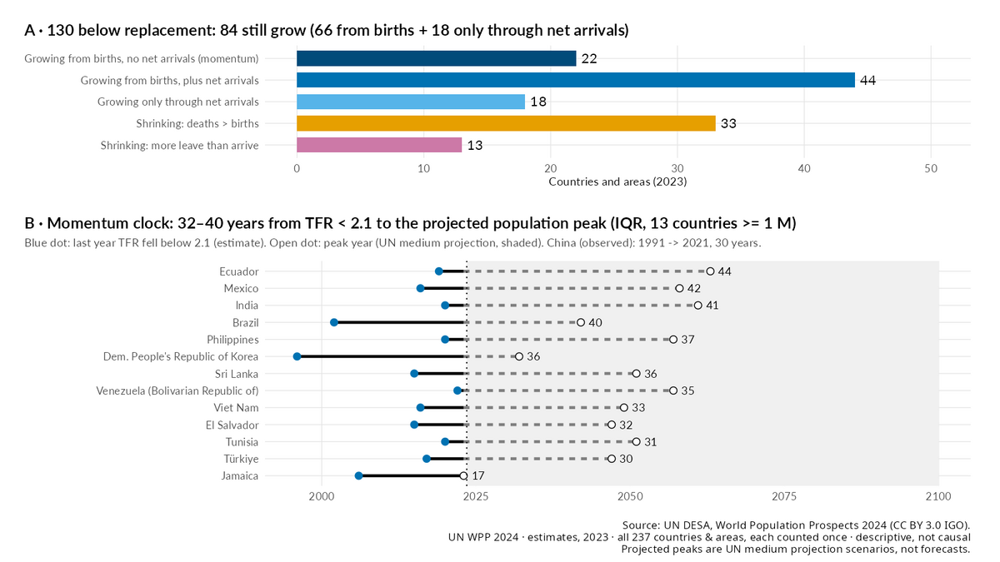

**`figures/review/q1/q1_02_mapa_palancas_2023.png`** (figura de revisión, no final)

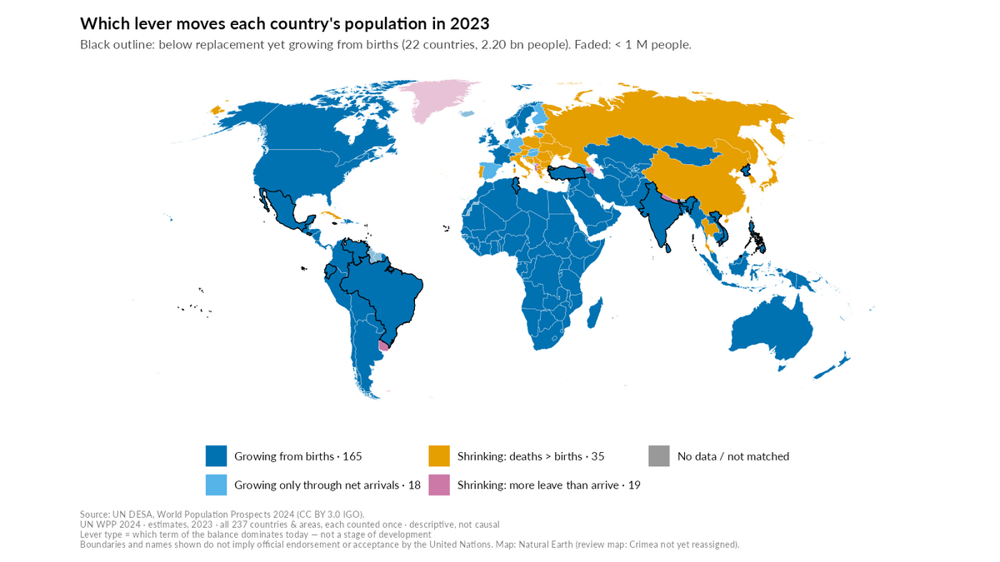

**`figures/review/q1/q1_03_ventanas_sensibilidad.png`** (figura de revisión, no final)

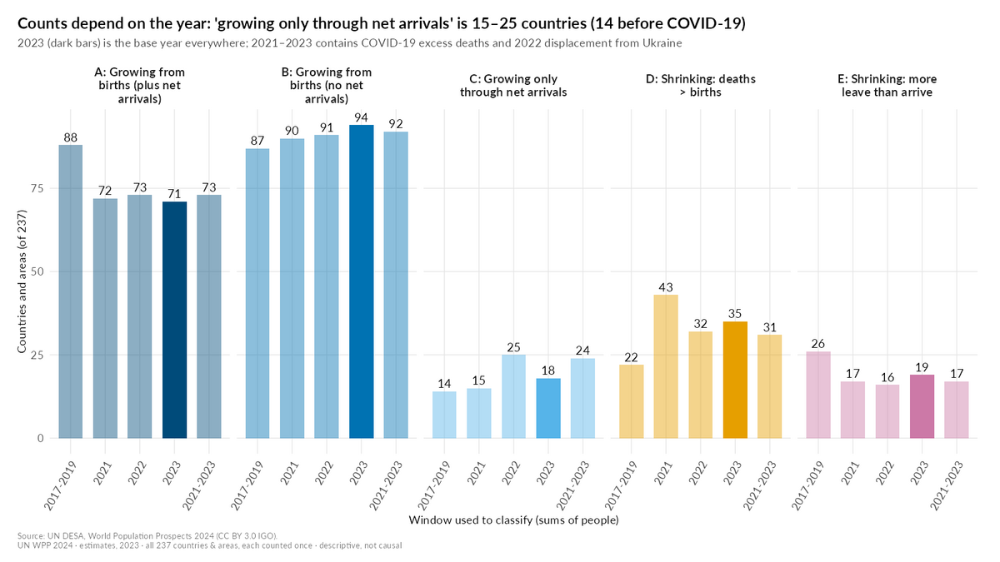

In [36]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_04_gancho_inercia", "q1_02_mapa_palancas_2023", "q1_03_ventanas_sensibilidad"))

#### Lectura de resultados · §3 Tipología de palancas, ventanas, ejemplos e inercia (sección 3)

*Texto de `docs/resultados_q1.md` §3 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Clasificamos cada país con la regla A–E (año base 2023, sumas de personas) y repetimos con 2017–19, 2021, 2022 y 2021–23. Elegimos ejemplos por regla (3 más poblados ≥ 1 M de cada tipo) y contamos la inercia (tipo B con TFR < 2,1).

| Tipo (2023) | 237 | ≥ 1 M | 2017–19 | 2021 | 2022 | 2021–23 | Ejemplos por regla (≥ 1 M) |
|---|---|---|---|---|---|---|---|
| A · crece por nacimientos + llegadas | 71 | 48 | 88 | 72 | 73 | 73 | United States of America, Egypt, Iran |
| B · crece por nacimientos, sin llegadas netas | 94 | 72 | 87 | 90 | 91 | 92 | India, Indonesia, Pakistan |
| **C · crece solo por llegadas netas** | **18** | **11** | 14 | 15 | 25 | 24 | **Germany, Spain, Belgium** (`cover_flags` = DE, ES, BE) |
| D · decrece: defunciones > nacimientos | 35 | 24 | 22 | 43 | 32 | 31 | China, Russian Federation, Japan |
| E · decrece: se van más de los que llegan | 19 | 6 | 26 | 17 | 16 | 17 | Nepal, Azerbaijan, Uruguay |

| Inercia y detalle | Valor | Clave |
|---|---|---|
| Bajo reemplazo y crecen por nacimientos sin inmigración neta (B & TFR < 2,1) | **22 países, 2,20 mil M** | `n_momentum_countries`, `pop_momentum_bn` |
| … con emigración neta estricta (NetMigrations < 0) | 18 (2,20 mil M); los otros 4 (BRN, LCA, ATG, KNA) tienen migración neta 0 | `n_momentum_emig` |
| … con NRR < 1 en vez de TFR < 2,1 | 24 (2,54 mil M) | `sens_note` |
| Ejemplos de inercia (3 más poblados ≥ 1 M) | India, Brazil, Mexico | `examples_momentum` |
| "Reloj" de la inercia (13 países ≥ 1 M): años desde bajar de 2,1 hasta el pico proyectado | RIC **32–40** (mediana 36); desde 2023: RIC 24–34 (mediana 28) | `momentum_clock_years_range`, `momentum_years_to_peak_range` |
| China (observado): bajó de 2,1 en 1991, pico de población en 2021 | 30 años | `momentum_clock_chn_years` |
| Bajo reemplazo por tipo | A 44 · B 22 · C 18 · D 33 · E 13 | `n_below_repl_by_type` |
| Concordancia de tipo 2023 vs 2021–23 | 88,6 % (93,2 % con A y B juntos) | `type_concordance_2023_2021_23` |
| Tipo E con TFR ≥ 2,1 | 6, todas islas pequeñas (ASM, MAF, MHL, MNP, TON, TUV; la mayor, 105 mil hab.) | `n_type_E_tfr_ge21` |

Figuras: `q1_02_mapa_palancas_2023.png`, `q1_03_ventanas_sensibilidad.png`, `q1_04_gancho_inercia.png`. Lista completa por país: `figures/miembros_tipo_palanca.csv`.

**Lectura de resultados.**
- Los conteos A–E de 2023 reproducen los del plan (71/94/18/35/19; ≥ 1 M 48/72/11/24/6). En pantalla, el tipo C va como `18 (15–25 depending on the year)`; antes del COVID-19 (2017–19) eran 14. La ventana 2021–23 no suaviza: lleva dentro el exceso de muertes por COVID-19 (D sube a 43 en 2021) y el desplazamiento desde Ucrania (C sube a 25 en 2022).
- La inercia reúne a 22 países con 2 200 millones de personas: crecen por nacimientos aunque cada mujer tenga menos de 2,1 hijos, porque todavía hay muchas personas en edad de tener hijos. La voz debe decir "growing from births" (no "despite emigration"): 4 de los 22 tienen migración neta exactamente 0.
- "Nadie se va de los países pobres" no se sostiene: los 6 casos de tipo E con fecundidad alta son microislas; entre los ≥ 1 M, 31 países tuvieron algún año de tipo E con TFR ≥ 3 en 1950–2023 (Irlanda 1952–60, TFR 3,5; Portugal 1963–70, TFR 3,1).
- **Ojo con la clave `momentum_years_range`**: la registra Q3 (años desde 2023 hasta el pico, ponderado por población: 34–38). Q1 la renombró a `momentum_clock_years_range` (32–40, desde el cruce de 2,1) para no chocar al combinar.

### Q1 · §4 ¿Se parecen los vecinos? Moran's I (dependencia espacial)

*Exploratory (H24)* · `R/02_q1_palancas.R` líneas 821–1033

In [37]:
# =============================================================================
# 4. ¿Se parecen los vecinos? Moran's I (dependencia espacial)
# =============================================================================
# QUÉ: mide cuánto se parecen los países vecinos (5 más cercanos) en
#      fecundidad, esperanza de vida, edad mediana, crecimiento y migración.
# POR QUÉ: responde la cláusula "region" de P7 con una cifra (los vecinos
#      comparten fecundidad, casi no migración) y justifica los IC por bloques.
seccion("4. Moran's I")

ne_pts <- sf::st_drop_geometry(ne) |>
  transmute(iso3, principal = adm0_a3 == iso3, lon = label_x, lat = label_y) |>
  arrange(iso3, desc(principal)) |> distinct(iso3, .keep_all = TRUE)
haversine <- function(lon, lat) {
  rad <- pi / 180; R <- 6371.0088
  la <- lat * rad; lo <- lon * rad
  a <- sin(outer(la, la, "-") / 2)^2 + outer(cos(la), cos(la)) * sin(outer(lo, lo, "-") / 2)^2
  2 * R * asin(pmin(sqrt(a), 1))
}
dist_iso <- function(iso) {
  p <- ne_pts[match(iso, ne_pts$iso3), ]
  if (anyNA(p$lon)) stop("Países sin punto representativo: ", paste(iso[is.na(p$lon)], collapse = ", "))
  haversine(p$lon, p$lat)
}
W_knn <- function(iso, k = K_VECINOS) {
  D <- dist_iso(iso); diag(D) <- Inf
  t(apply(D, 1, function(r) { w <- numeric(length(r)); w[order(r)[1:k]] <- 1 / k; w }))
}
W_idw <- function(iso, corte = 2000) {
  D <- dist_iso(iso); W <- ifelse(D > 0 & D <= corte, 1 / D, 0)
  sinv <- which(rowSums(W) == 0)
  if (length(sinv)) { Dd <- D; diag(Dd) <- Inf; for (i in sinv) W[i, which.min(Dd[i, ])] <- 1 }
  W / rowSums(W)
}
moran <- function(x, W) { z <- x - mean(x); (length(x) / sum(W)) * sum(z * (W %*% z)) / sum(z^2) }
moran_perm <- function(x, W, B = B_PERM_Q1) {
  I0 <- moran(x, W)
  set.seed(SEM)
  Ip <- replicate(B, moran(sample(x), W))
  c(I = I0, p = (1 + sum(Ip >= I0)) / (B + 1), nulo_lo = unname(quantile(Ip, 0.025)), nulo_hi = unname(quantile(Ip, 0.975)))
}
moran_jack <- function(x, iso, Wfun = W_knn) {
  n <- length(x)
  Ij <- vapply(seq_len(n), function(i) moran(x[-i], Wfun(iso[-i])), numeric(1))
  se <- sqrt((n - 1) / n * sum((Ij - mean(Ij))^2)); I0 <- moran(x, Wfun(iso))
  c(jk_lo = I0 - 1.96 * se, jk_hi = I0 + 1.96 * se)
}
VARS_MORAN <- c(TFR = "Fertility (TFR)", LEx = "Life expectancy", MedianAgePop = "Median age",
                PopGrowthRate = "Growth rate", CNMR = "Net migration rate")
mor <- list()
for (anio in c(1950, 1990, 2023)) {
  d <- corte_anio(anio, "1m") |> arrange(ISO3_code)
  W <- W_knn(d$ISO3_code)
  for (v in names(VARS_MORAN)) {
    pm <- moran_perm(d[[v]], W); jk <- moran_jack(d[[v]], d$ISO3_code)
    pr <- moran_perm(rank(d[[v]]), W)
    mor[[length(mor) + 1]] <- tibble(indicador = v, anio = anio, version = c("classic", "ranks"), W = "kNN5",
                                     muestra = "161 >= 1 M", n = nrow(d), I = c(pm["I"], pr["I"]), p_perm = c(pm["p"], pr["p"]),
                                     nulo_lo = c(pm["nulo_lo"], pr["nulo_lo"]), nulo_hi = c(pm["nulo_hi"], pr["nulo_hi"]),
                                     jk_lo = c(jk["jk_lo"], NA), jk_hi = c(jk["jk_hi"], NA))
  }
}
d23 <- corte_anio(2023, "1m") |> arrange(ISO3_code)
d23_ng <- d23 |> filter(!es_golfo(ISO3_code))
pm_ng <- moran_perm(d23_ng$CNMR, W_knn(d23_ng$ISO3_code)); jk_ng <- moran_jack(d23_ng$CNMR, d23_ng$ISO3_code)
mor[[length(mor) + 1]] <- tibble(indicador = "CNMR", anio = 2023, version = "classic", W = "kNN5", muestra = "155 >= 1 M, no Gulf",
                                 n = nrow(d23_ng), I = pm_ng["I"], p_perm = pm_ng["p"], nulo_lo = pm_ng["nulo_lo"],
                                 nulo_hi = pm_ng["nulo_hi"], jk_lo = jk_ng["jk_lo"], jk_hi = jk_ng["jk_hi"])
# Sensibilidad a W (4 matrices más) y a la muestra (todos los países con punto representativo)
Ws <- list(kNN4 = W_knn(d23$ISO3_code, 4), kNN6 = W_knn(d23$ISO3_code, 6), kNN8 = W_knn(d23$ISO3_code, 8),
           IDW2000 = W_idw(d23$ISO3_code, 2000))
for (wn in names(Ws)) for (v in names(VARS_MORAN)) {
  mor[[length(mor) + 1]] <- tibble(indicador = v, anio = 2023, version = "classic", W = wn, muestra = "161 >= 1 M",
                                   n = nrow(d23), I = moran(d23[[v]], Ws[[wn]]))
}
d23_all <- corte_anio(2023, "completa") |> filter(ISO3_code %in% ne_pts$iso3) |> arrange(ISO3_code)
W_all <- W_knn(d23_all$ISO3_code)
for (v in names(VARS_MORAN)) {
  mor[[length(mor) + 1]] <- tibble(indicador = v, anio = 2023, version = "classic", W = "kNN5",
                                   muestra = sprintf("%d of 237 (with a map point)", nrow(d23_all)), n = nrow(d23_all),
                                   I = moran(d23_all[[v]], W_all))
}
# Residuos tras región SDG + ingreso (160 países con grupo de ingreso)
d23_res <- d23 |> filter(ingreso != "Not classified")
W_res <- W_knn(d23_res$ISO3_code)
for (v in c("TFR", "CNMR")) {
  r <- resid(lm(d23_res[[v]] ~ d23_res$region_sdg + droplevels(d23_res$ingreso)))
  pm <- moran_perm(r, W_res)
  mor[[length(mor) + 1]] <- tibble(indicador = v, anio = 2023, version = "residual (region + income)", W = "kNN5",
                                   muestra = "160 >= 1 M with income group", n = nrow(d23_res), I = pm["I"], p_perm = pm["p"],
                                   nulo_lo = pm["nulo_lo"], nulo_hi = pm["nulo_hi"])
}
mor <- bind_rows(mor)
print(mor |> filter(anio == 2023, W == "kNN5", muestra == "161 >= 1 M") |> mutate(across(where(is.numeric), \(x) round(x, 3))))
print(mor |> filter(muestra != "161 >= 1 M" | W != "kNN5") |> mutate(across(where(is.numeric), \(x) round(x, 3))), n = 40)
m23 <- mor |> filter(anio == 2023, version == "classic", W == "kNN5", muestra == "161 >= 1 M")
sens_W <- mor |> filter(anio == 2023, version == "classic", muestra == "161 >= 1 M") |> group_by(indicador) |>
  summarise(lo = min(I), hi = max(I))
claves_moran <- c(TFR = "moran_tfr_2023", LEx = "moran_lex_2023", MedianAgePop = "moran_medage_2023",
                  CNMR = "moran_cnmr_2023", PopGrowthRate = "moran_growth_2023")
for (v in names(claves_moran)) {
  x <- m23 |> filter(indicador == v); s <- sens_W |> filter(indicador == v)
  anotar(claves_moran[[v]], value = round(x$I, 4), unit = "Moran's I", fmt = "0.00",
         def = sprintf("Global Moran's I of %s across countries, 2023; W = 5 nearest neighbours (haversine between Natural Earth label points), row-standardised", v),
         filter = "161 countries >= 1 M, 2023 (estimate)", source_cell = "Q1-4.1",
         used_in = if (v %in% c("TFR", "CNMR")) c("slide2.build4") else c("notebook.T7"),
         method = "permutation", B = B_PERM_Q1, seed = SEM, sens_low = round(s$lo, 4), sens_high = round(s$hi, 4),
         sens_note = sprintf("W = kNN4/5/6/8 and inverse distance <= 2000 km; jackknife 95%% [%.2f; %.2f]; null 95%% band [%.2f; %.2f]",
                             x$jk_lo, x$jk_hi, x$nulo_lo, x$nulo_hi),
         p_value = x$p_perm, status = "exploratory", hypothesis_id = "H24", n = x$n, universe = UNIVERSO_1M)
}
anotar("moran_cnmr_2023_nogulf", value = round(unname(pm_ng["I"]), 4), unit = "Moran's I", fmt = "0.00",
       def = "Global Moran's I of the net migration rate, 2023, excluding the six Gulf states (W recomputed, kNN5)",
       filter = "155 countries >= 1 M without ARE, QAT, KWT, BHR, OMN, SAU, 2023", source_cell = "Q1-4.1",
       used_in = c("slide2.build4"), method = "permutation", B = B_PERM_Q1, seed = SEM,
       sens_note = sprintf("jackknife 95%% [%.2f; %.2f]; null band [%.2f; %.2f]", jk_ng["jk_lo"], jk_ng["jk_hi"], pm_ng["nulo_lo"], pm_ng["nulo_hi"]),
       p_value = unname(pm_ng["p"]), status = "exploratory", hypothesis_id = "H24", n = nrow(d23_ng), universe = UNIVERSO_1M)
gr_rank <- mor |> filter(indicador == "PopGrowthRate", version == "ranks", W == "kNN5", muestra == "161 >= 1 M")
for (a in c(1950, 2023)) {
  x <- gr_rank |> filter(anio == a)
  anotar(paste0("moran_growth_rank_", a), value = round(x$I, 4), unit = "Moran's I (ranks)", fmt = "0.00",
         def = sprintf("Moran's I of the rank of the population growth rate across countries, %d (kNN5)", a),
         filter = sprintf("161 countries >= 1 M, %d (estimate)", a), source_cell = "Q1-4.1", used_in = c("notebook.T7"),
         method = "permutation", B = B_PERM_Q1, seed = SEM, p_value = x$p_perm, status = "exploratory",
         n = x$n, universe = UNIVERSO_1M)
}


4. Moran's I


# A tibble: 10 × 12
   indicador      anio version W     muestra        n     I p_perm nulo_lo nulo_hi  jk_lo  jk_hi
   <chr>         <dbl> <chr>   <chr> <chr>      <dbl> <dbl>  <dbl>   <dbl>   <dbl>  <dbl>  <dbl>
 1 TFR            2023 classic kNN5  161 >= 1 M   161 0.735  0.001  -0.091   0.088  0.64   0.83 
 2 TFR            2023 ranks   kNN5  161 >= 1 M   161 0.696  0.001  -0.09    0.085 NA     NA    
 3 LEx            2023 classic kNN5  161 >= 1 M   161 0.688  0.001  -0.094   0.089  0.588  0.788
 4 LEx            2023 ranks   kNN5  161 >= 1 M   161 0.676  0.001  -0.093   0.088 NA     NA    
 5 MedianAgePop   2023 classic kNN5  161 >= 1 M   161 0.77   0.001  -0.091   0.091  0.681  0.858
 6 MedianAgePop   2023 ranks   kNN5  161 >= 1 M   161 0.775  0.001  -0.09    0.089 NA     NA    
 7 PopGrowthRate  2023 classic kNN5  161 >= 1 M   161 0.593  0.001  -0.09    0.087  0.447  0.739
 8 PopGrowthRate  2023 ranks   kNN5  161 >= 1 M   161 0.693  0.001  -0.095   0.089 NA     NA    
 9 CNMR   

# A tibble: 28 × 12
   indicador      anio version                    W       muestra                           n      I p_perm nulo_lo nulo_hi  jk_lo  jk_hi
   <chr>         <dbl> <chr>                      <chr>   <chr>                         <dbl>  <dbl>  <dbl>   <dbl>   <dbl>  <dbl>  <dbl>
 1 CNMR           2023 classic                    kNN5    155 >= 1 M, no Gulf             155 -0.028  0.676  -0.089   0.089 -0.329  0.272
 2 TFR            2023 classic                    kNN4    161 >= 1 M                      161  0.736 NA      NA      NA     NA     NA    
 3 LEx            2023 classic                    kNN4    161 >= 1 M                      161  0.695 NA      NA      NA     NA     NA    
 4 MedianAgePop   2023 classic                    kNN4    161 >= 1 M                      161  0.774 NA      NA      NA     NA     NA    
 5 PopGrowthRate  2023 classic                    kNN4    161 >= 1 M                      161  0.583 NA      NA      NA     NA     NA    
 6 CNMR       

In [38]:
# 4.2 LISA de la migración neta: ¿dónde están los "vecindarios" migratorios?
# QUÉ: Moran local (Anselin 1995) de la CNMR media 2010-2023 y de 2023, con
#      permutación condicional (999) y corrección de Benjamini-Hochberg (FDR 5 %).
# POR QUÉ: la frase "alike among neighbours only in the Gulf" necesita saber qué
#      conglomerados sobreviven a 161 pruebas simultáneas, no solo el I global.
lisa <- function(x, W, B = B_PERM_Q1) {
  n <- length(x); z <- x - mean(x); m2 <- sum(z^2) / n
  k <- rowSums(W > 0)[1]; lag_z <- as.numeric(W %*% z)
  Ii <- z * lag_z / m2
  set.seed(SEM)
  p <- vapply(seq_len(n), function(i) {
    otros <- z[-i]
    Ip <- z[i] * vapply(seq_len(B), function(b) mean(sample(otros, k)), numeric(1)) / m2
    if (Ii[i] >= 0) (1 + sum(Ip >= Ii[i])) / (B + 1) else (1 + sum(Ip <= Ii[i])) / (B + 1)
  }, numeric(1))
  tibble(Ii = Ii, z = z, lag_z = lag_z, p = p, p_bh = p.adjust(p, "BH"),
         cuadrante = case_when(z > 0 & lag_z > 0 ~ "High-High", z < 0 & lag_z < 0 ~ "Low-Low",
                               z > 0 & lag_z < 0 ~ "High-Low", TRUE ~ "Low-High"))
}
v1023 <- resumen_ventana(2010:2023, "CNMR", muestra = "1m") |> arrange(ISO3_code)
stopifnot(identical(v1023$ISO3_code, d23$ISO3_code))
lisa_tab <- bind_rows(
  bind_cols(v1023 |> select(ISO3_code, Location, subregion), lisa(v1023$CNMR, W_knn(v1023$ISO3_code))) |> mutate(ventana = "2010-2023"),
  bind_cols(d23 |> select(ISO3_code, Location, subregion), lisa(d23$CNMR, W_knn(d23$ISO3_code))) |> mutate(ventana = "2023")) |>
  mutate(sig_05 = p < 0.05, sig_fdr = p_bh < 0.05)
lisa_res <- lisa_tab |> group_by(ventana, cuadrante) |> summarise(n_p05 = sum(sig_05), n_fdr = sum(sig_fdr),
                                                                  iso_fdr = paste(sort(ISO3_code[sig_fdr]), collapse = ", "), .groups = "drop")
print(lisa_res, width = 200)
hh_fdr <- lisa_tab |> filter(ventana == "2010-2023", sig_fdr, cuadrante == "High-High")
fdr_todos <- lisa_tab |> filter(ventana == "2010-2023", sig_fdr)
fdr_23 <- lisa_tab |> filter(ventana == "2023", sig_fdr)
informar("LISA CNMR 2010-23: %d países con p < 0,05; %d sobreviven a FDR (%s); alto-alto tras FDR: %s | 2023: %d tras FDR",
         sum(lisa_tab$sig_05[lisa_tab$ventana == "2010-2023"]), nrow(fdr_todos), paste(sprintf("%s %s", fdr_todos$ISO3_code, fdr_todos$cuadrante), collapse = ", "),
         paste(hh_fdr$ISO3_code, collapse = ", "), nrow(fdr_23))
anotar("lisa_cnmr_hh_fdr", value = nrow(hh_fdr), unit = "countries", fmt = "0", method = "permutation", B = B_PERM_Q1, seed = SEM,
       # QA-stats (docs/QA_stats.md): se declara la convención del p-valor (de un lado, "folded").
       def = sprintf(paste("Countries in a High-High local cluster of the mean net migration rate 2010-2023 (local Moran, kNN5 with equal weights,",
                           "conditional permutation with %d draws; one-sided 'folded' pseudo p-value in the direction of the observed local I,",
                           "(1 + number of permuted values at least as extreme) / (%d + 1), as in GeoDa) that survive Benjamini-Hochberg FDR",
                           "at 5%% over the %d local tests"), B_PERM_Q1, B_PERM_Q1, nrow(v1023)),
       filter = "161 countries >= 1 M, mean of annual estimates 2010-2023", source_cell = "Q1-4.2",
       used_in = c("slide2.build4", "notebook.T7"),
       sens_note = sprintf("ISO3: %s; with p < 0.05 (no correction): %d countries in any quadrant; all quadrants after FDR: %s; single year 2023: %d after FDR",
                           paste(hh_fdr$ISO3_code, collapse = ", "), sum(lisa_tab$sig_05[lisa_tab$ventana == "2010-2023"]),
                           paste(sprintf("%s (%s)", fdr_todos$ISO3_code, fdr_todos$cuadrante), collapse = ", "), nrow(fdr_23)),
       p_adj_method = "BH (161 local tests)", status = "exploratory", hypothesis_id = "H24", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("lisa_cnmr_hh_fdr_iso3", value = I(hh_fdr$ISO3_code), unit = NA, fmt = "text", method = "descriptive",
       def = "ISO3 codes of lisa_cnmr_hh_fdr", filter = "161 countries >= 1 M, 2010-2023", source_cell = "Q1-4.2",
       used_in = c("notebook.T7"), status = "exploratory", n = nrow(hh_fdr), universe = UNIVERSO_1M)
fig_lisa <- ne |> filter(iso3 != "ATA") |>
  left_join(lisa_tab |> filter(ventana == "2010-2023") |> select(ISO3_code, cuadrante, sig_05, sig_fdr), by = c("iso3" = "ISO3_code")) |>
  mutate(clase = case_when(is.na(cuadrante) ~ "< 1 M or no data", sig_fdr ~ paste(cuadrante, "(FDR 5%)"),
                           sig_05 ~ paste(cuadrante, "(p < 0.05 only)"), TRUE ~ "No local cluster"))
fig_lisa <- suppressWarnings(sf::st_transform(fig_lisa, "+proj=robin"))
col_lisa <- c("High-High (FDR 5%)" = "#004488", "High-High (p < 0.05 only)" = "#6699CC", "Low-Low (FDR 5%)" = "#994F00",
              "Low-Low (p < 0.05 only)" = "#E69F00", "High-Low (FDR 5%)" = "#882255", "High-Low (p < 0.05 only)" = "#CC79A7",
              "Low-High (FDR 5%)" = "#B8860B", "Low-High (p < 0.05 only)" = "#EECC66", "No local cluster" = "grey85", "< 1 M or no data" = "white")
p5b <- ggplot(fig_lisa) + geom_sf(aes(fill = clase), colour = "grey60", linewidth = 0.08) +
  scale_fill_manual(values = col_lisa[names(col_lisa) %in% unique(fig_lisa$clase)], name = NULL) +
  coord_sf(crs = "+proj=robin", datum = NA) +
  labs(title = if (nrow(hh_fdr) > 0) sprintf("Migration forms few local neighbourhoods: %d of %d countries survive the false-discovery correction (%d High-High)",
                                              nrow(fdr_todos), sum(lisa_tab$sig_05[lisa_tab$ventana == "2010-2023"]), nrow(hh_fdr))
               else sprintf("No local migration neighbourhood survives the false-discovery correction (%d with p < 0.05 before it)",
                            sum(lisa_tab$sig_05[lisa_tab$ventana == "2010-2023"])),
       subtitle = sprintf("Local Moran of mean net migration 2010–2023 (5 nearest neighbours, %d conditional permutations, BH 5%%).\nAfter FDR: %s.",
                          B_PERM_Q1, if (nrow(fdr_todos)) paste(vapply(split(fdr_todos$ISO3_code, fdr_todos$cuadrante), paste, "", collapse = ", ") |>
                                                                  (\(v) paste(names(v), v))(), collapse = " · ") else "none"),
       caption = pie_q1(PIE_MODELOS, "Boundaries and names shown do not imply official endorsement or acceptance by the United Nations. Map: Natural Earth.")) +
  tema_q1(12) + theme(legend.position = "bottom") + guides(fill = guide_legend(nrow = 2))
guardar_q1(p5b, "q1_05b_lisa_migracion")

fig_mor <- mor |> filter(version == "classic", W == "kNN5", muestra == "161 >= 1 M") |>
  mutate(indicador = factor(VARS_MORAN[indicador], levels = rev(VARS_MORAN)), anio = factor(anio))
p5 <- ggplot(fig_mor, aes(I, indicador, colour = anio)) +
  annotate("rect", xmin = min(fig_mor$nulo_lo), xmax = max(fig_mor$nulo_hi), ymin = -Inf, ymax = Inf, fill = "grey90") +
  geom_vline(xintercept = 0, colour = COL_GRIS) +
  geom_errorbar(aes(xmin = jk_lo, xmax = jk_hi), width = 0.25, orientation = "y", position = position_dodge(width = 0.6)) +
  geom_point(size = 3, position = position_dodge(width = 0.6)) +
  geom_text(data = fig_mor |> filter(anio == "2023"), aes(x = jk_hi, label = formatear_cifra(round(I, 4), "0.00")), hjust = -0.25, size = 3.4,
            position = position_nudge(y = 0.2), show.legend = FALSE) +
  scale_colour_manual(values = c(`1950` = "#BBBBBB", `1990` = "#6699CC", `2023` = "#004488"), name = NULL) +
  labs(x = "Moran's I (5 nearest neighbours)", y = NULL,
       title = "Neighbours share their fertility, survival and age — not their migration",
       subtitle = sprintf("Net migration 2023: I = %.2f; without the six Gulf states I = %.2f. Grey band: 95%% of random reshuffles. Bars: jackknife 95%%.",
                          m23$I[m23$indicador == "CNMR"], pm_ng["I"]),
       caption = pie_q1(PIE_MODELOS, "W = 5 nearest neighbours (Natural Earth label points). Neighbours look alike; this is not diffusion or contagion.")) + tema_q1(12)
guardar_q1(p5, "q1_05_moran_vecinos")

# A tibble: 8 × 5
  ventana   cuadrante n_p05 n_fdr iso_fdr                            
  <chr>     <chr>     <int> <int> <chr>                              
1 2010-2023 High-High     7     7 "ARE, BHR, IRN, KWT, OMN, QAT, SAU"
2 2010-2023 High-Low      4     0 ""                                 
3 2010-2023 Low-High      1     0 ""                                 
4 2010-2023 Low-Low      13     2 "ALB, SRB"                         
5 2023      High-High     6     0 ""                                 
6 2023      High-Low      2     0 ""                                 
7 2023      Low-High      4     0 ""                                 
8 2023      Low-Low       7     0 ""                                 


LISA CNMR 2010-23: 25 países con p < 0,05; 9 sobreviven a FDR (ALB Low-Low, ARE High-High, BHR High-High, IRN High-High, KWT High-High, OMN High-High, QAT High-High, SAU High-High, SRB Low-Low); alto-alto tras FDR: ARE, BHR, IRN, KWT, OMN, QAT, SAU | 2023: 0 tras FDR


**`figures/review/q1/q1_05b_lisa_migracion.png`** (figura de revisión, no final)

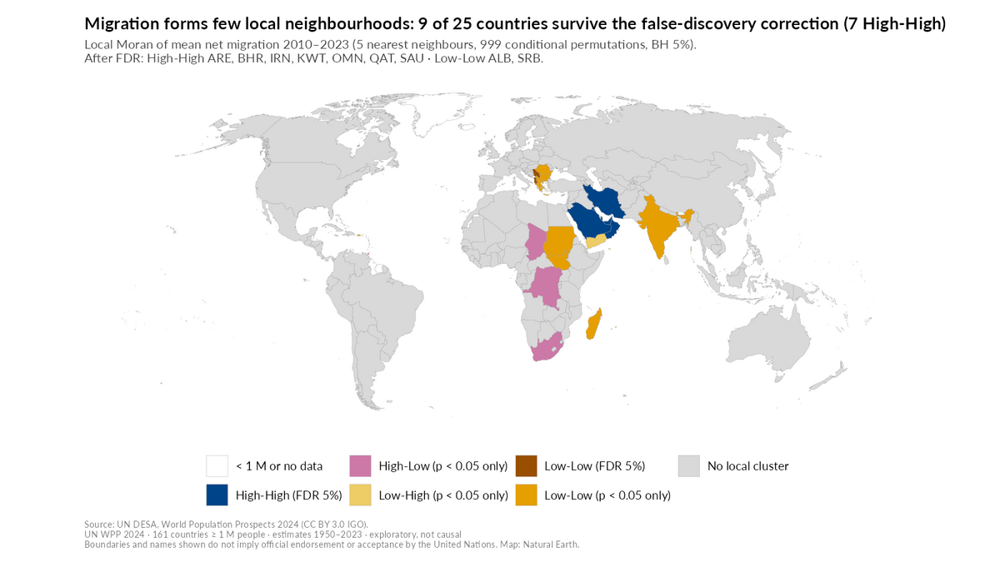

**`figures/review/q1/q1_05_moran_vecinos.png`** (figura de revisión, no final)

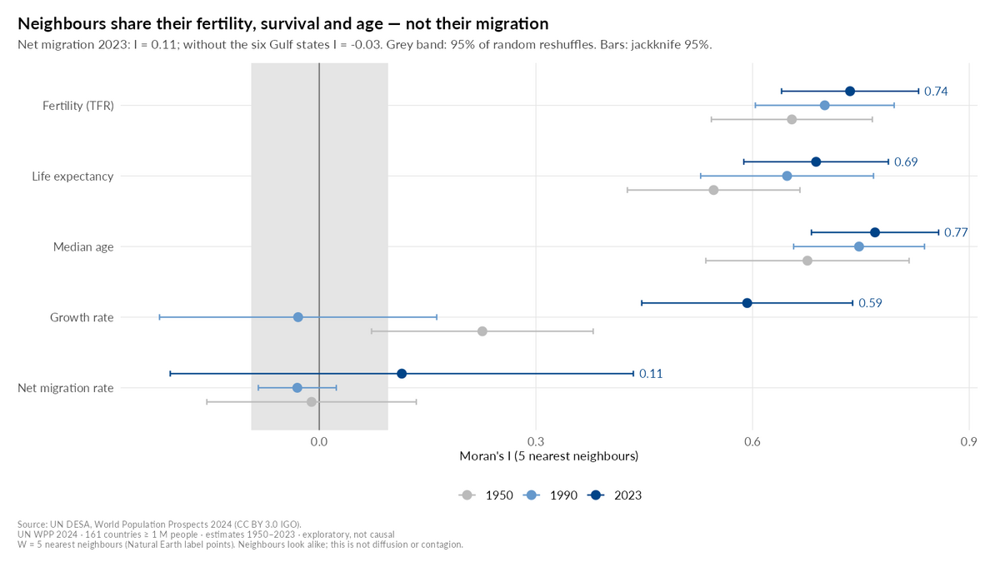

In [39]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_05b_lisa_migracion", "q1_05_moran_vecinos"))

#### Lectura de resultados · §4 ¿Se parecen los vecinos? Moran's I y LISA (sección 4)

*Texto de `docs/resultados_q1.md` §4 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Moran global con 5 vecinos más cercanos (haversine entre los puntos de Natural Earth), permutación (999) y jackknife; sensibilidad a 4 matrices W, a los 229 países con punto en el mapa y a los residuos tras región + ingreso. LISA de la CNMR media 2010–2023 con corrección de Benjamini–Hochberg.

| Indicador (2023, 161) | Moran I | Jackknife 95 % | Rango con 5 matrices W | Por rangos | 229 países |
|---|---|---|---|---|---|
| TFR | **0,74** (0,735) | [0,64; 0,83] | 0,70–0,74 | 0,70 | 0,72 |
| Esperanza de vida | 0,69 | [0,59; 0,79] | 0,65–0,70 | 0,68 | 0,68 |
| Edad mediana | 0,77 | [0,68; 0,86] | 0,75–0,77 | 0,78 | 0,75 |
| Crecimiento | 0,59 | [0,45; 0,74] | 0,58–0,62 | 0,69 | 0,47 |
| **Migración neta (CNMR)** | **0,11** | [−0,21; 0,44] | 0,10–0,13 | 0,26 | 0,14 |
| CNMR sin los 6 del Golfo (155) | **−0,03** | [−0,33; 0,27] | — | — | — |

Residuos tras región + ingreso: TFR 0,15 (p = 0,002), CNMR −0,10. Crecimiento por rangos: 0,34 (1950) → 0,69 (2023). **LISA 2010–23:** 25 países con p < 0,05 sin corregir; tras FDR quedan **9**: un conglomerado alto-alto de **7** (ARE, BHR, IRN, KWT, OMN, QAT, SAU) y 2 bajo-bajo (ALB, SRB). Con el año 2023 solo, ninguno sobrevive.

Figuras: `q1_05_moran_vecinos.png`, `q1_05b_lisa_migracion.png`. Claves: `moran_*_2023`, `moran_cnmr_2023_nogulf`, `moran_growth_rank_*`, `lisa_cnmr_hh_fdr`.

**Lectura de resultados.** Los vecinos se parecen mucho en fecundidad, supervivencia y edad (0,69–0,77) y casi nada en migración (0,11); sin el Golfo, nada (−0,03). H24 se confirma. El único "vecindario migratorio" robusto es el Golfo (con Irán, que queda dentro por sus vecinos). Es una descripción de parecido, no difusión ni contagio. Nota: el plan decía 0,12 para la CNMR; sale 0,114 → "0.11".

### Q1 · §5 Supervivencia: ¿qué empieza a caer primero, la mortalidad infantil o la fecundidad?

*Pre-specified (H3, H3a) · Exploratory (H3b)* · `R/02_q1_palancas.R` líneas 1034–1331

In [40]:
# =============================================================================
# 5. Supervivencia: ¿qué empieza a caer primero, la mortalidad infantil o la
#    fecundidad?
# =============================================================================
# QUÉ: fecha el inicio de la caída sostenida (regla de Princeton: primer año
#      con x <= 0,9 x máximo previo que no vuelve a superarse) de Q5 y TFR;
#      cuenta en cuántos países cae primero Q5 (Wilson), acota el rezago,
#      y estima con Kaplan-Meier el año de inicio de la caída de la
#      fecundidad por ingreso y región (log-rank, Cox).
# POR QUÉ: P7 pregunta por el orden; los umbrales absolutos (H3 de v1)
#      cambian la respuesta según el par elegido y descartan censurados.
seccion("5. Supervivencia: orden mortalidad -> fecundidad")

inicio_caida <- function(t, x, frac = UMBRAL_INICIO) {
  rm <- cummax(x); n <- length(x)
  # mínimo de la cola: x[i:n] <= lim  <=>  max(x[i:n]) <= lim
  cola_max <- rev(cummax(rev(x)))
  for (i in seq_len(n)) {
    lim <- frac * rm[i]
    if (x[i] <= lim && cola_max[i] <= lim) return(t[i])
  }
  NA_real_
}
base_ini <- function(frac = UMBRAL_INICIO) {
  est1m |> group_by(ISO3_code, Location, region_sdg, subregion, ingreso) |>
    summarise(tfr_1950 = TFR[Time == 1950], q5_1950 = Q5[Time == 1950],
              inicio_tfr = inicio_caida(Time, TFR, frac), inicio_q5 = inicio_caida(Time, Q5, frac),
              izq_q5 = which.max(Q5) == 1L, izq_tfr = which.max(TFR) == 1L, .groups = "drop")
}
bi <- base_ini()
el_todos <- bi |> filter(tfr_1950 >= TFR_ELEGIBLE_1950)
el <- el_todos |> filter(ingreso != "Not classified") |> mutate(ingreso = orden_ingreso(ingreso))
el <- el |> mutate(q5_observado = !is.na(inicio_q5),
                   mort_primero = q5_observado & (is.na(inicio_tfr) | inicio_q5 < inicio_tfr))
n_eleg <- nrow(el); n_onset <- sum(el$q5_observado); x_mort <- sum(el$mort_primero)
w_mort <- ic_wilson(x_mort, n_onset, escala = 100)
ambos <- el |> filter(q5_observado, !is.na(inicio_tfr))
w_ambos <- ic_wilson(sum(ambos$inicio_q5 < ambos$inicio_tfr), nrow(ambos), escala = 100)
x_twn <- el_todos |> filter(!is.na(inicio_q5), !is.na(inicio_tfr))
informar("Elegibles (>=1M, TFR1950>=5): %d; con ingreso clasificado: %d (fuera: %s); TFR aún sin iniciar: %s",
         nrow(el_todos), n_eleg, paste(setdiff(el_todos$ISO3_code, el$ISO3_code), collapse = ", "),
         paste(el$ISO3_code[is.na(el$inicio_tfr)], collapse = ", "))
informar("Mortalidad primero (definición preinscrita H3a): %d de %d = %.1f %% Wilson [%.1f; %.1f]",
         x_mort, n_onset, w_mort$valor, w_mort$ci_low, w_mort$ci_high)
informar("  solo con ambos inicios observados: %d de %d = %.1f %%; con Taiwán (sin ingreso), ambos observados: %d de %d",
         sum(ambos$inicio_q5 < ambos$inicio_tfr), nrow(ambos), w_ambos$valor,
         sum(x_twn$inicio_q5 < x_twn$inicio_tfr), nrow(x_twn))
informar("  fecundidad primero: %s", paste(sprintf("%s (Q5 %d, TFR %d)", ambos$ISO3_code[ambos$inicio_q5 >= ambos$inicio_tfr],
                                                  ambos$inicio_q5[ambos$inicio_q5 >= ambos$inicio_tfr], ambos$inicio_tfr[ambos$inicio_q5 >= ambos$inicio_tfr]), collapse = "; "))
n_q5_1950 <- sum(el$izq_q5)


5. Supervivencia: orden mortalidad -> fecundidad


Elegibles (>=1M, TFR1950>=5): 110; con ingreso clasificado: 109 (fuera: TWN); TFR aún sin iniciar: CAF, COD


Mortalidad primero (definición preinscrita H3a): 106 de 109 = 97.2 % Wilson [92.2; 99.1]


  solo con ambos inicios observados: 104 de 107 = 97.2 %; con Taiwán (sin ingreso), ambos observados: 105 de 108


  fecundidad primero: LBN (Q5 1977, TFR 1970); RWA (Q5 1995, TFR 1987); XKX (Q5 1964, TFR 1962)


In [41]:
# 5.2 Rejilla de reglas (-5/-10/-15 % x TFR1950 >= 5 / 5,5 / 6)
reglas <- expand.grid(frac = c(0.95, 0.90, 0.85), tfr_min = c(5, 5.5, 6))
reglas_res <- bind_rows(lapply(seq_len(nrow(reglas)), function(i) {
  b <- if (reglas$frac[i] == UMBRAL_INICIO) bi else base_ini(reglas$frac[i])
  e <- b |> filter(tfr_1950 >= reglas$tfr_min[i], ingreso != "Not classified", !is.na(inicio_q5))
  mp <- is.na(e$inicio_tfr) | e$inicio_q5 < e$inicio_tfr
  ob <- e |> filter(!is.na(inicio_tfr))
  tibble(frac = reglas$frac[i], tfr_min = reglas$tfr_min[i], n = nrow(e), x_mort_primero = sum(mp),
         pct_mort_primero = 100 * mean(mp), cota_rezago = median(pmax(ob$inicio_tfr - ob$inicio_q5, 0)))
}))
print(reglas_res)

# A tibble: 9 × 6
   frac tfr_min     n x_mort_primero pct_mort_primero cota_rezago
  <dbl>   <dbl> <int>          <int>            <dbl>       <dbl>
1  0.95     5     109            103             94.5          20
2  0.9      5     109            106             97.2          22
3  0.85     5     109            106             97.2          24
4  0.95     5.5    99             95             96.0          22
5  0.9      5.5    99             96             97.0          23
6  0.85     5.5    99             96             97.0          24
7  0.95     6      78             75             96.2          19
8  0.9      6      78             76             97.4          22
9  0.85     6      78             76             97.4          24


In [42]:
# 5.3 Rezago como intervalo (Turnbull) y cota inferior de la mediana
el <- el |> mutate(
  rezago_inicio_lo = case_when(is.na(inicio_tfr) ~ 2023 - inicio_q5, izq_q5 & !izq_tfr ~ inicio_tfr - inicio_q5,
                               izq_tfr ~ -Inf, TRUE ~ inicio_tfr - inicio_q5),
  rezago_inicio_hi = case_when(is.na(inicio_tfr) ~ Inf, izq_q5 ~ Inf, TRUE ~ inicio_tfr - inicio_q5),
  tipo_censura = case_when(is.finite(rezago_inicio_lo) & is.finite(rezago_inicio_hi) ~ "exact",
                           is.finite(rezago_inicio_lo) ~ "right-censored (>=)", is.finite(rezago_inicio_hi) ~ "left-censored (<=)",
                           TRUE ~ "no information"))
print(table(el$tipo_censura))
tb <- el |> filter(tipo_censura != "no information") |>
  mutate(L2 = ifelse(is.finite(rezago_inicio_lo), rezago_inicio_lo + 100, NA), R2 = ifelse(is.finite(rezago_inicio_hi), rezago_inicio_hi + 100, NA))
ft <- survfit(Surv(L2, R2, type = "interval2") ~ 1, data = tb)
masa_mas_alla <- min(ft$surv)
med_turnbull <- if (masa_mas_alla <= 0.5) ft$time[which(ft$surv <= 0.5)[1]] - 100 else NA_real_
informar("Turnbull: masa de probabilidad más allá del último tiempo finito = %.2f -> mediana %s",
         masa_mas_alla, ifelse(is.na(med_turnbull), "NO identificable", format(med_turnbull)))
lb <- el |> filter(!is.na(inicio_tfr)) |> mutate(rezago_cota = pmax(inicio_tfr - inicio_q5, 0))
f_med_rez <- function(d) median(d$rezago_cota)
bb_lb <- bootstrap_bloques(lb, f_med_rez, B = B_Q1, semilla = SEM)
bi_lb <- bootstrap_bloques(lb, f_med_rez, bloque = NULL, B = B_Q1, semilla = SEM)
informar("Cota inferior de la mediana del rezago: %.1f años [bloques %.1f; %.1f] [iid %.1f; %.1f]; IQR %.0f-%.0f",
         bb_lb$valor, bb_lb$ci_low, bb_lb$ci_high, bi_lb$ci_low, bi_lb$ci_high,
         quantile(lb$rezago_cota, 0.25), quantile(lb$rezago_cota, 0.75))


              exact  left-censored (<=)      no information right-censored (>=) 
                 13                   3                   9                  84 


Turnbull: masa de probabilidad más allá del último tiempo finito = 0.64 -> mediana NO identificable


Cota inferior de la mediana del rezago: 22.0 años [bloques 16.0; 28.0] [iid 20.0; 25.0]; IQR 13-31


In [43]:
# 5.4 ¿Cuánto había caído Q5 cuando empezó a caer la fecundidad?
caida <- est1m |> inner_join(el |> filter(!is.na(inicio_tfr)) |> select(ISO3_code, inicio_tfr), by = "ISO3_code") |>
  group_by(ISO3_code) |> summarise(caida_q5_al_inicio_tfr = 100 * (1 - Q5[Time == inicio_tfr[1]] / max(Q5[Time <= inicio_tfr[1]])))
el <- el |> left_join(caida, by = "ISO3_code")
dq <- el |> filter(!is.na(caida_q5_al_inicio_tfr))
f_med_caida <- function(d) median(d$caida_q5_al_inicio_tfr)
bb_caida <- bootstrap_bloques(dq, f_med_caida, B = B_Q1, semilla = SEM)
bi_caida <- bootstrap_bloques(dq, f_med_caida, bloque = NULL, B = B_Q1, semilla = SEM)
caida_ing <- dq |> group_by(ingreso) |> summarise(n = n(), mediana = median(caida_q5_al_inicio_tfr))
informar("Caída de Q5 (desde su máximo) al iniciar la caída de la TFR: mediana %.1f %% [bloques %.1f; %.1f]; IQR %.0f-%.0f; por ingreso: %s",
         bb_caida$valor, bb_caida$ci_low, bb_caida$ci_high, quantile(dq$caida_q5_al_inicio_tfr, 0.25),
         quantile(dq$caida_q5_al_inicio_tfr, 0.75), paste(sprintf("%s %.0f", caida_ing$ingreso, caida_ing$mediana), collapse = "; "))

Caída de Q5 (desde su máximo) al iniciar la caída de la TFR: mediana 49.9 % [bloques 43.8; 60.7]; IQR 41-64; por ingreso: Low income 63; Lower middle income 51; Upper middle income 46; High income 73


In [44]:
# 5.5 Kaplan-Meier del año de inicio de la caída de la TFR (censura en 2023)
cal <- el |> mutate(t = ifelse(is.na(inicio_tfr), 2023 - 1950, inicio_tfr - 1950), e = as.integer(!is.na(inicio_tfr)))
# Año mediano = primer año en que al menos la mitad del grupo ya inició (S(t) <= 0,5);
# survfit() da el punto medio cuando S(t) = 0,5 exactamente en un tramo (p. ej. 2000,5).
km_grupo <- function(d) {
  f <- survfit(Surv(t, e) ~ 1, data = d)
  tab <- summary(f)$table
  list(fit = f, n = nrow(d), eventos = sum(d$e),
       mediana = if (any(f$surv <= 0.5)) 1950 + f$time[which(f$surv <= 0.5)[1]] else NA_real_,
       mediana_survfit = 1950 + unname(tab["median"]),
       lo = 1950 + unname(tab["0.95LCL"]), hi = 1950 + unname(tab["0.95UCL"]))
}
km_ing <- lapply(setNames(NIVELES_INGRESO, NIVELES_INGRESO), function(g) km_grupo(cal |> filter(ingreso == g)))
for (g in NIVELES_INGRESO) informar("Inicio TFR %-20s n=%2d eventos=%2d  año mediano %s [%s; %s] (survfit %s)",
                                    g, km_ing[[g]]$n, km_ing[[g]]$eventos, km_ing[[g]]$mediana, km_ing[[g]]$lo, km_ing[[g]]$hi, km_ing[[g]]$mediana_survfit)
lr <- survdiff(Surv(t, e) ~ ingreso, data = cal)
lr_gl <- length(lr$n) - 1; lr_p <- pchisq(lr$chisq, lr_gl, lower.tail = FALSE)
cx <- coxph(Surv(t, e) ~ as.numeric(ingreso), data = cal)
cx_hr <- exp(coef(cx)); cx_ci <- exp(confint(cx)); cx_p <- summary(cx)$coefficients[, "Pr(>|z|)"]
informar("Log-rank 4 grupos: chi2 = %.1f (%d gl), p = %.1e | Cox (ingreso como escalón 1-4): HR = %.2f [%.2f; %.2f]",
         lr$chisq, lr_gl, lr_p, cx_hr, cx_ci[1], cx_ci[2])
regs_km <- sort(unique(as.character(cal$region_sdg)))
km_reg <- lapply(setNames(regs_km, regs_km), function(r) km_grupo(cal |> filter(region_sdg == r)))
km_reg_tab <- tibble(region = regs_km, n = vapply(km_reg, `[[`, numeric(1), "n"),
                     mediana = vapply(km_reg, `[[`, numeric(1), "mediana")) |> arrange(mediana)
print(km_reg_tab)
lr_reg <- survdiff(Surv(t, e) ~ region_sdg, data = cal |> filter(region_sdg %in% km_reg_tab$region[km_reg_tab$n >= 5]))

# Curvas KM para la figura y el parquet
curva_km <- function(fit, curva, grupo) {
  tibble(curva = curva, grupo = grupo, anio_o_t = 1950 + c(0, fit$time), surv = c(1, fit$surv),
         lower = c(1, fit$lower), upper = c(1, fit$upper), n_risk = c(fit$n, fit$n.risk), n_event = c(0, fit$n.event))
}
km_tab <- bind_rows(lapply(NIVELES_INGRESO, function(g) curva_km(km_ing[[g]]$fit, "tfr_onset_by_income", g)),
                    lapply(regs_km, function(r) curva_km(km_reg[[r]]$fit, "tfr_onset_by_region", r)))
# Q5 también (para la figura: casi todos ya caían en 1950)
calq <- el |> mutate(t = inicio_q5 - 1950, e = 1L)
km_q5 <- lapply(setNames(NIVELES_INGRESO, NIVELES_INGRESO), function(g) km_grupo(calq |> filter(ingreso == g)))
km_tab <- bind_rows(km_tab, bind_rows(lapply(NIVELES_INGRESO, function(g) curva_km(km_q5[[g]]$fit, "q5_onset_by_income", g))))

Inicio TFR Low income           n=24 eventos=22  año mediano 2000 [1995; 2007] (survfit 2000.5)
Inicio TFR Lower middle income  n=40 eventos=40  año mediano 1984 [1982; 1987] (survfit 1984.5)
Inicio TFR Upper middle income  n=33 eventos=33  año mediano 1970 [1968; 1975] (survfit 1970)
Inicio TFR High income          n=12 eventos=12  año mediano 1970 [1965; NA] (survfit 1970)


Log-rank 4 grupos: chi2 = 73.4 (3 gl), p = 8.2e-16 | Cox (ingreso como escalón 1-4): HR = 2.37 [1.93; 2.92]


# A tibble: 7 × 3
  region                                            n mediana
  <chr>                                         <dbl>   <dbl>
1 Europe and Northern America                       4    1956
2 Latin America and the Caribbean                  18    1970
3 Central and Southern Asia                        10    1974
4 Eastern and South-Eastern Asia                   13    1974
5 Northern Africa and Western Asia                 20    1980
6 Oceania (excluding Australia and New Zealand)     1    1982
7 Sub-Saharan Africa                               43    1995


In [45]:
# 5.6 Rejilla de umbrales absolutos (formulación v1, H3) y KM con censura (100 / 4)
cruce_anual <- function(t, x, u) { if (x[1] < u) return(-Inf); i <- which(x < u); if (!length(i)) return(Inf); t[i[1]] }
grid_u <- expand.grid(q5_umbral = c(200, 150, 100, 75, 50), tfr_umbral = c(5, 4, 3, 2.5))
cruces <- est1m |> group_by(ISO3_code, ingreso) |>
  summarise(q200 = cruce_anual(Time, Q5, 200), q150 = cruce_anual(Time, Q5, 150), q100 = cruce_anual(Time, Q5, 100),
            q75 = cruce_anual(Time, Q5, 75), q50 = cruce_anual(Time, Q5, 50),
            f5 = cruce_anual(Time, TFR, 5), f4 = cruce_anual(Time, TFR, 4), f3 = cruce_anual(Time, TFR, 3),
            f2.5 = cruce_anual(Time, TFR, 2.5), .groups = "drop")
grid_res <- bind_rows(lapply(seq_len(nrow(grid_u)), function(i) {
  q <- cruces[[paste0("q", grid_u$q5_umbral[i])]]; f <- cruces[[paste0("f", grid_u$tfr_umbral[i])]]
  ok <- is.finite(q) & is.finite(f); lag <- f[ok] - q[ok]
  tibble(q5_umbral = grid_u$q5_umbral[i], tfr_umbral = grid_u$tfr_umbral[i], n = sum(ok),
         mediana_rezago = median(lag), pct_mort_primero = 100 * mean(lag > 0))
}))
print(grid_res, n = 20)
k100 <- cruces |> filter(is.finite(q100), f4 != -Inf) |>
  mutate(t = ifelse(is.finite(f4), f4, 2023) - q100 + 100, e = as.integer(is.finite(f4)))
f100 <- survfit(Surv(t, e) ~ 1, data = k100); t100 <- summary(f100)$table
km100 <- c(med = unname(t100["median"]) - 100, lo = unname(t100["0.95LCL"]) - 100, hi = unname(t100["0.95UCL"]) - 100)
informar("Umbrales fijos: mediana del rezago %.1f a %.1f; mortalidad primero %.0f-%.0f %% | KM (100/4) con censura: %.1f [%.1f; %.1f] (n=%d, eventos %d)",
         min(grid_res$mediana_rezago), max(grid_res$mediana_rezago), min(grid_res$pct_mort_primero), max(grid_res$pct_mort_primero),
         km100["med"], km100["lo"], km100["hi"], nrow(k100), sum(k100$e))

# A tibble: 20 × 5
   q5_umbral tfr_umbral     n mediana_rezago pct_mort_primero
       <dbl>      <dbl> <int>          <dbl>            <dbl>
 1       200        5      85           23               96.5
 2       150        5      94           14               88.3
 3       100        5     100            4.5             61  
 4        75        5      97           -3               39.2
 5        50        5      82          -11.5             15.9
 6       200        4      67           27               98.5
 7       150        4      79           20               94.9
 8       100        4      89           11               79.8
 9        75        4      89            4               60.7
10        50        4      83           -5               34.9
11       200        3      49           33               98.0
12       150        3      60           27               96.7
13       100        3      77           17               93.5
14        75        3      81           11         

Umbrales fijos: mediana del rezago -11.5 a 39.5; mortalidad primero 16-100 % | KM (100/4) con censura: 14.0 [11.0; 18.0] (n=112, eventos 89)


In [46]:
# 5.7 Event time: Q5 y TFR (% de su máximo) alrededor del inicio de la caída de la TFR
ev <- est1m |> inner_join(el |> filter(!is.na(inicio_tfr)) |> select(ISO3_code, inicio_tfr, ing = ingreso), by = "ISO3_code") |>
  group_by(ISO3_code) |> mutate(tau = Time - inicio_tfr, Q5 = 100 * Q5 / max(Q5), TFR = 100 * TFR / max(TFR)) |> ungroup() |>
  filter(tau >= -25, tau <= 30)
ev_tab <- bind_rows(ev |> mutate(ing = "All"), ev |> mutate(ing = as.character(ing))) |>
  pivot_longer(c(Q5, TFR), names_to = "variable", values_to = "v") |>
  group_by(ingreso = ing, variable, tau) |>
  summarise(mediana = median(v), p25 = quantile(v, 0.25), p75 = quantile(v, 0.75), n = n(), .groups = "drop") |> filter(n >= 5)
informar("Event time (todos): a tau = 0, Q5 = %.0f %% de su máximo y TFR = %.0f %%",
         ev_tab$mediana[ev_tab$ingreso == "All" & ev_tab$variable == "Q5" & ev_tab$tau == 0],
         ev_tab$mediana[ev_tab$ingreso == "All" & ev_tab$variable == "TFR" & ev_tab$tau == 0])

Event time (todos): a tau = 0, Q5 = 47 % de su máximo y TFR = 89 %


In [47]:
# 5.8 Registro de cifras de supervivencia
F_ONSET <- sprintf("%d countries >= 1 M with TFR >= 5 in 1950 and a World Bank FY2027 income group; estimates 1950-2023", n_eleg)
anotar("n_onset", value = n_onset, unit = "countries", fmt = "0",
       def = "High-fertility countries (TFR >= 5 in 1950) whose child-mortality (Q5) decline onset is observed (Princeton rule: first year <= 90% of the previous maximum, never exceeded again)",
       filter = F_ONSET, source_cell = "Q1-5.1", used_in = c("slide2.build2", "slide2.message", "narration.slide2"),
       method = "none_census", status = "pre-specified", hypothesis_id = "H3a", n = n_eleg, universe = UNIVERSO_1M)
anotar("n_mort_first_onset", value = x_mort, unit = "countries", fmt = "0",
       def = "Countries where the lasting fall of Q5 began before that of TFR (countries whose TFR decline had not started by 2023 count as mortality first)",
       filter = F_ONSET, source_cell = "Q1-5.1", used_in = c("slide2.build2", "slide2.message", "narration.slide2"),
       method = "none_census", sens_low = min(reglas_res$x_mort_primero), sens_high = max(reglas_res$x_mort_primero),
       sens_note = sprintf("9 onset rules (-5/-10/-15%% x TFR1950 >= 5/5.5/6); only both onsets observed: %d of %d; with Taiwan (no income group): %d of %d",
                           sum(ambos$inicio_q5 < ambos$inicio_tfr), nrow(ambos), sum(x_twn$inicio_q5 < x_twn$inicio_tfr), nrow(x_twn)),
       status = "pre-specified", hypothesis_id = "H3a", n = n_onset, universe = UNIVERSO_1M)
anotar("share_mort_first", value = round(w_mort$valor, 4), unit = "%", fmt = "0", ic = w_mort,
       def = "n_mort_first_onset / n_onset x 100", filter = F_ONSET, source_cell = "Q1-5.1",
       used_in = c("slide2.build2", "narration.slide2"),
       sens_low = round(min(reglas_res$pct_mort_primero), 2), sens_high = round(max(reglas_res$pct_mort_primero), 2),
       sens_note = "9 onset rules (-5/-10/-15% x TFR1950 >= 5/5.5/6)", status = "pre-specified", hypothesis_id = "H3a",
       say = "97 in every 100", universe = UNIVERSO_1M)
anotar("share_mort_first_both_observed", value = round(w_ambos$valor, 4), unit = "%", fmt = "0", ic = w_ambos,
       def = "Same share restricted to countries with both onsets observed (TFR decline started by 2023)", filter = F_ONSET,
       source_cell = "Q1-5.1", used_in = c("notebook.T3"), status = "exploratory", hypothesis_id = "H3a", universe = UNIVERSO_1M)
anotar("lag_onset_lower_bound", value = bb_lb$valor, unit = "years", fmt = "0", ic = bb_lb, ic_iid = bi_lb,
       def = "Median of max(TFR onset - Q5 onset, 0) among countries with both onsets observed; a LOWER BOUND of the median lag because Q5 was already falling in 1950 in most countries",
       filter = F_ONSET, source_cell = "Q1-5.3", used_in = c("slide2.build2", "narration.slide2"),
       sens_low = min(reglas_res$cota_rezago), sens_high = max(reglas_res$cota_rezago),
       sens_note = sprintf("9 onset rules; Turnbull with all censoring: median not identified (%.0f%% of probability mass beyond the last finite time); IQR of the bound %.0f-%.0f",
                           100 * masa_mas_alla, quantile(lb$rezago_cota, 0.25), quantile(lb$rezago_cota, 0.75)),
       status = "pre-specified", hypothesis_id = "H3a", say = "at least 22 years", n = nrow(lb), universe = UNIVERSO_1M)
anotar("lag_onset_turnbull_mass_beyond", value = round(masa_mas_alla, 4), unit = "share", fmt = "0.00",
       def = "Turnbull (interval-censored) estimate of the lag Q5 onset -> TFR onset: probability mass beyond the last finite time (> 0.5 means the median is not identified)",
       filter = F_ONSET, source_cell = "Q1-5.3", used_in = c("notebook.T3"), method = "turnbull",
       sens_note = paste(names(table(el$tipo_censura)), table(el$tipo_censura), sep = ": ", collapse = " · "),
       status = "exploratory", hypothesis_id = "H3a", n = nrow(tb), universe = UNIVERSO_1M)
anotar("q5_drop_at_tfr_onset", value = round(bb_caida$valor, 4), unit = "%", fmt = "0", ic = bb_caida, ic_iid = bi_caida,
       def = "Median % fall of Q5 from its 1950-onwards maximum to the year TFR began its lasting fall",
       filter = F_ONSET, source_cell = "Q1-5.4", used_in = c("slide2.build2"),
       sens_note = sprintf("IQR %.0f-%.0f; by income group: %s", quantile(dq$caida_q5_al_inicio_tfr, 0.25), quantile(dq$caida_q5_al_inicio_tfr, 0.75),
                           paste(sprintf("%s %.0f", ETIQUETAS_INGRESO_CORTAS_EN[as.character(caida_ing$ingreso)], caida_ing$mediana), collapse = "; ")),
       status = "exploratory", say = "about half", n = nrow(dq), universe = UNIVERSO_1M)
anotar("n_q5_falling_1950", value = n_q5_1950, unit = "countries", fmt = "0",
       def = "Eligible countries whose Q5 maximum is in 1950 (decline already under way when the data begin: left-censored onset)",
       filter = F_ONSET, source_cell = "Q1-5.3", used_in = c("slide2.build2"), method = "none_census",
       sens_note = sprintf("TFR maximum in 1950: %d countries", sum(el$izq_tfr)), status = "descriptive", n = n_eleg, universe = UNIVERSO_1M)
claves_yr <- c("Low income" = "yr_fert_onset_low", "Lower middle income" = "yr_fert_onset_lowmid",
               "Upper middle income" = "yr_fert_onset_upmid", "High income" = "yr_fert_onset_high")
for (g in NIVELES_INGRESO) {
  k <- km_ing[[g]]
  anotar(claves_yr[[g]], value = k$mediana, unit = "year", fmt = "0", ci_low = k$lo, ci_high = k$hi, method = "km",
         def = sprintf("Kaplan-Meier median year of the onset of the lasting fertility decline (first year with S(t) <= 0.5), today's %s countries; right-censored in 2023", g),
         filter = sprintf("%s within: %s", g, F_ONSET), source_cell = "Q1-5.5",
         used_in = if (g == "High income") c("notebook.T3") else c("slide2.build2", "narration.slide2"),
         sens_note = sprintf("n = %d, events = %d; survfit midpoint convention: %s; 95%% CI Brookmeyer-Crowley", k$n, k$eventos, k$mediana_survfit),
         status = "exploratory", hypothesis_id = "H3b", n = k$n, universe = UNIVERSO_1M)
}
anotar("logrank_income_chisq", value = round(lr$chisq, 4), unit = "chi-squared", fmt = "0.0", method = "logrank",
       def = sprintf("Log-rank test of equal fertility-onset curves across the 4 income groups (%d df)", lr_gl),
       filter = F_ONSET, source_cell = "Q1-5.5", used_in = c("notebook.T3"), p_value = signif(lr_p, 4),
       sens_note = sprintf("Cox with income as a 1-4 step: HR = %.2f [%.2f; %.2f] per step", cx_hr, cx_ci[1], cx_ci[2]),
       status = "exploratory", hypothesis_id = "H3b", n = n_eleg, universe = UNIVERSO_1M)
anotar("cox_hr_income_step", value = round(unname(cx_hr), 4), unit = "hazard ratio", fmt = "0.00", method = "descriptive",
       sens_note = sprintf("Wald 95%% CI [%.2f; %.2f] (notebook only)", cx_ci[1], cx_ci[2]),
       def = "Cox model of the fertility-onset time with income group as a 1-4 step (Wald 95% CI)",
       filter = F_ONSET, source_cell = "Q1-5.5", used_in = c("notebook.T3"), p_value = signif(unname(cx_p), 4),
       status = "exploratory", hypothesis_id = "H3b", n = n_eleg, universe = UNIVERSO_1M)
anotar("yr_fert_onset_by_region", value = setNames(km_reg_tab$mediana, ETIQUETAS_REGION_CORTAS_EN[km_reg_tab$region]),
       unit = "year", fmt = "0", method = "km",
       def = "Kaplan-Meier median year of the fertility-decline onset by SDG region (first year with S(t) <= 0.5)",
       filter = F_ONSET, source_cell = "Q1-5.5", used_in = c("notebook.T3"),
       sens_note = paste(sprintf("%s n=%d", ETIQUETAS_REGION_CORTAS_EN[km_reg_tab$region], km_reg_tab$n), collapse = "; "),
       p_value = signif(pchisq(lr_reg$chisq, length(lr_reg$n) - 1, lower.tail = FALSE), 4),
       status = "exploratory", n = n_eleg, universe = UNIVERSO_1M)
anotar("lag_threshold_100_4_km", value = km100[["med"]], unit = "years", fmt = "0", ci_low = km100[["lo"]], ci_high = km100[["hi"]],
       method = "km", def = "v1 definition: years from Q5 < 100 to TFR < 4 (first year below each threshold), Kaplan-Meier with right censoring for countries still at TFR >= 4 in 2023",
       filter = "161 countries >= 1 M with Q5 >= 100 in 1950 that crossed it and TFR >= 4 in 1950; estimates", source_cell = "Q1-5.6",
       used_in = c("notebook.T3"), sens_note = sprintf("n = %d, events = %d", nrow(k100), sum(k100$e)),
       status = "pre-specified", hypothesis_id = "H3", n = nrow(k100), universe = UNIVERSO_1M)
anotar("share_mort_first_threshold_range", value = I(round(range(grid_res$pct_mort_primero), 1)), unit = "%", fmt = "0",
       def = "Range of the share 'Q5 crossed its threshold before TFR crossed its threshold' over 20 threshold pairs Q5 {200,150,100,75,50} x TFR {5,4,3,2.5} (both crossings observed after 1950)",
       filter = "161 countries >= 1 M, estimates 1950-2023", source_cell = "Q1-5.6", used_in = c("notebook.T3"),
       method = "sensitivity", sens_note = sprintf("median lag from %.1f to %.1f years across the grid", min(grid_res$mediana_rezago), max(grid_res$mediana_rezago)),
       status = "pre-specified", hypothesis_id = "H3", n = N_PAISES_1M, universe = UNIVERSO_1M)

In [48]:
# 5.9 Figuras de revisión: KM por ingreso y event time
fig_km <- km_tab |> filter(curva %in% c("tfr_onset_by_income", "q5_onset_by_income")) |>
  mutate(var = ifelse(curva == "tfr_onset_by_income", "Fertility (TFR)", "Child mortality (Q5)"),
         grupo = factor(ETIQUETAS_INGRESO_CORTAS_EN[grupo], levels = ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO]))
lab_km <- tibble(grupo = factor(ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO], levels = ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO]),
                 med = vapply(km_ing, `[[`, numeric(1), "mediana"))
p6 <- ggplot(fig_km, aes(anio_o_t, 100 * (1 - surv), colour = var)) +
  geom_step(linewidth = 1) +
  geom_hline(yintercept = 50, linetype = "dashed", colour = COL_GRIS) +
  geom_vline(data = lab_km, aes(xintercept = med), colour = COLOR_NACIMIENTOS, linetype = "dotted") +
  geom_text(data = lab_km, aes(x = med, y = 8, label = med), inherit.aes = FALSE, colour = COLOR_NACIMIENTOS, hjust = -0.1, size = 3.6) +
  facet_wrap(~grupo, nrow = 1) +
  scale_colour_manual(values = c("Fertility (TFR)" = COLOR_NACIMIENTOS, "Child mortality (Q5)" = COLOR_DEFUNCIONES), name = NULL) +
  labs(x = "Year", y = "% of countries whose lasting decline has begun",
       title = sprintf("Child mortality began to fall first in %d of %d high-fertility countries", x_mort, n_onset),
       subtitle = sprintf("Kaplan–Meier; onset = first year 10%% below the previous peak, never exceeded again.\nMedian year of fertility onset: %s. Log-rank chi² = %.1f (3 df).",
                          paste(sprintf("%s %s", lab_km$grupo, lab_km$med), collapse = " · "), lr$chisq),
       caption = pie_q1(PIE_MODELOS, badge("PIE-4"), sprintf("n = %d countries >= 1 M with TFR >= 5 in 1950; Q5 already falling in 1950 in %d. A sequence in time, not proof of cause.", n_eleg, n_q5_1950))) +
  tema_q1(11)
guardar_q1(p6, "q1_06_km_inicio_ingreso")
fig_ev <- ev_tab |> filter(ingreso == "All") |> mutate(variable = ifelse(variable == "Q5", "Under-five mortality", "Children per woman"))
p7 <- ggplot(fig_ev, aes(tau, mediana, colour = variable, fill = variable)) +
  geom_ribbon(aes(ymin = p25, ymax = p75), alpha = 0.15, colour = NA) + geom_line(linewidth = 1.2) +
  geom_vline(xintercept = 0, linetype = "dashed") +
  scale_colour_manual(values = c("Under-five mortality" = COLOR_DEFUNCIONES, "Children per woman" = COLOR_NACIMIENTOS), name = NULL) +
  scale_fill_manual(values = c("Under-five mortality" = COLOR_DEFUNCIONES, "Children per woman" = COLOR_NACIMIENTOS), name = NULL) +
  labs(x = "Years since fertility began its lasting fall (year 0)", y = "% of the country's own 1950–2023 peak",
       title = sprintf("When fertility starts to fall, child mortality has already dropped by about half (median %.0f%%)", bb_caida$valor),
       subtitle = "Median across countries (line) and middle 50% (band), each country aligned on its own fertility onset",
       caption = pie_q1(PIE_MODELOS, sprintf("%d countries >= 1 M with TFR >= 5 in 1950 whose fertility decline started by 2023. A sequence in time, not proof of cause.", nrow(dq)))) + tema_q1(12)
guardar_q1(p7, "q1_07_event_time_inicio")
p8 <- ggplot(grid_res, aes(factor(tfr_umbral), factor(q5_umbral), fill = pct_mort_primero)) +
  geom_tile(colour = "white") + geom_text(aes(label = sprintf("%.0f%%\n%+.1f yrs", pct_mort_primero, mediana_rezago)), size = 3.3) +
  scale_fill_gradient(low = "#F7FBFF", high = "#08519C", limits = c(0, 100), name = "% mortality first") +
  labs(x = "Fertility threshold (TFR crosses below)", y = "Under-five mortality threshold (per 1,000)",
       title = "With fixed thresholds the answer depends on the pair chosen (v1 hypothesis H3)",
       subtitle = "Share of countries where Q5 crossed first and median lag (TFR year − Q5 year), both crossings observed after 1950",
       caption = pie_q1(PIE_MODELOS, "Sensitivity only: the onset rule (section 5) is the pre-specified answer.")) + tema_q1(12)
guardar_q1(p8, "q1_08_rejilla_umbrales")

**`figures/review/q1/q1_06_km_inicio_ingreso.png`** (figura de revisión, no final)

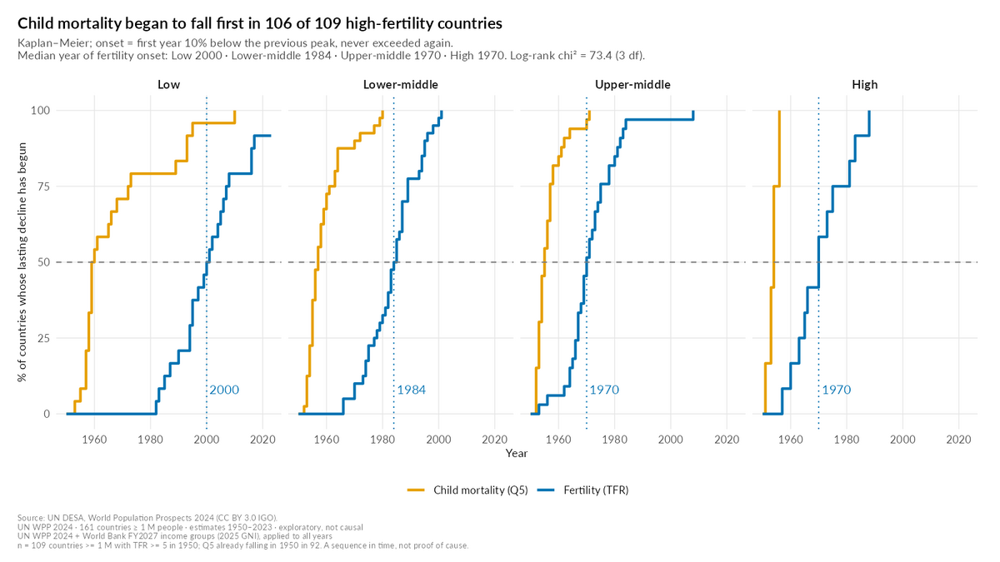

**`figures/review/q1/q1_07_event_time_inicio.png`** (figura de revisión, no final)

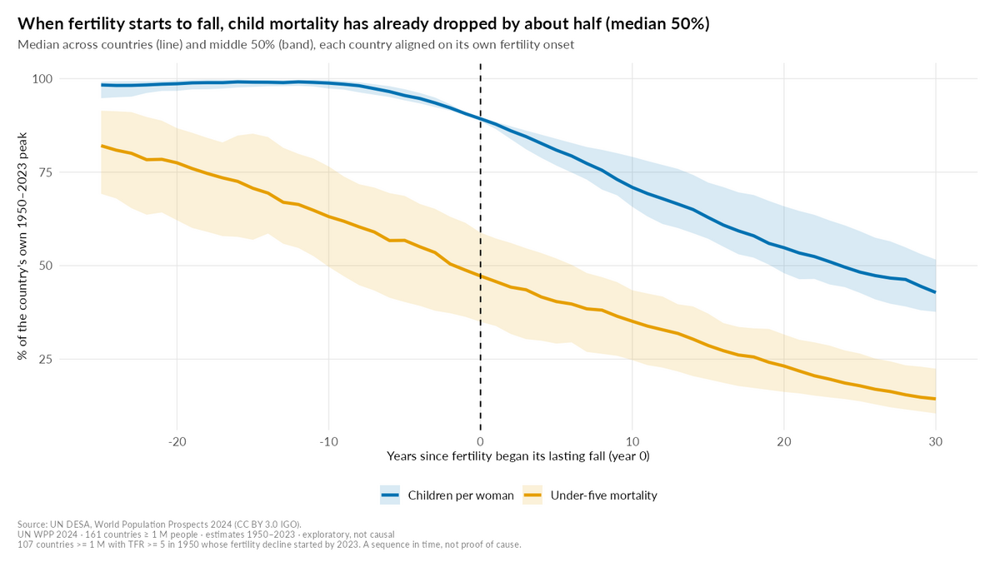

**`figures/review/q1/q1_08_rejilla_umbrales.png`** (figura de revisión, no final)

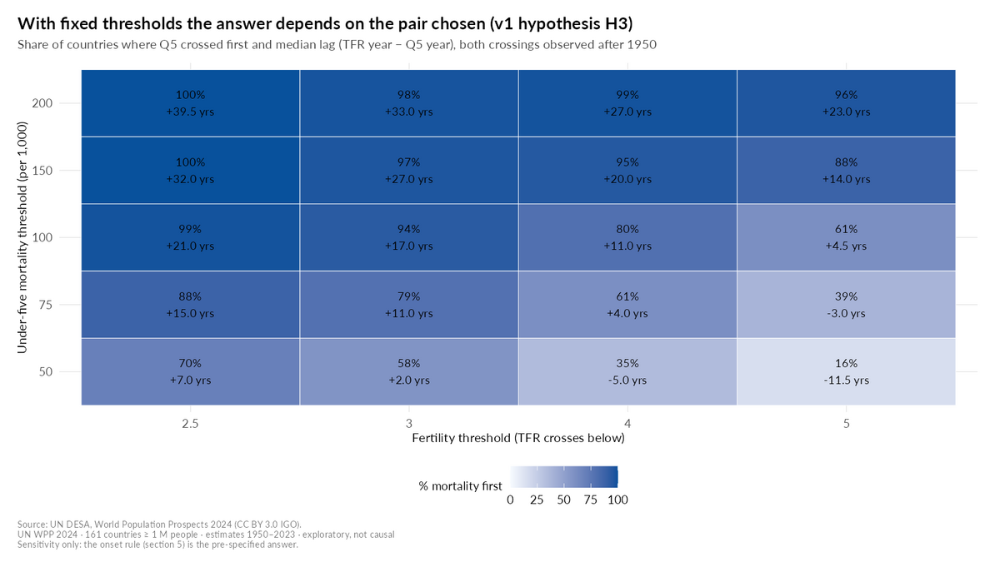

In [49]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_06_km_inicio_ingreso", "q1_07_event_time_inicio", "q1_08_rejilla_umbrales"))

#### Lectura de resultados · §5 Supervivencia: ¿qué empieza a caer primero? (sección 5)

*Texto de `docs/resultados_q1.md` §5 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Fechamos el inicio de la caída duradera de Q5 y TFR (regla de Princeton: primer año ≤ 90 % del máximo previo que no se vuelve a superar) en los 109 países ≥ 1 M con TFR₁₉₅₀ ≥ 5 y grupo de ingreso (Taiwán fuera por no tener grupo). Orden con Wilson; rezago como intervalo (Turnbull); año de inicio de la caída de la fecundidad por ingreso con Kaplan–Meier (censura en 2023), log-rank y Cox.

| Resultado | Valor | Intervalo / sensibilidad | Clave |
|---|---|---|---|
| Mortalidad infantil primero (regla preinscrita H3a) | **106 de 109 = 97,2 %** | Wilson [92,2; 99,1]; 9 reglas: 94,5–97,4 % | `n_mort_first_onset`, `n_onset`, `share_mort_first` |
| Solo con ambos inicios observados | 104 de 107 (97,2 %) | Wilson [92,1; 99,0]; con Taiwán 105 de 108 | `share_mort_first_both_observed` |
| Fecundidad primero | LBN, RWA, XKX | — | log |
| TFR aún sin iniciar su caída en 2023 | CAF, COD | cuentan como "mortalidad primero" | log |
| Q5 ya caía en 1950 (censura izquierda) | 92 de 109 | — | `n_q5_falling_1950` |
| Mediana del rezago (Turnbull) | **no identificable** (64 % de la masa más allá del último tiempo) | 13 exactos, 3 izq., 84 der., 9 sin información | `lag_onset_turnbull_mass_beyond` |
| Cota inferior de la mediana del rezago | **22 años** | IC bloques [16; 28]; iid [20; 25]; 9 reglas 19–24 | `lag_onset_lower_bound` |
| Caída de Q5 (desde su máximo) al iniciar la caída de la TFR | **mediana 50 %** | IC [43,8; 60,7]; RIC 41–64 | `q5_drop_at_tfr_onset` |

| Inicio de la caída de la TFR (KM) | n (eventos) | Año mediano | IC 95 % (Brookmeyer–Crowley) | Clave |
|---|---|---|---|---|
| Bajo | 24 (22) | **2000** | [1995; 2007] | `yr_fert_onset_low` |
| Medio-bajo | 40 (40) | **1984** | [1982; 1987] | `yr_fert_onset_lowmid` |
| Medio-alto | 33 (33) | **1970** | [1968; 1975] | `yr_fert_onset_upmid` |
| Alto | 12 (12) | 1970 | [1965; —] | `yr_fert_onset_high` |

Log-rank (4 grupos) χ² = **73,4** (3 gl; Holm p ≈ 6 × 10⁻¹⁵, solo notebook); Cox con el ingreso como escalón: HR = 2,37 [1,93; 2,92]. Por región SDG: Europa y Norteamérica 1956 (n = 4), LAC 1970, Asia central y meridional 1974, Asia oriental y sudoriental 1974, Norte de África y Asia occidental 1980, África subsahariana 1995. **Rejilla de umbrales fijos (H3 de v1):** medianas del rezago de −11,5 a +39,5 años y "mortalidad primero" del 16 % al 100 % según el par; con 100/4 y KM, 14 años [11; 18].

Figuras: `q1_06_km_inicio_ingreso.png`, `q1_07_event_time_inicio.png`, `q1_08_rejilla_umbrales.png`.

**Lectura de resultados.**
- La mortalidad infantil empezó a caer primero en casi todos los países de alta fecundidad (97 %), con cualquiera de las 9 reglas (94–97 %). H3a se confirma (límite inferior de Wilson 92,2 > 50).
- No se puede decir "el rezago mediano es X años": Q5 ya caía en 1950 en 92 de 109 países. Lo honesto es "**at least 22 years**" como cota de la **mediana** (no de cada país). El IC por bloques [16; 28] es más ancho que el iid del plan [20; 25].
- Cuando la fecundidad empieza a caer, la mortalidad infantil ya ha bajado a la mitad de su máximo (mediana 50 %, en el gráfico de tiempo de evento Q5 está al 47 % y TFR al 89 % de su máximo en el año 0).
- El calendario por ingreso de hoy es monótono (2000 > 1984 > 1970): H3b se confirma. El ingreso de hoy es en parte resultado de la transición: es un calendario, no una causa.
- H3 (11 años con umbrales 100/4) se rechaza: la respuesta cambia de signo dentro de la rejilla. Va a "What we did not find".

### Q1 · §6 Registro por hitos (datos funcionales): mismo camino, distinta velocidad

*Exploratory (H17, H18)* · `R/02_q1_palancas.R` líneas 1332–1553

In [50]:
# =============================================================================
# 6. Registro por hitos (datos funcionales): mismo camino, distinta velocidad
# =============================================================================
# QUÉ: suaviza la TFR de cada país (B-splines, lambda = 10), fecha el último
#      cruce de 4 hijos y alinea a todos en ese "reloj propio"; mide cuánta
#      varianza entre países desaparece en +-20 años y cuánto tardan de 5 a 3.
# POR QUÉ: convierte "same road, different speed" en una cifra comprobable
#      (no en un adjetivo) y separa el "cuándo" del "cómo".
seccion("6. Registro por hitos (FDA)")

anios <- 1950:2023
Y <- est1m |> select(ISO3_code, Time, TFR) |> pivot_wider(names_from = ISO3_code, values_from = TFR) |> arrange(Time)
M_TFR <- as.matrix(Y[, -1]); rownames(M_TFR) <- Y$Time
paises_fd <- colnames(M_TFR)
stopifnot(identical(as.integer(rownames(M_TFR)), anios), !anyNA(M_TFR))
base_fd <- fda::create.bspline.basis(c(1950, 2023), nbasis = length(anios) + 2, norder = 4)
fd_tfr <- fda::smooth.basis(anios, M_TFR, fda::fdPar(base_fd, 2, LAMBDA_FDA))$fd
tf <- seq(1950, 2023, by = 0.1)
Tfine <- fda::eval.fd(tf, fd_tfr); colnames(Tfine) <- paises_fd
cruce_suave <- function(y, u) {
  if (y[1] < u) return(-Inf)
  if (tail(y, 1) >= u) return(Inf)
  i <- max(which(y >= u)); tf[i] + (y[i] - u) / (y[i] - y[i + 1]) * 0.1
}
hitos <- tibble(ISO3_code = paises_fd, col = seq_along(paises_fd),
                c5 = apply(Tfine, 2, cruce_suave, 5), c4 = apply(Tfine, 2, cruce_suave, 4),
                c3 = apply(Tfine, 2, cruce_suave, 3)) |>
  left_join(c23 |> select(ISO3_code, Location, region_sdg, subregion, ingreso, pop_2023_miles = TPopulation1July), by = "ISO3_code")
n_c4 <- sum(is.finite(hitos$c4)); n_izq <- sum(hitos$c4 == -Inf); n_der <- sum(hitos$c4 == Inf)
n_der_ssa <- sum(hitos$c4 == Inf & hitos$region_sdg == "Sub-Saharan Africa")
informar("Cruce de TFR = 4: observado %d · ya < 4 en 1950: %d · aún >= 4 en 2023: %d (%d en África subsahariana)", n_c4, n_izq, n_der, n_der_ssa)


6. Registro por hitos (FDA)


Cruce de TFR = 4: observado 90 · ya < 4 en 1950: 45 · aún >= 4 en 2023: 26 (23 en África subsahariana)


In [51]:
# 6.2 Varianza entre países: calendario vs reloj propio (ventana +-20)
reduccion_var <- function(cs, cols, w = 20) {
  tau <- -w:w
  ev_f <- function(j, t) stats::approx(tf, Tfine[, cols[j]], xout = t, rule = 2)$y
  Al <- vapply(seq_along(cs), function(j) ev_f(j, cs[j] + tau), numeric(length(tau)))
  cal0 <- stats::median(cs)
  Ca <- vapply(seq_along(cs), function(j) ev_f(j, cal0 + tau), numeric(length(tau)))
  list(v_cal = apply(Ca, 1, stats::var), v_al = apply(Al, 1, stats::var), Al = Al, Ca = Ca, tau = tau)
}
pct_red <- function(r, sin0 = FALSE) {
  k <- if (sin0) r$tau != 0 else rep(TRUE, length(r$tau))
  100 * (1 - mean(r$v_al[k]) / mean(r$v_cal[k]))
}
regs_hito <- list()
for (h in c("c4", "c5", "c3")) {
  ok <- is.finite(hitos[[h]]) & hitos[[h]] - 20 >= 1950 & hitos[[h]] + 20 <= 2023
  d_h <- hitos[ok, ] |> mutate(cc = .data[[h]])
  r <- reduccion_var(d_h$cc, d_h$col)
  f_stat <- function(d) pct_red(reduccion_var(d$cc, d$col))
  bb <- bootstrap_bloques(d_h, f_stat, B = if (h == "c4") B_Q1 else B_NB, semilla = SEM)
  regs_hito[[h]] <- list(n = nrow(d_h), pct = pct_red(r), pct_sin0 = pct_red(r, TRUE), bb = bb, r = r, d = d_h,
                         v_cal = mean(r$v_cal), v_al = mean(r$v_al))
  informar("Hito %s: %d países con ventana completa; varianza media %.3f (calendario) -> %.3f (alineada): -%.1f %% [bloques %.1f; %.1f] (sin tau = 0: -%.1f %%)",
           h, nrow(d_h), mean(r$v_cal), mean(r$v_al), pct_red(r), bb$ci_low, bb$ci_high, pct_red(r, TRUE))
}
hitos <- hitos |> mutate(ventana_completa_c4 = is.finite(c4) & c4 - 20 >= 1950 & c4 + 20 <= 2023)
disp_reg <- bind_rows(lapply(names(regs_hito), function(h) {
  r <- regs_hito[[h]]$r
  tibble(hito = h, tau = r$tau, var_calendario = r$v_cal, var_alineado = r$v_al,
         p10_calendario = apply(r$Ca, 1, quantile, 0.1), p50_calendario = apply(r$Ca, 1, median), p90_calendario = apply(r$Ca, 1, quantile, 0.9),
         p10_alineado = apply(r$Al, 1, quantile, 0.1), p50_alineado = apply(r$Al, 1, median), p90_alineado = apply(r$Al, 1, quantile, 0.9))
}))

Hito c4: 57 países con ventana completa; varianza media 0.920 (calendario) -> 0.186 (alineada): -79.8 % [bloques 69.4; 85.1] (sin tau = 0: -79.2 %)
Hito c5: 60 países con ventana completa; varianza media 0.928 (calendario) -> 0.218 (alineada): -76.5 % [bloques 68.3; 83.3] (sin tau = 0: -75.8 %)
Hito c3: 52 países con ventana completa; varianza media 0.935 (calendario) -> 0.273 (alineada): -70.8 % [bloques 64.9; 78.4] (sin tau = 0: -70.3 %)


In [52]:
# 6.3 Kneip-Ramsay (amplitud vs fase) con fda::landmarkreg
r2_fase <- tryCatch({
  sel <- hitos$ventana_completa_c4
  x0 <- 0:73; b0 <- fda::create.bspline.basis(c(0, 73), nbasis = 25, norder = 4)
  fdx <- fda::smooth.basis(x0, M_TFR[, hitos$col[sel]], fda::fdPar(b0, 2, 1))$fd
  c4r <- hitos$c4[sel] - 1950
  wb <- fda::create.bspline.basis(c(0, 73), 5, 4); wp <- fda::fdPar(fda::fd(matrix(0, 5, 1), wb), 2, 1e-4)
  invisible(utils::capture.output(regkr <- fda::landmarkreg(fdx, ximarks = matrix(c4r), x0marks = mean(c4r),
                                                            WfdPar = wp, WfdPar0 = wp, ylambda = 1e-2)))
  apd <- fda::AmpPhaseDecomp(fdx, regkr$regfd, regkr$warpfd)
  c(r2 = apd$RSQR, C = apd$C)
}, error = function(e) { message("landmarkreg falló: ", conditionMessage(e)); c(r2 = NA_real_, C = NA_real_) })
informar("Kneip-Ramsay (57 países, 1950-2023): R2 de fase = %.2f, C = %.2f", r2_fase["r2"], r2_fase["C"])

Kneip-Ramsay (57 países, 1950-2023): R2 de fase = 0.56, C = 1.01


In [53]:
# 6.4 Velocidad 5 -> 3 con Kaplan-Meier (censura en 2023)
d53 <- hitos |> filter(is.finite(c5)) |>
  mutate(fin = ifelse(is.finite(c3), c3, 2023), evento_3 = as.integer(is.finite(c3)), dur_5a3 = fin - c5,
         cohorte_c5 = cut(c5, c(1949, 1975, 1990, 2024), labels = c("crossed 5 by 1975", "1975-1990", "after 1990")),
         cohorte2 = ifelse(c5 <= 1990, "crossed 5 by 1990", "after 1990"))
km_dur <- function(d) {
  f <- survfit(Surv(dur_5a3, evento_3) ~ 1, data = d); tb <- summary(f)$table
  c(n = nrow(d), eventos = sum(d$evento_3), med = unname(tb["median"]), lo = unname(tb["0.95LCL"]), hi = unname(tb["0.95UCL"]))
}
km53 <- rbind(t(sapply(split(d53, d53$cohorte_c5), km_dur)), `crossed 5 by 1990` = km_dur(d53 |> filter(cohorte2 == "crossed 5 by 1990")))
print(round(km53, 1))
dur_pais <- function(iso) d53$dur_5a3[d53$ISO3_code == iso & d53$evento_3 == 1]
d53_10m <- d53 |> filter(evento_3 == 1, pop_2023_miles >= 10000) |> arrange(dur_5a3)
resaltar <- c(rapido = d53_10m$ISO3_code[1],
              mediano = d53_10m$ISO3_code[which.min(abs(d53_10m$dur_5a3 - median(d53_10m$dur_5a3)))],
              lento = d53_10m$ISO3_code[nrow(d53_10m)])
informar("5 -> 3: China %.1f años, Egipto %.1f; más rápidos %s; resaltados por regla (>= 10 M): %s",
         dur_pais("CHN"), dur_pais("EGY"),
         paste(sprintf("%s %.1f", head(d53 |> filter(evento_3 == 1) |> arrange(dur_5a3), 5)$ISO3_code,
                       head(d53 |> filter(evento_3 == 1) |> arrange(dur_5a3), 5)$dur_5a3), collapse = ", "),
         paste(sprintf("%s=%s", names(resaltar), resaltar), collapse = ", "))
hitos <- hitos |> left_join(d53 |> select(ISO3_code, dur_5a3, evento_3, cohorte_c5), by = "ISO3_code")
km53_tab <- bind_rows(lapply(levels(d53$cohorte_c5), function(cc) {
  f <- survfit(Surv(dur_5a3, evento_3) ~ 1, data = d53 |> filter(cohorte_c5 == cc))
  tibble(curva = "dur53_by_cohort", grupo = cc, anio_o_t = c(0, f$time), surv = c(1, f$surv), lower = c(1, f$lower),
         upper = c(1, f$upper), n_risk = c(f$n, f$n.risk), n_event = c(0, f$n.event))
}))
km_tab <- bind_rows(km_tab, km53_tab)

                   n eventos  med   lo   hi
crossed 5 by 1975 20      20 19.5 17.7 21.0
1975-1990         32      30 18.3 16.3 23.6
after 1990        50      13 24.1 19.1   NA
crossed 5 by 1990 52      50 18.8 17.7 19.9


5 -> 3: China 5.1 años, Egipto 32.7; más rápidos CHN 5.1, IRN 5.3, SGP 7.5, MNG 7.5, THA 9.3; resaltados por regla (>= 10 M): rapido=CHN, mediano=COL, lento=EGY


In [54]:
# 6.5 Registro de cifras FDA
F_FDA <- "161 countries >= 1 M, estimates 1950-2023; TFR smoothed with cubic B-splines (2nd-derivative penalty, lambda = 10)"
r4 <- regs_hito$c4
anotar("n_cruce_tfr4_obs", value = n_c4, unit = "countries", fmt = "0",
       def = "Countries whose smoothed TFR last crossed 4 between 1950 and 2023", filter = F_FDA, source_cell = "Q1-6.1",
       used_in = c("slide2.build1"), method = "none_census", status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("n_cens_izq", value = n_izq, unit = "countries", fmt = "0", def = "Countries already below TFR 4 in 1950 (left-censored, not shown in the registration)",
       filter = F_FDA, source_cell = "Q1-6.1", used_in = c("slide2.build1"), method = "none_census", status = "descriptive",
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("n_cens_der", value = n_der, unit = "countries", fmt = "0",
       def = "Countries still at TFR >= 4 in 2023 (right-censored, not shown in the registration: survivorship caveat)",
       filter = F_FDA, source_cell = "Q1-6.1", used_in = c("slide2.build1"), method = "none_census",
       sens_note = sprintf("%d of them in sub-Saharan Africa", n_der_ssa), status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("n_cens_der_ssa", value = n_der_ssa, unit = "countries", fmt = "0",
       def = "Of n_cens_der, countries in sub-Saharan Africa", filter = F_FDA, source_cell = "Q1-6.1", used_in = c("slide2.build1"),
       method = "none_census", status = "descriptive", n = n_der, universe = UNIVERSO_1M)
anotar("pct_var_fase", value = round(r4$pct, 4), unit = "%", fmt = "0", ic = r4$bb,
       def = "Reduction of the mean cross-country variance of smoothed TFR in a +-20-year window when each country is aligned on the year it last crossed TFR = 4 (own clock) instead of a common calendar window centred on the median crossing year",
       filter = sprintf("%d countries >= 1 M whose crossing +-20 years lies within 1950-2023", r4$n), source_cell = "Q1-6.2",
       used_in = c("slide2.build1", "narration.slide2"),
       sens_low = round(min(r4$pct_sin0, regs_hito$c5$pct, regs_hito$c3$pct), 2), sens_high = round(max(r4$pct, r4$pct_sin0), 2),
       sens_note = sprintf("variance %.3f -> %.3f; without tau = 0: %.1f%%; milestone 5: %.1f%% (n = %d); milestone 3: %.1f%% (n = %d); Kneip-Ramsay phase R2 %.2f",
                           r4$v_cal, r4$v_al, r4$pct_sin0, regs_hito$c5$pct, regs_hito$c5$n, regs_hito$c3$pct, regs_hito$c3$n, r2_fase["r2"]),
       status = "exploratory", hypothesis_id = "H17", say = "four fifths", n = r4$n, universe = UNIVERSO_1M)
for (h in c("c5", "c3")) {
  x <- regs_hito[[h]]
  anotar(paste0("pct_var_fase_", h), value = round(x$pct, 4), unit = "%", fmt = "0", ic = x$bb,
         def = sprintf("Same variance reduction aligning on the last crossing of TFR = %s", substring(h, 2)),
         filter = sprintf("%d countries >= 1 M with a complete +-20 window", x$n), source_cell = "Q1-6.2", used_in = c("notebook.T4"),
         status = "exploratory", hypothesis_id = "H17", n = x$n, universe = UNIVERSO_1M)
}
anotar("r2_fase_kr", value = round(unname(r2_fase["r2"]), 4), unit = "R2", fmt = "0.00",
       def = "Kneip-Ramsay amplitude/phase decomposition (fda::landmarkreg on the TFR = 4 landmark, 1950-2023): share of variation due to phase (timing)",
       filter = sprintf("%d countries >= 1 M with a complete +-20 window", r4$n), source_cell = "Q1-6.3", used_in = c("notebook.T4"),
       method = "descriptive", sens_note = sprintf("C = %.2f", r2_fase["C"]), status = "exploratory", hypothesis_id = "H17",
       n = r4$n, universe = UNIVERSO_1M)
anotar("dur53_chn", value = round(dur_pais("CHN"), 4), unit = "years", fmt = "0", method = "descriptive",
       def = "Years for China's smoothed TFR to go from its last crossing of 5 to its last crossing of 3", filter = F_FDA,
       source_cell = "Q1-6.4", used_in = c("slide2.build1", "narration.slide2"), status = "descriptive", n = 1, universe = UNIVERSO_1M)
anotar("dur53_egy", value = round(dur_pais("EGY"), 4), unit = "years", fmt = "0", method = "descriptive",
       def = "Years for Egypt's smoothed TFR to go from its last crossing of 5 to its last crossing of 3", filter = F_FDA,
       source_cell = "Q1-6.4", used_in = c("slide2.build1", "narration.slide2"), status = "descriptive", n = 1, universe = UNIVERSO_1M)
km_claves <- c("crossed 5 by 1975" = "km_dur53_pre1975", "1975-1990" = "km_dur53_1975_1990", "after 1990" = "km_dur53_post1990",
               "crossed 5 by 1990" = "km_dur53_upto1990")
for (gk in names(km_claves)) {
  x <- km53[gk, ]
  anotar(km_claves[[gk]], value = round(unname(x["med"]), 4), unit = "years", fmt = "0.0", method = "km",
         ci_low = round(unname(x["lo"]), 4), ci_high = if (is.na(x["hi"])) NA else round(unname(x["hi"]), 4),
         def = sprintf("Kaplan-Meier median years from TFR 5 to TFR 3 (smoothed, last crossings), countries that %s; right-censored in 2023", gk),
         filter = F_FDA, source_cell = "Q1-6.4", used_in = c("notebook.T4"),
         sens_note = sprintf("n = %d, reached 3 = %d", x["n"], x["eventos"]), status = "exploratory", hypothesis_id = "H18",
         n = unname(x["n"]), universe = UNIVERSO_1M)
}
# Regla de velocidad (QA-storyboard §6.4): ¿China y Egipto son el más rápido y el más lento entre los >= 10 M?
regla_vel_ok <- resaltar[["rapido"]] == "CHN" && resaltar[["lento"]] == "EGY"
informar("Regla de velocidad (>= 10 M que llegaron a 3, n = %d): más rápido %s (%.1f), más lento %s (%.1f) -> %s",
         nrow(d53_10m), resaltar[["rapido"]], dur_pais(resaltar[["rapido"]]), resaltar[["lento"]], dur_pais(resaltar[["lento"]]),
         ifelse(regla_vel_ok, "China y Egipto se mantienen", "CAMBIAN los países de la voz"))
for (lado in c("rapido", "lento")) {
  anotar(if (lado == "rapido") "dur53_fastest_ge10m" else "dur53_slowest_ge10m", value = resaltar[[lado]], unit = NA, fmt = "text",
         method = "descriptive",
         def = sprintf("Rule: the %s country (>= 10 M people) in going from TFR 5 to 3 (smoothed, last crossings), among those that reached 3 by 2023", ifelse(lado == "rapido", "fastest", "slowest")),
         filter = F_FDA, source_cell = "Q1-6.4", used_in = c("slide2.build1", "narration.slide2"), status = "descriptive",
         sens_note = sprintf("%s: %.1f years; storyboard check (China fastest, Egypt slowest): %s", resaltar[[lado]], dur_pais(resaltar[[lado]]),
                             ifelse(regla_vel_ok, "holds", "FAILS")),
         n = nrow(d53_10m), universe = UNIVERSO_1M)
}
anotar("fig04_highlight_iso3", value = I(unname(resaltar)), unit = NA, fmt = "text", method = "descriptive",
       # QA-stats (docs/QA_stats.md): con n par la mediana cae entre dos países; la regla toma el más cercano.
       def = sprintf(paste("Rule: fastest, median and slowest countries (>= 10 M people) in going from TFR 5 to 3 (smoothed, last crossings),",
                           "among the %d that reached 3 by 2023; 'median' = the country whose duration is closest to the median duration",
                           "(%.2f years%s)"),
                     nrow(d53_10m), median(d53_10m$dur_5a3),
                     if (nrow(d53_10m) %% 2 == 0) "; with an even number of countries the median falls between two of them" else ""),
       filter = F_FDA, source_cell = "Q1-6.4", used_in = c("slide2.build1"), status = "descriptive",
       sens_note = paste(sprintf("%s %.1f yrs", d53_10m$ISO3_code[d53_10m$ISO3_code %in% resaltar], d53_10m$dur_5a3[d53_10m$ISO3_code %in% resaltar]), collapse = "; "),
       n = nrow(d53_10m), universe = UNIVERSO_1M)

Regla de velocidad (>= 10 M que llegaron a 3, n = 36): más rápido CHN (5.1), más lento EGY (32.7) -> China y Egipto se mantienen


In [55]:
# 6.6 Curvas alineadas (parquet) y figuras de revisión
curvas <- bind_rows(lapply(which(is.finite(hitos$c4)), function(j) {
  tibble(ISO3_code = hitos$ISO3_code[j], Time = anios, tfr_suav = as.numeric(fda::eval.fd(anios, fd_tfr[hitos$col[j]])),
         c4 = hitos$c4[j], tau = anios - hitos$c4[j])
}))
p9a <- ggplot(curvas, aes(Time, tfr_suav, group = ISO3_code)) + geom_line(colour = "grey70", linewidth = 0.3) +
  geom_line(data = curvas |> filter(ISO3_code %in% resaltar), aes(colour = ISO3_code), linewidth = 1.1) +
  geom_hline(yintercept = 4, linetype = "dashed") + scale_colour_manual(values = setNames(COLORES_RESALTE, resaltar)) +
  labs(x = "Calendar year", y = "Children per woman (smoothed)", colour = NULL, title = "A · Calendar time") + tema_q1(11)
band <- disp_reg |> filter(hito == "c4")
p9b <- ggplot() +
  geom_line(data = curvas |> filter(tau >= -30, tau <= 30), aes(tau, tfr_suav, group = ISO3_code), colour = "grey80", linewidth = 0.3) +
  geom_ribbon(data = band, aes(tau, ymin = p10_alineado, ymax = p90_alineado), fill = COLOR_NACIMIENTOS, alpha = 0.25) +
  geom_line(data = band, aes(tau, p50_alineado), colour = COLOR_NACIMIENTOS, linewidth = 1.3) +
  geom_line(data = curvas |> filter(ISO3_code %in% resaltar, tau >= -30, tau <= 30), aes(tau, tfr_suav, colour = ISO3_code), linewidth = 1.1) +
  geom_hline(yintercept = 4, linetype = "dashed") + scale_colour_manual(values = setNames(COLORES_RESALTE, resaltar)) +
  labs(x = "Years since fertility last fell below 4", y = NULL, colour = NULL, title = "B · Each country's own clock") + tema_q1(11)
p9 <- (p9a | p9b) + plot_layout(guides = "collect") +
  plot_annotation(title = sprintf("Same road, different clock: aligning on TFR = 4 removes %.0f%% of the gaps between countries", r4$pct),
                  subtitle = sprintf("%d countries crossed 4 in 1950–2023 (band: P10–P90 of the %d with a full ±20-year window).\n%d were already below 4 in 1950; %d have not crossed yet (%d in sub-Saharan Africa) and are not shown.",
                                     n_c4, r4$n, n_izq, n_der, n_der_ssa),
                  caption = pie_q1(PIE_MODELOS, sprintf("TFR smoothed with B-splines (lambda = 10). Highlighted by rule (>= 10 M): fastest, median and slowest from 5 to 3 children: %s.", paste(resaltar, collapse = ", "))),
                  theme = tema_q1(11)) & theme(legend.position = "bottom")
guardar_q1(p9, "q1_09_registro_tfr4")
fig53 <- km53_tab |> mutate(grupo = factor(grupo, levels = levels(d53$cohorte_c5)))
lab53 <- tibble(grupo = factor(rownames(km53)[1:3], levels = levels(d53$cohorte_c5)), med = km53[1:3, "med"], n = km53[1:3, "n"], ev = km53[1:3, "eventos"])
p10 <- ggplot(fig53, aes(anio_o_t, 100 * (1 - surv), colour = grupo)) + geom_step(linewidth = 1.1) +
  geom_hline(yintercept = 50, linetype = "dashed", colour = COL_GRIS) +
  scale_colour_manual(values = c("#BBBBBB", "#6699CC", "#004488"),
                      labels = sprintf("%s (n = %d, reached 3: %d; median %.1f yrs)", lab53$grupo, lab53$n, lab53$ev, lab53$med), name = NULL) +
  labs(x = "Years since TFR crossed 5", y = "% that have reached TFR 3",
       title = "Starting later did not mean moving faster from five to three children",
       subtitle = sprintf("Kaplan–Meier, right-censored in 2023. China %.1f years, Egypt %.1f years.", dur_pais("CHN"), dur_pais("EGY")),
       caption = pie_q1(PIE_MODELOS)) + tema_q1(12) + guides(colour = guide_legend(nrow = 3))
guardar_q1(p10, "q1_10_velocidad_5a3")

**`figures/review/q1/q1_09_registro_tfr4.png`** (figura de revisión, no final)

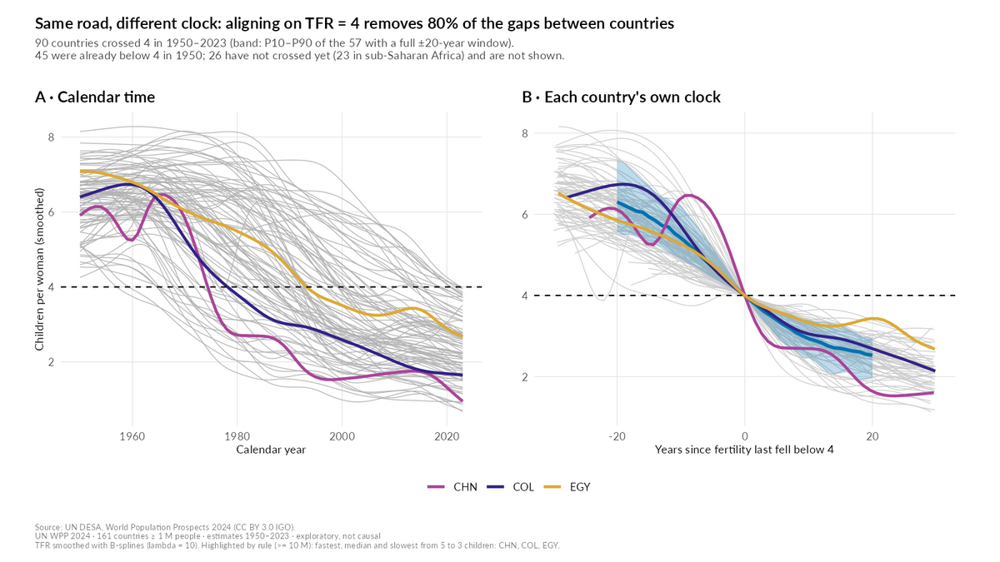

**`figures/review/q1/q1_10_velocidad_5a3.png`** (figura de revisión, no final)

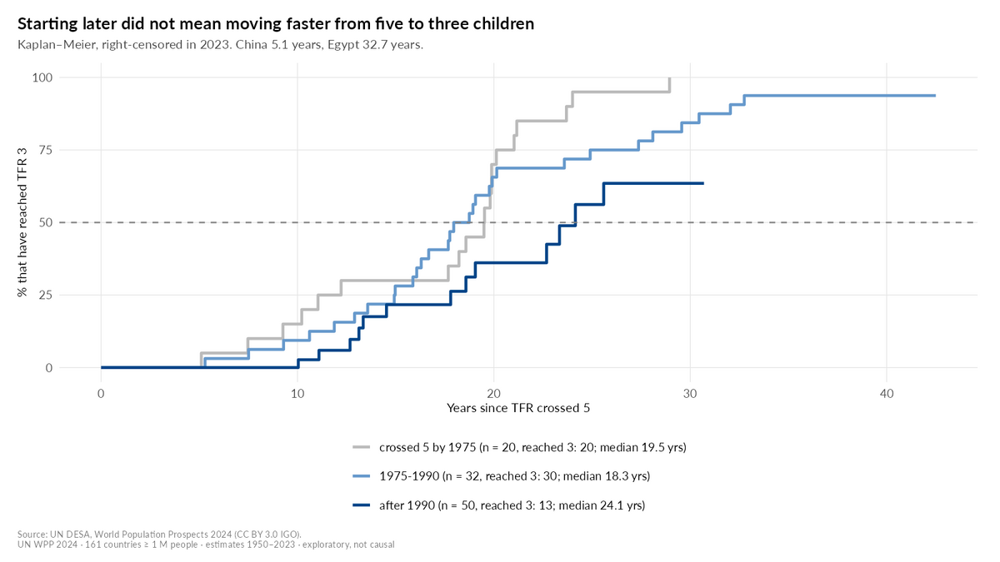

In [56]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_09_registro_tfr4", "q1_10_velocidad_5a3"))

#### Lectura de resultados · §6 Registro por hitos: mismo camino, distinta velocidad (sección 6)

*Texto de `docs/resultados_q1.md` §6 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Suavizamos la TFR de cada país (B-splines cúbicos, λ = 10), fechamos el **último** cruce de 4 y alineamos a todos en ese reloj propio. Medimos cuánta varianza entre países desaparece en ±20 años (calendario centrado en la mediana vs reloj propio), descomposición amplitud/fase de Kneip–Ramsay y la velocidad de 5 a 3 hijos con KM.

| Resultado | Valor | IC / detalle | Clave |
|---|---|---|---|
| Cruce de 4 observado 1950–2023 | 90 países | ya < 4 en 1950: 45; aún ≥ 4 en 2023: **26** (23 en África subsahariana) | `n_cruce_tfr4_obs`, `n_cens_izq`, `n_cens_der`, `n_cens_der_ssa` |
| Reducción de varianza (hito 4; 57 con ventana completa) | **−80 %** (0,920 → 0,186) | IC bloques [69,4; 85,1]; sin τ = 0: −79 % | `pct_var_fase` |
| Hito 5 (60 países) / hito 3 (52 países) | −77 % / −71 % | [68; 83] / [65; 78] | `pct_var_fase_c5`, `pct_var_fase_c3` |
| R² de fase (Kneip–Ramsay) | 0,56 | C = 1,01 | `r2_fase_kr` |
| 5 → 3 hijos: China / Egipto | **5,1 / 32,7 años** | el más rápido y el más lento de los 36 países ≥ 10 M que llegaron a 3; mediano: Colombia | `dur53_chn`, `dur53_egy`, `dur53_fastest_ge10m`, `dur53_slowest_ge10m`, `fig04_highlight_iso3` |
| KM 5 → 3: cruzaron 5 hasta 1975 (20) / 1975–90 (32) / después de 1990 (50, solo 13 llegaron a 3) | 19,5 / 18,3 / **24,1 años** | [17,7; 21,0] / [16,3; 23,6] / [19,1; —]; hasta 1990: 18,8 [17,7; 19,9] | `km_dur53_*` |

Figuras: `q1_09_registro_tfr4.png`, `q1_10_velocidad_5a3.png`.

**Lectura de resultados.** Al poner a cada país en su propio reloj, las curvas casi se superponen: el 80 % de las diferencias entre países era de calendario ("cuándo"), no de forma ("cómo"). H17 se confirma (≥ 50 % con el hito 4 y ≥ 30 % con 5 y 3). Quienes cruzaron 5 después de 1990 no van más rápido (24,1 años de mediana frente a 18,8; H18 ✔). La regla de resaltes del storyboard se mantiene: China es el más rápido (5,1) y Egipto el más lento (32,7). Advertencia de supervivencia: los 26 países que no han cruzado 4 (casi todos en África subsahariana) no están en la alineación.

### Q1 · §7 Panel en cambios quinquenales con efectos fijos país + periodo

*Exploratory (H15, H16)* · `R/02_q1_palancas.R` líneas 1554–1951

In [57]:
# =============================================================================
# 7. Panel en cambios quinquenales con efectos fijos país + periodo
# =============================================================================
# QUÉ: relaciona el cambio de la fecundidad con el cambio del log de la
#      mortalidad infantil en los 0-20 años previos, comparando cada país
#      consigo mismo (FE país) y quitando lo que le pasó a todos a la vez (FE
#      periodo); lo contrasta con la pendiente entre países y con placebos.
# POR QUÉ: separa "entre países" de "dentro del país" (no confundirlos
#      exageraría la relación ~2,5 veces) y prueba que no es tendencia común.
seccion("7. Panel quinquenal")

panel_base <- function(df) {
  df |> mutate(periodo = PERIODO_PANEL * (Time %/% PERIODO_PANEL), lQ5 = log(Q5), nat = NatChangeRT, crec = 10 * PopGrowthRate) |>
    filter(is.finite(lQ5)) |>
    group_by(ISO3_code, subregion, region_sdg, ingreso, periodo) |>
    summarise(across(c(TFR, lQ5, CNMR, nat, crec), mean), .groups = "drop") |>
    group_by(ISO3_code) |> arrange(periodo, .by_group = TRUE) |>
    mutate(dTFR = TFR - lag(TFR), dlQ5 = lQ5 - lag(lQ5), dCNMR = CNMR - lag(CNMR),
           L0 = dlQ5, L1 = lag(dlQ5, 1), L2 = lag(dlQ5, 2), L3 = lag(dlQ5, 3), L4 = lag(dlQ5, 4),
           F1 = lead(dlQ5, 1), T0 = dTFR, T1 = lag(dTFR, 1), T2 = lag(dTFR, 2), T3 = lag(dTFR, 3), T4 = lag(dTFR, 4),
           nat_1 = lag(nat, 1)) |> ungroup()
}
gq <- panel_base(est1m) |> left_join(pop23, by = "ISO3_code")
medias_anuales <- est1m |> group_by(ISO3_code) |> summarise(TFRm = mean(TFR), lQ5m = mean(log(Q5)))
gq_est <- gq |> filter(!is.na(dTFR), !is.na(L4)) |> left_join(medias_anuales, by = "ISO3_code")
f_dl <- dTFR ~ L0 + L1 + L2 + L3 + L4 | ISO3_code + periodo
m1 <- feols(f_dl, gq_est, cluster = ~ISO3_code)
s1 <- suma_rez(m1)
informar("Modelo principal: N = %d, países = %d, periodos %s-%s; suma de rezagos %.3f (EE %.3f); mitad de Q5 -> %.3f hijos [%.3f; %.3f] (cluster)",
         nobs(m1), n_distinct(gq_est$ISO3_code), min(gq_est$periodo), max(gq_est$periodo), s1$beta_sum, s1$ee,
         LN05 * s1$beta_sum, LN05 * s1$hi, LN05 * s1$lo)
print(round(coeftable(m1), 3))
m_entre <- lm(TFRm ~ lQ5m, data = medias_anuales)
entre <- LN05 * unname(coef(m_entre)[2])
informar("Entre países (medias 1950-2023): mitad de Q5 -> %.3f hijos; razón entre/dentro = %.2f", entre, entre / (LN05 * s1$beta_sum))


7. Panel quinquenal


Modelo principal: N = 1610, países = 161, periodos 1975-2020; suma de rezagos 0.597 (EE 0.216); mitad de Q5 -> -0.414 hijos [-0.707; -0.121] (cluster)


   Estimate Std. Error t value Pr(>|t|)
L0   -0.089      0.204  -0.435    0.664
L1    0.366      0.172   2.133    0.034
L2    0.217      0.084   2.599    0.010
L3    0.032      0.067   0.475    0.636
L4    0.071      0.071   1.003    0.318
attr(,"vcov_type")
[1] "Clustered (ISO3_code)"


Entre países (medias 1950-2023): mitad de Q5 -> -1.052 hijos; razón entre/dentro = 2.54


In [58]:
# 7.2 Bootstrap por bloques (subregión) e iid de las tres cifras
est_dentro_entre <- function(d) {
  idb <- paste(d$ISO3_code, d$.copia)
  d$id_b <- idb
  m <- feols(dTFR ~ L0 + L1 + L2 + L3 + L4 | id_b + periodo, d, vcov = "iid", notes = FALSE, warn = FALSE)
  w <- LN05 * sum(coef(m))
  u <- d[!duplicated(idb), ]
  b <- LN05 * unname(coef(stats::lm.fit(cbind(1, u$lQ5m), u$TFRm))[2])
  c(dentro = w, entre = b, razon = b / w, fraccion = w / b)
}
bb_de <- bootstrap_bloques(gq_est, est_dentro_entre, B = B_Q1, semilla = SEM)
bi_de <- bootstrap_bloques(gq_est, est_dentro_entre, bloque = NULL, B = B_Q1, semilla = SEM)
print(rbind(valor = bb_de$valor, bloques_lo = bb_de$ci_low, bloques_hi = bb_de$ci_high, iid_lo = bi_de$ci_low, iid_hi = bi_de$ci_high))

                dentro      entre     razon    fraccion
valor      -0.41402344 -1.0522773  2.541589  0.39345469
bloques_lo -0.76653674 -1.1698340 -9.242088 -0.04716109
bloques_hi  0.04596765 -0.9152594 18.356390  0.72570169
iid_lo     -0.69988585 -1.1158178  1.506638  0.13046968
iid_hi     -0.13928286 -0.9916344  7.205330  0.66099642


In [59]:
# 7.3 Heterogeneidad por ingreso (hoy) y región SDG
est_dentro <- function(d) {
  d$id_b <- paste(d$ISO3_code, d$.copia)
  LN05 * sum(coef(feols(dTFR ~ L0 + L1 + L2 + L3 + L4 | id_b + periodo, d, vcov = "iid", notes = FALSE, warn = FALSE)))
}
filas_panel <- list(tibble(bloque = "all", grupo = "All (>= 1 M)", n_paises = n_distinct(gq_est$ISO3_code), n_obs = nobs(m1),
                           beta_sum = s1$beta_sum, ee_cluster = s1$ee, halfq5 = LN05 * s1$beta_sum,
                           ci_cluster_lo = LN05 * s1$hi, ci_cluster_hi = LN05 * s1$lo,
                           ci_boot_lo = bb_de$ci_low[["dentro"]], ci_boot_hi = bb_de$ci_high[["dentro"]], metodo_boot = bb_de$method),
                    tibble(bloque = "between", grupo = "Across countries (1950-2023 means)", n_paises = nrow(medias_anuales), n_obs = nrow(medias_anuales),
                           beta_sum = unname(coef(m_entre)[2]), ee_cluster = NA, halfq5 = entre, ci_cluster_lo = NA, ci_cluster_hi = NA,
                           ci_boot_lo = bb_de$ci_low[["entre"]], ci_boot_hi = bb_de$ci_high[["entre"]], metodo_boot = bb_de$method))
het <- list()
for (g in NIVELES_INGRESO) {
  d_g <- gq_est |> filter(ingreso == g)
  m_g <- feols(f_dl, d_g, cluster = ~ISO3_code); s_g <- suma_rez(m_g)
  bb_g <- suppressWarnings(bootstrap_bloques(d_g, est_dentro, B = B_Q1, semilla = SEM))
  het[[g]] <- list(s = s_g, bb = bb_g, n = n_distinct(d_g$ISO3_code))
  filas_panel[[length(filas_panel) + 1]] <- tibble(bloque = "income", grupo = g, n_paises = n_distinct(d_g$ISO3_code), n_obs = nobs(m_g),
                                                   beta_sum = s_g$beta_sum, ee_cluster = s_g$ee, halfq5 = LN05 * s_g$beta_sum,
                                                   ci_cluster_lo = LN05 * s_g$hi, ci_cluster_hi = LN05 * s_g$lo,
                                                   ci_boot_lo = bb_g$ci_low, ci_boot_hi = bb_g$ci_high,
                                                   metodo_boot = sprintf("%s (%d blocks)", bb_g$method, bb_g$n_bloques))
}
REG_PANEL <- setdiff(REGIONES_SDG, c("Oceania (excluding Australia and New Zealand)", "Australia/New Zealand"))  # Oceanía: 3 países
het_reg <- list()
for (r in REG_PANEL) {
  d_r <- gq_est |> filter(region_sdg == r)
  m_r <- feols(f_dl, d_r, cluster = ~ISO3_code); s_r <- suma_rez(m_r)
  bi_r <- if (r %in% c("Sub-Saharan Africa", "Europe and Northern America")) bootstrap_bloques(d_r, est_dentro, bloque = NULL, B = B_Q1, semilla = SEM) else NULL
  het_reg[[r]] <- list(s = s_r, bi = bi_r, n = n_distinct(d_r$ISO3_code))
  filas_panel[[length(filas_panel) + 1]] <- tibble(bloque = "region", grupo = r, n_paises = n_distinct(d_r$ISO3_code), n_obs = nobs(m_r),
                                                   beta_sum = s_r$beta_sum, ee_cluster = s_r$ee, halfq5 = LN05 * s_r$beta_sum,
                                                   ci_cluster_lo = LN05 * s_r$hi, ci_cluster_hi = LN05 * s_r$lo,
                                                   ci_boot_lo = if (is.null(bi_r)) NA else bi_r$ci_low,
                                                   ci_boot_hi = if (is.null(bi_r)) NA else bi_r$ci_high,
                                                   metodo_boot = if (is.null(bi_r)) NA else bi_r$method)
}
cochran <- function(b, se) {
  w <- 1 / se^2; bb <- sum(w * b) / sum(w); Q <- sum(w * (b - bb)^2); gl <- length(b) - 1
  c(Q = Q, gl = gl, p = pchisq(Q, gl, lower.tail = FALSE), I2 = max(0, (Q - gl) / Q))
}
coch_ing <- cochran(sapply(het, function(x) x$s$beta_sum), sapply(het, function(x) x$s$ee))
coch_reg <- cochran(sapply(het_reg, function(x) x$s$beta_sum), sapply(het_reg, function(x) x$s$ee))
gi <- gq_est |> filter(ingreso != "Not classified") |> mutate(ingreso = droplevels(ingreso))
m_int <- feols(dTFR ~ i(ingreso, L0) + i(ingreso, L1) + i(ingreso, L2) + i(ingreso, L3) + i(ingreso, L4) | ISO3_code + periodo, gi, cluster = ~ISO3_code)
lev_i <- levels(gi$ingreso)
Rm <- matrix(0, 3, length(coef(m_int)), dimnames = list(NULL, names(coef(m_int))))
for (j in 2:4) { Rm[j - 1, paste0("ingreso::", lev_i[1], ":L", 0:4)] <- 1; Rm[j - 1, paste0("ingreso::", lev_i[j], ":L", 0:4)] <- -1 }
rb <- Rm %*% coef(m_int); wald <- as.numeric(t(rb) %*% solve(Rm %*% vcov(m_int) %*% t(Rm)) %*% rb)
wald_p <- pchisq(wald, 3, lower.tail = FALSE)
panel_tab <- bind_rows(filas_panel)
print(panel_tab |> mutate(across(where(is.numeric), \(x) round(x, 3))))
informar("Cochran Q ingreso = %.2f (gl %d, p = %.3f, I2 = %.2f); región = %.2f (gl %d, p = %.1e, I2 = %.2f); Wald (FE comunes) chi2(3) = %.2f, p = %.4f",
         coch_ing["Q"], coch_ing["gl"], coch_ing["p"], coch_ing["I2"], coch_reg["Q"], coch_reg["gl"], coch_reg["p"], coch_reg["I2"], wald, wald_p)

# A tibble: 12 × 12
   bloque  grupo                              n_paises n_obs beta_sum ee_cluster halfq5 ci_cluster_lo ci_cluster_hi ci_boot_lo ci_boot_hi metodo_boot           
   <chr>   <chr>                                 <dbl> <dbl>    <dbl>      <dbl>  <dbl>         <dbl>         <dbl>      <dbl>      <dbl> <chr>                 
 1 all     All (>= 1 M)                            161  1610    0.597      0.216 -0.414        -0.707        -0.121     -0.767      0.046 block bootstrap by su…
 2 between Across countries (1950-2023 means)      161   161    1.52      NA     -1.05         NA            NA         -1.17      -0.915 block bootstrap by su…
 3 income  Low income                               25   250    1.37       0.379 -0.948        -1.46         -0.432     -2.14      -0.07  block bootstrap by su…
 4 income  Lower middle income                      41   410   -0.1        0.527  0.069        -0.646         0.785     -0.56       0.649 block bootstrap by su…
 5 income  Upp

Cochran Q ingreso = 9.75 (gl 3, p = 0.021, I2 = 0.69); región = 52.96 (gl 5, p = 3.4e-10, I2 = 0.91); Wald (FE comunes) chi2(3) = 21.05, p = 0.0001


In [60]:
# 7.4 Placebo (Q5 de otro país), adelanto y sentido inverso
ids_p <- unique(gq_est$ISO3_code)
lags_tab <- gq |> select(ISO3_code, periodo, L0, L1, L2, L3, L4)
set.seed(SEM)
plac <- vapply(seq_len(B_PLAC), function(b) {
  perm <- setNames(sample(ids_p), ids_p)
  dd <- gq_est |> select(ISO3_code, periodo, dTFR) |>
    left_join(lags_tab |> filter(ISO3_code %in% ids_p) |> mutate(ISO3_code = unname(perm[ISO3_code])), by = c("ISO3_code", "periodo"))
  sum(coef(feols(f_dl, dd, vcov = "iid", notes = FALSE, warn = FALSE)))
}, numeric(1))
plac_q <- quantile(plac, c(0.025, 0.975))
plac_p <- (1 + sum(abs(plac) >= abs(s1$beta_sum))) / (B_PLAC + 1)
informar("Placebo (%d permutaciones): suma de rezagos media %.3f, 95 %% [%.3f; %.3f] vs real %.3f; p bilateral = %.3f",
         B_PLAC, mean(plac), plac_q[1], plac_q[2], s1$beta_sum, plac_p)
m_lead <- feols(dTFR ~ F1 + L0 + L1 + L2 + L3 + L4 | ISO3_code + periodo, gq_est, cluster = ~ISO3_code)
lead_ct <- coeftable(m_lead)["F1", ]
m_rev <- feols(dlQ5 ~ T0 + T1 + T2 + T3 + T4 | ISO3_code + periodo, gq |> filter(!is.na(dlQ5), !is.na(T4)), cluster = ~ISO3_code)
k_sd <- sd(gq_est$dlQ5) / sd(gq_est$dTFR)
fwd_sd <- sum(coef(m1)[paste0("L", 1:4)]) * k_sd
rev_sum <- suma_rez(m_rev, paste0("T", 1:4)); rev_sd <- rev_sum$beta_sum / k_sd
informar("Adelanto (Δlog Q5 del próximo quinquenio): %.3f (EE %.3f, p = %.3f) | estandarizado: Q5 -> TFR %.2f DE vs TFR -> Q5 %.2f DE (rezagos 5-20)",
         lead_ct[1], lead_ct[2], lead_ct[4], fwd_sd, rev_sd)

Placebo (300 permutaciones): suma de rezagos media 0.001, 95 % [-0.368; 0.359] vs real 0.597; p bilateral = 0.003


Adelanto (Δlog Q5 del próximo quinquenio): 0.282 (EE 0.161, p = 0.083) | estandarizado: Q5 -> TFR 0.28 DE vs TFR -> Q5 0.22 DE (rezagos 5-20)


In [61]:
# 7.5 Sensibilidades: dejar un país fuera, 237 países, sin 2020-23, diferencia larga, ponderado
loo <- vapply(ids_p, function(i) LN05 * sum(coef(feols(f_dl, gq_est |> filter(ISO3_code != i), vcov = "iid", notes = FALSE))), numeric(1))
gq_all <- panel_base(anual_est) |> filter(!is.na(dTFR), !is.na(L4))
s_237 <- suma_rez(feols(f_dl, gq_all, cluster = ~ISO3_code))
s_sin20 <- suma_rez(feols(f_dl, gq_est |> filter(periodo < 2020), cluster = ~ISO3_code))
s_pond <- suma_rez(feols(f_dl, gq_est, weights = ~pop_2023_miles, cluster = ~ISO3_code))
s_cnmr <- suma_rez(feols(dTFR ~ L0 + L1 + L2 + L3 + L4 + dCNMR | ISO3_code + periodo, gq_est, cluster = ~ISO3_code))
ld <- gq |> group_by(ISO3_code) |> summarise(dT = TFR[periodo == 2020] - TFR[periodo == 1950], dl = lQ5[periodo == 2020] - lQ5[periodo == 1950])
ld_b <- unname(coef(lm(dT ~ dl, ld))[2])
sens_panel <- c(loo_min = min(loo), loo_max = max(loo), p237 = LN05 * s_237$beta_sum, sin2020 = LN05 * s_sin20$beta_sum,
                larga = LN05 * ld_b, ponderado = LN05 * s_pond$beta_sum, con_dCNMR = LN05 * s_cnmr$beta_sum)
print(round(sens_panel, 3))
informar("  LOO más influyentes: %s (min) y %s (max); países en la versión 237: %d",
         names(loo)[which.min(loo)], names(loo)[which.max(loo)], n_distinct(gq_all$ISO3_code))

  loo_min   loo_max      p237   sin2020     larga ponderado con_dCNMR 
   -0.474    -0.373    -0.368    -0.446    -0.455     0.083    -0.418 


  LOO más influyentes: KHM (min) y OMN (max); países en la versión 237: 237


In [62]:
# 7.6 Descomposición de varianza del crecimiento: ¿cuánto es migración, entre y dentro?
anual1m <- est1m |> mutate(crec = 10 * PopGrowthRate)
cuota_var <- function(d) {
  idb <- paste(d$ISO3_code, d$.copia)
  mc <- tapply(d$crec, idb, mean); mm <- tapply(d$CNMR, idb, mean)
  entre_v <- stats::cov(mc, mm) / stats::var(mc)
  dm <- fixest::demean(as.matrix(d[, c("crec", "CNMR")]), f = data.frame(a = idb, b = d$Time), notes = FALSE)
  dentro_v <- stats::cov(dm[, 1], dm[, 2]) / stats::var(dm[, 1])
  c(entre = entre_v, dentro = dentro_v)
}
dv <- anual1m |> select(ISO3_code, subregion, Time, crec, CNMR)
bb_var <- bootstrap_bloques(dv, cuota_var, B = B_NB, semilla = SEM)
bb_var_ng <- bootstrap_bloques(dv |> filter(!es_golfo(ISO3_code)), cuota_var, B = B_NB, semilla = SEM)
informar("Migración en la varianza del crecimiento: entre %.2f [%.2f; %.2f], dentro %.2f [%.2f; %.2f]; sin Golfo: entre %.2f, dentro %.2f",
         bb_var$valor[1], bb_var$ci_low[1], bb_var$ci_high[1], bb_var$valor[2], bb_var$ci_low[2], bb_var$ci_high[2],
         bb_var_ng$valor[1], bb_var_ng$valor[2])

Migración en la varianza del crecimiento: entre 0.33 [-0.02; 0.58], dentro 0.85 [0.74; 0.92]; sin Golfo: entre 0.07, dentro 0.79


In [63]:
# 7.7 ¿"Compensa" la migración la caída del saldo natural dentro del país? (ingreso alto sin Golfo)
hi_q <- gq |> filter(ingreso == "High income", !es_golfo(ISO3_code), !is.na(nat_1))
m_hi <- feols(CNMR ~ nat_1 | ISO3_code + periodo, hi_q, cluster = ~ISO3_code)
m_hi_pais <- feols(CNMR ~ nat_1 | ISO3_code, hi_q, cluster = ~ISO3_code)
ct_hi <- coeftable(m_hi)["nat_1", ]; ct_hp <- coeftable(m_hi_pais)["nat_1", ]
est_comp <- function(d) {
  d$id_b <- paste(d$ISO3_code, d$.copia)
  unname(coef(feols(CNMR ~ nat_1 | id_b + periodo, d, vcov = "iid", notes = FALSE, warn = FALSE))["nat_1"])
}
bb_hi <- bootstrap_bloques(hi_q, est_comp, B = B_Q1, semilla = SEM)
bi_hi <- bootstrap_bloques(hi_q, est_comp, bloque = NULL, B = B_Q1, semilla = SEM)
cal_hi <- hi_q |> group_by(periodo) |> summarise(nat = mean(nat), CNMR = mean(CNMR))
informar("Ingreso alto sin Golfo (%d países): CNMR ~ nat(t-1) dentro (país + periodo) = %.3f [cluster %.3f; %.3f] [bloques %.3f; %.3f]; solo FE país = %.3f [%.3f; %.3f]",
         n_distinct(hi_q$ISO3_code), ct_hi[1], ct_hi[1] - 1.96 * ct_hi[2], ct_hi[1] + 1.96 * ct_hi[2], bb_hi$ci_low, bb_hi$ci_high,
         ct_hp[1], ct_hp[1] - 1.96 * ct_hp[2], ct_hp[1] + 1.96 * ct_hp[2])
informar("  calendario del grupo: saldo natural %.1f -> %.1f por mil; migración %.1f -> %.1f por mil (%d-%d)",
         cal_hi$nat[cal_hi$periodo == min(cal_hi$periodo)], cal_hi$nat[cal_hi$periodo == 2020],
         cal_hi$CNMR[cal_hi$periodo == min(cal_hi$periodo)], cal_hi$CNMR[cal_hi$periodo == 2020], min(cal_hi$periodo), 2020)

Ingreso alto sin Golfo (44 países): CNMR ~ nat(t-1) dentro (país + periodo) = 0.007 [cluster -0.168; 0.182] [bloques -0.201; 0.166]; solo FE país = -0.156 [-0.252; -0.060]


  calendario del grupo: saldo natural 14.3 -> -0.7 por mil; migración 0.3 -> 4.0 por mil (1955-2020)


In [64]:
# 7.8 Comparación honesta: mismo objetivo, mismo denominador, países fuera de muestra
base_cmp <- gq_est |> filter(ingreso != "Not classified", region_sdg %in% REG_PANEL) |> mutate(ingreso = droplevels(ingreso))
LAGS <- paste0("L", 0:4)
for (v in LAGS) {
  for (g in levels(base_cmp$ingreso)) base_cmp[[paste0(v, "_ing_", make.names(g))]] <- base_cmp[[v]] * (base_cmp$ingreso == g)
  for (r in REG_PANEL) base_cmp[[paste0(v, "_reg_", make.names(r))]] <- base_cmp[[v]] * (base_cmp$region_sdg == r)
}
modelos_cmp <- list(M0 = character(0), M1 = "L0", M2 = LAGS,
                    M3 = grep("_ing_", names(base_cmp), value = TRUE), M4 = grep("_reg_", names(base_cmp), value = TRUE))
nombres_cmp <- c(M0 = "M0 Calendar only (country + period FE)", M1 = "M1 Same-period change in child mortality",
                 M2 = "M2 Lags 0-20 years (one slope set)", M3 = "M3 Lags x income group", M4 = "M4 Lags x SDG region ('local')")
ajusta <- function(d, xs) {
  f <- if (length(xs)) paste("dTFR ~", paste(xs, collapse = " + "), "| ISO3_code + periodo") else "dTFR ~ 1 | ISO3_code + periodo"
  feols(as.formula(f), d, vcov = "iid", notes = FALSE, warn = FALSE)
}
predice <- function(m, d, xs) {
  yhat <- unname(fixef(m)$periodo[as.character(d$periodo)])
  if (length(xs)) { b <- coef(m); b[is.na(b)] <- 0; yhat <- yhat + as.matrix(d[, names(b)]) %*% b }
  as.numeric(yhat)
}
r2_dentro <- function(y, yhat, id) { yd <- y - ave(y, id); hd <- yhat - ave(yhat, id); 1 - sum((yd - hd)^2) / sum(yd^2) }
cmp_in <- bind_rows(lapply(names(modelos_cmp), function(k) {
  xs <- modelos_cmp[[k]]; m <- ajusta(base_cmp, xs)
  yh <- fitted(m) - unname(fixef(m)$ISO3_code[base_cmp$ISO3_code[obs(m)]])
  tibble(modelo = nombres_cmp[[k]], clave = k, k_pendientes = length(xs), n = nobs(m),
         r2_dentro_in = r2_dentro(base_cmp$dTFR[obs(m)], yh, base_cmp$ISO3_code[obs(m)]), AIC = AIC(m), BIC = BIC(m))
}))
ids_c <- unique(base_cmp$ISO3_code)
set.seed(SEM)
cv_rep <- bind_rows(lapply(1:5, function(rep) {
  fold <- setNames(sample(rep(1:10, length.out = length(ids_c))), ids_c)
  bind_rows(lapply(names(modelos_cmp), function(k) {
    xs <- modelos_cmp[[k]]; pred <- rep(NA_real_, nrow(base_cmp))
    for (f in 1:10) { te <- fold[base_cmp$ISO3_code] == f; m <- ajusta(base_cmp[!te, ], xs); pred[te] <- predice(m, base_cmp[te, ], xs) }
    ok <- !is.na(pred)
    tibble(rep = rep, clave = k, r2 = r2_dentro(base_cmp$dTFR[ok], pred[ok], base_cmp$ISO3_code[ok]))
  }))
}))
cmp_tab <- cmp_in |> left_join(cv_rep |> group_by(clave) |> summarise(r2_dentro_oos = mean(r2), sd_rep = sd(r2)), by = "clave")
print(cmp_tab |> mutate(across(where(is.numeric), \(x) round(x, 3))))

# A tibble: 5 × 9
  modelo                                   clave k_pendientes     n r2_dentro_in   AIC   BIC r2_dentro_oos sd_rep
  <chr>                                    <chr>        <dbl> <dbl>        <dbl> <dbl> <dbl>         <dbl>  <dbl>
1 M0 Calendar only (country + period FE)   M0               0  1570        0.085  522. 1412.         0.072  0.001
2 M1 Same-period change in child mortality M1               1  1570        0.086  524. 1418.         0.062  0.003
3 M2 Lags 0-20 years (one slope set)       M2               5  1570        0.123  465. 1382.         0.084  0.003
4 M3 Lags x income group                   M3              20  1570        0.208  335. 1332.         0.11   0.006
5 M4 Lags x SDG region ('local')           M4              30  1570        0.218  335. 1386.         0.066  0.021


In [65]:
# 7.9 Registro de cifras del panel
F_PANEL <- sprintf("161 countries >= 1 M; 5-year period means 1950-54 ... 2020-23; changes 1975-2023 (N = %d); country + period fixed effects", nobs(m1))
sens_txt <- sprintf("leave-one-country-out %.2f to %.2f; 237 countries %.2f; without 2020-23 %.2f; long difference 1950-54 -> 2020-23 %.2f; population-weighted %.2f; with change in CNMR %.2f; cluster-robust 95%% [%.2f; %.2f]",
                    sens_panel["loo_min"], sens_panel["loo_max"], sens_panel["p237"], sens_panel["sin2020"], sens_panel["larga"],
                    sens_panel["ponderado"], sens_panel["con_dCNMR"], LN05 * s1$hi, LN05 * s1$lo)
sens_rng <- range(sens_panel[c("loo_min", "loo_max", "p237", "sin2020", "larga")])
anotar("panel_within_halfq5", value = round(LN05 * s1$beta_sum, 4), unit = "children per woman", fmt = "0.00",
       ic = extraer_ic(bb_de, "dentro"), ic_iid = extraer_ic(bi_de, "dentro"),
       def = "Within the same country: change in TFR associated with halving under-five mortality over the current and previous 20 years (sum of 5 distributed-lag coefficients of the change in log Q5 x ln 0.5)",
       filter = F_PANEL, source_cell = "Q1-7.1", used_in = c("slide2.build3", "narration.slide2"),
       sens_low = round(sens_rng[1], 4), sens_high = round(sens_rng[2], 4), sens_note = sens_txt,
       status = "exploratory", hypothesis_id = "H15", say = "0.4", n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
anotar("panel_between_halfq5", value = round(entre, 4), unit = "children per woman", fmt = "0.00",
       ic = extraer_ic(bb_de, "entre"), ic_iid = extraer_ic(bi_de, "entre"),
       def = "Across countries: TFR difference associated with half the under-five mortality, regression of 1950-2023 country means of TFR on mean log Q5 (x ln 0.5)",
       filter = "161 countries >= 1 M, annual estimates 1950-2023 (country means)", source_cell = "Q1-7.1",
       used_in = c("slide2.build3", "narration.slide2"), status = "exploratory", hypothesis_id = "H15", say = "about one child",
       n = nrow(medias_anuales), universe = UNIVERSO_1M)
anotar("panel_ratio_between_within", value = round(entre / (LN05 * s1$beta_sum), 4), unit = "ratio", fmt = "0.0",
       ic = extraer_ic(bb_de, "razon"), ic_iid = extraer_ic(bi_de, "razon"),
       def = "panel_between_halfq5 / panel_within_halfq5", filter = F_PANEL, source_cell = "Q1-7.1",
       sens_note = "the block-bootstrap interval of a ratio is unstable (the within-country denominator's own interval reaches 0); say 'less than half' (within / between) rather than an interval for the ratio",
       used_in = c("slide2.build3", "narration.slide2"), status = "exploratory", hypothesis_id = "H15", say = "about two and a half times",
       n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
# Fracción dentro / entre: es la cifra que respalda "less than half" en la voz
# (el denominador, entre países, es estable en el bootstrap; el cociente inverso no).
anotar("panel_within_over_between", value = round((LN05 * s1$beta_sum) / entre, 4), unit = "share", fmt = "0.00",
       ic = extraer_ic(bb_de, "fraccion"), ic_iid = extraer_ic(bi_de, "fraccion"),
       def = "panel_within_halfq5 / panel_between_halfq5: the within-country association as a share of the cross-country one",
       filter = F_PANEL, source_cell = "Q1-7.1", used_in = c("narration.slide2"),
       sens_note = "supports 'less than half what comparing countries suggests'; the upper limit of the block interval is what limits that wording",
       status = "exploratory", hypothesis_id = "H15", say = "less than half", n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
claves_het <-c("Low income" = "panel_low_income_halfq5", "Lower middle income" = "panel_lowmid_halfq5",
                "Upper middle income" = "panel_upmid_halfq5", "High income" = "panel_high_halfq5")
for (g in NIVELES_INGRESO) {
  x <- het[[g]]
  anotar(claves_het[[g]], value = round(LN05 * x$s$beta_sum, 4), unit = "children per woman", fmt = "0.00", ic = x$bb,
         def = sprintf("Same within-country association estimated only with today's %s countries (own period effects)", g),
         filter = sprintf("%s (FY2027) within: %s", g, F_PANEL), source_cell = "Q1-7.3", used_in = c("slide2.build3"),
         sens_note = sprintf("cluster-robust 95%% [%.2f; %.2f]; %d UN subregions as blocks", LN05 * x$s$hi, LN05 * x$s$lo, x$bb$n_bloques),
         status = "exploratory", hypothesis_id = "H15", n = x$n, universe = UNIVERSO_1M)
}
for (r in c("Sub-Saharan Africa", "Europe and Northern America")) {
  x <- het_reg[[r]]
  anotar(if (r == "Sub-Saharan Africa") "panel_ssa_halfq5" else "panel_eurna_halfq5",
         value = round(LN05 * x$s$beta_sum, 4), unit = "children per woman", fmt = "0.00", ic_iid = x$bi,
         method = "bootstrap_perc", B = x$bi$B, seed = x$bi$seed, resample_unit = "country",
         def = sprintf("Same within-country association estimated only with countries in %s (own period effects)", r),
         filter = sprintf("%s within: %s", r, F_PANEL), source_cell = "Q1-7.3", used_in = c("slide2.build3", "narration.slide2"),
         sens_note = sprintf("value only on screen; country bootstrap stored in ci_iid (too few UN subregions for blocks); cluster-robust 95%% [%.2f; %.2f]", LN05 * x$s$hi, LN05 * x$s$lo),
         status = "exploratory", hypothesis_id = "H15", n = x$n, universe = UNIVERSO_1M)
}
anotar("panel_i2_income", value = round(unname(coch_ing["I2"]), 4), unit = "I2", fmt = "0.00", method = "descriptive",
       def = "Cochran Q heterogeneity (I2) of the within-country sums across the 4 income groups", filter = F_PANEL,
       source_cell = "Q1-7.3", used_in = c("notebook.T5"), p_value = signif(unname(coch_ing["p"]), 4),
       sens_note = sprintf("Q = %.2f (%d df); Wald test with common period effects chi2(3) = %.2f, p = %.4f", coch_ing["Q"], coch_ing["gl"], wald, wald_p),
       status = "exploratory", hypothesis_id = "H15", n = n_distinct(gi$ISO3_code), universe = UNIVERSO_1M)
anotar("panel_i2_region", value = round(unname(coch_reg["I2"]), 4), unit = "I2", fmt = "0.00", method = "descriptive",
       def = "Cochran Q heterogeneity (I2) across 6 SDG regions (Oceania and Australia/New Zealand excluded: 3 countries)", filter = F_PANEL,
       source_cell = "Q1-7.3", used_in = c("notebook.T5"), p_value = signif(unname(coch_reg["p"]), 4),
       sens_note = sprintf("Q = %.2f (%d df)", coch_reg["Q"], coch_reg["gl"]), status = "exploratory", hypothesis_id = "H15",
       n = sum(sapply(het_reg, `[[`, "n")), universe = UNIVERSO_1M)
for (lado in c("lo", "hi")) {
  q <- if (lado == "lo") plac_q[[1]] else plac_q[[2]]
  anotar(paste0("panel_placebo_", lado), value = round(LN05 * (if (lado == "lo") plac_q[[2]] else plac_q[[1]]), 4),
         unit = "children per woman", fmt = "0.00", method = "permutation", B = B_PLAC, seed = SEM,
         def = sprintf("%s limit of the 95%% placebo band in halving-of-Q5 units: the same model with the Q5 series of a randomly permuted other country", if (lado == "lo") "Lower" else "Upper"),
         filter = F_PANEL, source_cell = "Q1-7.4", used_in = c("slide2.build3"),
         sens_note = sprintf("placebo sums of lag coefficients 95%% [%.3f; %.3f] vs real %.3f; two-sided permutation p = %.3f", plac_q[1], plac_q[2], s1$beta_sum, plac_p),
         p_value = plac_p, status = "exploratory", hypothesis_id = "H15", n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
}
anotar("panel_lead", value = round(unname(lead_ct[1]), 4), unit = "coefficient", fmt = "0.00", method = "descriptive",
       def = "Falsification: coefficient of NEXT period's change in log Q5 added to the main model (should be ~0 if only past mortality changes went with fertility changes)",
       filter = sprintf("%s; N = %d", F_PANEL, nobs(m_lead)), source_cell = "Q1-7.4", used_in = c("notebook.T5"),
       sens_note = sprintf("cluster-robust SE %.3f, 95%% [%.2f; %.2f]", lead_ct[2], lead_ct[1] - 1.96 * lead_ct[2], lead_ct[1] + 1.96 * lead_ct[2]),
       p_value = signif(unname(lead_ct[4]), 4), status = "exploratory", hypothesis_id = "H15", n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
anotar("panel_forward_sd", value = round(fwd_sd, 4), unit = "SD", fmt = "0.00", method = "descriptive",
       def = "Standardised sum of the 5-20-year lags, child mortality -> fertility (SD of change in TFR per SD of change in log Q5)",
       filter = F_PANEL, source_cell = "Q1-7.4", used_in = c("notebook.T5"), status = "exploratory", hypothesis_id = "H15",
       n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
anotar("panel_reverse_sd", value = round(rev_sd, 4), unit = "SD", fmt = "0.00", method = "descriptive",
       def = "Standardised sum of the 5-20-year lags in the reverse direction, fertility -> child mortality (change in log Q5 on lagged change in TFR)",
       filter = F_PANEL, source_cell = "Q1-7.4", used_in = c("notebook.T5"),
       sens_note = sprintf("raw sum %.3f (cluster SE %.3f)", rev_sum$beta_sum, rev_sum$ee), status = "exploratory", hypothesis_id = "H15",
       n = n_distinct(gq_est$ISO3_code), universe = UNIVERSO_1M)
anotar("mig_hi_within_slope", value = round(unname(ct_hi[1]), 4), unit = "per 1,000 per 1 point of natural increase", fmt = "0.00",
       ic = bb_hi, ic_iid = bi_hi,
       def = "Within the same high-income country (Gulf excluded): change in the net migration rate associated with 1 more point (per 1,000) of natural increase in the previous 5-year period, country + period fixed effects",
       filter = sprintf("%d high-income (FY2027) countries >= 1 M without the six Gulf states; 5-year means 1955-2023", n_distinct(hi_q$ISO3_code)),
       source_cell = "Q1-7.7", used_in = c("notebook.T5"),
       sens_note = sprintf("cluster-robust 95%% [%.2f; %.2f]; with country FE only (common calendar left in) %.2f [%.2f; %.2f]",
                           ct_hi[1] - 1.96 * ct_hi[2], ct_hi[1] + 1.96 * ct_hi[2], ct_hp[1], ct_hp[1] - 1.96 * ct_hp[2], ct_hp[1] + 1.96 * ct_hp[2]),
       p_value = signif(unname(ct_hi[4]), 4), status = "exploratory", hypothesis_id = "H16", n = n_distinct(hi_q$ISO3_code), universe = UNIVERSO_1M)
anotar("mig_hi_countryfe_slope", value = round(unname(ct_hp[1]), 4), unit = "per 1,000 per 1 point of natural increase", fmt = "0.00",
       method = "descriptive",
       def = "Same slope with country fixed effects only (the common calendar is left in): the apparent 'compensation'",
       filter = sprintf("%d high-income countries >= 1 M without the Gulf", n_distinct(hi_q$ISO3_code)), source_cell = "Q1-7.7",
       used_in = c("notebook.T5"), sens_note = sprintf("cluster-robust 95%% [%.2f; %.2f] (notebook only)", ct_hp[1] - 1.96 * ct_hp[2], ct_hp[1] + 1.96 * ct_hp[2]), status = "exploratory", hypothesis_id = "H16",
       n = n_distinct(hi_q$ISO3_code), universe = UNIVERSO_1M)
for (k in c("entre", "dentro")) for (ng in c(FALSE, TRUE)) {
  x <- if (ng) bb_var_ng else bb_var
  anotar(paste0("mig_share_", ifelse(k == "entre", "between", "within"), ifelse(ng, "_excl_gulf", "")),
         value = round(x$valor[[k]], 4), unit = "share of variance", fmt = "0.00", ic = extraer_ic(x, k),
         def = sprintf("Share of the %s variance of population growth that corresponds to net migration: cov(growth, CNMR) / var(growth) (accounting identity growth = natural + migration)",
                       ifelse(k == "entre", "between-country (1950-2023 country means)", "within-country (net of country and year effects)")),
         filter = sprintf("%s, annual estimates 1950-2023", ifelse(ng, "155 countries >= 1 M without the Gulf", "161 countries >= 1 M")),
         source_cell = "Q1-7.6", used_in = c("notebook.T5"), status = "exploratory", n = x$n_unidades, universe = UNIVERSO_1M)
}
for (k in cmp_tab$clave) {
  x <- cmp_tab |> filter(clave == k)
  anotar(paste0("r2_oos_", tolower(k)), value = round(x$r2_dentro_oos, 4), unit = "R2 within", fmt = "0.000", method = "cv_r2", B = 5, seed = SEM,
         def = sprintf("%s: within-country R2 of 5-year TFR changes in countries left out (10 blocks of countries x 5 repetitions), same denominator as in sample", x$modelo),
         filter = sprintf("%d countries >= 1 M with income group, Oceania excluded; N = %d", length(ids_c), x$n), source_cell = "Q1-7.8",
         used_in = c("notebook.T5"), sens_note = sprintf("in sample %.3f; AIC %.0f; BIC %.0f; SD across repetitions %.3f", x$r2_dentro_in, x$AIC, x$BIC, x$sd_rep),
         status = "exploratory", n = length(ids_c), universe = UNIVERSO_1M)
  anotar(paste0("r2_in_", tolower(k)), value = round(x$r2_dentro_in, 4), unit = "R2 within", fmt = "0.000", method = "descriptive",
         def = sprintf("%s: within-country R2 in sample (same denominator as out of sample)", x$modelo),
         filter = sprintf("%d countries >= 1 M with income group, Oceania excluded", length(ids_c)), source_cell = "Q1-7.8",
         used_in = c("notebook.T5"), status = "exploratory", n = length(ids_c), universe = UNIVERSO_1M)
}

In [66]:
# 7.10 Figuras de revisión: forest y comparación de modelos
fig_for <- panel_tab |> filter(bloque %in% c("all", "income", "region", "between")) |>
  mutate(etq = case_when(bloque == "income" ~ paste("Income:", ETIQUETAS_INGRESO_CORTAS_EN[grupo]),
                         bloque == "region" ~ paste("Region:", ETIQUETAS_REGION_CORTAS_EN[grupo]),
                         bloque == "between" ~ "Across countries (between)", TRUE ~ "All, within the same country"),
         lo = ifelse(is.na(ci_boot_lo), ci_cluster_lo, ci_boot_lo), hi = ifelse(is.na(ci_boot_hi), ci_cluster_hi, ci_boot_hi),
         tipo_ic = ifelse(is.na(ci_boot_lo), "cluster-robust", "bootstrap"))
fig_for$etq <- factor(fig_for$etq, levels = rev(fig_for$etq))
p11 <- ggplot(fig_for, aes(halfq5, etq)) +
  annotate("rect", xmin = LN05 * plac_q[2], xmax = LN05 * plac_q[1], ymin = -Inf, ymax = Inf, fill = "grey88") +
  geom_vline(xintercept = 0, colour = COL_GRIS) +
  geom_vline(xintercept = entre, colour = COLOR_DEFUNCIONES, linetype = "dashed") +
  geom_errorbar(aes(xmin = lo, xmax = hi, linetype = tipo_ic), width = 0.25, orientation = "y") + geom_point(size = 2.6) +
  geom_text(aes(label = sprintf("%.2f", halfq5)), vjust = -0.9, size = 3.2) +
  scale_linetype_manual(values = c(bootstrap = "solid", `cluster-robust` = "dotted"), name = "95% interval") +
  labs(x = "Children per woman associated with halving under-five mortality (over the following 20 years)", y = NULL,
       title = sprintf("Within the same country the link is %.2f children — across countries %.2f", LN05 * s1$beta_sum, entre),
       subtitle = "5-year changes 1975–2023, country and period fixed effects, each country counts once. Grey band: placebo (Q5 of another country), 95%.",
       caption = pie_q1(PIE_MODELOS, badge("PIE-4"), sprintf("Association, not cause. Solid bars: bootstrap (B = %d; All, between and income rows by UN subregion blocks; SSA and Europe/N. America by country). Dotted: cluster-robust.", B_Q1))) + tema_q1(11)
guardar_q1(p11, "q1_11_panel_forest")
fig_cmp <- cmp_tab |> select(modelo, r2_dentro_in, r2_dentro_oos) |> pivot_longer(-modelo) |>
  mutate(name = ifelse(name == "r2_dentro_in", "In sample", "Countries left out"), modelo = factor(modelo, levels = rev(cmp_tab$modelo)))
p12 <- ggplot(fig_cmp, aes(100 * value, modelo, fill = name)) + geom_col(position = position_dodge(width = 0.7), width = 0.65) +
  geom_text(aes(label = sprintf("%.1f%%", 100 * value)), position = position_dodge(width = 0.7), hjust = -0.1, size = 3.3) +
  scale_fill_manual(values = c("In sample" = "#BBBBBB", "Countries left out" = "#004488"), name = NULL) +
  labs(x = "Within-country R² of 5-year fertility changes (%)", y = NULL,
       title = "The most flexible model fits best in sample and does worst on countries left out",
       subtitle = sprintf("Same outcome, same %d countries, same denominator; 10 blocks of countries × 5 repetitions", length(ids_c)),
       caption = pie_q1(PIE_MODELOS)) + tema_q1(12) + expand_limits(x = 26)
guardar_q1(p12, "q1_12_comparacion_modelos")
# Placebo del panel y "compensación" migratoria en ingreso alto (H15, H16)
p13a <- ggplot(tibble(h = LN05 * plac), aes(h)) +
  geom_histogram(bins = 30, fill = "grey75", colour = "white") +
  geom_vline(xintercept = LN05 * s1$beta_sum, colour = COLOR_DEFUNCIONES, linewidth = 1.2) +
  annotate("text", x = LN05 * s1$beta_sum, y = Inf, vjust = 1.5, hjust = -0.08, colour = COLOR_DEFUNCIONES, size = 3.6,
           label = sprintf("real: %.2f", LN05 * s1$beta_sum)) +
  labs(x = "Children per woman per halving of Q5 (placebo = Q5 series of another country)", y = "Permutations",
       title = sprintf("A · Placebo: %d permutations, 95%% within [%.2f; %.2f]", B_PLAC, LN05 * plac_q[2], LN05 * plac_q[1]),
       subtitle = sprintf("Two-sided permutation p = %.3f (notebook only)", plac_p)) + tema_q1(11)
comp_df <- tibble(modelo = factor(c("Country + period effects (within, calendar removed)", "Country effects only (shared calendar left in)"),
                                  levels = rev(c("Country + period effects (within, calendar removed)", "Country effects only (shared calendar left in)"))),
                  b = c(ct_hi[1], ct_hp[1]), lo = c(bb_hi$ci_low, ct_hp[1] - 1.96 * ct_hp[2]), hi = c(bb_hi$ci_high, ct_hp[1] + 1.96 * ct_hp[2]),
                  ic = c("block bootstrap", "cluster-robust"))
p13b <- ggplot(comp_df, aes(b, modelo)) + geom_vline(xintercept = 0, colour = COL_GRIS) +
  geom_errorbar(aes(xmin = lo, xmax = hi, linetype = ic), width = 0.2, orientation = "y") + geom_point(size = 3) +
  geom_text(aes(label = sprintf("%+.2f", b)), vjust = -1, size = 3.6) +
  scale_linetype_manual(values = c(`block bootstrap` = "solid", `cluster-robust` = "dotted"), name = "95% interval") +
  labs(x = "Change in net migration rate (per 1,000) per 1 more point of natural increase in the previous 5 years", y = NULL,
       title = sprintf("B · High income without the Gulf (%d countries): no within-country 'compensation'", n_distinct(hi_q$ISO3_code)),
       subtitle = sprintf("Group calendar: natural increase %.1f -> %.1f per 1,000 and net migration %.1f -> %.1f per 1,000 (%d-%d)",
                          cal_hi$nat[cal_hi$periodo == min(cal_hi$periodo)], cal_hi$nat[cal_hi$periodo == 2020],
                          cal_hi$CNMR[cal_hi$periodo == min(cal_hi$periodo)], cal_hi$CNMR[cal_hi$periodo == 2020], min(cal_hi$periodo), 2020)) +
  tema_q1(11) + theme(legend.position = "bottom")
p13 <- (p13a / p13b) + plot_annotation(caption = pie_q1(PIE_MODELOS, "Association, not cause. 5-year period means; each country counts once."))
guardar_q1(p13, "q1_13_placebo_compensacion")

**`figures/review/q1/q1_11_panel_forest.png`** (figura de revisión, no final)

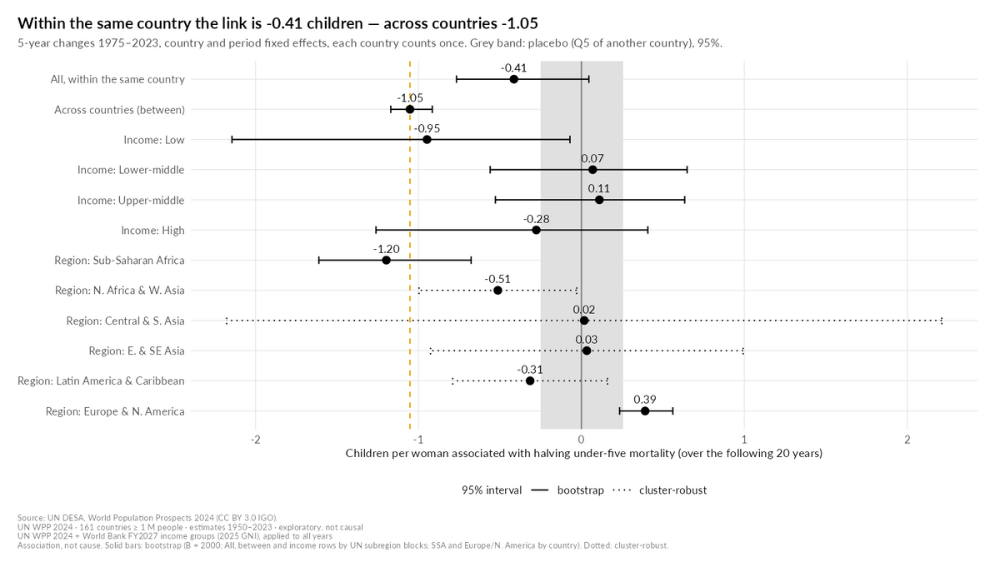

**`figures/review/q1/q1_12_comparacion_modelos.png`** (figura de revisión, no final)

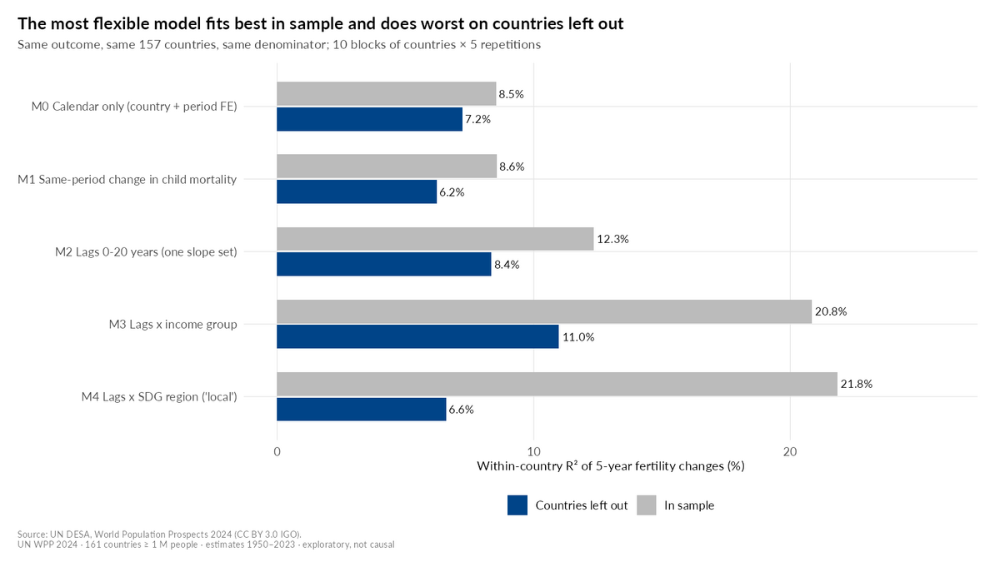

**`figures/review/q1/q1_13_placebo_compensacion.png`** (figura de revisión, no final)

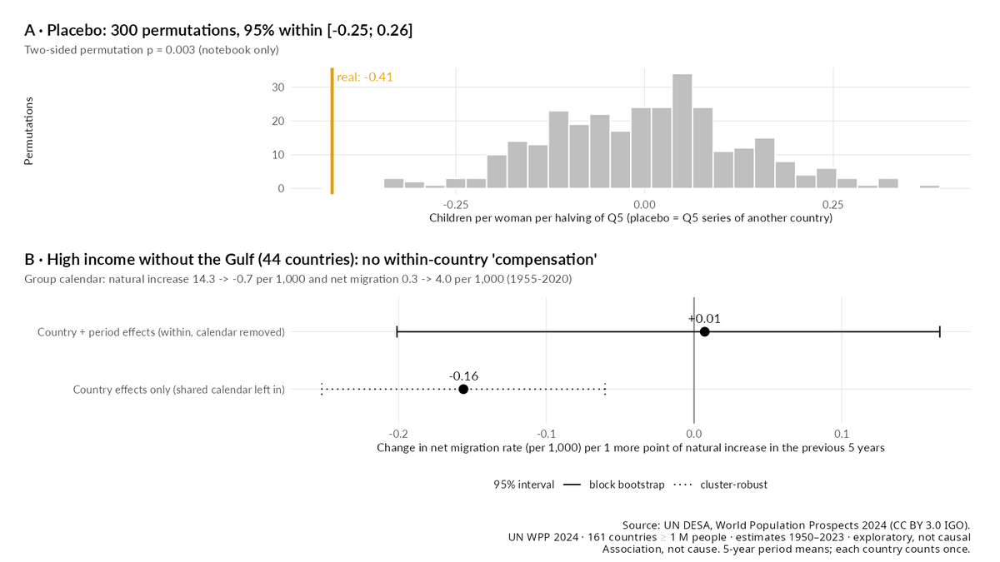

In [67]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_11_panel_forest", "q1_12_comparacion_modelos", "q1_13_placebo_compensacion"))

#### Lectura de resultados · §7 Panel en cambios quinquenales: dentro del país vs entre países (sección 7)

*Texto de `docs/resultados_q1.md` §7 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Medias quinquenales 1950–54 … 2020–23; ΔTFR sobre Δlog Q5 con rezagos 0–20 años, efectos fijos de país (tendencia propia) y de periodo (calendario común), EE agrupados por país (N = 1 610, 161 países, cambios 1975–2023). La suma de rezagos × ln 0,5 = hijos asociados a la mitad de Q5. Comparamos con la pendiente entre países (medias 1950–2023), placebos y heterogeneidad.

| Estimación (hijos por mujer por mitad de Q5) | Valor | IC bloques | EE por país (cluster) | iid | Clave |
|---|---|---|---|---|---|
| **Dentro del mismo país** | **−0,41** | **[−0,77; 0,05]** | [−0,71; −0,12] | [−0,70; −0,14] | `panel_within_halfq5` |
| **Entre países** | **−1,05** | [−1,17; −0,92] | — | [−1,12; −0,99] | `panel_between_halfq5` |
| Razón entre / dentro | 2,5 | inestable ([−9; 18]; iid [1,5; 7,2]) | — | — | `panel_ratio_between_within` |
| Dentro / entre ("less than half") | 0,39 | **[−0,05; 0,73]** | — | [0,13; 0,66] | `panel_within_over_between` |
| Ingreso bajo (25) | **−0,95** | [−2,14; −0,07] | [−1,46; −0,43] | — | `panel_low_income_halfq5` |
| Medio-bajo (41) / medio-alto (44) / alto (50) | +0,07 / +0,11 / −0,28 | [−0,56; 0,65] / [−0,53; 0,63] / [−1,26; 0,41] | — | — | `panel_lowmid/upmid/high_halfq5` |
| África subsahariana (44) | **−1,20** | (bootstrap de países [−1,61; −0,68]) | [−1,65; −0,74] | — | `panel_ssa_halfq5` |
| **Europa y Norteamérica (38)** | **+0,39** | (bootstrap de países [0,23; 0,56]) | [0,23; 0,55] | — | `panel_eurna_halfq5` |
| Otras regiones: N. África y Asia occ. / Asia c. y merid. / Asia or. y sudor. / LAC | −0,51 / +0,02 / +0,03 / −0,31 | — | [−1,00; −0,03] / [−2,18; 2,21] / [−0,93; 0,99] / [−0,79; 0,16] | — | parquet |

| Validación | Resultado | Clave |
|---|---|---|
| Placebo (Q5 de otro país, 300 permutaciones) | 95 % en [−0,25; 0,26] (unidades de hijos) vs real −0,41; p = 0,003 | `panel_placebo_lo/hi` |
| Adelanto (Δlog Q5 del quinquenio siguiente) | 0,28 (EE 0,16; p = 0,08) | `panel_lead` |
| Sentido directo vs inverso (DE estandarizadas, rezagos 5–20) | 0,28 vs 0,22 → co-movimiento en ambos sentidos | `panel_forward_sd`, `panel_reverse_sd` |
| Sensibilidades | dejar un país fuera −0,47 a −0,37; 237 países −0,37; sin 2020–23 −0,45; diferencia larga −0,46; con ΔCNMR −0,42; **ponderado por población +0,08** | `sens_note` |
| Heterogeneidad | Cochran Q ingreso I² = 0,69; región I² = 0,91; Wald χ²(3) = 21,1 | `panel_i2_income`, `panel_i2_region` |
| Comparación honesta (157 países, mismo denominador, países fuera de muestra) | R² dentro: M0 calendario 8,5 % → 7,2 % fuera; M2 rezagos 12,3 % → 8,4 %; M3 × ingreso 20,8 % → **11,0 %**; M4 × región 21,8 % → **6,6 %** | `r2_in_m*`, `r2_oos_m*` |
| Migración en la varianza del crecimiento | entre países 0,33 [−0,02; 0,58] (sin Golfo 0,07); dentro 0,85 [0,74; 0,92] (sin Golfo 0,79) | `mig_share_*` |
| **"Compensación" migratoria (ingreso alto sin Golfo, 44 países; H16)** | CNMR sobre saldo natural del quinquenio anterior, FE país + periodo: **+0,01** [IC bloques −0,20; 0,17]; con solo FE de país (calendario dentro): −0,16 [−0,25; −0,06] | `mig_hi_within_slope`, `mig_hi_countryfe_slope` |

Figuras: `q1_11_panel_forest.png`, `q1_12_comparacion_modelos.png`, `q1_13_placebo_compensacion.png`.

**Lectura de resultados.**
- Comparando cada país consigo mismo, la asociación fecundidad–mortalidad infantil es 2,5 veces más pequeña que la que se ve entre países (−0,41 vs −1,05) y queda fuera de la banda del placebo. H15 se confirma **con la regla preinscrita** (IC con EE por país excluye 0; < 2/3 de la pendiente entre países; fuera del placebo). **Matiz importante:** con el IC por bloques de subregión, el que exige el plan para pantalla, el intervalo dentro del país llega a +0,05. En el vídeo: la cifra sin intervalo o con el IC por bloques rotulado; nunca decir que "excluye el cero".
- "Less than half" (voz) se apoya en la estimación puntual: dentro / entre = 0,39; con bloques de subregión el intervalo de esa fracción es [−0,05; 0,73], así que la frase es frágil a qué regiones entran (iid [0,13; 0,66]). Alternativa más segura: *"smaller than what comparing countries suggests"*.
- Es co-movimiento, no efecto: el adelanto casi iguala a los rezagos (0,28, p = 0,08) y el sentido inverso es casi igual de fuerte (0,22 vs 0,28 DE).
- La relación es clara en África subsahariana (−1,20) y en ingreso bajo (−0,95). En **Europa y Norteamérica va al revés (+0,39)**: allí, en 1975–2023, la mortalidad infantil siguió bajando mientras la fecundidad se recuperaba en algunos periodos. La frase del storyboard *"not detected in Europe & N. America"* es inexacta: debe decir *"reversed in Europe & N. America"*.
- Ponderar por población cambia el signo (+0,08): China e India dominan. "Cada país cuenta una vez" es una decisión que hay que declarar.
- El modelo más flexible (pendientes por región) es el que mejor ajusta dentro de la muestra (21,8 %) y el peor para países nuevos (6,6 %): receta de la "comparación honesta".
- H16: dentro del mismo país de ingreso alto, un saldo natural menor **no** va con más migración (+0,01, IC que contiene 0). La "compensación" (−0,16) aparece solo si se deja dentro el calendario común: es contabilidad del grupo, no relación país a país.

### Q1 · §8 Migración: memoria corta y paradoja tipo Simpson con el ingreso

*Pre-specified (H4, H5) · Exploratory (H4a, H21)* · `R/02_q1_palancas.R` líneas 1952–2094

In [68]:
# =============================================================================
# 8. Migración: memoria corta y paradoja tipo Simpson con el ingreso
# =============================================================================
# QUÉ: compara cuánto se parece la migración de un país en décadas
#      consecutivas frente a fecundidad y vida, y si su correlación mundial
#      con la mortalidad infantil sobrevive dentro de cada grupo de ingreso.
# POR QUÉ: sustituye la frase "no memory" (v1) por una medida que un
#      demógrafo aceptaría y evita leer una diferencia de ingreso como vínculo.
seccion("8. Migración: memoria y Simpson")

decadas <- function(df, tope = 2010) {
  df |> mutate(decada = pmin(10 * (Time %/% 10), tope)) |> group_by(ISO3_code, subregion, decada) |>
    summarise(across(c(CNMR, TFR, LEx), mean), .groups = "drop")
}
memoria <- function(dec, version) {
  ds <- sort(unique(dec$decada))
  bind_rows(lapply(c("CNMR", "TFR", "LEx"), function(v) {
    w <- dec |> select(ISO3_code, decada, all_of(v)) |> pivot_wider(names_from = decada, values_from = all_of(v))
    bind_rows(lapply(seq_len(length(ds) - 1), function(j) {
      a <- w[[as.character(ds[j])]]; b <- w[[as.character(ds[j + 1])]]
      tibble(variable = v, version = version, decada_a = ds[j], decada_b = ds[j + 1],
             r_pearson = cor(a, b), r_spearman = cor(a, b, method = "spearman"), n = sum(complete.cases(a, b)))
    }))
  }))
}
dec_main <- decadas(est1m, 2010)
mem <- bind_rows(memoria(dec_main, "2010s = 2010-2023"), memoria(decadas(est1m, 2020), "2010s = 2010-2019; 2020-2023 separate"))
print(mem |> filter(version == "2010s = 2010-2023") |> select(variable, decada_a, r_pearson) |>
        pivot_wider(names_from = variable, values_from = r_pearson) |> mutate(across(where(is.numeric), \(x) round(x, 2))))
mm <- mem |> filter(version == "2010s = 2010-2023")
r_cn <- mm$r_pearson[mm$variable == "CNMR"]; r_tl <- mm$r_pearson[mm$variable %in% c("TFR", "LEx")]
w_cn <- dec_main |> select(ISO3_code, subregion, decada, CNMR) |> pivot_wider(names_from = decada, values_from = CNMR)
f_r0010 <- function(d) cor(d$`2000`, d$`2010`)
bb_r0010 <- bootstrap_bloques(w_cn, f_r0010, B = B_Q1, semilla = SEM)
bi_r0010 <- bootstrap_bloques(w_cn, f_r0010, bloque = NULL, B = B_Q1, semilla = SEM)
signo <- sign(w_cn$`2000`) == sign(w_cn$`2010`)
w_sig <- ic_wilson(sum(signo), length(signo), escala = 100)
y5023 <- est1m |> filter(Time %in% c(1950, 2023)) |> select(ISO3_code, subregion, Time, CNMR, TFR) |>
  pivot_wider(names_from = Time, values_from = c(CNMR, TFR))
f_r5023 <- function(d) cor(d$CNMR_1950, d$CNMR_2023)
bb_r5023 <- bootstrap_bloques(y5023, f_r5023, B = B_NB, semilla = SEM)
r_tfr5023 <- cor(y5023$TFR_1950, y5023$TFR_2023)
# beta de "convergencia" de la CNMR y su placebo (H4: beta = -1 es lo que da el ruido)
bx <- est1m |> group_by(ISO3_code) |> summarise(x0 = mean(CNMR[Time %in% 1950:1954]), x1 = mean(CNMR[Time %in% 2019:2023]))
beta_cn <- unname(coef(lm(I(x1 - x0) ~ x0, bx))[2])
set.seed(SEM)
beta_plac <- replicate(1000, unname(coef(lm(I(sample(bx$x1) - bx$x0) ~ bx$x0))[2]))
informar("Memoria: CNMR entre décadas %.2f-%.2f (2000s->2010s %.2f [bloques %.2f; %.2f]) vs TFR/LEx mínimo %.2f; mantienen signo 2000s->2010s %.1f %% [%.1f; %.1f]",
         min(r_cn), max(r_cn), bb_r0010$valor, bb_r0010$ci_low, bb_r0010$ci_high, min(r_tl), w_sig$valor, w_sig$ci_low, w_sig$ci_high)
informar("CNMR 1950 vs 2023: r = %.2f (TFR %.2f) | beta CNMR 1950-54 -> 2019-23 = %.2f (placebo media %.2f, 95 %% [%.2f; %.2f]); DE %.1f -> %.1f",
         bb_r5023$valor, r_tfr5023, beta_cn, mean(beta_plac), quantile(beta_plac, 0.025), quantile(beta_plac, 0.975), sd(bx$x0), sd(bx$x1))


8. Migración: memoria y Simpson


# A tibble: 6 × 4
  decada_a  CNMR   TFR   LEx
     <dbl> <dbl> <dbl> <dbl>
1     1950  0.68  0.97  0.97
2     1960  0.66  0.95  0.96
3     1970  0.6   0.96  0.96
4     1980  0.32  0.96  0.96
5     1990  0.47  0.98  0.95
6     2000  0.69  0.97  0.98


Memoria: CNMR entre décadas 0.32-0.69 (2000s->2010s 0.69 [bloques 0.52; 0.73]) vs TFR/LEx mínimo 0.95; mantienen signo 2000s->2010s 76.4 % [69.3; 82.3]


CNMR 1950 vs 2023: r = 0.14 (TFR 0.52) | beta CNMR 1950-54 -> 2019-23 = -0.90 (placebo media -1.00, 95 % [-1.12; -0.88]); DE 6.8 -> 5.3


In [69]:
# 8.2 Simpson: Q5 y migración, mundo vs dentro de cada grupo de ingreso (2021-2023)
v2123 <- resumen_ventana(2021:2023, c("Q5", "CNMR", "TFR"), muestra = "1m")
rho_s <- function(x, y) cor(x, y, method = "spearman")
simp <- list()
for (par in list(c("Q5", "CNMR"), c("TFR", "CNMR"))) {
  f_rho <- function(d) rho_s(d[[par[1]]], d[[par[2]]])
  for (g in c("World", NIVELES_INGRESO)) {
    d_g <- if (g == "World") v2123 else v2123 |> filter(ingreso == g)
    bb <- suppressWarnings(bootstrap_bloques(d_g, f_rho, B = B_Q1, semilla = SEM))
    simp[[length(simp) + 1]] <- tibble(par = paste(par, collapse = "-"), grupo = g, rho = bb$valor, ci_lo = bb$ci_low, ci_hi = bb$ci_high,
                                       n = nrow(d_g), n_bloques = bb$n_bloques, bb = list(bb))
  }
}
simp <- bind_rows(simp)
vc <- v2123 |> filter(ingreso != "Not classified") |> mutate(ingreso = droplevels(ingreso))
rho_parcial <- cor(resid(lm(rank(Q5) ~ ingreso, vc)), resid(lm(rank(CNMR) ~ ingreso, vc)))
print(simp |> select(-bb) |> mutate(across(where(is.numeric), \(x) round(x, 3))))
informar("Spearman parcial Q5-CNMR dado el ingreso: %.2f", rho_parcial)
# H5 (v1): TFR-CNMR en ingreso alto, 2023 (>= 1 M y los 237)
hi23 <- corte_anio(2023, "1m") |> filter(ingreso == "High income")
hi23_all <- corte_anio(2023, "completa") |> filter(ingreso == "High income")
h5_bca <- bootstrap_bca(hi23, function(d) rho_s(d$TFR, d$CNMR), B = B_Q1, semilla = SEM)
h5_all_p <- cor(hi23_all$TFR, hi23_all$CNMR); h5_all_s <- rho_s(hi23_all$TFR, hi23_all$CNMR)
informar("H5: Spearman TFR-CNMR 2023, ingreso alto >= 1 M (n=%d) = %.2f [BCa %.2f; %.2f]; con los %d de ingreso alto: Pearson %.2f, Spearman %.2f",
         nrow(hi23), h5_bca$valor, h5_bca$ci_low, h5_bca$ci_high, nrow(hi23_all), h5_all_p, h5_all_s)

F_MEM <- "161 countries >= 1 M, decade means of annual estimates (1950s ... 2010s; 2010s = 2010-2023)"
anotar("r_cnmr_decades_recent", value = round(bb_r0010$valor, 4), unit = "Pearson r", fmt = "0.00", ic = bb_r0010, ic_iid = bi_r0010,
       def = "Correlation across countries between mean net migration rate in the 2000s and in the 2010s (2010-2023)", filter = F_MEM,
       source_cell = "Q1-8.1", used_in = c("slide2.build4"), status = "exploratory", hypothesis_id = "H4a",
       n = nrow(w_cn), universe = UNIVERSO_1M)
anotar("r_cnmr_decades_min", value = round(min(r_cn), 4), unit = "Pearson r", fmt = "0.00", method = "descriptive",
       def = "Lowest correlation of the net migration rate between consecutive decades (6 pairs)", filter = F_MEM,
       source_cell = "Q1-8.1", used_in = c("slide2.build4"),
       sens_note = paste(sprintf("%ds->%ds %.2f", mm$decada_a[mm$variable == "CNMR"], mm$decada_b[mm$variable == "CNMR"], r_cn), collapse = "; "),
       status = "exploratory", hypothesis_id = "H4a", n = nrow(w_cn), universe = UNIVERSO_1M)
anotar("r_cnmr_decades_max", value = round(max(r_cn), 4), unit = "Pearson r", fmt = "0.00", method = "descriptive",
       def = "Highest correlation of the net migration rate between consecutive decades (6 pairs)", filter = F_MEM,
       source_cell = "Q1-8.1", used_in = c("slide2.build4"), status = "exploratory", hypothesis_id = "H4a",
       n = nrow(w_cn), universe = UNIVERSO_1M)
anotar("r_tfr_decades_min", value = round(min(r_tl), 4), unit = "Pearson r", fmt = "0.00", method = "descriptive",
       def = "Lowest correlation between consecutive decades for fertility (TFR) and life expectancy (6 pairs each)", filter = F_MEM,
       source_cell = "Q1-8.1", used_in = c("slide2.build4"),
       sens_note = sprintf("TFR min %.2f; LEx min %.2f", min(mm$r_pearson[mm$variable == "TFR"]), min(mm$r_pearson[mm$variable == "LEx"])),
       status = "exploratory", hypothesis_id = "H4a", n = nrow(w_cn), universe = UNIVERSO_1M)
anotar("share_cnmr_sign_kept", value = round(w_sig$valor, 4), unit = "%", fmt = "0", ic = w_sig,
       def = "Share of countries whose mean net migration rate has the same sign in the 2000s and the 2010s (2010-2023)", filter = F_MEM,
       source_cell = "Q1-8.1", used_in = c("notebook.T6"), status = "exploratory", hypothesis_id = "H4a", universe = UNIVERSO_1M)
anotar("r_cnmr_1950_2023", value = round(bb_r5023$valor, 4), unit = "Pearson r", fmt = "0.00", ic = bb_r5023,
       def = "Correlation across countries between the net migration rate in 1950 and in 2023 (single years, 73 years apart)",
       filter = "161 countries >= 1 M, estimates 1950 and 2023", source_cell = "Q1-8.1", used_in = c("notebook.T6"),
       sens_note = sprintf("TFR 1950 vs 2023: %.2f; beta(CNMR 1950-54 -> 2019-23) = %.2f vs placebo %.2f [%.2f; %.2f]", r_tfr5023, beta_cn,
                           mean(beta_plac), quantile(beta_plac, 0.025), quantile(beta_plac, 0.975)),
       status = "exploratory", hypothesis_id = "H4", n = nrow(y5023), universe = UNIVERSO_1M)
claves_simp <- c(World = "rho_q5_cnmr_world", "Low income" = "rho_q5_cnmr_within_low", "Lower middle income" = "rho_q5_cnmr_within_lowmid",
                 "Upper middle income" = "rho_q5_cnmr_within_upmid", "High income" = "rho_q5_cnmr_within_high")
for (g in names(claves_simp)) {
  x <- simp |> filter(par == "Q5-CNMR", grupo == g)
  anotar(claves_simp[[g]], value = round(x$rho, 4), unit = "Spearman rho", fmt = "0.00", ic = x$bb[[1]],
         def = sprintf("Spearman correlation across countries between Q5 and the net migration rate (2021-2023 means), %s", ifelse(g == "World", "all countries", paste("within today's", g))),
         filter = sprintf("%s; 2021-2023 means of annual estimates", ifelse(g == "World", "161 countries >= 1 M", paste(g, "countries >= 1 M"))),
         source_cell = "Q1-8.2", used_in = c("notebook.T6"),
         sens_note = if (g == "World") sprintf("partial Spearman given income group: %.2f", rho_parcial) else sprintf("%d UN subregions as blocks", x$n_bloques),
         status = "exploratory", hypothesis_id = "H21", n = x$n, universe = UNIVERSO_1M)
}
fig_mem <- mem |> mutate(par = paste0(decada_a, "s→", decada_b, "s"),
                         variable = recode(variable, CNMR = "Net migration rate", TFR = "Fertility (TFR)", LEx = "Life expectancy"))
p14 <- ggplot(fig_mem |> filter(version == "2010s = 2010-2023"), aes(par, r_pearson, colour = variable, group = variable)) +
  geom_line(linewidth = 1) + geom_point(size = 2.8) +
  geom_text(data = \(d) d |> filter(variable == "Net migration rate"), aes(label = sprintf("%.2f", r_pearson)), vjust = -0.9, size = 3.2, show.legend = FALSE) +
  scale_colour_manual(values = c("Net migration rate" = COLOR_MIGRACION, "Fertility (TFR)" = COLOR_NACIMIENTOS, "Life expectancy" = COLOR_DEFUNCIONES), name = NULL) +
  scale_y_continuous(limits = c(0, 1.05)) +
  labs(x = "Consecutive decades", y = "Correlation across countries (Pearson)",
       title = "Migration has a short memory: decade-to-decade similarity well below fertility and life expectancy",
       subtitle = sprintf("Fertility and life expectancy: >= %.2f in every pair. Same sign of net migration in the 2000s and 2010s: %.0f%% of countries.\n1950 vs 2023 (single years): migration %.2f, fertility %.2f.",
                          min(r_tl), w_sig$valor, bb_r5023$valor, r_tfr5023),
       caption = pie_q1(PIE_MODELOS, badge("PIE-6"), "2010s = 2010–2023 (sensitivity with 2020–2023 apart in the parquet table).")) + tema_q1(12)
guardar_q1(p14, "q1_14_memoria_migracion")
fig_simp <- simp |> mutate(grupo = factor(ifelse(grupo == "World", "World (all 161)", ETIQUETAS_INGRESO_CORTAS_EN[grupo]),
                                          levels = rev(c("World (all 161)", ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO]))),
                           par = recode(par, `Q5-CNMR` = "Child mortality vs net migration", `TFR-CNMR` = "Fertility vs net migration"))
p15 <- ggplot(fig_simp, aes(rho, grupo)) + geom_vline(xintercept = 0, colour = COL_GRIS) +
  geom_errorbar(aes(xmin = ci_lo, xmax = ci_hi), width = 0.25, orientation = "y") + geom_point(size = 2.8) +
  geom_text(aes(label = sprintf("%.2f", rho)), vjust = -0.9, size = 3.2) + facet_wrap(~par) +
  labs(x = "Spearman correlation across countries (2021–2023 means)", y = NULL,
       title = "A worldwide correlation can be an income gap in disguise",
       subtitle = sprintf("Child mortality and net migration: %.2f worldwide, near zero inside each income group (partial, given income: %.2f)",
                          simp$rho[simp$par == "Q5-CNMR" & simp$grupo == "World"], rho_parcial),
       caption = pie_q1(badge("PIE-3", "PIE-4"), "Bars: 95% block bootstrap by UN subregion.")) + tema_q1(12)
guardar_q1(p15, "q1_15_simpson_ingreso")

# A tibble: 10 × 7
   par      grupo                  rho  ci_lo  ci_hi     n n_bloques
   <chr>    <chr>                <dbl>  <dbl>  <dbl> <dbl>     <dbl>
 1 Q5-CNMR  World               -0.451 -0.633 -0.222   161        20
 2 Q5-CNMR  Low income           0.075 -0.555  0.434    25         7
 3 Q5-CNMR  Lower middle income  0.162 -0.292  0.441    41        13
 4 Q5-CNMR  Upper middle income  0.172 -0.205  0.421    44        14
 5 Q5-CNMR  High income         -0.075 -0.727  0.452    50        12
 6 TFR-CNMR World               -0.286 -0.476 -0.119   161        20
 7 TFR-CNMR Low income          -0.101 -0.573  0.315    25         7
 8 TFR-CNMR Lower middle income  0.503  0.135  0.668    41        13
 9 TFR-CNMR Upper middle income  0.336 -0.015  0.56     44        14
10 TFR-CNMR High income          0.105 -0.355  0.399    50        12


Spearman parcial Q5-CNMR dado el ingreso: 0.08


H5: Spearman TFR-CNMR 2023, ingreso alto >= 1 M (n=50) = 0.10 [BCa -0.18; 0.43]; con los 85 de ingreso alto: Pearson -0.36, Spearman -0.24


**`figures/review/q1/q1_14_memoria_migracion.png`** (figura de revisión, no final)

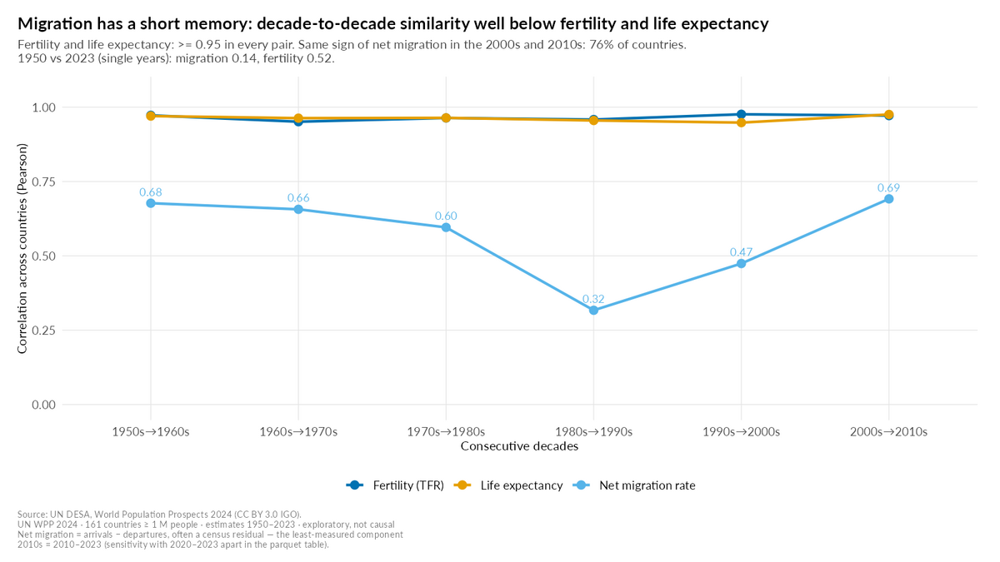

**`figures/review/q1/q1_15_simpson_ingreso.png`** (figura de revisión, no final)

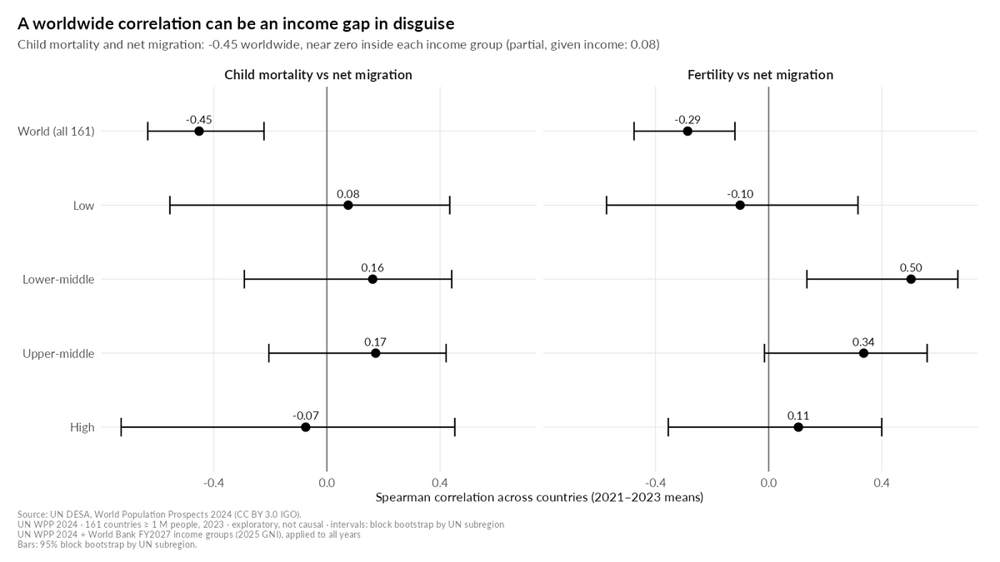

In [70]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_14_memoria_migracion", "q1_15_simpson_ingreso"))

#### Lectura de resultados · §8 Migración: memoria corta y paradoja tipo Simpson (sección 8)

*Texto de `docs/resultados_q1.md` §8 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Correlación entre medias de décadas consecutivas (1950s … 2010s = 2010–23) de CNMR, TFR y LEx; ρ de la CNMR 1950 vs 2023 y β de "convergencia" con placebo (H4); Spearman Q5–CNMR y TFR–CNMR (promedios 2021–23) en el mundo y dentro de cada grupo de ingreso.

| Década → década | 1950s→60s | 60s→70s | 70s→80s | 80s→90s | 90s→2000s | 2000s→2010s |
|---|---|---|---|---|---|---|
| CNMR | 0,68 | 0,66 | 0,60 | **0,32** | 0,47 | **0,69** [IC 0,52; 0,73] |
| TFR | 0,97 | 0,95 | 0,96 | 0,96 | 0,98 | 0,97 |
| LEx | 0,97 | 0,96 | 0,96 | 0,96 | 0,95 | 0,98 |

| Resultado | Valor | Clave |
|---|---|---|
| Mantienen el signo de la CNMR 2000s → 2010s | 76,4 % (Wilson [69,3; 82,3]) | `share_cnmr_sign_kept` |
| CNMR 1950 vs 2023 (años sueltos) | 0,14 [−0,07; 0,21] (TFR 0,52) | `r_cnmr_1950_2023` |
| β CNMR 1950–54 → 2019–23 (H4) | −0,90; placebo −1,00 [−1,12; −0,88] | `sens_note` |
| ρ(Q5, CNMR) mundo | **−0,45** [−0,63; −0,22] | `rho_q5_cnmr_world` |
| … dentro de bajo / medio-bajo / medio-alto / alto | +0,08 / +0,16 / +0,17 / −0,07 (todos los IC cruzan 0); parcial dado el ingreso +0,08 | `rho_q5_cnmr_within_*` |
| ρ(TFR, CNMR) mundo / medio-bajo | −0,29 [−0,48; −0,12] / **+0,50** [0,14; 0,67] | parquet |
| H5 (TFR–CNMR en ingreso alto, 2023) | ≥ 1 M (50): +0,10 [BCa −0,18; 0,43]; con los 85: Pearson −0,36 | log |

Figuras: `q1_14_memoria_migracion.png`, `q1_15_simpson_ingreso.png`.

**Lectura de resultados.** La migración de un país se parece a la de la década anterior bastante menos que su fecundidad o su esperanza de vida (0,32–0,69 frente a ≥ 0,95): memoria corta, no "sin memoria" (H4a ✔). El β ≈ −1 de la v1 es lo que da el ruido puro (placebo −1,00): H4 se rechaza como evidencia. La correlación mundial entre mortalidad infantil y migración (−0,45) desaparece dentro de cada grupo de ingreso (H21 ✔): es una diferencia de ingreso disfrazada de vínculo. H5 se rechaza: el −0,36 lo generan los microestados.

### Q1 · §9 Incertidumbre oficial de la ONU (OtherVariants): EAU y dirección 2050

*Exploratory (H22) · UN medium projection = escenario* · `R/02_q1_palancas.R` líneas 2095–2234

In [71]:
# =============================================================================
# 9. Incertidumbre oficial de la ONU (OtherVariants): EAU y dirección 2050
# =============================================================================
# QUÉ: lee los intervalos de predicción 80/95 % de la ONU (solo columnas de la
#      lista blanca, con test de monotonía) y arma el fan chart de EAU; cuenta
#      en cuántos países el IP 95 % de 2050 incluye crecer y decrecer y en
#      cuántos el IP 80 % de la migración neta 2050 incluye el cero.
# POR QUÉ: la incertidumbre se ve una vez en el vídeo donde más importa: la
#      migración, la palanca peor medida (P2/P3 como nota).
seccion("9. OtherVariants: EAU y dirección 2050")

ov <- data.table::fread(RUTA_WPP_OTHERVARIANTS, select = c("LocID", "ISO3_code", "Variant", "Time", "TPopulation1July", "CNMR"),
                        na.strings = "", encoding = "UTF-8", showProgress = FALSE) |> as.data.frame()
stopifnot(all(c("TPopulation1July", "CNMR") %in% COLUMNAS_PI_VALIDAS))   # solo columnas de la lista blanca
ov <- ov |> filter(!is.na(ISO3_code), ISO3_code != "", Time <= ANIO_MAX_VALIDO)   # 2101 se descarta (plan §3)
VAR_PI <- c("Lower 95 PI" = "l95", "Lower 80 PI" = "l80", "Median PI" = "mediana", "Upper 80 PI" = "u80", "Upper 95 PI" = "u95")
pi_w <- ov |> filter(Variant %in% names(VAR_PI)) |> mutate(v = VAR_PI[Variant]) |>
  select(ISO3_code, Time, v, TPopulation1July, CNMR) |>
  pivot_wider(names_from = v, values_from = c(TPopulation1July, CNMR))
mono <- function(p) {
  cc <- function(s) pi_w[[paste0(p, "_", s)]]
  cc("l95") <= cc("l80") + 1e-9 & cc("l80") <= cc("mediana") + 1e-9 & cc("mediana") <= cc("u80") + 1e-9 & cc("u80") <= cc("u95") + 1e-9
}
mono_pop <- mono("TPopulation1July"); mono_cn <- mono("CNMR")
informar("Monotonía L95 <= L80 <= Mediana <= U80 <= U95: población %d/%d filas, CNMR %d/%d filas (países, %d-%d)",
         sum(mono_pop, na.rm = TRUE), sum(!is.na(mono_pop)), sum(mono_cn, na.rm = TRUE), sum(!is.na(mono_cn)), min(pi_w$Time), max(pi_w$Time))
stopifnot(all(mono_pop, na.rm = TRUE), all(mono_cn, na.rm = TRUE))
med_are <- datos_paises |> filter(ISO3_code == "ARE") |> select(Time, TPopulation1July, CNMR, TFR, PopGrowthRate)
pi_are <- pi_w |> filter(ISO3_code == "ARE")
zm_are <- ov |> filter(ISO3_code == "ARE", Variant == "Zero migration") |> select(Time, zm = TPopulation1July)
are50 <- pi_are |> filter(Time == 2050); are2100 <- pi_are |> filter(Time == 2100)
m50 <- med_are$TPopulation1July[med_are$Time == 2050] / 1e3; m2100 <- med_are$TPopulation1July[med_are$Time == 2100] / 1e3
dif_med <- max(abs(pi_are$TPopulation1July_mediana - med_are$TPopulation1July[match(pi_are$Time, med_are$Time)]) /
                 med_are$TPopulation1July[match(pi_are$Time, med_are$Time)], na.rm = TRUE)
informar("EAU 2050: Medium %.2f M; IP 80 [%.2f; %.2f]; IP 95 [%.2f; %.2f]; migración cero %.2f M | 2100: %.2f M [IP 95 %.2f; %.2f] | dif. máx. Median PI vs Medium %.2e",
         m50, are50$TPopulation1July_l80 / 1e3, are50$TPopulation1July_u80 / 1e3, are50$TPopulation1July_l95 / 1e3, are50$TPopulation1July_u95 / 1e3,
         zm_are$zm[zm_are$Time == 2050] / 1e3, m2100, are2100$TPopulation1July_l95 / 1e3, are2100$TPopulation1July_u95 / 1e3, dif_med)
are23 <- med_are |> filter(Time == 2023)
# Dirección 2050 en los 161 países >= 1 M
dir50 <- pi_w |> filter(Time == 2050, ISO3_code %in% iso_muestra_1m) |>
  left_join(pop23, by = "ISO3_code") |>
  left_join(c23 |> select(ISO3_code, Location), by = "ISO3_code") |>
  transmute(ISO3_code, Location, pop2023 = pop_2023_miles, l95 = TPopulation1July_l95, l80 = TPopulation1July_l80,
            mediana = TPopulation1July_mediana, u80 = TPopulation1July_u80, u95 = TPopulation1July_u95,
            dir95 = case_when(l95 > pop2023 ~ "surely up", u95 < pop2023 ~ "surely down", TRUE ~ "uncertain"),
            dir80 = case_when(l80 > pop2023 ~ "surely up", u80 < pop2023 ~ "surely down", TRUE ~ "uncertain"),
            cnmr_l80 = CNMR_l80, cnmr_u80 = CNMR_u80, cnmr_l95 = CNMR_l95, cnmr_u95 = CNMR_u95,
            signo_cnmr_incierto = cnmr_l80 < 0 & cnmr_u80 > 0)
stopifnot(nrow(dir50) == N_PAISES_1M)
n_unc95 <- sum(dir50$dir95 == "uncertain"); n_unc80 <- sum(dir50$dir80 == "uncertain")
n_sign80 <- sum(dir50$signo_cnmr_incierto); n_sign95 <- sum(dir50$cnmr_l95 < 0 & dir50$cnmr_u95 > 0)
informar("Dirección 2050 (IP 95): %s | (IP 80): %s | signo de la CNMR 2050 incierto: IP 80 %d, IP 95 %d de %d",
         paste(names(table(dir50$dir95)), table(dir50$dir95), collapse = ", "), paste(names(table(dir50$dir80)), table(dir50$dir80), collapse = ", "),
         n_sign80, n_sign95, nrow(dir50))
F_PI <- "WPP 2024 OtherVariants (Median / Lower / Upper 80 and 95 PI); UN medium projection"
anotar("pop_are_2050", value = round(m50, 4), unit = "million", fmt = "0.0", method = "un_pi",
       def = "United Arab Emirates population on 1 July 2050, UN medium projection", filter = "United Arab Emirates, 2050 (UN medium projection)",
       source_cell = "Q1-9.1", used_in = c("slide1.build5", "narration.slide1"),
       pi80_low = round(are50$TPopulation1July_l80 / 1e3, 3), pi80_high = round(are50$TPopulation1July_u80 / 1e3, 3),
       pi95_low = round(are50$TPopulation1July_l95 / 1e3, 3), pi95_high = round(are50$TPopulation1July_u95 / 1e3, 3),
       variant_source = F_PI, sens_note = sprintf("Zero-migration scenario (not an interval): %.1f M", zm_are$zm[zm_are$Time == 2050] / 1e3),
       status = "descriptive", n = 1, universe = "United Arab Emirates")
anotar("pop_are_2050_pi95_low", value = round(are50$TPopulation1July_l95 / 1e3, 4), unit = "million", fmt = "0.0", method = "un_pi",
       def = "Lower limit of the UN 95% prediction interval of the UAE population in 2050", filter = "United Arab Emirates, 2050",
       source_cell = "Q1-9.1", used_in = c("slide1.build5", "narration.slide1"), variant_source = F_PI, status = "descriptive",
       say = "nine", n = 1, universe = "United Arab Emirates")
anotar("pop_are_2050_pi95_high", value = round(are50$TPopulation1July_u95 / 1e3, 4), unit = "million", fmt = "0.0", method = "un_pi",
       def = "Upper limit of the UN 95% prediction interval of the UAE population in 2050", filter = "United Arab Emirates, 2050",
       source_cell = "Q1-9.1", used_in = c("slide1.build5", "narration.slide1"), variant_source = F_PI, status = "descriptive",
       say = "thirty-three", n = 1, universe = "United Arab Emirates")
# Variante "Zero migration" (QA_storyboard §6.8): escenario de la ONU, no un intervalo
anotar("pop_are_2050_zero_mig", value = round(zm_are$zm[zm_are$Time == 2050] / 1e3, 4), unit = "million", fmt = "0.0",
       method = "descriptive",
       def = "United Arab Emirates population on 1 July 2050 in the UN 'Zero migration' variant (a what-if scenario with net migration set to zero from 2024; not a prediction interval)",
       filter = "United Arab Emirates, 2050 (WPP 2024 OtherVariants, Variant = 'Zero migration', TPopulation1July)", source_cell = "Q1-9.1",
       used_in = c("slide1.build5"), variant_source = "WPP 2024 OtherVariants (Zero migration)", status = "descriptive",
       sens_note = sprintf("2100: %.1f M; UN medium 2050: %.1f M", zm_are$zm[zm_are$Time == 2100] / 1e3, m50),
       n = 1, universe = "United Arab Emirates")
anotar("pop_are_2100", value = round(m2100, 4), unit = "million", fmt = "0.0", method = "un_pi",
       def = "United Arab Emirates population in 2100, UN medium projection", filter = "United Arab Emirates, 2100 (UN medium projection)",
       source_cell = "Q1-9.1", used_in = c("notebook.T13"),
       pi80_low = round(are2100$TPopulation1July_l80 / 1e3, 3), pi80_high = round(are2100$TPopulation1July_u80 / 1e3, 3),
       pi95_low = round(are2100$TPopulation1July_l95 / 1e3, 3), pi95_high = round(are2100$TPopulation1July_u95 / 1e3, 3),
       variant_source = F_PI, sens_note = sprintf("Zero-migration scenario: %.1f M", zm_are$zm[zm_are$Time == 2100] / 1e3),
       status = "descriptive", n = 1, universe = "United Arab Emirates")
anotar("cnmr_are_2023", value = round(are23$CNMR, 4), unit = "per 1,000", fmt = "0.0", method = "descriptive",
       def = "UAE net migration rate, 2023 (estimate)", filter = "United Arab Emirates, 2023", source_cell = "Q1-9.1",
       used_in = c("slide1.build5"), status = "descriptive", n = 1, universe = "United Arab Emirates")
anotar("growth_are_2023", value = round(are23$PopGrowthRate, 4), unit = "% per year", fmt = "0.00", method = "descriptive",
       def = "UAE population growth rate, 2023 (estimate)", filter = "United Arab Emirates, 2023", source_cell = "Q1-9.1",
       used_in = c("slide1.build5"), status = "descriptive", n = 1, universe = "United Arab Emirates")
anotar("tfr_are_2023", value = round(are23$TFR, 4), unit = "children per woman", fmt = "0.00", method = "descriptive",
       def = "UAE total fertility rate, 2023 (estimate)", filter = "United Arab Emirates, 2023", source_cell = "Q1-9.1",
       used_in = c("slide1.build5"), status = "descriptive", n = 1, universe = "United Arab Emirates")
# Revisión WPP2022 -> WPP2024 de la población de EAU: dato EXTERNO (no está en los archivos de 2024)
# QUÉ: deja en el registro la cifra de calidad de datos que usa la tarjeta de ética.
# POR QUÉ: la nota "UN revised the UAE's 2023 population by +12 %" no puede
#      calcularse sin el archivo WPP2022 (no descargado); se marca como externa
#      y pendiente de verificación humana, en lugar de teclearla en la diapositiva.
anotar("are_revision_pct", value = 12, unit = "%", fmt = "0", method = "descriptive",
       def = "Revision of the UAE's 2023 population between the 2022 and 2024 UN WPP editions (EXTERNAL figure: not computable from the WPP 2024 files used here)",
       filter = "United Arab Emirates, 2023; WPP2022 vs WPP2024", source_cell = "Q1-9.1 (external)",
       used_in = c("slide1.build5", "slide4.ethics"), status = "descriptive",
       sens_note = "EXTERNAL: taken from docs/04_etica_ASA_aplicada.md item 3 / 07_integracion V11 (UN DESA WPP2024 methodology: Gulf revisions UAE +12%, Kuwait +12%, Qatar +9.7%, Oman +8.7%, Saudi Arabia -10%); must be checked by a person against the WPP2022 file before use",
       n = 1, universe = "United Arab Emirates")
anotar("n_dir_uncertain_2050", value = n_unc95, unit = "countries", fmt = "0", method = "none_census",
       def = "Countries whose UN 95% prediction interval for the 2050 population includes the 2023 population (both growth and decline possible)",
       filter = "161 countries >= 1 M; 2023 estimate vs 2050 UN PI", source_cell = "Q1-9.2", used_in = c("slide1.build5"),
       sens_low = n_unc80, sens_high = n_unc95,
       sens_note = sprintf("80%% PI: %d; 95%% PI: surely down %d, surely up %d", n_unc80, sum(dir50$dir95 == "surely down"), sum(dir50$dir95 == "surely up")),
       variant_source = F_PI, status = "exploratory", hypothesis_id = "H22", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("n_cnmr_sign_uncertain_2050", value = n_sign80, unit = "countries", fmt = "0", method = "none_census",
       def = "Countries whose UN 80% prediction interval for the 2050 net migration rate includes zero (sign unknown)",
       filter = "161 countries >= 1 M; 2050 UN PI", source_cell = "Q1-9.2", used_in = c("slide4.table"),
       sens_note = sprintf("95%% PI includes zero in %d", n_sign95), variant_source = F_PI, status = "descriptive",
       n = N_PAISES_1M, universe = UNIVERSO_1M)
fan <- bind_rows(med_are |> filter(Time <= 2023) |> transmute(Time, serie = "Estimate", pop_millones = TPopulation1July / 1e3),
                 med_are |> filter(Time >= 2023) |> transmute(Time, serie = "UN medium projection", pop_millones = TPopulation1July / 1e3),
                 pi_are |> select(Time, starts_with("TPopulation1July_")) |> pivot_longer(-Time, names_to = "serie", values_to = "pop_millones") |>
                   mutate(serie = sub("TPopulation1July_", "PI ", serie), pop_millones = pop_millones / 1e3),
                 zm_are |> transmute(Time, serie = "Zero migration scenario", pop_millones = zm / 1e3))
fan_w <- pi_are |> mutate(across(starts_with("TPopulation1July_"), \(x) x / 1e3))
p16 <- ggplot() +
  annotate("rect", xmin = 2023.5, xmax = 2100, ymin = -Inf, ymax = Inf, fill = COLOR_PROYECCION_SOMBRA) +
  geom_ribbon(data = fan_w, aes(Time, ymin = TPopulation1July_l95, ymax = TPopulation1July_u95), fill = COLOR_MIGRACION, alpha = 0.25) +
  geom_ribbon(data = fan_w, aes(Time, ymin = TPopulation1July_l80, ymax = TPopulation1July_u80), fill = COLOR_MIGRACION, alpha = 0.45) +
  geom_line(data = fan |> filter(serie == "UN medium projection"), aes(Time, pop_millones), colour = COLOR_NACIMIENTOS, linewidth = 1.1) +
  geom_line(data = fan |> filter(serie == "Zero migration scenario"), aes(Time, pop_millones), colour = COLOR_DEFUNCIONES, linetype = "dashed", linewidth = 0.9) +
  geom_line(data = fan |> filter(serie == "Estimate"), aes(Time, pop_millones), colour = "black", linewidth = 1.1) +
  geom_vline(xintercept = 2023.5, linetype = "dotted") +
  annotate("point", x = 2050, y = m50, size = 3) +
  annotate("text", x = 2050, y = are50$TPopulation1July_u95 / 1e3, label = sprintf("2050: %.1f M\nUN 95%% range %.1f–%.1f M", m50, are50$TPopulation1July_l95 / 1e3, are50$TPopulation1July_u95 / 1e3),
           vjust = -0.3, size = 3.6) +
  annotate("text", x = 2088, y = zm_are$zm[zm_are$Time == 2090] / 1e3, label = "UN zero-migration scenario\n(a what-if, not a forecast)", colour = COLOR_DEFUNCIONES, vjust = -0.5, size = 3.3) +
  labs(x = NULL, y = "Population (million)",
       title = sprintf("Migration is the least certain lever: the UN's 95%% range for the UAE in 2050 runs from %.0f to %.0f million", are50$TPopulation1July_l95 / 1e3, are50$TPopulation1July_u95 / 1e3),
       subtitle = "Black: UN estimates 1950–2023. Blue: UN medium projection with 80% and 95% prediction intervals (shaded: projection, a scenario).",
       caption = pie_q1(badge("PIE-5", "PIE-6"), "Prediction intervals are marginal and not additive across countries.")) + tema_q1(12)
guardar_q1(p16, "q1_16_fan_eau")


9. OtherVariants: EAU y dirección 2050


Monotonía L95 <= L80 <= Mediana <= U80 <= U95: población 18249/18249 filas, CNMR 18249/18249 filas (países, 2024-2100)


EAU 2050: Medium 15.37 M; IP 80 [10.09; 26.09]; IP 95 [8.89; 33.26]; migración cero 12.39 M | 2100: 26.13 M [IP 95 2.32; 77.40] | dif. máx. Median PI vs Medium 5.88e-08


Dirección 2050 (IP 95): surely down 17, surely up 67, uncertain 77 | (IP 80): surely down 26, surely up 88, uncertain 47 | signo de la CNMR 2050 incierto: IP 80 155, IP 95 161 de 161


**`figures/review/q1/q1_16_fan_eau.png`** (figura de revisión, no final)

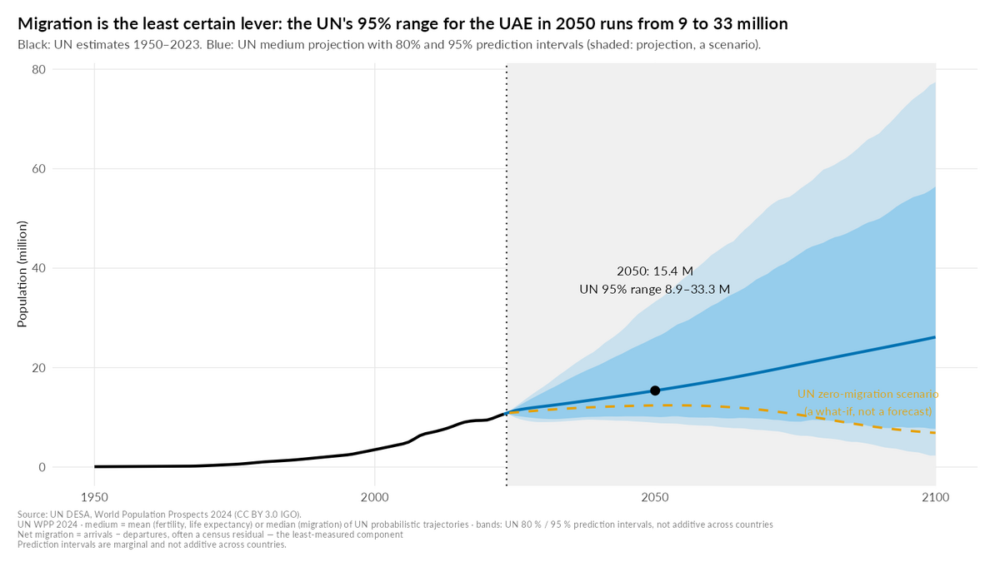

In [72]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_16_fan_eau"))

#### Lectura de resultados · §9 Incertidumbre de la ONU (OtherVariants): EAU y dirección 2050 (sección 9)

*Texto de `docs/resultados_q1.md` §9 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Leímos solo columnas de la lista blanca (`TPopulation1July`, `CNMR`) y pasamos el test de monotonía L95 ≤ L80 ≤ Mediana ≤ U80 ≤ U95 (18 249 / 18 249 filas). Fan chart de EAU y conteos de dirección 2050 en los 161 países.

| Cifra | Valor | Clave |
|---|---|---|
| EAU 2050, UN medium | **15,4 M** (IP 80 10,1–26,1; **IP 95 8,9–33,3**) | `pop_are_2050`, `pop_are_2050_pi95_low/high` |
| EAU 2050, variante *Zero migration* (escenario, no intervalo) | 12,4 M | `pop_are_2050_zero_mig` |
| EAU 2100 | 26,1 M (IP 95 2,3–77,4) | `pop_are_2100` |
| EAU 2023: CNMR / crecimiento / TFR | +28,2 ‰ / 3,70 % / 1,20 | `cnmr_are_2023`, `growth_are_2023`, `tfr_are_2023` |
| Países cuyo IP 95 % de 2050 incluye crecer y decrecer | **77 de 161** (IP 80: 47); seguro decrecen 17, seguro crecen 67 | `n_dir_uncertain_2050` |
| Países cuyo IP 80 % de la CNMR 2050 incluye 0 | 155 de 161 (IP 95: 161) | `n_cnmr_sign_uncertain_2050` |
| Revisión WPP2022 → 2024 de EAU | +12 % (**cifra externa**, pendiente de verificación humana) | `are_revision_pct` |

Figura: `q1_16_fan_eau.png`.

**Lectura de resultados.** La mediana probabilística coincide con la Medium (dif. 6 × 10⁻⁸). En EAU el IP 95 % de 2050 va de 9 a 33 millones: la migración es la palanca menos cierta. H22 se confirma (77 ≥ 54). La línea de migración cero se rotula *UN zero-migration scenario (a what-if, not a forecast)*.

### Q1 · §10 Europa y decrecimiento natural (H2, H14, H14a)

*Pre-specified (H2, H14, H14a)* · `R/02_q1_palancas.R` líneas 2235–2274

In [73]:
# =============================================================================
# 10. Europa y decrecimiento natural (H2, H14, H14a)
# =============================================================================
# QUÉ: fecha el primer año de decrecimiento natural sostenido de Europa
#      (agregado ONU) y cuenta los países con más defunciones que nacimientos.
# POR QUÉ: son hipótesis preinscritas de P7 que se reportan sean cuales sean
#      sus resultados (las fechas futuras son proyección, no hallazgo).
seccion("10. Europa y decrecimiento natural")

agr_geo <- datos_agregados |> filter(LocTypeName == "Geographic region")
primer_sostenido <- function(t, x, hasta = 2023) {
  ok <- t <= hasta; t <- t[ok]; x <- x[ok]
  if (!length(t) || x[length(x)] >= 0) return(NA_real_)
  if (!any(x >= 0)) return(t[1])
  t[max(which(x >= 0)) + 1]
}
eu <- agr_geo |> filter(Location == "Europe") |> arrange(Time)
stopifnot(n_distinct(eu$LocID) == 1)
anio_eu <- primer_sostenido(eu$Time, eu$NatChange)
anio_eu_primero <- min(eu$Time[eu$NatChange < 0 & eu$Time <= 2023])
eu_pos <- eu$Time[eu$Time > anio_eu_primero & eu$Time <= 2023 & eu$NatChange >= 0]
informar("Europa: primer año con NatChange < 0 = %d; años posteriores con NatChange >= 0: %s", anio_eu_primero, paste(eu_pos, collapse = ", "))
eu_0023 <- eu |> filter(Time %in% 2000:2023)
informar("Europa (agregado ONU): NatChange < 0 cada año desde %s hasta 2023; 2000-23: saldo natural %.0f mil, cambio total %.0f mil (migración = %.0f %% del cambio)",
         anio_eu, sum(eu_0023$NatChange), sum(eu_0023$PopChange), 100 * sum(eu_0023$NetMigrations) / sum(eu_0023$PopChange))
h14 <- agr_geo |> filter(Location %in% c("Europe", "Northern America", "Asia", "Latin America and the Caribbean", "Africa", "Oceania")) |>
  group_by(Location) |> arrange(Time) |>
  summarise(primer_anio_natneg = if (any(NatChange < 0)) min(Time[NatChange < 0]) else NA_real_,
            sostenido_hasta_2100 = primer_sostenido(Time, NatChange, 2100)) |>
  mutate(periodo = ifelse(is.na(primer_anio_natneg), "not before 2100 (UN medium projection)", etiqueta_periodo(primer_anio_natneg)))
print(h14)
natneg <- datos_paises |> filter(Time %in% c(1990, 2023, 2050)) |> group_by(Time) |>
  summarise(n = sum(NatChange < 0), pop_share = 100 * sum(TPopulation1July[NatChange < 0]) / sum(TPopulation1July))
print(natneg)
anotar("year_europe_natneg", value = anio_eu, unit = "year", fmt = "0", method = "descriptive",
       def = "First year from which the UN 'Europe' aggregate has had more deaths than births in every year up to 2023",
       filter = "UN geographic aggregate 'Europe', estimates 1950-2023", source_cell = "Q1-10.1", used_in = c("notebook.T15"),
       sens_note = sprintf("first year with NatChange < 0: %d; later years with NatChange >= 0: %s; 2000-2023: natural change %.0f thousand, population change %.0f thousand", anio_eu_primero, paste(eu_pos, collapse = ", "), sum(eu_0023$NatChange), sum(eu_0023$PopChange)),
       status = "pre-specified", hypothesis_id = "H2", n = 1L, universe = "UN 'Europe' aggregate (1 aggregate)")


10. Europa y decrecimiento natural


Europa: primer año con NatChange < 0 = 1993; años posteriores con NatChange >= 0: 2008, 2009, 2010, 2011, 2012, 2013, 2014


Europa (agregado ONU): NatChange < 0 cada año desde 2015 hasta 2023; 2000-23: saldo natural -18473 mil, cambio total 17275 mil (migración = 207 % del cambio)


# A tibble: 6 × 4
  Location                        primer_anio_natneg sostenido_hasta_2100 periodo                               
  <chr>                                        <dbl>                <dbl> <chr>                                 
1 Africa                                          NA                   NA not before 2100 (UN medium projection)
2 Asia                                          2055                 2055 UN medium projection                  
3 Europe                                        1993                 2015 Estimate                              
4 Latin America and the Caribbean               2055                 2055 UN medium projection                  
5 Northern America                              2040                 2040 UN medium projection                  
6 Oceania                                         NA                   NA not before 2100 (UN medium projection)


# A tibble: 3 × 3
   Time     n pop_share
  <dbl> <int>     <dbl>
1  1990     8      2.05
2  2023    53     28.1 
3  2050   106     32.0 


### Q1 · §10b Apéndice del notebook: Shapley por ingreso, misma fecundidad, tipo E histórico y GAM por ingreso (plan §4-Q1, fila "Solo notebook")

*Exploratory (apéndice del notebook, sin hipótesis)* · `R/02_q1_palancas.R` líneas 2275–2465

In [74]:
# =============================================================================
# 10b. Apéndice del notebook: Shapley por ingreso, misma fecundidad, tipo E
#      histórico y GAM por ingreso (plan §4-Q1, fila "Solo notebook")
# =============================================================================
# QUÉ: (a) reparte las diferencias de crecimiento entre países en natalidad,
#      mortalidad y migración (Shapley/LMG, sin depender del orden) por grupo
#      de ingreso; (b) con la MISMA fecundidad (1,5-1,99) mide el rango del
#      saldo natural y su relación con la edad mediana; (c) busca países >= 1 M
#      que decrecieron con más nacimientos que defunciones y TFR >= 3 en
#      1950-2023; (d) GAM de la TFR sobre log Q5 con una curva por ingreso.
# POR QUÉ: son las piezas del apéndice que dan contexto a P7 (palancas por
#      ingreso, edad como palanca oculta, emigración no es "de países pobres")
#      sin entrar en el vídeo. Todo es descriptivo.
seccion("10b. Apéndice: Shapley, misma fecundidad, tipo E histórico, GAM")

# (a) Shapley (LMG) del R² de PopGrowthRate ~ CBR + CDR + CNMR, por grupo de ingreso
shapley3 <- function(d, y = "PopGrowthRate", xs = c("CBR", "CDR", "CNMR")) {
  r2 <- function(v) if (!length(v)) 0 else summary(stats::lm(stats::reformulate(v, y), d))$r.squared
  clave_sub <- function(v) if (!length(v)) "(none)" else paste(sort(v), collapse = "+")
  subs <- c(list(character(0)), unlist(lapply(seq_along(xs), function(k) utils::combn(xs, k, simplify = FALSE)), recursive = FALSE))
  R2 <- setNames(vapply(subs, r2, numeric(1)), vapply(subs, clave_sub, ""))
  p <- length(xs)
  sh <- vapply(xs, function(x) {
    otros <- subs[!vapply(subs, function(s) x %in% s, logical(1))]
    sum(vapply(otros, function(s) {
      w <- factorial(length(s)) * factorial(p - length(s) - 1) / factorial(p)
      w * (R2[[clave_sub(c(s, x))]] - R2[[clave_sub(s)]])
    }, numeric(1)))
  }, numeric(1))
  sh / sum(sh)
}
c23_1m <- corte_anio(2023, "1m", vars = c("PopGrowthRate", "CBR", "CDR", "CNMR"))
v2123_s <- resumen_ventana(2021:2023, c("PopGrowthRate", "CBR", "CDR", "CNMR"), muestra = "1m")
shap <- bind_rows(lapply(c("World", NIVELES_INGRESO), function(g) {
  sel <- function(d) if (g == "World") d else d |> filter(ingreso == g)
  bind_rows(tibble(grupo = g, ventana = "2023", n = nrow(sel(c23_1m)), componente = c("CBR", "CDR", "CNMR"), share = shapley3(sel(c23_1m))),
            tibble(grupo = g, ventana = "2021-2023", n = nrow(sel(v2123_s)), componente = c("CBR", "CDR", "CNMR"), share = shapley3(sel(v2123_s))))
}))
low_sin <- c23_1m |> filter(ingreso == "Low income", !ISO3_code %in% c("SSD", "SYR", "SDN"))
shap <- bind_rows(shap, tibble(grupo = "Low income without SSD, SYR, SDN", ventana = "2023", n = nrow(low_sin),
                               componente = c("CBR", "CDR", "CNMR"), share = shapley3(low_sin)))
print(shap |> select(-n) |> pivot_wider(names_from = componente, values_from = share) |> mutate(across(where(is.numeric), \(x) round(x, 2))))
hi_c23 <- c23_1m |> filter(ingreso == "High income")
bb_shap_hi <- bootstrap_bloques(hi_c23, function(d) shapley3(d)[["CNMR"]], B = B_NB, semilla = SEM)
sh_mig <- shap |> filter(componente == "CNMR", ventana == "2023", grupo %in% NIVELES_INGRESO)
anotar("shapley_mig_high_2023", value = round(bb_shap_hi$valor, 4), unit = "share of R2", fmt = "0.00", ic = bb_shap_hi,
       def = "Shapley (LMG) share of the cross-country variance of the 2023 growth rate attributed to net migration (CNMR), with CBR and CDR as the other components, today's high-income countries",
       filter = "High-income (FY2027) countries >= 1 M, 2023 (estimate)", source_cell = "Q1-10b.1", used_in = c("notebook.T5"),
       sens_note = sprintf("2021-2023 means: %.2f; by income group 2023: %s; low income without SSD, SYR, SDN: %.2f (fragile)",
                           shap$share[shap$grupo == "High income" & shap$ventana == "2021-2023" & shap$componente == "CNMR"],
                           paste(sprintf("%s %.2f", ETIQUETAS_INGRESO_CORTAS_EN[sh_mig$grupo], sh_mig$share), collapse = "; "),
                           shap$share[shap$grupo == "Low income without SSD, SYR, SDN" & shap$componente == "CNMR"]),
       status = "exploratory", n = nrow(hi_c23), universe = UNIVERSO_1M)
anotar("shapley_mig_by_income_2023", value = setNames(round(sh_mig$share, 4), ETIQUETAS_INGRESO_CORTAS_EN[sh_mig$grupo]),
       unit = "share of R2", fmt = "0.00", method = "descriptive",
       def = "Shapley (LMG) share of cross-country growth differences attributed to net migration, by today's income group, 2023",
       filter = "161 countries >= 1 M with an income group, 2023 (estimate)", source_cell = "Q1-10b.1", used_in = c("notebook.T5"),
       sens_note = sprintf("world: %.2f; identity: growth = (CBR - CDR + CNMR)/10, so the three shares add to 1",
                           shap$share[shap$grupo == "World" & shap$ventana == "2023" & shap$componente == "CNMR"]),
       status = "exploratory", n = sum(c23_1m$ingreso != "Not classified"), universe = UNIVERSO_1M)

# (b) Misma fecundidad (TFR 1,5-1,99, >= 1 M, 2023): el saldo natural sigue a la edad mediana
banda <- corte_anio(2023, "1m", vars = c("TFR", "NatChangeRT", "MedianAgePop", "CNMR", "PopGrowthRate")) |>
  filter(TFR >= 1.5, TFR < 2)
r_band <- cor(banda$NatChangeRT, banda$MedianAgePop)
r_band_tfr <- cor(banda$NatChangeRT, banda$TFR)
informar("Misma fecundidad (1,5-1,99): %d países; saldo natural %.1f a %.1f por mil (%s a %s); r con edad mediana %.2f, con TFR %.2f",
         nrow(banda), min(banda$NatChangeRT), max(banda$NatChangeRT), banda$ISO3_code[which.min(banda$NatChangeRT)],
         banda$ISO3_code[which.max(banda$NatChangeRT)], r_band, r_band_tfr)
# Las claves n_band_tfr, nat_min_band, nat_max_band y r_nat_medage_band las
# registra Q2 (R/03_q2_un_numero.R, "misma fecundidad"). Q1 NO las registra para
# no duplicar claves al combinar numbers_q*.json; aquí solo se recalcula como
# comprobación cruzada (la tabla queda en resultados_q1_misma_fecundidad.parquet).
bb_band <- bootstrap_bloques(banda, function(d) cor(d$NatChangeRT, d$MedianAgePop), B = B_NB, semilla = SEM)
informar("  comprobación cruzada con Q2 (claves n_band_tfr, nat_min_band, nat_max_band, r_nat_medage_band): n = %d; %.1f a %.1f por mil; r = %.2f [bloques %.2f; %.2f]",
         nrow(banda), min(banda$NatChangeRT), max(banda$NatChangeRT), r_band, bb_band$ci_low, bb_band$ci_high)

# (c) Tipo E histórico con TFR >= 3 (>= 1 M, 1950-2023): la emigración no es "de países pobres"
e_hist <- est1m |> filter(NatChange > 0, PopChange < 0, TFR >= 3)
rachas <- e_hist |> arrange(ISO3_code, Time) |> group_by(ISO3_code, Location) |>
  mutate(racha = cumsum(c(1, diff(Time) != 1))) |> group_by(ISO3_code, Location, racha) |>
  summarise(desde = min(Time), hasta = max(Time), anios = n(), tfr_media = mean(TFR), .groups = "drop") |>
  arrange(desc(anios))
informar("Tipo E con TFR >= 3 (>= 1 M, 1950-2023): %d países, %d país-años; rachas más largas: %s",
         n_distinct(e_hist$ISO3_code), nrow(e_hist),
         paste(head(sprintf("%s %d-%d (TFR %.1f)", rachas$ISO3_code, rachas$desde, rachas$hasta, rachas$tfr_media), 8), collapse = "; "))
r_ip <- rachas |> filter(ISO3_code %in% c("IRL", "PRT")) |> group_by(ISO3_code) |> slice_max(anios, n = 1, with_ties = FALSE)
anotar("n_hist_typeE_tfr3", value = n_distinct(e_hist$ISO3_code), unit = "countries", fmt = "0", method = "none_census",
       def = "Countries >= 1 M with at least one year 1950-2023 of population decline although births exceeded deaths, while TFR >= 3",
       filter = "161 countries >= 1 M, annual estimates 1950-2023", source_cell = "Q1-10b.3", used_in = c("notebook.T2"),
       sens_note = sprintf("%d country-years; Ireland and Portugal: %s", nrow(e_hist),
                           paste(sprintf("%s %d-%d (TFR %.1f)", r_ip$ISO3_code, r_ip$desde, r_ip$hasta, r_ip$tfr_media), collapse = "; ")),
       status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)

# (d) GAM: TFR ~ s(log Q5) por ingreso + efecto aleatorio de país, errores AR(1)
gam_d <- est1m |> filter(ingreso != "Not classified") |>
  mutate(ingreso = droplevels(ingreso), pais = factor(ISO3_code), lq5 = log(Q5)) |> arrange(pais, Time) |>
  group_by(pais) |> mutate(inicio = Time == min(Time)) |> ungroup()
g0 <- mgcv::bam(TFR ~ ingreso + s(lq5, by = ingreso, k = 10) + s(pais, bs = "re"), data = gam_d, discrete = TRUE)
rho_ar <- stats::acf(stats::residuals(g0), plot = FALSE, lag.max = 1)$acf[2]
g1 <- mgcv::bam(TFR ~ ingreso + s(lq5, by = ingreso, k = 10) + s(pais, bs = "re"), data = gam_d, discrete = TRUE,
                rho = rho_ar, AR.start = gam_d$inicio)
g_comun <- mgcv::bam(TFR ~ ingreso + s(lq5, k = 10) + s(pais, bs = "re"), data = gam_d, discrete = TRUE,
                     rho = rho_ar, AR.start = gam_d$inicio)
rango_q5 <- gam_d |> group_by(ingreso) |> summarise(q5_min = min(Q5), q5_max = max(Q5))
pred_gam <- expand.grid(ingreso = levels(gam_d$ingreso), Q5 = c(200, 100, 50, 25), stringsAsFactors = FALSE) |>
  mutate(ingreso = factor(ingreso, levels = levels(gam_d$ingreso)), lq5 = log(Q5), pais = gam_d$pais[1]) |>
  left_join(rango_q5, by = "ingreso")
pred_gam$tfr <- as.numeric(predict(g1, newdata = pred_gam, exclude = "s(pais)"))
pred_gam <- pred_gam |> mutate(dentro_rango = Q5 >= q5_min & Q5 <= q5_max) |> select(-pais)
print(pred_gam |> select(ingreso, Q5, tfr, dentro_rango) |> mutate(tfr = round(tfr, 2)))
aic_gam <- c(por_ingreso = AIC(g1), comun = AIC(g_comun))
informar("GAM (rho AR1 = %.3f): a Q5 = 100, TFR esperada bajo %.2f vs alto %.2f; AIC por ingreso %.0f vs curva común %.0f",
         rho_ar, pred_gam$tfr[pred_gam$Q5 == 100 & pred_gam$ingreso == "Low income"],
         pred_gam$tfr[pred_gam$Q5 == 100 & pred_gam$ingreso == "High income"], aic_gam[1], aic_gam[2])
for (g in c("Low income", "High income")) {
  x <- pred_gam |> filter(Q5 == 100, ingreso == g)
  anotar(if (g == "Low income") "gam_tfr_q5_100_low" else "gam_tfr_q5_100_high", value = round(x$tfr, 4),
         unit = "children per woman", fmt = "0.0", method = "descriptive",
         def = sprintf("Expected TFR at under-five mortality 100 per 1,000 for a typical %s country (GAM TFR ~ s(log Q5) by income + country random effect, AR(1) errors; country effect excluded)", g),
         filter = "160 countries >= 1 M with an income group, annual estimates 1950-2023", source_cell = "Q1-10b.4",
         used_in = c("notebook.T5"),
         sens_note = sprintf("AR(1) rho = %.3f; AIC with one curve per income group %.0f vs common curve %.0f; Q5 = 100 inside the observed range of the group: %s; mixes eras (high income at Q5 = 100 in the 1950s, low income in the 2010s)",
                             rho_ar, aic_gam[1], aic_gam[2], ifelse(x$dentro_rango, "yes", "no")),
         status = "exploratory", n = n_distinct(gam_d$ISO3_code), universe = UNIVERSO_1M)
}

# (e) Figuras de revisión del apéndice: Europa y países con más defunciones que
#     nacimientos (H2, H14a); misma fecundidad y Shapley por ingreso.
# QUÉ: muestra en qué años el agregado "Europe" tuvo saldo natural negativo
#      (estimación hasta 2023, proyección después, separadas) y cuántos países
#      tienen NatChange < 0 cada año; y, con la MISMA fecundidad, cómo el saldo
#      natural sigue a la edad mediana.
# POR QUÉ: H2 se rechaza por el detalle de 2008-2014 y eso debe verse; las dos
#      piezas del apéndice necesitan una gráfica rápida para revisión.
eu_fig <- eu |> filter(Time <= ANIO_MAX_VALIDO) |>
  mutate(periodo = ifelse(Time <= ANIO_FIN_ESTIMACION, "Estimate", "UN medium projection"),
         signo = ifelse(NatChange < 0, "Deaths > births", "Births > deaths"))
p17a <- ggplot(eu_fig, aes(Time, NatChange / 1e3)) +
  annotate("rect", xmin = ANIO_INICIO_PROYECCION - 0.5, xmax = ANIO_MAX_VALIDO + 0.5, ymin = -Inf, ymax = Inf, fill = COLOR_PROYECCION_SOMBRA) +
  geom_col(aes(fill = signo, alpha = periodo), width = 0.9) + geom_hline(yintercept = 0) +
  geom_vline(xintercept = c(anio_eu_primero, anio_eu) - 0.5, linetype = "dashed", colour = COL_GRIS) +
  annotate("text", x = anio_eu_primero - 1, y = max(eu_fig$NatChange / 1e3), hjust = 1, vjust = 1, size = 3.3,
           label = sprintf("first natural decrease: %d", anio_eu_primero)) +
  annotate("text", x = anio_eu + 1, y = max(eu_fig$NatChange / 1e3), hjust = 0, vjust = 1, size = 3.3,
           label = sprintf("every year since %d\n(births > deaths again in %d-%d)", anio_eu, min(eu_pos), max(eu_pos))) +
  scale_fill_manual(values = c("Births > deaths" = COLOR_NACIMIENTOS, "Deaths > births" = COLOR_DEFUNCIONES), name = NULL) +
  scale_alpha_manual(values = c(Estimate = 1, `UN medium projection` = 0.4), name = NULL) +
  labs(x = NULL, y = "Natural change (million per year)",
       title = sprintf("A · UN 'Europe' aggregate: more deaths than births every year only since %d, not since %d (H2)", anio_eu, anio_eu_primero),
       subtitle = sprintf("2000–2023: natural change %.1f M, population change %+.1f M — growth only through net migration (estimates)",
                          sum(eu_0023$NatChange) / 1e3, sum(eu_0023$PopChange) / 1e3)) + tema_q1(11)
natneg_serie <- datos_paises |> group_by(Time) |> summarise(n = sum(NatChange < 0), .groups = "drop") |>
  mutate(periodo = ifelse(Time <= ANIO_FIN_ESTIMACION, "Estimate", "UN medium projection"))
p17b <- ggplot(natneg_serie, aes(Time, n)) +
  annotate("rect", xmin = ANIO_INICIO_PROYECCION - 0.5, xmax = ANIO_MAX_VALIDO + 0.5, ymin = -Inf, ymax = Inf, fill = COLOR_PROYECCION_SOMBRA) +
  geom_line(data = natneg_serie |> filter(periodo == "Estimate"), colour = COLOR_DEFUNCIONES, linewidth = 1.1) +
  geom_line(data = natneg_serie |> filter(periodo != "Estimate"), colour = COLOR_PROYECCION, linewidth = 1.1, linetype = "22") +
  geom_point(data = natneg_serie |> filter(Time %in% c(1990, 2023, 2050)), size = 2.6) +
  geom_text(data = natneg_serie |> filter(Time %in% c(1990, 2023, 2050)), aes(label = n), vjust = -0.9, size = 3.6) +
  labs(x = NULL, y = "Countries and areas (of 237)",
       title = sprintf("B · Countries and areas with more deaths than births: %d (1990) -> %d (2023) -> %d (2050, UN medium projection)",
                       natneg$n[natneg$Time == 1990], natneg$n[natneg$Time == 2023], natneg$n[natneg$Time == 2050])) + tema_q1(11)
p17 <- (p17a / p17b) + plot_annotation(caption = pie_q1(badge("PIE-1"), "Shaded: UN medium projection (a scenario), never pooled with the estimates."))
guardar_q1(p17, "q1_17_europa_decrecimiento_natural")

p18a <- ggplot(banda, aes(MedianAgePop, NatChangeRT)) +
  geom_hline(yintercept = 0, colour = COL_GRIS) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = COL_GRIS, linewidth = 0.6) +
  geom_point(aes(colour = TFR), size = 2.6) + ggrepel::geom_text_repel(aes(label = ISO3_code), size = 2.8, max.overlaps = 30, seed = SEM) +
  scale_colour_viridis_c(option = "cividis", name = "TFR") +
  labs(x = "Median age (years), 2023", y = "Natural change (per 1,000), 2023",
       title = sprintf("A · Same fertility (TFR 1.5–1.99, %d countries):\nnatural change from %.1f to %+.1f per 1,000", nrow(banda), min(banda$NatChangeRT), max(banda$NatChangeRT)),
       subtitle = sprintf("It follows the age structure: r = %.2f with median age,\nr = %.2f with TFR inside the band", r_band, r_band_tfr)) + tema_q1(11)
fig_shap <- shap |> filter(ventana == "2023", grupo %in% c("World", NIVELES_INGRESO)) |>
  mutate(grupo = factor(ifelse(grupo == "World", "World (161)", ETIQUETAS_INGRESO_CORTAS_EN[grupo]),
                        levels = rev(c("World (161)", ETIQUETAS_INGRESO_CORTAS_EN[NIVELES_INGRESO]))),
         componente = factor(recode(componente, CBR = "Births (CBR)", CDR = "Deaths (CDR)", CNMR = "Net migration (CNMR)"),
                             levels = c("Births (CBR)", "Deaths (CDR)", "Net migration (CNMR)")))
p18b <- ggplot(fig_shap, aes(100 * share, grupo, fill = componente)) + geom_col(width = 0.7) +
  geom_text(aes(label = sprintf("%.0f%%", 100 * share)), position = position_stack(vjust = 0.5), size = 3.2, colour = "white") +
  scale_fill_manual(values = c("Births (CBR)" = COLOR_NACIMIENTOS, "Deaths (CDR)" = COLOR_DEFUNCIONES, "Net migration (CNMR)" = COLOR_MIGRACION), name = NULL) +
  labs(x = "Share of cross-country differences in the 2023 growth rate (Shapley / LMG, %)", y = NULL,
       title = sprintf("B · Net migration accounts for %.0f%% of growth differences\namong high-income countries (Shapley)", 100 * bb_shap_hi$valor),
       subtitle = sprintf("High income: block bootstrap 95%% [%.0f; %.0f]%%.\nLow income is fragile: %.0f%% without South Sudan, Syria and Sudan.",
                          100 * bb_shap_hi$ci_low, 100 * bb_shap_hi$ci_high,
                          100 * shap$share[shap$grupo == "Low income without SSD, SYR, SDN" & shap$componente == "CNMR"])) +
  tema_q1(11) + theme(legend.position = "bottom")
p18 <- (p18a | p18b) + plot_annotation(caption = pie_q1(PIE_MODELOS, badge("PIE-4"), "Descriptive: the growth rate is an identity, (CBR − CDR + CNMR) / 10."))
guardar_q1(p18, "q1_18_misma_fecundidad_shapley")


10b. Apéndice: Shapley, misma fecundidad, tipo E histórico, GAM


# A tibble: 11 × 5
   grupo                            ventana     CBR   CDR  CNMR
   <chr>                            <chr>     <dbl> <dbl> <dbl>
 1 World                            2023       0.57  0.14  0.29
 2 World                            2021-2023  0.54  0.17  0.29
 3 Low income                       2023       0.18  0.04  0.78
 4 Low income                       2021-2023  0.33  0.16  0.5 
 5 Lower middle income              2023       0.71  0.02  0.27
 6 Lower middle income              2021-2023  0.74  0.03  0.23
 7 Upper middle income              2023       0.43  0.22  0.35
 8 Upper middle income              2021-2023  0.32  0.2   0.48
 9 High income                      2023       0.18  0.31  0.5 
10 High income                      2021-2023  0.14  0.31  0.54
11 Low income without SSD, SYR, SDN 2023       0.59  0.05  0.37


Misma fecundidad (1,5-1,99): 39 países; saldo natural -5.9 a 12.4 por mil (BGR a NPL); r con edad mediana -0.91, con TFR 0.54


  comprobación cruzada con Q2 (claves n_band_tfr, nat_min_band, nat_max_band, r_nat_medage_band): n = 39; -5.9 a 12.4 por mil; r = -0.91 [bloques -0.96; -0.80]


Tipo E con TFR >= 3 (>= 1 M, 1950-2023): 31 países, 101 país-años; rachas más largas: IRL 1952-1960 (TFR 3.5); GNQ 1970-1977 (TFR 5.8); PRT 1963-1970 (TFR 3.1); LSO 2000-2005 (TFR 3.6); SOM 1988-1992 (TFR 7.4); AFG 1979-1982 (TFR 7.6); PSE 1966-1969 (TFR 7.7); SSD 2014-2017 (TFR 4.6)


               ingreso  Q5  tfr dentro_rango
1           Low income 200 6.30         TRUE
2  Lower middle income 200 5.80         TRUE
3  Upper middle income 200 5.15         TRUE
4          High income 200 4.34         TRUE
5           Low income 100 5.91         TRUE
6  Lower middle income 100 5.20         TRUE
7  Upper middle income 100 4.47         TRUE
8          High income 100 3.80         TRUE
9           Low income  50 5.24         TRUE
10 Lower middle income  50 4.51         TRUE
11 Upper middle income  50 3.47         TRUE
12         High income  50 3.22         TRUE
13          Low income  25 5.04         TRUE
14 Lower middle income  25 3.62         TRUE
15 Upper middle income  25 2.80         TRUE
16         High income  25 2.58         TRUE


GAM (rho AR1 = 0.956): a Q5 = 100, TFR esperada bajo 5.91 vs alto 3.80; AIC por ingreso -18468 vs curva común -18096


**`figures/review/q1/q1_17_europa_decrecimiento_natural.png`** (figura de revisión, no final)

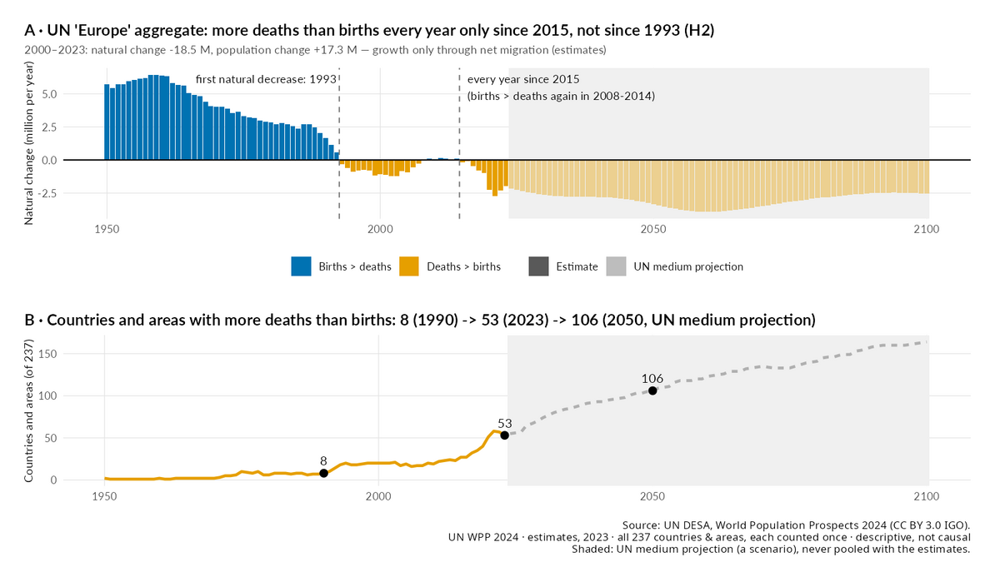

**`figures/review/q1/q1_18_misma_fecundidad_shapley.png`** (figura de revisión, no final)

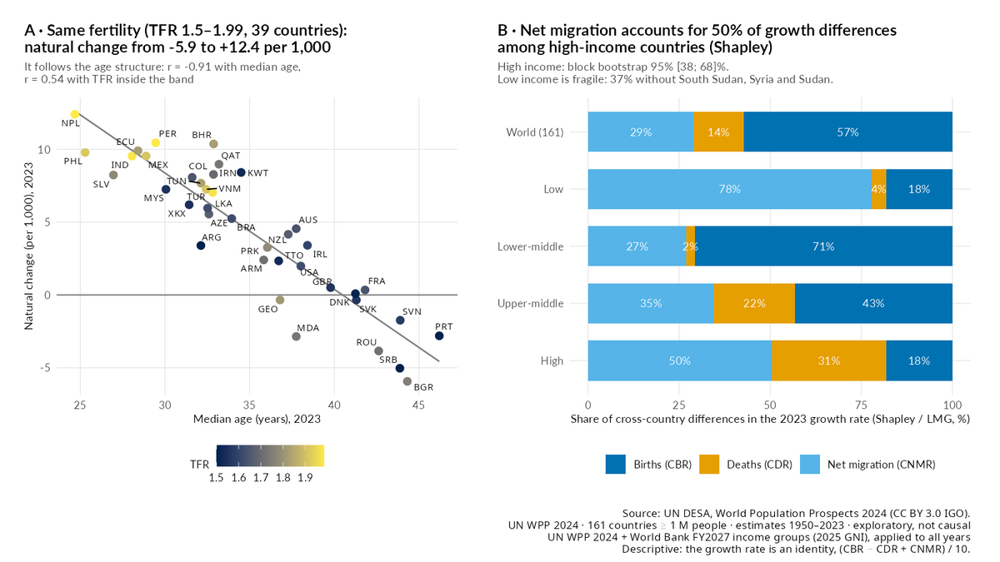

In [75]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q1/).
mostrar_figuras("q1", c("q1_17_europa_decrecimiento_natural", "q1_18_misma_fecundidad_shapley"))

#### Lectura de resultados · §10 Europa y decrecimiento natural (H2, H14, H14a) y apéndice (secciones 10 y 10b)

*Texto de `docs/resultados_q1.md` §10 (escrito sobre la corrida oficial de este script; cifras reales).*

| Resultado | Valor | Clave |
|---|---|---|
| Europa (agregado ONU): primer año con más defunciones que nacimientos | 1993 | `year_europe_natneg.sens_note` |
| … años posteriores con saldo natural ≥ 0 | **2008–2014** | idem |
| … decrecimiento natural **todos** los años hasta 2023 desde | **2015** | `year_europe_natneg` |
| … 2000–2023: saldo natural / cambio total | −18,5 M / +17,3 M (migración = 207 % del cambio) | idem |
| Primer año con NatChange < 0 por región (H14) | Europa 1993 (estimación); Norteamérica 2040, Asia 2055, LAC 2055 (UN medium projection); África y Oceanía no antes de 2100 | parquet |
| Países y áreas con NatChange < 0 (H14a) | 8 (1990; 2 % de la población) → 53 (2023; 28 %) → 106 (2050, proyección) | claves de Q3 (`n_natneg_*`) |
| Shapley: parte de las diferencias de crecimiento 2023 que va con la migración | alto **0,51** [IC 0,38; 0,68]; medio-alto 0,35; medio-bajo 0,27; bajo 0,78 (0,37 sin SSD, SYR, SDN); mundo 0,29 | `shapley_mig_high_2023`, `shapley_mig_by_income_2023` |
| Misma fecundidad (TFR 1,5–1,99, 39 países) | saldo natural de −5,9 ‰ (Bulgaria) a +12,4 ‰ (Nepal); r con edad mediana −0,91 [−0,96; −0,80] | claves de Q2 (`n_band_tfr`, `nat_*_band`, `r_nat_medage_band`) |
| GAM TFR ~ s(log Q5) por ingreso, a Q5 = 100 | bajo 5,9 vs alto 3,8 hijos (AIC −18 468 vs −18 096 con curva común) | `gam_tfr_q5_100_*` |

Figuras: `q1_17_europa_decrecimiento_natural.png`, `q1_18_misma_fecundidad_shapley.png`.

**Lectura de resultados.** H2 se **rechaza** con su regla: Europa tuvo su primer año de decrecimiento natural en 1993, pero volvió a tener más nacimientos que defunciones en 2008–2014; el decrecimiento es continuo solo desde 2015. La segunda parte de H2 sí se cumple (2000–23: saldo natural −18,5 M y crecimiento +17,3 M, solo por migración). H14 queda como descriptiva (sus años futuros son proyección). H14a se confirma. Con la misma fecundidad, el saldo natural va de −6 a +12 por mil y sigue a la edad: la estructura de edad es una palanca escondida que la TFR no ve.

### Q1 · §11 Contrastes formales (familias, Holm/BH) y estado de las hipótesis

*Familias F1–F3, Holm / BH (solo notebook)* · `R/02_q1_palancas.R` líneas 2466–2586

In [76]:
# =============================================================================
# 11. Contrastes formales (familias, Holm/BH) y estado de las hipótesis
# =============================================================================
# QUÉ: junta los p-valores calculados en Q1, los agrupa por familia y los
#      ajusta (Holm para hipótesis; BH para comprobaciones auxiliares), y
#      evalúa cada hipótesis preinscrita con su regla escrita.
# POR QUÉ: ASA A.4/B.3: se reporta todo lo que se contrastó, salga o no.
seccion("11. Contrastes y estado de hipótesis")

contrastes <- tibble(
  contraste = c("H3b log-rank 4 income groups", "H15 placebo permutation", "H16 within slope (cluster)",
                "H24 Moran TFR 2023", "H24 Moran LEx 2023", "H24 Moran median age 2023", "H24 Moran CNMR 2023",
                "H3b Cox income step", "H15 lead falsification", "H15 Wald income heterogeneity", "H15 Cochran Q income",
                "H15 Cochran Q region", "Fertility onset log-rank by region", "Moran CNMR 2023 without Gulf"),
  familia = c(rep("F1 (hypothesis decision)", 7), rep("F2 (supporting checks)", 7)),
  hipotesis = c("H3b", "H15", "H16", "H24", "H24", "H24", "H24", "H3b", "H15", "H15", "H15", "H15", NA, "H24"),
  p = c(lr_p, plac_p, unname(ct_hi[4]), m23$p_perm[m23$indicador == "TFR"], m23$p_perm[m23$indicador == "LEx"],
        m23$p_perm[m23$indicador == "MedianAgePop"], m23$p_perm[m23$indicador == "CNMR"], unname(cx_p), unname(lead_ct[4]), wald_p,
        unname(coch_ing["p"]), unname(coch_reg["p"]), pchisq(lr_reg$chisq, length(lr_reg$n) - 1, lower.tail = FALSE), unname(pm_ng["p"]))) |>
  group_by(familia) |> mutate(p_holm = p.adjust(p, "holm"), p_bh = p.adjust(p, "BH")) |> ungroup()
print(contrastes |> mutate(across(where(is.numeric), \(x) signif(x, 3))))
fijar_padj <- function(clave, p_adj, metodo) {
  reg[[clave]]["p_adj"] <<- list(signif(p_adj, 4)); reg[[clave]]["p_adj_method"] <<- list(metodo)
}
fijar_padj("logrank_income_chisq", contrastes$p_holm[1], "holm (F1, Q1)")
fijar_padj("panel_placebo_lo", contrastes$p_holm[2], "holm (F1, Q1)"); fijar_padj("panel_placebo_hi", contrastes$p_holm[2], "holm (F1, Q1)")
fijar_padj("mig_hi_within_slope", contrastes$p_holm[3], "holm (F1, Q1)")
for (j in 1:4) fijar_padj(claves_moran[c("TFR", "LEx", "MedianAgePop", "CNMR")][j], contrastes$p_holm[3 + j], "holm (F1, Q1)")
n_tests_q1 <- c(F1 = sum(contrastes$familia == "F1 (hypothesis decision)"), F2 = sum(contrastes$familia == "F2 (supporting checks)"),
                F2_grids = nrow(grid_res) + nrow(reglas_res),
                F2_lisa_local = nrow(lisa_tab),                     # 161 x 2 pruebas locales con BH
                F3_illustration = length(ejemplos) + 2L)   # ejemplos A-E, ejemplos de inercia y países resaltados de fig04
anotar("n_tests_q1", value = n_tests_q1, unit = "tests", fmt = "0", method = "descriptive",
       def = "Formal tests computed for Q1 by family: F1 = p-values that decide a hypothesis (Holm), F2 = supporting checks (BH), sensitivity grids (reported in full, unmarked) and local Moran tests (BH within each map), F3 = rule-based illustrations without inference (examples by type, momentum examples, highlighted countries)",
       filter = "Q1 script", source_cell = "Q1-11.1", used_in = c("notebook.T17"), status = "descriptive",
       n = sum(n_tests_q1), universe = "Q1 analyses (number of tests)")


11. Contrastes y estado de hipótesis


# A tibble: 14 × 6
   contraste                          familia                  hipotesis        p   p_holm     p_bh
   <chr>                              <chr>                    <chr>        <dbl>    <dbl>    <dbl>
 1 H3b log-rank 4 income groups       F1 (hypothesis decision) H3b       8.16e-16 5.71e-15 5.71e-15
 2 H15 placebo permutation            F1 (hypothesis decision) H15       3.32e- 3 9.97e- 3 4.65e- 3
 3 H16 within slope (cluster)         F1 (hypothesis decision) H16       9.36e- 1 9.36e- 1 9.36e- 1
 4 H24 Moran TFR 2023                 F1 (hypothesis decision) H24       1   e- 3 6   e- 3 1.75e- 3
 5 H24 Moran LEx 2023                 F1 (hypothesis decision) H24       1   e- 3 6   e- 3 1.75e- 3
 6 H24 Moran median age 2023          F1 (hypothesis decision) H24       1   e- 3 6   e- 3 1.75e- 3
 7 H24 Moran CNMR 2023                F1 (hypothesis decision) H24       8   e- 3 1.6 e- 2 9.33e- 3
 8 H3b Cox income step                F2 (supporting checks)   H3b       5.18e-16

In [77]:
# 11.2 Estado de cada hipótesis de Q1 con su regla escrita (hipotesis_preinscritas.md)
x_hi <- cuotas[["High income"]]
h15_cond <- c(neg = LN05 * s1$beta_sum < 0, ic = LN05 * s1$lo < 0,   # regla preinscrita: IC con EE agrupados por país
              menor = abs(LN05 * s1$beta_sum) < (2 / 3) * abs(entre),
              fuera_placebo = s1$beta_sum > plac_q[2] | s1$beta_sum < plac_q[1])
km_up <- km53["crossed 5 by 1990", "med"]; km_post <- km53["after 1990", "med"]
q5_within <- simp |> filter(par == "Q5-CNMR", grupo != "World")
hip <- tribble(
  ~id, ~enunciado, ~estado, ~evidencia,
  "H1", "High-income (FY2027): net migration > 50% of 2000-23 growth",
  ifelse(x_hi$bb$valor > 50 & x_hi$bca$ci_low > 50, "confirmada", ifelse(x_hi$bb$valor > 50, "matizada (parcial)", "rechazada")),
  sprintf("%.1f%% [BCa %.1f; %.1f] [bloques %.1f; %.1f]; jackknife %.1f-%.1f; sens %.1f-%.1f", x_hi$bb$valor, x_hi$bca$ci_low, x_hi$bca$ci_high,
          x_hi$bb$ci_low, x_hi$bb$ci_high, x_hi$jk$min, x_hi$jk$max, min(sens_hi), max(sens_hi)),
  "H2", "Europe: NatChange < 0 every year since 1993; grows 2000-23 only by migration",
  ifelse(!is.na(anio_eu) && abs(anio_eu - 1993) <= 1 && sum(eu_0023$NatChange) < 0 && sum(eu_0023$PopChange) > 0, "confirmada", "rechazada"),
  sprintf("first natural decrease %d, but NatChange >= 0 again in %s; sustained only since %s; 2000-23 nat %.0f, pop %.0f thousand (growth only through migration holds)", anio_eu_primero, paste(eu_pos, collapse = ", "), anio_eu, sum(eu_0023$NatChange), sum(eu_0023$PopChange)),
  "H3", "v1: median lag 11 yrs (Q5<100 -> TFR<4), mortality first 80%",
  ifelse(min(grid_res$mediana_rezago) < 0 | min(grid_res$pct_mort_primero) <= 50, "rechazada", "confirmada"),
  sprintf("grid medians %.1f to %.1f yrs; mortality first %.0f-%.0f%%; KM 100/4 %.0f [%.0f; %.0f]", min(grid_res$mediana_rezago), max(grid_res$mediana_rezago),
          min(grid_res$pct_mort_primero), max(grid_res$pct_mort_primero), km100["med"], km100["lo"], km100["hi"]),
  "H3a", "Q5 lasting decline starts before TFR in most high-fertility countries",
  ifelse(w_mort$ci_low > 50, "confirmada", ifelse(w_mort$valor > 50, "matizada", "rechazada")),
  sprintf("%d/%d = %.1f%% Wilson [%.1f; %.1f]; 9 rules %.0f-%.0f%%; lower bound of lag %.0f yrs [%.0f; %.0f]; Turnbull median not identified (%.0f%% mass beyond)",
          x_mort, n_onset, w_mort$valor, w_mort$ci_low, w_mort$ci_high, min(reglas_res$pct_mort_primero), max(reglas_res$pct_mort_primero),
          bb_lb$valor, bb_lb$ci_low, bb_lb$ci_high, 100 * masa_mas_alla),
  "H3b", "Fertility onset later in lower income groups (low > lowmid > upmid; log-rank)",
  ifelse(km_ing[["Low income"]]$mediana > km_ing[["Lower middle income"]]$mediana & km_ing[["Lower middle income"]]$mediana > km_ing[["Upper middle income"]]$mediana &
           contrastes$p_holm[1] < 0.05, "confirmada", "rechazada"),
  sprintf("medians %s / %s / %s / high %s; log-rank chi2 %.1f (3 df), Holm p %.1e", km_ing[["Low income"]]$mediana, km_ing[["Lower middle income"]]$mediana,
          km_ing[["Upper middle income"]]$mediana, km_ing[["High income"]]$mediana, lr$chisq, contrastes$p_holm[1]),
  "H4", "v1: CNMR beta ~ -1 = no persistence",
  ifelse(beta_cn >= quantile(beta_plac, 0.025) & beta_cn <= quantile(beta_plac, 0.975), "rechazada (beta indistinguible del placebo)", "matizada"),
  sprintf("beta %.2f vs placebo %.2f [%.2f; %.2f]; SD %.1f -> %.1f", beta_cn, mean(beta_plac), quantile(beta_plac, 0.025), quantile(beta_plac, 0.975), sd(bx$x0), sd(bx$x1)),
  "H4a", "Migration less persistent between decades than TFR and LEx",
  ifelse(all(r_cn < min(r_tl)), "confirmada", "rechazada"),
  sprintf("CNMR %.2f-%.2f vs TFR/LEx min %.2f; same sign %.0f%%", min(r_cn), max(r_cn), min(r_tl), w_sig$valor),
  "H5", "v1: rho(TFR, CNMR) negative only in high income",
  ifelse(h5_bca$ci_low < 0 & h5_bca$ci_high > 0, "rechazada", ifelse(h5_bca$ci_high < 0, "confirmada", "rechazada")),
  sprintf(">= 1 M (n=%d): Spearman %.2f [BCa %.2f; %.2f]; all %d high income: Pearson %.2f", nrow(hi23), h5_bca$valor, h5_bca$ci_low, h5_bca$ci_high, nrow(hi23_all), h5_all_p),
  "H12", "v1: 79 of 130 below-replacement countries still grow",
  ifelse(g_main["crecen"] == 79, "confirmada", "rechazada como cifra"),
  sprintf("growing: %d; births > deaths: %d", g_main["crecen"], sum(c23$TFR < 2.1 & c23$NatChange > 0)),
  "H12a", "Most below-replacement countries still grow (2023)",
  ifelse(all(share_crecen > 50), "confirmada", "rechazada"),
  paste(sprintf("%s: %d of %d (%.0f%%)", rownames(g_tab), g_tab[, "crecen"], g_tab[, "n"], share_crecen), collapse = "; "),
  "H14", "v1: first natural decrease Europe 1993, N. America 2040, Asia/LAC 2055",
  "matizada (descriptiva; años futuros = proyección)",
  paste(sprintf("%s %s (%s)", h14$Location, ifelse(is.na(h14$primer_anio_natneg), "-", h14$primer_anio_natneg), h14$periodo), collapse = "; "),
  "H14a", "Countries with NatChange < 0: <= 10 (1990) -> >= 40 (2023)",
  ifelse(natneg$n[natneg$Time == 1990] <= 10 & natneg$n[natneg$Time == 2023] >= 40, "confirmada", "rechazada"),
  sprintf("1990: %d (%.0f%% of people); 2023: %d (%.0f%%); 2050 projection: %d", natneg$n[1], natneg$pop_share[1], natneg$n[2], natneg$pop_share[2], natneg$n[3]),
  "H15", "Within-country TFR-Q5 association < 2/3 of between, CI excludes 0, beats placebo",
  ifelse(all(h15_cond), ifelse(bb_de$ci_high[["dentro"]] < 0, "confirmada",
                               "confirmada por la regla preinscrita (IC por país), con matiz: el IC por bloques de subregión incluye 0"), "rechazada"),
  sprintf("within %.2f [cluster %.2f; %.2f] [bloques %.2f; %.2f] vs between %.2f; placebo 95%% [%.2f; %.2f] (beta units) vs real %.2f; lead %.2f (p %.2f)",
          LN05 * s1$beta_sum, LN05 * s1$hi, LN05 * s1$lo, bb_de$ci_low[["dentro"]], bb_de$ci_high[["dentro"]], entre, plac_q[1], plac_q[2], s1$beta_sum, lead_ct[1], lead_ct[4]),
  "H16", "High income w/o Gulf: no within-country migration compensation (CI contains 0)",
  ifelse(ct_hi[1] - 1.96 * ct_hi[2] < 0 & ct_hi[1] + 1.96 * ct_hi[2] > 0 & bb_hi$ci_low < 0 & bb_hi$ci_high > 0, "confirmada", "rechazada"),
  sprintf("%.2f [cluster %.2f; %.2f] [bloques %.2f; %.2f]; country FE only %.2f", ct_hi[1], ct_hi[1] - 1.96 * ct_hi[2], ct_hi[1] + 1.96 * ct_hi[2], bb_hi$ci_low, bb_hi$ci_high, ct_hp[1]),
  "H17", "Aligning on TFR = 4 removes >= 50% of variance (>= 30% with 5 and 3)",
  ifelse(r4$pct >= 50 & regs_hito$c5$pct >= 30 & regs_hito$c3$pct >= 30, "confirmada", "rechazada"),
  sprintf("4: %.0f%% [%.0f; %.0f]; 5: %.0f%%; 3: %.0f%%; phase R2 %.2f", r4$pct, r4$bb$ci_low, r4$bb$ci_high, regs_hito$c5$pct, regs_hito$c3$pct, r2_fase["r2"]),
  "H18", "Countries crossing 5 after 1990 are not faster from 5 to 3",
  ifelse(is.na(km_post) || km_post >= km_up, "confirmada", "rechazada"),
  sprintf("KM median after 1990 %.1f vs by 1990 %.1f (by 1975 %.1f; 1975-90 %.1f)", km_post, km_up, km53[1, "med"], km53[2, "med"]),
  "H19", ">= 15 below-replacement countries grow from births without net immigration, >= 2 bn people",
  ifelse(n_inr >= 15 & pop_inr >= 2, "confirmada", "rechazada"),
  sprintf("%d countries, %.2f bn (strict %d, %.2f bn)", n_inr, pop_inr, n_inr_e, pop_inr_e),
  "H21", "rho(Q5, CNMR) < -0.3 worldwide, |rho| < 0.2 within each income group",
  ifelse(simp$rho[simp$par == "Q5-CNMR" & simp$grupo == "World"] < -0.3 & all(abs(q5_within$rho) < 0.2), "confirmada",
         ifelse(simp$rho[simp$par == "Q5-CNMR" & simp$grupo == "World"] < -0.3, "matizada", "rechazada")),
  sprintf("world %.2f; within %s; partial %.2f", simp$rho[simp$par == "Q5-CNMR" & simp$grupo == "World"],
          paste(sprintf("%s %.2f", ETIQUETAS_INGRESO_CORTAS_EN[q5_within$grupo], q5_within$rho), collapse = ", "), rho_parcial),
  "H22", ">= 1/3 of countries: UN 95% PI 2050 includes growth and decline",
  ifelse(n_unc95 >= 54, "confirmada", "rechazada"), sprintf("%d of 161 (80%% PI: %d)", n_unc95, n_unc80),
  "H24", "Moran CNMR < 0.2 while TFR, LEx, median age > 0.6 (2023)",
  ifelse(m23$I[m23$indicador == "CNMR"] < 0.2 & all(m23$I[m23$indicador %in% c("TFR", "LEx", "MedianAgePop")] > 0.6), "confirmada", "rechazada"),
  sprintf("TFR %s, LEx %s, median age %s, CNMR %s (without Gulf %s)",
          formatear_cifra(round(m23$I[m23$indicador == "TFR"], 4), "0.00"), formatear_cifra(round(m23$I[m23$indicador == "LEx"], 4), "0.00"),
          formatear_cifra(round(m23$I[m23$indicador == "MedianAgePop"], 4), "0.00"), formatear_cifra(round(m23$I[m23$indicador == "CNMR"], 4), "0.00"),
          formatear_cifra(round(unname(pm_ng["I"]), 4), "0.00"))
)
print(hip, n = 30, width = 220)

# A tibble: 20 × 4
   id    enunciado                                                                                 
   <chr> <chr>                                                                                     
 1 H1    High-income (FY2027): net migration > 50% of 2000-23 growth                               
 2 H2    Europe: NatChange < 0 every year since 1993; grows 2000-23 only by migration              
 3 H3    v1: median lag 11 yrs (Q5<100 -> TFR<4), mortality first 80%                              
 4 H3a   Q5 lasting decline starts before TFR in most high-fertility countries                     
 5 H3b   Fertility onset later in lower income groups (low > lowmid > upmid; log-rank)             
 6 H4    v1: CNMR beta ~ -1 = no persistence                                                       
 7 H4a   Migration less persistent between decades than TFR and LEx                                
 8 H5    v1: rho(TFR, CNMR) negative only in high income                         

#### Lectura de resultados · §11 Estado de las hipótesis preinscritas de Q1

*Texto de `docs/resultados_q1.md` §11 (escrito sobre la corrida oficial de este script; cifras reales).*

Familias: F1 = 7 contrastes que deciden hipótesis (Holm); F2 = 7 comprobaciones auxiliares (BH) + 29 celdas de rejillas (sin marcar) + 322 pruebas locales LISA (BH en cada mapa); F3 = 7 ilustraciones por regla sin inferencia (`n_tests_q1`). Ningún p-valor va al vídeo.

| ID | Estado | Evidencia (corrida final) |
|---|---|---|
| H1 | **confirmada** | 70,7 % [BCa 56,0; 111,9] [bloques 55,5; 133,3]; jackknife 64,5–81,6; sensibilidades 64,0–81,6 |
| H2 | **rechazada** | primer decrecimiento natural 1993, pero saldo ≥ 0 en 2008–2014; continuo solo desde 2015 (crece 2000–23 solo por migración: sí) |
| H3 | **rechazada** | medianas −11,5 a +39,5 años; mortalidad primero 16–100 % según el par de umbrales |
| H3a | **confirmada** | 106/109 = 97,2 % [92,2; 99,1]; 9 reglas 94–97 %; cota del rezago 22 [16; 28]; mediana no identificable |
| H3b | **confirmada** | 2000 / 1984 / 1970 (alto 1970); log-rank 73,4 (3 gl), Holm p ≈ 6 × 10⁻¹⁵ |
| H4 | **rechazada** | β = −0,90, dentro del placebo [−1,12; −0,88] |
| H4a | **confirmada** | CNMR 0,32–0,69 < mínimo TFR/LEx 0,95; 76 % mantiene el signo |
| H5 | **rechazada** | ≥ 1 M: +0,10 [−0,18; 0,43]; el −0,36 solo con microestados |
| H12 | **rechazada como cifra** | crecen 84; 79 = nacimientos > defunciones |
| H12a | **confirmada** | 84/130 (65 %); 82/124; 91/138; 86/130 (NRR) |
| H14 | **matizada** (descriptiva) | Europa 1993 (estimación); N. América 2040, Asia y LAC 2055 (proyección) |
| H14a | **confirmada** | 8 (1990) → 53 (2023) |
| H15 | **matizada** (confirmada por la regla con EE por país) | −0,41 [cluster −0,71; −0,12] vs −1,05; placebo [−0,25; 0,26]; **IC por bloques [−0,77; 0,05] incluye 0**; adelanto 0,28 (p = 0,08) |
| H16 | **confirmada** | +0,01 [cluster −0,17; 0,18] [bloques −0,20; 0,17]; solo FE país −0,16 |
| H17 | **confirmada** | hito 4: −80 % [69; 85]; hito 5: −77 %; hito 3: −71 % |
| H18 | **confirmada** | KM después de 1990 24,1 vs hasta 1990 18,8 años |
| H19 | **confirmada** | 22 países, 2,20 mil M (estricta 18, 2,20 mil M) |
| H21 | **confirmada** | mundo −0,45; dentro de cada grupo +0,08 / +0,16 / +0,17 / −0,07 |
| H22 | **confirmada** | 77 de 161 (IP 80: 47) |
| H24 | **confirmada** | TFR 0,74, LEx 0,69, edad mediana 0,77, CNMR 0,11 (sin Golfo −0,03) |

Tabla completa con las reglas: `data/processed/resultados_q1_hipotesis.parquet`; contrastes y p ajustados: `resultados_q1_contrastes.parquet`.

### Q1 · §12 Salidas: numbers_q1.json, parquet, CSV

`R/02_q1_palancas.R` líneas 2587–2638

In [78]:
# =============================================================================
# 12. Salidas: numbers_q1.json, parquet, CSV
# =============================================================================
# QUÉ: guarda las cifras con su esquema completo y las tablas que necesitarán
#      las figuras finales.
# POR QUÉ: ninguna cifra del vídeo se escribe a mano (fuente única de verdad).
seccion("12. Salidas")

paises_q1 <- miembros |>
  left_join(bi |> select(ISO3_code, tfr_1950), by = "ISO3_code") |>
  left_join(el |> transmute(ISO3_code, elegible_inicio = TRUE, inicio_q5, inicio_tfr, izq_q5, izq_tfr, rezago_inicio_lo, rezago_inicio_hi,
                            mort_primero, caida_q5_al_inicio_tfr), by = "ISO3_code") |>
  left_join(hitos |> select(ISO3_code, c5, c4, c3, dur_5a3, evento_3, cohorte_c5, ventana_completa_c4), by = "ISO3_code") |>
  mutate(elegible_inicio = elegible_inicio %in% TRUE, cohorte_c5 = as.character(cohorte_c5))
guardar_pq <- function(df, nombre) arrow::write_parquet(as.data.frame(df), file.path(RUTA_PROCESSED, paste0(nombre, ".parquet")))
guardar_pq(paises_q1, "resultados_q1")
guardar_pq(desc, "resultados_q1_descomposicion")
guardar_pq(cuotas_tab, "resultados_q1_cuotas_ic")
guardar_pq(tab_vent, "resultados_q1_ventanas")
guardar_pq(mor, "resultados_q1_moran")
guardar_pq(km_tab, "resultados_q1_km")
guardar_pq(ev_tab, "resultados_q1_event_time")
guardar_pq(grid_res, "resultados_q1_umbral_grid")
guardar_pq(reglas_res, "resultados_q1_reglas_inicio")
guardar_pq(curvas, "resultados_q1_registro")
guardar_pq(disp_reg, "resultados_q1_registro_dispersion")
guardar_pq(panel_tab, "resultados_q1_panel")
guardar_pq(tibble(replica = seq_along(plac), beta_sum = plac, halfq5 = LN05 * plac), "resultados_q1_placebo")
guardar_pq(cmp_tab, "resultados_q1_comparacion_modelos")
guardar_pq(mem, "resultados_q1_memoria")
guardar_pq(simp |> select(-bb), "resultados_q1_simpson")
guardar_pq(fan, "resultados_q1_fan_are")
guardar_pq(dir50, "resultados_q1_direccion_2050")
guardar_pq(hip, "resultados_q1_hipotesis")
guardar_pq(contrastes, "resultados_q1_contrastes")
guardar_pq(reloj, "resultados_q1_inercia")
guardar_pq(lisa_tab, "resultados_q1_lisa")
guardar_pq(shap, "resultados_q1_shapley")
guardar_pq(banda, "resultados_q1_misma_fecundidad")
guardar_pq(rachas, "resultados_q1_tipoE_historico")
guardar_pq(pred_gam |> mutate(ingreso = as.character(ingreso)), "resultados_q1_gam")
guardar_pq(gancho_df |> mutate(grupo = as.character(grupo)), "resultados_q1_gancho")

guardar_numbers(reg, RUTA_NUMBERS_Q1, ordenar = TRUE)
val <- validar_registro(reg)
cat("\nValidación del registro (problemas):\n"); print(val, row.names = FALSE)
falt <- claves_faltantes(reg, c("universo", "slide1", "slide2"))
cat("\nClaves obligatorias de universo/slide1/slide2 que NO registra Q1:", paste(falt, collapse = ", "), "\n")
informar("Claves registradas: %d -> %s", length(reg), RUTA_NUMBERS_Q1)
informar("Tiempo total: %.1f min (B pantalla = %d, B notebook = %d, placebo = %d, permutaciones = %d)",
         as.numeric(difftime(Sys.time(), t_inicio, units = "mins")), B_Q1, B_NB, B_PLAC, B_PERM_Q1)
invisible(TRUE)


12. Salidas



Validación del registro (problemas):


[1] clave    problema
<0 rows> (or 0-length row.names)



Claves obligatorias de universo/slide1/slide2 que NO registra Q1:  


Claves registradas: 165 -> /home/darkns/Documents/ASA_Dataquest/RepoGithub/figures/numbers_q1.json


Tiempo total: 9.3 min (B pantalla = 2000, B notebook = 1000, placebo = 300, permutaciones = 999)


#### Lectura de resultados · §12 Hallazgos sorprendentes y limitaciones

*Texto de `docs/resultados_q1.md` §12 (escrito sobre la corrida oficial de este script; cifras reales).*

**Hallazgos nuevos (no estaban en el plan, o salen distintos).**
1. **Europa no lleva 30 años de decrecimiento natural:** volvió a tener más nacimientos que defunciones en 2008–2014; el decrecimiento continuo empieza en 2015 (H2 cae).
2. **La relación mortalidad–fecundidad dentro del país se invierte en Europa y Norteamérica** (+0,39 [0,23; 0,56]) y se anula en ingreso medio; ponderar por población la vuelve positiva (+0,08).
3. **El IC por bloques de la cifra "dentro del país" incluye el 0** [−0,77; 0,05], aunque el placebo y el IC por país la separan del 0: la dependencia entre vecinos pesa.
4. **Irán entra en el único vecindario migratorio robusto** (con los 6 del Golfo); con un solo año (2023) no sobrevive ninguno a la corrección por pruebas múltiples.
5. **El "reloj" de China** (bajar de 2,1 en 1991 → pico en 2021 = 30 años) cae dentro del rango proyectado para los 13 países de inercia ≥ 1 M (32–40), pero en el borde bajo.
6. **Shapley:** en ingreso bajo, la migración "explica" el 78 % de las diferencias de crecimiento de 2023 solo por tres países en conflicto o posconflicto (SSD, SYR, SDN); sin ellos, 37 %.

**Limitaciones.**
- Todo es descriptivo: ingreso de hoy aplicado a 1950–2023; la transición es en parte la causa del ingreso, no al revés.
- La migración neta es el componente peor medido (residuo censal en muchos países); 2023 es un solo año y los conteos de tipo cambian con la ventana (C: 14–25).
- Censura: la mediana del rezago mortalidad → fecundidad no se identifica; el registro excluye a los 26 países que no han cruzado 4 (sesgo de supervivencia).
- El LISA del Golfo depende de la resolución de la permutación (p mínimo 0,001 con 999): con menos permutaciones no sobrevive a la FDR.
- Los picos de población de la inercia y todo lo posterior a 2023 son escenarios de la ONU (Medium), no observaciones.
- `are_revision_pct` (+12 %) es una cifra **externa** que no se puede calcular con los archivos WPP2024: debe verificarla una persona contra WPP2022 antes de usarla.
- Mapa de revisión: Crimea aún sin reasignar a Ucrania (lo hará la figura final con `R/utils_mapas.R`).

#### Lectura de resultados · §14 Reproducibilidad

*Texto de `docs/resultados_q1.md` §14 (escrito sobre la corrida oficial de este script; cifras reales).*

- `Rscript R/02_q1_palancas.R` desde la raíz; semilla 2026 fijada justo antes de cada remuestreo (`bootstrap_bloques`, `bootstrap_bca`, permutaciones de Moran, LISA, placebo y validación cruzada); `RNGkind("Mersenne-Twister", "Inversion", "Rejection")`.
- Tres corridas oficiales seguidas (9:29, 11:35 y 8:54 min) producen `figures/numbers_q1.json` idéntico byte a byte (`cmp`); los cambios entre ellas fueron solo de texto de figuras de revisión.
- Réplicas: B = 2 000 (cifras de pantalla), 1 000 (solo notebook), 300 (placebo del panel), 999 (Moran y LISA). Modo de desarrollo `Q1_RAPIDO=1` (no oficial).
- `validar_registro()` sin problemas; `claves_faltantes()` de universo, slide1 y slide2: ninguna. Sin colisiones de claves con `numbers_q2.json` ni `numbers_q3.json` (Q1 dejó de registrar `momentum_years_range`, `n_band_tfr`, `nat_min_band`, `nat_max_band` y `r_nat_medage_band`, que pertenecen a Q3 y Q2).

## 4. Q2 — Can a single indicator tell the whole story? (P8 + P5)

Script: `R/03_q2_un_numero.R` · lecturas: `docs/resultados_q2.md` · figuras de revisión: `figures/review/q2/`.

> Agente `notebook-Q2` · 2026-10-23 · Script: `R/03_q2_un_numero.R` (se ejecuta de principio a fin con `Rscript R/03_q2_un_numero.R` desde la raíz del repo; **113–192 s** según la carga de la máquina (última corrida de verificación: 191,8 s con otros agentes en paralelo), sin errores ni avisos; tres corridas seguidas dan el mismo `numbers_q2.json` y el mismo registro de consola byte a byte, ver §10).
> Cifras: `figures/numbers_q2.json` (96 claves, esquema v2, `verified: false` hasta QA-stats). Tablas: `data/processed/resultados_q2_*.parquet` (columnas documentadas al inicio del script) y `figures/lookalikes_todos.csv`. Figuras de revisión (no finales): `figures/review/q2/q2_01…q2_13.png` (1600×900), revisadas una a una.
> Universo: **161 países ≥ 1 M** (población 2023), **2023**, estimaciones de la ONU, salvo que se diga otra cosa. "IC" = intervalo 95 % por **bootstrap por bloques de las 20 subregiones ONU** (B = 2 000, semilla 2026; el que puede salir en pantalla). "iid" = bootstrap de países (BCa o percentil), solo para comparar. Los intervalos describen *sensibilidad a qué países (o regiones) entran*, no error muestral. Todo es descriptivo; ningún resultado es causal.

#### Resumen en 6 líneas (de `docs/resultados_q2.md`)

1. **La fecundidad sola cuenta la historia lenta, no la rápida (H6 ✔):** explica el 77 % de las diferencias de edad mediana [IC 67–84 %], el 59 % del crecimiento de 2023 [31–80 %] y nada de la migración (−0,001 [−0,01; 0,08]).
2. **Lo lento es estable y lo rápido no:** en cada año 1950–2023 el R² de la edad mediana va de 0,73 a 0,81; el del crecimiento salta de 0,01 (1990) a 0,69 (2020).
3. **Un número no encuentra a tus parecidos (H20 ✔):** con la TFR sola se recupera el **13 %** de los 5 vecinos reales [IC 9–18 %]; con dos ejes del PCA, el **43 %** [40–46 %]; azar, 3 %. En 90 de 161 países la TFR no acierta **ninguno**. Colombia: por TFR ≈ Francia, Australia, Türkiye, EE. UU., Nueva Zelanda; por 12 indicadores ≈ Irán, Perú, Ecuador, Panamá, Túnez (0 en común).
4. **Dos dimensiones reales (H7a ✔, H7 ✘):** PC1 = 56,7 % [51,4; 62,6], dos ejes = 74,6 %; exactamente 2 autovalores superan al ruido; r(TFR, PC1) = −0,94 y r(TFR, PC2) = 0,03. El % del PC1 va de 46 % a 77 % según las variables: no es cifra titular.
5. **La tasa bruta de mortalidad cambió de significado (H13 ✔):** ρ(CDR, LEx) = −0,97 en 1950 y 0,07 en 2023 [−0,31; 0,32]; Portugal y Chad tienen la misma CDR (11,1 y 11,0) y 27 años de diferencia en esperanza de vida.
6. **P5: los pesos deciden (H8a ✔, H8 ✘):** en 2 000 diseños razonables del índice, el **21,7 %** de los países (35 de 161) puede moverse más de 20 puestos; si solo cambian las fórmulas (normalización y agregación), el 2,5 %.

In [79]:
# Aislamiento: Q2 corre como `Rscript R/03_q2_un_numero.R` (entorno global vacío, carpeta = raíz del repo).
entorno_limpio()

In [80]:
#!/usr/bin/env Rscript
# =============================================================================
# 03_q2_un_numero.R
# Q2 — "Can a single indicator tell the whole story?" (P8 + P5)
#
# Ejecutar desde la raíz del repo:   Rscript R/03_q2_un_numero.R
#
# Qué hace (plan analítico v2 §4-Q2; tareas T8, T9, T10 y T15 del plan de
# implementación §3.1). Cada bloque va de lo simple a lo rico:
#   1. Datos: corte 2023 de los 161 países >= 1 M (+ 2050 proyectado, 237 y 1990
#      como sensibilidad). CNMR winsorizada ±3 DE solo para PCA y look-alikes.
#   2. S1 · Scorecard "qué explica la fecundidad sola" (H6): R² ajustado de 4
#      salidas declaradas a priori; IC por bloques de subregión (pantalla) y BCa
#      iid (notebook); validación cruzada 10-fold × 20 y por bloques
#      (dejar fuera una subregión); spline, 237, 1990, sin Golfo; el mismo R² en
#      cada año 1950–2023 y el cambio OBSERVADO a 27 años como contraste del
#      cambio proyectado 2023→2050.
#   3. Escalera 0,59 → 0,70 → 0,99 como IDENTIDAD contable (nota al pie) y
#      escalera honesta "fuera de tiempo" (crecimiento 10 años después).
#   4. La tasa bruta de mortalidad cambió de significado (H13): ρ(CDR, LEx) por
#      año 1950–2023 con banda por bloques; par Portugal–Chad por regla.
#   5. S2 · Gemelos por regla (búsqueda exhaustiva de 12 880 pares).
#   6. R1 · Prueba de look-alikes (H20): 5 vecinos con TFR sola vs 12
#      indicadores vs 2 ejes del PCA; perfil recuperado; tabla de todos los países.
#   7. R2 · PCA con el conjunto fijo de 12 variables + análisis paralelo (H7, H7a);
#      sensibilidades (conjuntos de variables, sin Golfo, 237, asinh, 1950/1990/2050).
#   8. R3 · Índice compuesto P5 (H8, H8a): 7 variantes a mano y Monte Carlo de
#      2 000 diseños; α y ω solo notebook; validez con LE60.
#   9. Hallazgo de demografía: misma fecundidad, saldo natural opuesto (dem01).
#  10. Redundancia (solo notebook): VIF y correlaciones parciales.
#  11. Hipótesis de Q2, registro de cifras (figures/numbers_q2.json) y tablas.
#
# Reglas (plan §3, ética ASA 2022): países = ISO3_code no vacío; estimaciones
# <= 2023 y proyección Medium >= 2024 siempre separadas y etiquetadas; ningún
# estadístico cruza 2023/24 salvo la salida "cambio 2023→2050", declarada a
# priori en H6 como proyección ("partly by construction"); lenguaje descriptivo,
# nunca causal; set.seed(2026) justo antes de cada bloque aleatorio.
#
# SALIDAS
#   figures/numbers_q2.json            (claves de Q2, esquema v2 de numbers.json)
#   figures/lookalikes_todos.csv       (tabla completa de look-alikes; plan T9)
#   figures/review/q2/q2_*.png         (gráficas rápidas de revisión, 1600×900)
#   data/processed/resultados_q2_*.parquet — columnas:
#   * resultados_q2_scorecard.parquet: salida (código), salida_en (etiqueta),
#       r2_adj (R² ajustado sobre TFR, 2023, 161), r2 (sin ajustar), ci_low/ci_high
#       (bootstrap por bloques de subregión, 95 %, B = 2000), ci_iid_low/ci_iid_high
#       (BCa iid de países), r2_cv10 (VC 10-fold × 20, media), r2_cv10_min/max
#       (rango de las 20 repeticiones), r2_cv_loso (VC dejando fuera una
#       subregión), r2_spline3 (spline natural 3 gl, ajustado), r2_237 (237 países),
#       r2_1990 (análogo observado 1990: salida 1990 o cambio 1990→2017),
#       r2_sin_golfo (155 países), periodo_salida ("Estimate"/"UN medium projection").
#   * resultados_q2_r2_por_anio.parquet: Time, salida ("medage" / "growth" /
#       "cnmr" = mismo año; "chg27_observed" = cambio observado a 27 años desde el
#       año de origen; "chg2050_projected" = referencia proyectada), r2_adj, periodo.
#   * resultados_q2_escalera.parquet: tipo ("same year (identity)" / "10 years
#       later (out of time)"), origen_entrenamiento, origen_prueba, modelo, r2.
#   * resultados_q2_rho_cdr_lex.parquet: Time, rho_cdr_lex (Spearman entre
#       países), ci_low/ci_high (bloques; NA en proyección), r_pearson_cdr_lex,
#       rho_cdr_medage, n, periodo_en.
#   * resultados_q2_gemelos.parquet: regla (id), regla_en, rank, iso_a, iso_b,
#       pais_a, pais_b, var_igual, igual_a, igual_b, var_dif, dif_a, dif_b, dif_abs.
#   * resultados_q2_lookalikes.parquet (= figures/lookalikes_todos.csv):
#       ISO3_code, Location, region_sdg, ingreso, vecinos_12 / vecinos_tfr /
#       vecinos_pc12 / vecinos_pc1 (5 ISO3 separados por coma, del más al menos
#       parecido), vecinos_12_nombres, vecinos_tfr_nombres, solap_tfr, solap_pc1,
#       solap_pc12 (cuántos de los 5 vecinos reales recupera cada resumen, 0–5).
#   * resultados_q2_knn_resumen.parquet: caso, anio, periodo, conjunto, k, n,
#       resumen, solapamiento_pct, azar_pct, ci_low, ci_high (solo caso base).
#   * resultados_q2_knn_loso.parquet: subregion_fuera (subregión excluida), n,
#       tfr, pc1, pc12 (% de look-alikes recuperados rehaciendo todo sin ella).
#   * resultados_q2_recupera.parquet: resumen, perfil_recuperado (R² medio de los
#       12 indicadores, lineal), perfil_recuperado_spline (spline 3 gl).
#   * resultados_q2_pca_scores.parquet: ISO3_code, Location, region_sdg,
#       subregion, ingreso, es_golfo, TFR, CNMR_raw, CNMR_w (winsorizada),
#       PC1..PC4 (PC1 orientado con LEx > 0; PC2 con CNMR > 0).
#   * resultados_q2_pca_cargas.parquet: variable, variable_en, carga_PC1..PC4,
#       r_PC1..r_PC4 (correlación variable–componente).
#   * resultados_q2_pca_autovalores.parquet: caso, componente, autovalor,
#       p50_nulo, p95_nulo (análisis paralelo, 1000 permutaciones), var_pct.
#   * resultados_q2_pca_sensibilidad.parquet: caso, tipo (conjunto / muestra /
#       año), periodo, n, n_vars, pc1_pct, pc2_pct, acum2_pct, n_dims_paralelo,
#       r_tfr_pc1, r_tfr_pc2.
#   * resultados_q2_indice_variantes.parquet: ISO3_code, Location, rank_V1..V7
#       (1 = transición más avanzada), amplitud_7, amplitud_norm, amplitud_pesos,
#       salto_mig, amplitud_sin_mig.
#   * resultados_q2_indice_mc.parquet: spec, ISO3_code, Location, rango_base
#       (V1), r05, r50, r95, ancho90, mas20.
#   * resultados_q2_mc_resumen.parquet: spec, descripcion_en, mediana_ancho,
#       p90_ancho, pct_mas20.
#   * resultados_q2_misma_fecundidad.parquet: ISO3_code, Location, region_sdg,
#       TFR, NatChangeRT, CNMR, PopGrowthRate, MedianAgePop.
#   * resultados_q2_redundancia.parquet: tipo ("VIF 12" / "partial r"), par, valor.
#   * resultados_q2_hipotesis.parquet: id, enunciado_en, estatus, resultado,
#       evidencia.
#
# Convención: código y comentarios en español; textos de gráficas en inglés.
# =============================================================================

t_inicio <- Sys.time()

suppressPackageStartupMessages({
  library(here)
})
source(here::here("R", "config.R"))
source(here::here("R", "utilidades.R"))
source(here::here("R", "comun_analisis.R"))
source(here::here("R", "incertidumbre.R"))

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(purrr)
  library(ggplot2)
  library(ggrepel)
  library(patchwork)
  library(scales)
  library(arrow)
  library(splines)
})

RNGkind("Mersenne-Twister", "Inversion", "Rejection")
set.seed(SEMILLA)

comun_analisis.R listo: 237 países y áreas (161 >= 1 M; 22/20 subregiones), estimaciones 1950-2023, proyección Medium 2024-2100, semilla 2026.



### Q2 · §0 Constantes, rutas y ayudas de este script

`R/03_q2_un_numero.R` líneas 124–263

In [81]:
# =============================================================================
# 0. Constantes, rutas y ayudas de este script
# =============================================================================

RUTA_FIG_Q2 <- file.path(RUTA_FIG_REVIEW, "q2")
dir.create(RUTA_FIG_Q2, recursive = TRUE, showWarnings = FALSE)
RUTA_NUMBERS_Q2 <- file.path(RUTA_FIGURAS, "numbers_q2.json")
RUTA_LOOKALIKES_CSV <- file.path(RUTA_FIGURAS, "lookalikes_todos.csv")
ruta_parquet_q2 <- function(nombre) file.path(RUTA_PROCESSED, paste0("resultados_q2_", nombre, ".parquet"))

B_Q2 <- B_BOOT_BLOQUES          # 2000 réplicas para todo IC que pueda salir en pantalla
B_IID_PCA <- B_BOOT_PCA         # 1000 réplicas (percentil) para PCA iid, como pide el plan
B_PARALELO <- 1000              # permutaciones del análisis paralelo de Horn
M_INDICE <- 2000                # diseños del Monte Carlo del índice
K_LOOK <- K_VECINOS             # 5 vecinos más cercanos

# Las 12 variables fijas del plan (VARS_PCA de config.R) con la densidad en log.
VARS_12 <- sub("^PopDensity$", "logDens", VARS_PCA)
# Conjunto de 8 de config.R (sensibilidad principal del plan).
VARS_8 <- VARS_PCA_SENSIBILIDAD
# Otros conjuntos documentados por los memos (MV §3.1, INF §3.3), solo sensibilidad.
CONJUNTOS_PCA <- list(
  `12 fixed (plan)`            = VARS_12,
  `8 (config, sensitivity)`    = VARS_8,
  `8 catalogue (MV)`           = c("TFR", "LEx", "IMR", "MedianAgePop", "CNMR", "PopGrowthRate", "CBR", "CDR"),
  `8 non-redundant (MV)`       = c("TFR", "LEx", "Q1560", "CDR", "MedianAgePop", "CNMR", "PopSexRatio", "logDens"),
  `13 EDA (MV)`                = c("TFR", "MAC", "SRB", "LEx", "LE65", "Q5", "Q1560", "CDR", "MedianAgePop",
                                   "PopGrowthRate", "CNMR", "PopSexRatio", "logDens"),
  `8 transition core (INF)`    = c("TFR", "CBR", "LEx", "Q5", "IMR", "CDR", "MedianAgePop", "PopGrowthRate")
)

FILTRO_1M_2023 <- "161 countries ≥ 1 M people (2023); UN estimates for 2023"
USO_NB <- "notebook.q2"

# --- Registro de cifras (figures/numbers_q2.json) ---------------------------
reg <- nuevo_registro()
# Envoltorio: añade la cifra al registro global `reg` (mismos argumentos que registrar_cifra()).
anotar <- function(...) {
  reg <<- registrar_cifra(reg, ...)
  invisible(NULL)
}

# --- Tema y guardado de las gráficas de revisión (1600×900) ------------------
tema_q2 <- function() {
  theme_wpp(base_size = 15) +
    theme(plot.caption = element_text(size = rel(0.62), colour = "#666666", hjust = 0),
          plot.title.position = "plot", plot.caption.position = "plot")
}
pie_q2 <- function(...) paste(c(..., badge("PIE-3")), collapse = "\n")
guardar_q2 <- function(p, nombre) {
  guardar_png(p, nombre, carpeta = RUTA_FIG_Q2, ancho = 1600, alto = 900, res = 110)
}
COLOR_GRIS_OSCURO <- "#4D4D4D"
COLOR_GRIS_CLARO <- "#BBBBBB"

# --- Utilidades numéricas ---------------------------------------------------
# Winsorización ±k DE (solo PCA, look-alikes y clustering; plan §3 "Migración extrema").
wins3 <- function(x, k = 3) {
  m <- mean(x, na.rm = TRUE); s <- stats::sd(x, na.rm = TRUE)
  pmin(pmax(x, m - k * s), m + k * s)
}
# R² de una regresión lineal (ajustado por defecto, como dice H6).
r2_lm <- function(d, y, x = "TFR", ajustado = TRUE) {
  s <- summary(stats::lm(stats::reformulate(x, y), data = d))
  if (ajustado) s$adj.r.squared else s$r.squared
}
# R² fuera de muestra = 1 − SSE/SST (SST con la media de todo el conjunto evaluado).
r2_fuera <- function(y, pred) 1 - sum((y - pred)^2) / sum((y - mean(y))^2)

# Validación cruzada K-fold repetida (la semilla se fija fuera, justo antes).
cv_kfold <- function(d, y, x = "TFR", K = 10, reps = 20) {
  f <- stats::reformulate(x, y)
  vals <- replicate(reps, {
    folds <- sample(rep_len(seq_len(K), nrow(d)))
    pred <- numeric(nrow(d))
    for (k in seq_len(K)) {
      m <- stats::lm(f, data = d[folds != k, , drop = FALSE])
      pred[folds == k] <- stats::predict(m, newdata = d[folds == k, , drop = FALSE])
    }
    r2_fuera(d[[y]], pred)
  })
  c(media = mean(vals), min = min(vals), max = max(vals))
}
# Validación cruzada por BLOQUES: se deja fuera una subregión ONU completa cada vez.
cv_loso <- function(d, y, x = "TFR", bloque = "subregion") {
  f <- stats::reformulate(x, y)
  pred <- numeric(nrow(d))
  for (s in unique(d[[bloque]])) {
    i <- d[[bloque]] == s
    m <- stats::lm(f, data = d[!i, , drop = FALSE])
    pred[i] <- stats::predict(m, newdata = d[i, , drop = FALSE])
  }
  r2_fuera(d[[y]], pred)
}

# --- Nombres de países para texto y voz --------------------------------------
# En texto: nombre WPP (columna Location). En la voz: nombre corto (countrycode),
# con los alias del plan (Türkiye, Viet Nam, Republic of Korea) y las
# denominaciones ONU de Kosovo y Taiwán.
nombre_corto <- function(iso3) {
  especiales <- c(TUR = "Türkiye", VNM = "Viet Nam", KOR = "Republic of Korea", PRK = "DPR Korea",
                  IRN = "Iran", USA = "the United States", GBR = "the United Kingdom", RUS = "Russia",
                  ARE = "the United Arab Emirates", SYR = "Syria", BOL = "Bolivia", VEN = "Venezuela",
                  TZA = "Tanzania", COD = "DR Congo", LAO = "Lao PDR", MDA = "Moldova",
                  PSE = "State of Palestine", XKX = "Kosovo (under UNSC res. 1244)", HKG = "Hong Kong SAR",
                  TWN = "China, Taiwan Province of China", NLD = "the Netherlands", PHL = "the Philippines",
                  CZE = "Czechia", CIV = "Côte d'Ivoire", MKD = "North Macedonia")
  out <- suppressWarnings(countrycode::countrycode(iso3, "iso3c", "country.name.en", warn = FALSE))
  hay <- iso3 %in% names(especiales)
  out[hay] <- especiales[iso3[hay]]
  out[is.na(out)] <- nombre_pais(iso3[is.na(out)])
  unname(out)
}
unir_y <- function(x) {
  if (length(x) <= 1) return(paste(x, collapse = ""))
  paste(paste(x[-length(x)], collapse = ", "), "and", x[length(x)])
}
# Frases habladas redondeadas (campo `say`).
NUM_EN <- c("one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten", "eleven", "twelve")
decir_fraccion <- function(x) {
  if (is.na(x)) return(NA_character_)
  if (x < 0.05) return("almost nothing")
  fr <- c("one in ten" = 0.1, "one in five" = 0.2, "a quarter" = 0.25, "a third" = 1 / 3,
          "two in five" = 0.4, "half" = 0.5, "three in five" = 0.6, "two thirds" = 2 / 3,
          "seven in ten" = 0.7, "three quarters" = 0.75, "four in five" = 0.8,
          "nearly nine in ten" = 0.875, "nine in ten" = 0.9)
  names(fr)[which.min(abs(fr - x))]
}
decir_uno_de <- function(pct, sustantivo = NULL) {
  n <- round(100 / pct)
  if (n < 1 || n > length(NUM_EN)) return(sprintf("%.0f percent", pct))
  if (is.null(sustantivo)) paste("one in", NUM_EN[n]) else paste("one", sustantivo, "in", NUM_EN[n])
}
decir_entero <- function(x) {
  n <- round(abs(x))
  if (n >= 1 && n <= length(NUM_EN)) NUM_EN[n] else as.character(n)
}

message("== Q2: infraestructura lista; empieza el análisis ==")

== Q2: infraestructura lista; empieza el análisis ==



### Q2 · §1 Datos: corte 2023 de los 161 países >= 1 M

*Descriptive* · `R/03_q2_un_numero.R` líneas 264–311

In [82]:
# =============================================================================
# 1. Datos: corte 2023 de los 161 países >= 1 M
#    Qué: una fila por país con los 12 indicadores del PCA y las 4 salidas de H6.
#    Por qué: el plan fija 2023 y los países >= 1 M para modelos (los
#    microestados cambian signos de correlaciones, plan §3).
# =============================================================================

#' Corte de un año listo para Q2: CNMR cruda y tratada, densidad en log.
#' @param tratamiento_cnmr "wins" (±3 DE, principal), "asinh" (asinh(CNMR/5), sensibilidad) o "raw".
preparar_corte <- function(anio, muestra = "1m", tratamiento_cnmr = c("wins", "asinh", "raw")) {
  tratamiento_cnmr <- match.arg(tratamiento_cnmr)
  d <- corte_anio(anio, muestra) |> arrange(.data$ISO3_code)
  d$CNMR_raw <- d$CNMR
  d$CNMR <- switch(tratamiento_cnmr,
                   wins = wins3(d$CNMR_raw),
                   asinh = asinh(d$CNMR_raw / 5),
                   raw = d$CNMR_raw)
  d$logDens <- log(d$PopDensity)
  d
}

d23 <- preparar_corte(2023)
stopifnot(nrow(d23) == N_PAISES_1M, !anyNA(d23[, VARS_12]))

# Población 2050 (proyección Medium) para la salida "cambio 2023→2050" de H6.
pob_2050 <- corte_anio(2050, "1m", vars = "TPopulation1July") |>
  select(ISO3_code, pop2050 = TPopulation1July)
d23 <- d23 |>
  left_join(pob_2050, by = "ISO3_code") |>
  mutate(chg2050 = 100 * (pop2050 / TPopulation1July - 1))
stopifnot(!anyNA(d23$chg2050))

# Winsorización documentada (plan §3): a quién afecta en 2023.
iso_wins_2023 <- d23$ISO3_code[abs(d23$CNMR - d23$CNMR_raw) > 1e-12]
message("CNMR winsorizada ±3 DE en 2023 (", length(iso_wins_2023), " países): ",
        paste(iso_wins_2023, collapse = ", "))
anotar("n_cnmr_winsorized_2023", length(iso_wins_2023), "countries", "0",
       "Countries whose 2023 net migration rate is capped at mean ± 3 SD before PCA and look-alikes",
       FILTRO_1M_2023, "T9.0", USO_NB, method = "descriptive", status = "descriptive",
       n = N_PAISES_1M, universe = UNIVERSO_1M,
       sens_note = paste("Winsorized:", paste(iso_wins_2023, collapse = ", "),
                         "· sensitivity: asinh(CNMR/5) instead of winsorizing"))

# Identidad contable (plan §3): crecimiento ≈ (CBR − CDR + CNMR)/10.
resid_identidad <- max(abs(d23$PopGrowthRate - (d23$CBR - d23$CDR + d23$CNMR_raw) / 10))
message(sprintf("Residuo máximo de la identidad PopGrowthRate ≈ (CBR − CDR + CNMR)/10 en 2023: %.4f pp",
                resid_identidad))

CNMR winsorizada ±3 DE en 2023 (7 países): ARE, ARM, OMN, SDN, SSD, SYR, TCD



Residuo máximo de la identidad PopGrowthRate ≈ (CBR − CDR + CNMR)/10 en 2023: 0.0019 pp



#### Lectura de resultados · §1 Datos y decisiones (sección 1 del script)

*Texto de `docs/resultados_q2.md` §1 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Corte 2023 de los 161 países ≥ 1 M con los 12 indicadores fijos del plan (`VARS_PCA`, densidad en log) y las 4 salidas de H6. La CNMR se winsoriza a ±3 DE **solo** para PCA y look-alikes.

| Decisión | Valor | Clave |
|---|---|---|
| Países con CNMR recortada (2023) | 7: ARE, ARM, OMN, SDN, SSD, SYR, TCD | `n_cnmr_winsorized_2023` |
| Residuo máximo de la identidad crecimiento ≈ (CBR − CDR + CNMR)/10 | 0,0019 puntos | (en `r2_all.sens_note`) |
| Sensibilidad a la winsorización | `asinh(CNMR/5)` | casos "asinh" en PCA y look-alikes |
| R² | **ajustado** (lo que dice H6); el no ajustado va en `sens_note` | — |

**Lectura.** La winsorización toca a los mismos 7 países que documentó el memo multivariado. Cambiarla por `asinh` casi no mueve nada (PC1 56,9 % vs 56,7 %; look-alikes por TFR 13,7 % vs 13,2 %).

### Q2 · §2 S1 · Scorecard "qué explica la fecundidad sola" (H6, pre-specified)

*Pre-specified (H6)* · `R/03_q2_un_numero.R` líneas 312–519

In [83]:
# =============================================================================
# 2. S1 · Scorecard "qué explica la fecundidad sola" (H6, pre-specified)
#    Qué: R² ajustado de 4 regresiones simples sobre la TFR, salidas fijadas a
#    priori: edad mediana, cambio 2023→2050 (proyección), crecimiento y CNMR.
#    Por qué: es la respuesta corta a P8 ("historia lenta" vs "palancas
#    rápidas"); el IC por bloques de subregión reconoce que los vecinos se parecen.
# =============================================================================

SALIDAS_H6 <- c(medage = "MedianAgePop", chg2050 = "chg2050", growth = "PopGrowthRate", cnmr = "CNMR_raw")
SALIDAS_H6_EN <- c(medage = "Age structure today (median age)",
                   chg2050 = "Population change 2023→2050 (UN projection)",
                   growth = "Growth rate today", cnmr = "Net migration rate today")

sc <- d23 |> select(ISO3_code, Location, subregion, region_sdg, ingreso, TFR, all_of(unname(SALIDAS_H6)))

In [84]:
# 2.1 Versión simple: R² puntual (ajustado y sin ajustar).
r2_adj <- vapply(SALIDAS_H6, function(y) r2_lm(sc, y), numeric(1))
r2_raw <- vapply(SALIDAS_H6, function(y) r2_lm(sc, y, ajustado = FALSE), numeric(1))
print(round(rbind(r2_adj, r2_raw), 3))

       medage chg2050 growth   cnmr
r2_adj  0.771   0.881  0.590 -0.001
r2_raw  0.773   0.882  0.592  0.005


In [85]:
# 2.2 IC por bloques de subregión (pantalla) y BCa iid (notebook).
stat_scorecard <- function(d) vapply(SALIDAS_H6, function(y) r2_lm(d, y), numeric(1))
set.seed(SEMILLA)
bs_score <- bootstrap_bloques(sc, stat_scorecard, B = B_Q2, semilla = SEMILLA)
bca_score <- lapply(SALIDAS_H6, function(y) {
  set.seed(SEMILLA)
  bootstrap_bca(sc, function(d) r2_lm(d, y), B = B_Q2, semilla = SEMILLA)
})

In [86]:
# 2.3 Validación: VC 10-fold × 20 (países) y VC por bloques (dejar fuera una subregión).
cv10 <- lapply(SALIDAS_H6, function(y) { set.seed(SEMILLA); cv_kfold(sc, y) })
cvloso <- vapply(SALIDAS_H6, function(y) cv_loso(sc, y), numeric(1))

In [87]:
# 2.4 Versión rica / sensibilidades: spline natural 3 gl, 237 países, 1990, sin Golfo.
r2_spline <- vapply(SALIDAS_H6, function(y) r2_lm(sc, y, x = "ns(TFR, df = 3)"), numeric(1))

sc237 <- corte_anio(2023, "completa") |>
  left_join(corte_anio(2050, "completa", vars = "TPopulation1July") |>
              select(ISO3_code, pop2050 = TPopulation1July), by = "ISO3_code") |>
  mutate(chg2050 = 100 * (pop2050 / TPopulation1July - 1), CNMR_raw = CNMR)
r2_237 <- vapply(SALIDAS_H6, function(y) r2_lm(sc237, y), numeric(1))

# Análogo OBSERVADO en 1990: las mismas salidas en 1990 y el cambio 1990→2017
# (27 años, como 2023→2050, pero con estimaciones).
sc1990 <- corte_anio(1990, "1m") |>
  left_join(corte_anio(2017, "1m", vars = "TPopulation1July") |>
              select(ISO3_code, pop2017 = TPopulation1July), by = "ISO3_code") |>
  mutate(chg2050 = 100 * (pop2017 / TPopulation1July - 1), CNMR_raw = CNMR)
r2_1990 <- vapply(SALIDAS_H6, function(y) r2_lm(sc1990, y), numeric(1))

sc_sin_golfo <- sc |> filter(!es_golfo(ISO3_code))
r2_sin_golfo <- vapply(SALIDAS_H6, function(y) r2_lm(sc_sin_golfo, y), numeric(1))

tabla_scorecard <- tibble(
  salida = names(SALIDAS_H6), salida_en = unname(SALIDAS_H6_EN[names(SALIDAS_H6)]),
  r2_adj = unname(r2_adj), r2 = unname(r2_raw),
  ci_low = unname(bs_score$ci_low), ci_high = unname(bs_score$ci_high),
  ci_iid_low = vapply(bca_score, `[[`, numeric(1), "ci_low"),
  ci_iid_high = vapply(bca_score, `[[`, numeric(1), "ci_high"),
  r2_cv10 = vapply(cv10, `[[`, numeric(1), "media"),
  r2_cv10_min = vapply(cv10, `[[`, numeric(1), "min"),
  r2_cv10_max = vapply(cv10, `[[`, numeric(1), "max"),
  r2_cv_loso = unname(cvloso), r2_spline3 = unname(r2_spline), r2_237 = unname(r2_237),
  r2_1990 = unname(r2_1990), r2_sin_golfo = unname(r2_sin_golfo),
  periodo_salida = ifelse(names(SALIDAS_H6) == "chg2050", ETIQUETA_PROYECCION, ETIQUETA_ESTIMACION)
)
print(tabla_scorecard |> mutate(across(where(is.numeric), \(x) round(x, 3))), width = 200)
write_parquet(tabla_scorecard, ruta_parquet_q2("scorecard"))

# A tibble: 4 × 17
  salida  salida_en                                   r2_adj    r2 ci_low ci_high ci_iid_low ci_iid_high r2_cv10 r2_cv10_min r2_cv10_max r2_cv_loso r2_spline3
  <chr>   <chr>                                        <dbl> <dbl>  <dbl>   <dbl>      <dbl>       <dbl>   <dbl>       <dbl>       <dbl>      <dbl>      <dbl>
1 medage  Age structure today (median age)             0.771 0.773  0.675   0.835      0.728       0.806   0.766       0.76        0.768      0.738      0.864
2 chg2050 Population change 2023→2050 (UN projection)  0.881 0.882  0.752   0.941      0.824       0.911   0.878       0.877       0.88       0.868      0.89 
3 growth  Growth rate today                            0.59  0.592  0.309   0.805      0.439       0.703   0.581       0.576       0.589      0.551      0.596
4 cnmr    Net migration rate today                    -0.001 0.005 -0.007   0.084     -0.006       0.038  -0.027      -0.06       -0.004     -0.061     -0.001
  r2_237 r2_1990 r2_sin_gol

In [88]:
# 2.5 Decisión H6 (umbrales fijados en docs/hipotesis_preinscritas.md).
h6_ok_punto <- r2_adj["medage"] >= 0.7 && r2_adj["chg2050"] >= 0.7 && r2_adj["growth"] <= 0.6 && r2_adj["cnmr"] <= 0.1
cv_media <- vapply(cv10, `[[`, numeric(1), "media")
h6_ok_cv <- cv_media["medage"] >= 0.7 && cv_media["chg2050"] >= 0.7 && cv_media["growth"] <= 0.6 && cv_media["cnmr"] <= 0.1

In [89]:
# 2.6 Registro de las 4 cifras del scorecard (+ VC).
claves_r2 <- c(medage = "r2_tfr_medage", chg2050 = "r2_tfr_chg2050", growth = "r2_tfr_growth", cnmr = "r2_tfr_cnmr")
defs_r2 <- c(
  medage = "Adjusted R² of median age (2023) regressed on total fertility rate (2023), across countries",
  chg2050 = "Adjusted R² of % population change 2023→2050 (UN medium projection) regressed on TFR 2023; partly by construction (UN projections build on fertility)",
  growth = "Adjusted R² of population growth rate (2023) regressed on TFR 2023, across countries",
  cnmr = "Adjusted R² of net migration rate (2023, not winsorized) regressed on TFR 2023, across countries")
say_r2 <- c(medage = decir_fraccion(r2_adj["medage"]), chg2050 = decir_fraccion(r2_adj["chg2050"]),
            growth = as.character(round(100 * r2_adj["growth"] / 10) * 10), cnmr = "almost nothing")
for (s in names(SALIDAS_H6)) {
  sens_vals <- c(r2_raw[s], r2_spline[s], r2_237[s], r2_1990[s], r2_sin_golfo[s], cv_media[s], cvloso[s])
  anotar(claves_r2[[s]], unname(r2_adj[s]), "R2", "0.00", defs_r2[[s]], FILTRO_1M_2023, "T8.1",
         c("slide3.build1", "fig07", "narration.s3"),
         ic = extraer_ic(bs_score, s), ic_iid = bca_score[[s]],
         sens_low = min(sens_vals), sens_high = max(sens_vals),
         sens_note = sprintf(paste0("unadjusted %.3f · natural spline 3 df %.3f · 237 countries %.3f · ",
                                    "1990 analogue (estimates%s) %.3f · without Gulf %.3f · 10-fold CV %.3f · ",
                                    "leave-one-subregion-out CV %.3f"),
                             r2_raw[s], r2_spline[s], r2_237[s],
                             if (s == "chg2050") ", change 1990→2017" else "", r2_1990[s], r2_sin_golfo[s],
                             cv_media[s], cvloso[s]),
         status = "pre-specified", hypothesis_id = "H6", n = N_PAISES_1M, universe = UNIVERSO_1M,
         say = say_r2[[s]])
  anotar(paste0(claves_r2[[s]], "_cv"), unname(cv_media[s]), "R2", "0.00",
         paste("Out-of-sample R² (1 − SSE/SST), 10-fold cross-validation repeated 20 times;", sub("^Adjusted R²", "outcome:", defs_r2[[s]])),
         FILTRO_1M_2023, "T8.2", c("slide3.build1", "fig07"), method = "cv_r2", seed = SEMILLA,
         sens_low = cv10[[s]][["min"]], sens_high = cv10[[s]][["max"]],
         sens_note = sprintf("range over the 20 repetitions; leave-one-subregion-out CV = %.3f", cvloso[s]),
         status = "pre-specified", hypothesis_id = "H6", n = N_PAISES_1M, universe = UNIVERSO_1M)
  anotar(paste0(claves_r2[[s]], "_cv_loso"), unname(cvloso[s]), "R2", "0.00",
         paste("Out-of-sample R² when each of the 20 UN subregions is left out in turn (block cross-validation);",
               sub("^Adjusted R²", "outcome:", defs_r2[[s]])),
         FILTRO_1M_2023, "T8.2", USO_NB, method = "cv_r2", status = "exploratory", hypothesis_id = "H6",
         n = N_PAISES_1M, universe = UNIVERSO_1M)
}

In [90]:
# 2.7 Figura de revisión: scorecard.
fig_sc <- tabla_scorecard |>
  mutate(salida_en = factor(salida_en, levels = rev(SALIDAS_H6_EN)),
         historia = ifelse(salida %in% c("medage", "chg2050"), "Slow story", "Fast levers"))
p_sc <- ggplot(fig_sc, aes(y = salida_en)) +
  geom_col(aes(x = pmax(r2_adj, 0), fill = historia), width = 0.62) +
  geom_errorbar(aes(xmin = pmax(ci_low, 0), xmax = ci_high), orientation = "y", width = 0.18,
                colour = "black", linewidth = 0.5) +
  geom_point(aes(x = pmax(r2_cv10, 0)), shape = 23, size = 3.2, fill = "white", colour = "black") +
  geom_text(aes(x = pmax(ci_high, 0) + 0.02,
                label = sprintf("%s  [%s; %s]", formatear_cifra(r2_adj, "0.00"), formatear_cifra(ci_low, "0.00"),
                                formatear_cifra(ci_high, "0.00"))),
            hjust = 0, size = 4.6) +
  scale_fill_manual(values = c("Slow story" = COLOR_NACIMIENTOS, "Fast levers" = COLOR_GRIS_OSCURO), name = NULL) +
  scale_x_continuous(limits = c(0, 1.18), breaks = seq(0, 1, 0.25), expand = expansion(mult = c(0, 0.01))) +
  labs(title = "What fertility alone can explain (2023, 161 countries ≥ 1 M)",
       subtitle = paste0("Adjusted R² of one regression on the total fertility rate; whisker = 95 % block bootstrap by UN subregion; ",
                         "diamond = 10-fold cross-validated R²"),
       x = "Share of country-to-country differences explained (adjusted R²)", y = NULL,
       caption = pie_q2("2050 change is a UN medium projection and partly built from fertility (by construction).",
                        FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_sc, "q2_01_scorecard")

In [91]:
# 2.8 Estabilidad en el tiempo (exploratorio): el mismo R² en cada año 1950–2023
#     y el análogo OBSERVADO del cambio a 27 años (origen 1950–1996 → +27 años).
#     Qué: ¿el 0,77 / 0,59 de 2023 es típico o es la foto de un año?
#     Por qué: "historia lenta" debe ser estable; "palancas rápidas", no. Y el 0,88
#     del cambio 2023→2050 se compara con lo que la TFR explicó de verdad en el pasado.
panel_est_q2 <- paises_1m(periodo = "estimacion") |>
  select(ISO3_code, Time, TFR, MedianAgePop, PopGrowthRate, CNMR, TPopulation1July)
r2_anual <- panel_est_q2 |> group_by(Time) |>
  group_modify(\(x, k) tibble(salida = c("medage", "growth", "cnmr"),
                              r2_adj = c(r2_lm(x, "MedianAgePop"), r2_lm(x, "PopGrowthRate"), r2_lm(x, "CNMR")))) |>
  ungroup()
H_CAMBIO <- 2050 - 2023
r2_chg_obs <- map_dfr(ANIO_INICIO_DATOS:(ANIO_FIN_ESTIMACION - H_CAMBIO), function(t0) {
  verificar_ventana(c(t0, t0 + H_CAMBIO))
  a <- panel_est_q2 |> filter(Time == t0) |> select(ISO3_code, TFR, p0 = TPopulation1July)
  b <- panel_est_q2 |> filter(Time == t0 + H_CAMBIO) |> select(ISO3_code, p1 = TPopulation1July)
  x <- inner_join(a, b, by = "ISO3_code") |> mutate(chg = 100 * (p1 / p0 - 1))
  tibble(Time = t0, salida = "chg27_observed", r2_adj = r2_lm(x, "chg"))
})
tabla_r2_anual <- bind_rows(r2_anual, r2_chg_obs) |> mutate(periodo = ETIQUETA_ESTIMACION) |>
  bind_rows(tibble(Time = 2023, salida = "chg2050_projected", r2_adj = unname(r2_adj["chg2050"]),
                   periodo = ETIQUETA_PROYECCION))
write_parquet(tabla_r2_anual, ruta_parquet_q2("r2_por_anio"))
resumen_anual <- function(sal) {
  x <- tabla_r2_anual |> filter(salida == sal)
  list(v = c(min = min(x$r2_adj), median = stats::median(x$r2_adj), max = max(x$r2_adj)),
       nota = sprintf("min %.3f (%d) · median %.3f · max %.3f (%d) · %d years", min(x$r2_adj),
                      as.integer(x$Time[which.min(x$r2_adj)]), stats::median(x$r2_adj), max(x$r2_adj),
                      as.integer(x$Time[which.max(x$r2_adj)]), nrow(x)))
}
for (cl in list(c("r2_tfr_medage_by_year", "medage", "median age"), c("r2_tfr_growth_by_year", "growth", "population growth rate"),
                c("r2_tfr_cnmr_by_year", "cnmr", "net migration rate"))) {
  ra <- resumen_anual(cl[2])
  anotar(cl[1], round(ra$v, 4), "R2", "0.00",
         sprintf("Adjusted R² of %s on TFR, computed separately in each year 1950–2023 (min / median / max across years)", cl[3]),
         "161 countries ≥ 1 M; UN estimates 1950–2023", "T8.1b", USO_NB, method = "sensitivity",
         sens_low = ra$v[["min"]], sens_high = ra$v[["max"]], sens_note = ra$nota,
         status = "exploratory", hypothesis_id = "H6", n = N_PAISES_1M, universe = UNIVERSO_1M)
}
ra_chg <- resumen_anual("chg27_observed")
anotar("r2_tfr_chg27_observed", round(ra_chg$v, 4), "R2", "0.00",
       # QA-stats (docs/QA_stats.md): se declara qué población entra en el cambio (1 de julio).
       sprintf(paste0("Adjusted R² of the OBSERVED %% population change over %d years (origin 1950–1996) on TFR at the origin ",
                      "(OLS, one regression per origin year; min / median / max across origins); change = 100 × (population on 1 July ",
                      "of year t + %d / population on 1 July of year t − 1), the same 1 July convention as the UN-projected 2023→2050 ",
                      "change (adjusted R² %.2f)"),
               H_CAMBIO, H_CAMBIO, r2_adj[["chg2050"]]),
       "161 countries ≥ 1 M; UN estimates 1950–2023", "T8.1b", c("slide3.build1.footnote", "notebook.q2"),
       method = "sensitivity", sens_low = ra_chg$v[["min"]], sens_high = ra_chg$v[["max"]], sens_note = ra_chg$nota,
       status = "exploratory", hypothesis_id = "H6", n = N_PAISES_1M, universe = UNIVERSO_1M)

ETIQ_R2_ANUAL <- c(medage = "Median age (same year)", growth = "Growth rate (same year)",
                   cnmr = "Net migration rate (same year)", chg27_observed = "Observed change over the next 27 years (by origin year)")
p_r2a <- tabla_r2_anual |> filter(salida != "chg2050_projected") |>
  mutate(salida = factor(ETIQ_R2_ANUAL[salida], levels = ETIQ_R2_ANUAL)) |>
  ggplot(aes(Time, r2_adj, colour = salida, linetype = salida)) +
  geom_hline(yintercept = 0, colour = COLOR_GRIS_CLARO) +
  geom_line(linewidth = 1.05) +
  annotate("point", x = 2023, y = r2_adj[["chg2050"]], size = 3.4, colour = COLOR_PROYECCION) +
  annotate("text", x = 2022, y = r2_adj[["chg2050"]] + 0.06, hjust = 1, size = 4.2, colour = "#666666",
           label = sprintf("2023→2050 change, UN projection: %.2f", r2_adj[["chg2050"]])) +
  scale_colour_manual(values = c(COLOR_NACIMIENTOS, COLOR_GRIS_OSCURO, COLOR_GRIS_CLARO, COLOR_NACIMIENTOS), name = NULL) +
  scale_linetype_manual(values = c("solid", "solid", "solid", "22"), name = NULL) +
  scale_y_continuous(limits = c(-0.05, 1), breaks = seq(0, 1, 0.25)) +
  guides(colour = guide_legend(nrow = 2), linetype = guide_legend(nrow = 2)) +
  labs(title = "Fertility's grip on age structure is stable; on growth it comes and goes",
       subtitle = sprintf("Adjusted R² on the total fertility rate, each year 1950–2023 · median age %.2f–%.2f · growth %.2f–%.2f · observed 27-year change %.2f–%.2f",
                          resumen_anual("medage")$v[["min"]], resumen_anual("medage")$v[["max"]],
                          resumen_anual("growth")$v[["min"]], resumen_anual("growth")$v[["max"]], ra_chg$v[["min"]], ra_chg$v[["max"]]),
       x = "Year (for the 27-year change: origin year)", y = "Adjusted R² on TFR",
       caption = pie_q2("Grey point: UN medium projection (scenario), partly built from fertility.", FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_r2a, "q2_13_r2_by_year")

**`figures/review/q2/q2_01_scorecard.png`** (figura de revisión, no final)

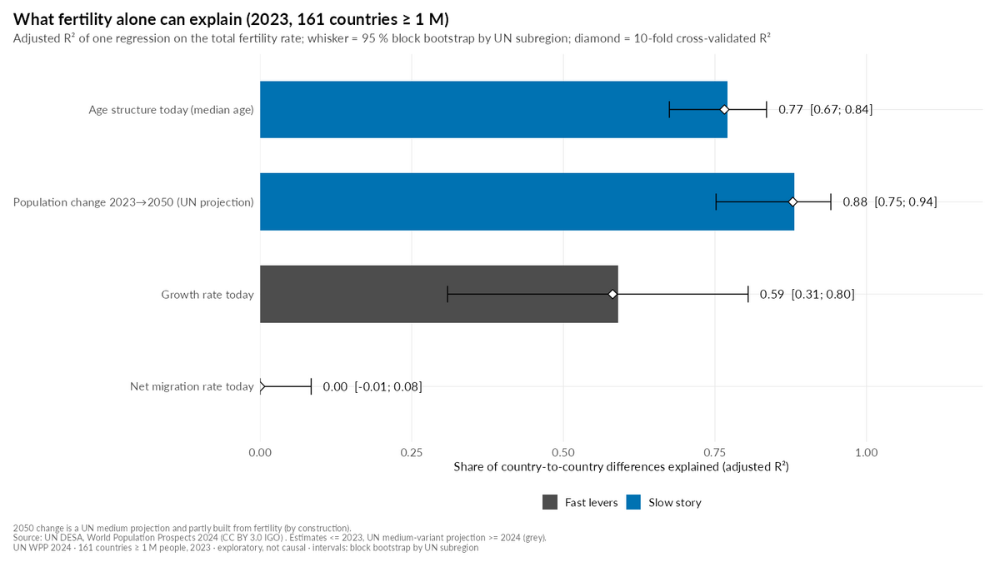

**`figures/review/q2/q2_13_r2_by_year.png`** (figura de revisión, no final)

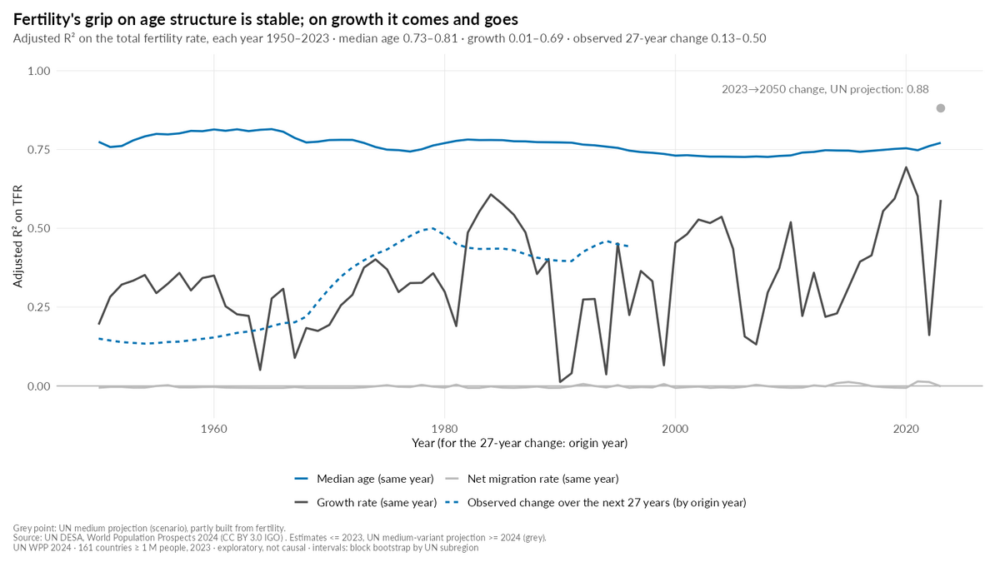

In [92]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_01_scorecard", "q2_13_r2_by_year"))

#### Lectura de resultados · §2 S1 · Scorecard "qué explica la fecundidad sola" (H6, pre-specified)

*Texto de `docs/resultados_q2.md` §2 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Cuatro regresiones simples sobre la TFR de 2023, con las salidas fijadas antes del cálculo (H6). IC por bloques de subregión, BCa iid, validación cruzada 10-fold × 20 y por bloques (dejar fuera una subregión entera), más spline, 237 países, 1990 y sin Golfo.

| Salida (2023, 161) | R² ajustado | IC bloques 95 % | iid BCa | VC 10-fold × 20 | VC por subregión | Spline 3 gl | 237 países | 1990 (observado) | Sin Golfo |
|---|---|---|---|---|---|---|---|---|---|
| Edad mediana | **0,771** | [0,675; 0,835] | [0,728; 0,806] | 0,766 | 0,738 | 0,864 | 0,714 | 0,772 | 0,775 |
| Cambio % 2023→2050 (proyección) | **0,881** | [0,752; 0,941] | [0,824; 0,911] | 0,878 | 0,868 | 0,890 | 0,760 | 0,397 (cambio 1990→2017) | 0,915 |
| Crecimiento | **0,590** | [0,309; 0,805] | [0,439; 0,703] | 0,581 | 0,551 | 0,596 | 0,357 | 0,012 | 0,689 |
| CNMR | **−0,001** | [−0,007; 0,084] | [−0,006; 0,038] | −0,027 | −0,061 | −0,001 | 0,013 | −0,006 | −0,005 |

Claves: `r2_tfr_medage`, `r2_tfr_chg2050`, `r2_tfr_growth`, `r2_tfr_cnmr` (+ `_cv`, `_cv_loso`). Figura: `q2_01_scorecard.png`.

**Estabilidad en el tiempo (exploratorio).** El mismo R² calculado en cada año 1950–2023 y el análogo **observado** del cambio a 27 años:

| Serie (161 países, estimaciones) | Mínimo | Mediana | Máximo | Clave |
|---|---|---|---|---|
| Edad mediana ~ TFR, cada año | 0,726 (2006) | 0,763 | 0,815 (1965) | `r2_tfr_medage_by_year` |
| Crecimiento ~ TFR, cada año | 0,012 (1990) | 0,327 | 0,694 (2020) | `r2_tfr_growth_by_year` |
| CNMR ~ TFR, cada año | −0,006 | −0,004 | 0,014 | `r2_tfr_cnmr_by_year` |
| Cambio % observado a 27 años ~ TFR del año de origen (1950–1996) | 0,134 (1954) | 0,396 | 0,500 (1979) | `r2_tfr_chg27_observed` |

Figura: `q2_13_r2_by_year.png`.

**Lectura de resultados.**
- H6 se cumple con la estimación puntual (0,771 ≥ 0,7; 0,881 ≥ 0,7; 0,590 ≤ 0,6; −0,001 ≤ 0,1) **y** con la VC (0,766 / 0,878 / 0,581 / −0,027). No hay sobreajuste: la VC baja menos de 0,01.
- El IC por bloques es entre 1,5 y 2,5 veces más ancho que el iid (crecimiento: 0,31–0,80 frente a 0,44–0,70). Esto es lo esperado cuando los vecinos se parecen. Con bloques, el límite inferior de la edad mediana (0,675) queda bajo el umbral de 0,7; el puntual y la VC no.
- **Lento vs rápido, con datos de 74 años:** la edad mediana se explica entre el 73 % y el 81 % en **todos** los años; el crecimiento, entre el 1 % y el 69 % según el año. Hubo años de choque: 1990 (Kuwait −71 %, Liberia −30 %), 1991 (0,04) y 2022 (0,16, el año de la guerra en Ucrania). El 0,59 de 2023 es una foto, no una constante.
- **El 0,88 del cambio a 2050 es en buena parte por construcción.** En la historia observada, la TFR explicó como mucho el 50 % del cambio de los 27 años siguientes (mediana 40 %). La proyección Medium hace que el futuro dependa de la fecundidad mucho más que el pasado. Va al pie de la figura: *"partly by construction"*.
- Con los 237 países, el crecimiento baja a 0,36: los microestados con migración extrema rompen la relación.

### Q2 · §3 Escalera de R²: identidad contable (nota) vs prueba "fuera de tiempo"

*Descriptive (identidad contable; nota al pie)* · `R/03_q2_un_numero.R` líneas 520–603

In [93]:
# =============================================================================
# 3. Escalera de R²: identidad contable (nota) vs prueba "fuera de tiempo"
#    Qué: crecimiento ~ TFR → +CDR → +CNMR el mismo año (0,59 → 0,70 → 0,99) y,
#    como comparación honesta, el mismo modelo prediciendo el crecimiento 10 años
#    después en otros años (entrenar 2003→2011–13, probar 2013→2021–23).
#    Por qué: el 0,99 es por construcción (crecimiento = natalidad − mortalidad +
#    migración); solo la prueba fuera de tiempo dice algo sobre información útil.
# =============================================================================

escalera_mismo_anio <- tibble(
  modelo = c("TFR", "TFR + CDR", "TFR + CDR + CNMR", "CBR + CDR + CNMR"),
  r2 = c(r2_lm(d23, "PopGrowthRate", "TFR"),
         r2_lm(d23, "PopGrowthRate", c("TFR", "CDR")),
         r2_lm(d23, "PopGrowthRate", c("TFR", "CDR", "CNMR_raw")),
         r2_lm(d23, "PopGrowthRate", c("CBR", "CDR", "CNMR_raw")))
) |> mutate(tipo = "same year (identity)", origen_entrenamiento = 2023L, origen_prueba = 2023L)

# Fuera de tiempo (memo de series de tiempo §3.5): predictores en t0, salida =
# crecimiento medio de t0+8 a t0+10; entrenar con t0 y evaluar con t0+10.
par_fuera_tiempo <- function(t0, h = 10) {
  verificar_ventana(c(t0, t0 + h))
  x <- paises_1m(anios = t0) |> select(ISO3_code, TFR, CDR, CNMR, g0 = PopGrowthRate, MedianAgePop)
  y <- paises_1m(anios = (t0 + h - 2):(t0 + h)) |> group_by(ISO3_code) |>
    summarise(gh = mean(PopGrowthRate), .groups = "drop")
  inner_join(x, y, by = "ISO3_code")
}
MODELOS_FT <- list(`TFR` = "TFR", `TFR + CDR` = c("TFR", "CDR"), `TFR + CDR + CNMR` = c("TFR", "CDR", "CNMR"),
                   `Median age only` = "MedianAgePop", `Today's growth only` = "g0")
escalera_fuera <- map_dfr(c(1980L, 1990L, 2003L), function(t0) {
  tr <- par_fuera_tiempo(t0); te <- par_fuera_tiempo(t0 + 10L)
  imap_dfr(MODELOS_FT, function(x, nm) {
    m <- stats::lm(stats::reformulate(x, "gh"), data = tr)
    tibble(modelo = nm, r2 = r2_fuera(te$gh, stats::predict(m, newdata = te)),
           origen_entrenamiento = t0, origen_prueba = t0 + 10L)
  })
}) |> mutate(tipo = "10 years later (out of time)")
tabla_escalera <- bind_rows(escalera_mismo_anio, escalera_fuera) |>
  select(tipo, origen_entrenamiento, origen_prueba, modelo, r2)
print(tabla_escalera |> mutate(r2 = round(r2, 3)), n = 30)
write_parquet(tabla_escalera, ruta_parquet_q2("escalera"))

anotar("r2_ladder_tfr_cdr", escalera_mismo_anio$r2[2], "R2", "0.00",
       "Adjusted R² of growth rate 2023 on TFR + CDR (same year); step of the accounting ladder, not a finding",
       FILTRO_1M_2023, "T8.3", c("slide3.build1.footnote"), method = "descriptive", status = "descriptive",
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("r2_all", escalera_mismo_anio$r2[3], "R2", "0.00",
       "Adjusted R² of growth rate 2023 on TFR + CDR + net migration rate: births − deaths + migration = growth (accounting identity, by construction)",
       FILTRO_1M_2023, "T8.3", c("slide3.build1.footnote", "fig07"), method = "descriptive", status = "descriptive",
       sens_note = sprintf("with CBR instead of TFR: %.4f; max |growth − (CBR − CDR + CNMR)/10| = %.4f pp",
                           escalera_mismo_anio$r2[4], resid_identidad),
       n = N_PAISES_1M, universe = UNIVERSO_1M)
ft <- escalera_fuera |> group_by(modelo) |>
  summarise(v = r2[origen_entrenamiento == 2003], lo = min(r2), hi = max(r2), .groups = "drop")
claves_ft <- c(`TFR` = "r2_oot_tfr", `TFR + CDR` = "r2_oot_tfr_cdr", `TFR + CDR + CNMR` = "r2_oot_tfr_cdr_cnmr",
               `Median age only` = "r2_oot_medage", `Today's growth only` = "r2_oot_growth_today")
for (i in seq_len(nrow(ft))) {
  anotar(claves_ft[[ft$modelo[i]]], ft$v[i], "R2", "0.00",
         sprintf(paste0("Out-of-time R² for mean growth 8–10 years later: model '%s' trained on 2003 indicators ",
                        "→ growth 2011–13, tested on 2013 indicators → growth 2021–23 (estimates only)"), ft$modelo[i]),
         "161 countries ≥ 1 M; UN estimates 1980–2023", "T8.4", USO_NB, method = "cv_r2",
         sens_low = ft$lo[i], sens_high = ft$hi[i],
         sens_note = "range over training origins 1980, 1990 and 2003 (test 10 years later)",
         status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)
}

p_esc <- tabla_escalera |>
  filter(modelo %in% c("TFR", "TFR + CDR", "TFR + CDR + CNMR"),
         tipo == "same year (identity)" | origen_entrenamiento == 2003) |>
  mutate(tipo = factor(tipo, levels = c("same year (identity)", "10 years later (out of time)"),
                       labels = c("Same year (2023): an accounting identity",
                                  "Growth 10 years later (train 2003, test 2013→2021–23)")),
         modelo = factor(modelo, levels = c("TFR", "TFR + CDR", "TFR + CDR + CNMR"))) |>
  ggplot(aes(modelo, r2, fill = tipo)) +
  geom_col(position = position_dodge(width = 0.75), width = 0.7) +
  geom_text(aes(label = sprintf("%.2f", r2)), position = position_dodge(width = 0.75), vjust = -0.4, size = 4.8) +
  scale_fill_manual(values = c(COLOR_GRIS_CLARO, COLOR_NACIMIENTOS), name = NULL) +
  scale_y_continuous(limits = c(0, 1.08), breaks = seq(0, 1, 0.25)) +
  labs(title = "Adding the other components reaches 0.99 only by construction",
       subtitle = "Growth = births − deaths + net migration. Predicting growth a decade later, today's migration adds nothing.",
       x = "Predictors of the population growth rate", y = "R² (adjusted / out of time)",
       caption = pie_q2(FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_esc, "q2_02_identity_vs_out_of_time")

# A tibble: 19 × 5
   tipo                         origen_entrenamiento origen_prueba modelo                  r2
   <chr>                                       <int>         <int> <chr>                <dbl>
 1 same year (identity)                         2023          2023 TFR                  0.59 
 2 same year (identity)                         2023          2023 TFR + CDR            0.697
 3 same year (identity)                         2023          2023 TFR + CDR + CNMR     0.986
 4 same year (identity)                         2023          2023 CBR + CDR + CNMR     1    
 5 10 years later (out of time)                 1980          1990 TFR                  0.344
 6 10 years later (out of time)                 1980          1990 TFR + CDR            0.372
 7 10 years later (out of time)                 1980          1990 TFR + CDR + CNMR     0.368
 8 10 years later (out of time)                 1980          1990 Median age only      0.283
 9 10 years later (out of time)          

**`figures/review/q2/q2_02_identity_vs_out_of_time.png`** (figura de revisión, no final)

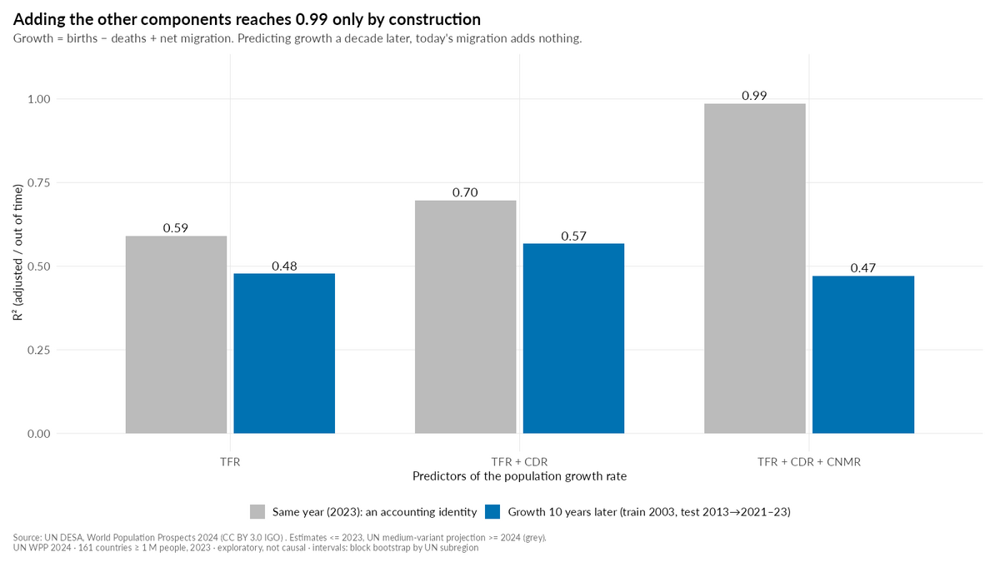

In [94]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_02_identity_vs_out_of_time"))

#### Lectura de resultados · §2.1 La escalera: identidad (nota al pie) vs prueba fuera de tiempo

*Texto de `docs/resultados_q2.md` §2.1 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Mismo año: crecimiento ~ TFR → +CDR → +CNMR. Fuera de tiempo: el mismo modelo, entrenado con indicadores de 2003 → crecimiento 2011–13, se prueba con 2013 → crecimiento 2021–23 (orígenes 1980 y 1990 como sensibilidad).

| Modelo | Mismo año 2023 (identidad) | 10 años después (2003→2013) | Rango de orígenes 1980 / 1990 / 2003 |
|---|---|---|---|
| TFR | 0,590 | 0,478 | 0,344–0,478 |
| TFR + CDR | 0,697 (`r2_ladder_tfr_cdr`) | **0,567** | 0,372–0,567 |
| TFR + CDR + CNMR | **0,986** (`r2_all`; con CBR 1,000) | 0,471 | 0,368–0,471 |
| Edad mediana sola | — | 0,473 | 0,283–0,473 |
| Crecimiento de hoy | — | −0,158 | −1,735–0,004 |

Figura: `q2_02_identity_vs_out_of_time.png`. Claves `r2_oot_*`.

**Lectura.** El 0,99 es la identidad contable (crecimiento = natalidad − mortalidad + migración); con la CBR en vez de la TFR da 1,000. Para el crecimiento de 10 años después, añadir la migración de hoy **empeora** la predicción (0,567 → 0,471) y el crecimiento de hoy predice peor que la media (−0,16). Se reproduce el memo de series de tiempo (0,48 / 0,57 / 0,47).

### Q2 · §4 La tasa bruta de mortalidad cambió de significado (H13, pre-specified)

*Pre-specified (H13)* · `R/03_q2_un_numero.R` líneas 604–698

In [95]:
# =============================================================================
# 4. La tasa bruta de mortalidad cambió de significado (H13, pre-specified)
#    Qué: ρ de Spearman entre países de CDR y LEx en cada año 1950–2023 con banda
#    por bloques de subregión; par "misma CDR, máxima diferencia de LEx" por regla.
#    Por qué: un mismo indicador puede medir cosas distintas según la etapa; en
#    poblaciones envejecidas la CDR mide edad, no salud.
# =============================================================================

ANIOS_EST <- ANIO_INICIO_DATOS:ANIO_FIN_ESTIMACION
panel_cdr <- paises_1m(periodo = "estimacion") |> select(ISO3_code, subregion, Time, CDR, LEx, MedianAgePop)
ancho_cdr <- panel_cdr |>
  pivot_wider(id_cols = c(ISO3_code, subregion), names_from = Time, values_from = c(CDR, LEx, MedianAgePop))
stat_rho_anual <- function(d) {
  setNames(vapply(ANIOS_EST, function(a) stats::cor(d[[paste0("CDR_", a)]], d[[paste0("LEx_", a)]],
                                                     method = "spearman"), numeric(1)), ANIOS_EST)
}
set.seed(SEMILLA)
bs_rho <- bootstrap_bloques(ancho_cdr, stat_rho_anual, B = B_Q2, semilla = SEMILLA)

rho_proy <- paises_1m(periodo = "proyeccion") |> group_by(Time) |>
  summarise(rho_cdr_lex = stats::cor(CDR, LEx, method = "spearman"),
            r_pearson_cdr_lex = stats::cor(CDR, LEx),
            rho_cdr_medage = stats::cor(CDR, MedianAgePop, method = "spearman"), n = n(), .groups = "drop")
tabla_rho <- panel_cdr |> group_by(Time) |>
  summarise(r_pearson_cdr_lex = stats::cor(CDR, LEx),
            rho_cdr_medage = stats::cor(CDR, MedianAgePop, method = "spearman"), n = n(), .groups = "drop") |>
  mutate(rho_cdr_lex = unname(bs_rho$valor), ci_low = unname(bs_rho$ci_low), ci_high = unname(bs_rho$ci_high)) |>
  bind_rows(rho_proy |> mutate(ci_low = NA_real_, ci_high = NA_real_)) |>
  mutate(periodo_en = etiqueta_periodo(Time)) |>
  select(Time, rho_cdr_lex, ci_low, ci_high, r_pearson_cdr_lex, rho_cdr_medage, n, periodo_en)
write_parquet(tabla_rho, ruta_parquet_q2("rho_cdr_lex"))

rho_iid <- lapply(c(`1950` = 1950, `2023` = 2023), function(a) {
  d <- corte_anio(a, "1m")
  set.seed(SEMILLA)
  bootstrap_bca(d, function(x) stats::cor(x$CDR, x$LEx, method = "spearman"), B = B_Q2, semilla = SEMILLA)
})
r_1950 <- extraer_ic(bs_rho, "1950"); r_2023 <- extraer_ic(bs_rho, "2023")
h13_ok <- r_1950$valor < -0.9 && r_2023$ci_low <= 0 && r_2023$ci_high >= 0
anio_cruce0 <- min(tabla_rho$Time[tabla_rho$Time <= ANIO_FIN_ESTIMACION & tabla_rho$rho_cdr_lex >= 0])
message(sprintf("ρ(CDR, LEx): 1950 = %.3f [%.3f; %.3f]; 2023 = %.3f [%.3f; %.3f]; primer año >= 0: %d",
                r_1950$valor, r_1950$ci_low, r_1950$ci_high, r_2023$valor, r_2023$ci_low, r_2023$ci_high, anio_cruce0))

for (a in c("1950", "2023")) {
  r <- extraer_ic(bs_rho, a)
  anotar(paste0("rho_cdr_lex_", a), r$valor, "rho", "0.00",
         sprintf("Spearman correlation across countries between crude death rate and life expectancy at birth, %s", a),
         sprintf("161 countries ≥ 1 M (2023 population); UN estimates for %s", a), "T8.5",
         c("slide3.build1.footnote", "narration.s3"), ic = r, ic_iid = rho_iid[[a]],
         sens_low = if (a == "2023") tabla_rho$r_pearson_cdr_lex[tabla_rho$Time == 2023] else NA,
         sens_high = if (a == "2023") r$valor else NA,
         sens_note = sprintf("Pearson r = %.3f", tabla_rho$r_pearson_cdr_lex[tabla_rho$Time == as.integer(a)]),
         status = "pre-specified", hypothesis_id = "H13", n = N_PAISES_1M, universe = UNIVERSO_1M,
         say = if (r$ci_low <= 0 && r$ci_high >= 0) "about zero" else
           if (r$valor < -0.9) "almost perfectly negative" else sprintf("%.1f", r$valor))
}
set.seed(SEMILLA)
bs_rho_med <- bootstrap_bloques(corte_anio(2023, "1m"), function(d) stats::cor(d$CDR, d$MedianAgePop, method = "spearman"),
                                B = B_Q2, semilla = SEMILLA)
anotar("rho_cdr_medage_2023", bs_rho_med$valor, "rho", "0.00",
       "Spearman correlation across countries between crude death rate and median age, 2023 (the CDR now tracks age)",
       FILTRO_1M_2023, "T8.5", c("slide3.build1.footnote"), ic = bs_rho_med,
       status = "exploratory", hypothesis_id = "H13", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("yr_rho_cdr_lex_cross0", anio_cruce0, "year", "0",
       "First year 1950–2023 in which the cross-country Spearman correlation of CDR and life expectancy is ≥ 0",
       "161 countries ≥ 1 M; UN estimates 1950–2023", "T8.5", USO_NB, method = "descriptive",
       status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("rho_cdr_lex_2050", rho_proy$rho_cdr_lex[rho_proy$Time == 2050], "rho", "0.00",
       "Spearman correlation across countries between CDR and life expectancy in 2050 (UN medium projection, a scenario)",
       "161 countries ≥ 1 M; UN medium projection 2050", "T8.5", USO_NB, method = "descriptive",
       status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M,
       sens_note = sprintf("projection, no interval; 2060: %.2f", rho_proy$rho_cdr_lex[rho_proy$Time == 2060]))

p_rho <- ggplot(tabla_rho, aes(Time, rho_cdr_lex)) +
  annotate("rect", xmin = ANIO_INICIO_PROYECCION - 0.5, xmax = ANIO_MAX_VALIDO, ymin = -Inf, ymax = Inf,
           fill = COLOR_PROYECCION_SOMBRA) +
  geom_hline(yintercept = 0, colour = "black", linewidth = 0.4) +
  geom_vline(xintercept = ANIO_FIN_ESTIMACION + 0.5, colour = COLOR_PROYECCION, linetype = "dashed") +
  geom_ribbon(data = \(x) filter(x, Time <= ANIO_FIN_ESTIMACION), aes(ymin = ci_low, ymax = ci_high),
              fill = COLOR_NACIMIENTOS, alpha = 0.22) +
  geom_line(data = \(x) filter(x, Time <= ANIO_FIN_ESTIMACION), colour = COLOR_NACIMIENTOS, linewidth = 1.1) +
  geom_line(data = \(x) filter(x, Time >= ANIO_INICIO_PROYECCION), colour = COLOR_PROYECCION, linewidth = 1,
            linetype = "22") +
  annotate("text", x = 1952, y = r_1950$valor + 0.1, hjust = 0, size = 4.6,
           label = sprintf("1950: %.2f [%.2f; %.2f]", r_1950$valor, r_1950$ci_low, r_1950$ci_high)) +
  annotate("text", x = 2021, y = r_2023$ci_high + 0.12, hjust = 1, size = 4.6,
           label = sprintf("2023: %.2f [%.2f; %.2f]", r_2023$valor, r_2023$ci_low, r_2023$ci_high)) +
  annotate("text", x = 2062, y = -0.9, label = "UN medium projection\n(scenario, no band)", colour = "#777777", size = 4.2) +
  scale_y_continuous(limits = c(-1, 1), breaks = seq(-1, 1, 0.5)) +
  labs(title = "The crude death rate stopped tracking life expectancy",
       subtitle = "Spearman correlation across countries of CDR and life expectancy at birth, each year; band = 95 % block bootstrap by UN subregion",
       x = NULL, y = "Spearman ρ (CDR, life expectancy)", caption = pie_q2(FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_rho, "q2_03_rho_cdr_lex_by_year")

ρ(CDR, LEx): 1950 = -0.974 [-0.981; -0.939]; 2023 = 0.067 [-0.305; 0.321]; primer año >= 0: 2022



**`figures/review/q2/q2_03_rho_cdr_lex_by_year.png`** (figura de revisión, no final)

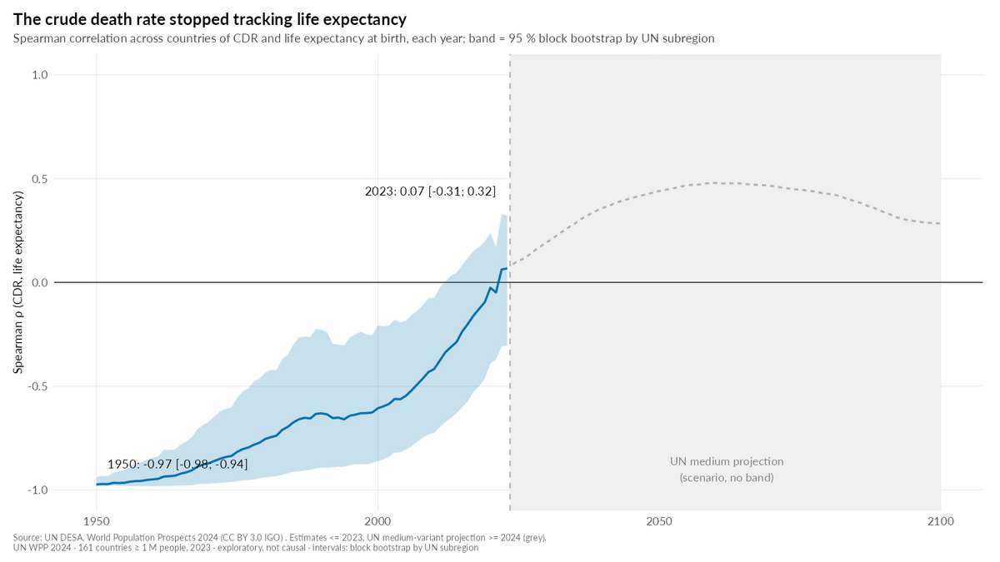

In [96]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_03_rho_cdr_lex_by_year"))

#### Lectura de resultados · §3 La tasa bruta de mortalidad cambió de significado (H13, pre-specified)

*Texto de `docs/resultados_q2.md` §3 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** ρ de Spearman entre países de CDR y LEx en cada año 1950–2023, con banda por bloques; 2024–2100 solo como línea gris (escenario, sin banda). Par "misma CDR, máxima diferencia de LEx" elegido por regla entre 12 880 pares.

| Cifra | Valor | IC bloques | iid BCa | Clave |
|---|---|---|---|---|
| ρ(CDR, LEx) 1950 | **−0,974** | [−0,981; −0,939] | [−0,983; −0,963] | `rho_cdr_lex_1950` |
| ρ(CDR, LEx) 2023 | **0,067** | [−0,306; 0,321] | [−0,087; 0,222] | `rho_cdr_lex_2023` (Pearson 0,032) |
| ρ(CDR, edad mediana) 2023 | 0,457 | [0,053; 0,726] | — | `rho_cdr_medage_2023` |
| Primer año con ρ ≥ 0 | 2022 | — | — | `yr_rho_cdr_lex_cross0` |
| ρ(CDR, LEx) 2050 (proyección Medium) | 0,441 (2060: 0,48) | sin IC (escenario) | — | `rho_cdr_lex_2050` |
| Portugal / Chad: CDR | 11,1 / 11,0 por 1 000 | — | — | `cdr_prt`, `cdr_tcd` |
| Brecha de LEx Portugal − Chad | 27,3 años (82,4 vs 55,1) | — | — | `lex_gap_prt_tcd` |

Figura: `q2_03_rho_cdr_lex_by_year.png`.

**Lectura.** H13 se confirma: −0,97 en 1950 (< −0,9) y un IC de 2023 que contiene el 0 con los dos métodos. La correlación se acerca a cero de forma continua y cruza el 0 en 2022. El IC por bloques de 2023 es muy ancho (−0,31 a 0,32): según qué regiones entren, la relación puede salir algo negativa o algo positiva. Lo robusto es que **ya no es −0,97**. La CDR sube con la edad mediana (0,46): en 2023 mide envejecimiento, no salud. El par Portugal–Chad sale por regla (|ΔCDR| ≤ 0,1, máxima |ΔLEx|), no a mano.

### Q2 · §5 S2 · Gemelos demográficos por regla (ilustración, familia F3)

*Exploratory, familia F3 (ilustración por regla, sin inferencia)* · `R/03_q2_un_numero.R` líneas 699–841

In [97]:
# =============================================================================
# 5. S2 · Gemelos demográficos por regla (ilustración, familia F3)
#    Qué: búsqueda exhaustiva entre los 12 880 pares de países >= 1 M; regla
#    principal |ΔTFR| <= 0,05 con máxima |Δ crecimiento|; regla 2 |ΔLEx| <= 0,2
#    con máxima |Δ edad mediana|; y otras reglas de los memos (misma CDR, etc.).
#    Por qué: ejemplos elegidos por regla escrita en código, no a mano (ASA A).
# =============================================================================

d_gem <- corte_anio(2023, "1m") |> arrange(ISO3_code) |>
  select(ISO3_code, Location, TFR, PopGrowthRate, LEx, MedianAgePop, CDR, NatChangeRT, CNMR)
v_a <- d_gem |> rename_with(\(x) paste0(x, "_a"))
v_b <- d_gem |> rename_with(\(x) paste0(x, "_b"))
pares <- tidyr::crossing(iso_a = d_gem$ISO3_code, iso_b = d_gem$ISO3_code) |>
  filter(iso_a < iso_b) |>
  left_join(v_a, by = c("iso_a" = "ISO3_code_a")) |>
  left_join(v_b, by = c("iso_b" = "ISO3_code_b"))
N_PARES <- nrow(pares)
stopifnot(N_PARES == choose(N_PAISES_1M, 2))

#' Aplica una regla de gemelos: |Δ var_igual| <= tol y orden por |Δ var_dif|.
gemelos_regla <- function(pares, var_igual, tol, var_dif, regla, regla_en, top = 5, condicion = NULL) {
  ia <- paste0(var_igual, "_a"); ib <- paste0(var_igual, "_b")
  da <- paste0(var_dif, "_a"); db <- paste0(var_dif, "_b")
  x <- pares[abs(pares[[ia]] - pares[[ib]]) <= tol + 1e-9, , drop = FALSE]
  if (!is.null(condicion)) x <- x[condicion(x), , drop = FALSE]
  x$dif_abs <- abs(x[[da]] - x[[db]])
  x <- x[order(-x$dif_abs, x$iso_a, x$iso_b), , drop = FALSE]
  x <- utils::head(x, top)
  tibble(regla = regla, regla_en = regla_en, rank = seq_len(nrow(x)), iso_a = x$iso_a, iso_b = x$iso_b,
         pais_a = x$Location_a, pais_b = x$Location_b, var_igual = var_igual, igual_a = x[[ia]],
         igual_b = x[[ib]], var_dif = var_dif, dif_a = x[[da]], dif_b = x[[db]], dif_abs = x$dif_abs)
}
signo_opuesto_nat <- function(x) sign(x$NatChangeRT_a) != sign(x$NatChangeRT_b)
tabla_gemelos <- bind_rows(
  gemelos_regla(pares, "TFR", 0.05, "PopGrowthRate", "R1",
                "Same fertility (|ΔTFR| ≤ 0.05), largest gap in growth rate"),
  gemelos_regla(pares, "LEx", 0.2, "MedianAgePop", "R2",
                "Same life expectancy (|ΔLEx| ≤ 0.2), largest gap in median age"),
  gemelos_regla(pares, "CDR", 0.1, "LEx", "R3",
                "Same crude death rate (|ΔCDR| ≤ 0.1), largest gap in life expectancy"),
  gemelos_regla(pares, "TFR", 0.03, "NatChangeRT", "R4",
                "Same fertility (|ΔTFR| ≤ 0.03), opposite sign of natural change, the grower has net emigration",
                condicion = function(x) signo_opuesto_nat(x) &
                  ((x$NatChangeRT_a > 0 & x$CNMR_a < 0 & x$PopGrowthRate_a > 0) |
                     (x$NatChangeRT_b > 0 & x$CNMR_b < 0 & x$PopGrowthRate_b > 0))),
  gemelos_regla(pares, "MedianAgePop", 0.3, "TFR", "R5",
                "Same median age (|Δ| ≤ 0.3 years), largest gap in fertility"),
  gemelos_regla(pares, "PopGrowthRate", 0.02, "NatChangeRT", "R6",
                "Same growth rate (|Δ| ≤ 0.02 pp), opposite sign of natural change",
                condicion = signo_opuesto_nat)
)
print(tabla_gemelos |> select(regla, rank, iso_a, iso_b, igual_a, igual_b, dif_a, dif_b) |>
        mutate(across(where(is.numeric), \(x) round(x, 2))), n = 40)
write_parquet(tabla_gemelos, ruta_parquet_q2("gemelos"))

t1 <- tabla_gemelos |> filter(regla == "R1", rank == 1)
if (!setequal(c(t1$iso_a, t1$iso_b), c("ARE", "BLR"))) {
  warning("La regla R1 ya no da Emiratos–Bielorrusia: revisar las claves twin_*_are/blr y el guion.", call. = FALSE)
}
valor_pais <- function(iso, var) d_gem[[var]][d_gem$ISO3_code == iso]
anotar("n_pairs_twins", N_PARES, "pairs", "#,##0",
       "Number of country pairs searched exhaustively for the twin rules", FILTRO_1M_2023, "T8.6",
       c("slide3.build2"), method = "none_census", status = "descriptive", n = N_PAISES_1M, universe = UNIVERSO_1M)
tw_out <- tabla_gemelos |> filter(regla == "R1") |>
  transmute(rank, iso_a, iso_b, country_a = pais_a, country_b = pais_b, tfr_a = igual_a, tfr_b = igual_b,
            growth_a = dif_a, growth_b = dif_b, growth_gap = dif_abs)
anotar("twins", as.data.frame(tw_out), NA, "text",
       "Top-5 twin pairs by rule: |ΔTFR| ≤ 0.05 and largest |Δ population growth rate|, 2023",
       FILTRO_1M_2023, "T8.6", c("slide3.build2", "fig08"), method = "descriptive", status = "exploratory",
       sens_note = sprintf("chosen by rule from %s pairs (≥ 1 M); illustration, no inference (family F3)",
                           format(N_PARES, big.mark = ",")),
       n = N_PAISES_1M, universe = UNIVERSO_1M)
for (cl in list(c("twin_tfr_are", "ARE", "TFR", "Total fertility rate, United Arab Emirates, 2023", "children per woman", "0.00"),
                c("twin_tfr_blr", "BLR", "TFR", "Total fertility rate, Belarus, 2023", "children per woman", "0.00"),
                c("twin_growth_are", "ARE", "PopGrowthRate", "Population growth rate, United Arab Emirates, 2023", "%", "+0.00"),
                c("twin_growth_blr", "BLR", "PopGrowthRate", "Population growth rate, Belarus, 2023", "%", "+0.00"))) {
  v <- valor_pais(cl[2], cl[3])
  anotar(cl[1], v, cl[5], cl[6], paste0(cl[4], " (top pair of the twin rule |ΔTFR| ≤ 0.05)"),
         sprintf("%s; UN estimates 2023", nombre_pais(cl[2])), "T8.6", c("slide3.build2", "narration.s3"),
         method = "descriptive", status = "descriptive", n = 1, universe = UNIVERSO_1M,
         say = if (cl[1] == "twin_growth_are") decir_entero(v) else NA)
}
tw2 <- tabla_gemelos |> filter(regla == "R2") |>
  transmute(rank, iso_a, iso_b, country_a = pais_a, country_b = pais_b, lex_a = igual_a, lex_b = igual_b,
            medage_a = dif_a, medage_b = dif_b, medage_gap = dif_abs)
anotar("twins_lex_medage", as.data.frame(tw2), NA, "text",
       "Top-5 twin pairs by rule: |Δ life expectancy| ≤ 0.2 years and largest |Δ median age|, 2023",
       FILTRO_1M_2023, "T8.6", USO_NB, method = "descriptive", status = "exploratory",
       sens_note = sprintf("chosen by rule from %s pairs (≥ 1 M); illustration (F3)", format(N_PARES, big.mark = ",")),
       n = N_PAISES_1M, universe = UNIVERSO_1M)
otras <- tabla_gemelos |> filter(regla %in% c("R4", "R5", "R6"), rank == 1) |>
  transmute(rule = regla_en, iso_a, iso_b, same_a = igual_a, same_b = igual_b, differ_var = var_dif,
            differ_a = dif_a, differ_b = dif_b)
anotar("twins_other_rules", as.data.frame(otras), NA, "text",
       "Top pair of three further twin rules from the demography memo (same fertility / median age / growth)",
       FILTRO_1M_2023, "T8.6", USO_NB, method = "descriptive", status = "exploratory",
       sens_note = "illustration only (F3); full top-5 in data/processed/resultados_q2_gemelos.parquet",
       n = N_PAISES_1M, universe = UNIVERSO_1M)

# Par de la CDR (pie del scorecard) por regla R3.
t3 <- tabla_gemelos |> filter(regla == "R3", rank == 1)
if (!setequal(c(t3$iso_a, t3$iso_b), c("PRT", "TCD"))) {
  warning("La regla R3 ya no da Portugal–Chad: revisar las claves cdr_prt / cdr_tcd.", call. = FALSE)
}
anotar("cdr_prt", valor_pais("PRT", "CDR"), "per 1,000", "0.0",
       "Crude death rate, Portugal, 2023 (top pair of rule |ΔCDR| ≤ 0.1 with largest |Δ life expectancy|)",
       "Portugal; UN estimates 2023", "T8.5", c("slide3.build1.footnote"), method = "descriptive",
       status = "descriptive", n = 1, universe = UNIVERSO_1M,
       sens_note = sprintf("life expectancy %.1f years; median age %.1f", valor_pais("PRT", "LEx"), valor_pais("PRT", "MedianAgePop")))
anotar("cdr_tcd", valor_pais("TCD", "CDR"), "per 1,000", "0.0",
       "Crude death rate, Chad, 2023 (top pair of rule |ΔCDR| ≤ 0.1 with largest |Δ life expectancy|)",
       "Chad; UN estimates 2023", "T8.5", c("slide3.build1.footnote"), method = "descriptive",
       status = "descriptive", n = 1, universe = UNIVERSO_1M,
       sens_note = sprintf("life expectancy %.1f years; median age %.1f", valor_pais("TCD", "LEx"), valor_pais("TCD", "MedianAgePop")))
anotar("lex_gap_prt_tcd", valor_pais("PRT", "LEx") - valor_pais("TCD", "LEx"), "years", "0",
       "Gap in life expectancy at birth between Portugal and Chad, 2023 (same crude death rate)",
       "Portugal and Chad; UN estimates 2023", "T8.5", c("slide3.build1.footnote"), method = "descriptive",
       status = "descriptive", n = 2, universe = UNIVERSO_1M,
       sens_note = sprintf("chosen by rule from %s pairs", format(N_PARES, big.mark = ",")))

# Figura de revisión: gemelos R1 y R2 (pesas).
p_gem <- function(regla_id, xlab, titulo, fmt_igual) {
  x <- tabla_gemelos |> filter(regla == regla_id) |>
    mutate(par = sprintf("%s – %s\n(%s %s vs %s)", iso_a, iso_b, sub("_.*", "", var_igual),
                         sprintf(fmt_igual, igual_a), sprintf(fmt_igual, igual_b)),
           par = factor(par, levels = rev(par)))
  ggplot(x, aes(y = par)) +
    geom_segment(aes(x = dif_a, xend = dif_b, yend = par), colour = COLOR_GRIS_CLARO, linewidth = 2) +
    geom_point(aes(x = dif_a), colour = COLOR_NACIMIENTOS, size = 4) +
    geom_point(aes(x = dif_b), colour = COLOR_DEFUNCIONES, size = 4) +
    geom_text(aes(x = dif_a, label = iso_a), vjust = -1, size = 3.8) +
    geom_text(aes(x = dif_b, label = iso_b), vjust = -1, size = 3.8) +
    labs(title = titulo, x = xlab, y = NULL) + tema_q2()
}
p_tw <- (p_gem("R1", "Population growth rate 2023 (%)", "Same fertility, opposite growth", "%.2f") +
           geom_vline(xintercept = 0, linewidth = 0.3)) |
  p_gem("R2", "Median age 2023 (years)", "Same life expectancy, different age", "%.1f")
p_tw <- p_tw + plot_annotation(
  title = sprintf("Demographic twins chosen by rule from %s pairs (161 countries ≥ 1 M, 2023)", format(N_PARES, big.mark = ",")),
  subtitle = "Left: |ΔTFR| ≤ 0.05 with the largest gap in growth. Right: |Δ life expectancy| ≤ 0.2 years with the largest gap in median age.",
  caption = pie_q2("Illustration only (no inference).", FUENTE_ESTANDAR), theme = tema_q2())
guardar_q2(p_tw, "q2_04_twins_by_rule")

# A tibble: 30 × 8
   regla  rank iso_a iso_b igual_a igual_b dif_a dif_b
   <chr> <dbl> <chr> <chr>   <dbl>   <dbl> <dbl> <dbl>
 1 R1        1 ARE   BLR      1.2     1.21  3.7  -0.65
 2 R1        2 ARE   JPN      1.2     1.21  3.7  -0.48
 3 R1        3 SWZ   SYR      2.75    2.71  0.94  4.92
 4 R1        4 ARE   ITA      1.2     1.2   3.7  -0.22
 5 R1        5 ARE   MUS      1.2     1.24  3.7  -0.17
 6 R2        1 BIH   JOR     77.8    77.8  44.9  24.3 
 7 R2        2 ISR   PRT     82.4    82.4  29.2  46.2 
 8 R2        3 BIH   LBN     77.8    77.8  44.9  28.3 
 9 R2        4 HRV   SAU     78.6    78.7  44.8  29.2 
10 R2        5 BIH   PER     77.8    77.7  44.9  29.4 
11 R3        1 PRT   TCD     11.1    11.0  82.4  55.1 
12 R3        2 CAF   ESP      9.42    9.34 57.4  83.7 
13 R3        3 FIN   LSO     10.7    10.6  81.9  57.4 
14 R3        4 DNK   SSD      9.63    9.61 81.9  57.6 
15 R3        5 LSO   PRI     10.6    10.7  57.4  81.7 
16 R4        1 BGR   SLV      1.75    1.78 -5.

**`figures/review/q2/q2_04_twins_by_rule.png`** (figura de revisión, no final)

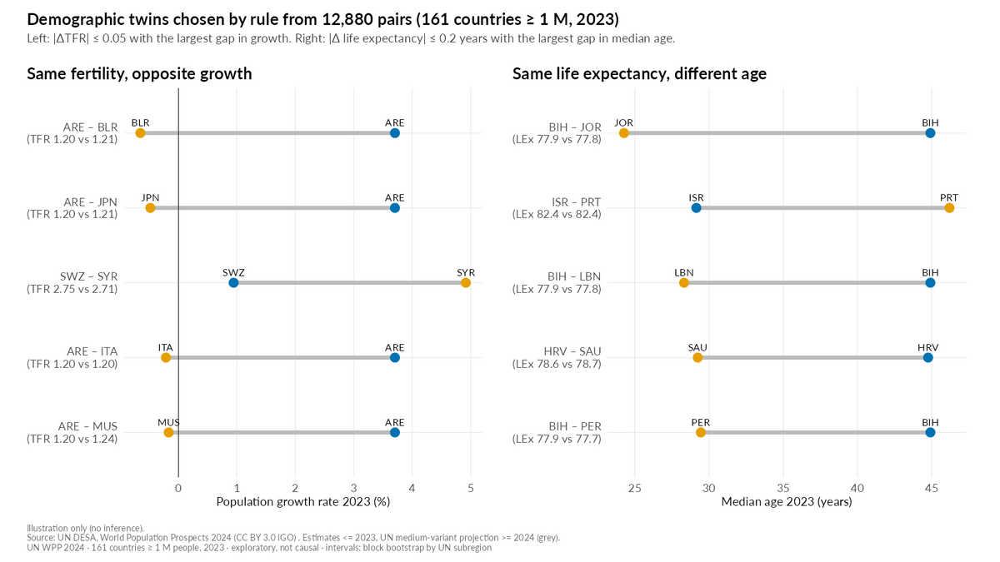

In [98]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_04_twins_by_rule"))

#### Lectura de resultados · §4 S2 · Gemelos demográficos por regla (ilustración, familia F3)

*Texto de `docs/resultados_q2.md` §4 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Búsqueda exhaustiva entre los **12 880** pares de países ≥ 1 M (`n_pairs_twins`). Se publica el top-5 de cada regla en `resultados_q2_gemelos.parquet`. Son ejemplos sin inferencia.

| Regla | Top 1 | Valores | Top 2–5 |
|---|---|---|---|
| R1 · \|ΔTFR\| ≤ 0,05, máxima \|Δ crecimiento\| (`twins`) | **EAU – Bielorrusia** | TFR 1,20 / 1,21 · crecimiento +3,70 % / −0,65 % | EAU–Japón, Esuatini–Siria, EAU–Italia, EAU–Mauricio |
| R2 · \|ΔLEx\| ≤ 0,2, máxima \|Δ edad mediana\| (`twins_lex_medage`) | Bosnia y Herzegovina – Jordania | LEx 77,9 / 77,8 · edad mediana 44,9 / 24,3 | Israel–Portugal (29,1 vs 46,2), Bosnia–Líbano, Croacia–Arabia Saudí, Bosnia–Perú |
| R3 · \|ΔCDR\| ≤ 0,1, máxima \|ΔLEx\| | **Portugal – Chad** | CDR 11,1 / 11,0 · LEx 82,4 / 55,1 | RCA–España, Finlandia–Lesoto, Dinamarca–Sudán del Sur, Lesoto–Puerto Rico |
| R4 · \|ΔTFR\| ≤ 0,03, saldo natural de signo opuesto y el que crece con emigración neta | Bulgaria – El Salvador | TFR 1,75 / 1,78 · saldo natural −5,9 / +8,2 ‰ | Jamaica–Letonia, Ecuador–Georgia… |
| R5 · \|Δ edad mediana\| ≤ 0,3, máxima \|ΔTFR\| | El Salvador – Uzbekistán | edad mediana 27,0 / 26,9 · TFR 1,78 / 3,50 | Guinea Ecuatorial–Timor-Leste… |
| R6 · \|Δ crecimiento\| ≤ 0,02 pp, saldo natural de signo opuesto | Estonia – Sudán | crecimiento 0,00 / 0,02 % · saldo natural −4,1 / +27,2 ‰ | España–Sudán, Georgia–Sudán, Lituania–México, India–Lituania |

Figura: `q2_04_twins_by_rule.png`. Claves: `twin_tfr_are` (1,20), `twin_tfr_blr` (1,21), `twin_growth_are` (+3,70), `twin_growth_blr` (−0,65), `twins_other_rules`.

**Lectura.** La regla principal reproduce EAU–Bielorrusia. La regla 2 da **Bosnia–Jordania**, el par que el storyboard sacó del vídeo; queda en el notebook. El segundo par (Israel–Portugal) sirve si se busca un ejemplo sin el Golfo. R4 y R5 reproducen los pares de El Salvador del memo de demografía. En R6, Sudán aparece tres veces: su crecimiento cercano a cero en 2023 combina un saldo natural de +27 ‰ con la emigración forzada del conflicto (dato de crisis, no "patrón"). El par India–Lituania del memo queda 5.º.

### Q2 · §6 R1 · Prueba de parecidos (look-alikes) — demostración central de P8 (H20)

*Exploratory (H20)* · `R/03_q2_un_numero.R` líneas 842–1080

In [99]:
# =============================================================================
# 6. R1 · Prueba de parecidos (look-alikes) — demostración central de P8 (H20)
#    Qué: para cada país, sus 5 vecinos más cercanos en los 12 indicadores
#    estandarizados ("look-alikes reales") y qué fracción de ellos recupera un
#    resumen (TFR sola, LEx, edad mediana, PC1, PC1+PC2...). Azar = 5/160.
#    Por qué: convierte los gemelos anecdóticos en una métrica para todos los
#    países; el IC por bloques rehace TODO (estandarizar, PCA, vecinos) en cada
#    réplica, sin contar como vecinas las copias del mismo país.
# =============================================================================

#' Vecinos más cercanos (distancia euclídea) de cada fila; excluye las copias del
#' propio país (réplicas bootstrap) y desempata alfabéticamente por ISO3.
vecinos_k <- function(M, iso, k = K_LOOK) {
  D <- as.matrix(stats::dist(M))
  out <- vector("list", nrow(D))
  for (i in seq_len(nrow(D))) {
    cand <- iso[order(D[i, ], iso)]
    cand <- cand[cand != iso[i]]
    out[[i]] <- cand[!duplicated(cand)][seq_len(k)]
  }
  out
}
solap <- function(ref, res, k = K_LOOK) vapply(seq_along(ref), function(i) sum(ref[[i]] %in% res[[i]]) / k, numeric(1))

#' Espacios de resumen (matrices) a partir de Z estandarizada y su PCA.
espacios_resumen <- function(Z, pc, quienes = c("TFR", "LEx", "MedianAgePop", "PC1", "PC12", "PC123", "TFR_CNMR", "TFR_CDR")) {
  todos <- list(TFR = Z[, "TFR", drop = FALSE], LEx = Z[, "LEx", drop = FALSE],
                MedianAgePop = Z[, "MedianAgePop", drop = FALSE],
                PC1 = pc$x[, 1, drop = FALSE], PC12 = pc$x[, 1:2, drop = FALSE], PC123 = pc$x[, 1:3, drop = FALSE],
                TFR_CNMR = Z[, c("TFR", "CNMR"), drop = FALSE], TFR_CDR = Z[, c("TFR", "CDR"), drop = FALSE])
  todos[intersect(quienes, names(todos))]
}
#' Look-alikes para un conjunto de datos ya preparado (CNMR tratada, logDens).
calc_lookalikes <- function(d, vars = VARS_12, k = K_LOOK, quienes = c("TFR", "LEx", "MedianAgePop", "PC1", "PC12", "PC123", "TFR_CNMR", "TFR_CDR"),
                            detalle = FALSE) {
  Z <- scale(as.matrix(d[, vars]))
  pc <- stats::prcomp(Z)
  iso <- d$ISO3_code
  ref <- vecinos_k(Z, iso, k)
  esp <- espacios_resumen(Z, pc, quienes)
  vec <- lapply(esp, vecinos_k, iso = iso, k = k)
  por_pais <- lapply(vec, solap, ref = ref, k = k)
  medias <- vapply(por_pais, mean, numeric(1))
  if (detalle) list(medias = medias, ref = ref, vec = vec, por_pais = por_pais, iso = iso) else medias
}

In [100]:
# 6.1 Versión simple: caso base (2023, 12 variables, k = 5).
la_base <- calc_lookalikes(d23, detalle = TRUE)
azar_pct <- 100 * K_LOOK / (N_PAISES_1M - 1)
print(round(100 * la_base$medias, 1)); message(sprintf("Azar: %.2f %%", azar_pct))

         TFR          LEx MedianAgePop          PC1         PC12        PC123     TFR_CNMR      TFR_CDR 
        13.2         17.4         15.0         20.4         43.2         64.7         22.0         31.1 


Azar: 3.12 %



In [101]:
# 6.2 Incertidumbre. DECISIÓN DOCUMENTADA: los vecinos se calculan UNA vez con
#     los 161 países y se remuestrea (por bloques de subregión) el solapamiento
#     de cada país; el IC describe "qué países promediamos". Rehacer los vecinos
#     dentro de cada réplica sesga hacia arriba: el bootstrap por bloques deja ~63 %
#     de países distintos, el azar sube de 3 % a ~5 % y el IC de la TFR quedaba
#     [14; 26], sin contener el valor 13 (prueba de la primera corrida, ver
#     docs/resultados_q2.md). La sensibilidad a la composición del conjunto se
#     mide aparte, rehaciendo todo sin una subregión cada vez (20 corridas).
d_solap <- d23 |> select(ISO3_code, subregion) |>
  mutate(tfr = la_base$por_pais$TFR, pc1 = la_base$por_pais$PC1, pc12 = la_base$por_pais$PC12)
stopifnot(identical(d_solap$ISO3_code, la_base$iso))
stat_knn <- function(d) 100 * c(tfr = mean(d$tfr), pc1 = mean(d$pc1), pc12 = mean(d$pc12), dif = mean(d$pc12 - d$tfr))
set.seed(SEMILLA)
bs_knn <- bootstrap_bloques(d_solap, stat_knn, B = B_Q2, semilla = SEMILLA)
set.seed(SEMILLA)
iid_knn <- bootstrap_bloques(d_solap, stat_knn, bloque = NULL, B = B_Q2, semilla = SEMILLA)
knn_loso <- map_dfr(sort(unique(d23$subregion)), function(s) {
  x <- d23 |> filter(subregion != s)
  x$CNMR <- wins3(x$CNMR_raw)
  m <- calc_lookalikes(x, quienes = c("TFR", "PC1", "PC12"))
  tibble(subregion_fuera = s, n = nrow(x), tfr = 100 * m[["TFR"]], pc1 = 100 * m[["PC1"]], pc12 = 100 * m[["PC12"]])
})
nota_loso <- function(col) sprintf("leaving one UN subregion out (all recomputed): %.1f–%.1f",
                                   min(knn_loso[[col]]), max(knn_loso[[col]]))
write_parquet(knn_loso, ruta_parquet_q2("knn_loso"))

In [102]:
# 6.3 Sensibilidades: k = 10; 1990; 2050 (proyección); 8 variables; 237; sin Golfo; asinh.
casos_knn <- list(
  list(caso = "Base (2023, 12 indicators, k = 5)", anio = 2023, conjunto = "12", k = 5, d = d23, vars = VARS_12),
  list(caso = "k = 10", anio = 2023, conjunto = "12", k = 10, d = d23, vars = VARS_12),
  list(caso = "1990", anio = 1990, conjunto = "12", k = 5, d = preparar_corte(1990), vars = VARS_12),
  list(caso = "2050 (UN projection)", anio = 2050, conjunto = "12", k = 5, d = preparar_corte(2050), vars = VARS_12),
  list(caso = "8 indicators (config)", anio = 2023, conjunto = "8", k = 5, d = d23, vars = VARS_8),
  list(caso = "All 237 countries and areas", anio = 2023, conjunto = "12", k = 5, d = preparar_corte(2023, "completa"), vars = VARS_12),
  list(caso = "Without the 6 Gulf states", anio = 2023, conjunto = "12", k = 5,
       d = { x <- d23 |> filter(!es_golfo(ISO3_code)); x$CNMR <- wins3(x$CNMR_raw); x }, vars = VARS_12),
  list(caso = "asinh(CNMR/5) instead of winsorizing", anio = 2023, conjunto = "12", k = 5,
       d = preparar_corte(2023, tratamiento_cnmr = "asinh"), vars = VARS_12)
)
tabla_knn <- map_dfr(casos_knn, function(cs) {
  quienes <- c("TFR", "LEx", "MedianAgePop", "PC1", "PC12", "PC123", "TFR_CNMR", "TFR_CDR")
  if (!all(c("CNMR", "CDR") %in% cs$vars)) quienes <- setdiff(quienes, c("TFR_CNMR", "TFR_CDR"))
  m <- calc_lookalikes(cs$d, vars = cs$vars, k = cs$k, quienes = quienes)
  tibble(caso = cs$caso, anio = cs$anio, periodo = etiqueta_periodo(cs$anio), conjunto = cs$conjunto, k = cs$k,
         n = nrow(cs$d), resumen = names(m), solapamiento_pct = 100 * unname(m),
         azar_pct = 100 * cs$k / (nrow(cs$d) - 1))
})
ci_base <- tibble(resumen = c("TFR", "PC1", "PC12"),
                  ci_low = unname(bs_knn$ci_low[c("tfr", "pc1", "pc12")]),
                  ci_high = unname(bs_knn$ci_high[c("tfr", "pc1", "pc12")]))
tabla_knn <- tabla_knn |>
  left_join(ci_base |> mutate(caso = casos_knn[[1]]$caso), by = c("caso", "resumen"))
print(tabla_knn |> select(caso, resumen, solapamiento_pct, azar_pct) |>
        pivot_wider(names_from = resumen, values_from = solapamiento_pct) |>
        mutate(across(where(is.numeric), \(x) round(x, 1))), width = 200)
write_parquet(tabla_knn, ruta_parquet_q2("knn_resumen"))

sens_knn <- function(res) {
  x <- tabla_knn |> filter(resumen == res, caso != casos_knn[[1]]$caso)
  list(lo = min(x$solapamiento_pct), hi = max(x$solapamiento_pct),
       nota = paste(sprintf("%s %.1f", x$caso, x$solapamiento_pct), collapse = " · "))
}
knn_tfr_v <- 100 * la_base$medias[["TFR"]]; knn_pc12_v <- 100 * la_base$medias[["PC12"]]
h20_ok <- knn_tfr_v < 25 && knn_pc12_v > 40
for (cl in list(list("knn_tfr", "tfr", "TFR", "fertility alone", c("slide3.build2", "fig08", "narration.s3"), decir_uno_de(knn_tfr_v)),
                list("knn_pc1", "pc1", "PC1", "the first principal component (the best single number)", c("slide3.build2", "fig08"), NA),
                list("knn_pc12", "pc12", "PC12", "the first two principal components", c("slide3.build2", "fig08"), NA))) {
  s <- sens_knn(cl[[3]])
  anotar(cl[[1]], 100 * la_base$medias[[cl[[3]]]], "%", "0",
         sprintf(paste0("Average share of each country's 5 nearest look-alikes in 12 standardized indicators ",
                        "(2023) that are also among its 5 nearest by %s; interval: block bootstrap of the ",
                        "country-level shares (neighbours computed once on all 161)"), cl[[4]]),
         FILTRO_1M_2023, "T9.1", cl[[5]], ic = extraer_ic(bs_knn, cl[[2]]), ic_iid = extraer_ic(iid_knn, cl[[2]]),
         sens_low = min(s$lo, knn_loso[[cl[[2]]]]), sens_high = max(s$hi, knn_loso[[cl[[2]]]]),
         sens_note = paste(s$nota, "·", nota_loso(cl[[2]])),
         status = "exploratory", hypothesis_id = "H20", n = N_PAISES_1M, universe = UNIVERSO_1M, say = cl[[6]])
}
anotar("knn_pc12_minus_tfr", bs_knn$valor[["dif"]], "percentage points", "0",
       "Difference in look-alikes recovered: two principal components minus fertility alone",
       FILTRO_1M_2023, "T9.1", USO_NB, ic = extraer_ic(bs_knn, "dif"), ic_iid = extraer_ic(iid_knn, "dif"),
       status = "exploratory", hypothesis_id = "H20", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("knn_chance", azar_pct, "%", "0",
       "Share of look-alikes expected by chance: k / (n − 1) = 5 / 160",
       FILTRO_1M_2023, "T9.1", c("slide3.build2", "fig08"), method = "descriptive", status = "exploratory",
       hypothesis_id = "H20", n = N_PAISES_1M, universe = UNIVERSO_1M)
for (cl in list(c("knn_lex", "LEx", "life expectancy alone"), c("knn_medage", "MedianAgePop", "median age alone"),
                c("knn_tfr_cnmr", "TFR_CNMR", "fertility + net migration"), c("knn_tfr_cdr", "TFR_CDR", "fertility + crude death rate"),
                c("knn_pc123", "PC123", "the first three principal components"))) {
  s <- sens_knn(cl[2])
  anotar(cl[1], 100 * la_base$medias[[cl[2]]], "%", "0",
         sprintf("Average share of each country's 5 real look-alikes (12 indicators, 2023) also found by %s", cl[3]),
         FILTRO_1M_2023, "T9.1", USO_NB, method = "sensitivity", sens_low = s$lo, sens_high = s$hi,
         sens_note = s$nota, status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)
}

# A tibble: 8 × 10
  caso                                 azar_pct   TFR   LEx MedianAgePop   PC1  PC12 PC123 TFR_CNMR TFR_CDR
  <chr>                                   <dbl> <dbl> <dbl>        <dbl> <dbl> <dbl> <dbl>    <dbl>   <dbl>
1 Base (2023, 12 indicators, k = 5)         3.1  13.2  17.4         15    20.4  43.2  64.7     22      31.1
2 k = 10                                    6.2  22.4  29           25.3  33.9  56.5  73.4     29.9    42.7
3 1990                                      3.1  15    18.6         14.2  24.6  34.4  44.6     17.9    32  
4 2050 (UN projection)                      3.1  15.3  18.5         18.3  21.4  48    67.1     23      28.3
5 8 indicators (config)                     3.1  16.8  15.2         18.6  24.2  57    76.9     30.4    40  
6 All 237 countries and areas               2.1   7.8  12.3         10.5  14.9  38.2  50.9     17.6    23.1
7 Without the 6 Gulf states                 3.2  12.6  16.9         15.7  17.8  39.4  54.7     20.8    27.6
8 asinh(C

In [103]:
# 6.4 Perfil recuperado: R² medio de los 12 indicadores sobre un resumen
#     (la propia variable cuenta como 1; para PC1 coincide con su % de varianza).
Z23 <- as.data.frame(scale(as.matrix(d23[, VARS_12])))
pc23_tmp <- stats::prcomp(Z23)
Z23$PC1 <- pc23_tmp$x[, 1]; Z23$PC2 <- pc23_tmp$x[, 2]; Z23$PC3 <- pc23_tmp$x[, 3]
recupera <- function(Zdf, pred, vars = VARS_12, spline = FALSE) {
  mean(vapply(vars, function(v) {
    if (v %in% pred) return(1)
    f <- if (spline) stats::reformulate(sprintf("ns(%s, df = 3)", pred), v) else stats::reformulate(pred, v)
    summary(stats::lm(f, data = Zdf))$r.squared
  }, numeric(1)))
}
resumenes_rec <- list(TFR = "TFR", LEx = "LEx", MedianAgePop = "MedianAgePop", PC1 = "PC1",
                      `TFR + CNMR` = c("TFR", "CNMR"), `TFR + CDR` = c("TFR", "CDR"), `PC1 + PC2` = c("PC1", "PC2"),
                      `PC1–PC3` = c("PC1", "PC2", "PC3"))
tabla_rec <- imap_dfr(resumenes_rec, function(p, nm) {
  tibble(resumen = nm, perfil_recuperado = recupera(Z23, p),
         perfil_recuperado_spline = if (length(p) == 1) recupera(Z23, p, spline = TRUE) else NA_real_)
})
print(tabla_rec |> mutate(across(where(is.numeric), \(x) round(x, 3))))
write_parquet(tabla_rec, ruta_parquet_q2("recupera"))
stat_rec <- function(d) {
  d$CNMR <- wins3(d$CNMR_raw)
  Z <- as.data.frame(scale(as.matrix(d[, VARS_12])))
  p <- stats::prcomp(Z); Z$PC1 <- p$x[, 1]; Z$PC2 <- p$x[, 2]
  c(tfr = recupera(Z, "TFR"), pc1 = recupera(Z, "PC1"), pc12 = recupera(Z, c("PC1", "PC2")))
}
set.seed(SEMILLA)
bs_rec <- bootstrap_bloques(d23, stat_rec, B = B_Q2, semilla = SEMILLA)
for (cl in list(c("recov_tfr", "tfr", "TFR", "fertility alone"), c("recov_pc1", "pc1", "PC1", "the first principal component"),
                c("recov_pc12", "pc12", "PC1 + PC2", "the first two principal components"))) {
  rr <- tabla_rec |> filter(resumen == cl[3])
  anotar(cl[1], rr$perfil_recuperado, "share", "0.00",
         sprintf(paste0("Recovered profile: mean R² of the 12 standardized indicators (2023) regressed on %s ",
                        "(the indicator itself counts as 1)"), cl[4]),
         FILTRO_1M_2023, "T9.2", c("slide3.build2.note", "notebook.q2"), ic = extraer_ic(bs_rec, cl[2]),
         sens_note = if (!is.na(rr$perfil_recuperado_spline)) sprintf("natural spline 3 df: %.3f", rr$perfil_recuperado_spline) else NA,
         status = "exploratory", hypothesis_id = "H20", n = N_PAISES_1M, universe = UNIVERSO_1M,
         say = if (cl[1] == "recov_tfr") decir_fraccion(rr$perfil_recuperado) else NA)
}

# A tibble: 8 × 3
  resumen      perfil_recuperado perfil_recuperado_spline
  <chr>                    <dbl>                    <dbl>
1 TFR                      0.509                    0.55 
2 LEx                      0.525                    0.57 
3 MedianAgePop             0.519                    0.592
4 PC1                      0.567                    0.613
5 TFR + CNMR               0.637                   NA    
6 TFR + CDR                0.64                    NA    
7 PC1 + PC2                0.746                   NA    
8 PC1–PC3                  0.842                   NA    


In [104]:
# 6.5 Tabla completa de look-alikes (todos los países: Colombia es ilustración, no selección).
lista_txt <- function(v) vapply(v, paste, character(1), collapse = ",")
lista_nombres <- function(v) vapply(v, function(x) paste(nombre_pais(x), collapse = "; "), character(1))
tabla_look <- d23 |>
  select(ISO3_code, Location, region_sdg, ingreso) |>
  mutate(vecinos_12 = lista_txt(la_base$ref), vecinos_12_nombres = lista_nombres(la_base$ref),
         vecinos_tfr = lista_txt(la_base$vec$TFR), vecinos_tfr_nombres = lista_nombres(la_base$vec$TFR),
         vecinos_pc12 = lista_txt(la_base$vec$PC12), vecinos_pc1 = lista_txt(la_base$vec$PC1),
         solap_tfr = as.integer(round(K_LOOK * la_base$por_pais$TFR)),
         solap_pc1 = as.integer(round(K_LOOK * la_base$por_pais$PC1)),
         solap_pc12 = as.integer(round(K_LOOK * la_base$por_pais$PC12)),
         ingreso = as.character(ingreso))
write_parquet(tabla_look, ruta_parquet_q2("lookalikes"))
readr::write_csv(tabla_look, RUTA_LOOKALIKES_CSV)

vecinos_de <- function(iso, espacio) {
  i <- which(la_base$iso == iso)
  if (espacio == "12") la_base$ref[[i]] else la_base$vec[[espacio]][[i]]
}
col_tfr <- vecinos_de("COL", "TFR"); col_12 <- vecinos_de("COL", "12"); col_pc12 <- vecinos_de("COL", "PC12")
are_tfr <- vecinos_de("ARE", "TFR"); are_12 <- vecinos_de("ARE", "12")
message("Colombia — por TFR: ", paste(col_tfr, collapse = ", "), " | por 12 indicadores: ", paste(col_12, collapse = ", "),
        " | por PC1+PC2: ", paste(col_pc12, collapse = ", "))
message("EAU — por TFR: ", paste(are_tfr, collapse = ", "), " | por 12 indicadores: ", paste(are_12, collapse = ", "))
NOTA_POSICIONALIDAD <- "Colombia is the team's home country, shown as an illustration; the full table for all 161 countries is in figures/lookalikes_todos.csv"
for (cl in list(list("lookalikes_col_tfr", col_tfr, "Colombia's 5 nearest look-alikes by total fertility rate alone, 2023", c("slide3.build2", "fig08", "narration.s3")),
                list("lookalikes_col_12", col_12, "Colombia's 5 nearest look-alikes in 12 standardized indicators, 2023", c("slide3.build2", "fig08", "narration.s3")),
                list("lookalikes_col_pc12", col_pc12, "Colombia's 5 nearest look-alikes on the first two principal components, 2023", USO_NB),
                list("lookalikes_are_tfr", are_tfr, "United Arab Emirates' 5 nearest look-alikes by total fertility rate alone, 2023", USO_NB),
                list("lookalikes_are_12", are_12, "United Arab Emirates' 5 nearest look-alikes in 12 standardized indicators, 2023", USO_NB))) {
  anotar(cl[[1]], nombre_pais(cl[[2]]), NA, "text", paste(cl[[3]], "(ordered from most to least similar; ties broken by ISO3)"),
         FILTRO_1M_2023, "T9.1", cl[[4]], method = "descriptive", status = "exploratory",
         sens_note = paste("ISO3:", paste(cl[[2]], collapse = ", "), "·", NOTA_POSICIONALIDAD),
         n = N_PAISES_1M, universe = UNIVERSO_1M, say = unir_y(nombre_corto(cl[[2]][1:3])))
  anotar(paste0(cl[[1]], "_iso"), I(cl[[2]]), NA, "text", paste(cl[[3]], "— ISO3 codes (for flags)"),
         FILTRO_1M_2023, "T9.1", cl[[4]], method = "descriptive", status = "exploratory",
         n = N_PAISES_1M, universe = UNIVERSO_1M)
}
n_cero_tfr <- sum(tabla_look$solap_tfr == 0)
anotar("n_knn_tfr_zero", n_cero_tfr, "countries", "0",
       "Countries for which fertility alone finds none of their 5 real look-alikes (12 indicators, 2023)",
       FILTRO_1M_2023, "T9.1", USO_NB, method = "wilson",
       ci_low = ic_wilson(n_cero_tfr, N_PAISES_1M)$conteo_low, ci_high = ic_wilson(n_cero_tfr, N_PAISES_1M)$conteo_high,
       sens_note = sprintf("distribution of look-alikes found by TFR (0–5): %s · by PC1 + PC2, countries with none: %d",
                           paste(sprintf("%s: %d", names(table(tabla_look$solap_tfr)), as.integer(table(tabla_look$solap_tfr))), collapse = ", "),
                           sum(tabla_look$solap_pc12 == 0)),
       status = "exploratory", hypothesis_id = "H20", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("lookalikes_col_overlap", sum(col_tfr %in% col_12), "countries", "0",
       "How many of Colombia's 5 real look-alikes (12 indicators) are also among its 5 nearest by fertility alone",
       FILTRO_1M_2023, "T9.1", USO_NB, method = "descriptive", status = "exploratory",
       n = N_PAISES_1M, universe = UNIVERSO_1M)

Colombia — por TFR: FRA, AUS, TUR, USA, NZL | por 12 indicadores: IRN, PER, ECU, PAN, TUN | por PC1+PC2: IRN, ECU, PER, PAN, ISR



EAU — por TFR: LTU, ITA, BLR, JPN, THA | por 12 indicadores: OMN, KWT, BHR, SAU, QAT



#### Lectura de resultados · §5 R1 · Prueba de parecidos (look-alikes) — demostración central de P8 (H20)

*Texto de `docs/resultados_q2.md` §5 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Para cada país, sus 5 vecinos más cercanos en los 12 indicadores estandarizados son sus "look-alikes reales". Contamos qué fracción recupera cada resumen (TFR sola, LEx, edad mediana, PC1, PC1+PC2…). Azar = 5/160 = 3,1 %. Empates por orden alfabético de ISO3. Tabla de todos los países en `figures/lookalikes_todos.csv`.

**Decisión documentada sobre el intervalo.** En la primera corrida, el bootstrap por bloques rehacía los vecinos dentro de cada réplica, y quedó **sesgado hacia arriba**: [14; 26] para la TFR, sin contener el 13,2. La causa es que cada réplica conserva ~63 % de países distintos, lo que sube el azar de 3 % a ~5 %. Por eso el IC final remuestrea (por bloques) el solapamiento de cada país con vecinos calculados una sola vez con los 161. La sensibilidad a qué países forman el conjunto se mide aparte, rehaciendo todo sin una subregión cada vez (20 corridas; `resultados_q2_knn_loso.parquet`).

| Resumen | Look-alikes recuperados | IC bloques | iid | Sin una subregión (rango) | Clave |
|---|---|---|---|---|---|
| **TFR sola** | **13,2 %** | [8,6; 17,7] | [10,2; 16,0] | 12,9–15,5 | `knn_tfr` (*say* "one in eight") |
| Esperanza de vida sola | 17,4 % | — | — | — | `knn_lex` |
| Edad mediana sola | 15,0 % | — | — | — | `knn_medage` |
| PC1 (el mejor número posible) | 20,4 % | [17,0; 24,5] | [17,5; 23,2] | 19,9–22,8 | `knn_pc1` |
| TFR + CNMR | 22,0 % | — | — | — | `knn_tfr_cnmr` |
| TFR + CDR | 31,1 % | — | — | — | `knn_tfr_cdr` |
| **PC1 + PC2** | **43,2 %** | [40,1; 46,2] | [39,6; 46,8] | 42,0–46,4 | `knn_pc12` |
| PC1 + PC2 + PC3 | 64,7 % | — | — | — | `knn_pc123` |
| Azar | 3,1 % | — | — | — | `knn_chance` |
| Diferencia PC1+PC2 − TFR | +30,1 puntos | [25,6; 34,9] | [26,0; 34,0] | — | `knn_pc12_minus_tfr` |

Sensibilidades de la TFR (`knn_tfr.sens_note`): k = 10 → 22,4 % (azar 6,2 %) · 1990 → 15,0 % · 2050 (proyección) → 15,3 % · 8 indicadores → 16,8 % · 237 países → 7,8 % (azar 2,1 %) · sin Golfo → 12,6 % · asinh → 13,7 %. La TFR nunca pasa del 17 % con k = 5. PC1+PC2: de 34,4 % (1990) a 57,0 % (8 indicadores).

**Perfil recuperado** (R² medio de los 12 indicadores sobre el resumen; la propia variable cuenta como 1): TFR **0,509** [0,434; 0,572] (spline 0,550) · LEx 0,525 · edad mediana 0,519 · PC1 **0,567** [0,515; 0,626] (coincide con su % de varianza) · PC1+PC2 0,746 [0,717; 0,771]. Claves `recov_tfr`, `recov_pc1`, `recov_pc12`.

**Distribución por país** (`n_knn_tfr_zero`): con la TFR sola, **90 de 161 países (56 %) no recuperan ninguno** de sus 5 look-alikes reales (Wilson: 78–102 países); 48 recuperan 1, 15 recuperan 2 y 8 recuperan 3 o 4. Con PC1+PC2, solo 10 países no recuperan ninguno.

**Ejemplos (ilustración):**

| País | Por TFR sola | Por 12 indicadores | Por PC1+PC2 | En común (TFR vs 12) |
|---|---|---|---|---|
| **Colombia** | Francia, Australia, Türkiye, EE. UU., Nueva Zelanda | Irán, Perú, Ecuador, Panamá, Túnez | Irán, Ecuador, Perú, Panamá, Israel | **0** |
| EAU | Lituania, Italia, Bielorrusia, Japón, Tailandia | Omán, Kuwait, Baréin, Arabia Saudí, Qatar | — | 0 |

Figuras: `q2_05_lookalikes_overlap.png`, `q2_06_colombia_lookalikes.png`.

**Lectura.** H20 se confirma: TFR 13,2 % < 25 % (su IC llega a 17,7 %) y PC1+PC2 43,2 % > 40 %. Pero el límite inferior por bloques de PC1+PC2 es 40,1 %, y quedan por debajo de 40 % el caso 1990 (34,4 %), los 237 países (38,2 %) y el caso sin Golfo (39,4 %). La parte "> 40 %" es frágil; la parte "un número no basta" es muy robusta. Ni el mejor número posible (PC1) pasa del 20 %. Colombia reproduce exactamente el ejemplo del memo: por fecundidad se parece a países ricos de baja fecundidad, y por el perfil completo a sus vecinos de ingreso medio con edad y mortalidad parecidas. **Posicionalidad:** el equipo es de Colombia; se muestra como ilustración y la tabla completa de los 161 países está publicada.

### Q2 · §7 R2 · PCA con el conjunto FIJO de 12 variables + análisis paralelo (H7, H7a)

*Pre-specified (H7) · Exploratory (H7a)* · `R/03_q2_un_numero.R` líneas 1081–1354

In [105]:
# =============================================================================
# 7. R2 · PCA con el conjunto FIJO de 12 variables + análisis paralelo (H7, H7a)
#    Qué: prcomp sobre las 12 variables estandarizadas (161 países, 2023); cuántas
#    direcciones superan al ruido (Horn, 1000 permutaciones por columna); cuánto
#    se parece la TFR a cada eje; sensibilidades.
#    Por qué: P8 se responde con la ESTRUCTURA ("dos dimensiones reales"), no con
#    un porcentaje, porque el % del PC1 depende de qué variables entren.
# =============================================================================

#' PCA orientado: PC1 con carga de LEx > 0; PC2 con carga de CNMR > 0 (si está).
pca_orientado <- function(d, vars) {
  Z <- scale(as.matrix(d[, vars]))
  pc <- stats::prcomp(Z)
  if (pc$rotation["LEx", 1] < 0) { pc$rotation[, 1] <- -pc$rotation[, 1]; pc$x[, 1] <- -pc$x[, 1] }
  if ("CNMR" %in% vars && pc$rotation["CNMR", 2] < 0) { pc$rotation[, 2] <- -pc$rotation[, 2]; pc$x[, 2] <- -pc$x[, 2] }
  pc$Z <- Z
  pc
}
#' Análisis paralelo de Horn: autovalores observados vs percentiles de datos con
#' columnas permutadas (sin estructura). La semilla se fija dentro, justo antes.
analisis_paralelo <- function(Z, B = B_PARALELO, semilla = SEMILLA, q = 0.95) {
  set.seed(semilla)
  nulo <- replicate(B, eigen(stats::cor(apply(Z, 2, sample)), symmetric = TRUE, only.values = TRUE)$values)
  obs <- eigen(stats::cor(Z), symmetric = TRUE, only.values = TRUE)$values
  p95 <- apply(nulo, 1, stats::quantile, q); p50 <- apply(nulo, 1, stats::median)
  list(obs = obs, p95 = p95, p50 = p50, n_dims = sum(cumprod(obs > p95)))
}
resumen_pca <- function(d, vars, caso, tipo, anio = 2023) {
  pc <- pca_orientado(d, vars)
  ap <- analisis_paralelo(pc$Z)
  ve <- pc$sdev^2 / sum(pc$sdev^2)
  r2c <- if ("CNMR" %in% vars) stats::cor(d$TFR, pc$x[, 2]) else NA_real_
  tibble(caso = caso, tipo = tipo, periodo = etiqueta_periodo(anio), n = nrow(d), n_vars = length(vars),
         pc1_pct = 100 * ve[1], pc2_pct = 100 * ve[2], acum2_pct = 100 * sum(ve[1:2]),
         n_dims_paralelo = ap$n_dims, r_tfr_pc1 = stats::cor(d$TFR, pc$x[, 1]), r_tfr_pc2 = r2c)
}

In [106]:
# 7.1 Versión simple: PCA base y análisis paralelo.
pc23 <- pca_orientado(d23, VARS_12)
ve23 <- pc23$sdev^2 / sum(pc23$sdev^2)
ap23 <- analisis_paralelo(pc23$Z)
n_pcs_70 <- which(cumsum(ve23) >= 0.70)[1]
r_tfr_pc1_v <- stats::cor(d23$TFR, pc23$x[, 1]); r_tfr_pc2_v <- stats::cor(d23$TFR, pc23$x[, 2])
message(sprintf("PCA 2023: PC1 %.1f %%, PC2 %.1f %%, 2 PCs %.1f %%; autovalores %s; p95 nulo %s; dimensiones %d; r(TFR,PC1) %.3f; r(TFR,PC2) %.3f",
                100 * ve23[1], 100 * ve23[2], 100 * sum(ve23[1:2]), paste(round(ap23$obs[1:4], 2), collapse = "/"),
                paste(round(ap23$p95[1:4], 2), collapse = "/"), ap23$n_dims, r_tfr_pc1_v, r_tfr_pc2_v))
print(round(pc23$rotation[, 1:4], 2))

PCA 2023: PC1 56.7 %, PC2 17.9 %, 2 PCs 74.6 %; autovalores 6.8/2.15/1.15/0.83; p95 nulo 1.58/1.43/1.31/1.22; dimensiones 2; r(TFR,PC1) -0.945; r(TFR,PC2) 0.033



                PC1   PC2   PC3   PC4
TFR           -0.36  0.02 -0.02  0.00
CBR           -0.37  0.03  0.06  0.03
LEx            0.37  0.15  0.02  0.11
LE65           0.34  0.13 -0.05 -0.01
Q5            -0.35 -0.06 -0.05 -0.18
Q1560         -0.34 -0.20 -0.06 -0.14
CDR            0.09 -0.49 -0.45 -0.37
MedianAgePop   0.36 -0.10 -0.19 -0.12
PopGrowthRate -0.29  0.38 -0.19 -0.13
CNMR           0.04  0.45 -0.58 -0.40
PopSexRatio    0.01  0.56  0.12 -0.01
logDens        0.10  0.03  0.60 -0.78


In [107]:
# 7.2 IC por bloques (rehace winsorización, z y PCA; alinea ejes con los originales).
rot0 <- pc23$rotation
stat_pca <- function(d) {
  d$CNMR <- wins3(d$CNMR_raw)
  Z <- scale(as.matrix(d[, VARS_12]))
  p <- stats::prcomp(Z)
  ve <- p$sdev^2 / sum(p$sdev^2)
  s1 <- sign(sum(p$rotation[, 1] * rot0[, 1]))
  cong <- abs(crossprod(p$rotation[, 2:3], rot0[, 2]))          # PC2 original ↔ PC2 o PC3 de la réplica
  j <- c(2, 3)[which.max(cong)]
  s2 <- sign(sum(p$rotation[, j] * rot0[, 2]))
  c(pc1 = 100 * ve[1], pc2 = 100 * ve[2], acum2 = 100 * sum(ve[1:2]),
    r_tfr_pc1 = stats::cor(d$TFR, s1 * p$x[, 1]), r_tfr_pc2 = stats::cor(d$TFR, s2 * p$x[, j]),
    n_pcs70 = which(cumsum(ve) >= 0.70)[1])
}
set.seed(SEMILLA)
bs_pca <- bootstrap_bloques(d23, stat_pca, B = B_Q2, semilla = SEMILLA)
set.seed(SEMILLA)
iid_pca <- bootstrap_bloques(d23, stat_pca, bloque = NULL, B = B_IID_PCA, semilla = SEMILLA)
reps_n70 <- table(bs_pca$replicas[, "n_pcs70"])

In [108]:
# 7.3 Sensibilidades: conjuntos de variables, muestras y años.
d23_sin_golfo <- d23 |> filter(!es_golfo(ISO3_code)) |> mutate(CNMR = wins3(CNMR_raw))
tabla_pca_sens <- bind_rows(
  imap_dfr(CONJUNTOS_PCA, function(vs, nm) resumen_pca(d23, vs, nm, "variable set")),
  resumen_pca(d23_sin_golfo, VARS_12, "Without the 6 Gulf states", "sample"),
  resumen_pca(preparar_corte(2023, "completa"), VARS_12, "All 237 countries and areas", "sample"),
  resumen_pca(preparar_corte(2023, tratamiento_cnmr = "asinh"), VARS_12, "asinh(CNMR/5)", "sample"),
  resumen_pca(preparar_corte(1950), VARS_12, "1950", "year", 1950),
  resumen_pca(preparar_corte(1990), VARS_12, "1990", "year", 1990),
  resumen_pca(preparar_corte(2050), VARS_12, "2050 (UN projection)", "year", 2050)
)
print(tabla_pca_sens |> mutate(across(where(is.numeric), \(x) round(x, 3))), width = 200)
write_parquet(tabla_pca_sens, ruta_parquet_q2("pca_sensibilidad"))

# Autovalores vs ruido (base y 8 variables) para la figura "two real dimensions".
pc8 <- pca_orientado(d23, VARS_8); ap8 <- analisis_paralelo(pc8$Z)
tabla_autoval <- bind_rows(
  tibble(caso = "12 fixed indicators", componente = seq_along(ap23$obs), autovalor = ap23$obs,
         p50_nulo = ap23$p50, p95_nulo = ap23$p95, var_pct = 100 * ap23$obs / length(VARS_12)),
  tibble(caso = "8 indicators (sensitivity)", componente = seq_along(ap8$obs), autovalor = ap8$obs,
         p50_nulo = ap8$p50, p95_nulo = ap8$p95, var_pct = 100 * ap8$obs / length(VARS_8))
)
write_parquet(tabla_autoval, ruta_parquet_q2("pca_autovalores"))

tabla_scores <- d23 |>
  transmute(ISO3_code, Location, region_sdg, subregion, ingreso = as.character(ingreso), es_golfo = es_golfo(ISO3_code),
            TFR, CNMR_raw, CNMR_w = CNMR) |>
  mutate(PC1 = pc23$x[, 1], PC2 = pc23$x[, 2], PC3 = pc23$x[, 3], PC4 = pc23$x[, 4])
write_parquet(tabla_scores, ruta_parquet_q2("pca_scores"))
estructura <- stats::cor(pc23$Z, pc23$x[, 1:4])
tabla_cargas <- tibble(variable = VARS_12, variable_en = unname(etiquetas_en(sub("^logDens$", "PopDensity", VARS_12)))) |>
  mutate(variable_en = ifelse(variable == "logDens", "Population density (log)", variable_en),
         carga_PC1 = pc23$rotation[, 1], carga_PC2 = pc23$rotation[, 2], carga_PC3 = pc23$rotation[, 3],
         carga_PC4 = pc23$rotation[, 4], r_PC1 = estructura[, 1], r_PC2 = estructura[, 2],
         r_PC3 = estructura[, 3], r_PC4 = estructura[, 4])
write_parquet(tabla_cargas, ruta_parquet_q2("pca_cargas"))

# A tibble: 12 × 11
   caso                        tipo         periodo                  n n_vars pc1_pct pc2_pct acum2_pct n_dims_paralelo r_tfr_pc1 r_tfr_pc2
   <chr>                       <chr>        <chr>                <dbl>  <dbl>   <dbl>   <dbl>     <dbl>           <dbl>     <dbl>     <dbl>
 1 12 fixed (plan)             variable set Estimate               161     12    56.7    17.9      74.6               2    -0.945     0.033
 2 8 (config, sensitivity)     variable set Estimate               161      8    53.9    24.7      78.6               2    -0.945    -0.139
 3 8 catalogue (MV)            variable set Estimate               161      8    65.9    18.3      84.2               2    -0.957    -0.078
 4 8 non-redundant (MV)        variable set Estimate               161      8    46.1    22.7      68.7               2    -0.921     0.103
 5 13 EDA (MV)                 variable set Estimate               161     13    49.1    17.3      66.4               2    -0.922     0.071


In [109]:
# 7.4 Decisiones H7 (v1) y H7a.
h7_ok <- 100 * ve23[1] < 50 && n_pcs_70 == 3
h7a_ok <- ap23$n_dims == 2 && abs(r_tfr_pc1_v) > 0.9 && abs(r_tfr_pc2_v) < 0.2

In [110]:
# 7.5 Registro.
sens_sets <- tabla_pca_sens |> filter(tipo == "variable set")
sens_todo <- tabla_pca_sens
anotar("pc1_var", 100 * ve23[1], "%", "0.0",
       "Share of variance on the first principal component, PCA of the 12 fixed standardized indicators (2023)",
       FILTRO_1M_2023, "T9.3", c("slide3.build3", "fig09"), ic = extraer_ic(bs_pca, "pc1"),
       ic_iid = extraer_ic(iid_pca, "pc1"), sens_low = min(sens_sets$pc1_pct), sens_high = max(sens_sets$pc1_pct),
       sens_note = paste("by variable set:", paste(sprintf("%s %.1f", sens_sets$caso, sens_sets$pc1_pct), collapse = " · "),
                         "· other cases:", paste(sprintf("%s %.1f", sens_todo$caso[sens_todo$tipo != "variable set"],
                                                       sens_todo$pc1_pct[sens_todo$tipo != "variable set"]), collapse = " · ")),
       status = "pre-specified", hypothesis_id = "H7", n = N_PAISES_1M, universe = UNIVERSO_1M,
       say = sprintf("more than half (%s to %s percent, depending on which indicators enter)",
                     round(min(sens_sets$pc1_pct)), round(max(sens_sets$pc1_pct))))
anotar("pc2_var", 100 * ve23[2], "%", "0.0",
       "Share of variance on the second principal component, PCA of the 12 fixed indicators (2023)",
       FILTRO_1M_2023, "T9.3", c("fig09", "notebook.q2"), ic = extraer_ic(bs_pca, "pc2"),
       ic_iid = extraer_ic(iid_pca, "pc2"),
       sens_low = min(tabla_pca_sens$pc2_pct), sens_high = max(tabla_pca_sens$pc2_pct),
       sens_note = paste(sprintf("%s %.1f", tabla_pca_sens$caso, tabla_pca_sens$pc2_pct), collapse = " · "),
       status = "exploratory", hypothesis_id = "H7a", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("pc12_var", 100 * sum(ve23[1:2]), "%", "0.0",
       "Cumulative share of variance on the first two principal components (12 fixed indicators, 2023)",
       FILTRO_1M_2023, "T9.3", USO_NB, ic = extraer_ic(bs_pca, "acum2"), ic_iid = extraer_ic(iid_pca, "acum2"),
       status = "pre-specified", hypothesis_id = "H7", n = N_PAISES_1M, universe = UNIVERSO_1M)
pc_sg <- tabla_pca_sens |> filter(caso == "Without the 6 Gulf states")
anotar("pc2_var_no_gulf", pc_sg$pc2_pct, "%", "0.0",
       "Share of variance on PC2 when the 6 Gulf states (ARE, QAT, KWT, BHR, OMN, SAU) are removed (CNMR re-winsorized on 155)",
       "155 countries ≥ 1 M without the Gulf; UN estimates 2023", "T9.3", c("slide3.build3", "notebook.q2"),
       method = "sensitivity", sens_low = pc_sg$pc2_pct, sens_high = 100 * ve23[2],
       sens_note = sprintf("with the Gulf: %.1f", 100 * ve23[2]), status = "exploratory", hypothesis_id = "H7a",
       n = pc_sg$n, universe = UNIVERSO_1M)
anotar("n_pcs_70", n_pcs_70, "components", "0",
       "Number of principal components needed to reach 70 % of the variance (12 fixed indicators, 2023)",
       FILTRO_1M_2023, "T9.3", c("slide3.build3", "notebook.q2"), method = "block bootstrap by subregion",
       B = B_Q2, seed = SEMILLA, resample_unit = "UN subregion",
       sens_note = paste("block-bootstrap replicates by number of PCs:", paste(sprintf("%s: %d", names(reps_n70), as.integer(reps_n70)), collapse = ", ")),
       sens_low = min(as.integer(names(reps_n70))), sens_high = max(as.integer(names(reps_n70))),
       status = "pre-specified", hypothesis_id = "H7", n = N_PAISES_1M, universe = UNIVERSO_1M)
sens_dims <- tabla_pca_sens |> filter(!(tipo == "variable set" & caso == names(CONJUNTOS_PCA)[1]))
anotar("n_dims_parallel", ap23$n_dims, "dimensions", "0",
       sprintf(paste0("Number of leading eigenvalues above the 95th percentile of %d column-permuted data sets ",
                      "(Horn's parallel analysis), 12 fixed indicators, 2023"), B_PARALELO),
       FILTRO_1M_2023, "T9.4", c("slide3.build3", "fig09", "narration.s3"), method = "permutation",
       B = B_PARALELO, seed = SEMILLA, sens_low = min(sens_dims$n_dims_paralelo), sens_high = max(sens_dims$n_dims_paralelo),
       sens_note = paste(sprintf("%s: %d", sens_dims$caso, sens_dims$n_dims_paralelo), collapse = " · "),
       status = "exploratory", hypothesis_id = "H7a", n = N_PAISES_1M, universe = UNIVERSO_1M,
       say = decir_entero(ap23$n_dims))
anotar("eigen_pca_12", round(ap23$obs[1:4], 4), "eigenvalue", "0.00",
       "First 4 eigenvalues of the 12-indicator correlation matrix (2023)", FILTRO_1M_2023, "T9.4", USO_NB,
       method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("eigen_null_p95_12", round(ap23$p95[1:4], 4), "eigenvalue", "0.00",
       sprintf("95th percentile of the first 4 eigenvalues under column permutation (%d permutations)", B_PARALELO),
       FILTRO_1M_2023, "T9.4", USO_NB, method = "permutation", B = B_PARALELO, seed = SEMILLA,
       status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)
for (cl in list(c("r_tfr_pc1", "r_tfr_pc1", "first principal component (oriented so life expectancy loads positively)"),
                c("r_tfr_pc2", "r_tfr_pc2", "second principal component (oriented so net migration loads positively)"))) {
  vv <- if (cl[1] == "r_tfr_pc1") r_tfr_pc1_v else r_tfr_pc2_v
  col_s <- if (cl[1] == "r_tfr_pc1") "r_tfr_pc1" else "r_tfr_pc2"
  anotar(cl[1], vv, "r", "0.00",
         sprintf("Pearson correlation across countries between the total fertility rate and the %s, 2023", cl[3]),
         FILTRO_1M_2023, "T9.3", c("slide3.build3", "fig09"), ic = extraer_ic(bs_pca, cl[2]), ic_iid = extraer_ic(iid_pca, cl[2]),
         sens_low = min(tabla_pca_sens[[col_s]], na.rm = TRUE), sens_high = max(tabla_pca_sens[[col_s]], na.rm = TRUE),
         sens_note = paste(sprintf("%s %.2f", tabla_pca_sens$caso, tabla_pca_sens[[col_s]]), collapse = " · "),
         status = "exploratory", hypothesis_id = "H7a", n = N_PAISES_1M, universe = UNIVERSO_1M)
}

In [111]:
# 7.6 Figuras: análisis paralelo y biplot.
p_par <- tabla_autoval |> filter(componente <= 8) |>
  ggplot(aes(componente)) +
  geom_line(aes(y = p95_nulo, colour = "Noise (95th percentile of permuted data)"), linewidth = 1, linetype = "22") +
  geom_line(aes(y = autovalor, colour = "Observed"), linewidth = 1.1) +
  geom_point(aes(y = autovalor, colour = "Observed"), size = 3) +
  geom_hline(yintercept = 1, colour = COLOR_GRIS_CLARO, linewidth = 0.3) +
  facet_wrap(~caso, scales = "free_y") +
  scale_colour_manual(values = c("Observed" = COLOR_NACIMIENTOS, "Noise (95th percentile of permuted data)" = COLOR_DEFUNCIONES), name = NULL) +
  scale_x_continuous(breaks = 1:8) +
  labs(title = sprintf("Only %d directions beat noise: the data hold two real dimensions", ap23$n_dims),
       subtitle = sprintf("Horn's parallel analysis, %d permutations · 161 countries ≥ 1 M, 2023 · 12 indicators: eigenvalues %s vs noise %s",
                          B_PARALELO, paste(sprintf("%.2f", ap23$obs[1:3]), collapse = " / "), paste(sprintf("%.2f", ap23$p95[1:3]), collapse = " / ")),
       x = "Principal component", y = "Eigenvalue", caption = pie_q2(FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_par, "q2_07_parallel_analysis")

esc_flechas <- 4.2
flechas <- tabla_cargas |> mutate(x = esc_flechas * carga_PC1, y = esc_flechas * carga_PC2,
                                  et = ifelse(variable == "logDens", "log density", variable))
p_bip <- ggplot(tabla_scores, aes(PC1, PC2)) +
  geom_hline(yintercept = 0, colour = COLOR_GRIS_CLARO) + geom_vline(xintercept = 0, colour = COLOR_GRIS_CLARO) +
  geom_point(data = \(x) filter(x, !es_golfo), colour = "#9A9A9A", size = 2.2, alpha = 0.8) +
  geom_point(data = \(x) filter(x, es_golfo), colour = PALETA_GRUPOS_V2[["Migration-led"]], size = 3.6) +
  geom_text_repel(data = \(x) filter(x, es_golfo | ISO3_code %in% c("COL", "JPN", "NGA", "IND", "CHN", "USA", "DEU", "SSD", "SYR")),
                  aes(label = ISO3_code), size = 3.8, seed = SEMILLA, max.overlaps = 30) +
  geom_segment(data = flechas, aes(x = 0, y = 0, xend = x, yend = y), inherit.aes = FALSE,
               arrow = arrow(length = unit(0.18, "cm")), colour = "black", linewidth = 0.5) +
  geom_text(data = flechas, aes(x = x * 1.1, y = y * 1.1, label = et), inherit.aes = FALSE, size = 3.8, colour = "black") +
  labs(title = "Axis 1 is the transition; axis 2 is migration and sex ratio vs ageing",
       subtitle = sprintf("PCA of 12 indicators, 161 countries ≥ 1 M, 2023 · PC1 %.1f %% · PC2 %.1f %% · r(TFR, PC1) = %.2f · r(TFR, PC2) = %.2f · Gulf states in light blue",
                          100 * ve23[1], 100 * ve23[2], r_tfr_pc1_v, r_tfr_pc2_v),
       x = sprintf("PC1 — the demographic transition (%.0f %%)", 100 * ve23[1]),
       y = sprintf("PC2 (%.0f %%)", 100 * ve23[2]), caption = pie_q2("Net migration winsorized at ±3 SD.", FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_bip, "q2_08_pca_biplot")

p_pcs <- tabla_pca_sens |>
  mutate(caso = factor(caso, levels = rev(caso)), base = caso == names(CONJUNTOS_PCA)[1],
         tipo = factor(tipo, levels = c("variable set", "sample", "year"))) |>
  ggplot(aes(pc1_pct, caso)) +
  geom_errorbar(data = \(x) filter(x, base), aes(xmin = bs_pca$ci_low[["pc1"]], xmax = bs_pca$ci_high[["pc1"]]),
                orientation = "y", width = 0.25, colour = COLOR_NACIMIENTOS) +
  geom_point(aes(colour = base), size = 3.5) +
  geom_text(aes(label = sprintf("%.1f %%  (%d dims)", pc1_pct, n_dims_paralelo)), nudge_y = 0.33, size = 3.8) +
  facet_grid(tipo ~ ., scales = "free_y", space = "free_y") +
  scale_colour_manual(values = c(`TRUE` = COLOR_NACIMIENTOS, `FALSE` = COLOR_GRIS_OSCURO), guide = "none") +
  scale_x_continuous(limits = c(35, 85)) +
  labs(title = "The size of axis 1 depends on which indicators enter; the number of real dimensions barely does",
       subtitle = sprintf("Share of variance on PC1 (dims = components above noise). Base: %.1f %% [block bootstrap %.1f–%.1f]",
                          100 * ve23[1], bs_pca$ci_low[["pc1"]], bs_pca$ci_high[["pc1"]]),
       x = "Variance on the first principal component (%)", y = NULL,
       caption = pie_q2("2050 is a UN medium projection (scenario).", FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_pcs, "q2_09_pca_sensitivity")

# Figura de look-alikes: solapamiento por resumen + Colombia en el plano PCA.
et_res <- c(TFR = "Fertility (TFR)", LEx = "Life expectancy", MedianAgePop = "Median age", PC1 = "PC1 (best single number)",
            TFR_CNMR = "TFR + net migration", TFR_CDR = "TFR + crude death rate", PC12 = "PC1 + PC2", PC123 = "PC1 + PC2 + PC3")
p_knn <- tabla_knn |> filter(caso == casos_knn[[1]]$caso) |>
  mutate(resumen_en = factor(et_res[resumen], levels = et_res), un_numero = resumen %in% c("TFR", "LEx", "MedianAgePop", "PC1")) |>
  ggplot(aes(resumen_en, solapamiento_pct)) +
  geom_col(aes(fill = un_numero), width = 0.65) +
  geom_errorbar(aes(ymin = ci_low, ymax = ci_high), width = 0.2, na.rm = TRUE) +
  geom_hline(yintercept = azar_pct, linetype = "22", colour = COLOR_DEFUNCIONES) +
  annotate("text", x = 8.4, y = azar_pct + 2.5, label = sprintf("chance %.1f %%", azar_pct), hjust = 1, colour = COLOR_DEFUNCIONES, size = 4.2) +
  geom_text(aes(label = sprintf("%.0f %%", solapamiento_pct), y = pmax(solapamiento_pct, ci_high, na.rm = TRUE) + 2.5), size = 4.4) +
  scale_fill_manual(values = c(`TRUE` = COLOR_GRIS_OSCURO, `FALSE` = COLOR_NACIMIENTOS),
                    labels = c(`TRUE` = "One number", `FALSE` = "Two or three numbers"), name = NULL) +
  scale_y_continuous(limits = c(0, 75), expand = expansion(mult = c(0, 0.02))) +
  labs(title = sprintf("Fertility alone finds only %.0f %% of a country's 5 real look-alikes", knn_tfr_v),
       subtitle = "Real look-alikes = 5 nearest countries in 12 standardized indicators (2023); whiskers = 95 % block bootstrap by UN subregion",
       x = NULL, y = "Real look-alikes recovered (%)", caption = pie_q2(FUENTE_ESTANDAR)) +
  tema_q2() + theme(axis.text.x = element_text(size = rel(0.85)))
guardar_q2(p_knn, "q2_05_lookalikes_overlap")

grupo_col <- tibble(ISO3_code = unique(c("COL", col_12, col_tfr))) |>
  mutate(grupo = case_when(ISO3_code == "COL" ~ "Colombia",
                           ISO3_code %in% col_12 & ISO3_code %in% col_tfr ~ "Look-alike by both",
                           ISO3_code %in% col_12 ~ "Look-alike in 12 indicators",
                           TRUE ~ "Look-alike by fertility alone"))
p_col <- tabla_scores |> left_join(grupo_col, by = "ISO3_code") |>
  ggplot(aes(PC1, PC2)) +
  geom_point(data = \(x) filter(x, is.na(grupo)), colour = "#C8C8C8", size = 2) +
  geom_point(data = \(x) filter(x, !is.na(grupo)), aes(colour = grupo), size = 4) +
  geom_text_repel(data = \(x) filter(x, !is.na(grupo)), aes(label = Location, colour = grupo), size = 4.1,
                  seed = SEMILLA, show.legend = FALSE, max.overlaps = 30) +
  scale_colour_manual(values = c("Colombia" = "black", "Look-alike in 12 indicators" = COLOR_NACIMIENTOS,
                                 "Look-alike by fertility alone" = COLOR_DEFUNCIONES, "Look-alike by both" = COLOR_EMIGRACION), name = NULL) +
  labs(title = "Colombia's look-alikes: by fertility alone vs by 12 indicators",
       subtitle = sprintf("By TFR: %s · By 12 indicators: %s (2023, shown on the PCA plane)",
                          paste(col_tfr, collapse = ", "), paste(col_12, collapse = ", ")),
       x = sprintf("PC1 — the demographic transition (%.0f %%)", 100 * ve23[1]), y = sprintf("PC2 (%.0f %%)", 100 * ve23[2]),
       caption = pie_q2("Colombia is the team's home country, shown as an illustration; the table for all 161 countries is in figures/lookalikes_todos.csv.",
                        FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_col, "q2_06_colombia_lookalikes")

**`figures/review/q2/q2_07_parallel_analysis.png`** (figura de revisión, no final)

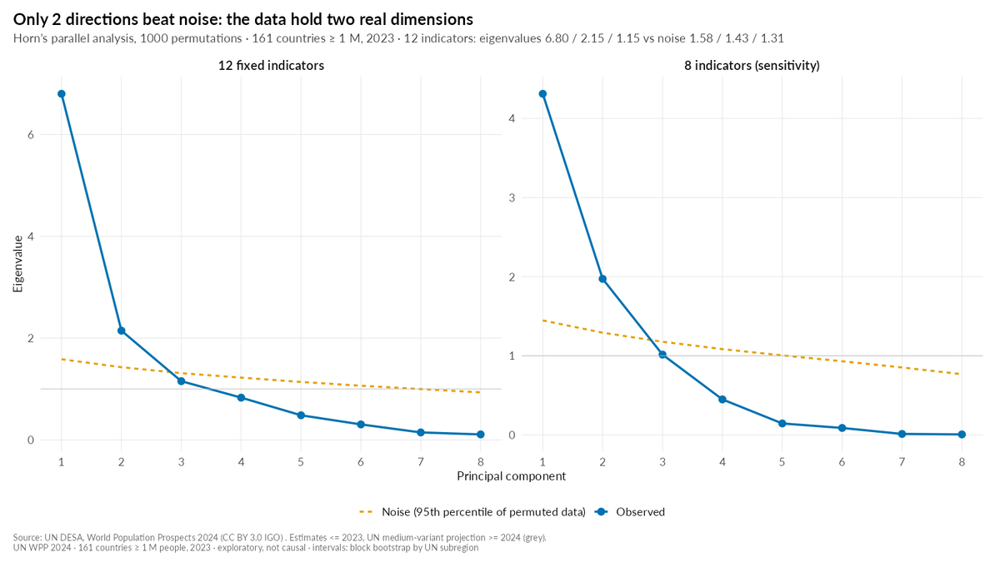

**`figures/review/q2/q2_08_pca_biplot.png`** (figura de revisión, no final)

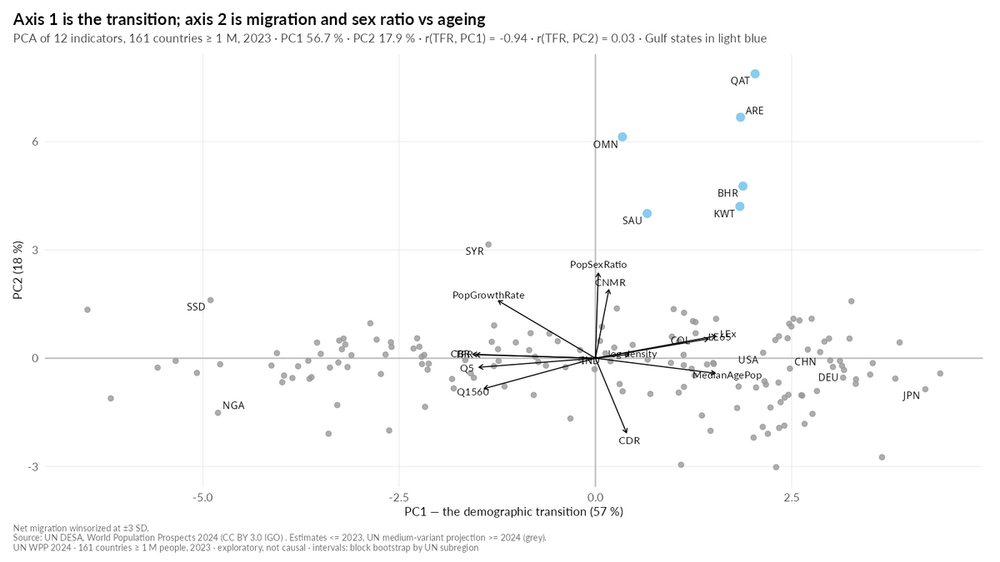

**`figures/review/q2/q2_09_pca_sensitivity.png`** (figura de revisión, no final)

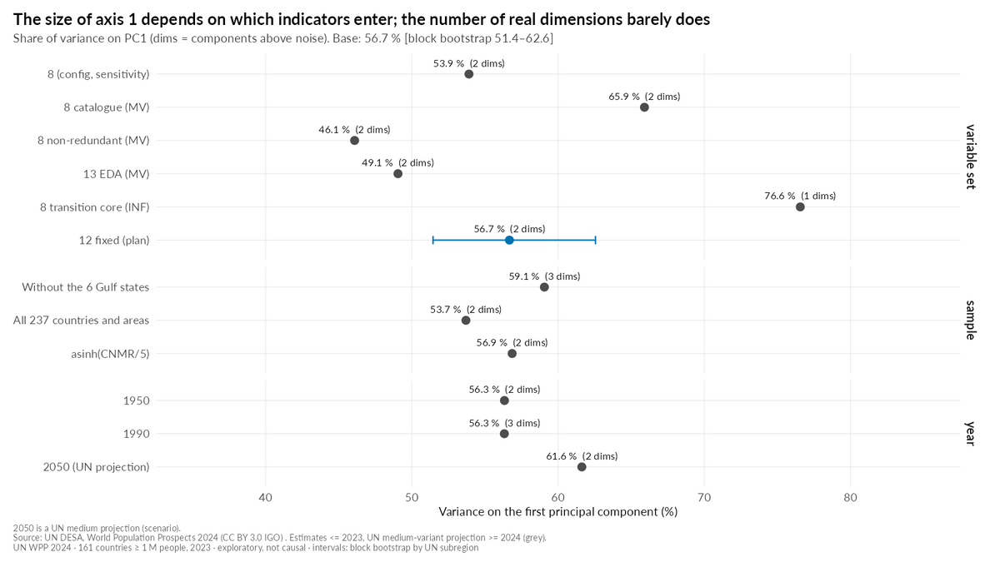

**`figures/review/q2/q2_05_lookalikes_overlap.png`** (figura de revisión, no final)

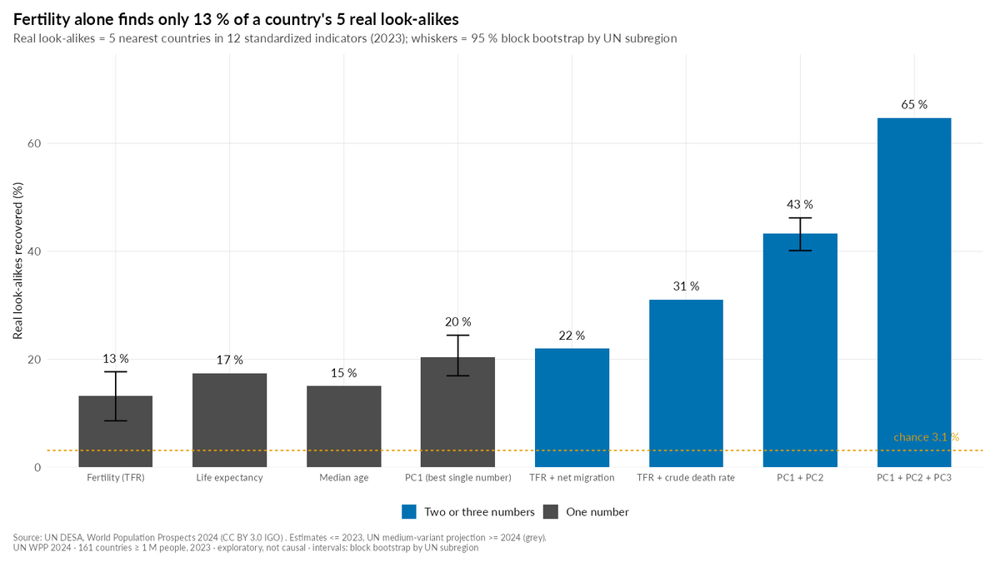

**`figures/review/q2/q2_06_colombia_lookalikes.png`** (figura de revisión, no final)

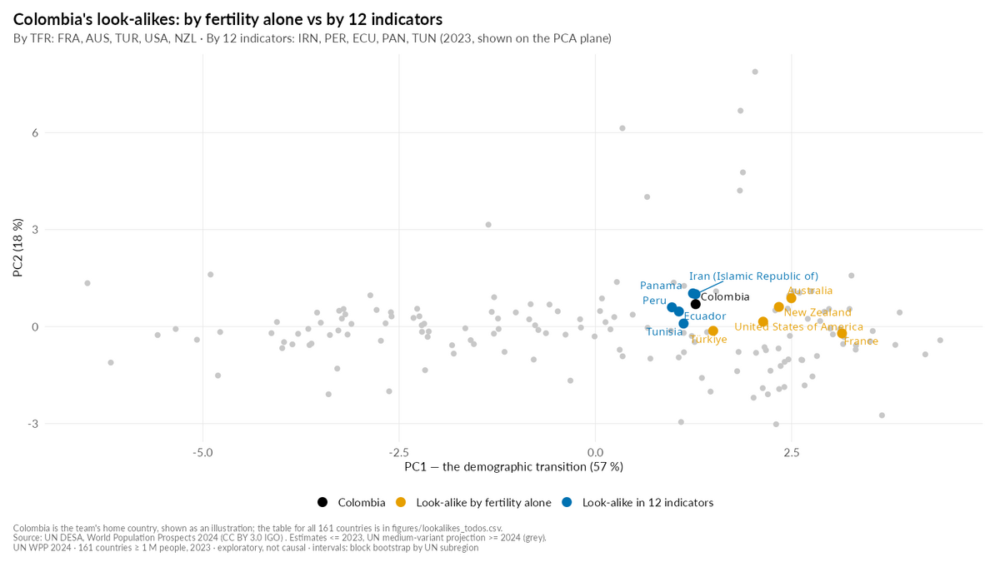

In [112]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_07_parallel_analysis", "q2_08_pca_biplot", "q2_09_pca_sensitivity", "q2_05_lookalikes_overlap", "q2_06_colombia_lookalikes"))

#### Lectura de resultados · §6 R2 · PCA con el conjunto fijo de 12 variables + análisis paralelo (H7, H7a)

*Texto de `docs/resultados_q2.md` §6 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** `prcomp` sobre las 12 variables estandarizadas (161 países, 2023). PC1 se orienta con LEx > 0 y PC2 con CNMR > 0. Análisis paralelo de Horn con 1 000 permutaciones por columna. Los IC por bloques rehacen winsorización, z y PCA, y emparejan los ejes con los originales. Sensibilidades: 6 conjuntos de variables, sin Golfo, 237, asinh, 1950, 1990 y 2050.

| Cifra | Valor | IC bloques | iid (percentil, B = 1 000) | Sensibilidad | Clave |
|---|---|---|---|---|---|
| % varianza PC1 | **56,7 %** | [51,4; 62,6] | [54,9; 59,2] | 46,1–76,6 según el conjunto de variables | `pc1_var` |
| % varianza PC2 | 17,9 % | [11,8; 23,6] | [14,5; 21,5] | 13,3 (sin Golfo)–24,7 | `pc2_var` |
| PC1 + PC2 | 74,6 % | [71,7; 77,1] | [72,2; 77,9] | — | `pc12_var` |
| Componentes para 70 % | **2** | 2 en 1 997 de 2 000 réplicas (3 en 3) | — | 2–3 | `n_pcs_70` |
| Dimensiones sobre el ruido (paralelo) | **2** | — | — | 1–3 | `n_dims_parallel` |
| Autovalores observados vs p95 nulo | 6,80 / 2,15 / 1,15 / 0,83 vs 1,58 / 1,43 / 1,31 / 1,22 | — | — | — | `eigen_pca_12`, `eigen_null_p95_12` |
| r(TFR, PC1) | **−0,945** | [−0,961; −0,901] | [−0,957; −0,930] | −0,96 a −0,90 | `r_tfr_pc1` |
| r(TFR, PC2) | **0,033** | [−0,079; 0,169] | [−0,025; 0,102] | −0,14 a 0,29 (1950) | `r_tfr_pc2` |
| PC2 sin los 6 del Golfo | 13,3 % | — | — | — | `pc2_var_no_gulf` |

**Sensibilidad** (`resultados_q2_pca_sensibilidad.parquet`; figura `q2_09_pca_sensitivity.png`):

| Caso | PC1 | PC2 | Dimensiones | r(TFR, PC1) | r(TFR, PC2) |
|---|---|---|---|---|---|
| 12 fijas (base) | 56,7 | 17,9 | 2 | −0,94 | 0,03 |
| 8 de `config.R` | 53,9 | 24,7 | 2 | −0,94 | −0,14 |
| 8 catálogo (MV) | 65,9 | 18,3 | 2 | −0,96 | −0,08 |
| 8 no redundantes (MV) | 46,1 | 22,7 | 2 | −0,92 | 0,10 |
| 13 del EDA (MV) | 49,1 | 17,3 | 2 | −0,92 | 0,07 |
| 8 núcleo de la transición (INF, sin CNMR) | 76,6 | 15,5 | **1** | −0,96 | — |
| Sin Golfo (155) | 59,1 | 13,3 | **3** | −0,94 | −0,02 |
| 237 países | 53,7 | 17,1 | 2 | −0,92 | 0,01 |
| asinh(CNMR/5) | 56,9 | 17,7 | 2 | −0,94 | 0,05 |
| 1950 | 56,3 | 18,0 | 2 | −0,90 | 0,29 |
| 1990 | 56,3 | 16,0 | **3** | −0,94 | 0,11 |
| 2050 (proyección) | 61,6 | 15,9 | 2 | −0,95 | 0,04 |

Cargas (PC1): CBR −0,37, LEx +0,37, TFR −0,36, edad mediana +0,36, Q5 −0,35. PC2: razón de sexos +0,56, CDR −0,49, CNMR +0,45, crecimiento +0,38. Figuras: `q2_07_parallel_analysis.png`, `q2_08_pca_biplot.png`.

**Lectura.** H7 (formulación v1: PC1 < 50 % y 3 componentes para 70 %) **se rechaza**: PC1 = 56,7 % y bastan 2 componentes (74,6 %). H7a **se confirma** en el caso base: exactamente 2 autovalores superan al ruido (6,80 y 2,15 frente a 1,58 y 1,43; el tercero, 1,15, queda bajo 1,31), la TFR es casi el eje 1 (−0,945) y es ciega al eje 2 (0,03). Matices: (i) el % del PC1 va de 46 % a 77 % según qué variables entren, así que la cifra titular es la estructura ("dos dimensiones reales"), no el porcentaje; (ii) el número de dimensiones va de 1 (sin migración entre las variables) a 3 (sin el Golfo y en 1990); (iii) el eje 2 depende en parte de 6 países: sin el Golfo baja de 17,9 % a 13,3 %. Con bloques, el IC del PC1 (51–63) es unas 2,8 veces más ancho que el iid.

### Q2 · §8 R3 · Índice compuesto (P5) y su fragilidad (H8, H8a)

*Pre-specified (H8, H8a)* · `R/03_q2_un_numero.R` líneas 1355–1587

In [113]:
# =============================================================================
# 8. R3 · Índice compuesto (P5) y su fragilidad (H8, H8a)
#    Qué: índice de "avance de la transición" con TFR (−), Q5 (−), LEx (+), edad
#    mediana (+) y crecimiento (−). (a) Las 7 variantes del EDA (v1); (b) Monte
#    Carlo de 2 000 diseños (OCDE/JRC). Se cuenta qué % de países se mueve > 20
#    puestos y qué decisión (pesos o normalización) mueve más el ranking.
#    Por qué: P5 pide combinar indicadores y justificar decisiones; mostramos que
#    el ranking depende sobre todo de los pesos. NO es un índice de desarrollo.
# =============================================================================

DIR_INDICE <- c(TFR = -1, Q5 = -1, LEx = 1, MedianAgePop = 1, PopGrowthRate = -1)   # + = más avanzado
IND <- names(DIR_INDICE)
O <- sweep(as.matrix(d23[, IND]), 2, DIR_INDICE, `*`)
rownames(O) <- d23$ISO3_code
mm01 <- function(M) apply(M, 2, function(x) (x - min(x)) / (max(x) - min(x)))
rk01 <- function(M) apply(M, 2, function(x) rank(x) / length(x))
geo <- function(M01, w, piso = 0.01) exp(as.vector(log(piso + (1 - piso) * M01) %*% w))

In [114]:
# 8.1 Versión simple: las 7 variantes del EDA v1 (definiciones del notebook EDA, celda 87).
Zi <- scale(O); MMi <- mm01(O); RKi <- rk01(O)
w_dim <- c(TFR = 1 / 3, Q5 = 1 / 6, LEx = 1 / 6, MedianAgePop = 1 / 3, PopGrowthRate = 0)
pc_w <- stats::prcomp(Zi)$rotation[, 1]; if (pc_w["LEx"] < 0) pc_w <- -pc_w
variantes <- tibble(
  V1 = rowMeans(Zi),                                       # z · pesos iguales (base)
  V2 = rowMeans(MMi),                                      # min–max · pesos iguales
  V3 = rowMeans(RKi),                                      # rangos · pesos iguales
  V4 = as.vector(Zi %*% w_dim[IND]),                       # z · pesos por dimensión
  V5 = as.vector(Zi %*% pc_w[IND]),                        # z · pesos del PC1
  V6 = rowMeans(cbind(Zi, scale(d23$CNMR_raw))),           # z · + migración neta (signo +)
  V7 = exp(rowMeans(log(0.02 + 0.98 * MMi)))               # min–max · media geométrica
)
ETIQ_VAR <- c(V1 = "V1 z · equal weights", V2 = "V2 min–max · equal", V3 = "V3 ranks · equal",
              V4 = "V4 z · dimension weights", V5 = "V5 z · PC1 weights", V6 = "V6 z · + net migration",
              V7 = "V7 min–max · geometric")
rangos <- as.data.frame(lapply(variantes, function(x) rank(-x, ties.method = "min")))
amp <- function(cols) apply(rangos[, cols, drop = FALSE], 1, function(r) max(r) - min(r))
tabla_var <- d23 |> select(ISO3_code, Location) |>
  bind_cols(rangos |> rename_with(\(x) paste0("rank_", x))) |>
  mutate(amplitud_7 = amp(names(variantes)), amplitud_norm = amp(c("V1", "V2", "V3", "V7")),
         amplitud_pesos = amp(c("V1", "V4", "V5")), salto_mig = abs(rangos$V6 - rangos$V1),
         amplitud_sin_mig = amp(c("V1", "V2", "V3", "V4", "V5", "V7")))
write_parquet(tabla_var, ruta_parquet_q2("indice_variantes"))
rho_var <- stats::cor(rangos, method = "spearman")
share7 <- 100 * mean(tabla_var$amplitud_7 > 20)
share7_norm <- 100 * mean(tabla_var$amplitud_norm > 20)
share7_pesos <- 100 * mean(tabla_var$amplitud_pesos > 20)
share7_mig <- 100 * mean(tabla_var$salto_mig > 20)
share7_sinmig <- 100 * mean(tabla_var$amplitud_sin_mig > 20)
destacado <- tabla_var |> arrange(desc(amplitud_sin_mig), ISO3_code) |> slice(1)
message(sprintf(paste0("7 variantes: ρ mín %.3f; >20 puestos: %.1f %% (solo normalización %.1f %%, solo pesos %.1f %%, ",
                       "migración %.1f %%, sin la de migración %.1f %%); caso destacado (mayor amplitud sin migración): %s (%d)"),
                min(rho_var), share7, share7_norm, share7_pesos, share7_mig, share7_sinmig, destacado$ISO3_code,
                as.integer(destacado$amplitud_sin_mig)))
h8_ok <- abs(share7 - 24) <= 3

7 variantes: ρ mín 0.970; >20 puestos: 9.3 % (solo normalización 1.2 %, solo pesos 3.1 %, migración 8.1 %, sin la de migración 3.7 %); caso destacado (mayor amplitud sin migración): ARE (30)



In [115]:
# 8.2 Versión rica: Monte Carlo de diseños (pesos Dirichlet, normalización,
#     agregación e inclusión del crecimiento), intervalo 90 % de rango por país.
mc_indice <- function(O, a = 5, varia_inclusion = TRUE, pesos_iguales = FALSE, M = M_INDICE, semilla = SEMILLA) {
  set.seed(semilla)
  ind <- colnames(O)
  sims <- replicate(M, {
    usa <- if (varia_inclusion && stats::runif(1) < 0.5) ind[1:4] else ind
    w <- if (pesos_iguales) rep(1 / length(usa), length(usa)) else { g <- stats::rgamma(length(usa), a); g / sum(g) }
    norm <- sample(c("z", "mm", "rk"), 1); agg <- sample(c("arit", "geom"), 1)
    Mx <- switch(norm, z = scale(O[, usa]), mm = mm01(O[, usa]), rk = rk01(O[, usa]))
    s <- if (agg == "geom") geo(if (norm == "z") mm01(O[, usa]) else Mx, w) else as.vector(Mx %*% w)
    rank(-s)
  })
  q <- apply(sims, 1, stats::quantile, c(0.05, 0.5, 0.95))
  tibble(ISO3_code = rownames(O), r05 = q[1, ], r50 = q[2, ], r95 = q[3, ], ancho90 = q[3, ] - q[1, ])
}
SPECS_MC <- list(
  declared = list(a = 5, inc = TRUE, igual = FALSE,
                  en = "Declared: Dirichlet(5) weights + normalization + aggregation + inclusion of growth"),
  norm_only = list(a = NA, inc = FALSE, igual = TRUE, en = "Equal weights, only normalization and aggregation vary"),
  dir5_fixed5 = list(a = 5, inc = FALSE, igual = FALSE, en = "Dirichlet(5) weights, 5 indicators fixed"),
  dir1 = list(a = 1, inc = TRUE, igual = FALSE, en = "Dirichlet(1) weights (very dispersed) + inclusion of growth")
)
tabla_mc <- imap_dfr(SPECS_MC, function(s, nm) {
  mc_indice(O, a = ifelse(is.na(s$a), 1, s$a), varia_inclusion = s$inc, pesos_iguales = s$igual) |> mutate(spec = nm)
}) |>
  left_join(tabla_var |> select(ISO3_code, Location, rango_base = rank_V1), by = "ISO3_code") |>
  mutate(mas20 = ancho90 > 20) |>
  select(spec, ISO3_code, Location, rango_base, r05, r50, r95, ancho90, mas20)
write_parquet(tabla_mc, ruta_parquet_q2("indice_mc"))
resumen_mc <- tabla_mc |> group_by(spec) |>
  summarise(mediana_ancho = stats::median(ancho90), p90_ancho = unname(stats::quantile(ancho90, 0.9)),
            pct_mas20 = 100 * mean(mas20), n_mas20 = sum(mas20), .groups = "drop") |>
  mutate(descripcion_en = vapply(spec, function(s) SPECS_MC[[s]]$en, character(1))) |>
  arrange(match(spec, names(SPECS_MC)))
print(resumen_mc)
write_parquet(resumen_mc |> select(spec, descripcion_en, mediana_ancho, p90_ancho, pct_mas20), ruta_parquet_q2("mc_resumen"))
pct_mc <- setNames(resumen_mc$pct_mas20, resumen_mc$spec)
n_mc <- setNames(resumen_mc$n_mas20, resumen_mc$spec)
h8a_ok <- pct_mc[["declared"]] >= 10 && pct_mc[["declared"]] > pct_mc[["norm_only"]]
mc_decl <- tabla_mc |> filter(spec == "declared")
ukr <- mc_decl |> filter(ISO3_code == "UKR")
ukr_dir1 <- tabla_mc |> filter(spec == "dir1", ISO3_code == "UKR")
mas_inciertos <- mc_decl |> arrange(desc(ancho90), ISO3_code) |> slice_head(n = 8)
robustos_arriba <- mc_decl |> filter(r95 <= 10) |> arrange(r50)
robustos_abajo <- mc_decl |> filter(r05 >= N_PAISES_1M - 10) |> arrange(r50)

# A tibble: 4 × 6
  spec        mediana_ancho p90_ancho pct_mas20 n_mas20 descripcion_en                                                                    
  <chr>               <dbl>     <dbl>     <dbl>   <int> <chr>                                                                             
1 declared               12        27     21.7       35 Declared: Dirichlet(5) weights + normalization + aggregation + inclusion of growth
2 norm_only               4        10      2.48       4 Equal weights, only normalization and aggregation vary                            
3 dir5_fixed5            10        24     17.4       28 Dirichlet(5) weights, 5 indicators fixed                                          
4 dir1                   19        41     47.2       76 Dirichlet(1) weights (very dispersed) + inclusion of growth                       


In [116]:
# 8.3 Fiabilidad (solo notebook): α estandarizado, ω de McDonald, pesos efectivos, validez con LE60.
alfa_std <- function(M) { M <- scale(M); k <- ncol(M); k / (k - 1) * (1 - sum(apply(M, 2, stats::var)) / stats::var(rowSums(M))) }
omega_mcd <- function(M) {
  f <- stats::factanal(M, factors = 1)
  l <- f$loadings[, 1]
  sum(l)^2 / (sum(l)^2 + sum(f$uniquenesses))
}
alfa5 <- alfa_std(O); alfa4 <- alfa_std(O[, 1:4]); alfa3 <- alfa_std(O[, c("TFR", "Q5", "LEx")])
omega5 <- tryCatch(omega_mcd(O), error = function(e) NA_real_)
imp <- vapply(IND, function(v) stats::cor(variantes$V1, O[, v])^2, numeric(1)); imp <- imp / sum(imp)
le60 <- readr::read_csv(RUTA_WPP_SUPLEMENTO, show_col_types = FALSE) |>
  filter(Time == ANIO_FIN_ESTIMACION) |> select(ISO3_code, LE60)
d_val <- d23 |> select(ISO3_code, subregion, all_of(IND)) |> left_join(le60, by = "ISO3_code")
stopifnot(!anyNA(d_val$LE60))
stat_validez <- function(d) {
  Oi <- sweep(as.matrix(d[, IND]), 2, DIR_INDICE, `*`)
  stats::cor(rowMeans(scale(Oi)), d$LE60, method = "spearman")
}
set.seed(SEMILLA)
bs_val <- bootstrap_bloques(d_val, stat_validez, B = B_Q2, semilla = SEMILLA)

In [117]:
# 8.4 Registro del índice.
w7 <- ic_wilson(sum(tabla_var$amplitud_7 > 20), N_PAISES_1M, escala = 100)
anotar("share_rank_7var", share7, "%", "0",
       "Share of countries whose rank moves more than 20 places across the 7 hand-picked index variants of the v1 plan (z / min–max / ranks / dimension weights / PC1 weights / + net migration / geometric)",
       FILTRO_1M_2023, "T10.1", USO_NB, ic = w7,
       sens_low = min(share7_norm, share7_pesos, share7_mig), sens_high = share7,
       sens_note = sprintf(paste0("only normalization/aggregation variants (V1, V2, V3, V7) %.1f · only weights (V1, V4, V5) %.1f · ",
                                  "adding net migration (V6 vs V1) %.1f · all except the migration variant %.1f · min Spearman between variants %.3f"),
                           share7_norm, share7_pesos, share7_mig, share7_sinmig, min(rho_var)),
       status = "pre-specified", hypothesis_id = "H8", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("rho_rank_7var_min", min(rho_var), "rho", "0.00",
       "Smallest Spearman correlation between the rankings of the 7 index variants", FILTRO_1M_2023, "T10.1", USO_NB,
       method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M,
       sens_note = sprintf("without the migration variant: %.3f", min(rho_var[-6, -6])))
w_mc <- ic_wilson(n_mc[["declared"]], N_PAISES_1M, escala = 100)
anotar("share_rank_mc20", pct_mc[["declared"]], "%", "0",
       # QA-stats (docs/QA_stats.md): se declaran la probabilidad de incluir el crecimiento y la media geométrica.
       sprintf(paste0("Share of countries whose 90 %% rank interval (5th to 95th percentile of their ranks, R quantile type 7) is wider ",
                      "than 20 places across %s random index designs (seed %d): 5 indicators oriented so that higher = more advanced; ",
                      "Dirichlet(5) weights; normalization z / min–max / percentile rank and aggregation arithmetic / geometric, each drawn ",
                      "with equal probability; population growth included with probability 0.5; the geometric mean is taken on min–max ",
                      "scores (also when z is drawn) or on rank scores, floored at 0.01"),
               format(M_INDICE, big.mark = ","), SEMILLA),
       FILTRO_1M_2023, "T10.2", c("slide3.build4", "narration.s3"), ic = w_mc,
       sens_low = min(pct_mc), sens_high = max(pct_mc),
       sens_note = paste(sprintf("%s %.1f", vapply(names(pct_mc), function(s) SPECS_MC[[s]]$en, character(1)), pct_mc), collapse = " · "),
       status = "pre-specified", hypothesis_id = "H8a", n = N_PAISES_1M, universe = UNIVERSO_1M,
       say = decir_uno_de(pct_mc[["declared"]], "country"))
anotar("share_rank_mc20_sens", round(pct_mc, 2), "%", "0",
       "Share of countries with a 90 % rank interval > 20 places under each Monte Carlo specification",
       FILTRO_1M_2023, "T10.2", USO_NB, method = "sensitivity", sens_low = min(pct_mc), sens_high = max(pct_mc),
       sens_note = paste(sprintf("%s = %s", names(SPECS_MC), vapply(SPECS_MC, `[[`, character(1), "en")), collapse = " · "),
       status = "pre-specified", hypothesis_id = "H8a", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("rank_range_ukr", c(low = ukr$r05, high = ukr$r95), "rank", "0",
       "Ukraine's 90 % rank interval across the declared Monte Carlo of index designs (1 = most advanced in the transition)",
       FILTRO_1M_2023, "T10.2", c("appendix.bump"), method = "sensitivity", sens_low = ukr$r05, sens_high = ukr$r95,
       sens_note = sprintf("median rank %.0f; base rank (z, equal weights) %d; with Dirichlet(1) weights %.0f–%.0f",
                           ukr$r50, as.integer(ukr$rango_base), ukr_dir1$r05, ukr_dir1$r95),
       status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("index_most_uncertain", as.data.frame(mas_inciertos |> transmute(iso3 = ISO3_code, country = Location, r05, r50, r95, width90 = ancho90)),
       NA, "text", "The 8 countries with the widest 90 % rank interval in the declared Monte Carlo",
       FILTRO_1M_2023, "T10.2", USO_NB, method = "sensitivity", status = "exploratory",
       sens_note = sprintf("robust at the top (95th pct rank ≤ 10): %s · robust at the bottom (5th pct ≥ %d): %s",
                           paste(robustos_arriba$ISO3_code, collapse = ", "), N_PAISES_1M - 10, paste(robustos_abajo$ISO3_code, collapse = ", ")),
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("index_highlight", destacado$Location, NA, "text",
       "Highlighted country by rule: the largest rank jump across the 6 index variants without net migration",
       FILTRO_1M_2023, "T10.1", c("appendix.bump"), method = "descriptive", status = "exploratory",
       sens_note = sprintf("%s: ranks %d–%d across V1–V5, V7 (jump %d places)", destacado$ISO3_code,
                           as.integer(min(unlist(destacado[, paste0("rank_V", c(1:5, 7))]))),
                           as.integer(max(unlist(destacado[, paste0("rank_V", c(1:5, 7))]))),
                           as.integer(destacado$amplitud_sin_mig)),
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("alpha", alfa5, "alpha", "0.00",
       "Standardized Cronbach's alpha of the 5 oriented index indicators (notebook only: a reflective model does not hold; high alpha does not imply a robust ranking)",
       FILTRO_1M_2023, "T10.3", USO_NB, method = "sensitivity", sens_low = min(alfa3, alfa4, alfa5), sens_high = max(alfa3, alfa4, alfa5),
       sens_note = sprintf("4 items (without growth) %.3f · 3 items (TFR, Q5, LEx) %.3f", alfa4, alfa3),
       status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("omega", omega5, "omega", "0.00",
       "McDonald's omega (one-factor ML model) of the 5 oriented index indicators (notebook only)",
       FILTRO_1M_2023, "T10.3", USO_NB, method = "descriptive", status = "exploratory",
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("index_eff_weights", round(imp, 4), "share", "0.00",
       "Effective weights: squared correlation of the base index (z, equal weights) with each indicator, normalized to sum 1 (nominal 0.20 each)",
       FILTRO_1M_2023, "T10.3", USO_NB, method = "descriptive", status = "exploratory",
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("rho_index_le60", bs_val$valor, "rho", "0.00",
       "Convergent validity: Spearman correlation of the base index with life expectancy at 60 (not in the index; organizers' supplement), 2023",
       FILTRO_1M_2023, "T10.3", USO_NB, ic = bs_val, status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M)

In [118]:
# 8.5 Figuras del índice.
top20 <- tabla_var |> arrange(desc(amplitud_7), ISO3_code) |> slice_head(n = 20)
niveles_top20 <- rev(top20$Location[order(top20$rank_V1)])
largo_top20 <- top20 |> select(ISO3_code, Location, rank_V1:rank_V7) |>
  pivot_longer(starts_with("rank_"), names_to = "variante", values_to = "rango") |>
  mutate(variante = ETIQ_VAR[sub("rank_", "", variante)], pais = factor(Location, levels = niveles_top20))
rango_top20 <- largo_top20 |> group_by(pais) |> summarise(rmin = min(rango), rmax = max(rango), .groups = "drop")
p_var <- ggplot(largo_top20, aes(rango, pais)) +
  geom_segment(data = rango_top20, aes(x = rmin, xend = rmax, y = pais, yend = pais), inherit.aes = FALSE,
               colour = COLOR_GRIS_CLARO, linewidth = 1.6) +
  geom_point(aes(shape = variante, colour = variante), size = 2.8) +
  scale_shape_manual(values = c(16, 17, 15, 18, 8, 4, 3), name = NULL) +
  scale_colour_manual(values = c("#000000", "#0072B2", "#56B4E9", "#E69F00", "#CC79A7", "#999999", "#332288"), name = NULL) +
  guides(colour = guide_legend(nrow = 2), shape = guide_legend(nrow = 2)) +
  labs(title = sprintf("Seven index variants: %.0f %% of countries move more than 20 places", share7),
       subtitle = sprintf("The 20 countries with the widest range (1 = most advanced in the transition, of 161). Only normalization varies: %.0f %%; only weights: %.0f %%; adding migration: %.0f %%",
                          share7_norm, share7_pesos, share7_mig),
       x = "Rank", y = NULL,
       caption = pie_q2("A transition-stage index — not a ranking of development or well-being.", FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_var, "q2_10_index_seven_variants")

p_mc <- mc_decl |> arrange(r50, ISO3_code) |> mutate(orden = row_number()) |>
  ggplot(aes(orden)) +
  geom_linerange(aes(ymin = r05, ymax = r95, colour = mas20), linewidth = 0.9) +
  geom_point(aes(y = r50), size = 0.9, colour = "black") +
  geom_text_repel(data = \(x) filter(x, ISO3_code %in% c("UKR", mas_inciertos$ISO3_code[1:4])),
                  aes(y = r95, label = ISO3_code), size = 3.8, nudge_y = 12, seed = SEMILLA) +
  scale_colour_manual(values = c(`TRUE` = COLOR_DEFUNCIONES, `FALSE` = COLOR_GRIS_CLARO),
                      labels = c(`TRUE` = "Interval wider than 20 places", `FALSE` = "20 places or fewer"), name = NULL) +
  scale_y_reverse() +
  labs(title = sprintf("Across %s reasonable index designs, %.0f %% of countries can move more than 20 places",
                       format(M_INDICE, big.mark = ","), pct_mc[["declared"]]),
       subtitle = sprintf("90 %% rank interval per country (dot = median). Weights decide: equal weights with other formulas %.1f %%; Dirichlet(1) weights %.1f %%",
                          pct_mc[["norm_only"]], pct_mc[["dir1"]]),
       x = "Countries ordered by median rank", y = "Rank (1 = most advanced in the transition)",
       caption = pie_q2("A transition-stage index — not a ranking of development or well-being.", FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_mc, "q2_11_index_monte_carlo")

**`figures/review/q2/q2_10_index_seven_variants.png`** (figura de revisión, no final)

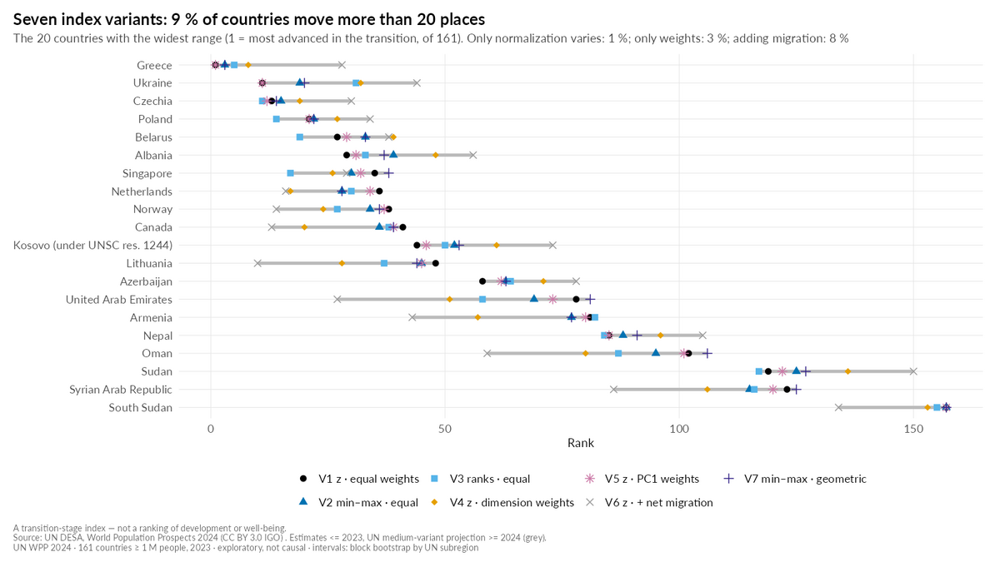

**`figures/review/q2/q2_11_index_monte_carlo.png`** (figura de revisión, no final)

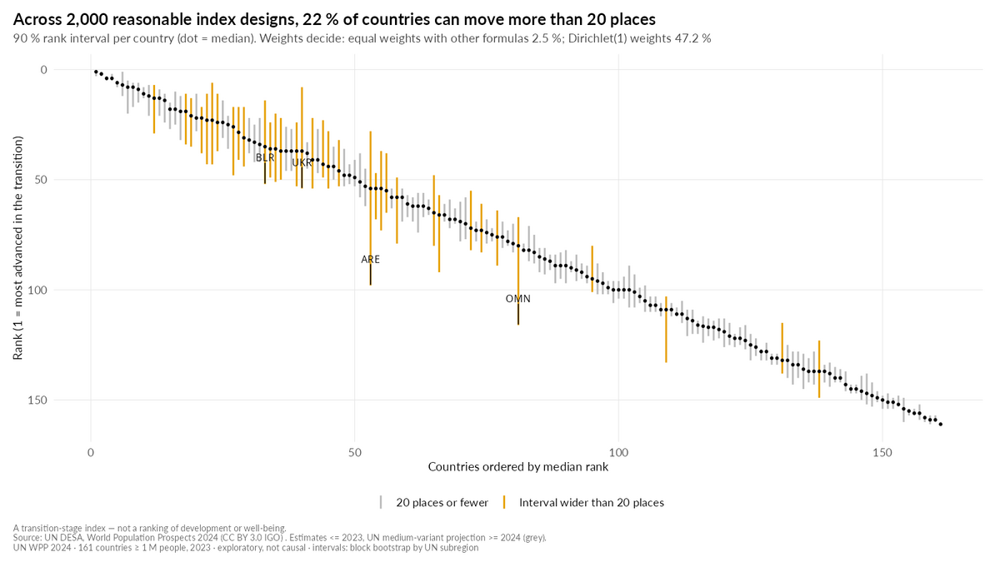

In [119]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_10_index_seven_variants", "q2_11_index_monte_carlo"))

#### Lectura de resultados · §7 R3 · Índice compuesto (P5) y su fragilidad (H8, H8a)

*Texto de `docs/resultados_q2.md` §7 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Un índice de **avance de la transición** (no de desarrollo ni de bienestar) con TFR (−), Q5 (−), LEx (+), edad mediana (+) y crecimiento (−). (a) Las 7 variantes a mano del EDA v1: z, min–max, rangos, pesos por dimensión, pesos del PC1, + migración neta y media geométrica. (b) Un Monte Carlo de 2 000 diseños (OCDE/JRC).

**(a) Siete variantes** (`share_rank_7var`, `rho_rank_7var_min`; figura `q2_10_index_seven_variants.png`):

| Medida | Valor |
|---|---|
| ρ de Spearman mínima entre rankings | 0,970 (0,989 sin la variante con migración) |
| % de países que se mueve > 20 puestos entre las 7 | **9,3 %** (15 de 161; Wilson [5,7; 14,8]) |
| … solo normalización/agregación (V1, V2, V3, V7) | 1,2 % |
| … solo pesos (V1, V4, V5) | 3,1 % |
| … añadir la migración neta (V6 vs V1) | 8,1 % |
| Caso destacado por regla (mayor salto sin la variante de migración) | **EAU**: puestos 51–81 (30 puestos) (`index_highlight`) |

**(b) Monte Carlo de 2 000 diseños** (`share_rank_mc20`, `share_rank_mc20_sens`; figura `q2_11_index_monte_carlo.png`):

| Especificación | Ancho mediano del intervalo 90 % de rango | % con ancho > 20 puestos |
|---|---|---|
| **Declarada (H8a):** pesos Dirichlet(5) + normalización + agregación + inclusión aleatoria del crecimiento | 12 | **21,7 %** (35 de 161; Wilson [16,1; 28,7]) |
| Pesos iguales; solo normalización y agregación | 4 | 2,5 % |
| Dirichlet(5) con los 5 indicadores fijos | 10 | 17,4 % |
| Dirichlet(1) (pesos muy dispersos) + inclusión | 19 | 47,2 % |

Más inciertos (declarada): EAU 28–98, Omán 67–116, **Ucrania 8–54** (`rank_range_ukr`; con Dirichlet(1), 4–68), Bielorrusia 14–52, Singapur 6–43, Qatar 37–73, Armenia 57–92, Moldova 48–80. Robustos arriba: Hong Kong, Japón, Italia, Rep. de Corea, España. Robustos abajo: R. D. del Congo, Malí, Nigeria, RCA, Níger, Somalia, Chad.

**Fiabilidad y validez (solo notebook):** α estandarizado = 0,952 (4 ítems 0,962; 3 ítems 0,956); ω = 0,954; pesos efectivos TFR 0,217 · edad mediana 0,211 · Q5 0,207 · LEx 0,201 · crecimiento 0,165 (nominal 0,20); validez convergente ρ(índice, LE60) = **0,867** [0,734; 0,913]. Claves `alpha`, `omega`, `index_eff_weights`, `rho_index_le60`.

**Lectura.** H8 (v1: "1 de cada 4 países se mueve > 20 puestos con 7 variantes") **se rechaza como cifra**: con los 161 países ≥ 1 M sale el 9,3 %. El 24 % del EDA venía de los 237 países, donde los microestados (San Martín, etc.) saltan decenas de puestos. H8a **se confirma**: 21,7 % ≥ 10 % y muy por encima del 2,5 % de "solo fórmulas". Lo que mueve el ranking son los **pesos** (17,4 % con Dirichlet(5) y 47,2 % con Dirichlet(1)) y la inclusión de la migración, no la normalización. Un α de 0,95 convive con esa fragilidad: un α alto no hace robusto un ranking. Ucrania (caso del plan) sigue siendo de los más inciertos (3.º). La regla escrita en código elige EAU como caso destacado; Ucrania sirve para el bump chart si se prefiere un país fuera del Golfo.

### Q2 · §9 Hallazgo de demografía: misma fecundidad, saldo natural opuesto (dem01)

*Exploratory (sin hipótesis)* · `R/03_q2_un_numero.R` líneas 1588–1650

In [120]:
# =============================================================================
# 9. Hallazgo de demografía: misma fecundidad, saldo natural opuesto (dem01)
#    Qué: entre los países con TFR 1,5–1,99, rango del saldo natural y su
#    correlación con la edad mediana; entre los países bajo reemplazo, R² del
#    saldo natural con TFR sola y con TFR + edad mediana.
#    Por qué: la misma fecundidad no fija el signo de nacimientos − defunciones;
#    lo fija la estructura por edades (otra cara de P8).
# =============================================================================

banda <- d23 |> filter(TFR >= 1.5, TFR < 2.0) |>
  transmute(ISO3_code, Location, region_sdg, subregion, TFR, NatChangeRT, CNMR = CNMR_raw, PopGrowthRate, MedianAgePop)
write_parquet(banda |> select(-subregion), ruta_parquet_q2("misma_fecundidad"))
nat_min <- banda |> slice_min(NatChangeRT, n = 1, with_ties = FALSE)
nat_max <- banda |> slice_max(NatChangeRT, n = 1, with_ties = FALSE)
set.seed(SEMILLA)
bs_band <- bootstrap_bloques(banda, function(d) stats::cor(d$NatChangeRT, d$MedianAgePop), B = B_Q2, semilla = SEMILLA)
bajo <- d23 |> filter(TFR < TFR_REEMPLAZO) |> select(ISO3_code, subregion, TFR, NatChangeRT, MedianAgePop)
stat_bajo <- function(d) c(tfr = r2_lm(d, "NatChangeRT", "TFR"), tfr_medage = r2_lm(d, "NatChangeRT", c("TFR", "MedianAgePop")))
set.seed(SEMILLA)
bs_bajo <- bootstrap_bloques(bajo, stat_bajo, B = B_Q2, semilla = SEMILLA)
FILTRO_BANDA <- "Countries ≥ 1 M with total fertility 1.5–1.99 in 2023; UN estimates"
FILTRO_BAJO <- "Countries ≥ 1 M with total fertility below 2.1 in 2023; UN estimates"
anotar("n_band_tfr", nrow(banda), "countries", "0", "Countries ≥ 1 M with total fertility rate between 1.5 and 1.99 in 2023",
       FILTRO_BANDA, "T15.1", c("appendix.same_fertility"), method = "none_census", status = "descriptive",
       n = nrow(banda), universe = UNIVERSO_1M)
anotar("nat_min_band", nat_min$NatChangeRT, "per 1,000", "+0.0",
       sprintf("Lowest rate of natural change (births − deaths per 1,000) among countries with TFR 1.5–1.99, 2023 (%s)", nat_min$Location),
       FILTRO_BANDA, "T15.1", c("appendix.same_fertility"), method = "descriptive", status = "exploratory",
       n = nrow(banda), universe = UNIVERSO_1M)
anotar("nat_max_band", nat_max$NatChangeRT, "per 1,000", "+0.0",
       sprintf("Highest rate of natural change among countries with TFR 1.5–1.99, 2023 (%s)", nat_max$Location),
       FILTRO_BANDA, "T15.1", c("appendix.same_fertility"), method = "descriptive", status = "exploratory",
       n = nrow(banda), universe = UNIVERSO_1M)
anotar("r_nat_medage_band", bs_band$valor, "r", "0.00",
       "Pearson correlation of natural change rate and median age among countries with TFR 1.5–1.99, 2023",
       FILTRO_BANDA, "T15.1", c("appendix.same_fertility"), ic = bs_band, status = "exploratory",
       n = nrow(banda), universe = UNIVERSO_1M)
anotar("r2_nat_tfr_belowrepl", bs_bajo$valor[["tfr"]], "R2", "0.00",
       "Adjusted R² of natural change rate on TFR alone, countries below replacement (TFR < 2.1), 2023",
       FILTRO_BAJO, "T15.1", USO_NB, ic = extraer_ic(bs_bajo, "tfr"), status = "exploratory",
       n = nrow(bajo), universe = UNIVERSO_1M, say = decir_fraccion(bs_bajo$valor[["tfr"]]),
       sens_note = sprintf("unadjusted R² %.3f", r2_lm(bajo, "NatChangeRT", "TFR", ajustado = FALSE)))
anotar("r2_nat_tfr_medage_belowrepl", bs_bajo$valor[["tfr_medage"]], "R2", "0.00",
       "Adjusted R² of natural change rate on TFR + median age, countries below replacement (TFR < 2.1), 2023",
       FILTRO_BAJO, "T15.1", USO_NB, ic = extraer_ic(bs_bajo, "tfr_medage"), status = "exploratory",
       n = nrow(bajo), universe = UNIVERSO_1M, say = decir_fraccion(bs_bajo$valor[["tfr_medage"]]),
       sens_note = sprintf("unadjusted R² %.3f", r2_lm(bajo, "NatChangeRT", c("TFR", "MedianAgePop"), ajustado = FALSE)))

p_band <- ggplot(banda, aes(MedianAgePop, NatChangeRT)) +
  geom_hline(yintercept = 0, colour = "black", linewidth = 0.4) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = COLOR_GRIS_CLARO, linewidth = 0.8) +
  geom_point(aes(colour = NatChangeRT > 0), size = 3.4) +
  geom_text_repel(aes(label = ISO3_code), size = 3.6, seed = SEMILLA, max.overlaps = 40) +
  scale_colour_manual(values = c(`TRUE` = COLOR_NACIMIENTOS, `FALSE` = COLOR_DEFUNCIONES),
                      labels = c(`TRUE` = "More births than deaths", `FALSE` = "More deaths than births"), name = NULL) +
  labs(title = "Same fertility, opposite natural change: age structure sets the sign",
       subtitle = sprintf("%d countries ≥ 1 M with 1.5–1.99 children per woman (2023): births − deaths from %+.1f to %+.1f per 1,000; r with median age = %.2f [%.2f; %.2f]",
                          nrow(banda), nat_min$NatChangeRT, nat_max$NatChangeRT, bs_band$valor, bs_band$ci_low, bs_band$ci_high),
       x = "Median age 2023 (years)", y = "Natural change 2023 (per 1,000)",
       caption = pie_q2(FUENTE_ESTANDAR)) +
  tema_q2()
guardar_q2(p_band, "q2_12_same_fertility_natural_change")

**`figures/review/q2/q2_12_same_fertility_natural_change.png`** (figura de revisión, no final)

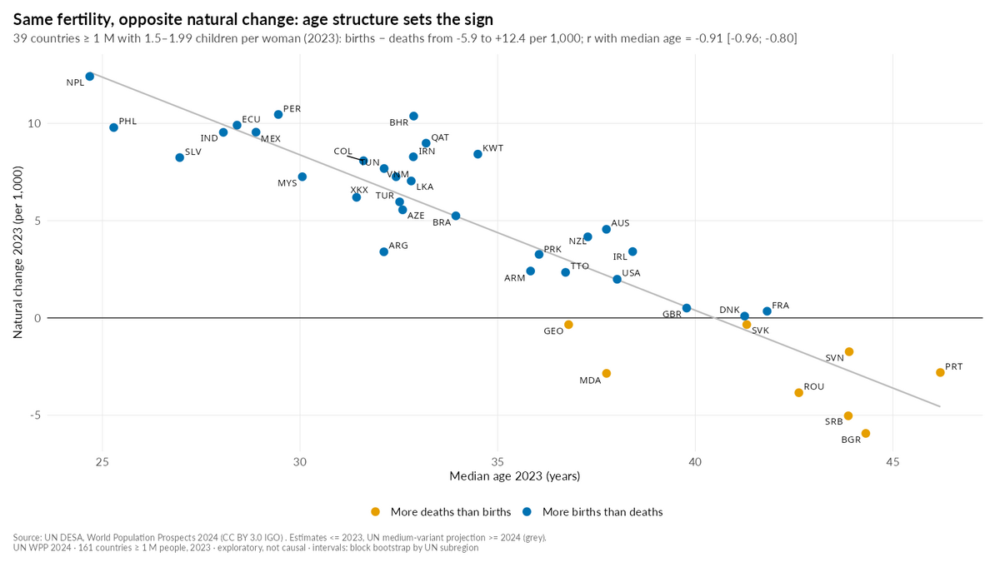

In [121]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q2/).
mostrar_figuras("q2", c("q2_12_same_fertility_natural_change"))

#### Lectura de resultados · §8 Hallazgo de demografía: misma fecundidad, saldo natural opuesto (dem01)

*Texto de `docs/resultados_q2.md` §8 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Entre los países ≥ 1 M con TFR de 1,5 a 1,99 (2023), medimos el rango del saldo natural y su relación con la edad mediana. Entre los que están bajo reemplazo (TFR < 2,1), comparamos qué explica la TFR sola y qué explican la TFR y la edad mediana juntas.

| Cifra | Valor | IC bloques | Clave |
|---|---|---|---|
| Países con TFR 1,5–1,99 | 39 | censo | `n_band_tfr` |
| Saldo natural mínimo / máximo | **−5,9 ‰ (Bulgaria) / +12,4 ‰ (Nepal)** | — | `nat_min_band`, `nat_max_band` |
| r(saldo natural, edad mediana) en esa banda | −0,91 | [−0,96; −0,80] | `r_nat_medage_band` |
| Bajo reemplazo: R² ajustado del saldo natural ~ TFR | **0,36** (sin ajustar 0,37) | [0,19; 0,60] | `r2_nat_tfr_belowrepl` |
| ~ TFR + edad mediana | **0,83** | [0,73; 0,90] | `r2_nat_tfr_medage_belowrepl` |

Figura: `q2_12_same_fertility_natural_change.png`.

**Lectura.** Con la misma fecundidad, el saldo natural va de −5,9 a +12,4 por 1 000 y sigue a la edad mediana (r = −0,91). Entre los países bajo reemplazo, la TFR sola explica un tercio de las diferencias de saldo natural; con la edad mediana, más de cuatro quintos. Se reproducen las cifras del memo de demografía (37 % → 83 %).

### Q2 · §10 Redundancia (solo notebook): VIF y correlaciones parciales

*Exploratory (solo notebook)* · `R/03_q2_un_numero.R` líneas 1651–1675

In [122]:
# =============================================================================
# 10. Redundancia (solo notebook): VIF y correlaciones parciales
#     Qué: VIF de las 12 variables y correlaciones parciales de las 8 no
#     redundantes. Por qué: muestra que varias variables son casi duplicados
#     mecánicos (no se deben regresar unas sobre otras como independientes).
# =============================================================================

vif12 <- vapply(VARS_12, function(v) 1 / (1 - summary(stats::lm(stats::reformulate(setdiff(VARS_12, v), v), data = d23))$r.squared), numeric(1))
vars_nr <- CONJUNTOS_PCA[["8 non-redundant (MV)"]]
Rm <- stats::cor(d23[, vars_nr]); Pm <- -stats::cov2cor(solve(Rm)); diag(Pm) <- 1
pares_parc <- list(c("TFR", "LEx"), c("TFR", "CNMR"), c("LEx", "CDR"), c("MedianAgePop", "CDR"), c("TFR", "MedianAgePop"))
tabla_red <- bind_rows(
  tibble(tipo = "VIF 12", par = VARS_12, valor = unname(vif12)),
  map_dfr(pares_parc, \(p) tibble(tipo = "simple r (8 non-redundant)", par = paste(p, collapse = "–"), valor = Rm[p[1], p[2]])),
  map_dfr(pares_parc, \(p) tibble(tipo = "partial r (8 non-redundant)", par = paste(p, collapse = "–"), valor = Pm[p[1], p[2]]))
)
write_parquet(tabla_red, ruta_parquet_q2("redundancia"))
anotar("vif_max_12", max(vif12), "VIF", "0", sprintf("Largest variance inflation factor among the 12 PCA indicators (%s), 2023", names(which.max(vif12))),
       FILTRO_1M_2023, "T9.6", USO_NB, method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M,
       sens_note = paste(sprintf("%s %.0f", names(sort(vif12, decreasing = TRUE))[1:4], sort(vif12, decreasing = TRUE)[1:4]), collapse = " · "))
anotar("partial_r_tfr_lex", Pm["TFR", "LEx"], "r", "0.00",
       "Partial correlation of TFR and life expectancy given the other 6 non-redundant indicators, 2023",
       FILTRO_1M_2023, "T9.6", USO_NB, method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = UNIVERSO_1M,
       sens_note = sprintf("simple correlation %.2f", Rm["TFR", "LEx"]))

#### Lectura de resultados · §9 Redundancia (solo notebook)

*Texto de `docs/resultados_q2.md` §9 (escrito sobre la corrida oficial de este script; cifras reales).*

VIF de las 12 variables: LEx 335, CBR 200, crecimiento 131, TFR 81 (`vif_max_12`). Correlación parcial TFR–LEx dadas las otras 6 no redundantes: +0,10 (simple: −0,85) (`partial_r_tfr_lex`). Varias variables son casi duplicados mecánicos, y por eso el PCA se lee como estructura y no como "efectos" separados.

### Q2 · §11 Hipótesis de Q2, guardado del registro y comprobaciones finales

*Estado de H6, H7, H7a, H8, H8a, H13, H20* · `R/03_q2_un_numero.R` líneas 1676–1742

In [123]:
# =============================================================================
# 11. Hipótesis de Q2, guardado del registro y comprobaciones finales
#     Qué: estado de H6, H7, H7a, H8, H8a, H13 y H20 según las reglas fijadas en
#     docs/hipotesis_preinscritas.md; se publica el resultado sea cual sea.
# =============================================================================

estado_txt <- function(ok, parcial = FALSE) if (isTRUE(ok)) "confirmed" else if (parcial) "partly" else "rejected"
tabla_hip <- tibble(
  id = c("H6", "H7", "H7a", "H8", "H8a", "H13", "H20"),
  enunciado_en = c("Fertility alone explains ≥ 70 % of median age and of 2023→2050 change, ≤ 60 % of growth, ≤ 10 % of migration",
                   "PC1 of the 12-indicator PCA < 50 % and 3 components needed for 70 %",
                   "Exactly 2 components beat parallel analysis; |r(TFR, PC1)| > 0.9 and |r(TFR, PC2)| < 0.2",
                   "Index design moves 1 in 4 countries (24 %) more than 20 places (7 variants)",
                   "≥ 10 % of countries have a 90 % rank interval > 20 places, more than with only normalization/aggregation",
                   "ρ(CDR, LEx) < −0.9 in 1950 and its 2023 interval contains 0",
                   "Fertility alone recovers < 25 % of the 5 real look-alikes; PC1 + PC2 > 40 %"),
  estatus = c("pre-specified", "pre-specified", "exploratory", "pre-specified", "pre-specified", "pre-specified", "exploratory"),
  resultado = c(estado_txt(h6_ok_punto && h6_ok_cv), estado_txt(h7_ok), estado_txt(h7a_ok), estado_txt(h8_ok),
                estado_txt(h8a_ok), estado_txt(h13_ok), estado_txt(h20_ok)),
  evidencia = c(
    sprintf("adj R² %.3f / %.3f / %.3f / %.3f; 10-fold CV %.3f / %.3f / %.3f / %.3f", r2_adj[1], r2_adj[2], r2_adj[3], r2_adj[4],
            cv_media[1], cv_media[2], cv_media[3], cv_media[4]),
    sprintf("PC1 %.1f %% [%.1f; %.1f]; %d components for 70 %% (2 PCs = %.1f %%)", 100 * ve23[1], bs_pca$ci_low[["pc1"]],
            bs_pca$ci_high[["pc1"]], n_pcs_70, 100 * sum(ve23[1:2])),
    sprintf("%d dimensions (eigenvalues %s vs noise %s); r(TFR, PC1) = %.3f, r(TFR, PC2) = %.3f", ap23$n_dims,
            paste(sprintf("%.2f", ap23$obs[1:3]), collapse = "/"), paste(sprintf("%.2f", ap23$p95[1:3]), collapse = "/"),
            r_tfr_pc1_v, r_tfr_pc2_v),
    sprintf("7 variants: %.1f %% move > 20 places (normalization only %.1f %%, weights only %.1f %%, migration %.1f %%)",
            share7, share7_norm, share7_pesos, share7_mig),
    sprintf("declared MC %.1f %% vs normalization/aggregation only %.1f %% (Dirichlet(5) fixed %.1f %%, Dirichlet(1) %.1f %%)",
            pct_mc[["declared"]], pct_mc[["norm_only"]], pct_mc[["dir5_fixed5"]], pct_mc[["dir1"]]),
    sprintf("1950 %.3f [%.3f; %.3f]; 2023 %.3f [%.3f; %.3f] (block bootstrap)", r_1950$valor, r_1950$ci_low, r_1950$ci_high,
            r_2023$valor, r_2023$ci_low, r_2023$ci_high),
    sprintf("TFR %.1f %% [%.1f; %.1f]; PC1+PC2 %.1f %% [%.1f; %.1f]; chance %.1f %%", knn_tfr_v, bs_knn$ci_low[["tfr"]],
            bs_knn$ci_high[["tfr"]], knn_pc12_v, bs_knn$ci_low[["pc12"]], bs_knn$ci_high[["pc12"]], azar_pct)
  )
)
print(tabla_hip, width = 250)
write_parquet(tabla_hip, ruta_parquet_q2("hipotesis"))
anotar("hyp_q2_status", as.data.frame(tabla_hip |> select(id, status = estatus, result = resultado, evidence = evidencia)),
       NA, "text", "Result of each Q2 hypothesis under the decision rules of docs/hipotesis_preinscritas.md",
       "See each hypothesis", "T17.q2", USO_NB, method = "descriptive", status = "descriptive",
       n = N_PAISES_1M, universe = UNIVERSO_1M)
anotar("n_tests_q2", nrow(tabla_hip), "hypotheses", "0",
       "Number of pre-specified or exploratory hypotheses evaluated in Q2 (family F1; no p-values reported)",
       "Q2 hypotheses", "T17.q2", USO_NB, method = "descriptive", status = "descriptive",
       n = nrow(tabla_hip), universe = UNIVERSO_1M,
       sens_note = "illustrations (twins, Colombia, highlighted countries) are family F3 and not tested")

# Guardado y validación del registro.
guardar_numbers(reg, RUTA_NUMBERS_Q2, ordenar = TRUE)
problemas_reg <- validar_registro(reg)
ic_pantalla_mal <- problemas_reg[grepl("no puede salir en pantalla", problemas_reg$problema), , drop = FALSE]
if (nrow(problemas_reg) > 0) {
  message("validar_registro(): ", nrow(problemas_reg), " observaciones:")
  print(problemas_reg)
}
faltan_slide3 <- claves_faltantes(reg, "slide3")
if (length(faltan_slide3) > 0) warning("Faltan claves obligatorias de la Slide 3: ", paste(faltan_slide3, collapse = ", "), call. = FALSE)
reg_leido <- leer_numbers(RUTA_NUMBERS_Q2)
stopifnot(identical(sort(names(reg_leido)), sort(names(reg))))

t_total <- as.numeric(difftime(Sys.time(), t_inicio, units = "secs"))
message(sprintf("== Q2 terminado: %d claves en %s; %d figuras en %s; tiempo total %.1f s ==",
                length(reg), RUTA_NUMBERS_Q2, length(list.files(RUTA_FIG_Q2, pattern = "\\.png$")), RUTA_FIG_Q2, t_total))
writeLines(capture.output(sessionInfo()), file.path(RUTA_FIG_Q2, "sessionInfo_q2.txt"))
invisible(TRUE)

# A tibble: 7 × 5
  id    enunciado_en                                                                                                 estatus       resultado
  <chr> <chr>                                                                                                        <chr>         <chr>    
1 H6    Fertility alone explains ≥ 70 % of median age and of 2023→2050 change, ≤ 60 % of growth, ≤ 10 % of migration pre-specified confirmed
2 H7    PC1 of the 12-indicator PCA < 50 % and 3 components needed for 70 %                                          pre-specified rejected 
3 H7a   Exactly 2 components beat parallel analysis; |r(TFR, PC1)| > 0.9 and |r(TFR, PC2)| < 0.2                     exploratory   confirmed
4 H8    Index design moves 1 in 4 countries (24 %) more than 20 places (7 variants)                                  pre-specified rejected 
5 H8a   ≥ 10 % of countries have a 90 % rank interval > 20 places, more than with only normalization/aggregation     pre-specified confi

== Q2 terminado: 96 claves en /home/darkns/Documents/ASA_Dataquest/RepoGithub/figures/numbers_q2.json; 13 figuras en /home/darkns/Documents/ASA_Dataquest/RepoGithub/figures/review/q2; tiempo total 91.6 s ==



#### Lectura de resultados · §10 Estado de las hipótesis preinscritas de Q2

*Texto de `docs/resultados_q2.md` §10 (escrito sobre la corrida oficial de este script; cifras reales).*

| ID | Estatus | Resultado | Evidencia (cifras reales) |
|---|---|---|---|
| **H6** | pre-specified | **Confirmada** (con matiz) | R² ajustado 0,771 / 0,881 / 0,590 / −0,001; VC 0,766 / 0,878 / 0,581 / −0,027. Matiz: el 0,88 de 2050 es en parte por construcción (observado a 27 años: ≤ 0,50) y el R² del crecimiento cambia mucho de un año a otro (0,01–0,69). |
| **H7** | pre-specified | **Rechazada** | PC1 56,7 % [51,4; 62,6] (no < 50 %); bastan 2 componentes para 70 % (74,6 %). |
| **H7a** | exploratory | **Confirmada** (con matiz) | 2 dimensiones (6,80 / 2,15 vs ruido 1,58 / 1,43); r(TFR, PC1) = −0,945; r(TFR, PC2) = 0,033. Sensibilidad: de 1 a 3 dimensiones según el caso. |
| **H8** | pre-specified | **Rechazada como cifra** | 7 variantes: 9,3 % (no ≈ 24 %); el 24 % era un efecto de los microestados. |
| **H8a** | pre-specified | **Confirmada** | Monte Carlo declarado 21,7 % ≥ 10 % y > 2,5 % (solo fórmulas). |
| **H13** | pre-specified | **Confirmada** | 1950 −0,974 [−0,981; −0,939]; 2023 0,067 [−0,306; 0,321] (iid [−0,087; 0,222]). |
| **H20** | exploratory | **Confirmada** (con matiz) | TFR 13,2 % [8,6; 17,7] < 25 %; PC1+PC2 43,2 % [40,1; 46,2] > 40 %; azar 3,1 %. La parte "> 40 %" no se cumple en 1990 (34 %), con 237 países (38 %) ni sin Golfo (39 %). |

Tabla en `resultados_q2_hipotesis.parquet` y clave `hyp_q2_status`; `n_tests_q2` = 7. No se calculan p-valores. Las ilustraciones (gemelos, Colombia, país destacado) son familia F3 y no se contrastan.

**Reproducibilidad.** `set.seed(2026)` justo antes de cada bloque aleatorio; generador Mersenne-Twister / Inversion / Rejection. Dos corridas seguidas producen el mismo `numbers_q2.json` (sha256 `1532abfe…d829`) y el mismo `lookalikes_todos.csv`. `sessionInfo()` en `figures/review/q2/sessionInfo_q2.txt`.

#### Lectura de resultados · §11 Hallazgos sorprendentes (nuevos respecto a los memos)

*Texto de `docs/resultados_q2.md` §11 (escrito sobre la corrida oficial de este script; cifras reales).*

1. **La proyección "cree" en la fecundidad más que la historia.** La TFR de 2023 explica el 88 % del cambio de población proyectado a 2050, pero en 47 ventanas observadas de 27 años (1950→1977 … 1996→2023) nunca explicó más del 50 % (mediana 40 %). El "partly by construction" del pie ya tiene número.
2. **El R² del crecimiento sobre la TFR no es una constante:** va de 0,01 (1990: Kuwait −71 %, Liberia −30 %) a 0,69 (2020), con 0,16 en 2022 (año de la guerra en Ucrania). El de la edad mediana se queda entre 0,73 y 0,81 en los 74 años. Esto da la prueba empírica de "historia lenta vs palancas rápidas".
3. **En 90 de 161 países (56 %) la fecundidad sola no encuentra ni uno** de sus 5 look-alikes reales.
4. **El "1 de cada 4" del índice (EDA v1) era un efecto de los microestados:** con los 161 países ≥ 1 M, las 7 variantes mueven solo al 9 %. La fragilidad aparece cuando se admite incertidumbre en los **pesos** (Monte Carlo: 22 %).
5. **Los intervalos por bloques son mucho más anchos que los iid** en las correlaciones que cambian de significado: ρ(CDR, LEx) 2023 [−0,31; 0,32] frente a [−0,09; 0,22] (≈ 2×), y PC1 [51; 63] frente a [55; 59] (≈ 2,8×). Para el scorecard, la relación es de 1,5 a 2,5×.
6. **El bootstrap ingenuo de los vecinos más cercanos está sesgado:** rehacer los vecinos en réplicas con países repetidos da [14; 26] para un valor de 13. Se corrigió y se documentó (§5); los agentes que usen kNN en otras preguntas deberían saberlo.
7. La regla de gemelos con misma LEx devuelve **Bosnia–Jordania**, el par retirado del vídeo; la regla de "mismo crecimiento, motores opuestos" devuelve tres veces **Sudán** (crisis), no el India–Lituania del memo.

#### Lectura de resultados · §12 Limitaciones

*Texto de `docs/resultados_q2.md` §12 (escrito sobre la corrida oficial de este script; cifras reales).*

1. **Corte transversal de un año (2023):** el R² del crecimiento depende mucho del año (§2). Las cifras de edad mediana son estables; las de crecimiento, no.
2. **R² lineal:** con un spline natural la edad mediana sube a 0,864; la TFR "pierde" algo por la linealidad. Se reporta el ajustado lineal porque así se pre-especificó H6.
3. **Proyecciones como salida:** el cambio 2023→2050 y los casos de 2050 (PCA, look-alikes, ρ CDR–LEx) son un escenario Medium construido en parte con la fecundidad; nunca son evidencia.
4. **Migración:** la CNMR es el componente peor medido (a menudo un residuo censal). El eje 2 del PCA y los look-alikes del Golfo dependen de 6 países y de la winsorización (comprobado con asinh y sin Golfo).
5. **Bootstrap por bloques con 20 subregiones:** con pocos bloques, los percentiles son inestables y los intervalos, anchos. Describen sensibilidad a la composición regional, no error muestral (los 161 países no son una muestra).
6. **Look-alikes:** dependen de las 12 variables, de k y del desempate alfabético. El IC final no capta cómo cambia el conjunto de vecinos; eso lo cubre la sensibilidad sin una subregión (12,9–15,5 % para la TFR).
7. **Índice:** las distribuciones del Monte Carlo (Dirichlet(5), 50 % de inclusión del crecimiento) son decisiones; por eso se dan 2,5–47 %. Es un índice de etapa de la transición, no de desarrollo; nunca tabla de liga ni rojo/verde.
8. **Gemelos y Colombia:** son ilustraciones elegidas por regla (12 880 pares) o por posicionalidad declarada. No se hace inferencia sobre ellos.
9. **Calidad de datos:** Chad y Sudán (2023) reflejan desplazamiento forzado; la CDR de países en crisis puede venir de ajustes de la ONU. RCA aparece en R3 (2.º par) y no se usa como ejemplo (posible artefacto, `07` §4.2 V1).

## 5. Q3 — Same road, different speed: four groups and what the UN should watch (P6 + P1 + recomendaciones)

Script: `R/04_q3_caminos.R` · lecturas: `docs/resultados_q3.md` · figuras de revisión: `figures/review/q3/`.

> Agente `notebook-Q3` · 2026-10-23 · Script: `R/04_q3_caminos.R`. Se ejecuta de principio a fin con `Rscript R/04_q3_caminos.R` desde la raíz del repo. Tarda **179–190 s** según la carga de la máquina (última corrida: 186,4 s, con otros agentes en paralelo). Termina sin errores ni avisos. Dos corridas seguidas dan la misma salida de consola, salvo los tiempos.
> Cifras: `figures/numbers_q3.json` (**109 claves**, esquema v2 de 36 campos; `verified: false` hasta que pase QA-stats). No hay ninguna clave repetida con `numbers_q1.json` ni con `numbers_q2.json`. Tablas: `data/processed/resultados_q3_*.parquet` (12 tablas, con las columnas documentadas al inicio del script) y `figures/miembros_grupos.csv`. Figuras de revisión (no son las finales): `figures/review/q3/q3_01…q3_18.png` (1600×900). Revisamos cada una a mano.
> Universo: **161 países ≥ 1 M** (población 2023), estimaciones de la ONU 1950–2023, salvo que se diga otra cosa. Los conteos de países usan los **237 países y áreas**. La proyección Medium 2024–2100 va siempre aparte y etiquetada (*UN medium projection*). "IC" = intervalo 95 % por **bootstrap por bloques de las 20 subregiones ONU** (B = 2 000, semilla 2026); es el único que puede salir en pantalla. "iid" = bootstrap BCa por país, solo para comparar. Todo es descriptivo: nada de lo que sigue es causal.

#### Resumen en 7 líneas (de `docs/resultados_q3.md`)

1. **Tres tramos de un mismo camino y un grupo migratorio (H9a ✔).** El k-means con k = 4 sobre 70 años de trayectoria da una silueta de **0,37** (con k = 2 sería 0,44; el estadístico gap elige k = 3). Los tamaños son 50 / 51 / 53 / 7 y las poblaciones 1,44 / 4,90 / 1,67 / 0,07 mil M. **India está en Fast movers.** Los grupos son estables (Jaccard 0,78–0,95; FPCA ARI 0,96). Aun así, el **42 %** de los países está entre dos grupos: es un continuo, no cajas.
2. **"Mostly Gulf states" se cumple.** Migration-led = Arabia Saudí, Jordania, EAU, Kuwait, Catar, Baréin y Yibuti: **5 de 7** son del Consejo de Cooperación del Golfo. Omán queda en Fast movers.
3. **Los vecinos comparten camino (H25 ✔).** El **66,7 %** de los enlaces entre vecinos une países del mismo grupo; al azar sería el 30,3 % (banda 26,5–34,5 %), 2,2 veces más. Pero la región ODS sola acierta el 77,5 %, más que el voto de los 5 vecinos (73,9 %). La geografía que importa es la regional.
4. **P1: depende del indicador (H10 ✔, H11a ✔).** Entre países, la DE de la esperanza de vida bajó de **12,2 a 7,4** años y la de la edad mediana subió de **4,7 a 9,7**. La DE de la esperanza de vida a los 65 subió de **1,47 a 2,85**. Para la mortalidad infantil, la razón P90/P10 pasó de **6× a 20×**, aunque la brecha absoluta se cerró de 311 a 64 por mil.
5. **Misma ruta, distinto ritmo.** De 5 a 3 hijos por mujer, China tardó **5,1 años** y Egipto **32,7**. Son el más rápido y el más lento de los 36 países ≥ 10 M que completaron el tramo: la regla se confirma. La mediana de Kaplan-Meier es de 19,2 años en Fast movers y 29,6 en Recent movers.
6. **Envejecer de 30 a 40 años de edad mediana, por camino:** Fast movers **32 años** [27; 37] frente a Early movers **36,5** [29; 42,5]. Esta diferencia es pequeña. La que sí es grande es la de **fecha de inicio**: quienes llegaron a 30 en 1990–2023 tardan 24 años, y quienes llegaron antes de 1990 tardaron 40,5. Los Fast movers que ya están en 30 tardan 23,5.
7. **Qué vigilar.** 58 de 70 países con mortalidad infantil > 25 ‰ seguirán por encima en 2030 incluso en la proyección; solo 8 bajan al ritmo necesario (H23 ✔). Hay 22 países bajo reemplazo que aún crecen por nacimientos (2,2 mil M), con **34–38 años más** de crecimiento proyectado. Los países con más muertes que nacimientos pasaron de **8 a 53** (H14a ✔) y en ellos vive el 28 % de la humanidad; serían 106 en 2050 (proyección). El mundo llegaría a su máximo en **2084**, con **10,29 mil M** (proyección).

In [124]:
# Aislamiento: Q3 corre como `Rscript R/04_q3_caminos.R` (entorno global vacío, carpeta = raíz del repo).
entorno_limpio()

In [125]:
#!/usr/bin/env Rscript
# =============================================================================
# 04_q3_caminos.R
# Question 3 — "Same road, different speed: four roads and what the UN should
# watch" (P6 + P1 + recomendaciones). Agente notebook-Q3.
#
# Qué hace (plan analítico v2 §4-Q3, plan de implementación T11, T12, T15, T16):
#   1. Agrupa los 161 países >= 1 M por su TRAYECTORIA 1950-2023 (medias por
#      década de TFR, LEx, edad mediana y CNMR winsorizada) con k-means k = 4.
#   2. Valida los grupos: FPCA, Ward, PAM, Mclust, Jaccard bootstrap,
#      estabilidad por país (keep_share), fanny, sin CNMR, asinh, niveles 2023,
#      rejilla de sensibilidad, y contigüidad espacial (join count).
#   3. P1: divergencia entre países (DE, CV, P10-P90) de edad mediana, LEx,
#      LE65, LE60 (suplemento) y mortalidad infantil (razón P90/P10).
#   4. Proyección Medium 2024-2050 por grupo (escenario, siempre etiquetado).
#   5. Cifras del mundo, complementos demográficos y la tabla
#      "What to watch, where, when" (recomendaciones revisadas por demografía).
#
# Ejecución (desde la raíz del repo):  Rscript R/04_q3_caminos.R
#
# Decisiones (ASA 2022 B.2, B.4, C.2; plan §3):
#   * Muestra de modelos = 161 países >= 1 M (2023); conteos con los 237.
#   * Estimaciones (<= 2023) y proyección Medium (>= 2024) SIEMPRE separadas;
#     ningún estadístico usa una ventana que cruce 2023/24.
#   * CNMR winsorizada a +-3 DE del panel 161 x 1950-2023 solo para clustering.
#   * z-estandarización con media y DE de TODO el panel (no por año).
#   * k = 4 fijado a priori (H9a); la CNMR entra a priori.
#   * Semilla 2026 (Mersenne-Twister / Inversion / Rejection) justo antes de
#     cada k-means, bootstrap o permutación.
#   * Lenguaje descriptivo: grupos = caminos demográficos, no desarrollo.
#
# SALIDAS
#   figures/numbers_q3.json                — claves de Q3 (esquema v2, registrar_cifra)
#   figures/miembros_grupos.csv            — país -> grupo (lista pública)
#   figures/review/q3/q3_*.png             — gráficas rápidas de revisión (1600x900)
#   data/processed/resultados_q3_*.parquet — tablas intermedias (columnas abajo)
#
# COLUMNAS DE LAS TABLAS INTERMEDIAS
#   resultados_q3_paises.parquet (una fila por país, 161 >= 1 M):
#     ISO3_code, Location, subregion, region_sdg, ingreso, pob_2023_miles
#     grupo            camino (Early movers / Fast movers / Recent movers / Migration-led)
#     cluster_kmeans   etiqueta bruta 1-4 del k-means principal
#     silueta          silueta individual (distancia euclídea en los 32 rasgos)
#     keep_share       % de submuestras al 80 % en que el país queda en su grupo
#     fanny_max        pertenencia difusa máxima (fanny, memb.exp = 1.5)
#     grupo_fpca, grupo_ward, grupo_pam, grupo_sin_cnmr, grupo_asinh,
#     grupo_niveles_2023  particiones alternativas (etiquetas 1-4, no nombres)
#     pc1_rasgos, pc2_rasgos  coordenadas en el PCA de los 32 rasgos
#     es_medoide, es_ejemplo  país medoide / entre los 3 más poblados del grupo
#     vecinos_mismo_grupo     fracción de sus 5 vecinos más cercanos en su grupo
#     voto_vecinos            grupo mayoritario entre sus 5 vecinos
#     tfr_1950, anio_tfr4, cnmr_media_2000_23  insumos de la regla de nombres
#     q5_2023, le65_2023, le60_2023, medage_2023, medage_2050, le60_2050,
#     le65_2050, cambio_pob_2023_2050_pct  descripción externa (2050 = proyección)
#     anio_pico_pob, tipo_pico  año del máximo de población 1950-2100 y si cae
#                               en estimación, proyección o "sin pico antes de 2100"
#     y_medage30, y_medage40, anios_30_40, censura_30_40, y40_proyectado
#     c5, c4, c3, dur53, evento53  cruces (año continuo, TFR suavizada lambda = 10)
#     tipo_palanca_2023, inercia, natneg_2023, sdg32_above, sdg32_on_pace,
#     sdg32_above_2030       estado de la palanca (Q1) y ODS 3.2
#   resultados_q3_rasgos.parquet: ISO3_code + 32 rasgos z (VAR_decada)
#   resultados_q3_bandas.parquet: grupo, variable, Time, n, mediana, p10, p90, periodo_en
#   resultados_q3_dispersion.parquet: universo, variable, Time, n, media, de, cv (%),
#     p10, p25, p50, p75, p90, de_log (Q5), razon_p90p10, brecha_p90p10,
#     r2_region, r2_ingreso, periodo_en
#   resultados_q3_curvas.parquet: ISO3_code, grupo, Time, TFR, TFR_suav, tau4 (= Time - c4), periodo_en
#   resultados_q3_sensibilidad.parquet: metodo, muestra, cnmr, periodo, ari, silueta, tamanos
#   resultados_q3_vecinos.parquet: matriz W, grupo, observado, azar, banda_lo, banda_hi
#   resultados_q3_proyeccion.parquet: grupo, ventana, periodo_en, pob_inicio_bn, nat_bn, mig_bn,
#     cambio_bn, nat_pct_pob, mig_pct_pob, cambio_pct_pob, share_nat, share_mig
#   resultados_q3_recomendaciones.parquet: filas de la tabla "What to watch, where, when"
#   resultados_q3_hipotesis.parquet: id, regla, resultado, estado
#   resultados_q3_envejecimiento.parquet: grupo, n, n_censura_2100, n_inicio_proy, n_fin_proy,
#     n_izq_1950, km_mediana (años 30 -> 40, Kaplan-Meier), mediana_completos, ci_low, ci_high (bloques)
#   resultados_q3_inercia_pico.parquet: ISO3_code, anio_pico (máximo 2023-2100, UN medium), pob23,
#     pob_1m, anios_crec (= anio_pico - 2023), anio_bajo_21 (primer año TFR < 2,1), anios_desde_21
#
# Convención: código y comentarios en español; textos de figuras en inglés.
# =============================================================================

t_inicio <- Sys.time()
options(warn = 1, dplyr.summarise.inform = FALSE, width = 140)

### Q3 · §0 Preparación: infraestructura común, paquetes y rutas

`R/04_q3_caminos.R` líneas 84–151

In [126]:
# =============================================================================
# 0. Preparación: infraestructura común, paquetes y rutas
# =============================================================================
# Qué: carga la API compartida (datos, constantes, incertidumbre). Por qué: una
# sola fuente de verdad para muestras, paletas y registro de cifras.
suppressPackageStartupMessages(library(here))
source(here::here("R", "config.R"))
source(here::here("R", "utilidades.R"))
source(here::here("R", "comun_analisis.R"))
source(here::here("R", "incertidumbre.R"))

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(patchwork)
  library(cluster)
  library(sf)
  library(mclust)   # Mclust() busca mclustBIC() en el entorno: hay que adjuntarlo
})
# fda, fda.usc, clue, survival, sandwich, data.table, ggrepel se usan con
# `paquete::` para no enmascarar dplyr::select (fda adjunta MASS).
for (.p in c("fda", "fda.usc", "clue", "survival", "sandwich", "data.table",
             "ggrepel", "rnaturalearth", "countrycode", "scales")) {
  if (!requireNamespace(.p, quietly = TRUE)) stop("Falta el paquete ", .p, call. = FALSE)
}
suppressPackageStartupMessages(invisible(loadNamespace("fda.usc")))
rm(.p)

RNGkind("Mersenne-Twister", "Inversion", "Rejection")
set.seed(SEMILLA)

RUTA_Q3_REVIEW <- file.path(RUTA_FIG_REVIEW, "q3")
RUTA_NUMBERS_Q3 <- file.path(RUTA_FIGURAS, "numbers_q3.json")
dir.create(RUTA_Q3_REVIEW, recursive = TRUE, showWarnings = FALSE)

ANIOS_EST <- ANIO_INICIO_DATOS:ANIO_FIN_ESTIMACION          # 1950-2023
VARS_TRAY <- c("TFR", "LEx", "MedianAgePop", "CNMR")          # rasgos del clustering
NIVELES_GRUPO <- names(PALETA_GRUPOS_V2)                      # Early, Fast, Recent, Migration-led
K_GRUPOS <- 4L
B_JACCARD <- 200L                                             # plan T11
B_KEEP <- 500L                                                # plan T11 (500 x 80 %)
B_GAP <- 100L

ari <- function(a, b) mclust::adjustedRandIndex(a, b)
cat_sec <- function(...) cat("\n====", ..., "====\n")

# Frase hablada para una proporción ("two in three", "four in ten", ...).
say_fraccion <- function(p) {
  fr <- c("one in ten" = 0.1, "one in five" = 0.2, "one in four" = 0.25, "one in three" = 1 / 3,
          "four in ten" = 0.4, "half" = 0.5, "six in ten" = 0.6, "two in three" = 2 / 3,
          "three in four" = 0.75, "four in five" = 0.8, "nine in ten" = 0.9)
  names(fr)[which.min(abs(fr - p))]
}
# Nombre hablado corto de un país (para `say`; el texto en pantalla usa WPP).
ALIAS_VOZ <- c(USA = "the United States", RUS = "Russia", GBR = "the United Kingdom",
               KOR = "the Republic of Korea", PRK = "North Korea", IRN = "Iran", TUR = "Türkiye",
               VNM = "Viet Nam", COD = "DR Congo", TZA = "Tanzania", SYR = "Syria",
               ARE = "the UAE", BOL = "Bolivia", VEN = "Venezuela", LAO = "Lao PDR",
               MDA = "Moldova", PSE = "the State of Palestine", XKX = "Kosovo",
               HKG = "Hong Kong SAR", TWN = "Taiwan Province of China", SAU = "Saudi Arabia")
nombre_voz <- function(iso3) {
  out <- nombre_pais(iso3)
  out[iso3 %in% names(ALIAS_VOZ)] <- ALIAS_VOZ[iso3[iso3 %in% names(ALIAS_VOZ)]]
  out
}
unir_voz <- function(x) if (length(x) <= 1) x else paste0(paste(x[-length(x)], collapse = ", "), " and ", x[length(x)])

comun_analisis.R listo: 237 países y áreas (161 >= 1 M; 22/20 subregiones), estimaciones 1950-2023, proyección Medium 2024-2100, semilla 2026.



### Q3 · §1 Datos y rasgos de trayectoria (simple: medias por década)

*Descriptive* · `R/04_q3_caminos.R` líneas 152–222

In [127]:
# =============================================================================
# 1. Datos y rasgos de trayectoria (simple: medias por década)
# =============================================================================
# Qué: panel 161 x 1950-2023 de 4 indicadores, CNMR winsorizada, z sobre el
# panel y medias por década (8 décadas x 4 = 32 rasgos). Por qué: resume 70
# años de movimiento en números comparables entre países (plan §4-Q3 R1).
cat_sec("1. Datos y rasgos")
COLS_ID_Q3 <- c("ISO3_code", "Location", "Time", "subregion", "region_sdg", "ingreso",
                "TPopulation1July")
pan161 <- paises_1m(periodo = "estimacion") |>
  dplyr::select(dplyr::all_of(COLS_ID_Q3), dplyr::all_of(VARS_TRAY)) |>
  dplyr::arrange(ISO3_code, Time)
stopifnot(nrow(pan161) == N_PAISES_1M * length(ANIOS_EST), !anyNA(pan161[VARS_TRAY]))
pan237 <- paises_todos(periodo = "estimacion") |>
  dplyr::select(dplyr::all_of(COLS_ID_Q3), dplyr::all_of(VARS_TRAY)) |>
  dplyr::arrange(ISO3_code, Time)
stopifnot(!anyNA(pan237[VARS_TRAY]))

# Transformación de la CNMR (winsor +-3 DE del panel / asinh / cruda).
transformar_cnmr <- function(x, modo = c("winsor", "asinh", "crudo")) {
  modo <- match.arg(modo)
  switch(modo,
         winsor = { m <- mean(x); s <- sd(x); pmin(pmax(x, m - 3 * s), m + 3 * s) },
         asinh = asinh(x / 5),
         crudo = x)
}
# Panel estandarizado (z con media y DE de todo el panel).
panel_z <- function(pan, vars = VARS_TRAY, modo_cnmr = "winsor") {
  p <- pan
  if ("CNMR" %in% vars) p$CNMR <- transformar_cnmr(p$CNMR, modo_cnmr)
  p |> dplyr::mutate(dplyr::across(dplyr::all_of(vars), ~ (.x - mean(.x)) / sd(.x)))
}
# Medias por periodo (décadas: 1950s ... 2010s + 2020-23; quinquenios: 15).
rasgos_desde_z <- function(pz, vars = VARS_TRAY, periodo = c("decadas", "quinquenios")) {
  periodo <- match.arg(periodo)
  pz$per <- if (periodo == "decadas") {
    ifelse(pz$Time >= 2020, "2020s", paste0(floor(pz$Time / 10) * 10, "s"))
  } else {
    q <- floor((pz$Time - 1950) / 5) * 5 + 1950
    ifelse(q >= 2020, "2020-23", paste0(q, "-", substr(q + 4, 3, 4)))
  }
  f <- pz |>
    dplyr::group_by(ISO3_code, per) |>
    dplyr::summarise(dplyr::across(dplyr::all_of(vars), mean), .groups = "drop") |>
    tidyr::pivot_wider(names_from = per, values_from = dplyr::all_of(vars), names_sep = "_") |>
    dplyr::arrange(ISO3_code)
  X <- as.matrix(f[, -1])
  rownames(X) <- f$ISO3_code
  X
}
rasgos_trayectoria <- function(pan, vars = VARS_TRAY, modo_cnmr = "winsor", periodo = "decadas") {
  rasgos_desde_z(panel_z(pan, vars, modo_cnmr), vars, periodo)
}

# Documentar a quién afecta la winsorización (plan §3 "Migración extrema").
lim_cnmr <- mean(pan161$CNMR) + c(-3, 3) * sd(pan161$CNMR)
recortes_cnmr <- pan161 |>
  dplyr::filter(CNMR < lim_cnmr[1] | CNMR > lim_cnmr[2]) |>
  dplyr::count(ISO3_code, sort = TRUE)
n_celdas_winsor <- sum(recortes_cnmr$n)
cat(sprintf("CNMR winsorizada a [%.1f; %.1f] por mil: %d país-años recortados en %d países (%s)\n",
            lim_cnmr[1], lim_cnmr[2], n_celdas_winsor, nrow(recortes_cnmr),
            paste(sprintf("%s %d", recortes_cnmr$ISO3_code, recortes_cnmr$n)[1:min(8, nrow(recortes_cnmr))],
                  collapse = ", ")))

pz161 <- panel_z(pan161)
X <- rasgos_desde_z(pz161)
stopifnot(nrow(X) == N_PAISES_1M, ncol(X) == 32, identical(rownames(X), iso_muestra_1m))
cat("Rasgos:", ncol(X), "| países:", nrow(X), "\n")
D <- dist(X)


==== 1. Datos y rasgos ====


CNMR winsorizada a [-46.7; 47.5] por mil: 144 país-años recortados en 32 países (QAT 25, ARE 22, KWT 17, DJI 9, HKG 8, JOR 8, AFG 5, BHR 5)


Rasgos: 32 | países: 161 


#### Lectura de resultados · §1 Datos y rasgos de trayectoria (sección 1)

*Texto de `docs/resultados_q3.md` §1 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Armamos un panel de los 161 países ≥ 1 M para 1950–2023 con TFR, LEx, edad mediana y CNMR. Cada variable se estandariza (z) con la media y la DE de **todo el panel**. Luego se promedia por década (1950s…2010s, 2020–23): son 32 rasgos por país. La CNMR se winsoriza a ±3 DE del panel, solo para el clustering.

| Decisión | Resultado | Clave |
|---|---|---|
| Límites de la winsorización de CNMR | [−46,7; 47,5] por mil | `n_cnmr_winsor_cells` |
| País-años recortados | **144**, en 32 países (QAT 25, ARE 22, KWT 17, DJI 9, HKG 8, JOR 8, AFG 5, BHR 5) | `n_cnmr_winsor_cells` |
| Sensibilidad asinh(CNMR/5) | ARI 0,934 con la partición principal | `ari_asinh` |
| Sin winsorizar | ARI 0,925 (el grupo pequeño queda en ARE, KWT, QAT) | `ari_asinh.sens_note` |

**Lectura de resultados.** La winsorización toca sobre todo al Golfo y a Hong Kong (8 país-años; incluye los ajustes censales de 1961–69, ver `02_contexto_historico.md`). Cambiar la transformación casi no mueve los grupos (ARI 0,93).

### Q3 · §2 Elección de k (simple: silueta; rico: gap, Mclust)

*Pre-specified (H9, H9a)* · `R/04_q3_caminos.R` líneas 223–255

In [128]:
# =============================================================================
# 2. Elección de k (simple: silueta; rico: gap, Mclust)
# =============================================================================
# Qué: compara k = 2..8 con silueta (k-means, Ward, PAM) y el estadístico gap.
# Por qué: k = 4 está fijado a priori (H9a), pero hay que declarar qué k
# "prefieren" los datos para no vender cajas donde hay un continuo.
cat_sec("2. Elección de k")
km_fit <- function(X, k, nstart = NSTART_KMEANS) {
  set.seed(SEMILLA)
  stats::kmeans(X, k, nstart = nstart, iter.max = 100)
}
sil_media <- function(cl, Dm) mean(cluster::silhouette(as.integer(cl), Dm)[, 3])
arbol_ward <- stats::hclust(D, method = "ward.D2")
tabla_k <- purrr::map_dfr(2:8, function(k) {
  km <- km_fit(X, k)
  wd <- stats::cutree(arbol_ward, k)
  pm <- cluster::pam(D, k, diss = TRUE)
  tibble::tibble(k = k, sil_kmeans = sil_media(km$cluster, D), sil_ward = sil_media(wd, D),
                 sil_pam = pm$silinfo$avg.width, ari_km_ward = ari(km$cluster, wd),
                 ari_km_pam = ari(km$cluster, pm$clustering), tam_min = min(table(km$cluster)))
})
print(tabla_k |> dplyr::mutate(dplyr::across(-c(k, tam_min), ~ round(.x, 3))))
set.seed(SEMILLA)
gap <- cluster::clusGap(X, FUNcluster = function(x, k) list(cluster = stats::kmeans(x, k, nstart = 20, iter.max = 100)$cluster),
                        K.max = 8, B = B_GAP, verbose = FALSE)
k_gap <- cluster::maxSE(gap$Tab[, "gap"], gap$Tab[, "SE.sim"], method = "Tibs2001SEmax")
k_sil <- tabla_k$k[which.max(tabla_k$sil_kmeans)]
pX <- stats::prcomp(X)
var_pcs_rasgos <- pX$sdev^2 / sum(pX$sdev^2)
mc <- mclust::Mclust(pX$x[, 1:4], G = 1:8, verbose = FALSE)
cat(sprintf("Silueta máxima en k = %d (%.3f); gap (1-SE de Tibshirani) elige k = %d; Mclust (BIC, 4 PCs) G = %d\n",
            k_sil, max(tabla_k$sil_kmeans), k_gap, mc$G))


==== 2. Elección de k ====


# A tibble: 7 × 7
      k sil_kmeans sil_ward sil_pam ari_km_ward ari_km_pam tam_min
  <int>      <dbl>    <dbl>   <dbl>       <dbl>      <dbl>   <int>
1     2      0.442    0.447   0.45        0.701      0.833      74
2     3      0.362    0.34    0.357       0.572      0.79       49
3     4      0.372    0.354   0.294       0.63       0.73        7
4     5      0.304    0.302   0.304       0.798      0.668       7
5     6      0.251    0.25    0.25        0.791      0.79        7
6     7      0.254    0.252   0.206       0.794      0.698       3
7     8      0.236    0.225   0.173       0.795      0.644       3


Silueta máxima en k = 2 (0.442); gap (1-SE de Tibshirani) elige k = 3; Mclust (BIC, 4 PCs) G = 5


#### Lectura de resultados · §2 Elección de k (sección 2)

*Texto de `docs/resultados_q3.md` §2 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Comparamos k = 2…8 con la silueta (k-means, Ward, PAM), el estadístico gap (B = 100, regla 1-SE de Tibshirani) y Mclust (BIC sobre 4 componentes principales). k = 4 estaba fijado a priori (H9a).

| k | Silueta k-means | Silueta Ward | Silueta PAM | Tamaño mínimo |
|---|---|---|---|---|
| 2 | **0,442** | 0,447 | 0,450 | 74 |
| 3 | 0,362 | 0,340 | 0,357 | 49 |
| **4** | **0,372** | 0,354 | 0,294 | 7 |
| 5 | 0,304 | 0,302 | 0,304 | 7 |
| 8 | 0,236 | 0,225 | 0,173 | 3 |

Gap → **k = 3** (`gap_k`). Mclust → G = 5. Figura: `q3_01_k_choice.png`.

**Lectura.** Los datos prefieren dos o tres tramos. k = 4 deja los mismos tres tramos y separa un grupo de 7 países, sobre todo del Golfo. Por eso la frase correcta es *"three stretches of one road, plus a migration-led group"* (plan §12). La silueta es moderada (0,37): hay estructura, pero no fronteras nítidas.

### Q3 · §3 Partición principal (k-means, k = 4) y nombres por regla

*Pre-specified (H9a)* · `R/04_q3_caminos.R` líneas 256–293

In [129]:
# =============================================================================
# 3. Partición principal (k-means, k = 4) y nombres por regla
# =============================================================================
# Qué: k-means k = 4, nstart = 50, semilla 2026; nombres con nombrar_grupo_v2()
# (CNMR mediana 2000-23, año mediano de TFR < 4, mayoría < 4 en 1950). Por
# qué: los nombres salen de una regla escrita, no de mirar el resultado.
cat_sec("3. Partición k = 4 y nombres")
km4 <- km_fit(X, K_GRUPOS)
cl_num <- stats::setNames(as.integer(km4$cluster), rownames(X))
sil_k4 <- sil_media(cl_num, D)

insumos_regla <- pan161 |>
  dplyr::group_by(ISO3_code) |>
  dplyr::arrange(Time, .by_group = TRUE) |>
  dplyr::summarise(tfr_1950 = TFR[1],
                   anio_tfr4 = { t <- Time[TFR < 4]; if (length(t)) min(t) else Inf },
                   cnmr_media_2000_23 = mean(CNMR[Time >= 2000]), .groups = "drop") |>
  dplyr::mutate(cluster_kmeans = cl_num[ISO3_code])
regla_grupos <- insumos_regla |>
  dplyr::group_by(cluster_kmeans) |>
  dplyr::summarise(n = dplyr::n(), cnmr_mediana_2000_23 = median(cnmr_media_2000_23),
                   anio_mediano_tfr4 = median(anio_tfr4),
                   mayoria_bajo4_1950 = mean(tfr_1950 < 4) > 0.5, .groups = "drop") |>
  dplyr::mutate(anio_mediano_tfr4 = ifelse(is.finite(anio_mediano_tfr4), anio_mediano_tfr4, NA_real_))
regla_grupos$nombre <- purrr::pmap_chr(
  list(regla_grupos$cnmr_mediana_2000_23, regla_grupos$anio_mediano_tfr4, regla_grupos$mayoria_bajo4_1950),
  function(a, b, c) nombrar_grupo_v2(a, b, c))
print(regla_grupos)
if (anyDuplicated(regla_grupos$nombre) || !all(regla_grupos$nombre %in% NIVELES_GRUPO)) {
  stop("La regla v2 de nombres no da 4 nombres distintos: revisar (no se inventan nombres a mano).", call. = FALSE)
}
mapa_nombres <- stats::setNames(regla_grupos$nombre, regla_grupos$cluster_kmeans)
grupo <- factor(unname(mapa_nombres[as.character(cl_num)]), levels = NIVELES_GRUPO)
names(grupo) <- names(cl_num)
tam_grupos <- table(grupo)
print(tam_grupos)
cat(sprintf("Silueta media k = 4: %.3f | India en: %s\n", sil_k4, as.character(grupo["IND"])))


==== 3. Partición k = 4 y nombres ====


# A tibble: 4 × 6
  cluster_kmeans     n cnmr_mediana_2000_23 anio_mediano_tfr4 mayoria_bajo4_1950 nombre       
           <int> <int>                <dbl>             <dbl> <lgl>              <chr>        
1              1    50                1.83               1950 TRUE               Early movers 
2              2     7               22.6                1993 FALSE              Migration-led
3              3    53               -0.925              2023 FALSE              Recent movers
4              4    51               -0.878              1987 FALSE              Fast movers  


grupo
 Early movers   Fast movers Recent movers Migration-led 
           50            51            53             7 


Silueta media k = 4: 0.372 | India en: Fast movers


### Q3 · §4 Descripción de los grupos con variables externas (sin p-valores)

*Exploratory (descripción con variables externas, sin p-valores)* · `R/04_q3_caminos.R` líneas 294–374

In [130]:
# =============================================================================
# 4. Descripción de los grupos con variables externas (sin p-valores)
# =============================================================================
# Qué: tamaños, población, 3 más poblados, medoide y medianas de variables que
# NO definieron los grupos (Q5, LE65, LE60, cambio 2023-2050, edad mediana
# 2050). Por qué: evitar el ANOVA circular (ganadores §7.3) y describir con
# lo que el clustering no vio.
cat_sec("4. Descripción de los grupos")
le60_sup <- readr::read_csv(RUTA_WPP_SUPLEMENTO, show_col_types = FALSE) |>
  dplyr::filter(!is.na(ISO3_code)) |>
  dplyr::select(ISO3_code, Time, LE60)
pan_todo161 <- paises_1m() |>
  dplyr::select(ISO3_code, Location, Time, subregion, region_sdg, ingreso, TPopulation1July,
                TFR, LEx, LE65, MedianAgePop, CNMR, Q5, NatChange, NetMigrations, PopChange,
                periodo_en) |>
  dplyr::left_join(le60_sup, by = c("ISO3_code", "Time")) |>
  dplyr::mutate(grupo = grupo[ISO3_code])
stopifnot(!anyNA(pan_todo161$LE60), !anyNA(pan_todo161$grupo))

valor_anio <- function(df, var, anio) {
  out <- df |> dplyr::filter(Time == anio) |> dplyr::select(ISO3_code, v = dplyr::all_of(var))
  stats::setNames(out$v, out$ISO3_code)
}
paises_q3 <- corte_anio(ANIO_BASE, "1m") |>
  dplyr::select(ISO3_code, Location, subregion, region_sdg, ingreso, pob_2023_miles,
                pop2023 = TPopulation1July, q5_2023 = Q5, le65_2023 = LE65, medage_2023 = MedianAgePop,
                tfr_2023 = TFR, lex_2023 = LEx) |>
  dplyr::arrange(ISO3_code) |>
  dplyr::mutate(grupo = grupo[ISO3_code], cluster_kmeans = cl_num[ISO3_code])
paises_q3 <- paises_q3 |>
  dplyr::mutate(le60_2023 = valor_anio(pan_todo161, "LE60", 2023)[ISO3_code],
                medage_2050 = valor_anio(pan_todo161, "MedianAgePop", 2050)[ISO3_code],
                le60_2050 = valor_anio(pan_todo161, "LE60", 2050)[ISO3_code],
                le65_2050 = valor_anio(pan_todo161, "LE65", 2050)[ISO3_code],
                pop2050 = valor_anio(pan_todo161, "TPopulation1July", 2050)[ISO3_code],
                cambio_pob_2023_2050_pct = 100 * (pop2050 / pop2023 - 1)) |>
  dplyr::left_join(insumos_regla |> dplyr::select(-cluster_kmeans), by = "ISO3_code")

pob_mundo_2023 <- sum(corte_anio(ANIO_BASE, "completa")$TPopulation1July)   # miles, 237
# 3 más poblados (regla del plan §4) y medoide (más cercano a la mediana del grupo).
ejemplos_iso <- lapply(stats::setNames(NIVELES_GRUPO, NIVELES_GRUPO), function(g) {
  paises_q3 |> dplyr::filter(grupo == g) |> dplyr::arrange(dplyr::desc(pop2023)) |>
    dplyr::slice_head(n = 3) |> dplyr::pull(ISO3_code)
})
medoides_iso <- vapply(NIVELES_GRUPO, function(g) {
  Xi <- X[names(grupo)[grupo == g], , drop = FALSE]
  c0 <- apply(Xi, 2, median)
  rownames(Xi)[which.min(rowSums(sweep(Xi, 2, c0)^2))]
}, character(1))
desc_grupos <- paises_q3 |>
  dplyr::group_by(grupo) |>
  dplyr::summarise(n = dplyr::n(), pop_bn = sum(pop2023) / 1e6,
                   pct_pob_mundo = 100 * sum(pop2023) / pob_mundo_2023,
                   q5_2023 = median(q5_2023), le65_2023 = median(le65_2023), le60_2023 = median(le60_2023),
                   cambio_pob_2023_2050_pct = median(cambio_pob_2023_2050_pct),
                   medage_2023 = median(medage_2023), medage_2050 = median(medage_2050),
                   le60_2050 = median(le60_2050), tfr_1950 = median(tfr_1950), tfr_2023 = median(tfr_2023),
                   cnmr_2000_23 = median(cnmr_media_2000_23), .groups = "drop") |>
  dplyr::mutate(ejemplos = vapply(as.character(grupo), function(g) paste(ejemplos_iso[[g]], collapse = ", "), ""),
                medoide = medoides_iso[as.character(grupo)])
print(desc_grupos |> dplyr::mutate(dplyr::across(where(is.double), ~ round(.x, 2))), width = 200)
cat("\nComposición por región SDG:\n"); print(table(paises_q3$region_sdg, paises_q3$grupo))
cat("\nComposición por ingreso (FY2027):\n"); print(table(paises_q3$ingreso, paises_q3$grupo))
v_cramer <- function(a, b) {
  t <- table(a, b)
  chi <- suppressWarnings(stats::chisq.test(t, correct = FALSE)$statistic)
  as.numeric(sqrt(chi / (sum(t) * (min(dim(t)) - 1))))
}
ok_ing <- paises_q3$ingreso != "Not classified"
cramer_ingreso <- v_cramer(paises_q3$grupo[ok_ing], droplevels(paises_q3$ingreso[ok_ing]))
cramer_region <- v_cramer(paises_q3$grupo, paises_q3$region_sdg)
cat(sprintf("V de Cramér (descriptiva) grupo~ingreso %.2f, grupo~región %.2f\n", cramer_ingreso, cramer_region))

# Bandas por grupo (mediana y P10-P90 por año) para las figuras (1950-2100).
bandas_grupo <- pan_todo161 |>
  tidyr::pivot_longer(c(TFR, LEx, MedianAgePop, CNMR, Q5, LE65, LE60), names_to = "variable", values_to = "valor") |>
  dplyr::group_by(grupo, variable, Time) |>
  dplyr::summarise(n = dplyr::n(), mediana = median(valor), p10 = stats::quantile(valor, 0.1),
                   p90 = stats::quantile(valor, 0.9), .groups = "drop") |>
  dplyr::mutate(periodo_en = etiqueta_periodo(Time))


==== 4. Descripción de los grupos ====


# A tibble: 4 × 16
  grupo             n pop_bn pct_pob_mundo q5_2023 le65_2023 le60_2023 cambio_pob_2023_2050_pct medage_2023 medage_2050 le60_2050 tfr_1950
  <fct>         <int>  <dbl>         <dbl>   <dbl>     <dbl>     <dbl>                    <dbl>       <dbl>       <dbl>     <dbl>    <dbl>
1 Early movers     50   1.44         17.8     3.84      19.9      23.9                    -6.93        41.8        47.8      27.0     2.99
2 Fast movers      51   4.9          60.6    16         16.4      20.3                    15.2         29.3        38.2      22.8     6.19
3 Recent movers    53   1.67         20.6    50.3       13.5      17.0                    64.4         18.3        24.6      17.7     6.43
4 Migration-led     7   0.07          0.81    6.33      18.4      23.0                    39.8         31.2        32.3      26.2     7.12
  tfr_2023 cnmr_2000_23 ejemplos      medoide
     <dbl>        <dbl> <chr>         <chr>  
1     1.44         1.83 USA, RUS, JPN SVN    
2     1.9


Composición por región SDG:


                                               
                                                Early movers Fast movers Recent movers Migration-led
  Australia/New Zealand                                    2           0             0             0
  Central and Southern Asia                                0           9             3             0
  Eastern and South-Eastern Asia                           5           9             3             0
  Europe and Northern America                             36           2             0             0
  Latin America and the Caribbean                          4          17             2             0
  Northern Africa and Western Asia                         3          11             4             6
  Oceania (excluding Australia and New Zealand)            0           0             1             0
  Sub-Saharan Africa                                       0           3            40             1



Composición por ingreso (FY2027):


                     
                      Early movers Fast movers Recent movers Migration-led
  Low income                     0           2            23             0
  Lower middle income            0          14            26             1
  Upper middle income            9          30             4             1
  High income                   40           5             0             5
  Not classified                 1           0             0             0


V de Cramér (descriptiva) grupo~ingreso 0.58, grupo~región 0.66


#### Lectura de resultados · §3 Partición principal y nombres por regla (secciones 3–4)

*Texto de `docs/resultados_q3.md` §3 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Corrimos k-means con k = 4, `nstart = 50` y semilla 2026. Los nombres salen de `nombrar_grupo_v2()`, que usa la mediana del grupo de la CNMR media 2000–23, el año mediano en que la TFR baja de 4 y si la mayoría ya estaba por debajo de 4 en 1950. Los ejemplos son los 3 países más poblados de cada grupo. El medoide es el país más cercano a la mediana del grupo.

| Grupo | n | Población 2023 (mil M; % del mundo) | CNMR mediana 2000–23 (‰) | Año mediano TFR < 4 | Ejemplos (regla) | Medoide |
|---|---|---|---|---|---|---|
| Early movers | 50 | 1,44 (17,8 %) | 1,8 | 1950 (mayoría < 4 en 1950) | United States, Russia, Japan | Slovenia |
| Fast movers | 51 | 4,90 (60,6 %) | −0,9 | 1987 | India, China, Indonesia | Ecuador |
| Recent movers | 53 | 1,67 (20,6 %) | −0,9 | no cruzado / 2023 | Pakistan, Nigeria, Ethiopia | Cameroon |
| Migration-led | 7 | 0,07 (0,8 %) | 22,6 | 1993 | Saudi Arabia, Jordan, UAE | Saudi Arabia |

Claves: `cluster_names`, `cluster_sizes`, `cluster_pop_bn`, `cluster_examples_*`, `cluster_examples_iso3`, `cluster_medoids`, `india_group` (= Fast movers), `migration_led_members`, `n_gulf_migration_led` (= 5 de 7).

**Descripción con variables que el clustering NO usó** (medianas entre países; sin pruebas de significación, porque serían circulares):

| Grupo | Q5 2023 (‰) | LE65 2023 | LE60 2023 | Δ % población 2023→2050 (proy.) | Edad mediana 2050 (proy.) | LE60 2050 (proy.) |
|---|---|---|---|---|---|---|
| Early movers | 3,8 | 19,9 | 23,9 | −6,9 | 47,8 | 27,0 |
| Fast movers | 16,0 | 16,4 | 20,3 | +15,2 | 38,2 | 22,8 |
| Recent movers | 50,3 | 13,5 | 17,0 | +64,4 | 24,6 | 17,7 |
| Migration-led | 6,3 | 18,4 | 23,0 | +39,8 | 32,3 | 26,2 |

Clave: `cluster_profile`. Figuras: `q3_02_groups_small_multiples.png` y `q3_03_groups_map.png`.

**Lectura.**
- Europa y Norteamérica: 36 de 38 países son Early movers. África subsahariana: 40 de 44 son Recent movers, 3 Fast movers (Botsuana, Mauricio y Sudáfrica) y 1 Migration-led (Yibuti). América Latina: 17 de 23 son Fast movers. La V de Cramér con el ingreso FY2027 es 0,58 y con la región 0,66 (solo descriptiva). Los caminos se parecen a la región y al ingreso, pero no son lo mismo.
- Según el tipo de palanca de Q1 en 2023, **ningún Early mover es de tipo B**. 22 de los 50 decrecen con saldo natural negativo (tipo D) y 11 crecen solo por inmigración (tipo C). En cambio, 30 de los 51 Fast movers son de tipo B (crecen por nacimientos sin inmigración neta).
- Si sale la bandera de Nigeria (ejemplo de Recent movers), va con el pie `Nigeria: last census 2006` (V4). Si sale el Golfo, va la nota de revisión de WPP2024 (V11). Las dos notas ya están en `sens_note`.

### Q3 · §5 Validación de los grupos (simple -> rico)

*Pre-specified (H9a)* · `R/04_q3_caminos.R` líneas 375–603

In [131]:
# =============================================================================
# 5. Validación de los grupos (simple -> rico)
# =============================================================================
cat_sec("5. Validación")

# --- 5.1 FPCA multivariada + k-means (rico) ----------------------------------
# Qué: curvas B-spline (lambda = 10) de las 4 variables z, FPCA multivariada y
# k-means sobre los scores con >= 90 % de varianza. Por qué: comprobar que los
# grupos no dependen de resumir por décadas (memo FDA: ARI 0,96).
matrices_panel_z <- function(pz, vars = VARS_TRAY) {
  anios <- sort(unique(pz$Time)); isos <- sort(unique(pz$ISO3_code))
  Y <- array(NA_real_, c(length(anios), length(isos), length(vars)), dimnames = list(anios, isos, vars))
  for (v in vars) {
    w <- pz |> dplyr::select(ISO3_code, Time, dplyr::all_of(v)) |>
      tidyr::pivot_wider(names_from = ISO3_code, values_from = dplyr::all_of(v)) |> dplyr::arrange(Time)
    Y[, , v] <- as.matrix(w[, isos])
  }
  Y
}
cluster_fpca <- function(Y, lambda = LAMBDA_FDA, k = K_GRUPOS, umbral = 0.9, nharm = 8) {
  anios <- as.numeric(dimnames(Y)[[1]])
  base <- fda::create.bspline.basis(range(anios), nbasis = length(anios) + 2, norder = 4)
  fdobj <- fda::smooth.basis(anios, Y, fda::fdPar(base, 2, lambda))$fd
  pc <- fda::pca.fd(fdobj, nharm = nharm, centerfns = TRUE)
  SC <- if (length(dim(pc$scores)) == 3) apply(pc$scores, c(1, 2), sum) else pc$scores
  rownames(SC) <- dimnames(Y)[[2]]
  K <- which(cumsum(pc$varprop) >= umbral)[1]
  list(cl = stats::setNames(as.integer(km_fit(SC[, 1:K, drop = FALSE], k)$cluster), rownames(SC)),
       K = K, varprop = pc$varprop, SC = SC)
}
Y161 <- matrices_panel_z(pz161)
fpca <- cluster_fpca(Y161)
ari_fpca <- ari(fpca$cl, cl_num)
ari_fpca_lambda <- c(`1` = ari(cluster_fpca(Y161, lambda = 1)$cl, cl_num),
                     `100` = ari(cluster_fpca(Y161, lambda = 100)$cl, cl_num))
sil_fpca_l2 <- sil_media(fpca$cl, D)
cat(sprintf("FPCA: K = %d componentes (%.1f %% acumulado; FPC1 %.1f %%), ARI con décadas %.3f (lambda 1: %.3f; 100: %.3f)\n",
            fpca$K, 100 * sum(fpca$varprop[1:fpca$K]), 100 * fpca$varprop[1], ari_fpca,
            ari_fpca_lambda[1], ari_fpca_lambda[2]))
print(table(decadas = grupo, fpca = fpca$cl))

# --- 5.2 Otros algoritmos (Ward, PAM, Mclust) --------------------------------
# Qué: misma k con otros algoritmos. Por qué: si el resultado fuera artefacto
# de k-means, cambiaría mucho de método.
cl_ward <- stats::setNames(as.integer(stats::cutree(arbol_ward, K_GRUPOS)), rownames(X))
cl_pam <- stats::setNames(as.integer(cluster::pam(D, K_GRUPOS, diss = TRUE)$clustering), rownames(X))
ari_ward <- ari(cl_ward, cl_num); ari_pam <- ari(cl_pam, cl_num)
ari_mclust <- ari(mc$classification, cl_num)
cat(sprintf("ARI k-means vs Ward %.3f | vs PAM %.3f | vs Mclust (G = %d) %.3f\n", ari_ward, ari_pam, mc$G, ari_mclust))

# --- 5.3 Estabilidad bootstrap por grupo (Jaccard, Hennig 2007) --------------
# Qué: remuestrear países con reemplazo (B = 200), re-agrupar y medir el
# Jaccard máximo de cada grupo original. Por qué: > 0,75 = grupo estable.
jacc_boot <- function(X, ref, k = K_GRUPOS, B = B_JACCARD, metodo = c("kmeans", "ward"), nstart = 20) {
  metodo <- match.arg(metodo)
  set.seed(SEMILLA)
  n <- nrow(X); J <- matrix(NA_real_, B, k)
  for (b in seq_len(B)) {
    idx <- sample.int(n, n, replace = TRUE); u <- unique(idx)
    clb <- if (metodo == "kmeans") stats::kmeans(X[idx, , drop = FALSE], k, nstart = nstart, iter.max = 100)$cluster
           else stats::cutree(stats::hclust(stats::dist(X[idx, , drop = FALSE]), "ward.D2"), k)
    clb_u <- clb[match(u, idx)]
    for (g in seq_len(k)) {
      A <- u[ref[u] == g]
      if (!length(A)) next
      J[b, g] <- max(vapply(seq_len(k), function(h) {
        Bh <- u[clb_u == h]; length(intersect(A, Bh)) / length(union(A, Bh))
      }, numeric(1)))
    }
  }
  colMeans(J, na.rm = TRUE)
}
jacc_km <- jacc_boot(X, cl_num)
jaccard_grupo <- stats::setNames(jacc_km[as.integer(names(mapa_nombres))], mapa_nombres)[NIVELES_GRUPO]
jacc_ward <- jacc_boot(X, cl_ward, metodo = "ward")
cat("Jaccard bootstrap (k-means, B = 200):", paste(sprintf("%s %.2f", names(jaccard_grupo), jaccard_grupo), collapse = " | "), "\n")
cat("Jaccard bootstrap Ward:", paste(round(jacc_ward, 2), collapse = " / "), "\n")

# --- 5.4 Estabilidad por país (keep_share, submuestras al 80 %) --------------
# Qué: 500 submuestras sin reemplazo del 80 %, k-means, emparejar etiquetas con
# el algoritmo húngaro (clue::solve_LSAP) y contar cuántas veces cada país
# queda en su grupo. Por qué: marcar en el mapa los países frontera.
keep_share_sub <- function(X, ref, k = K_GRUPOS, B = B_KEEP, frac = 0.8, nstart = 20) {
  set.seed(SEMILLA)
  n <- nrow(X); m <- round(frac * n)
  incl <- keep <- numeric(n); sil <- numeric(B); tam_mig <- integer(B)
  g_mig <- as.integer(names(mapa_nombres)[mapa_nombres == "Migration-led"])
  for (b in seq_len(B)) {
    s <- sort(sample.int(n, m))
    kb <- stats::kmeans(X[s, , drop = FALSE], k, nstart = nstart, iter.max = 100)$cluster
    tab <- unclass(table(factor(ref[s], levels = seq_len(k)), factor(kb, levels = seq_len(k))))
    asig <- as.integer(clue::solve_LSAP(tab, maximum = TRUE))      # fila (ref) -> columna (nuevo)
    nuevo_a_ref <- integer(k); nuevo_a_ref[asig] <- seq_len(k)
    kb_ref <- nuevo_a_ref[kb]
    incl[s] <- incl[s] + 1
    keep[s] <- keep[s] + (kb_ref == ref[s])
    sil[b] <- mean(cluster::silhouette(kb, stats::dist(X[s, , drop = FALSE]))[, 3])
    tam_mig[b] <- sum(kb_ref == g_mig)
  }
  list(keep_share = stats::setNames(keep / incl, rownames(X)), sil = sil, tam_mig = tam_mig, n_incl = incl)
}
ks <- keep_share_sub(X, cl_num)
ks70 <- keep_share_sub(X, cl_num, B = 200, frac = 0.7)
ks90 <- keep_share_sub(X, cl_num, B = 200, frac = 0.9)
share_keep <- mean(ks$keep_share >= 0.8)
share_keep_sens <- c(`70%` = mean(ks70$keep_share >= 0.8), `90%` = mean(ks90$keep_share >= 0.8))
sil_sub_ic <- stats::quantile(ks$sil, c(0.025, 0.975))
iso_frontera <- names(sort(ks$keep_share[ks$keep_share < 0.8]))
cat(sprintf("keep_share >= 0,8: %.1f %% de los países (70 %%: %.1f; 90 %%: %.1f). Países frontera (%d): %s\n",
            100 * share_keep, 100 * share_keep_sens[1], 100 * share_keep_sens[2], length(iso_frontera),
            paste(iso_frontera, collapse = ", ")))
cat(sprintf("Silueta en submuestras al 80 %%: P2.5-P97.5 = %.3f-%.3f\n", sil_sub_ic[1], sil_sub_ic[2]))

# --- 5.5 Pertenencia difusa (fanny) y silueta individual ----------------------
# Qué: grado de pertenencia de cada país a los 4 grupos. Por qué: cuantificar
# "un continuo, no cajas" (países que se reparten entre dos caminos).
fz <- cluster::fanny(X, K_GRUPOS, memb.exp = 1.5, maxit = 1000)
fanny_max <- stats::setNames(apply(fz$membership, 1, max), rownames(X))
share_entre <- mean(fanny_max < 0.6)
share_entre_sens <- c(`0.5` = mean(fanny_max < 0.5), `0.7` = mean(fanny_max < 0.7))
sil_ind <- stats::setNames(cluster::silhouette(cl_num, D)[, 3], rownames(X))
r2_eje1 <- summary(stats::lm(pX$x[, 1] ~ grupo))$r.squared
cat(sprintf("fanny: %.1f %% con pertenencia máx. < 0,6 (umbral 0,5: %.1f; 0,7: %.1f) | ARI fanny vs k-means %.3f\n",
            100 * share_entre, 100 * share_entre_sens[1], 100 * share_entre_sens[2], ari(fz$clustering, cl_num)))
cat(sprintf("Silueta < 0,1: %.1f %% | negativas: %d (%s) | PC1 de rasgos = %.1f %% de la varianza; grupos explican %.1f %% de PC1\n",
            100 * mean(sil_ind < 0.1), sum(sil_ind < 0), paste(names(sil_ind)[sil_ind < 0], collapse = ", "),
            100 * var_pcs_rasgos[1], 100 * r2_eje1))

# --- 5.6 Sin CNMR, asinh, sin winsorizar (decisión sobre la migración) -------
# Qué: repetir sin la migración y con otras transformaciones. Por qué: H9a
# prevé que el grupo migratorio se disuelva sin CNMR (ARI < 0,7).
X_sin <- X[, !grepl("^CNMR_", colnames(X))]
km_sin <- km_fit(X_sin, K_GRUPOS)
cl_sin <- stats::setNames(as.integer(km_sin$cluster), rownames(X))
ari_sin <- ari(cl_sin, cl_num)
sil_sin <- sil_media(cl_sin, stats::dist(X_sin))
mig_iso <- names(grupo)[grupo == "Migration-led"]
jacc_mig_sin <- max(vapply(1:K_GRUPOS, function(h) {
  B0 <- names(cl_sin)[cl_sin == h]; length(intersect(mig_iso, B0)) / length(union(mig_iso, B0))
}, numeric(1)))
caida_tfr <- X_sin[, "TFR_1960s"] - X_sin[, "TFR_2000s"]     # caída de la TFR (z) 1960s -> 2000s
g_sprint <- names(which.max(tapply(caida_tfr, cl_sin, median)))
cat(sprintf("Sin CNMR: ARI %.3f, silueta %.3f, tamaños %s; Jaccard máx. del grupo Migration-led %.2f\n",
            ari_sin, sil_sin, paste(table(cl_sin), collapse = "/"), jacc_mig_sin))
cat("  ¿A dónde van los Migration-led sin CNMR? ->", paste(sprintf("%s:%d", mig_iso, cl_sin[mig_iso]), collapse = " "), "\n")
cat("  Grupo 'Sprinters' (mayor caída de TFR 1960s->2000s, solo esta sensibilidad):", g_sprint,
    "-", paste(names(cl_sin)[cl_sin == as.integer(g_sprint)], collapse = " "), "\n")
print(table(con_cnmr = grupo, sin_cnmr = cl_sin))

X_as <- rasgos_trayectoria(pan161, modo_cnmr = "asinh")
cl_as <- stats::setNames(as.integer(km_fit(X_as, K_GRUPOS)$cluster), rownames(X))
X_crudo <- rasgos_trayectoria(pan161, modo_cnmr = "crudo")
cl_crudo <- stats::setNames(as.integer(km_fit(X_crudo, K_GRUPOS)$cluster), rownames(X))
ari_as <- ari(cl_as, cl_num); ari_crudo <- ari(cl_crudo, cl_num)
peq <- function(cl) { g <- as.integer(names(which.min(table(cl)))); names(cl)[cl == g] }
cat(sprintf("asinh(CNMR/5): ARI %.3f (grupo menor: %s) | sin winsorizar: ARI %.3f (grupo menor: %s)\n",
            ari_as, paste(peq(cl_as), collapse = " "), ari_crudo, paste(peq(cl_crudo), collapse = " ")))

# --- 5.7 Trayectorias vs niveles de 2023 -------------------------------------
# Qué: agrupar solo con los niveles de 2023. Por qué: mostrar cuánto cambia la
# clasificación al mirar 70 años en vez de una foto (plan: ARI 0,59-0,64).
c23 <- corte_anio(ANIO_BASE, "1m", vars = VARS_TRAY) |> dplyr::arrange(ISO3_code)
c23$CNMR <- transformar_cnmr(c23$CNMR, "winsor")
X23 <- scale(as.matrix(c23[, VARS_TRAY])); rownames(X23) <- c23$ISO3_code
cl_niv <- stats::setNames(as.integer(km_fit(X23, K_GRUPOS)$cluster), rownames(X23))
X23p <- pz161 |> dplyr::filter(Time == ANIO_BASE) |> dplyr::arrange(ISO3_code)
X23p <- as.matrix(X23p[, VARS_TRAY]); rownames(X23p) <- iso_muestra_1m
cl_niv_p <- stats::setNames(as.integer(km_fit(X23p, K_GRUPOS)$cluster), rownames(X23p))
ari_niv <- ari(cl_niv[names(cl_num)], cl_num)
ari_niv_p <- ari(cl_niv_p[names(cl_num)], cl_num)
cat(sprintf("ARI trayectorias vs niveles 2023: %.3f (z transversal) / %.3f (z del panel)\n", ari_niv, ari_niv_p))

# --- 5.8 Rejilla de sensibilidad {método} x {161, 237} x {con/sin CNMR} x {décadas, quinquenios}
# Qué: 32 combinaciones; ARI con la partición principal sobre los 161. Por
# qué: una sola figura que muestre qué decisiones mueven los grupos.
cache_X <- list(); cache_fpca <- list()
for (mu in c("161", "237")) for (cn in c("with", "without")) {
  pan_mu <- if (mu == "161") pan161 else pan237
  vars_mu <- if (cn == "with") VARS_TRAY else setdiff(VARS_TRAY, "CNMR")
  pz_mu <- panel_z(pan_mu, vars_mu)
  for (pe in c("decades", "5-year")) {
    cache_X[[paste(mu, cn, pe)]] <- rasgos_desde_z(pz_mu, vars_mu, if (pe == "decades") "decadas" else "quinquenios")
  }
  cache_fpca[[paste(mu, cn)]] <- cluster_fpca(matrices_panel_z(pz_mu, vars_mu))$cl
}
rejilla <- expand.grid(metodo = c("k-means", "Ward", "PAM", "FPCA"), muestra = c("161", "237"),
                       cnmr = c("with", "without"), periodo = c("decades", "5-year"), stringsAsFactors = FALSE)
rejilla$ari <- NA_real_; rejilla$silueta <- NA_real_; rejilla$tamanos <- NA_character_
for (i in seq_len(nrow(rejilla))) {
  r <- rejilla[i, ]
  Xi <- cache_X[[paste(r$muestra, r$cnmr, r$periodo)]]
  Di <- stats::dist(Xi)
  cl <- switch(r$metodo,
               `k-means` = km_fit(Xi, K_GRUPOS)$cluster,
               Ward = stats::cutree(stats::hclust(Di, "ward.D2"), K_GRUPOS),
               PAM = cluster::pam(Di, K_GRUPOS, diss = TRUE)$clustering,
               FPCA = cache_fpca[[paste(r$muestra, r$cnmr)]][rownames(Xi)])
  names(cl) <- rownames(Xi)
  rejilla$ari[i] <- ari(cl[names(cl_num)], cl_num)
  rejilla$silueta[i] <- sil_media(cl, Di)
  rejilla$tamanos[i] <- paste(sort(as.integer(table(cl[names(cl_num)])), decreasing = TRUE), collapse = "/")
}
rejilla$periodo[rejilla$metodo == "FPCA"] <- paste(rejilla$periodo[rejilla$metodo == "FPCA"], "(FPCA uses annual curves)")
print(rejilla |> dplyr::mutate(dplyr::across(c(ari, silueta), ~ round(.x, 2))))

# --- 5.9 Clustering por velocidades (intento descartado; solo notebook) -----
# Qué: k-means k = 4 sobre las DERIVADAS anuales de las curvas suavizadas
# (lambda = 10) de las 4 variables z: cuánto se movió cada país cada año, no
# dónde estaba. Por qué: responde literalmente "cómo se movieron"; el plan lo
# deja en el notebook porque el memo FDA lo halló inestable (silueta 0,20).
anios_v <- as.numeric(dimnames(Y161)[[1]])
base_v <- fda::create.bspline.basis(range(anios_v), nbasis = length(anios_v) + 2, norder = 4)
fd_v <- fda::smooth.basis(anios_v, Y161, fda::fdPar(base_v, 2, LAMBDA_FDA))$fd
dV <- fda::eval.fd(anios_v, fd_v, Lfdobj = 1)                      # años x países x variables
Xv <- do.call(cbind, lapply(seq_len(dim(dV)[3]), function(j) t(dV[, , j])))
rownames(Xv) <- dimnames(Y161)[[2]]
stopifnot(identical(rownames(Xv), names(cl_num)))
km_v <- km_fit(Xv, K_GRUPOS)
cl_v <- stats::setNames(as.integer(km_v$cluster), rownames(Xv))
sil_v <- sil_media(cl_v, stats::dist(Xv))
ari_v <- ari(cl_v, cl_num)
jacc_v <- jacc_boot(Xv, cl_v)
tam_v <- sort(as.integer(table(cl_v)), decreasing = TRUE)
grupos_v_peq <- names(which(table(cl_v) < 20))
miembros_v_peq <- vapply(grupos_v_peq, function(h) paste(names(cl_v)[cl_v == as.integer(h)], collapse = " "), "")
cat(sprintf("Velocidades (derivadas, %d columnas): silueta %.3f, ARI con la partición principal %.3f, tamaños %s, Jaccard bootstrap %s\n",
            ncol(Xv), sil_v, ari_v, paste(tam_v, collapse = "/"), paste(sprintf("%.2f", jacc_v), collapse = " / ")))
cat("  Grupos pequeños de velocidad (< 20 países):", paste(sprintf("[%s]", miembros_v_peq), collapse = " "), "\n")


==== 5. Validación ====


FPCA: K = 6 componentes (90.7 % acumulado; FPC1 64.7 %), ARI con décadas 0.963 (lambda 1: 0.963; 100: 0.963)


               fpca
decadas          1  2  3  4
  Early movers   0 49  1  0
  Fast movers    0  0 50  1
  Recent movers  0  0  0 53
  Migration-led  7  0  0  0


ARI k-means vs Ward 0.630 | vs PAM 0.730 | vs Mclust (G = 5) 0.452


Jaccard bootstrap (k-means, B = 200): Early movers 0.95 | Fast movers 0.85 | Recent movers 0.92 | Migration-led 0.78 


Jaccard bootstrap Ward: 0.79 / 0.77 / 0.62 / 0.66 


... (9 outputs left out)

ARI trayectorias vs niveles 2023: 0.594 (z transversal) / 0.639 (z del panel)


    metodo muestra    cnmr                           periodo  ari silueta     tamanos
1  k-means     161    with                           decades 1.00    0.37  53/51/50/7
2     Ward     161    with                           decades 0.63    0.35  61/53/40/7
3      PAM     161    with                           decades 0.73    0.29 56/44/40/21
4     FPCA     161    with decades (FPCA uses annual curves) 0.96    0.37  54/51/49/7
5  k-means     237    with                           decades 0.81    0.32  62/47/44/8
6     Ward     237    with                           decades 0.52    0.24 45/39/39/38
7      PAM     237    with                           decades 0.73    0.25 53/45/40/23
8     FPCA     237    with decades (FPCA uses annual curves) 0.74    0.32  66/46/41/8
9  k-means     161 without                           decades 0.54    0.40 45/44/36/36
10    Ward     161 without                           decades 0.62    0.38 54/46/41/20
11     PAM     161 without                           d

Velocidades (derivadas, 296 columnas): silueta 0.456, ARI con la partición principal 0.065, tamaños 139/9/7/6, Jaccard bootstrap 0.37 / 0.91 / 0.66 / 0.41


  Grupos pequeños de velocidad (< 20 países): [AFG HKG JOR KHM MOZ RWA SGP] [ARE ARM KWT LBN OMN QAT SAU SSD VEN] [BHR BWA DJI GNB LBY PSE] 


#### Lectura de resultados · §4 Validación de los grupos (sección 5)

*Texto de `docs/resultados_q3.md` §4 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Repetimos el agrupamiento con otro resumen de las curvas (FPCA multivariada), con otros algoritmos, con remuestreo de países, con pertenencia difusa, sin la migración, con los niveles de 2023 y con una rejilla de 32 combinaciones. También probamos agrupar por velocidades (intento descartado).

| Validación | Resultado | Clave |
|---|---|---|
| FPCA multivariada (B-splines, λ = 10) + k-means con 6 componentes (90,7 % de la varianza) | **ARI 0,963** (0,963 con λ = 1 y con λ = 100) | `ari_fpca_decadas` |
| Ward / PAM / Mclust (G = 5) | ARI 0,63 / 0,73 / 0,45 | `ari_ward`, `ari_pam` |
| Jaccard bootstrap (B = 200) | Early 0,95 · Fast 0,85 · Recent 0,92 · **Migration-led 0,78** | `jaccard_min`, `jaccard_max`, `jaccard_by_group` |
| Jaccard con Ward | 0,79 / 0,77 / 0,62 / 0,66 | (consola) |
| `keep_share` ≥ 0,8 (500 submuestras al 80 %, emparejamiento húngaro) | **95,7 %** de los países (70 %: 94,4 %; 90 %: 96,3 %) | `share_keep_ge_0.8` |
| Países frontera (`keep_share` < 0,8) | KOR, NPL, CHL, BWA, GTM, BOL, ARM | `borderline_countries` |
| Silueta en submuestras al 80 % | P2,5–P97,5: 0,31–0,40 | `silhouette.sens_*` |
| Pertenencia difusa (fanny) máxima < 0,6 | **42,2 %** (umbral 0,5: 23,6 %; 0,7: 59,6 %) | `share_between_groups` |
| Silueta individual < 0,1 / negativa | 11,2 % / 7 países (BHR, DJI, GTM, JOR, KOR, NPL, SAU) | `share_sil_lt_0.1` |
| R² del eje 1 de los rasgos (67 % de la varianza) sobre el grupo | **0,90** | `r2_groups_axis1` |
| Sin CNMR (24 rasgos) | ARI **0,54**; silueta 0,40; Migration-led se disuelve (Jaccard máx. 0,10) | `ari_sin_cnmr` |
| Trayectorias frente a niveles de 2023 | ARI **0,59** (z del panel: 0,64) | `ari_tray_niveles` |
| Rejilla {k-means, Ward, PAM, FPCA} × {161, 237} × {con, sin CNMR} × {décadas, quinquenios} | ARI 0,49–1,00. Con CNMR y 161 países: k-means 0,98–1,00, FPCA 0,96, PAM 0,72–0,73, Ward 0,52–0,63. Sin CNMR: 0,49–0,73 | `resultados_q3_sensibilidad.parquet` |
| Velocidades (derivadas de las curvas suavizadas) | Silueta 0,46, pero los tamaños son **139 / 9 / 7 / 6**, el ARI es 0,07 y el Jaccard 0,37–0,91 | `silhouette_speed_clusters` |

Figuras: `q3_04_continuum.png`, `q3_05_stability.png` y `q3_06_sensitivity_grid.png`.

**Lectura.**
- Los grupos no dependen de resumir por décadas (FPCA 0,96) ni de la semilla, y vuelven al remuestrear: los 4 tienen Jaccard ≥ 0,75. Lo que más los mueve es **quitar la migración** (ARI 0,54). En ese caso desaparece Migration-led: EAU, Baréin, Kuwait y Catar se juntan con los de caída rápida de la TFR (ese grupo se llamaría "Sprinters", pero solo en esta sensibilidad).
- "Un continuo, no cajas" queda cuantificado: el 90 % del eje principal se explica por el grupo, pero 4 de cada 10 países tienen pertenencia máxima < 0,6. Corea es el caso frontera más claro (`keep_share` 0,49, silueta −0,01).
- **Agrupar por velocidades encuentra choques, no caminos.** Salen un grupo grande de 139 países y tres pequeños: [AFG HKG JOR KHM MOZ RWA SGP], [ARE ARM KWT LBN OMN QAT SAU SSD VEN] y [BHR BWA DJI GNB LBY PSE]. La silueta alta (0,46) la producen los atípicos. Por eso se descarta, como anticipaba el memo FDA.
- Con los 237 países el k-means da ARI 0,81: los microestados (sobre todo islas con migración extrema) mueven las fronteras.

### Q3 · §6 Contigüidad espacial de los caminos (join count y voto de vecinos)

*Exploratory (H25)* · `R/04_q3_caminos.R` líneas 604–708

In [132]:
# =============================================================================
# 6. Contigüidad espacial de los caminos (join count y voto de vecinos)
# =============================================================================
# Qué: ¿los vecinos comparten camino más que al azar? W = 5 vecinos más
# cercanos (haversine entre puntos de etiqueta de Natural Earth); 999
# permutaciones de etiquetas. Por qué: validación externa NO circular (la
# geografía no entró en el clustering), H25.
cat_sec("6. Contigüidad espacial")
mundo_ne <- rnaturalearth::ne_countries(scale = "medium", returnclass = "sf")
mundo_ne$iso3 <- ifelse(mundo_ne$iso_a3_eh != "-99", mundo_ne$iso_a3_eh, mundo_ne$adm0_a3)
RECOD_NE <- c(KOS = "XKX", SOL = "SOM", CYN = "CYP", ALA = "FIN")   # códigos WPP (memo espacial)
mundo_ne$iso3 <- ifelse(mundo_ne$iso3 %in% names(RECOD_NE), unname(RECOD_NE[mundo_ne$iso3]), mundo_ne$iso3)
mundo_ne$area_km2 <- as.numeric(sf::st_area(mundo_ne)) / 1e6
# Punto representativo: "label point" de la pieza de mayor área de cada ISO3.
puntos <- mundo_ne |> sf::st_drop_geometry() |>
  dplyr::filter(iso3 %in% iso_muestra_1m) |>
  dplyr::group_by(iso3) |> dplyr::slice_max(area_km2, n = 1, with_ties = FALSE) |> dplyr::ungroup() |>
  dplyr::select(iso3, lon = label_x, lat = label_y) |> dplyr::arrange(iso3)
stopifnot(identical(puntos$iso3, iso_muestra_1m))
haversine <- function(lon, lat) {
  rad <- pi / 180; la <- lat * rad; lo <- lon * rad
  a <- sin(outer(la, la, "-") / 2)^2 + outer(cos(la), cos(la)) * sin(outer(lo, lo, "-") / 2)^2
  2 * 6371.0088 * asin(pmin(sqrt(a), 1))
}
Dkm <- haversine(puntos$lon, puntos$lat); dimnames(Dkm) <- list(puntos$iso3, puntos$iso3)
W_knn <- function(Dm, k = K_VECINOS) {
  diag(Dm) <- Inf
  W <- t(apply(Dm, 1, function(r) { w <- numeric(length(r)); w[order(r)[1:k]] <- 1 / k; w }))
  dimnames(W) <- dimnames(Dm); W
}
W_idw <- function(Dm, corte = 2000) {
  W <- ifelse(Dm > 0 & Dm <= corte, 1 / Dm, 0)
  Dd <- Dm; diag(Dd) <- Inf
  for (i in which(rowSums(W) == 0)) W[i, which.min(Dd[i, ])] <- 1
  W / rowSums(W)
}
# Contigüidad (fronteras a < 10 km, geodesia s2); islas: sus 2 vecinos más cercanos.
poli161 <- mundo_ne |> dplyr::filter(iso3 %in% iso_muestra_1m) |> sf::st_make_valid() |>
  dplyr::group_by(iso3) |> dplyr::summarise(geometry = sf::st_union(geometry), .groups = "drop") |>
  dplyr::arrange(iso3)
vec_cont <- sf::st_is_within_distance(poli161, poli161, dist = 10000)
W_cont <- matrix(0, N_PAISES_1M, N_PAISES_1M, dimnames = dimnames(Dkm))
for (i in seq_along(vec_cont)) W_cont[i, setdiff(vec_cont[[i]], i)] <- 1
islas <- which(rowSums(W_cont) == 0)
for (i in islas) { d <- Dkm[i, ]; d[i] <- Inf; W_cont[i, order(d)[1:2]] <- 1 }
W_cont <- W_cont / rowSums(W_cont)
cat("Países sin vecino terrestre (relleno con 2 vecinos):", paste(rownames(W_cont)[islas], collapse = ", "), "\n")

W5 <- W_knn(Dkm, K_VECINOS)
g_chr <- as.character(grupo[rownames(W5)])
join_mismo <- function(g, W, B = B_PERM, semilla = SEMILLA) {
  A <- W > 0
  obs <- sum(A & outer(g, g, "==")) / sum(A)
  set.seed(semilla)
  nulo <- replicate(B, { gg <- sample(g); sum(A & outer(gg, gg, "==")) / sum(A) })
  por_grupo <- vapply(sort(unique(g)), function(h) {
    i <- g == h; sum(A[i, ] & outer(g[i], g, "==")) / sum(A[i, ])
  }, numeric(1))
  esperado <- vapply(sort(unique(g)), function(h) (sum(g == h) - 1) / (length(g) - 1), numeric(1))
  list(obs = obs, nulo_media = mean(nulo), lo = unname(stats::quantile(nulo, 0.025)),
       hi = unname(stats::quantile(nulo, 0.975)), p = (1 + sum(nulo >= obs)) / (B + 1),
       por_grupo = por_grupo, esperado = esperado)
}
jc <- join_mismo(g_chr, W5)
jc_sens <- list(knn8 = join_mismo(g_chr, W_knn(Dkm, 8)), cont = join_mismo(g_chr, W_cont),
                idw2000 = join_mismo(g_chr, W_idw(Dkm, 2000)))
jc_sin <- join_mismo(as.character(cl_sin[rownames(W5)]), W5)
cat(sprintf("Join count kNN5: %.1f %% de enlaces vecino->vecino en el mismo camino vs %.1f %% al azar (banda %.1f-%.1f; p = %.3f); razón %.2f\n",
            100 * jc$obs, 100 * jc$nulo_media, 100 * jc$lo, 100 * jc$hi, jc$p, jc$obs / jc$nulo_media))
cat("  Sensibilidad W:", paste(sprintf("%s %.1f %% (azar %.1f)", names(jc_sens),
                                       100 * sapply(jc_sens, `[[`, "obs"), 100 * sapply(jc_sens, `[[`, "nulo_media")), collapse = " | "),
    sprintf("| sin CNMR (kNN5) %.1f %% (azar %.1f)\n", 100 * jc_sin$obs, 100 * jc_sin$nulo_media))
print(round(rbind(observado = jc$por_grupo, azar = jc$esperado), 3))

# Voto de los 5 vecinos (desempate: el grupo del vecino más cercano entre los empatados).
voto_vecinos <- function(g, W, Dm) {
  vapply(seq_len(nrow(W)), function(i) {
    vec <- which(W[i, ] > 0); t <- table(g[vec]); top <- names(t)[t == max(t)]
    if (length(top) == 1) return(top)
    vec_top <- vec[g[vec] %in% top]; g[vec_top[which.min(Dm[i, vec_top])]]
  }, character(1))
}
mayoria_loo <- function(g, por) {
  vapply(seq_along(g), function(i) {
    o <- which(por == por[i] & seq_along(g) != i)
    if (!length(o)) return(NA_character_)
    t <- table(factor(g[o], levels = NIVELES_GRUPO)); names(t)[which.max(t)]
  }, character(1))
}
pred_vec <- voto_vecinos(g_chr, W5, Dkm)
info_w <- paises_q3[match(rownames(W5), paises_q3$ISO3_code), ]
acc_vecinos <- mean(pred_vec == g_chr)
acc_region <- mean(mayoria_loo(g_chr, info_w$region_sdg) == g_chr, na.rm = TRUE)
acc_ingreso <- mean(mayoria_loo(g_chr, as.character(info_w$ingreso)) == g_chr, na.rm = TRUE)
acc_reg_ing <- mean(mayoria_loo(g_chr, paste(info_w$region_sdg, info_w$ingreso)) == g_chr, na.rm = TRUE)
set.seed(SEMILLA)
acc_nulo <- replicate(B_PERM, { gg <- sample(g_chr); mean(voto_vecinos(gg, W5, Dkm) == gg) })
base_mayor <- max(table(g_chr)) / length(g_chr)
excepciones <- rownames(W5)[pred_vec != g_chr]
vecinos_mismo <- stats::setNames(rowSums((W5 > 0) * outer(g_chr, g_chr, "==")) / K_VECINOS, rownames(W5))
cat(sprintf("Voto de 5 vecinos acierta %.1f %% (azar por permutación %.1f %%, P97,5 %.1f %%; clase mayor %.1f %%) | región %.1f %% | ingreso %.1f %% | región x ingreso %.1f %%\n",
            100 * acc_vecinos, 100 * mean(acc_nulo), 100 * stats::quantile(acc_nulo, 0.975), 100 * base_mayor,
            100 * acc_region, 100 * acc_ingreso, 100 * acc_reg_ing))
cat(sprintf("Excepciones (camino distinto al de la mayoría de sus vecinos): %d\n", length(excepciones)))


==== 6. Contigüidad espacial ====


Países sin vecino terrestre (relleno con 2 vecinos): AUS, BHR, CUB, CYP, JAM, LKA, MDG, MUS, NZL, PHL, PRI, TTO 


Join count kNN5: 66.7 % de enlaces vecino->vecino en el mismo camino vs 30.3 % al azar (banda 26.5-34.5; p = 0.001); razón 2.20


  Sensibilidad W: knn8 65.7 % (azar 30.3) | cont 70.1 % (azar 30.4) | idw2000 68.0 % (azar 30.3) | sin CNMR (kNN5) 57.0 % (azar 24.9)


          Early movers Fast movers Migration-led Recent movers
observado        0.716       0.553         0.543         0.747
azar             0.306       0.312         0.038         0.325


Voto de 5 vecinos acierta 73.9 % (azar por permutación 30.9 %, P97,5 39.2 %; clase mayor 32.9 %) | región 77.5 % | ingreso 74.4 % | región x ingreso 84.7 %


Excepciones (camino distinto al de la mayoría de sus vecinos): 42


#### Lectura de resultados · §5 Contigüidad espacial de los caminos (sección 6; H25, exploratoria)

*Texto de `docs/resultados_q3.md` §5 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Para cada país tomamos sus 5 vecinos más cercanos (distancia de gran círculo entre puntos de etiqueta de Natural Earth). Calculamos la proporción de enlaces vecino→vecino con el mismo grupo y la comparamos con 999 permutaciones de las etiquetas. Como referencia "para no exagerar", calculamos también el voto de los vecinos frente a la región y el ingreso.

| Medida | Observado | Azar (permutación) | Clave |
|---|---|---|---|
| Enlaces kNN5 del mismo camino | **0,667** | 0,303 (banda 95 %: 0,265–0,345; p = 0,001) | `join_same_road`, `join_same_road_null` |
| Razón observado / azar | **2,20** | — | `join_same_road_ratio` |
| Sensibilidad de W | kNN8 0,657 · contigüidad 0,701 · distancia inversa ≤ 2 000 km 0,680 · grupos sin CNMR 0,570 (azar 0,249) | — | `join_same_road.sens_note` |
| Por grupo | Early 0,72 (azar 0,31) · Fast 0,55 (0,31) · Recent 0,75 (0,33) · Migration-led 0,54 (0,04) | — | `join_same_road_by_group` |
| Voto de los 5 vecinos | 0,739 | 0,309 (P97,5 0,392); clase mayoritaria 0,329 | `knn_vote_accuracy` |
| Mayoría de la región ODS (dejando fuera al país) | **0,775** | — | `region_vote_accuracy` |
| Ingreso / región × ingreso | 0,744 / 0,847 | — | `knn_vote_accuracy.sens_note` |

Figuras: `q3_03_groups_map.png` y `q3_07_neighbours.png`.

**Lectura.** Dos de cada tres enlaces entre vecinos comparten camino; al azar sería uno de cada tres. Es una validación externa que no es circular, porque la geografía no entró en el clustering. Pero no hay que leer en esto un "efecto vecindario": la región ODS sola adivina el camino mejor que los vecinos (77,5 % frente a 73,9 %). 42 países no siguen el camino de la mayoría de sus vecinos. Doce países sin vecino terrestre (AUS, BHR, CUB, CYP, JAM, LKA, MDG, MUS, NZL, PHL, PRI, TTO) reciben sus 2 vecinos más cercanos en la versión por contigüidad.

### Q3 · §7 Divergencia entre países (P1)

*Pre-specified (H10, H11, H11a)* · `R/04_q3_caminos.R` líneas 709–818

In [133]:
# =============================================================================
# 7. Divergencia entre países (P1)
# =============================================================================
# Qué: por año, DE, CV y P10-P90 entre los 161 países de edad mediana, LEx,
# LE65, LE60 y Q5 (log y razón P90/P10); cambio 1950 -> 2023 con IC por
# bootstrap de bloques de subregión. Por qué: P1 pregunta si los países se
# acercan o se alejan; la respuesta depende del indicador y de la escala.
cat_sec("7. Divergencia P1")
pan_p1 <- paises_todos() |>
  dplyr::select(ISO3_code, Time, subregion, region_sdg, ingreso, pob_1m, MedianAgePop, LEx, LE65, TFR, Q5, CNMR) |>
  dplyr::left_join(le60_sup, by = c("ISO3_code", "Time"))
VARS_P1 <- c("MedianAgePop", "LEx", "LE65", "LE60", "TFR", "Q5")
dispersion_anual <- function(df, var, universo) {
  df |> dplyr::filter(!is.na(.data[[var]])) |>
    dplyr::group_by(Time) |>
    dplyr::summarise(
      n = dplyr::n(), media = mean(.data[[var]]), de = stats::sd(.data[[var]]), cv = 100 * de / media,
      p10 = stats::quantile(.data[[var]], 0.10), p25 = stats::quantile(.data[[var]], 0.25),
      p50 = stats::median(.data[[var]]), p75 = stats::quantile(.data[[var]], 0.75),
      p90 = stats::quantile(.data[[var]], 0.90),
      de_log = if (var == "Q5") stats::sd(log(.data[[var]])) else NA_real_,
      razon_p90p10 = p90 / p10, brecha_p90p10 = p90 - p10,
      r2_region = summary(stats::lm(.data[[var]] ~ factor(region_sdg)))$r.squared,
      r2_ingreso = { ok <- ingreso != "Not classified"
                     summary(stats::lm(.data[[var]][ok] ~ droplevels(factor(ingreso[ok]))))$r.squared },
      .groups = "drop") |>
    dplyr::mutate(variable = var, universo = universo, periodo_en = etiqueta_periodo(Time), .before = 1)
}
dispersion <- dplyr::bind_rows(
  lapply(VARS_P1, function(v) dispersion_anual(pan_p1 |> dplyr::filter(pob_1m %in% TRUE), v, UNIVERSO_1M)),
  lapply(VARS_P1, function(v) dispersion_anual(pan_p1, v, UNIVERSO_237)),
  lapply(c("LEx", "MedianAgePop"), function(v) dispersion_anual(pan_p1 |> dplyr::filter(pob_1m %in% TRUE, ISO3_code != "CAF"), v,
                                                                 "160 countries ≥ 1 M (without Central African Republic)")))
d1 <- function(var, anio, col = "de", uni = UNIVERSO_1M) {
  dispersion[[col]][dispersion$variable == var & dispersion$Time == anio & dispersion$universo == uni]
}
for (v in VARS_P1) {
  cat(sprintf("%-13s DE 1950 %.2f -> 2023 %.2f -> 2050 %.2f (proy.) | CV %.1f -> %.1f %% | 237: DE %.2f -> %.2f\n",
              v, d1(v, 1950), d1(v, 2023), d1(v, 2050), d1(v, 1950, "cv"), d1(v, 2023, "cv"),
              d1(v, 1950, uni = UNIVERSO_237), d1(v, 2023, uni = UNIVERSO_237)))
}
cat(sprintf("Q5: razón P90/P10 %.1f -> %.1f (2050 proy. %.1f); brecha P90-P10 %.0f -> %.0f por mil; DE(log) %.2f -> %.2f\n",
            d1("Q5", 1950, "razon_p90p10"), d1("Q5", 2023, "razon_p90p10"), d1("Q5", 2050, "razon_p90p10"),
            d1("Q5", 1950, "brecha_p90p10"), d1("Q5", 2023, "brecha_p90p10"), d1("Q5", 1950, "de_log"), d1("Q5", 2023, "de_log")))
# Año del máximo de la DE: en estimaciones y (por separado) en la proyección.
anio_max_de <- dispersion |>
  dplyr::filter(universo == UNIVERSO_1M) |>
  dplyr::mutate(estad = ifelse(variable == "Q5", de_log, de)) |>
  dplyr::group_by(variable, periodo_en) |>
  dplyr::summarise(anio_max = Time[which.max(estad)], valor_max = max(estad), .groups = "drop")
print(anio_max_de)
q5_pico <- dispersion |> dplyr::filter(universo == UNIVERSO_1M, variable == "Q5", Time <= ANIO_FIN_ESTIMACION) |>
  dplyr::slice_max(razon_p90p10, n = 1, with_ties = FALSE)
q5_pico_237 <- dispersion |> dplyr::filter(universo == UNIVERSO_237, variable == "Q5", Time <= ANIO_FIN_ESTIMACION) |>
  dplyr::slice_max(razon_p90p10, n = 1, with_ties = FALSE)
cat(sprintf("Razón P90/P10 de Q5: máximo %.1f en %d (estimaciones; 237: %.1f en %d) y %.1f en 2023 -> la brecha relativa se abrió hasta ~2000 y se estrecha desde entonces\n",
            q5_pico$razon_p90p10, q5_pico$Time, q5_pico_237$razon_p90p10, q5_pico_237$Time, d1("Q5", 2023, "razon_p90p10")))
# Tendencia de la DE 1950-2023 con EE de Newey-West (solo notebook; sin p-valores en pantalla).
tendencia_de <- purrr::map_dfr(c("MedianAgePop", "LEx", "LE65", "TFR"), function(v) {
  dd <- dispersion |> dplyr::filter(universo == UNIVERSO_1M, variable == v, Time <= ANIO_FIN_ESTIMACION)
  m <- stats::lm(de ~ Time, dd)
  se_iid <- sqrt(diag(stats::vcov(m)))[2]
  se_nw <- sqrt(diag(sandwich::NeweyWest(m, lag = 10, prewhite = FALSE)))[2]
  tibble::tibble(variable = v, pendiente_decada = 10 * stats::coef(m)[2], t_iid = stats::coef(m)[2] / se_iid,
                 t_nw = stats::coef(m)[2] / se_nw)
})
print(tendencia_de)

# --- 7.1 IC por bloques de subregión (pantalla) e iid BCa (notebook) ---------
ancho_p1 <- function(var) {
  pan_p1 |> dplyr::filter(pob_1m %in% TRUE, Time %in% c(1950, 2023)) |>
    dplyr::select(ISO3_code, subregion, Time, x = dplyr::all_of(var)) |>
    tidyr::pivot_wider(names_from = Time, values_from = x, names_prefix = "x")
}
estad_disp <- function(d) {
  s1 <- stats::sd(d$x1950); s2 <- stats::sd(d$x2023); m1 <- mean(d$x1950); m2 <- mean(d$x2023)
  c(sd1950 = s1, sd2023 = s2, dsd = s2 - s1, cv1950 = 100 * s1 / m1, cv2023 = 100 * s2 / m2,
    dcv = 100 * (s2 / m2 - s1 / m1))
}
estad_q5 <- function(d) {
  q1 <- stats::quantile(d$x1950, c(0.1, 0.9)); q2 <- stats::quantile(d$x2023, c(0.1, 0.9))
  c(r1950 = unname(q1[2] / q1[1]), r2023 = unname(q2[2] / q2[1]), dr = unname(q2[2] / q2[1] - q1[2] / q1[1]),
    gap1950 = unname(q1[2] - q1[1]), gap2023 = unname(q2[2] - q2[1]),
    sdlog1950 = stats::sd(log(d$x1950)), sdlog2023 = stats::sd(log(d$x2023)),
    dsdlog = stats::sd(log(d$x2023)) - stats::sd(log(d$x1950)))
}
ic_p1 <- list(); ic_p1_iid <- list()
for (v in c("MedianAgePop", "LEx", "LE65", "LE60", "TFR")) {
  w <- ancho_p1(v)
  ic_p1[[v]] <- bootstrap_bloques(w, estad_disp, B = B_BOOT_BLOQUES)
  ic_p1_iid[[v]] <- lapply(c("sd1950", "sd2023", "dsd", "cv1950", "cv2023", "dcv"), function(s)
    bootstrap_bca(w, function(d) estad_disp(d)[[s]], B = B_BOOT))
  names(ic_p1_iid[[v]]) <- c("sd1950", "sd2023", "dsd", "cv1950", "cv2023", "dcv")
}
w_q5 <- ancho_p1("Q5")
ic_q5 <- bootstrap_bloques(w_q5, estad_q5, B = B_BOOT_BLOQUES)
ic_q5_iid <- lapply(stats::setNames(names(ic_q5$valor), names(ic_q5$valor)), function(s)
  bootstrap_bca(w_q5, function(d) estad_q5(d)[[s]], B = B_BOOT))
tabla_ic_p1 <- dplyr::bind_rows(
  purrr::imap_dfr(ic_p1, function(r, v) tibble::tibble(variable = v, estad = names(r$valor), valor = r$valor,
                                                        lo = r$ci_low, hi = r$ci_high,
                                                        lo_iid = sapply(ic_p1_iid[[v]], `[[`, "ci_low"),
                                                        hi_iid = sapply(ic_p1_iid[[v]], `[[`, "ci_high"))),
  tibble::tibble(variable = "Q5", estad = names(ic_q5$valor), valor = ic_q5$valor, lo = ic_q5$ci_low,
                 hi = ic_q5$ci_high, lo_iid = sapply(ic_q5_iid, `[[`, "ci_low"), hi_iid = sapply(ic_q5_iid, `[[`, "ci_high")))
print(tabla_ic_p1 |> dplyr::mutate(dplyr::across(where(is.double), ~ round(.x, 2))), n = 50)
r2_reg_ing <- dispersion |> dplyr::filter(universo == UNIVERSO_1M, Time %in% c(1950, 2023), variable %in% c("MedianAgePop", "LEx")) |>
  dplyr::select(variable, Time, r2_region, r2_ingreso)
print(r2_reg_ing)


==== 7. Divergencia P1 ====


MedianAgePop  DE 1950 4.67 -> 2023 9.74 -> 2050 10.26 (proy.) | CV 22.2 -> 32.7 % | 237: DE 5.01 -> 9.77
LEx           DE 1950 12.24 -> 2023 7.42 -> 2050 7.20 (proy.) | CV 25.6 -> 10.2 % | 237: DE 11.69 -> 7.01
LE65          DE 1950 1.47 -> 2023 2.85 -> 2050 3.58 (proy.) | CV 12.9 -> 17.2 % | 237: DE 1.46 -> 2.88
LE60          DE 1950 1.80 -> 2023 3.19 -> 2050 3.96 (proy.) | CV 12.5 -> 15.7 % | 237: DE 1.79 -> 3.22
TFR           DE 1950 1.68 -> 2023 1.30 -> 2050 0.61 (proy.) | CV 31.2 -> 51.8 % | 237: DE 1.64 -> 1.18
Q5            DE 1950 116.96 -> 2023 27.07 -> 2050 18.73 (proy.) | CV 52.3 -> 101.7 % | 237: DE 112.45 -> 23.77


Q5: razón P90/P10 6.2 -> 19.9 (2050 proy. 23.9); brecha P90-P10 311 -> 64 por mil; DE(log) 0.70 -> 1.14


# A tibble: 12 × 4
   variable     periodo_en           anio_max valor_max
   <chr>        <chr>                   <dbl>     <dbl>
 1 LE60         Estimate                 2021      3.49
 2 LE60         UN medium projection     2100      4.75
 3 LE65         Estimate                 2021      3.08
 4 LE65         UN medium projection     2100      4.39
 5 LEx          Estimate                 1950     12.2 
 6 LEx          UN medium projection     2024      7.38
 7 MedianAgePop Estimate                 2023      9.74
 8 MedianAgePop UN medium projection     2040     10.5 
 9 Q5           Estimate                 1999      1.20
10 Q5           UN medium projection     2100      1.27
11 TFR          Estimate                 1981      2.10
12 TFR          UN medium projection     2024      1.27


Razón P90/P10 de Q5: máximo 26.9 en 2006 (estimaciones; 237: 21.6 en 1998) y 19.9 en 2023 -> la brecha relativa se abrió hasta ~2000 y se estrecha desde entonces


# A tibble: 4 × 4
  variable     pendiente_decada  t_iid  t_nw
  <chr>                   <dbl>  <dbl> <dbl>
1 MedianAgePop           0.725   83.2  36.5 
2 LEx                   -0.551  -24.0  -8.99
3 LE65                   0.253   29.6  10.9 
4 TFR                   -0.0546  -5.32 -1.73


# A tibble: 38 × 7
   variable     estad      valor     lo     hi lo_iid hi_iid
   <chr>        <chr>      <dbl>  <dbl>  <dbl>  <dbl>  <dbl>
 1 MedianAgePop sd1950      4.67   3.12   5.73   4.13   5.33
 2 MedianAgePop sd2023      9.74   7.79  10.9    9.16  10.4 
 3 MedianAgePop dsd         5.07   3.05   6.51   4.34   5.88
 4 MedianAgePop cv1950     22.2   15.9   25.7   20.1   24.6 
 5 MedianAgePop cv2023     32.7   24.6   38.1   30.3   35.4 
 6 MedianAgePop dcv        10.4    1.91  17.8    7.17  14.0 
 7 LEx          sd1950     12.2   10.1   13.8   11.3   13.4 
 8 LEx          sd2023      7.42   5.61   8.29   6.84   8.12
 9 LEx          dsd        -4.82  -6.81  -2.97  -5.99  -3.79
10 LEx          cv1950     25.6   21.3   28.8   23.6   28.2 
11 LEx          cv2023     10.2    7.45  11.6    9.3   11.2 
12 LEx          dcv       -15.4  -18.2  -12.2  -18.2  -13.5 
13 LE65         sd1950      1.47   1.15   1.76   1.3    1.76
14 LE65         sd2023      2.85   2.41   3.15   2.65   3.08
15 LE

# A tibble: 4 × 4
  variable      Time r2_region r2_ingreso
  <chr>        <dbl>     <dbl>      <dbl>
1 MedianAgePop  1950     0.619      0.430
2 MedianAgePop  2023     0.745      0.726
3 LEx           1950     0.572      0.574
4 LEx           2023     0.674      0.714


#### Lectura de resultados · §6 Divergencia entre países (P1) (sección 7; H10, H11, H11a pre-specified)

*Texto de `docs/resultados_q3.md` §6 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Calculamos para cada año, entre los 161 países, la DE, el CV y P10–P90 de la edad mediana, LEx, LE65, LE60 (suplemento) y Q5 (con log y razón P90/P10). El cambio 1950→2023 lleva IC por bloques de subregión y BCa iid. La proyección se analiza aparte. Las tendencias llevan EE de Newey-West (solo en el notebook).

| Indicador (161 países) | 1950 | 2023 | Cambio 1950→2023 [IC bloques] | iid BCa del cambio | 237 países (1950 → 2023) |
|---|---|---|---|---|---|
| DE de la edad mediana (años) | **4,67** [3,12; 5,73] | **9,74** [7,79; 10,91] | **+5,07** [3,05; 6,51] | [4,34; 5,88] | 5,01 → 9,77 |
| DE de LEx (años) | **12,24** [10,06; 13,85] | **7,42** [5,61; 8,29] | **−4,82** [−6,81; −2,97] | [−5,99; −3,79] | 11,69 → 7,01 |
| CV de LEx (%) | 25,6 [21,3; 28,8] | 10,2 [7,5; 11,6] | −15,4 [−18,2; −12,2] | [−18,2; −13,5] | — |
| DE de LE65 (años) | **1,47** [1,15; 1,76] | **2,85** [2,41; 3,15] | **+1,38** [1,00; 1,62] | [1,06; 1,64] | 1,46 → 2,88 |
| CV de LE65 (%) | 12,8 [10,1; 15,6] | 17,2 [14,2; 19,2] | +4,3 [1,1; 6,7] | [1,4; 6,1] | — |
| DE de LE60 (años, suplemento) | 1,80 [1,41; 2,18] | 3,19 [2,70; 3,52] | +1,38 [0,95; 1,67] | [0,99; 1,67] | 1,79 → 3,22 |
| Q5: razón P90/P10 | **6,2×** [3,3; 9,9] | **19,9×** [11,2; 28,4] | — | — | — |
| Q5: brecha P90 − P10 (‰) | 311 [251; 341] | 64 [36; 89] | — | — | — |
| Q5: DE del log | 0,70 [0,52; 0,84] | 1,14 [0,92; 1,28] | +0,44 [0,23; 0,59] | — | — |
| DE de la TFR | 1,68 | 1,30 (máximo **2,10 en 1981**) | −0,39 [−0,90; 0,08] | — | 1,64 → 1,18 |

| Detalle | Valor | Clave |
|---|---|---|
| R² región ODS (edad mediana) 1950 → 2023 | 0,62 → 0,75 (ingreso: 0,43 → 0,73) | `r2_region_medage_*` |
| R² región ODS (LEx) 1950 → 2023 | 0,57 → 0,67 (ingreso: 0,57 → 0,71) | `r2_region_lex_*` |
| Año del máximo de la DE de la edad mediana, en la proyección | **2040** (10,5 años); en estimaciones, el máximo es 2023 | `sd_medage_peak_year_proj` |
| DE de LE65 / LE60 | máximo de las estimaciones en 2021 (COVID-19); en la proyección sigue subiendo hasta 2100 (4,4 / 4,8) | `sd_medage_peak_year_proj.sens_note` |
| Razón P90/P10 de Q5: máximo de las estimaciones | **26,9× en 2006** (237: 21,6× en 1998); 2050 (proy.) 23,9× | `q5_ratio_p90p10_peak`, `_peak_year` |
| Tendencia de la DE, t de Newey-West | edad mediana 36,5 · LEx −9,0 · LE65 10,9 · TFR −1,7 | (notebook) |
| Sin RCA (posible artefacto, V1) | DE de LEx 12,24 → 7,34 | `resultados_q3_dispersion.parquet` |

Figuras: `q3_08_divergence_bands.png` y `q3_09_dispersion_sd.png`.

**Lectura.**
- **Los países convergen al nacer y divergen en la vejez y en la estructura por edad.** La DE de LEx bajó 4,8 años [2,97; 6,81] y la de la edad mediana subió 5,1 [3,05; 6,51]. La de LE65 casi se duplicó (1,47 → 2,85). Ninguno de estos intervalos cruza 0, y el resultado se mantiene con el CV y con los 237 países.
- **"6× → 20×" esconde un máximo.** La desigualdad relativa de la mortalidad infantil subió hasta 26,9× en 2006 y desde entonces baja. La proyección Medium la vuelve a abrir (23,9× en 2050). Lo absoluto y lo relativo se mueven en sentidos opuestos: la brecha P90–P10 se cerró de 311 a 64 por mil.
- En la proyección, la divergencia de la edad mediana tiene un máximo en **2040**. Después los países vuelven a acercarse porque los Recent movers también envejecen. La brecha en la vejez (LE65, LE60) no tiene máximo antes de 2100.
- La DE de la fecundidad subió hasta **1981** (2,10) y luego bajó (1,30). En términos relativos, en cambio, sigue divergiendo (CV 31 % → 52 %).
- Con IC por bloques, el intervalo es 1,4–2,2 veces más ancho que el iid. Es lo esperado cuando los vecinos se parecen.

### Q3 · §8 Curvas atípicas (profundidad funcional, datos SIN suavizar)

*Exploratory* · `R/04_q3_caminos.R` líneas 819–846

In [134]:
# =============================================================================
# 8. Curvas atípicas (profundidad funcional, datos SIN suavizar)
# =============================================================================
# Qué: boxplot funcional (MBD) de la LEx y profundidad de forma (cambios
# anuales). Por qué: las trayectorias raras son crisis, no países "ricos" o
# "pobres"; RCA se marca como posible artefacto (V1).
cat_sec("8. Curvas atípicas")
mat_anual <- function(var, isos = iso_muestra_1m, anios = ANIOS_EST) {
  w <- pan_p1 |> dplyr::filter(ISO3_code %in% isos, Time %in% anios) |>
    dplyr::select(ISO3_code, Time, x = dplyr::all_of(var)) |>
    tidyr::pivot_wider(names_from = ISO3_code, values_from = x) |> dplyr::arrange(Time)
  m <- as.matrix(w[, isos]); rownames(m) <- w$Time; m
}
Y_lex <- mat_anual("LEx")
fb_nivel <- fda::fbplot(Y_lex, x = ANIOS_EST, method = "MBD", plot = FALSE)
atip_nivel <- colnames(Y_lex)[fb_nivel$outpoint]
fb_forma <- fda::fbplot(apply(Y_lex, 2, diff), x = ANIOS_EST[-1], method = "MBD", plot = FALSE)
atip_forma <- colnames(Y_lex)[order(fb_forma$depth)[1:8]]
if (requireNamespace("foreach", quietly = TRUE)) foreach::registerDoSEQ()   # fda.usc usa %dopar%: secuencial declarado
set.seed(SEMILLA)
t_od <- Sys.time()
od <- fda.usc::outliers.depth.trim(fda.usc::fdata(unname(t(Y_lex)), argvals = as.numeric(ANIOS_EST)),
                                   dfunc = fda.usc::depth.mode, nb = 200, smo = 0.05, trim = 0.06)
atip_modal <- colnames(Y_lex)[as.integer(gsub("[^0-9]", "", od$outliers))]
cat(sprintf("LEx atípicas de nivel (MBD): %s | forma (8 menos profundas): %s | modal (nb = 200, %.0f s): %s\n",
            paste(atip_nivel, collapse = ", "), paste(atip_forma, collapse = ", "),
            as.numeric(difftime(Sys.time(), t_od, units = "secs")), paste(atip_modal, collapse = ", ")))


==== 8. Curvas atípicas ====


LEx atípicas de nivel (MBD): CAF, KHM, RWA, SSD | forma (8 menos profundas): RUS, RWA, SSD, BDI, LTU, SWZ, XKX, MKD | modal (nb = 200, 33 s): CAF, KHM, SSD, TLS


#### Lectura de resultados · §7 Curvas atípicas (sección 8)

*Texto de `docs/resultados_q3.md` §7 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Aplicamos un boxplot funcional (MBD) a la LEx anual sin suavizar, calculamos la profundidad de forma sobre los cambios anuales y usamos `outliers.depth.trim` (profundidad modal, nb = 200).

| Tipo | Países |
|---|---|
| Atípicos de nivel (MBD) | CAF, KHM, RWA, SSD |
| Forma (8 menos profundos) | RUS, RWA, SSD, BDI, LTU, SWZ, XKX, MKD |
| Modal (recorte) | CAF, KHM, SSD, TLS |

Figura: `q3_14_atypical_lex.png`.

**Lectura.** Las trayectorias raras son crisis: Camboya 1975–79, el genocidio contra los tutsis en Ruanda (1994), Sudán del Sur, la epidemia de VIH/sida en África austral (Esuatini), y la transición postsoviética en Rusia y Lituania. No son países "ricos" o "pobres". RCA se marca como **posible artefacto** (caídas de un año en 2009, 2019 y 2022) y no se anota en el vídeo.

### Q3 · §9 Velocidad en el camino: de 5 a 3 hijos por grupo (Kaplan-Meier) y reloj propio

*Exploratory* · `R/04_q3_caminos.R` líneas 847–903

In [135]:
# =============================================================================
# 9. Velocidad en el camino: de 5 a 3 hijos por grupo (Kaplan-Meier) y reloj propio
# =============================================================================
# Qué: TFR suavizada (B-splines, lambda = 10), año continuo del último cruce
# de 5, 4 y 3; años de 5 a 3 con censura en 2023, por camino. Por qué: "same
# road, different speed" — la velocidad se mide con censura, no descartando a
# quien aún no llega.
cat_sec("9. Velocidad 5 -> 3")
Y_tfr <- mat_anual("TFR")
base_tfr <- fda::create.bspline.basis(range(ANIOS_EST), nbasis = length(ANIOS_EST) + 2, norder = 4)
fd_tfr <- fda::smooth.basis(ANIOS_EST, Y_tfr, fda::fdPar(base_tfr, 2, LAMBDA_FDA))$fd
malla <- seq(min(ANIOS_EST), max(ANIOS_EST), by = 0.1)
Tf <- fda::eval.fd(malla, fd_tfr)
cruce <- function(y, u) {
  if (y[1] < u) return(-Inf)                # ya estaba por debajo en 1950 (censura izquierda)
  if (utils::tail(y, 1) >= u) return(Inf)   # aún no cruza en 2023 (censura derecha)
  i <- max(which(y >= u)); malla[i] + (y[i] - u) / (y[i] - y[i + 1]) * 0.1
}
cruces <- tibble::tibble(ISO3_code = colnames(Y_tfr), c5 = apply(Tf, 2, cruce, 5),
                         c4 = apply(Tf, 2, cruce, 4), c3 = apply(Tf, 2, cruce, 3)) |>
  dplyr::mutate(grupo = grupo[ISO3_code],
                dur53 = dplyr::case_when(is.finite(c5) & is.finite(c3) ~ c3 - c5,
                                         is.finite(c5) & c3 == Inf ~ ANIO_FIN_ESTIMACION - c5,
                                         TRUE ~ NA_real_),
                evento53 = is.finite(c5) & is.finite(c3))
km53 <- survival::survfit(survival::Surv(dur53, evento53) ~ grupo, data = cruces |> dplyr::filter(!is.na(dur53)))
km53_tab <- summary(km53)$table
km53_med <- tibble::tibble(grupo = sub("grupo=", "", rownames(km53_tab)), n = km53_tab[, "records"],
                           eventos = km53_tab[, "events"], mediana = km53_tab[, "median"],
                           lo = km53_tab[, "0.95LCL"], hi = km53_tab[, "0.95UCL"])
print(km53_med)
dur53_pais <- cruces |> dplyr::filter(evento53) |> dplyr::arrange(dur53)
cat("Más rápidos 5->3:", paste(sprintf("%s %.1f", dur53_pais$ISO3_code[1:6], dur53_pais$dur53[1:6]), collapse = ", "),
    "| más lentos:", paste(sprintf("%s %.1f", utils::tail(dur53_pais$ISO3_code, 4), utils::tail(dur53_pais$dur53, 4)), collapse = ", "), "\n")
# Regla de resaltes de fig04 (QA_storyboard §6.4): el más rápido, el mediano y el
# más lento de 5 -> 3 entre los países >= 10 M (2023) que completaron el tramo.
# Por qué: los ejemplos del guion (China / Egipto) deben salir de una regla.
pob23_q3 <- stats::setNames(paises_q3$pop2023, paises_q3$ISO3_code)        # miles
regla53 <- dur53_pais |> dplyr::filter(pob23_q3[ISO3_code] >= 1e4) |> dplyr::arrange(dur53)
regla53_iso <- c(fastest = regla53$ISO3_code[1],
                 median = regla53$ISO3_code[which.min(abs(regla53$dur53 - stats::median(regla53$dur53)))],
                 slowest = utils::tail(regla53$ISO3_code, 1))
regla53_anios <- stats::setNames(regla53$dur53[match(regla53_iso, regla53$ISO3_code)], names(regla53_iso))
regla53_ok <- identical(unname(regla53_iso[c("fastest", "slowest")]), c("CHN", "EGY"))
cat(sprintf("Regla >= 10 M (%d países completaron 5 -> 3): más rápido %s %.1f | mediano %s %.1f | más lento %s %.1f -> China/Egipto %s\n",
            nrow(regla53), regla53_iso["fastest"], regla53_anios["fastest"], regla53_iso["median"], regla53_anios["median"],
            regla53_iso["slowest"], regla53_anios["slowest"], ifelse(regla53_ok, "CONFIRMADO", "NO se cumple: cambiar voz y resaltes")))
# Curvas en el reloj propio (tau = año - c4) para las figuras finales.
curvas_q3 <- tibble::tibble(ISO3_code = rep(colnames(Y_tfr), each = length(ANIOS_EST)),
                            Time = rep(ANIOS_EST, times = ncol(Y_tfr)),
                            TFR = as.vector(Y_tfr),
                            TFR_suav = as.vector(fda::eval.fd(ANIOS_EST, fd_tfr))) |>
  dplyr::left_join(cruces |> dplyr::select(ISO3_code, c4), by = "ISO3_code") |>
  dplyr::mutate(grupo = grupo[ISO3_code], tau4 = ifelse(is.finite(c4), Time - c4, NA_real_),
                periodo_en = etiqueta_periodo(Time)) |>
  dplyr::select(ISO3_code, grupo, Time, TFR, TFR_suav, tau4, periodo_en)


==== 9. Velocidad 5 -> 3 ====


# A tibble: 4 × 6
  grupo             n eventos mediana    lo    hi
  <chr>         <dbl>   <dbl>   <dbl> <dbl> <dbl>
1 Early movers      6       6    14.9  10.2  NA  
2 Fast movers      44      42    19.2  17.7  20.1
3 Recent movers    45       8    29.6  22.7  NA  
4 Migration-led     7       7    18.0  13.1  NA  


Más rápidos 5->3: CHN 5.1, IRN 5.3, SGP 7.5, MNG 7.5, THA 9.3, LBY 9.3 | más lentos: LSO 29.6, DZA 30.4, PHL 32.0, EGY 32.7 


Regla >= 10 M (36 países completaron 5 -> 3): más rápido CHN 5.1 | mediano COL 18.6 | más lento EGY 32.7 -> China/Egipto CONFIRMADO


#### Lectura de resultados · §8 Velocidad en el camino: de 5 a 3 hijos (sección 9)

*Texto de `docs/resultados_q3.md` §8 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Suavizamos la TFR con B-splines (λ = 10) y tomamos el año continuo del último cruce de 5 y de 3. Medimos los años de 5 a 3 con Kaplan-Meier y censura en 2023, por camino. Además aplicamos la regla de resaltes de fig04: el más rápido, el mediano y el más lento entre los países ≥ 10 M que completaron el tramo.

| Camino | n | Llegan a 3 | Mediana KM (años) [IC 95 %] |
|---|---|---|---|
| Early movers | 6 | 6 | 14,9 [10,2; —] |
| Fast movers | 44 | 42 | **19,2** [17,7; 20,1] |
| Recent movers | 45 | 8 | **29,6** [22,7; —] |
| Migration-led | 7 | 7 | 18,0 [13,1; —] |

Regla ≥ 10 M (36 países): **más rápido China 5,1 años, mediano Colombia 18,6, más lento Egipto 32,7** → coincide con `dur53_chn` / `dur53_egy` de Q1 (`speed53_rule_10m.china_egypt_ok = true`). Los más rápidos de los 161 son CHN 5,1, IRN 5,3, SGP 7,5, MNG 7,5, THA 9,3 y LBY 9,3; los más lentos, LSO 29,6, DZA 30,4, PHL 32,0 y EGY 32,7. Claves: `speed53_median_by_group`, `speed53_rule_10m`. Figura: `q3_15_speed_53_km.png`.

**Lectura.** *Same road, different speed*: dentro de un mismo camino la duración va de 5 a 33 años. Los Recent movers son los más lentos y la mayoría aún no llega a 3 (37 de 45 censurados), así que su mediana es una cota. El intervalo superior queda abierto en tres grupos (pocos eventos).

### Q3 · §10 Proyección Medium 2024-2050 por grupo (escenario, no pronóstico)

*Exploratory · UN medium projection = escenario, no pronóstico* · `R/04_q3_caminos.R` líneas 904–1050

In [136]:
# =============================================================================
# 10. Proyección Medium 2024-2050 por grupo (escenario, no pronóstico)
# =============================================================================
# Qué: componentes del cambio (saldo natural vs migración neta, sumas de
# personas), edad mediana 2050, velocidad del envejecimiento (30 -> 40 años),
# año del pico de población y LE60 2050. Por qué: qué espera la ONU en cada
# camino, etiquetado siempre como "UN medium projection".
cat_sec("10. Proyección por grupo")
componentes_grupo <- function(anios, excluir = character(0)) {
  verificar_ventana(anios)
  base <- pan_todo161 |> dplyr::filter(!(ISO3_code %in% excluir))
  pob0 <- base |> dplyr::filter(Time == min(anios)) |> dplyr::group_by(grupo) |>
    dplyr::summarise(pob_inicio = sum(TPopulation1July), .groups = "drop")
  base |> dplyr::filter(Time %in% anios) |> dplyr::group_by(grupo) |>
    dplyr::summarise(nat = sum(NatChange), mig = sum(NetMigrations), cambio = sum(PopChange), .groups = "drop") |>
    dplyr::left_join(pob0, by = "grupo") |>
    dplyr::mutate(ventana = paste0(min(anios), "-", max(anios)), periodo_en = etiqueta_periodo(min(anios)),
                  pob_inicio_bn = pob_inicio / 1e6, nat_bn = nat / 1e6, mig_bn = mig / 1e6, cambio_bn = cambio / 1e6,
                  nat_pct_pob = 100 * nat / pob_inicio, mig_pct_pob = 100 * mig / pob_inicio,
                  cambio_pct_pob = 100 * cambio / pob_inicio,
                  share_nat = 100 * nat / cambio, share_mig = 100 * mig / cambio) |>
    dplyr::select(grupo, ventana, periodo_en, pob_inicio_bn, nat_bn, mig_bn, cambio_bn, nat_pct_pob,
                  mig_pct_pob, cambio_pct_pob, share_nat, share_mig)
}
comp_proy <- componentes_grupo(2024:2050)
comp_est <- componentes_grupo(2000:2023)
mas_poblado <- vapply(ejemplos_iso, `[`, "", 1)
comp_proy_sin_mayor <- purrr::map_dfr(NIVELES_GRUPO, function(g)
  componentes_grupo(2024:2050, excluir = mas_poblado[[g]]) |> dplyr::filter(grupo == g) |>
    dplyr::mutate(excluido = mas_poblado[[g]]))
proyeccion_grupos <- dplyr::bind_rows(comp_est, comp_proy)
print(proyeccion_grupos |> dplyr::mutate(dplyr::across(where(is.double), ~ round(.x, 2))), width = 200)
print(comp_proy_sin_mayor |> dplyr::select(grupo, excluido, nat_pct_pob, mig_pct_pob, cambio_pct_pob) |>
        dplyr::mutate(dplyr::across(where(is.double), ~ round(.x, 1))))

# Edad mediana 2023 y 2050 por grupo (mediana de países y media ponderada por población).
edad_grupo <- pan_todo161 |> dplyr::filter(Time %in% c(2023, 2050)) |>
  dplyr::group_by(grupo, Time) |>
  dplyr::summarise(mediana = median(MedianAgePop), ponderada = stats::weighted.mean(MedianAgePop, TPopulation1July),
                   le60 = median(LE60), le65 = median(LE65), .groups = "drop")
print(edad_grupo)
# China frente al promedio de ingreso alto (FY2027, media ponderada; S11 corregido).
c2050 <- corte_anio(2050, "completa")
medage_chn_2050 <- c2050$MedianAgePop[c2050$ISO3_code == "CHN"]
medage_alto_2050 <- with(c2050[c2050$ingreso == "High income", ], stats::weighted.mean(MedianAgePop, TPopulation1July))
medage_alto_2050_onu <- datos_agregados$MedianAgePop[datos_agregados$Location == "High-income countries" & datos_agregados$Time == 2050]
cat(sprintf("Edad mediana 2050 (proy.): China %.1f vs ingreso alto FY2027 ponderado %.1f (agregado ONU may-2024: %.1f)\n",
            medage_chn_2050, medage_alto_2050, medage_alto_2050_onu))

# Velocidad del envejecimiento: años de edad mediana 30 -> 40 (1950-2100).
envejec <- pan_todo161 |> dplyr::group_by(ISO3_code) |> dplyr::arrange(Time, .by_group = TRUE) |>
  dplyr::summarise(y_medage30 = { t <- Time[MedianAgePop >= 30]; if (length(t)) min(t) else NA_real_ },
                   y_medage40 = { t <- Time[MedianAgePop >= 40]; if (length(t)) min(t) else NA_real_ },
                   .groups = "drop") |>
  dplyr::mutate(grupo = grupo[ISO3_code],
                censura_30_40 = !is.na(y_medage30) & is.na(y_medage40),          # no llega a 40 antes de 2100
                anios_30_40 = dplyr::case_when(!is.na(y_medage40) ~ y_medage40 - y_medage30,
                                               censura_30_40 ~ ANIO_MAX_VALIDO - y_medage30, TRUE ~ NA_real_),
                y40_proyectado = !is.na(y_medage40) & y_medage40 >= ANIO_INICIO_PROYECCION,
                cohorte_30 = dplyr::case_when(is.na(y_medage30) ~ "never reaches 30 by 2100",
                                              y_medage30 == 1950 ~ "already >= 30 in 1950",
                                              y_medage30 < 1990 ~ "reached 30 before 1990",
                                              y_medage30 <= 2023 ~ "reached 30 in 1990-2023",
                                              TRUE ~ "reaches 30 after 2023 (projection)"))
print(table(envejec$cohorte_30, envejec$grupo))
env_obs <- envejec |> dplyr::filter(!is.na(y_medage40), y_medage30 > 1950) |>
  dplyr::left_join(paises_q3 |> dplyr::select(ISO3_code, subregion), by = "ISO3_code")
med_temprano <- median(env_obs$anios_30_40[env_obs$cohorte_30 == "reached 30 before 1990"])
med_reciente <- median(env_obs$anios_30_40[env_obs$cohorte_30 == "reached 30 in 1990-2023"])
ic_temprano <- bootstrap_bloques(env_obs |> dplyr::filter(cohorte_30 == "reached 30 before 1990"),
                                 function(d) median(d$anios_30_40), B = B_BOOT_BLOQUES)
ic_reciente <- bootstrap_bloques(env_obs |> dplyr::filter(cohorte_30 == "reached 30 in 1990-2023"),
                                 function(d) median(d$anios_30_40), B = B_BOOT_BLOQUES)
km_env <- survival::survfit(survival::Surv(anios_30_40, !censura_30_40) ~ cohorte_30,
                            data = envejec |> dplyr::filter(cohorte_30 %in% c("reached 30 before 1990", "reached 30 in 1990-2023")))
km_env_med <- summary(km_env)$table[, "median"]
n_y40_proy_reciente <- sum(env_obs$y40_proyectado[env_obs$cohorte_30 == "reached 30 in 1990-2023"])
n_reciente <- sum(env_obs$cohorte_30 == "reached 30 in 1990-2023")
env_grupo <- env_obs |> dplyr::group_by(grupo) |> dplyr::summarise(n = dplyr::n(), mediana = median(anios_30_40), .groups = "drop")
yrs30_40 <- stats::setNames(envejec$anios_30_40, envejec$ISO3_code)
y30_pais <- stats::setNames(envejec$y_medage30, envejec$ISO3_code)
y40_pais <- stats::setNames(envejec$y_medage40, envejec$ISO3_code)
eur_temprano <- median(env_obs$anios_30_40[env_obs$cohorte_30 == "reached 30 before 1990" &
                                             paises_q3$region_sdg[match(env_obs$ISO3_code, paises_q3$ISO3_code)] == "Europe and Northern America"])
cat(sprintf("Edad mediana 30 -> 40: cruzaron 30 antes de 1990 mediana %.1f años [bloques %.1f-%.1f; KM %.1f]; cruzan 30 en 1990-2023: %.1f [%.1f-%.1f; KM %.1f] (%d de %d con el cruce de 40 en la proyección)\n",
            med_temprano, ic_temprano$ci_low, ic_temprano$ci_high, km_env_med[1], med_reciente,
            ic_reciente$ci_low, ic_reciente$ci_high, km_env_med[2], n_y40_proy_reciente, n_reciente))
cat(sprintf("Europa y N. América (cruce de 30 antes de 1990): %.1f años | KOR %d (%d->%d), JPN %d (%d->%d), CHN %d (%d->%d), ITA %d, USA %d\n",
            eur_temprano, yrs30_40["KOR"], y30_pais["KOR"], y40_pais["KOR"], yrs30_40["JPN"], y30_pais["JPN"], y40_pais["JPN"],
            yrs30_40["CHN"], y30_pais["CHN"], y40_pais["CHN"], yrs30_40["ITA"], yrs30_40["USA"]))
print(env_grupo)

# --- Envejecimiento POR CAMINO (QA_storyboard §6.3): Fast vs Early movers -----
# Qué: mediana de Kaplan-Meier de los años de edad mediana 30 -> 40 en cada
# camino (censura derecha si no llega a 40 antes de 2100; fuera los que ya
# tenían >= 30 en 1950, cuyo inicio no se observa). Por qué: la frase del vídeo
# compara caminos, no cohortes; la versión por cohorte queda como sensibilidad.
km_mediana_env <- function(d) {
  f <- survival::survfit(survival::Surv(anios_30_40, !censura_30_40) ~ 1, data = d)
  unname(summary(f)$table["median"])
}
env_base_grupo <- envejec |> dplyr::filter(!is.na(y_medage30), y_medage30 > 1950) |>
  dplyr::left_join(paises_q3 |> dplyr::select(ISO3_code, subregion), by = "ISO3_code")
env_km_grupo <- purrr::map_dfr(NIVELES_GRUPO, function(g) {
  d <- env_base_grupo |> dplyr::filter(grupo == g)
  tibble::tibble(grupo = g, n = nrow(d), n_censura_2100 = sum(d$censura_30_40),
                 n_inicio_proy = sum(d$y_medage30 >= ANIO_INICIO_PROYECCION),
                 n_fin_proy = sum(d$y_medage40 >= ANIO_INICIO_PROYECCION, na.rm = TRUE),
                 n_izq_1950 = sum(envejec$grupo == g & envejec$y_medage30 %in% 1950),
                 km_mediana = km_mediana_env(d),
                 mediana_completos = stats::median(d$anios_30_40[!d$censura_30_40]))
})
print(env_km_grupo)
ic_env_fast <- bootstrap_bloques(env_base_grupo |> dplyr::filter(grupo == "Fast movers"), km_mediana_env, B = B_BOOT_BLOQUES)
ic_env_early <- bootstrap_bloques(env_base_grupo |> dplyr::filter(grupo == "Early movers"), km_mediana_env, B = B_BOOT_BLOQUES)
# Sensibilidades: Fast movers que ya cruzaron 30 en <= 2023; Early movers
# incluyendo a los 10 con >= 30 en 1950 con su cota inferior (y40 - 1950).
env_fast_iniciados <- env_base_grupo |> dplyr::filter(grupo == "Fast movers", y_medage30 <= ANIO_FIN_ESTIMACION)
med_fast_iniciados <- km_mediana_env(env_fast_iniciados)
ic_env_fast_ini <- bootstrap_bloques(env_fast_iniciados, km_mediana_env, B = B_BOOT_BLOQUES)
early_con_izq <- envejec |> dplyr::filter(grupo == "Early movers", !is.na(y_medage30)) |>
  dplyr::mutate(anios_30_40 = ifelse(y_medage30 == 1950 & !is.na(y_medage40), y_medage40 - 1950, anios_30_40))
med_early_con_izq <- km_mediana_env(early_con_izq)
med_g <- function(g) env_km_grupo$km_mediana[env_km_grupo$grupo == g]
cat(sprintf("Edad mediana 30 -> 40 POR CAMINO (KM): Fast movers %.1f años [bloques %.1f-%.1f] (n %d; %d empiezan en la proyección) | Early movers %.1f [%.1f-%.1f] (n %d; %d con >= 30 en 1950 fuera; con cota inferior: %.1f)\n",
            med_g("Fast movers"), ic_env_fast$ci_low, ic_env_fast$ci_high, env_km_grupo$n[2], env_km_grupo$n_inicio_proy[2],
            med_g("Early movers"), ic_env_early$ci_low, ic_env_early$ci_high, env_km_grupo$n[1], env_km_grupo$n_izq_1950[1], med_early_con_izq))
cat(sprintf("  Fast movers que ya cruzaron 30 en <= 2023: %.1f años [%.1f-%.1f] (n %d) — por cohorte de cruce: %.1f (1990-2023) vs %.1f (antes de 1990)\n",
            med_fast_iniciados, ic_env_fast_ini$ci_low, ic_env_fast_ini$ci_high, nrow(env_fast_iniciados), med_reciente, med_temprano))

# Año del pico de población por país (1950-2100; > 2023 = proyección).
picos <- pan_todo161 |> dplyr::group_by(ISO3_code) |>
  dplyr::summarise(anio_pico_pob = Time[which.max(TPopulation1July)], .groups = "drop") |>
  dplyr::mutate(grupo = grupo[ISO3_code],
                tipo_pico = dplyr::case_when(anio_pico_pob <= ANIO_FIN_ESTIMACION ~ "peaked by 2023 (estimate)",
                                             anio_pico_pob < ANIO_MAX_VALIDO ~ "peak projected 2024-2099",
                                             TRUE ~ "no peak before 2100 (projection)"))
picos_grupo <- picos |> dplyr::group_by(grupo) |>
  dplyr::summarise(n = dplyr::n(), n_pico_2023 = sum(tipo_pico == "peaked by 2023 (estimate)"),
                   n_pico_proy = sum(tipo_pico == "peak projected 2024-2099"),
                   n_sin_pico = sum(tipo_pico == "no peak before 2100 (projection)"),
                   mediana_pico = median(anio_pico_pob), .groups = "drop")
print(picos_grupo)
cat("Picos de algunos países:", paste(sprintf("%s %d", c("CHN", "IND", "USA", "JPN", "BRA", "NGA", "DEU", "RUS"),
                                              picos$anio_pico_pob[match(c("CHN", "IND", "USA", "JPN", "BRA", "NGA", "DEU", "RUS"), picos$ISO3_code)]),
                                      collapse = ", "), "\n")


==== 10. Proyección por grupo ====


# A tibble: 8 × 12
  grupo         ventana   periodo_en           pob_inicio_bn nat_bn mig_bn cambio_bn nat_pct_pob mig_pct_pob cambio_pct_pob share_nat
  <fct>         <chr>     <chr>                        <dbl>  <dbl>  <dbl>     <dbl>       <dbl>       <dbl>          <dbl>     <dbl>
1 Early movers  2000-2023 Estimate                      1.33   0.03   0.09      0.12        2.18        6.57           8.75      24.9
2 Fast movers   2000-2023 Estimate                      3.88   1.12  -0.06      1.06       29.0        -1.6           27.4      106. 
3 Recent movers 2000-2023 Estimate                      0.92   0.82  -0.04      0.78       89.2        -4.83          84.4      106. 
4 Migration-led 2000-2023 Estimate                      0.03   0.02   0.02      0.04       65.0        66.6          132.        49.4
5 Early movers  2024-2050 UN medium projection          1.44  -0.1    0.08     -0.02       -7.03        5.61          -1.42     494. 
6 Fast movers   2024-2050 UN medium project

# A tibble: 4 × 5
  grupo         excluido nat_pct_pob mig_pct_pob cambio_pct_pob
  <fct>         <chr>          <dbl>       <dbl>          <dbl>
1 Early movers  USA             -9.6         4.3           -5.2
2 Fast movers   IND              5.4        -0.7            4.7
3 Recent movers PAK             72.3        -1.8           70.4
4 Migration-led SAU             35.6         3.9           39.5


# A tibble: 8 × 6
  grupo          Time mediana ponderada  le60  le65
  <fct>         <dbl>   <dbl>     <dbl> <dbl> <dbl>
1 Early movers   2023    41.9      41.4  23.9  19.9
2 Early movers   2050    47.8      45.8  27.0  22.7
3 Fast movers    2023    29.3      32.0  20.3  16.4
4 Fast movers    2050    38.2      41.4  22.8  18.8
5 Recent movers  2023    18.3      18.5  17.0  13.5
6 Recent movers  2050    24.6      24.1  17.7  14.3
7 Migration-led  2023    31.2      29.3  23.0  18.4
8 Migration-led  2050    32.3      32.4  26.2  21.6


Edad mediana 2050 (proy.): China 52.1 vs ingreso alto FY2027 ponderado 44.8 (agregado ONU may-2024: 44.5)


                                    
                                     Early movers Fast movers Recent movers Migration-led
  already >= 30 in 1950                        10           0             0             0
  reached 30 before 1990                       24           0             0             0
  reached 30 in 1990-2023                      15          20             0             4
  reaches 30 after 2023 (projection)            1          31            53             3


... (4 outputs left out)

Edad mediana 30 -> 40 POR CAMINO (KM): Fast movers 32.0 años [bloques 27.0-37.0] (n 51; 31 empiezan en la proyección) | Early movers 36.5 [29.0-42.5] (n 40; 10 con >= 30 en 1950 fuera; con cota inferior: 42.0)


  Fast movers que ya cruzaron 30 en <= 2023: 23.5 años [21.0-26.0] (n 20) — por cohorte de cruce: 24.0 (1990-2023) vs 40.5 (antes de 1990)


# A tibble: 4 × 6
  grupo             n n_pico_2023 n_pico_proy n_sin_pico mediana_pico
  <fct>         <int>       <int>       <int>      <int>        <dbl>
1 Early movers     50          30          16          4        2022.
2 Fast movers      51           7          36          8        2058 
3 Recent movers    53           0          10         43        2100 
4 Migration-led     7           0           0          7        2100 


Picos de algunos países: CHN 2021, IND 2061, USA 2100, JPN 2009, BRA 2042, NGA 2100, DEU 2024, RUS 1991 


#### Lectura de resultados · §9 Proyección Medium 2024–2050 por camino (sección 10; escenario, no pronóstico)

*Texto de `docs/resultados_q3.md` §9 (escrito sobre la corrida oficial de este script; cifras reales).*

**Qué hicimos.** Sumamos personas por camino: saldo natural (Σ NatChange) frente a migración neta (Σ NetMigrations), como % de la población inicial. Calculamos también la edad mediana 2050, los años de edad mediana de 30 a 40, el año del máximo de población por país y la LE60 en 2050.

| Camino | 2000–2023 (estimación): natural / migración / total (%) | 2024–2050 (proy.): natural / migración / total (%) | Sin el más poblado (2024–50): natural / migración |
|---|---|---|---|
| Early movers | +2,2 / **+6,6** / +8,7 (75 % del crecimiento por migración) | **−7,0** / **+5,6** / −1,4 | sin USA: −9,6 / +4,3 |
| Fast movers | +29,0 / −1,6 / +27,4 | +8,9 / −0,7 / +8,1 | sin IND: +5,4 / −0,7 |
| Recent movers | +89,2 / −4,8 / +84,4 | **+70,1** / −2,7 / +67,3 | sin PAK: +72,3 / −1,8 |
| Migration-led | +65,0 / **+66,6** / +131,6 | +37,2 / +3,6 / +40,8 | sin SAU: +35,6 / +3,9 |

| Edad mediana (mediana entre países) | 2023 | 2050 (proy.) | Ponderada por población 2050 |
|---|---|---|---|
| Early movers | 41,9 | **47,8** | 45,8 |
| Fast movers | 29,3 | **38,2** | 41,4 |
| Recent movers | 18,3 | **24,6** | 24,1 |
| Migration-led | 31,2 | **32,3** | 32,4 |

China 2050 (proy.): edad mediana **52,1**. La media ponderada del ingreso alto FY2027 es 44,8, y el agregado ONU de ingreso alto 44,5 (`medage_chn_2050`; no existe IP de la ONU para la edad mediana).

**Envejecimiento: años de edad mediana 30 → 40 (estimaciones + proyección).**

| Grupo / cohorte | Mediana [IC bloques] | n | Nota | Clave |
|---|---|---|---|---|
| **Fast movers** (KM, censura en 2100) | **32** [27; 37] | 51 | 31 llegan a 30 solo después de 2023; 48 llegan a 40 en la proyección | `yrs_medage30_40_recent` |
| **Early movers** (KM) | **36,5** [29,0; 42,5] | 40 | quedan fuera los 10 con ≥ 30 ya en 1950; si se incluyen con su cota inferior, 42,0 | `yrs_medage30_40_early` |
| Fast movers que ya llegaron a 30 en ≤ 2023 | **23,5** [21; 26] | 20 | China 23, Tailandia 21, Brasil 24, Chile 26 | `yrs_medage30_40_fast_started` |
| Cohorte: llegaron a 30 en 1990–2023 (cualquier camino) | **24,0** [21; 30] (KM 25) | 35 | 28 de 35 llegan a 40 solo en la proyección | `yrs_medage30_40_cohort_1990_2023` |
| Cohorte: llegaron a 30 antes de 1990 | **40,5** [35; 46] | 24 | Europa y Norteamérica: 40,5 | `yrs_medage30_40_cohort_pre1990` |
| Corea / Japón / China | **17 / 21 / 23** | — | 1999→2016 · 1977→1998 · 2002→2025 (Italia 45, EE. UU. 49) | `yrs_medage30_40_kor/jpn/chn` |

| Máximo de población (1950–2100) | Ya pasó (≤ 2023) | En 2024–2099 (proy.) | Sin máximo antes de 2100 | Año mediano |
|---|---|---|---|---|
| Early movers | 30 | 16 | 4 | 2022 |
| Fast movers | 7 | 36 | 8 | 2058 |
| Recent movers | 0 | 10 | 43 | 2100 |
| Migration-led | 0 | 0 | 7 | 2100 |

China 2021, India 2061, Brasil 2042, Japón 2009, Alemania 2024, Rusia 1991; EE. UU. y Nigeria no tienen máximo antes de 2100 (`peak_year_by_group`). LE60 2050 (proy.): 27,0 / 22,8 / 17,7 / 26,2 (`le60_2050_by_group`). Figuras: `q3_10_projection_groups.png`, `q3_11_ageing_speed.png`, `q3_18_ageing_by_road.png` y `q3_12_peak_year.png`.

**Lectura.**
- En la proyección, cada camino cambia por una razón distinta. Los Early movers pierden población por saldo natural (−7 %) y la migración lo compensa casi entero (+5,6 %). Los Recent movers crecen 70 % por nacimientos. En Migration-led, la migración pasa de ser la mitad del crecimiento (2000–23) a ser poca (+3,6 %): es el supuesto de la ONU para el Golfo (tasas fijadas desde 2030), no un hallazgo.
- **El envejecimiento es rápido, pero no sin precedente.** Corea pasó de 30 a 40 en 17 años, Japón en 21 y China en 23. Por camino, la diferencia es menor de lo que sugería el prototipo: Fast movers 32 años frente a Early movers 36,5, con IC que se solapan. Esto pasa porque 31 de los 51 Fast movers empiezan a envejecer solo en la proyección, y la ONU les asigna un ritmo intermedio. El contraste fuerte aparece por **fecha de inicio**: 24 años para quienes llegaron a 30 después de 1990 y 40,5 para quienes llegaron antes. Ver §15 (frases) y el apartado de problemas.
- Hay 37 países que ya pasaron su máximo de población y 62 que no lo alcanzan antes de 2100 (proyección).

### Q3 · §11 Cifras del mundo (agregado ONU; proyección Medium >= 2024)

*Descriptive (agregado ONU; proyección Medium)* · `R/04_q3_caminos.R` líneas 1051–1087

In [137]:
# =============================================================================
# 11. Cifras del mundo (agregado ONU; proyección Medium >= 2024)
# =============================================================================
# Qué: población mundial 2023 / 2050 / 2100, año y nivel del pico, países que
# ya decrecen y los proyectados en 2050 y 2100. Por qué: contexto de la
# tabla de recomendaciones (cuántos caminos llevan ya a decrecer).
cat_sec("11. Mundo")
mundo <- agregado_mundo()
pico_mundo <- mundo |> dplyr::slice_max(TPopulation1July, n = 1, with_ties = FALSE)
pob_mundo <- stats::setNames(mundo$TPopulation1July / 1e6, mundo$Time)
decrecen <- paises_todos() |> dplyr::group_by(Time) |>
  dplyr::summarise(n_decrecen = sum(PopChange < 0), n_decrecen_1m = sum(PopChange < 0 & pob_1m %in% TRUE),
                   n_natneg = sum(NatChange < 0), pob_natneg = sum(TPopulation1July[NatChange < 0]),
                   pob_total = sum(TPopulation1July), .groups = "drop") |>
  dplyr::mutate(pct_pob_natneg = 100 * pob_natneg / pob_total, periodo_en = etiqueta_periodo(Time))
dec <- function(anio, col) decrecen[[col]][decrecen$Time == anio]
cat(sprintf("Mundo: %.3f mil M (2023), %.3f (2050, proy.), %.3f (2100, proy.); pico %d con %.3f mil M (proy.)\n",
            pob_mundo["2023"], pob_mundo["2050"], pob_mundo["2100"], pico_mundo$Time, pico_mundo$TPopulation1July / 1e6))
cat(sprintf("Países y áreas que decrecen (PopChange < 0): 2023 %d (%d >= 1 M) | 2050 %d (%d) | 2100 %d (%d) — 2050/2100 = proyección\n",
            dec(2023, "n_decrecen"), dec(2023, "n_decrecen_1m"), dec(2050, "n_decrecen"), dec(2050, "n_decrecen_1m"),
            dec(2100, "n_decrecen"), dec(2100, "n_decrecen_1m")))

# OtherVariants: IP de la ONU para la población de China 2050 (lista blanca + monotonía).
ov <- data.table::fread(RUTA_WPP_OTHERVARIANTS, encoding = "UTF-8", na.strings = "",
                        select = c("ISO3_code", "LocID", "Location", "Variant", "Time", "TPopulation1July"))
ov_pi <- ov[ov$Variant %in% c("Median PI", "Lower 80 PI", "Upper 80 PI", "Lower 95 PI", "Upper 95 PI") &
              !is.na(ov$ISO3_code) & ov$ISO3_code != "" & ov$Time == 2050, ]
ov_pi_w <- data.table::dcast(ov_pi, ISO3_code ~ Variant, value.var = "TPopulation1July")
stopifnot(with(ov_pi_w, all(`Lower 95 PI` <= `Lower 80 PI` & `Lower 80 PI` <= `Median PI` &
                              `Median PI` <= `Upper 80 PI` & `Upper 80 PI` <= `Upper 95 PI`)))
pi_chn <- ov_pi_w[ov_pi_w$ISO3_code == "CHN", ]
pop_chn_2050_med <- c2050$TPopulation1July[c2050$ISO3_code == "CHN"] / 1e6
cat(sprintf("China 2050 (proy.): %.3f mil M [IP 80 %.3f-%.3f; IP 95 %.3f-%.3f] (Median PI %.3f); test de monotonía OK en %d países\n",
            pop_chn_2050_med, pi_chn$`Lower 80 PI` / 1e6, pi_chn$`Upper 80 PI` / 1e6, pi_chn$`Lower 95 PI` / 1e6,
            pi_chn$`Upper 95 PI` / 1e6, pi_chn$`Median PI` / 1e6, nrow(ov_pi_w)))
rm(ov, ov_pi)


==== 11. Mundo ====


Mundo: 8.092 mil M (2023), 9.664 (2050, proy.), 10.180 (2100, proy.); pico 2084 con 10.289 mil M (proy.)


Países y áreas que decrecen (PopChange < 0): 2023 54 (30 >= 1 M) | 2050 98 (55) | 2100 162 (98) — 2050/2100 = proyección


China 2050 (proy.): 1.260 mil M [IP 80 1.194-1.323; IP 95 1.159-1.354] (Median PI 1.260); test de monotonía OK en 237 países


#### Lectura de resultados · §10 Cifras del mundo (sección 11)

*Texto de `docs/resultados_q3.md` §10 (escrito sobre la corrida oficial de este script; cifras reales).*

| Cifra | Valor | Clave |
|---|---|---|
| Población mundial 2023 (estimación) | 8,09 mil M | `world_pop_2023_bn` (clave de Q1) |
| 2050 / 2100 (proy.) | 9,66 / 10,18 mil M | `world_pop_2050_bn`, `world_pop_2100_bn` |
| Máximo (proy.) | **2084, 10,29 mil M** | `world_peak_year`, `world_peak_bn` |
| Países y áreas que decrecen | 54 (2023; 30 ≥ 1 M) → 98 (2050, proy.) → 162 (2100, proy.) | `n_shrinking_2023/2050/2100` |
| China 2050 (proy.) | 1,26 mil M [IP 80 1,19–1,32; **IP 95 1,16–1,35**] | `pop_chn_2050`, `pop_chn_2050_pi95_*` |

La monotonía L95 ≤ L80 ≤ Median ≤ U80 ≤ U95 se comprobó en los 237 países para 2050 (OtherVariants). Figura: `q3_13_world.png`.

### Q3 · §12 Complementos demográficos (ODS 3.2, decrecimiento natural, África subsahariana)

*Pre-specified (H14a) · Exploratory (H23)* · `R/04_q3_caminos.R` líneas 1088–1117

In [138]:
# =============================================================================
# 12. Complementos demográficos (ODS 3.2, decrecimiento natural, África subsahariana)
# =============================================================================
# Qué: ritmo de la mortalidad infantil frente a la meta 2030, países con más
# defunciones que nacimientos (1990 / 2023 / 2050), caminos dentro de SSA.
# Por qué: son las cifras de las filas de la tabla de recomendaciones.
cat_sec("12. Complementos demográficos")
q5w <- paises_todos(anios = c(2010, 2015, 2018, 2023, 2030)) |>
  dplyr::select(ISO3_code, Location, region_sdg, ingreso, pob_1m, Time, Q5) |>
  tidyr::pivot_wider(names_from = Time, values_from = Q5, names_prefix = "q5_")
sdg <- q5w |> dplyr::filter(q5_2023 > 25) |>
  dplyr::mutate(ritmo_obs = 100 * log(q5_2015 / q5_2023) / 8, ritmo_necesario = 100 * log(q5_2023 / 25) / 7,
                ritmo_obs_2010 = 100 * log(q5_2010 / q5_2023) / 13, ritmo_obs_2018 = 100 * log(q5_2018 / q5_2023) / 5,
                on_pace = ritmo_obs >= ritmo_necesario, above_2030 = q5_2030 > 25, grupo = grupo[ISO3_code])
n_sdg_above <- nrow(sdg); n_sdg_pace <- sum(sdg$on_pace); n_sdg_2030 <- sum(sdg$above_2030)
n_sdg_pace_sens <- c(sum(sdg$ritmo_obs_2010 >= sdg$ritmo_necesario), sum(sdg$ritmo_obs_2018 >= sdg$ritmo_necesario))
cat(sprintf("ODS 3.2: %d países y áreas con Q5 > 25 (2023); al ritmo necesario %d (ventanas 2010-23 / 2018-23: %s); seguirían > 25 en 2030 (proy.) %d (%d en SSA)\n",
            n_sdg_above, n_sdg_pace, paste(n_sdg_pace_sens, collapse = " / "), n_sdg_2030,
            sum(sdg$above_2030 & sdg$region_sdg == "Sub-Saharan Africa")))
cat(sprintf("  Mediana del ritmo observado 2015-23 %.1f %%/año vs necesario %.1f %%/año\n",
            median(sdg$ritmo_obs), median(sdg$ritmo_necesario)))
natneg_sens <- c(`2021` = dec(2021, "n_natneg"), `2022` = dec(2022, "n_natneg"))
cat(sprintf("NatChange < 0: 1990 %d | 2023 %d (%.1f %% de la población; 2021: %d, 2022: %d) | 2050 %d (proy.) | 2100 %d (proy.)\n",
            dec(1990, "n_natneg"), dec(2023, "n_natneg"), dec(2023, "pct_pob_natneg"), natneg_sens[1], natneg_sens[2],
            dec(2050, "n_natneg"), dec(2100, "n_natneg")))
ssa_237 <- sum(corte_anio(ANIO_BASE, "completa")$region_sdg == "Sub-Saharan Africa")
ssa_caminos <- table(paises_q3$grupo[paises_q3$region_sdg == "Sub-Saharan Africa"])
cat(sprintf("África subsahariana: %d países y áreas (%d >= 1 M) repartidos en: %s\n", ssa_237, sum(ssa_caminos),
            paste(sprintf("%s %d", names(ssa_caminos), ssa_caminos), collapse = ", ")))


==== 12. Complementos demográficos ====


ODS 3.2: 70 países y áreas con Q5 > 25 (2023); al ritmo necesario 8 (ventanas 2010-23 / 2018-23: 8 / 8); seguirían > 25 en 2030 (proy.) 58 (44 en SSA)


  Mediana del ritmo observado 2015-23 3.2 %/año vs necesario 8.2 %/año


NatChange < 0: 1990 8 | 2023 53 (28.1 % de la población; 2021: 58, 2022: 57) | 2050 106 (proy.) | 2100 164 (proy.)


África subsahariana: 51 países y áreas (44 >= 1 M) repartidos en: Early movers 0, Fast movers 3, Recent movers 40, Migration-led 1


#### Lectura de resultados · §11 Complementos demográficos (sección 12)

*Texto de `docs/resultados_q3.md` §11 (escrito sobre la corrida oficial de este script; cifras reales).*

| Cifra | Valor | Clave |
|---|---|---|
| Países y áreas con Q5 > 25 ‰ (2023) | **70** (62 ≥ 1 M) | `n_sdg32_above` |
| Al ritmo necesario para 2030 | **8** (ventanas 2010–23 y 2018–23: 8 y 8) = 11,4 % [Wilson 5,9; 21,0] | `n_sdg32_on_pace`, `share_sdg32_on_pace` |
| Ritmo mediano observado frente al necesario | 3,2 %/año frente a 8,2 %/año | `n_sdg32_on_pace.sens_note` |
| Seguirían > 25 en 2030 en la proyección | **58** (44 en África subsahariana) | `n_sdg32_above_2030` |
| Más defunciones que nacimientos | **8 (1990) → 53 (2023)** → 106 (2050, proy.) → 164 (2100, proy.); 2021: 58, 2022: 57 | `n_natneg_*` |
| Población que vive donde hay más muertes que nacimientos (2023) | **28 %** | `share_pop_natneg_2023` |
| África subsahariana | 51 países y áreas (44 ≥ 1 M): 40 Recent, 3 Fast, 1 Migration-led, 0 Early | `n_ssa` |

Figura: `q3_17_sdg32_pace.png`.

### Q3 · §13 Tabla "What to watch, where, when" (plan §7, revisada por demografía)

*Exploratory (recomendaciones: qué vigilar, dónde, cuándo)* · `R/04_q3_caminos.R` líneas 1118–1213

In [139]:
# =============================================================================
# 13. Tabla "What to watch, where, when" (plan §7, revisada por demografía)
# =============================================================================
# Qué: filas por ESTADO DE LA PALANCA 2023 (Q1) con cifra, camino mayoritario
# (Q3), qué vigilar, mandato, agencia y horizonte. Por qué: recomendaciones
# descriptivas ("watch, plan, measure, prepare"), nunca causales.
cat_sec("13. Recomendaciones")
palanca <- tipo_palanca_ventana(ANIO_BASE, "completa") |>
  dplyr::left_join(corte_anio(ANIO_BASE, "completa", vars = c("TFR", "TPopulation1July")) |>
                     dplyr::select(ISO3_code, TFR, TPopulation1July), by = "ISO3_code") |>
  dplyr::mutate(inercia = tipo == "B" & TFR < TFR_REEMPLAZO, natneg = NatChange < 0, grupo = grupo[ISO3_code])
print(table(palanca$tipo, useNA = "ifany"))
camino_de <- function(iso) {
  g <- stats::na.omit(as.character(grupo[iso[iso %in% names(grupo)]]))
  if (!length(g)) return(list(texto = "—", n_1m = 0L, top = NA_character_, comp = ""))
  t <- sort(table(factor(g, levels = NIVELES_GRUPO)), decreasing = TRUE); t <- t[t > 0]
  p <- t / sum(t)
  texto <- if (p[1] >= 0.6) sprintf("mostly %s (%d of %d)", names(t)[1], t[1], sum(t))
           else if (length(t) > 1 && sum(p[1:2]) >= 0.75) sprintf("%s & %s (%d and %d of %d)", names(t)[1], names(t)[2], t[1], t[2], sum(t))
           else sprintf("mixed (%s)", paste(sprintf("%s %d", names(t), t), collapse = ", "))
  list(texto = texto, n_1m = as.integer(sum(t)), top = names(t)[1],
       comp = paste(sprintf("%s %d", names(t), t), collapse = "; "))
}
iso_fila <- list(
  sdg32 = sdg$ISO3_code,
  inercia = palanca$ISO3_code[palanca$inercia %in% TRUE],
  natneg = palanca$ISO3_code[palanca$natneg %in% TRUE],
  tipoC = palanca$ISO3_code[palanca$tipo %in% "C"],
  tipoE = palanca$ISO3_code[palanca$tipo %in% "E"])
caminos_fila <- lapply(iso_fila, camino_de)
ej3 <- function(iso, n = 3) {
  d <- palanca |> dplyr::filter(ISO3_code %in% iso, pob_1m %in% TRUE) |> dplyr::arrange(dplyr::desc(TPopulation1July))
  nombre_pais(utils::head(d$ISO3_code, n))
}
pop_inercia_bn <- sum(palanca$TPopulation1July[palanca$inercia %in% TRUE]) / 1e6
# Años de crecimiento que le quedan a la inercia (QA_storyboard §6.1,
# `momentum_years_range`): años de 2023 al máximo de población proyectado
# (UN medium, máximo en 2023-2100) en los 22 países de la fila 2. Por qué: la
# fila dice "plan 30-40 more years of growth"; el rango sale del dato.
wq <- function(x, w, p) { o <- order(x); x <- x[o]; cw <- cumsum(w[o]) / sum(w); x[which(cw >= p)[1]] }
inercia_pico <- paises_todos(anios = ANIO_BASE:ANIO_MAX_VALIDO) |>
  dplyr::filter(ISO3_code %in% iso_fila$inercia) |>
  dplyr::group_by(ISO3_code) |> dplyr::arrange(Time, .by_group = TRUE) |>
  dplyr::summarise(anio_pico = Time[which.max(TPopulation1July)], pob23 = TPopulation1July[Time == ANIO_BASE],
                   pob_1m = dplyr::first(pob_1m), .groups = "drop") |>
  dplyr::mutate(anios_crec = anio_pico - ANIO_BASE) |>
  dplyr::left_join(paises_todos(periodo = "estimacion") |> dplyr::filter(TFR < TFR_REEMPLAZO) |>
                     dplyr::group_by(ISO3_code) |> dplyr::summarise(anio_bajo_21 = min(Time), .groups = "drop"), by = "ISO3_code") |>
  dplyr::mutate(anios_desde_21 = anio_pico - anio_bajo_21) |>
  dplyr::arrange(dplyr::desc(pob23))
mom_p25 <- wq(inercia_pico$anios_crec, inercia_pico$pob23, 0.25)
mom_p50 <- wq(inercia_pico$anios_crec, inercia_pico$pob23, 0.50)
mom_p75 <- wq(inercia_pico$anios_crec, inercia_pico$pob23, 0.75)
mom_sin_ind <- inercia_pico |> dplyr::filter(ISO3_code != "IND")
mom_rango_sin_ind <- c(wq(mom_sin_ind$anios_crec, mom_sin_ind$pob23, 0.25), wq(mom_sin_ind$anios_crec, mom_sin_ind$pob23, 0.75))
mom_mediana_simple <- stats::median(inercia_pico$anios_crec)
mom_mediana_1m <- stats::median(inercia_pico$anios_crec[inercia_pico$pob_1m %in% TRUE])
mom_desde21 <- stats::median(inercia_pico$anios_desde_21[inercia_pico$pob_1m %in% TRUE])
cat(sprintf("Inercia (22): años de 2023 al pico proyectado — P25-P75 ponderado por población %d-%d (mediana %d); sin India %d-%d; mediana simple %.1f (22) / %.1f (>= 1 M); años desde TFR < 2,1 hasta el pico (>= 1 M) %.1f\n",
            mom_p25, mom_p75, mom_p50, mom_rango_sin_ind[1], mom_rango_sin_ind[2], mom_mediana_simple, mom_mediana_1m, mom_desde21))
print(inercia_pico |> dplyr::filter(pob_1m %in% TRUE) |> dplyr::select(ISO3_code, anio_bajo_21, anio_pico, anios_crec, anios_desde_21), n = 25)
le65_sd_txt <- sprintf("SD of LE65 %s → %s years", formatear_cifra(d1("LE65", 1950), "0.0"), formatear_cifra(d1("LE65", 2023), "0.0"))
rec_rows <- tibble::tibble(
  row = 1:5,
  countries_where = c(
    sprintf("child deaths still fall too slowly — %d of %d above 25 per 1,000 stay above it in 2030 even in the UN projection; %d on pace",
            n_sdg_2030, n_sdg_above, n_sdg_pace),
    sprintf("fertility is below replacement but the population still grows — %d countries, %.1f bn (%s…)",
            length(iso_fila$inercia), pop_inercia_bn, paste(ej3(iso_fila$inercia), collapse = ", ")),
    sprintf("deaths already outnumber births — %d countries, %.0f %% of humanity; %d by 2050 (UN projection); e.g. China 2050: %.2f bn, UN 95 %% range %.2f–%.2f bn",
            length(iso_fila$natneg), dec(2023, "pct_pob_natneg"), dec(2050, "n_natneg"), pop_chn_2050_med,
            pi_chn$`Lower 95 PI` / 1e6, pi_chn$`Upper 95 PI` / 1e6),
    sprintf("net arrivals are the only source of growth — %d countries (%s…)", length(iso_fila$tipoC),
            paste(ej3(iso_fila$tipoC), collapse = ", ")),
    sprintf("emigration outweighs births — shrinking although births exceed deaths: %s (%d countries and areas) · and everywhere: census and civil registration",
            paste(ej3(iso_fila$tipoE), collapse = ", "), length(iso_fila$tipoE))),
  n_countries = vapply(iso_fila, length, integer(1)),
  n_countries_1m = vapply(caminos_fila, `[[`, integer(1), "n_1m"),
  road = vapply(caminos_fila, `[[`, "", "texto"),
  road_composition_1m = vapply(caminos_fila, `[[`, "", "comp"),
  watch = c("child survival and newborn care; voluntary family planning; births to adolescent girls",
            sprintf("plan %d–%d more years of growth (UN medium; India %d) in working and older ages; pensions and long-term care now; no pronatalist alarm",
                    mom_p25, mom_p75, inercia_pico$anios_crec[inercia_pico$ISO3_code == "IND"]),
            sprintf("healthy longevity (old-age gap widening: %s); measure mortality with life expectancy and adult mortality, not the crude death rate",
                    le65_sd_txt),
            "migrant inclusion and better arrival/departure data; read UN migration projections as scenarios (monitor, do not plan for a number)",
            "decent work, safe return and diaspora links; publish lever types with sensitivity windows"),
  mandate = c("SDG 3.2, 3.7 · ICPD PoA", "Decade of Healthy Ageing · MIPAA · SDG 1.3", "Decade of Healthy Ageing · SDG 3.4",
              "Global Compact for Migration obj. 1 & 16 · SDG 10.7", "GCM obj. 2 & 19 · SDG 8.8, 17.18–17.19"),
  agency = c("UNICEF · WHO · UNFPA", "UN DESA · WHO · ILO", "WHO · UN DESA", "IOM · UN DESA", "IOM · ILO · UNSD"),
  horizon = c("by 2030", "2030–2060", "now–2040", "now", "now / 2030 census round"),
  keys = c("n_sdg32_above, n_sdg32_on_pace, n_sdg32_above_2030", "n_momentum_countries, pop_momentum_bn (Q1), momentum_years_range",
           "n_natneg_2023, share_pop_natneg_2023, n_natneg_2050, pop_chn_2050_pi95_*, sd_le65_1950, sd_le65_2023", "n_grow_only_migration_2023 (Q1)",
           "examples_type_E (Q1)"))
print(rec_rows |> dplyr::select(row, n_countries, n_countries_1m, road, horizon), width = 200)


==== 13. Recomendaciones ====



 A  B  C  D  E 
71 94 18 35 19 


Inercia (22): años de 2023 al pico proyectado — P25-P75 ponderado por población 34-38 (mediana 38); sin India 19-34; mediana simple 25.0 (22) / 28.0 (>= 1 M); años desde TFR < 2,1 hasta el pico (>= 1 M) 37.0


# A tibble: 13 × 5
   ISO3_code anio_bajo_21 anio_pico anios_crec anios_desde_21
   <chr>            <dbl>     <dbl>      <dbl>          <dbl>
 1 IND               2020      2061         38             41
 2 BRA               2002      2042         19             40
 3 MEX               2016      2058         35             42
 4 PHL               2020      2057         34             37
 5 VNM               1998      2049         26             51
 6 TUR               2010      2047         24             37
 7 VEN               2022      2057         34             35
 8 PRK               1996      2032          9             36
 9 LKA               2015      2051         28             36
10 ECU               2019      2063         40             44
11 TUN               1999      2051         28             52
12 SLV               2015      2047         24             32
13 JAM               2006      2023          0             17


# A tibble: 5 × 5
    row n_countries n_countries_1m road                            horizon                
  <int>       <int>          <int> <chr>                           <chr>                  
1     1          70             62 mostly Recent movers (50 of 62) by 2030                
2     2          22             13 mostly Fast movers (13 of 13)   2030–2060              
3     3          53             35 mostly Early movers (33 of 35)  now–2040               
4     4          18             11 mostly Early movers (11 of 11)  now                    
5     5          19              6 mostly Fast movers (4 of 6)     now / 2030 census round


#### Lectura de resultados · §12 Tabla "What to watch, where, when" (sección 13; plan §7)

*Texto de `docs/resultados_q3.md` §12 (escrito sobre la corrida oficial de este script; cifras reales).*

Las filas van por **estado de la palanca 2023** (Q1). La columna "Road" se calcula con el grupo mayoritario de los países ≥ 1 M de cada fila. Los verbos son solo *watch, plan, measure, prepare, monitor*.

| Countries where… (data) | Road (Q3) | What to watch / prepare | UN mandate | Agency | Horizon |
|---|---|---|---|---|---|
| child deaths still fall too slowly — 58 of 70 above 25 per 1,000 stay above it in 2030 even in the UN projection; 8 on pace | mostly Recent movers (50 of 62) | child survival and newborn care; voluntary family planning; births to adolescent girls | SDG 3.2, 3.7 · ICPD PoA | UNICEF · WHO · UNFPA | by 2030 |
| fertility is below replacement but the population still grows — 22 countries, 2.2 bn (India, Brazil, Mexico…) | mostly Fast movers (13 of 13) | plan 34–38 more years of growth (UN medium; India 38) in working and older ages; pensions and long-term care now; no pronatalist alarm | Decade of Healthy Ageing · MIPAA · SDG 1.3 | UN DESA · WHO · ILO | 2030–2060 |
| deaths already outnumber births — 53 countries, 28 % of humanity; 106 by 2050 (UN projection); e.g. China 2050: 1.26 bn, UN 95 % range 1.16–1.35 bn | mostly Early movers (33 of 35) | healthy longevity (old-age gap widening: SD of LE65 1.5 → 2.8 years); measure mortality with life expectancy and adult mortality, not the crude death rate | Decade of Healthy Ageing · SDG 3.4 | WHO · UN DESA | now–2040 |
| net arrivals are the only source of growth — 18 countries (Germany, Spain, Belgium…) | mostly Early movers (11 of 11) | migrant inclusion and better arrival/departure data; read UN migration projections as scenarios (monitor, do not plan for a number) | Global Compact for Migration obj. 1 & 16 · SDG 10.7 | IOM · UN DESA | now |
| emigration outweighs births — shrinking although births exceed deaths: Nepal, Azerbaijan, Uruguay (19 countries and areas) · and everywhere: census and civil registration | mostly Fast movers (4 of 6) | decent work, safe return and diaspora links; publish lever types with sensitivity windows | GCM obj. 2 & 19 · SDG 8.8, 17.18–17.19 | IOM · ILO · UNSD | now / 2030 census round |

Claves: `rec_rows` y `momentum_years_range` ("34–38"; es el P25–P75 de los años desde 2023 hasta el máximo de población proyectado, ponderado por población). Sin India daría 19–34. La mediana simple es 25 (22 países) o 28 (≥ 1 M). Desde el primer año con TFR < 2,1 hasta el máximo, la mediana es 37 años. Figura: `q3_16_watchlist_roads.png`.

**Lectura.** Cada fila apunta a una cifra calculada. El "30–40 años más de crecimiento" del plan se confirma como 34–38 para la población típica de estos países, pero India pesa el 65 %: el rango se declara ponderado. Corregimos la fila 5: decía *"more people leave than arrive"*, que también describe a países que crecen (como India). El tipo E es *"emigration outweighs births"*.

### Q3 · §14 Tablas intermedias (parquet / csv)

`R/04_q3_caminos.R` líneas 1214–1267

In [140]:
# =============================================================================
# 14. Tablas intermedias (parquet / csv)
# =============================================================================
# Qué: guarda todo lo que necesitan las figuras finales. Por qué: las figuras
# no recalculan nada (una sola fuente de verdad).
cat_sec("14. Tablas intermedias")
pc_rasgos <- pX$x[, 1:2]
paises_out <- paises_q3 |>
  dplyr::mutate(silueta = sil_ind[ISO3_code], keep_share = ks$keep_share[ISO3_code], fanny_max = fanny_max[ISO3_code],
                grupo_fpca = fpca$cl[ISO3_code], grupo_ward = cl_ward[ISO3_code], grupo_pam = cl_pam[ISO3_code],
                grupo_sin_cnmr = cl_sin[ISO3_code], grupo_asinh = cl_as[ISO3_code], grupo_niveles_2023 = cl_niv[ISO3_code],
                pc1_rasgos = pc_rasgos[ISO3_code, 1], pc2_rasgos = pc_rasgos[ISO3_code, 2],
                es_medoide = ISO3_code %in% medoides_iso, es_ejemplo = ISO3_code %in% unlist(ejemplos_iso),
                vecinos_mismo_grupo = vecinos_mismo[ISO3_code],
                voto_vecinos = stats::setNames(pred_vec, rownames(W5))[ISO3_code]) |>
  dplyr::left_join(picos |> dplyr::select(ISO3_code, anio_pico_pob, tipo_pico), by = "ISO3_code") |>
  dplyr::left_join(envejec |> dplyr::select(ISO3_code, y_medage30, y_medage40, anios_30_40, censura_30_40, y40_proyectado),
                   by = "ISO3_code") |>
  dplyr::left_join(cruces |> dplyr::select(ISO3_code, c5, c4, c3, dur53, evento53), by = "ISO3_code") |>
  dplyr::left_join(palanca |> dplyr::select(ISO3_code, tipo_palanca_2023 = tipo, inercia, natneg_2023 = natneg), by = "ISO3_code") |>
  dplyr::mutate(sdg32_above = ISO3_code %in% sdg$ISO3_code,
                sdg32_on_pace = ISO3_code %in% sdg$ISO3_code[sdg$on_pace],
                sdg32_above_2030 = ISO3_code %in% sdg$ISO3_code[sdg$above_2030],
                grupo = as.character(grupo), ingreso = as.character(ingreso)) |>
  dplyr::select(-pop2050)
arrow::write_parquet(paises_out, file.path(RUTA_PROCESSED, "resultados_q3_paises.parquet"))
arrow::write_parquet(tibble::as_tibble(X, rownames = "ISO3_code"), file.path(RUTA_PROCESSED, "resultados_q3_rasgos.parquet"))
arrow::write_parquet(bandas_grupo |> dplyr::mutate(grupo = as.character(grupo), periodo_en = as.character(periodo_en)),
                     file.path(RUTA_PROCESSED, "resultados_q3_bandas.parquet"))
arrow::write_parquet(dispersion |> dplyr::mutate(periodo_en = as.character(periodo_en)),
                     file.path(RUTA_PROCESSED, "resultados_q3_dispersion.parquet"))
arrow::write_parquet(curvas_q3 |> dplyr::mutate(grupo = as.character(grupo), periodo_en = as.character(periodo_en)),
                     file.path(RUTA_PROCESSED, "resultados_q3_curvas.parquet"))
arrow::write_parquet(rejilla, file.path(RUTA_PROCESSED, "resultados_q3_sensibilidad.parquet"))
vecinos_tab <- dplyr::bind_rows(
  tibble::tibble(W = "kNN5", grupo = names(jc$por_grupo), observado = jc$por_grupo, azar = jc$esperado,
                 banda_lo = NA_real_, banda_hi = NA_real_),
  purrr::imap_dfr(c(list(kNN5 = jc), jc_sens), function(r, w)
    tibble::tibble(W = w, grupo = "All", observado = r$obs, azar = r$nulo_media, banda_lo = r$lo, banda_hi = r$hi)))
arrow::write_parquet(vecinos_tab, file.path(RUTA_PROCESSED, "resultados_q3_vecinos.parquet"))
arrow::write_parquet(proyeccion_grupos |> dplyr::mutate(grupo = as.character(grupo), periodo_en = as.character(periodo_en)),
                     file.path(RUTA_PROCESSED, "resultados_q3_proyeccion.parquet"))
arrow::write_parquet(rec_rows, file.path(RUTA_PROCESSED, "resultados_q3_recomendaciones.parquet"))
envejec_grupo_out <- env_km_grupo |>
  dplyr::left_join(tibble::tibble(grupo = c("Fast movers", "Early movers"),
                                  ci_low = c(ic_env_fast$ci_low, ic_env_early$ci_low),
                                  ci_high = c(ic_env_fast$ci_high, ic_env_early$ci_high)), by = "grupo")
arrow::write_parquet(envejec_grupo_out, file.path(RUTA_PROCESSED, "resultados_q3_envejecimiento.parquet"))
arrow::write_parquet(inercia_pico, file.path(RUTA_PROCESSED, "resultados_q3_inercia_pico.parquet"))
readr::write_csv(paises_out |> dplyr::select(ISO3_code, Location, region_sdg, ingreso, grupo, keep_share, fanny_max, silueta) |>
                   dplyr::mutate(dplyr::across(c(keep_share, fanny_max, silueta), ~ round(.x, 3))),
                 file.path(RUTA_FIGURAS, "miembros_grupos.csv"))
cat("Tablas guardadas en data/processed/resultados_q3_*.parquet y figures/miembros_grupos.csv\n")


==== 14. Tablas intermedias ====


Tablas guardadas en data/processed/resultados_q3_*.parquet y figures/miembros_grupos.csv


### Q3 · §15 Figuras rápidas de revisión (figures/review/q3/, 1600 x 900)

`R/04_q3_caminos.R` líneas 1268–1644

In [141]:
# =============================================================================
# 15. Figuras rápidas de revisión (figures/review/q3/, 1600 x 900)
# =============================================================================
# Qué: una gráfica por resultado principal, con títulos en inglés. Por qué:
# revisar que lo que se ve coincide con los números (NO son las finales).
cat_sec("15. Figuras de revisión")
tema_q3 <- theme_wpp(base_size = 15)
guardar_q3 <- function(p, nombre) guardar_png(p, nombre, carpeta = RUTA_Q3_REVIEW, ancho = 1600, alto = 900, res = 120)
etiq_var <- c(TFR = "Children per woman (TFR)", LEx = "Life expectancy at birth", MedianAgePop = "Median age",
              CNMR = "Net migration per 1,000", LE65 = "Life expectancy at 65", LE60 = "Life expectancy at 60",
              Q5 = "Under-5 deaths per 1,000 births")


==== 15. Figuras de revisión ====


In [142]:
# 15.1 Elección de k
fig_k <- tabla_k |> tidyr::pivot_longer(c(sil_kmeans, sil_ward, sil_pam), names_to = "metodo", values_to = "sil") |>
  dplyr::mutate(metodo = c(sil_kmeans = "k-means", sil_ward = "Ward", sil_pam = "PAM")[metodo])
g_k1 <- ggplot(fig_k, aes(k, sil, colour = metodo)) + geom_line(linewidth = 1) + geom_point(size = 2.5) +
  geom_vline(xintercept = K_GRUPOS, linetype = "dashed", colour = "grey40") +
  scale_colour_manual(values = c("k-means" = "#332288", Ward = "#999999", PAM = "#E69F00")) +
  labs(x = "Number of groups k", y = "Mean silhouette", colour = NULL,
       subtitle = sprintf("k-means silhouette: k = 2 %.2f · k = 4 %.2f (fixed a priori)", tabla_k$sil_kmeans[1], sil_k4)) + tema_q3
gap_df <- data.frame(k = seq_len(nrow(gap$Tab)), gap = unname(gap$Tab[, "gap"]), se = unname(gap$Tab[, "SE.sim"]))
g_k2 <- ggplot(gap_df, aes(k, gap)) + geom_errorbar(aes(ymin = gap - se, ymax = gap + se), width = 0.15, colour = "grey50") +
  geom_line(colour = "#332288") + geom_point(size = 2.5, colour = "#332288") +
  geom_vline(xintercept = k_gap, linetype = "dotted") +
  labs(x = "Number of groups k", y = "Gap statistic", subtitle = sprintf("Tibshirani 1-SE rule picks k = %d", k_gap)) + tema_q3
guardar_q3((g_k1 | g_k2) + plot_annotation(
  title = "Three stretches of one road, plus a small migration group: the data prefer k = 2-3, k = 4 adds a mostly-Gulf group",
  caption = paste(badge("PIE-3"), "· gap bars = ±1 simulation SE (B = 100) · 32 features = decade means 1950s-2020s of TFR, LEx, median age, winsorized net migration"),
  theme = tema_q3), "q3_01_k_choice")

In [143]:
# 15.2 Pequeños múltiplos por grupo (mediana + P10-P90), estimación 1950-2023 y proyección gris 2024-2050
etiq_corta <- c(TFR = "Children per woman", MedianAgePop = "Median age", LEx = "Life expectancy",
                CNMR = "Net migration ‰\n(clipped)")
recorta <- function(x, v) ifelse(v == "CNMR", pmin(pmax(x, -30), 50), x)
b2 <- bandas_grupo |> dplyr::filter(variable %in% names(etiq_corta), Time <= 2050) |>
  dplyr::mutate(dplyr::across(c(mediana, p10, p90), ~ recorta(.x, variable)),
                variable = factor(etiq_corta[variable], levels = etiq_corta))
med_lin <- pan_todo161 |> dplyr::filter(ISO3_code %in% medoides_iso, Time <= 2050) |>
  tidyr::pivot_longer(c(TFR, MedianAgePop, LEx, CNMR), names_to = "variable", values_to = "valor") |>
  dplyr::mutate(valor = recorta(valor, variable), variable = factor(etiq_corta[variable], levels = etiq_corta))
etq_grupo <- desc_grupos |> dplyr::mutate(etq = sprintf("%s\n%d countries · %.2f bn\n%s · medoid %s", grupo, n, pop_bn, ejemplos, medoide))
b2$grupo_etq <- factor(etq_grupo$etq[match(b2$grupo, etq_grupo$grupo)], levels = etq_grupo$etq)
med_lin$grupo_etq <- factor(etq_grupo$etq[match(med_lin$grupo, etq_grupo$grupo)], levels = etq_grupo$etq)
b2_est <- b2 |> dplyr::filter(periodo_en == ETIQUETA_ESTIMACION); b2_proy <- b2 |> dplyr::filter(periodo_en == ETIQUETA_PROYECCION)
g2 <- ggplot(mapping = aes(Time)) +
  geom_ribbon(data = b2_est, aes(ymin = p10, ymax = p90, fill = grupo), alpha = 0.35) +
  geom_ribbon(data = b2_proy, aes(ymin = p10, ymax = p90), fill = COLOR_PROYECCION, alpha = 0.45) +
  geom_line(data = b2_est, aes(y = mediana, colour = grupo), linewidth = 1) +
  geom_line(data = b2_proy, aes(y = mediana), colour = "grey40", linewidth = 0.8, linetype = "dashed") +
  geom_line(data = med_lin |> dplyr::filter(Time <= ANIO_FIN_ESTIMACION), aes(y = valor), colour = "black", linewidth = 0.35) +
  geom_line(data = med_lin |> dplyr::filter(Time >= ANIO_INICIO_PROYECCION), aes(y = valor), colour = "grey30", linewidth = 0.3, linetype = "dotted") +
  geom_vline(xintercept = 2023.5, colour = "grey50", linewidth = 0.3) +
  facet_grid(variable ~ grupo_etq, scales = "free_y", switch = "y") +
  scale_fill_manual(values = PALETA_GRUPOS_V2, guide = "none") + scale_colour_manual(values = PALETA_GRUPOS_V2, guide = "none") +
  scale_x_continuous(breaks = c(1960, 2000, 2040)) +
  labs(x = NULL, y = NULL, title = "Four roads: median and P10-P90 band of each group, estimates 1950-2023 (colour) and UN medium projection 2024-2050 (grey)",
       caption = paste(badge("PIE-3"), "· thin black line = medoid country · net migration not winsorized, clipped at -30/+50 for display")) +
  tema_q3 + theme(strip.text.y = element_text(size = 11), strip.text.x = element_text(size = 9.5), strip.placement = "outside",
                  plot.title = element_text(size = 14))
guardar_q3(g2, "q3_02_groups_small_multiples")

In [144]:
# 15.3 Mapa de caminos (Robinson; claros = keep_share < 0,8; gris = < 1 M)
mapa <- mundo_ne |> dplyr::select(iso3, geometry)
suppressMessages(sf::sf_use_s2(FALSE))
partes_rus <- sf::st_cast(sf::st_geometry(mapa[mapa$iso3 == "RUS", ]), "POLYGON")
cen_rus <- suppressWarnings(sf::st_coordinates(sf::st_centroid(partes_rus)))
es_crimea <- cen_rus[, 1] > 32 & cen_rus[, 1] < 37 & cen_rus[, 2] > 44 & cen_rus[, 2] < 46.5
if (any(es_crimea)) {   # Crimea -> Ucrania (A/RES/68/262), como en los mapas de la ONU
  geom_ukr <- suppressMessages(sf::st_union(c(sf::st_geometry(mapa[mapa$iso3 == "UKR", ]), partes_rus[es_crimea])))
  geom_rus <- suppressMessages(sf::st_union(partes_rus[!es_crimea]))
  sf::st_geometry(mapa)[mapa$iso3 == "UKR"] <- geom_ukr
  sf::st_geometry(mapa)[mapa$iso3 == "RUS"] <- geom_rus
}
# Departamentos de ultramar (Guayana Francesa, Reunión, ...) y el Caribe neerlandés son áreas propias
# en WPP (< 1 M): se separan de FRA / NLD para no pintarlas con el camino de Europa.
for (.iso in c("FRA", "NLD")) {
  .partes <- sf::st_cast(sf::st_geometry(mapa[mapa$iso3 == .iso, ]), "POLYGON")
  .cen <- suppressWarnings(sf::st_coordinates(sf::st_centroid(.partes)))
  .eur <- .cen[, 1] > -30 & .cen[, 2] > 30
  if (any(!.eur)) {
    sf::st_geometry(mapa)[mapa$iso3 == .iso] <- suppressMessages(sf::st_union(.partes[.eur]))
    mapa <- rbind(mapa, sf::st_sf(iso3 = paste0(.iso, "_ultramar"), geometry = suppressMessages(sf::st_union(.partes[!.eur]))))
  }
}
suppressMessages(sf::sf_use_s2(TRUE))
mapa <- mapa |> dplyr::filter(iso3 != "ATA") |>
  dplyr::mutate(grupo = factor(as.character(grupo[iso3]), levels = NIVELES_GRUPO),
                estable = ks$keep_share[iso3] >= 0.8) |>
  sf::st_transform("+proj=robin")
g3 <- ggplot(mapa) +
  geom_sf(aes(fill = grupo, alpha = ifelse(is.na(estable) | estable, "stable", "borderline")), colour = "white", linewidth = 0.1) +
  scale_fill_manual(values = PALETA_GRUPOS_V2, na.value = "#DDDDDD", na.translate = TRUE,
                    labels = c(NIVELES_GRUPO, "< 1 M people (not grouped)"), name = NULL) +
  scale_alpha_manual(values = c(stable = 1, borderline = 0.45), name = NULL,
                     labels = c(borderline = "lighter: stays in its group in < 80 % of resamples", stable = "stable"),
                     guide = guide_legend(override.aes = list(fill = "#117733"))) +
  coord_sf(crs = "+proj=robin", expand = FALSE) +
  labs(title = sprintf("Neighbours tend to share a road: %.0f %% of neighbour links are on the same road (chance %.0f %%)",
                       100 * jc$obs, 100 * jc$nulo_media),
       subtitle = sprintf("%d countries ≥ 1 M grouped by 70 years of movement (k-means, k = 4) · %d borderline countries shown lighter",
                          N_PAISES_1M, length(iso_frontera)),
       caption = paste(badge("PIE-3"), "\nBoundaries and names shown do not imply official endorsement or acceptance by the United Nations. Map: Natural Earth.")) +
  tema_q3 + theme(panel.grid.major = element_line(colour = "#EEEEEE"), legend.box = "vertical")
guardar_q3(g3, "q3_03_groups_map")

In [145]:
# 15.4 Continuo: plano de los rasgos (PC1-PC2), transparencia = pertenencia difusa
df4 <- paises_out |> dplyr::mutate(etq = ifelse(es_ejemplo | es_medoide | ISO3_code %in% c(GOLFO, "KOR"), ISO3_code, NA))
g4 <- ggplot(df4, aes(pc1_rasgos, pc2_rasgos, colour = grupo)) +
  geom_point(aes(alpha = fanny_max), size = 3) +
  ggrepel::geom_text_repel(aes(label = etq), size = 3.3, show.legend = FALSE, max.overlaps = 30, na.rm = TRUE) +
  scale_colour_manual(values = PALETA_GRUPOS_V2, name = NULL) +
  scale_alpha_continuous(range = c(0.25, 1), name = "Fuzzy membership (max)") +
  labs(x = sprintf("Axis 1 of the 32 trajectory features (%.0f %% of variance)", 100 * var_pcs_rasgos[1]),
       y = sprintf("Axis 2 (%.0f %%)", 100 * var_pcs_rasgos[2]),
       title = sprintf("A continuum, not boxes: groups explain %.0f %% of axis 1; %.0f %% of countries sit between two groups",
                       100 * r2_eje1, 100 * share_entre),
       subtitle = "Faded points: maximum fuzzy membership < 0.6 (fanny, membership exponent 1.5)",
       caption = badge("PIE-3")) + tema_q3
guardar_q3(g4, "q3_04_continuum")

In [146]:
# 15.5 Estabilidad: Jaccard por grupo y keep_share por país
df5a <- tibble::tibble(grupo = factor(names(jaccard_grupo), levels = NIVELES_GRUPO), j = jaccard_grupo)
g5a <- ggplot(df5a, aes(grupo, j, fill = grupo)) + geom_col(width = 0.6) +
  geom_hline(yintercept = c(0.6, 0.75), linetype = c("dotted", "dashed"), colour = "grey30") +
  geom_text(aes(label = sprintf("%.2f", j)), vjust = -0.4, size = 4.5) +
  scale_fill_manual(values = PALETA_GRUPOS_V2, guide = "none") + scale_y_continuous(limits = c(0, 1.05)) +
  labs(x = NULL, y = "Mean bootstrap Jaccard", subtitle = "200 resamples of countries; dashed = stable (0.75)") + tema_q3
g5b <- ggplot(paises_out, aes(keep_share, fill = factor(grupo, levels = NIVELES_GRUPO))) + geom_histogram(binwidth = 0.05, boundary = 1, colour = "white") +
  geom_vline(xintercept = 0.8, linetype = "dashed") +
  scale_fill_manual(values = PALETA_GRUPOS_V2, name = NULL) +
  labs(x = "Share of 80 % subsamples in which the country stays in its group", y = "Countries",
       subtitle = sprintf("%.0f %% of countries keep their group in ≥ 80 %% of 500 subsamples", 100 * share_keep)) + tema_q3
guardar_q3((g5a | g5b) + plot_annotation(title = "The four roads come back when countries are resampled",
                                         caption = badge("PIE-3"), theme = tema_q3), "q3_05_stability")

In [147]:
# 15.6 Rejilla de sensibilidad
df6 <- rejilla |> dplyr::mutate(fila = paste0(muestra, " countries · migration ", cnmr, " · ", sub(" \\(FPCA.*", "", periodo)),
                                metodo = factor(metodo, levels = c("k-means", "Ward", "PAM", "FPCA")))
g6 <- ggplot(df6, aes(metodo, fila, fill = ari)) + geom_tile(colour = "white") +
  geom_text(aes(label = sprintf("%.2f", ari)), size = 4.2, colour = ifelse(df6$ari > 0.6, "white", "black")) +
  scale_fill_gradient(low = "#F0F0F0", high = "#332288", limits = c(0, 1), name = "ARI vs main",
                      guide = guide_colourbar(barwidth = grid::unit(14, "lines"))) +
  labs(x = NULL, y = NULL, title = "Which decisions move the groups? Agreement (ARI) with the main partition",
       subtitle = "Dropping net migration changes the groups most; method and period length change them less (FPCA uses annual curves)",
       caption = badge("PIE-3")) + tema_q3
guardar_q3(g6, "q3_06_sensitivity_grid")

In [148]:
# 15.7 Vecinos en el mismo camino, por grupo
df7 <- tibble::tibble(grupo = factor(names(jc$por_grupo), levels = NIVELES_GRUPO), obs = jc$por_grupo, azar = jc$esperado)
g7 <- ggplot(df7, aes(grupo, obs, fill = grupo)) + geom_col(width = 0.6) +
  geom_point(aes(y = azar), shape = 23, size = 4, fill = "white") +
  geom_text(aes(label = sprintf("%.0f %%", 100 * obs)), vjust = -0.5, size = 4.5) +
  scale_fill_manual(values = PALETA_GRUPOS_V2, guide = "none") + scale_y_continuous(labels = scales::percent, limits = c(0, 1)) +
  labs(x = NULL, y = "Neighbour links on the same road",
       title = sprintf("Two in three neighbour links share a road (%.0f %%; chance %.0f %%, 95 %% band %.0f-%.0f %%)",
                       100 * jc$obs, 100 * jc$nulo_media, 100 * jc$lo, 100 * jc$hi),
       subtitle = sprintf("White diamond = chance. Neighbour vote guesses the road of %.0f %% of countries; the SDG region alone %.0f %%",
                          100 * acc_vecinos, 100 * acc_region),
       caption = paste(badge("PIE-3"), "· W = 5 nearest countries (great-circle distance between Natural Earth label points)")) + tema_q3
guardar_q3(g7, "q3_07_neighbours")

In [149]:
# 15.8 Bandas de divergencia P10-P90 (161), estimación y proyección
banda_p1 <- function(var, log_y = FALSE) {
  d <- dispersion |> dplyr::filter(universo == UNIVERSO_1M, variable == var)
  g <- ggplot(d, aes(Time)) +
    geom_ribbon(aes(ymin = p10, ymax = p90, fill = periodo_en), alpha = 0.5) +
    geom_line(aes(y = p50, colour = periodo_en), linewidth = 0.9) +
    geom_vline(xintercept = 2023.5, colour = "grey40", linewidth = 0.3) +
    scale_fill_manual(values = c(Estimate = "#56B4E9", `UN medium projection` = COLOR_PROYECCION), name = NULL) +
    scale_colour_manual(values = c(Estimate = "#0072B2", `UN medium projection` = "grey45"), name = NULL) +
    labs(x = NULL, y = NULL, subtitle = etiq_var[[var]]) + tema_q3
  if (log_y) g <- g + scale_y_log10()
  g
}
g8 <- (banda_p1("LEx") | banda_p1("MedianAgePop")) / (banda_p1("LE65") | banda_p1("Q5", log_y = TRUE)) +
  plot_layout(guides = "collect") +
  plot_annotation(
    title = sprintf("Closer in life expectancy (SD %.1f → %.1f), further apart in age (SD %.1f → %.1f) and in relative child survival (P90/P10 %.0f× → %.0f×)",
                    d1("LEx", 1950), d1("LEx", 2023), d1("MedianAgePop", 1950), d1("MedianAgePop", 2023),
                    d1("Q5", 1950, "razon_p90p10"), d1("Q5", 2023, "razon_p90p10")),
    subtitle = "Band = P10-P90 across 161 countries ≥ 1 M; line = median · under-5 mortality on a log scale",
    caption = badge("PIE-0", "PIE-3"), theme = tema_q3 + theme(plot.title = element_text(size = 14))) &
  theme(legend.position = "bottom")
guardar_q3(g8, "q3_08_divergence_bands")

In [150]:
# 15.9 DE (y razón P90/P10 de Q5) por año
d9 <- dispersion |> dplyr::filter(universo %in% c(UNIVERSO_1M, UNIVERSO_237)) |>
  dplyr::mutate(estad = dplyr::case_when(variable == "Q5" ~ razon_p90p10, TRUE ~ de),
                panel = ifelse(variable == "Q5", "Under-5 mortality: P90 / P10 ratio",
                               paste("SD of", c(TFR = "children per woman (TFR)", LEx = "life expectancy at birth",
                                                MedianAgePop = "median age", LE65 = "life expectancy at 65",
                                                LE60 = "life expectancy at 60")[variable])))
g9 <- ggplot(d9, aes(Time, estad, colour = universo, linetype = periodo_en)) + geom_line(linewidth = 0.8) +
  geom_vline(xintercept = 2023.5, colour = "grey50", linewidth = 0.3) +
  facet_wrap(~ panel, scales = "free_y") +
  scale_colour_manual(values = stats::setNames(c("#332288", "#E69F00"), c(UNIVERSO_1M, UNIVERSO_237)), name = NULL) +
  scale_linetype_manual(values = c(Estimate = "solid", `UN medium projection` = "dashed"), name = NULL) +
  labs(x = NULL, y = NULL, title = "Dispersion across countries by year: estimates 1950-2023 (solid) and UN medium projection (dashed)",
       subtitle = sprintf("SD of median age peaks in %d (projection); SD of fertility peaked in %d; the Q5 P90/P10 ratio peaked at %.1f× in %d (estimates)",
                          anio_max_de$anio_max[anio_max_de$variable == "MedianAgePop" & anio_max_de$periodo_en == ETIQUETA_PROYECCION],
                          anio_max_de$anio_max[anio_max_de$variable == "TFR" & anio_max_de$periodo_en == ETIQUETA_ESTIMACION],
                          q5_pico$razon_p90p10, q5_pico$Time),
       caption = badge("PIE-0")) + tema_q3
guardar_q3(g9, "q3_09_dispersion_sd")

In [151]:
# 15.10 Proyección por grupo: componentes 2024-2050 y edad mediana 2023 -> 2050
d10 <- comp_proy |> dplyr::select(grupo, `Natural change` = nat_pct_pob, `Net migration` = mig_pct_pob) |>
  tidyr::pivot_longer(-grupo, names_to = "componente", values_to = "pct")
g10a <- ggplot(d10, aes(grupo, pct, fill = componente)) + geom_col(width = 0.6) +
  geom_point(data = comp_proy, aes(grupo, cambio_pct_pob), inherit.aes = FALSE, shape = 21, size = 4, fill = "white") +
  geom_hline(yintercept = 0, colour = "grey30") +
  scale_fill_manual(values = c(`Natural change` = COLOR_NACIMIENTOS, `Net migration` = COLOR_MIGRACION), name = NULL) +
  labs(x = NULL, y = "% of the 2024 population", subtitle = "Change 2024-2050 by component (white dot = total)") + tema_q3 +
  theme(axis.text.x = element_text(size = 11))
d10b <- edad_grupo |> dplyr::select(grupo, Time, mediana) |> tidyr::pivot_wider(names_from = Time, values_from = mediana, names_prefix = "y")
g10b <- ggplot(d10b) + geom_segment(aes(x = y2023, xend = y2050, y = grupo, yend = grupo), colour = "grey60", linewidth = 1.2,
                                    arrow = grid::arrow(length = grid::unit(0.18, "cm"))) +
  geom_point(aes(y2023, grupo, colour = grupo), size = 4) + geom_point(aes(y2050, grupo), colour = "grey45", size = 4) +
  geom_text(aes(y2050, grupo, label = sprintf("%.1f", y2050)), nudge_x = 0.7, hjust = 0, size = 3.8) +
  geom_text(aes(y2023, grupo, label = sprintf("%.1f", y2023)), nudge_x = -0.7, hjust = 1, size = 3.8) +
  scale_x_continuous(expand = expansion(mult = 0.12)) +
  scale_colour_manual(values = PALETA_GRUPOS_V2, guide = "none") +
  labs(x = "Median age (median across countries)", y = NULL, subtitle = "Median age 2023 (colour) → 2050 (grey, UN medium)") + tema_q3
guardar_q3((g10a | g10b) + plot_annotation(
  title = "UN medium projection 2024-2050: each road has a different engine of change",
  caption = paste(badge("PIE-5"), "· sums of persons, 161 countries ≥ 1 M; a scenario, not a forecast"), theme = tema_q3),
  "q3_10_projection_groups")

In [152]:
# 15.11 Velocidad del envejecimiento (edad mediana 30 -> 40)
d11 <- env_obs |> dplyr::mutate(etq = ifelse(ISO3_code %in% c("KOR", "JPN", "CHN", "ITA", "USA", "FRA", "BRA", "IRN", "THA", "DEU", "GBR", "SWE"), ISO3_code, NA))
g11 <- ggplot(d11, aes(y_medage30, anios_30_40, colour = grupo)) +
  annotate("rect", xmin = 2023.5, xmax = Inf, ymin = -Inf, ymax = Inf, fill = COLOR_PROYECCION_SOMBRA) +
  geom_point(aes(shape = y40_proyectado), size = 3, stroke = 1) +
  ggrepel::geom_text_repel(aes(label = etq), size = 3.6, show.legend = FALSE, na.rm = TRUE) +
  scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 1), labels = c("reached 40 by 2023 (estimate)", "reaches 40 after 2023 (UN medium)"), name = NULL) +
  scale_colour_manual(values = PALETA_GRUPOS_V2, name = NULL) +
  labs(x = "Year median age first reached 30", y = "Years from median age 30 to 40",
       title = sprintf("Ageing is speeding up, but it is not unprecedented: Korea took %d years, Japan %d, China %d (30 → 40)",
                       yrs30_40["KOR"], yrs30_40["JPN"], yrs30_40["CHN"]),
       subtitle = sprintf("Median: %.1f years for countries reaching 30 before 1990 vs %.1f for those reaching it in 1990-2023 (%d of %d reach 40 only in the projection)",
                          med_temprano, med_reciente, n_y40_proy_reciente, n_reciente),
       caption = paste(badge("PIE-0"), "· countries already ≥ 30 in 1950 excluded; not reaching 40 by 2100 not shown")) + tema_q3
guardar_q3(g11, "q3_11_ageing_speed")

In [153]:
# 15.11b Envejecimiento POR CAMINO: curvas de Kaplan-Meier (30 -> 40) de Fast y Early movers
km_fe <- survival::survfit(survival::Surv(anios_30_40, !censura_30_40) ~ grupo,
                           data = env_base_grupo |> dplyr::filter(grupo %in% c("Early movers", "Fast movers")) |>
                             dplyr::mutate(grupo = droplevels(factor(grupo, levels = NIVELES_GRUPO))))
d11b <- tibble::tibble(t = km_fe$time, s = km_fe$surv,
                       grupo = rep(sub("grupo=", "", names(km_fe$strata)), km_fe$strata)) |>
  dplyr::group_by(grupo) |>
  dplyr::group_modify(~ dplyr::bind_rows(tibble::tibble(t = 0, s = 1), .x)) |> dplyr::ungroup()
d11b_med <- tibble::tibble(grupo = c("Fast movers", "Early movers"), med = c(med_g("Fast movers"), med_g("Early movers")),
                           lo = c(ic_env_fast$ci_low, ic_env_early$ci_low), hi = c(ic_env_fast$ci_high, ic_env_early$ci_high))
g11b <- ggplot(d11b, aes(t, 1 - s, colour = grupo)) + geom_step(linewidth = 1.3) +
  geom_hline(yintercept = 0.5, linetype = "dashed", colour = "grey50") +
  geom_segment(data = d11b_med |> dplyr::mutate(yy = c(0.47, 0.53)), aes(x = lo, xend = hi, y = yy, yend = yy, colour = grupo),
               inherit.aes = FALSE, linewidth = 0.9) +
  geom_point(data = d11b_med, aes(x = med, y = 0.5, colour = grupo), inherit.aes = FALSE, size = 3.5) +
  scale_colour_manual(values = PALETA_GRUPOS_V2, name = NULL) +
  scale_y_continuous(labels = scales::percent) +
  labs(x = "Years since median age first reached 30", y = "Share of the group that has reached median age 40",
       title = sprintf("Median age 30 → 40 by road: Fast movers %.0f years [%.0f-%.0f] vs Early movers %.1f [%.0f-%.1f]",
                       med_g("Fast movers"), ic_env_fast$ci_low, ic_env_fast$ci_high, med_g("Early movers"), ic_env_early$ci_low, ic_env_early$ci_high),
       subtitle = sprintf("Roads differ less than start dates. Kaplan-Meier, censored at 2100. %d of %d Fast movers reach 30 only after 2023 (UN medium projection).\nFast movers already at 30 by 2023: %.1f years. %d Early movers already ≥ 30 in 1950 are left out (start not observed).",
                          env_km_grupo$n_inicio_proy[env_km_grupo$grupo == "Fast movers"], env_km_grupo$n[env_km_grupo$grupo == "Fast movers"],
                          med_fast_iniciados, env_km_grupo$n_izq_1950[env_km_grupo$grupo == "Early movers"]),
       caption = paste(badge("PIE-0", "PIE-5"), "· bars = 95 % block bootstrap by UN subregion (B = 2,000)")) + tema_q3
guardar_q3(g11b, "q3_18_ageing_by_road")

In [154]:
# 15.12 Año del pico de población por país, por grupo
d12 <- picos |> dplyr::left_join(paises_q3 |> dplyr::select(ISO3_code, pop2023), by = "ISO3_code")
g12 <- ggplot(d12, aes(anio_pico_pob, grupo, colour = grupo)) +
  annotate("rect", xmin = 2023.5, xmax = 2101, ymin = -Inf, ymax = Inf, fill = COLOR_PROYECCION_SOMBRA) +
  geom_point(aes(size = pop2023 / 1e3), alpha = 0.7, position = position_jitter(height = 0.22, width = 0, seed = SEMILLA)) +
  ggrepel::geom_text_repel(data = d12 |> dplyr::filter(ISO3_code %in% c("CHN", "IND", "USA", "JPN", "RUS", "BRA", "NGA", "DEU", "IDN", "PAK")),
                           aes(label = ISO3_code), size = 3.4, colour = "black", seed = SEMILLA) +
  scale_colour_manual(values = PALETA_GRUPOS_V2, guide = "none") + scale_size_area(max_size = 12, name = "Population 2023 (M)") +
  labs(x = "Year of maximum population, 1950-2100 (2100 = no peak before 2100)", y = NULL,
       title = sprintf("Peak population year by road: %d countries already peaked by 2023; %d have no peak before 2100 (UN medium)",
                       sum(picos$tipo_pico == "peaked by 2023 (estimate)"), sum(picos$tipo_pico == "no peak before 2100 (projection)")),
       caption = paste(badge("PIE-5"), "· shaded = UN medium projection")) + tema_q3
guardar_q3(g12, "q3_12_peak_year")

In [155]:
# 15.13 Mundo: población y número de países que decrecen
d13 <- mundo |> dplyr::select(Time, pob = TPopulation1July, periodo_en)
g13a <- ggplot(d13, aes(Time, pob / 1e6, linetype = periodo_en)) + geom_line(linewidth = 1, colour = "#332288") +
  geom_point(data = pico_mundo, aes(Time, TPopulation1July / 1e6), inherit.aes = FALSE, size = 3) +
  annotate("text", x = pico_mundo$Time, y = pico_mundo$TPopulation1July / 1e6 + 0.45,
           label = sprintf("peak %d: %.2f bn", pico_mundo$Time, pico_mundo$TPopulation1July / 1e6), size = 4) +
  scale_linetype_manual(values = c(Estimate = "solid", `UN medium projection` = "dashed"), name = NULL) +
  labs(x = NULL, y = "World population (billions)") + tema_q3
d13b <- decrecen |> dplyr::filter(Time > 1950) |> dplyr::select(Time, periodo_en, `Shrinking (population change < 0)` = n_decrecen,
                                                               `Deaths outnumber births` = n_natneg) |>
  tidyr::pivot_longer(-c(Time, periodo_en), names_to = "serie", values_to = "n")
g13b <- ggplot(d13b, aes(Time, n, colour = serie, linetype = periodo_en)) + geom_line(linewidth = 0.9) +
  scale_colour_manual(values = c(`Shrinking (population change < 0)` = COLOR_EMIGRACION, `Deaths outnumber births` = COLOR_DEFUNCIONES), name = NULL) +
  scale_linetype_manual(values = c(Estimate = "solid", `UN medium projection` = "dashed"), guide = "none") +
  labs(x = NULL, y = "Countries and areas (of 237)",
       subtitle = sprintf("Shrinking: %d (2023) → %d (2050) → %d (2100)\nDeaths > births: %d (1990) → %d (2023) → %d (2050)",
                          dec(2023, "n_decrecen"), dec(2050, "n_decrecen"), dec(2100, "n_decrecen"),
                          dec(1990, "n_natneg"), dec(2023, "n_natneg"), dec(2050, "n_natneg"))) +
  tema_q3 + theme(legend.box = "vertical")
guardar_q3((g13a | g13b) + plot_annotation(title = "The world keeps growing to a peak while more countries shrink",
                                           caption = badge("PIE-1", "PIE-5"), theme = tema_q3), "q3_13_world")

In [156]:
# 15.14 Curvas atípicas de LEx
d14 <- pan_p1 |> dplyr::filter(pob_1m %in% TRUE, Time <= ANIO_FIN_ESTIMACION) |>
  dplyr::mutate(tipo = dplyr::case_when(ISO3_code == "CAF" ~ "CAF (possible artefact)",
                                        ISO3_code %in% atip_nivel ~ "atypical level (MBD)",
                                        ISO3_code %in% atip_forma ~ "atypical shape (yearly changes)",
                                        TRUE ~ "other"))
etq14 <- d14 |> dplyr::filter(tipo != "other") |> dplyr::group_by(ISO3_code) |> dplyr::slice_min(LEx, n = 1, with_ties = FALSE)
g14 <- ggplot(d14, aes(Time, LEx, group = ISO3_code)) +
  geom_line(data = d14 |> dplyr::filter(tipo == "other"), colour = "grey80", linewidth = 0.3) +
  geom_line(data = d14 |> dplyr::filter(tipo != "other"), aes(colour = tipo), linewidth = 0.8) +
  ggrepel::geom_text_repel(data = etq14, aes(label = ISO3_code, colour = tipo), size = 3.5, show.legend = FALSE, seed = SEMILLA) +
  scale_colour_manual(values = c("atypical level (MBD)" = "#332288", "atypical shape (yearly changes)" = "#E69F00",
                                 "CAF (possible artefact)" = "#CC79A7"), name = NULL) +
  labs(x = NULL, y = "Life expectancy at birth (years)",
       title = "The most unusual life-expectancy paths are crisis paths",
       subtitle = sprintf("Functional boxplot (MBD) outliers: %s · least deep in shape: %s",
                          paste(atip_nivel, collapse = ", "), paste(atip_forma, collapse = ", ")),
       caption = paste(badge("PIE-0"), "· raw annual estimates 1950-2023 · CAF one-year collapses flagged as possible WPP crisis adjustments")) + tema_q3
guardar_q3(g14, "q3_14_atypical_lex")

In [157]:
# 15.15 Kaplan-Meier de 5 a 3 hijos por camino
km_df <- purrr::map_dfr(seq_along(km53$strata), function(i) {
  s <- km53[i]
  tibble::tibble(grupo = sub("grupo=", "", names(km53$strata)[i]), t = c(0, s$time), surv = c(1, s$surv))
})
g15 <- ggplot(km_df, aes(t, 1 - surv, colour = grupo)) + geom_step(linewidth = 1) +
  scale_colour_manual(values = PALETA_GRUPOS_V2, name = NULL) + scale_y_continuous(labels = scales::percent) +
  labs(x = "Years since fertility (smoothed) last fell below 5", y = "Share already below 3",
       title = "Same road, different speed: years from 5 to 3 children per woman, by road (Kaplan-Meier)",
       subtitle = paste(sprintf("%s: median %s (n = %d)", km53_med$grupo,
                                ifelse(is.na(km53_med$mediana), "not reached", sprintf("%.1f y", km53_med$mediana)), km53_med$n), collapse = " · "),
       caption = paste(badge("PIE-3"), "· censored at 2023; countries already below 5 in 1950 not included")) + tema_q3
guardar_q3(g15, "q3_15_speed_53_km")

In [158]:
# 15.16 Tabla de recomendaciones: composición por camino de cada fila
d16 <- purrr::map_dfr(seq_along(iso_fila), function(i) {
  g <- stats::na.omit(as.character(grupo[iso_fila[[i]][iso_fila[[i]] %in% names(grupo)]]))
  tibble::tibble(fila = i, grupo = g)
}) |> dplyr::count(fila, grupo) |>
  dplyr::mutate(fila_etq = factor(c("1 Child deaths fall too slowly (Q5 > 25)", "2 Below replacement, still growing",
                                    "3 Deaths outnumber births", "4 Growing only through net arrivals",
                                    "5 Emigration outweighs births")[fila],
                                  levels = rev(c("1 Child deaths fall too slowly (Q5 > 25)", "2 Below replacement, still growing",
                                                 "3 Deaths outnumber births", "4 Growing only through net arrivals",
                                                 "5 Emigration outweighs births"))),
                grupo = factor(grupo, levels = NIVELES_GRUPO))
g16 <- ggplot(d16, aes(n, fila_etq, fill = grupo)) + geom_col(width = 0.65) +
  geom_text(aes(label = n), position = position_stack(vjust = 0.5), colour = "white", size = 4) +
  scale_fill_manual(values = PALETA_GRUPOS_V2, name = NULL) +
  labs(x = "Countries ≥ 1 M in the row", y = NULL,
       title = "Which road do the countries of each watch-list row travel?",
       subtitle = paste(sprintf("Row %d: %s", rec_rows$row, rec_rows$road), collapse = "\n"),
       caption = paste(badge("PIE-1"), "· lever state 2023 (237 countries and areas); roads only for countries ≥ 1 M")) +
  tema_q3 + theme(plot.subtitle = element_text(size = 10.5))
guardar_q3(g16, "q3_16_watchlist_roads")

In [159]:
# 15.17 ODS 3.2: ritmo observado vs necesario
d17 <- sdg |> dplyr::mutate(grupo = as.character(grupo), grupo = ifelse(is.na(grupo), "< 1 M (not grouped)", grupo),
                            etq = ifelse(pob_1m & (on_pace | ISO3_code %in% c("NGA", "PAK", "COD", "ETH", "IND")), ISO3_code, NA))
g17 <- ggplot(d17, aes(ritmo_necesario, ritmo_obs, colour = grupo)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") + geom_point(size = 3, alpha = 0.85) +
  ggrepel::geom_text_repel(aes(label = etq), size = 3.4, show.legend = FALSE, na.rm = TRUE, seed = SEMILLA) +
  scale_colour_manual(values = c(PALETA_GRUPOS_V2, `< 1 M (not grouped)` = COLOR_SIN_DATOS), name = NULL) +
  labs(x = "Annual reduction needed 2023-2030 to reach 25 per 1,000 (%)", y = "Observed annual reduction 2015-2023 (%)",
       title = sprintf("Only %d of %d countries above 25 under-5 deaths per 1,000 are cutting them fast enough for 2030", n_sdg_pace, n_sdg_above),
       subtitle = sprintf("Above the dashed line = on pace · %d would still be above 25 in 2030 even in the UN medium projection", n_sdg_2030),
       caption = badge("PIE-1")) + tema_q3
guardar_q3(g17, "q3_17_sdg32_pace")
cat("Figuras guardadas en", RUTA_Q3_REVIEW, ":", length(list.files(RUTA_Q3_REVIEW, pattern = "\\.png$")), "PNG\n")

Figuras guardadas en /home/darkns/Documents/ASA_Dataquest/RepoGithub/figures/review/q3 : 18 PNG


**`figures/review/q3/q3_01_k_choice.png`** (figura de revisión, no final)

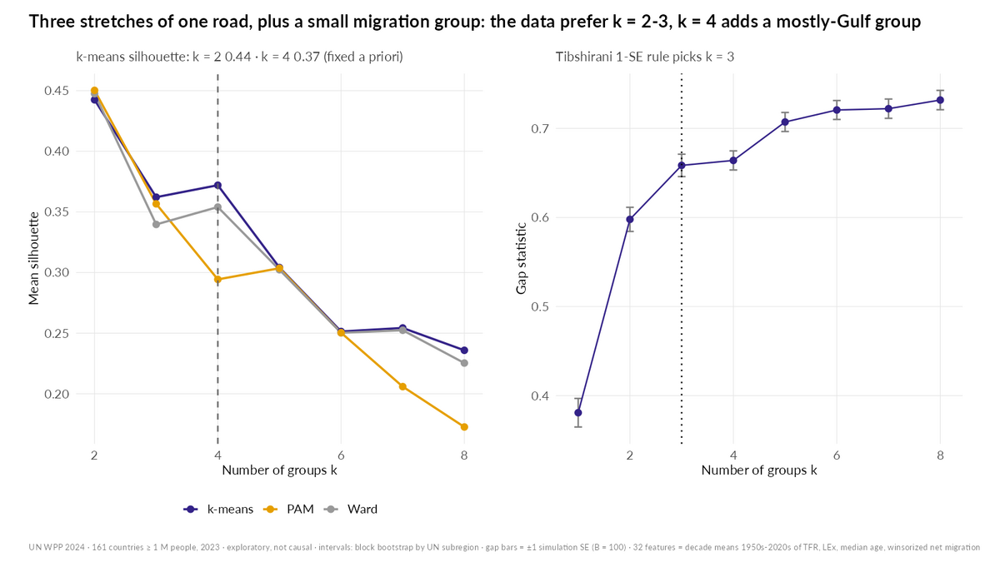

**`figures/review/q3/q3_02_groups_small_multiples.png`** (figura de revisión, no final)

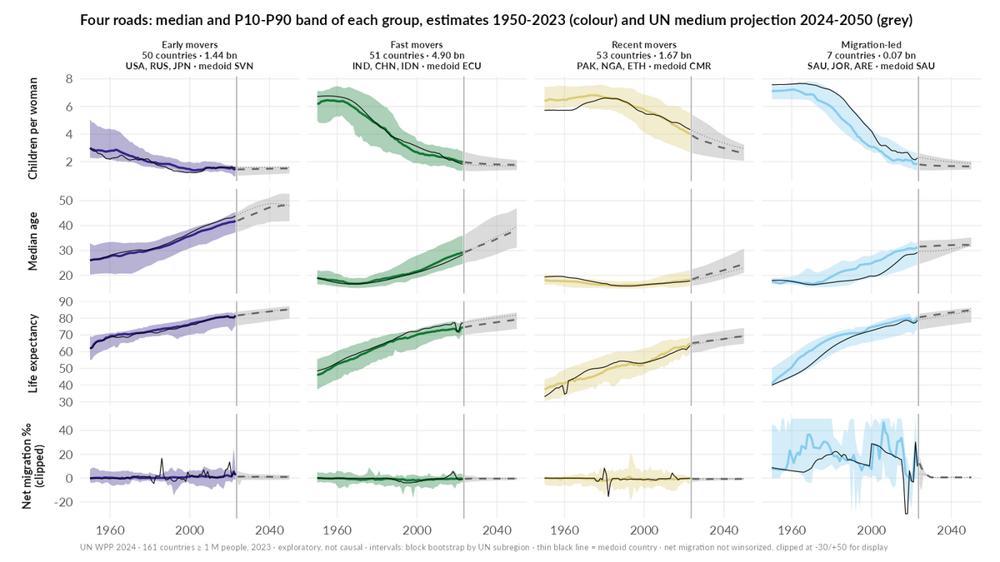

**`figures/review/q3/q3_03_groups_map.png`** (figura de revisión, no final)

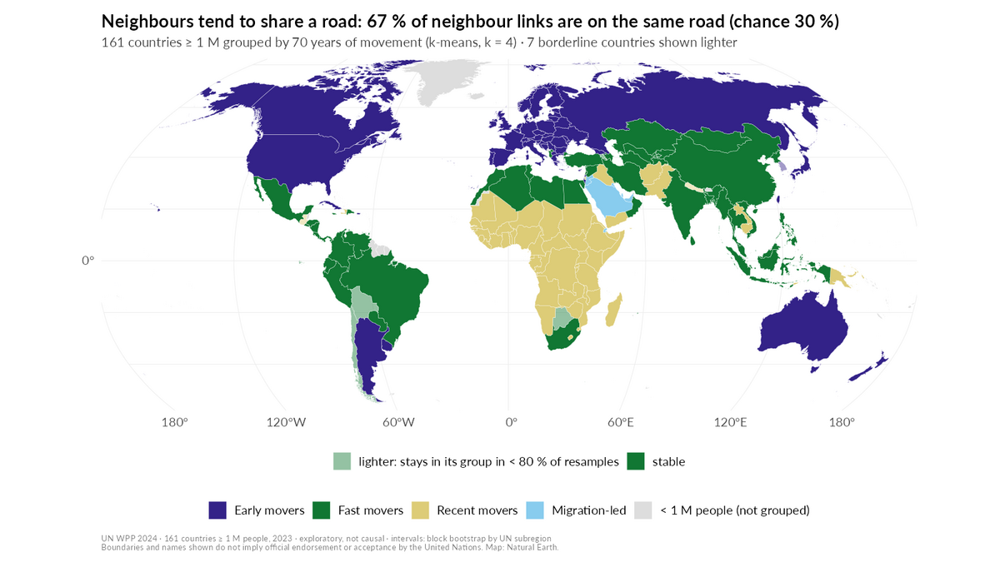

**`figures/review/q3/q3_04_continuum.png`** (figura de revisión, no final)

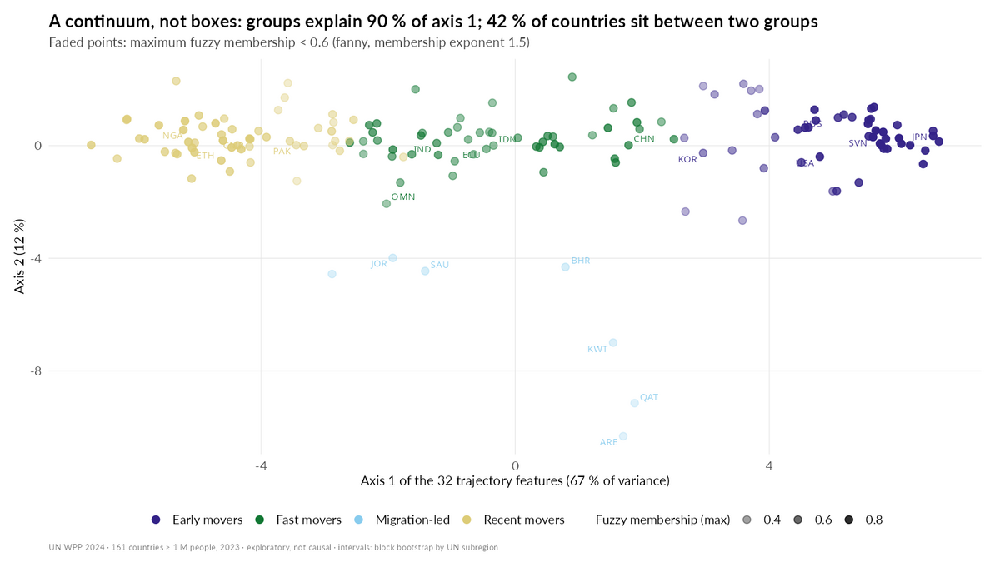

**`figures/review/q3/q3_05_stability.png`** (figura de revisión, no final)

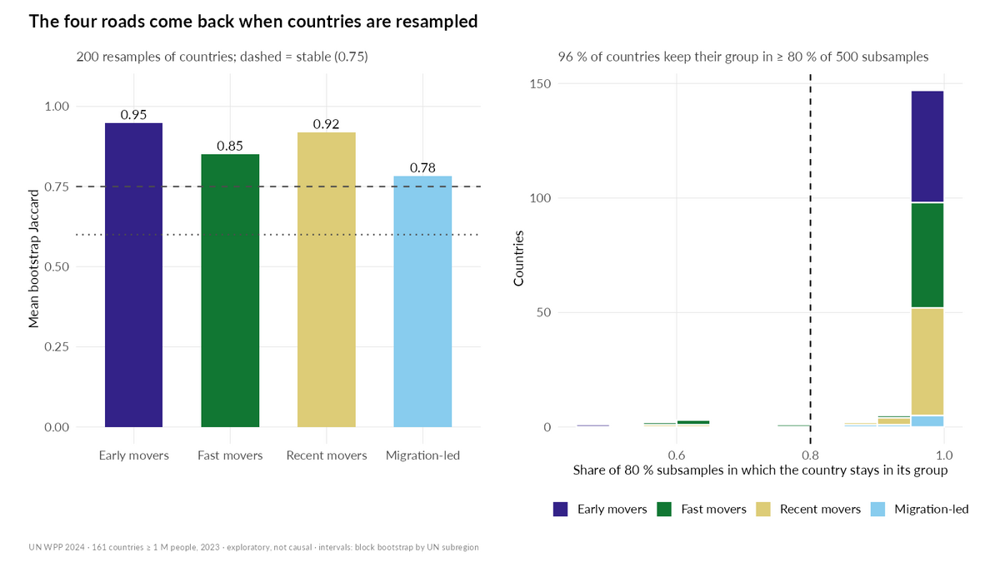

**`figures/review/q3/q3_06_sensitivity_grid.png`** (figura de revisión, no final)

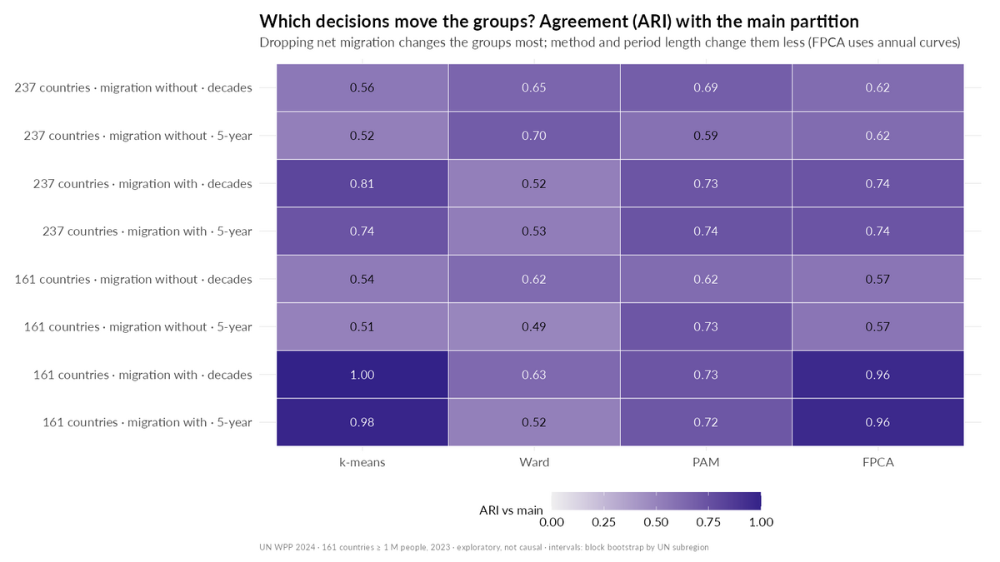

**`figures/review/q3/q3_07_neighbours.png`** (figura de revisión, no final)

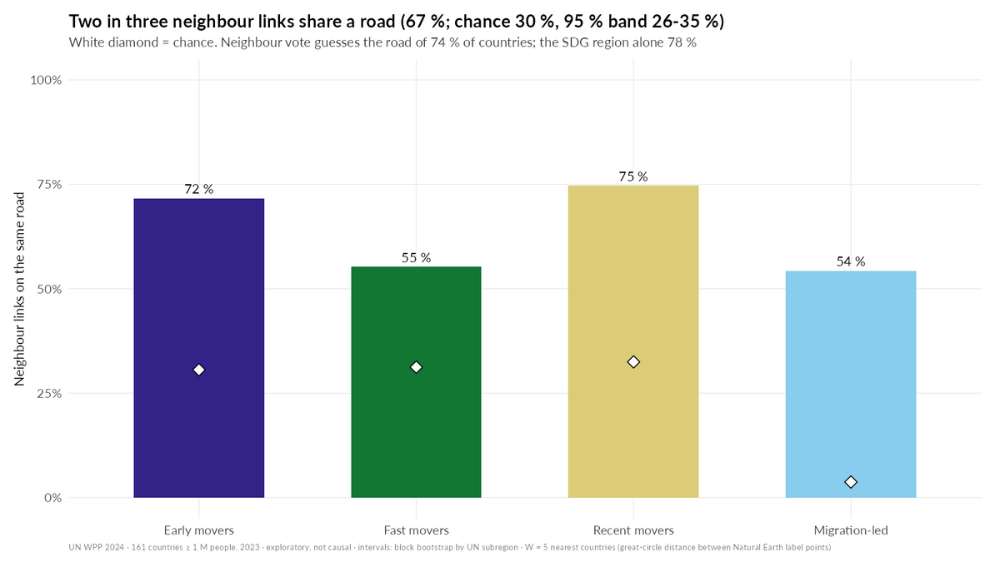

**`figures/review/q3/q3_08_divergence_bands.png`** (figura de revisión, no final)

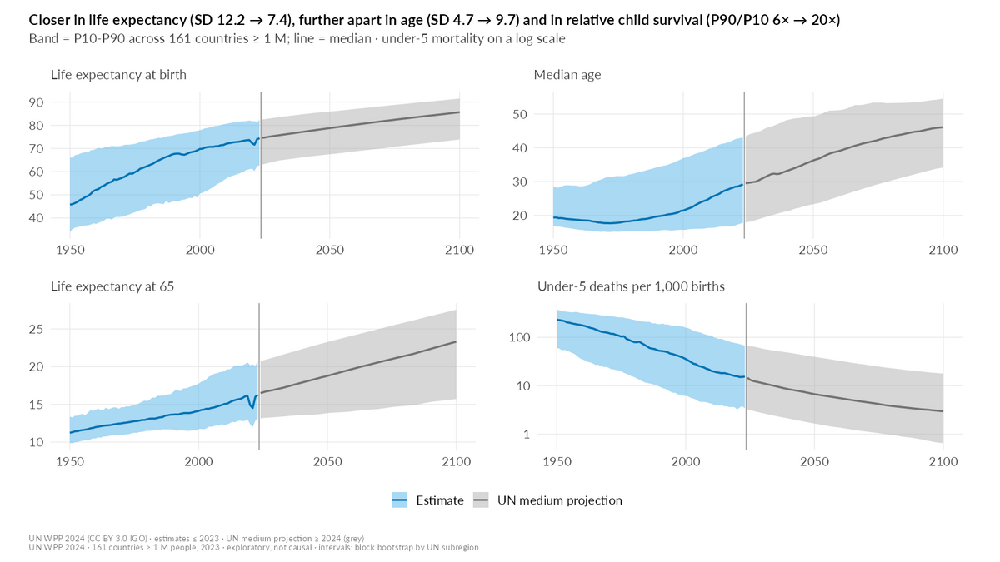

**`figures/review/q3/q3_09_dispersion_sd.png`** (figura de revisión, no final)

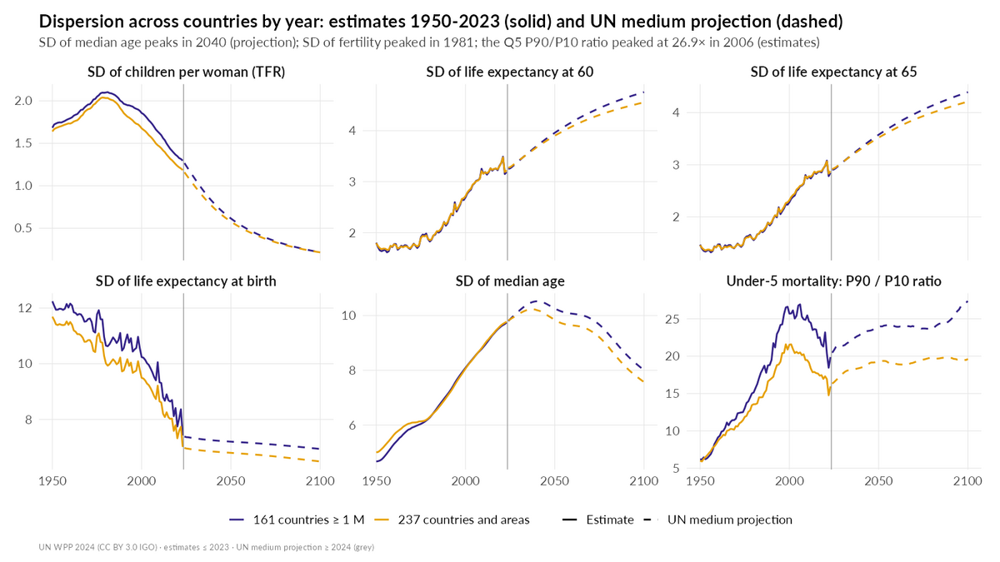

**`figures/review/q3/q3_10_projection_groups.png`** (figura de revisión, no final)

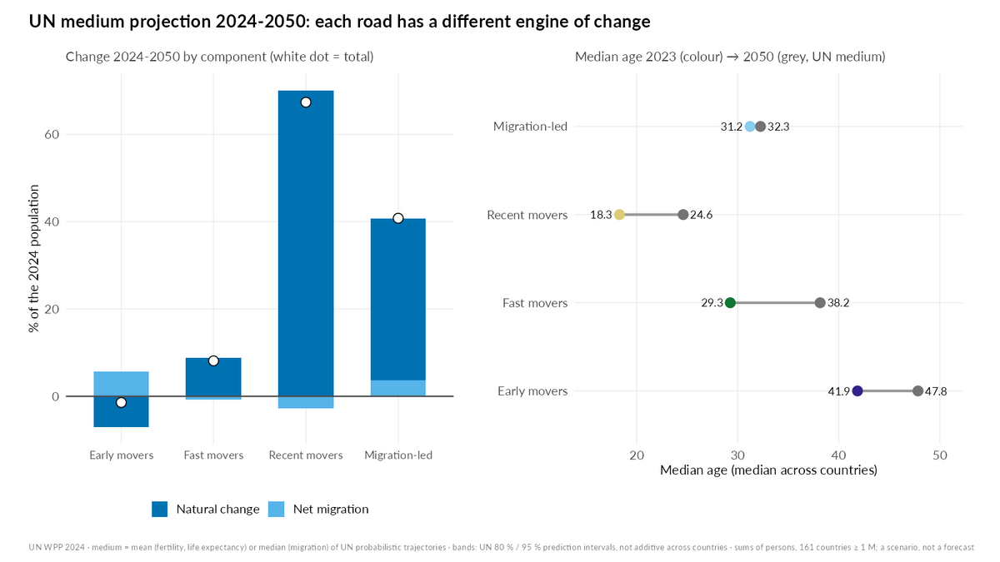

**`figures/review/q3/q3_11_ageing_speed.png`** (figura de revisión, no final)

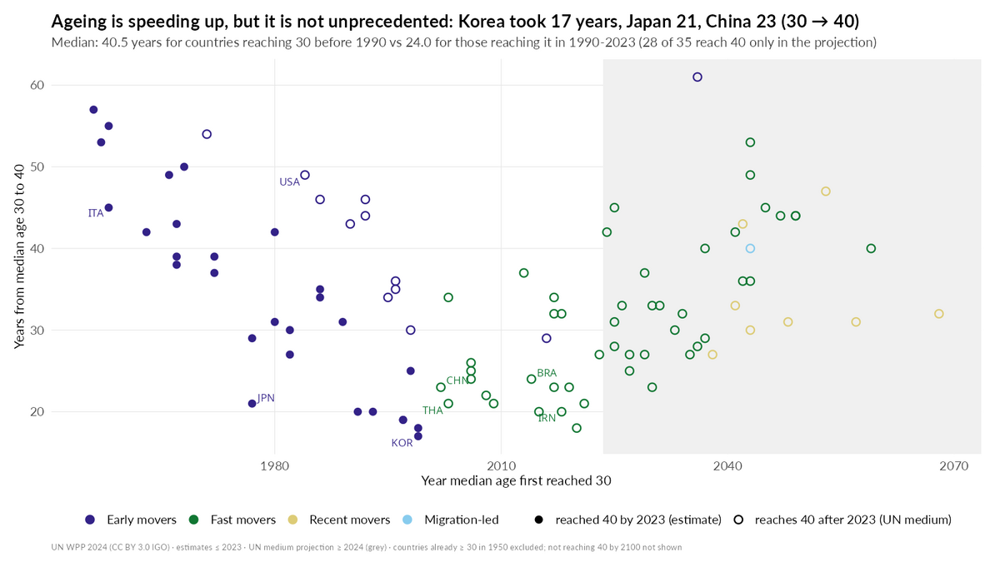

**`figures/review/q3/q3_18_ageing_by_road.png`** (figura de revisión, no final)

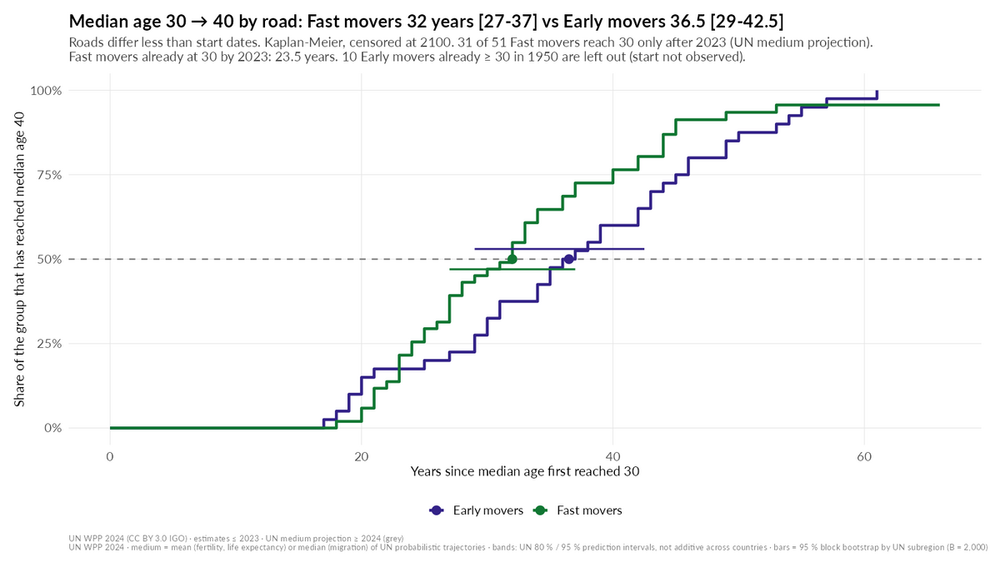

**`figures/review/q3/q3_12_peak_year.png`** (figura de revisión, no final)

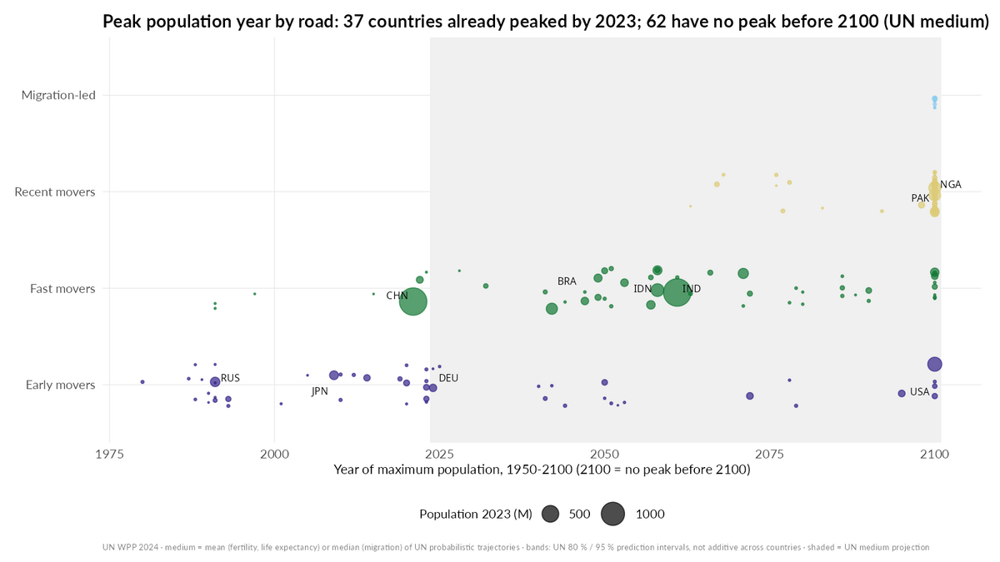

**`figures/review/q3/q3_13_world.png`** (figura de revisión, no final)

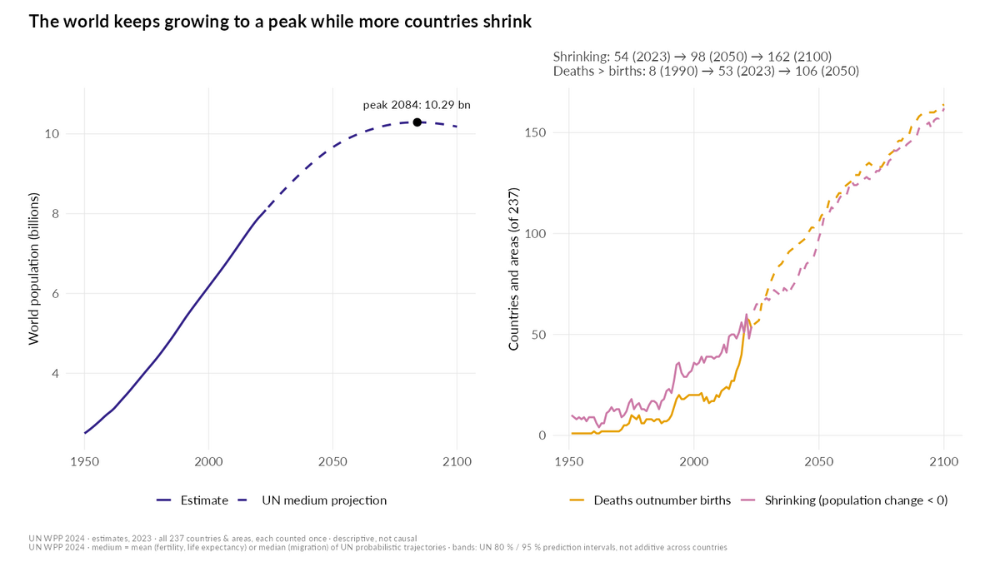

**`figures/review/q3/q3_14_atypical_lex.png`** (figura de revisión, no final)

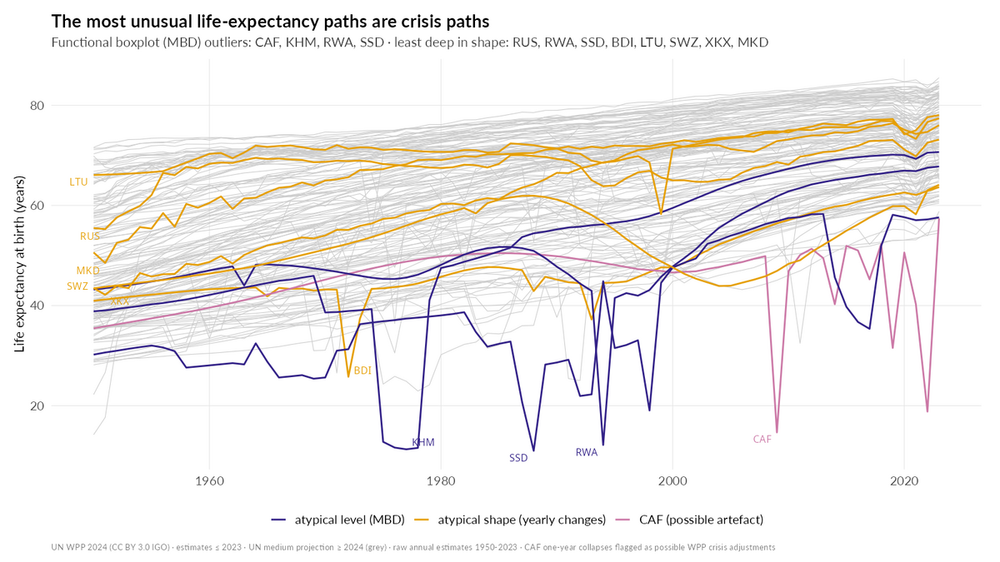

**`figures/review/q3/q3_15_speed_53_km.png`** (figura de revisión, no final)

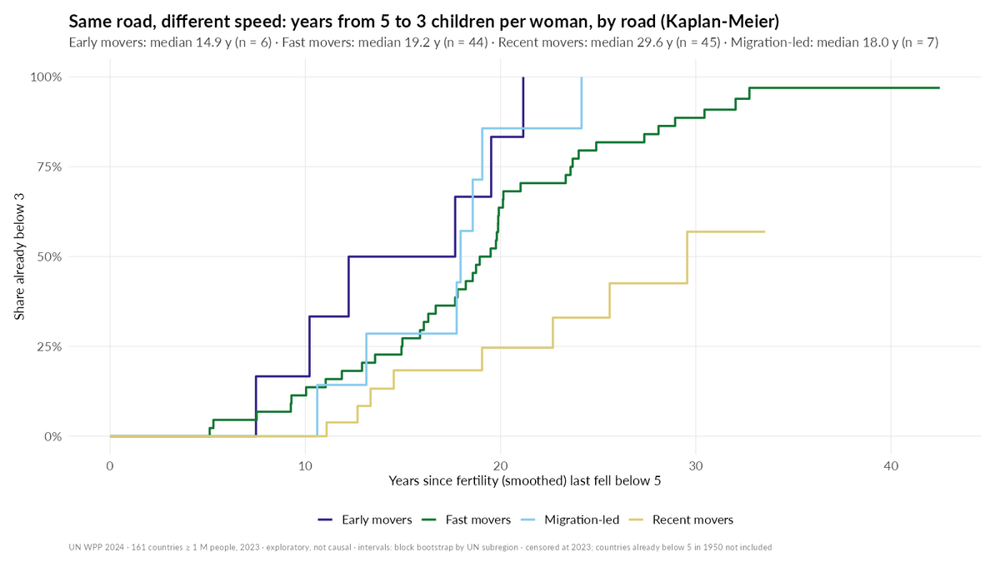

**`figures/review/q3/q3_16_watchlist_roads.png`** (figura de revisión, no final)

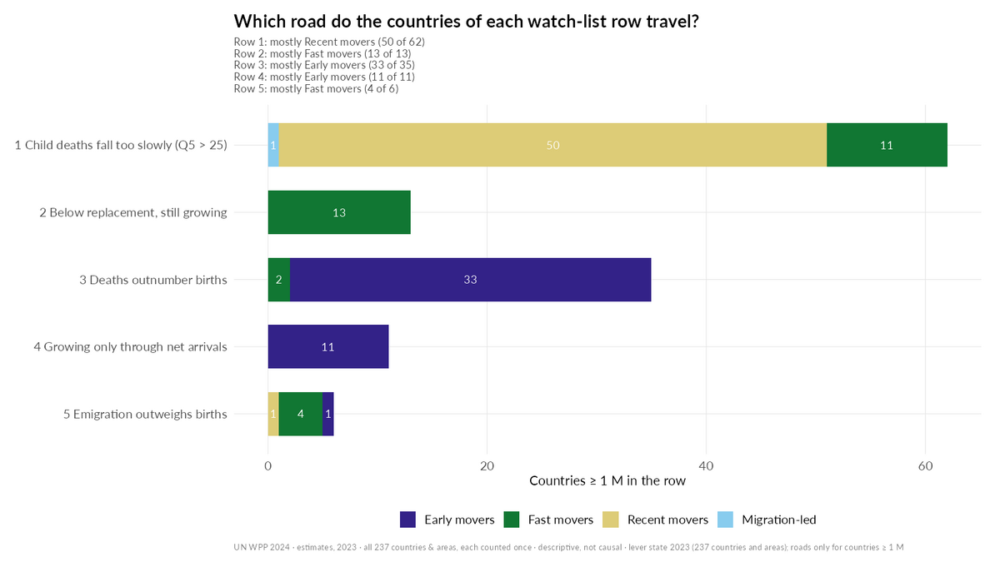

**`figures/review/q3/q3_17_sdg32_pace.png`** (figura de revisión, no final)

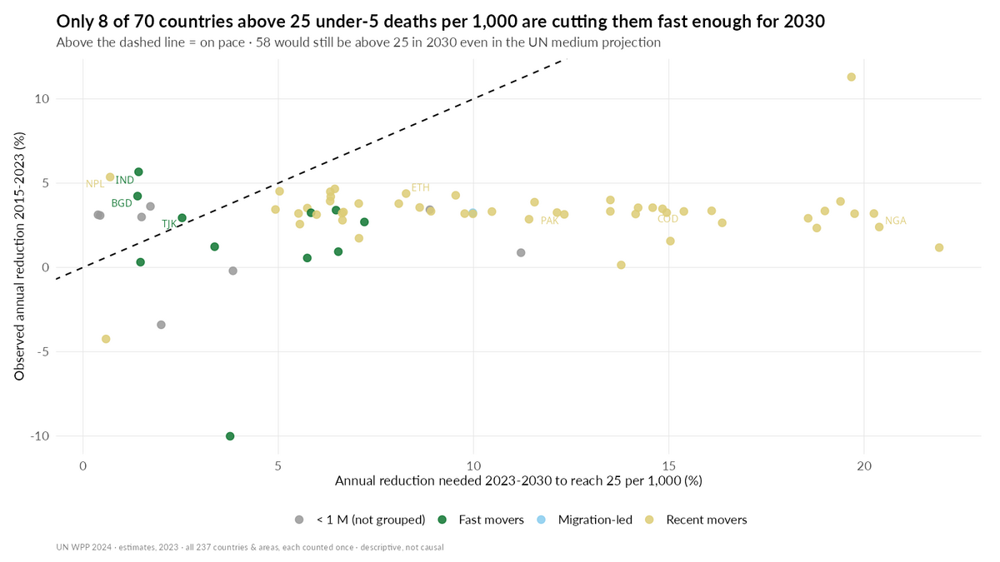

In [160]:
# Figuras de revisión que esta sección acaba de regenerar (figures/review/q3/).
mostrar_figuras("q3", c("q3_01_k_choice", "q3_02_groups_small_multiples", "q3_03_groups_map", "q3_04_continuum", "q3_05_stability", "q3_06_sensitivity_grid", "q3_07_neighbours", "q3_08_divergence_bands", "q3_09_dispersion_sd", "q3_10_projection_groups", "q3_11_ageing_speed", "q3_18_ageing_by_road", "q3_12_peak_year", "q3_13_world", "q3_14_atypical_lex", "q3_15_speed_53_km", "q3_16_watchlist_roads", "q3_17_sdg32_pace"))

### Q3 · §16 Registro de cifras: figures/numbers_q3.json (esquema v2, plan §4)

`R/04_q3_caminos.R` líneas 1645–2144

In [161]:
# =============================================================================
# 16. Registro de cifras: figures/numbers_q3.json (esquema v2, plan §4)
# =============================================================================
# Qué: cada cifra con def, filtro, método, IC o sensibilidad, estado e
# hipótesis. Por qué: ninguna cifra del vídeo se escribe a mano.
cat_sec("16. numbers_q3.json")
reg <- nuevo_registro()
U1 <- UNIVERSO_1M; U237 <- UNIVERSO_237
F161 <- "161 countries ≥ 1 M (2023), UN estimates 1950-2023"
# QA-stats (docs/QA_stats.md): la estandarización se declara entera (z sobre las celdas anuales y DESPUÉS medias por década).
NOTA_RASGOS <- paste("32 features = decade means (1950s ... 2010s, 2020-23) of TFR, LEx, median age and net migration rate",
                     "(winsorized ±3 SD of the panel); each indicator is first z-scored with the mean and SD of all 161 x 74",
                     "annual country-year values (1950-2023), then averaged by decade")
ub1 <- c("slide4.build1", "narration.s4")
fx <- function(x) formatear_cifra(x, "0.00")

# --- 16.1 Clustering (T11) ---------------------------------------------------
reg <- registrar_cifra(reg, "k_clusters", K_GRUPOS, "groups", "0",
  "Number of trajectory groups (k-means), fixed a priori in the pre-specified hypothesis H9a", F161, "T11.2", ub1,
  method = "sensitivity", sens_low = min(k_sil, k_gap), sens_high = K_GRUPOS,
  sens_note = sprintf("Silhouette is highest at k = %d (%.2f); gap statistic (Tibshirani 1-SE) picks k = %d; Mclust (BIC, 4 PCs) G = %d; k = 4 adds a small migration group to three stretches of one road",
                      k_sil, max(tabla_k$sil_kmeans), k_gap, mc$G),
  status = "pre-specified", hypothesis_id = "H9a", n = N_PAISES_1M, universe = U1, say = "four")
reg <- registrar_cifra(reg, "silhouette", sil_k4, "silhouette", "0.00",
  paste("Mean silhouette of the k-means k = 4 partition (Euclidean distance in the 32 trajectory features).", NOTA_RASGOS), F161, "T11.2", ub1,
  method = "sensitivity", sens_low = unname(sil_sub_ic[1]), sens_high = unname(sil_sub_ic[2]), B = B_KEEP, seed = SEMILLA,
  sens_note = sprintf("P2.5-P97.5 over %d random 80 %% subsamples of countries; k = 2: %.2f; FPCA partition in the same space: %.2f; H9 (≤ 0.23) rejected",
                      B_KEEP, tabla_k$sil_kmeans[1], sil_fpca_l2),
  status = "pre-specified", hypothesis_id = "H9a", n = N_PAISES_1M, universe = U1, say = sprintf("about %s", formatear_cifra(sil_k4, "0.00")))
reg <- registrar_cifra(reg, "silhouette_k2", tabla_k$sil_kmeans[tabla_k$k == 2], "silhouette", "0.00",
  "Mean silhouette of k-means with k = 2 (highest of k = 2..8)", F161, "T11.1", "notebook.Q3",
  method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "gap_k", k_gap, "groups", "0", "Number of groups chosen by the gap statistic (Tibshirani 1-SE rule, B = 100, K.max = 8)",
  F161, "T11.1", "notebook.Q3", method = "permutation", B = B_GAP, seed = SEMILLA, status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "cluster_names", I(NIVELES_GRUPO), "names", "text",
  "Group names given by the v2 rule (plan de implementación §6): Migration-led if median CNMR 2000-23 > 10 per 1,000; Early movers if median first year TFR < 4 is before 1960 or most were < 4 in 1950; Recent movers if after 1995 or not crossed; otherwise Fast movers",
  F161, "T11.3", c(ub1, "slide4.table"), method = "descriptive", status = "descriptive", n = 4L, universe = U1,
  sens_note = paste(sprintf("%s: median CNMR 2000-23 %.1f, median year TFR < 4 %s, majority < 4 in 1950 %s", regla_grupos$nombre,
                            regla_grupos$cnmr_mediana_2000_23, ifelse(is.na(regla_grupos$anio_mediano_tfr4), "not crossed", regla_grupos$anio_mediano_tfr4),
                            regla_grupos$mayoria_bajo4_1950), collapse = "; "))
reg <- registrar_cifra(reg, "cluster_sizes", stats::setNames(as.integer(tam_grupos), names(tam_grupos)), "countries", "0",
  sprintf("Number of countries in each trajectory group (k-means k = 4, nstart %d, seed %d, Euclidean distance on the 32 trajectory features). %s",
          NSTART_KMEANS, SEMILLA, NOTA_RASGOS), F161, "T11.3", ub1,
  method = "sensitivity", status = "descriptive", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("FPCA + k-means sizes: %s; Ward: %s; PAM: %s",
                      paste(sort(table(fpca$cl), decreasing = TRUE), collapse = "/"),
                      paste(sort(table(cl_ward), decreasing = TRUE), collapse = "/"),
                      paste(sort(table(cl_pam), decreasing = TRUE), collapse = "/")))
reg <- registrar_cifra(reg, "cluster_pop_bn", stats::setNames(round(desc_grupos$pop_bn, 3), as.character(desc_grupos$grupo)), "billion", "0.0",
  "Population 2023 (UN estimate) living in each trajectory group, sum of TPopulation1July", F161, "T11.4", ub1,
  method = "descriptive", status = "descriptive", n = N_PAISES_1M, universe = U1)
for (g in NIVELES_GRUPO) {
  clave <- c(`Early movers` = "cluster_examples_early", `Fast movers` = "cluster_examples_fast",
             `Recent movers` = "cluster_examples_recent", `Migration-led` = "cluster_examples_migration")[[g]]
  reg <- registrar_cifra(reg, clave, I(nombre_pais(ejemplos_iso[[g]])), "countries", "text",
    sprintf("Three most populous countries (2023) of the %s group, by rule; ISO3: %s", g, paste(ejemplos_iso[[g]], collapse = ", ")),
    F161, "T11.4", ub1, method = "descriptive", status = "descriptive", n = as.integer(tam_grupos[[g]]), universe = U1,
    say = unir_voz(nombre_voz(ejemplos_iso[[g]])),
    sens_note = paste(c(if ("NGA" %in% ejemplos_iso[[g]]) "Nigeria: last census 2006; cite as UN estimate (WPP TFR 2023 4.48 vs DHS 2018 5.3)",
                        if (any(ejemplos_iso[[g]] %in% GOLFO)) "Gulf populations were revised in WPP2024 (UAE +12 %, Saudi Arabia -10 %); net migration is the least-measured component",
                        sprintf("medoid: %s", nombre_pais(medoides_iso[[g]]))), collapse = "; "))
}
reg <- registrar_cifra(reg, "cluster_examples_iso3", lapply(ejemplos_iso, I), "ISO3", "text",
  "ISO3 codes of the three most populous countries (2023) of each group (for flags)", F161, "T11.4", ub1,
  method = "descriptive", status = "descriptive", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "cluster_medoids", as.list(stats::setNames(nombre_pais(medoides_iso), NIVELES_GRUPO)), "countries", "text",
  sprintf("Medoid = country closest (Euclidean) to the coordinate-wise median of its group's 32 features; ISO3: %s",
          paste(sprintf("%s %s", NIVELES_GRUPO, medoides_iso), collapse = ", ")),
  F161, "T11.4", ub1, method = "descriptive", status = "descriptive", n = 4L, universe = U1)
reg <- registrar_cifra(reg, "cluster_profile", desc_grupos |> dplyr::mutate(grupo = as.character(grupo)) |>
                         dplyr::mutate(dplyr::across(where(is.double), ~ round(.x, 2))), "table", "text",
  "Group description with medians across countries; external variables (not used to build the groups): Q5 2023, LE65 2023, LE60 2023, % population change 2023-2050 and median age 2050 (UN medium projection), LE60 2050 (projection); defining variables shown for reference only. No significance tests (circular).",
  F161, "T11.4", c("notebook.Q3", "slide4.build1"), method = "descriptive", status = "descriptive", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "jaccard_min", min(jaccard_grupo), "Jaccard", "0.00",
  sprintf("Lowest mean bootstrap Jaccard across the 4 groups (B = %d resamples of countries with replacement, k-means nstart 20); group: %s",
          B_JACCARD, names(which.min(jaccard_grupo))), F161, "T11.5", c("slide4.method_strip", "notebook.Q3"),
  method = "bootstrap_perc", B = B_JACCARD, seed = SEMILLA, status = "pre-specified", hypothesis_id = "H9a",
  n = N_PAISES_1M, universe = U1, sens_note = sprintf("Ward k = 4 Jaccard range %.2f-%.2f", min(jacc_ward), max(jacc_ward)))
reg <- registrar_cifra(reg, "jaccard_max", max(jaccard_grupo), "Jaccard", "0.00",
  sprintf("Highest mean bootstrap Jaccard across the 4 groups (B = %d); group: %s", B_JACCARD, names(which.max(jaccard_grupo))),
  F161, "T11.5", c("slide4.method_strip", "notebook.Q3"), method = "bootstrap_perc", B = B_JACCARD, seed = SEMILLA,
  status = "pre-specified", hypothesis_id = "H9a", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "jaccard_by_group", as.list(round(jaccard_grupo, 3)), "Jaccard", "0.00",
  "Mean bootstrap Jaccard of each group (Hennig 2007; > 0.75 stable, < 0.6 dissolved)", F161, "T11.5", "notebook.Q3",
  method = "bootstrap_perc", B = B_JACCARD, seed = SEMILLA, status = "pre-specified", hypothesis_id = "H9a", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "ari_fpca_decadas", ari_fpca, "ARI", "0.00",
  sprintf("Adjusted Rand index between the main partition and k-means on the first %d multivariate FPCA scores (%.0f %% of variance; cubic B-splines, lambda = 10)",
          fpca$K, 100 * sum(fpca$varprop[1:fpca$K])), F161, "T11.6", c("slide4.method_strip", "notebook.Q3"),
  method = "sensitivity", sens_low = min(ari_fpca_lambda), sens_high = max(ari_fpca_lambda),
  sens_note = sprintf("lambda = 1: %.2f; lambda = 100: %.2f", ari_fpca_lambda[1], ari_fpca_lambda[2]),
  status = "pre-specified", hypothesis_id = "H9a", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "ari_tray_niveles", ari_niv, "ARI", "0.00",
  "ARI between trajectory groups (70 years) and k-means k = 4 on 2023 levels of the same 4 indicators (cross-sectional z, CNMR winsorized)",
  F161, "T11.7", c("slide4.message", "notebook.Q3"), method = "sensitivity",
  sens_low = min(ari_niv, ari_niv_p), sens_high = max(ari_niv, ari_niv_p),
  sens_note = sprintf("2023 levels z-scored with the panel mean/SD: %.2f", ari_niv_p),
  status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "ari_sin_cnmr", ari_sin, "ARI", "0.00",
  "ARI between the main partition and k-means k = 4 without the 8 net-migration features (24 features)", F161, "T11.8",
  c("notebook.Q3"), method = "sensitivity", sens_low = min(ari_sin, rejilla$ari[rejilla$cnmr == "without" & rejilla$muestra == "161"]),
  sens_high = max(rejilla$ari[rejilla$cnmr == "without" & rejilla$muestra == "161"]),
  sens_note = sprintf("Range over k-means/Ward/PAM/FPCA x decades/5-year without CNMR (161); max Jaccard of the Migration-led set without CNMR %.2f (dissolves)", jacc_mig_sin),
  status = "pre-specified", hypothesis_id = "H9a", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "ari_ward", ari_ward, "ARI", "0.00", "ARI k-means vs Ward (ward.D2) with k = 4", F161, "T11.6", "notebook.Q3",
  method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "ari_pam", ari_pam, "ARI", "0.00", "ARI k-means vs PAM with k = 4", F161, "T11.6", "notebook.Q3",
  method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "ari_asinh", ari_as, "ARI", "0.00",
  "ARI main partition vs k-means with asinh(CNMR/5) instead of winsorizing", F161, "T11.8", "notebook.Q3",
  method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("Unwinsorized CNMR: ARI %.2f (smallest group: %s)", ari_crudo, paste(peq(cl_crudo), collapse = ", ")))
reg <- registrar_cifra(reg, "silhouette_speed_clusters", sil_v, "silhouette", "0.00",
  "Mean silhouette of k-means k = 4 on yearly derivatives (speeds) of the smoothed z-curves of TFR, LEx, median age and net migration rate (B-splines, lambda = 10), 1950-2023 — attempt discarded",
  F161, "T11.11", "notebook.Q3", method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("mean bootstrap Jaccard of the 4 speed groups (B = %d): %s; ARI with the main partition %.2f; sizes %s (one large group plus small groups of shocks: %s) — a high silhouette here reflects outliers, not roads",
                      B_JACCARD, paste(sprintf("%.2f", jacc_v), collapse = " / "), ari_v, paste(tam_v, collapse = "/"),
                      paste(sprintf("[%s]", miembros_v_peq), collapse = " ")))
reg <- registrar_cifra(reg, "r2_groups_axis1", r2_eje1, "R2", "0.00",
  sprintf("R2 of the first principal axis of the 32 trajectory features (%.0f %% of their variance) on group membership", 100 * var_pcs_rasgos[1]),
  F161, "T11.9", c("slide4.build1", "notebook.Q3"), method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1,
  say = sprintf("%s of the main axis", say_fraccion(r2_eje1)))
reg <- registrar_cifra(reg, "share_between_groups", 100 * share_entre, "%", "0",
  "Share of countries whose maximum fuzzy membership (cluster::fanny, k = 4, membership exponent 1.5) is below 0.6", F161, "T11.9", ub1,
  method = "sensitivity", sens_low = 100 * min(share_entre_sens), sens_high = 100 * max(share_entre_sens),
  sens_note = sprintf("threshold 0.5: %.0f %%; 0.7: %.0f %%", 100 * share_entre_sens[1], 100 * share_entre_sens[2]),
  status = "exploratory", n = N_PAISES_1M, universe = U1, say = say_fraccion(share_entre))
reg <- registrar_cifra(reg, "share_keep_ge_0.8", 100 * share_keep, "%", "0",
  sprintf("Share of countries that stay in their group in at least 80 %% of %d random 80 %% subsamples (k-means re-run, labels matched with the Hungarian algorithm, clue::solve_LSAP)", B_KEEP),
  F161, "T11.5", c("slide4.build1", "notebook.Q3"), method = "sensitivity", B = B_KEEP, seed = SEMILLA,
  sens_low = 100 * min(share_keep_sens), sens_high = 100 * max(share_keep_sens),
  sens_note = sprintf("70 %% subsamples (B = 200): %.0f %%; 90 %% subsamples (B = 200): %.0f %%", 100 * share_keep_sens[1], 100 * share_keep_sens[2]),
  status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "borderline_countries", I(nombre_pais(iso_frontera)), "countries", "text",
  sprintf(paste("Countries that stay in their group in fewer than 80 %% of %d random 80 %% subsamples of countries (without replacement;",
                "k-means k = 4 re-run with nstart 20; labels matched to the main partition with the Hungarian algorithm; seed %d),",
                "hatched/lighter on the map; ISO3: %s"), B_KEEP, SEMILLA,
          paste(iso_frontera, collapse = ", ")), F161, "T11.5", c("slide4.build1", "notebook.Q3"),
  method = "sensitivity", B = B_KEEP, seed = SEMILLA, status = "descriptive", n = length(iso_frontera), universe = U1)
reg <- registrar_cifra(reg, "share_sil_lt_0.1", 100 * mean(sil_ind < 0.1), "%", "0",
  sprintf("Share of countries with individual silhouette < 0.1; %d negative (%s)", sum(sil_ind < 0), paste(names(sil_ind)[sil_ind < 0], collapse = ", ")),
  F161, "T11.9", "notebook.Q3", method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "n_cnmr_winsor_cells", n_celdas_winsor, "country-years", "0",
  sprintf("Country-years of CNMR winsorized to [%.1f; %.1f] per 1,000 (mean ± 3 SD of the 161 x 1950-2023 panel); countries: %s",
          lim_cnmr[1], lim_cnmr[2], paste(sprintf("%s %d", recortes_cnmr$ISO3_code, recortes_cnmr$n), collapse = ", ")),
  F161, "T11.0", "notebook.Q3", method = "none_census", status = "descriptive", n = nrow(recortes_cnmr), universe = U1)
reg <- registrar_cifra(reg, "india_group", as.character(grupo["IND"]), "group", "text",
  "Trajectory group of India (main partition)", F161, "T11.3", c("slide4.build1", "narration.s4"),
  method = "descriptive", status = "descriptive", n = 1L, universe = U1,
  sens_note = sprintf("FPCA: same group as %s; without CNMR: cluster %d", paste(names(fpca$cl)[fpca$cl == fpca$cl["IND"]][1:3], collapse = ", "), cl_sin["IND"]))
# "Mostly Gulf states" (QA_storyboard §6.5): miembros del grupo Migration-led y cuántos son del Golfo (GOLFO = GCC).
iso_mig <- names(grupo)[grupo == "Migration-led"]
iso_mig <- iso_mig[order(-pob23_q3[iso_mig])]
n_golfo_mig <- sum(iso_mig %in% GOLFO)
reg <- registrar_cifra(reg, "migration_led_members", I(nombre_pais(iso_mig)), "countries", "text",
  sprintf("Members of the Migration-led group, most populous first; ISO3: %s. Gulf Cooperation Council members among them: %d of %d (%s); others: %s",
          paste(iso_mig, collapse = ", "), n_golfo_mig, length(iso_mig), paste(iso_mig[iso_mig %in% GOLFO], collapse = ", "),
          paste(iso_mig[!iso_mig %in% GOLFO], collapse = ", ")),
  F161, "T11.3", c("narration.s4", "qa.mostly_gulf"), method = "descriptive", status = "descriptive",
  n = length(iso_mig), universe = U1,
  sens_note = "Gulf populations were revised in WPP2024 (UAE +12 %, Saudi Arabia -10 %); net migration is the least-measured component")
reg <- registrar_cifra(reg, "n_gulf_migration_led", n_golfo_mig, "countries", "0",
  sprintf("Gulf Cooperation Council countries (%s) inside the Migration-led group of %d countries ('mostly Gulf states' holds if > half)",
          paste(GOLFO, collapse = ", "), length(iso_mig)), F161, "T11.3", c("narration.s4", "qa.mostly_gulf"),
  method = "descriptive", status = "descriptive", n = length(iso_mig), universe = U1,
  sens_note = sprintf("Oman (GCC) is %s", ifelse("OMN" %in% iso_mig, "in the group", paste("in", as.character(grupo["OMN"])))))
reg <- registrar_cifra(reg, "cramer_v_group_income", cramer_ingreso, "Cramer V", "0.00",
  "Cramér's V between trajectory group and World Bank FY2027 income group (descriptive, no test; Taiwan excluded)", "160 countries ≥ 1 M with income group",
  "T11.4", "notebook.Q3", method = "descriptive", status = "descriptive", n = sum(ok_ing), universe = U1,
  sens_note = sprintf("group ~ SDG region: %.2f", cramer_region))

# --- 16.2 Contigüidad (T7 / T11) ---------------------------------------------
reg <- registrar_cifra(reg, "join_same_road", jc$obs, "share", "0.00",
  "Share of directed neighbour links (5 nearest countries, great-circle distance between Natural Earth label points, row-standardized) whose two countries are in the same trajectory group",
  F161, "T7.J", c("slide4.build1", "narration.s4"), method = "permutation", B = B_PERM, seed = SEMILLA,
  sens_low = min(sapply(c(list(jc), jc_sens), `[[`, "obs")), sens_high = max(sapply(c(list(jc), jc_sens), `[[`, "obs")),
  sens_note = sprintf("kNN8 %.2f; land contiguity (< 10 km, islands get 2 nearest) %.2f; inverse distance ≤ 2,000 km %.2f; without CNMR groups (kNN5) %.2f vs chance %.2f",
                      jc_sens$knn8$obs, jc_sens$cont$obs, jc_sens$idw2000$obs, jc_sin$obs, jc_sin$nulo_media),
  status = "exploratory", hypothesis_id = "H25", p_value = jc$p, n = N_PAISES_1M, universe = U1, say = say_fraccion(jc$obs))
reg <- registrar_cifra(reg, "join_same_road_null", jc$nulo_media, "share", "0.00",
  sprintf("Mean share of same-group neighbour links under %d random permutations of the group labels (chance)", B_PERM),
  F161, "T7.J", c("slide4.build1", "narration.s4"), method = "permutation", B = B_PERM, seed = SEMILLA,
  sens_low = jc$lo, sens_high = jc$hi, sens_note = "sens_low/sens_high = 2.5 % and 97.5 % of the permutation distribution",
  status = "exploratory", hypothesis_id = "H25", n = N_PAISES_1M, universe = U1, say = say_fraccion(jc$nulo_media))
reg <- registrar_cifra(reg, "join_same_road_ratio", jc$obs / jc$nulo_media, "ratio", "0.0",
  "Observed share of same-road neighbour links divided by its permutation mean", F161, "T7.J", "notebook.Q3",
  method = "permutation", B = B_PERM, seed = SEMILLA, status = "exploratory", hypothesis_id = "H25", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "join_same_road_by_group", as.list(round(jc$por_grupo, 3)), "share", "0.00",
  sprintf("Share of neighbour links of each group's countries that stay in the group (chance = (n_g - 1)/(n - 1): %s)",
          paste(sprintf("%s %.2f", names(jc$esperado), jc$esperado), collapse = ", ")), F161, "T7.J", "notebook.Q3",
  method = "permutation", B = B_PERM, seed = SEMILLA, status = "exploratory", hypothesis_id = "H25", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "knn_vote_accuracy", acc_vecinos, "share", "0.00",
  "Share of countries whose group equals the majority group of its 5 nearest neighbours (ties: nearest tied neighbour)",
  F161, "T7.J", c("slide4.build1", "notebook.Q3"), method = "permutation", B = B_PERM, seed = SEMILLA,
  sens_low = mean(acc_nulo), sens_high = unname(stats::quantile(acc_nulo, 0.975)),
  sens_note = sprintf("sens = permutation mean and 97.5 %%; majority class %.2f; leave-one-out majority of the SDG region %.2f, of the income group %.2f, of region x income %.2f",
                      base_mayor, acc_region, acc_ingreso, acc_reg_ing),
  status = "exploratory", hypothesis_id = "H25", n = N_PAISES_1M, universe = U1)
# QA-stats (docs/QA_stats.md): el denominador excluye a los países solos en su región SDG (no tienen voto).
voto_region_qa <- mayoria_loo(g_chr, info_w$region_sdg)
sin_voto_region <- rownames(W5)[is.na(voto_region_qa)]
reg <- registrar_cifra(reg, "region_vote_accuracy", acc_region, "share", "0.00",
  sprintf(paste("Share of countries whose group equals the leave-one-out majority group of the other countries of its SDG region",
                "(reference so as not to overstate geography; ties go to the first group in the order %s); denominator %d countries:",
                "%s %s alone in its SDG region and has no leave-one-out vote"),
          paste(NIVELES_GRUPO, collapse = ", "), sum(!is.na(voto_region_qa)),
          paste(nombre_pais(sin_voto_region), collapse = ", "), ifelse(length(sin_voto_region) == 1, "is", "are")),
  F161, "T7.J", c("slide4.build1", "notebook.Q3"), method = "descriptive", status = "exploratory",
  n = sum(!is.na(voto_region_qa)), universe = U1)

# --- 16.3 Divergencia P1 (T12) -----------------------------------------------
ic_sd <- function(v, s) extraer_ic(ic_p1[[v]], s)
ub2 <- c("slide4.build2", "narration.s4")
reg_sd <- function(reg, clave, v, s, unidad, def, hid, fmt = "0.0", used = ub2) {
  r <- ic_sd(v, s); ri <- ic_p1_iid[[v]][[s]]
  col <- ifelse(grepl("cv", s), "cv", "de")
  v237 <- if (s %in% c("dsd", "dcv")) d1(v, 2023, col, UNIVERSO_237) - d1(v, 1950, col, UNIVERSO_237)
          else d1(v, as.integer(sub("\\D+", "", s)), col, UNIVERSO_237)
  registrar_cifra(reg, clave, r$valor, unidad, fmt, def, F161, "T12.1", used, ic = r, ic_iid = ri,
                  status = "pre-specified", hypothesis_id = hid, n = N_PAISES_1M, universe = U1,
                  sens_note = sprintf("237 countries and areas: %.2f", v237))
}
reg <- reg_sd(reg, "sd_medage_1950", "MedianAgePop", "sd1950", "years", "Standard deviation of median age across countries, 1950 (UN estimate)", "H10")
reg <- reg_sd(reg, "sd_medage_2023", "MedianAgePop", "sd2023", "years", "Standard deviation of median age across countries, 2023 (UN estimate)", "H10")
reg <- reg_sd(reg, "sd_lex_1950", "LEx", "sd1950", "years", "Standard deviation of life expectancy at birth across countries, 1950", "H11a")
reg <- reg_sd(reg, "sd_lex_2023", "LEx", "sd2023", "years", "Standard deviation of life expectancy at birth across countries, 2023", "H11a")
reg <- reg_sd(reg, "sd_le65_1950", "LE65", "sd1950", "years", "Standard deviation of life expectancy at 65 across countries, 1950", "H11a", "0.00")
reg <- reg_sd(reg, "sd_le65_2023", "LE65", "sd2023", "years", "Standard deviation of life expectancy at 65 across countries, 2023", "H11a", "0.00")
reg <- reg_sd(reg, "cv_lex_1950", "LEx", "cv1950", "%", "Coefficient of variation (SD / mean, %) of life expectancy at birth across countries, 1950", "H11a")
reg <- reg_sd(reg, "cv_lex_2023", "LEx", "cv2023", "%", "Coefficient of variation (SD / mean, %) of life expectancy at birth across countries, 2023", "H11a")
reg <- reg_sd(reg, "cv_le65_1950", "LE65", "cv1950", "%", "Coefficient of variation (SD / mean, %) of life expectancy at 65 across countries, 1950", "H11a")
reg <- reg_sd(reg, "cv_le65_2023", "LE65", "cv2023", "%", "Coefficient of variation (SD / mean, %) of life expectancy at 65 across countries, 2023", "H11a")
reg <- reg_sd(reg, "delta_sd_medage", "MedianAgePop", "dsd", "years", "Change 1950 → 2023 in the cross-country SD of median age", "H10", used = "notebook.Q3")
reg <- reg_sd(reg, "delta_sd_lex", "LEx", "dsd", "years", "Change 1950 → 2023 in the cross-country SD of life expectancy at birth", "H11a", used = "notebook.Q3")
reg <- reg_sd(reg, "delta_sd_le65", "LE65", "dsd", "years", "Change 1950 → 2023 in the cross-country SD of life expectancy at 65", "H11a", "0.00", used = "notebook.Q3")
reg <- reg_sd(reg, "delta_cv_lex", "LEx", "dcv", "percentage points", "Change 1950 → 2023 in the cross-country CV (%) of life expectancy at birth", "H11a", used = "notebook.Q3")
reg <- reg_sd(reg, "delta_cv_le65", "LE65", "dcv", "percentage points", "Change 1950 → 2023 in the cross-country CV (%) of life expectancy at 65", "H11a", used = "notebook.Q3")
reg <- reg_sd(reg, "sd_le60_1950", "LE60", "sd1950", "years", "SD of life expectancy at 60 across countries, 1950 (WPP2024 supplement; robustness of LE65)", "H11", "0.00", used = "notebook.Q3")
reg <- reg_sd(reg, "sd_le60_2023", "LE60", "sd2023", "years", "SD of life expectancy at 60 across countries, 2023 (WPP2024 supplement; robustness of LE65)", "H11", "0.00", used = "notebook.Q3")
reg <- reg_sd(reg, "delta_sd_le60", "LE60", "dsd", "years", "Change 1950 → 2023 in the cross-country SD of life expectancy at 60 (supplement)", "H11", "0.00", used = "notebook.Q3")
q5r <- function(s) extraer_ic(ic_q5, s)
reg <- registrar_cifra(reg, "q5_ratio_p90p10_1950", q5r("r1950")$valor, "ratio", "0",
  "Ratio of the 90th to the 10th percentile of under-five mortality across countries, 1950 (riskiest tenth vs safest tenth)", F161, "T12.2", ub2,
  ic = q5r("r1950"), ic_iid = ic_q5_iid$r1950, status = "exploratory", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("237: %.1f", d1("Q5", 1950, "razon_p90p10", UNIVERSO_237)), say = sprintf("%s times", formatear_cifra(q5r("r1950")$valor, "0")))
reg <- registrar_cifra(reg, "q5_ratio_p90p10_2023", q5r("r2023")$valor, "ratio", "0",
  "Ratio of the 90th to the 10th percentile of under-five mortality across countries, 2023", F161, "T12.2", ub2,
  ic = q5r("r2023"), ic_iid = ic_q5_iid$r2023, status = "exploratory", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("237: %.1f; UN medium 2050: %.1f", d1("Q5", 2023, "razon_p90p10", UNIVERSO_237), d1("Q5", 2050, "razon_p90p10")),
  say = sprintf("%s times", formatear_cifra(q5r("r2023")$valor, "0")))
reg <- registrar_cifra(reg, "q5_ratio_p90p10_peak", q5_pico$razon_p90p10, "ratio", "0",
  sprintf("Maximum over 1950-2023 (UN estimates) of the P90/P10 ratio of under-five mortality across countries (P90 and P10 with R's default quantile, type 7), reached in %d", q5_pico$Time),
  F161, "T12.2", c("slide4.build2", "notebook.Q3"), method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("237 countries and areas: %.1f in %d; 2023: %.1f (161)", q5_pico_237$razon_p90p10, q5_pico_237$Time, d1("Q5", 2023, "razon_p90p10")))
reg <- registrar_cifra(reg, "q5_ratio_p90p10_peak_year", q5_pico$Time, "year", "0",
  "Year (1950-2023, UN estimates) in which the P90/P10 ratio of under-five mortality across countries peaked (P90 and P10 with R's default quantile, type 7)", F161, "T12.2",
  c("slide4.build2", "notebook.Q3"), method = "descriptive", status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "q5_gap_p90p10_1950", q5r("gap1950")$valor, "per 1,000", "0",
  "Absolute gap P90 - P10 of under-five mortality across countries, 1950", F161, "T12.2", "notebook.Q3",
  ic = q5r("gap1950"), ic_iid = ic_q5_iid$gap1950, status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "q5_gap_p90p10_2023", q5r("gap2023")$valor, "per 1,000", "0",
  "Absolute gap P90 - P10 of under-five mortality across countries, 2023", F161, "T12.2", "notebook.Q3",
  ic = q5r("gap2023"), ic_iid = ic_q5_iid$gap2023, status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "sd_logq5_1950", q5r("sdlog1950")$valor, "SD of log", "0.00",
  "SD of log under-five mortality across countries, 1950", F161, "T12.2", "notebook.Q3",
  ic = q5r("sdlog1950"), ic_iid = ic_q5_iid$sdlog1950, status = "exploratory", n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "sd_logq5_2023", q5r("sdlog2023")$valor, "SD of log", "0.00",
  "SD of log under-five mortality across countries, 2023", F161, "T12.2", "notebook.Q3",
  ic = q5r("sdlog2023"), ic_iid = ic_q5_iid$sdlog2023, status = "exploratory", n = N_PAISES_1M, universe = U1)
amx <- function(v, per) anio_max_de$anio_max[anio_max_de$variable == v & anio_max_de$periodo_en == per]
reg <- registrar_cifra(reg, "sd_medage_peak_year_proj", amx("MedianAgePop", ETIQUETA_PROYECCION), "year", "0",
  "Year in which the cross-country SD of median age reaches its maximum within the UN medium projection 2024-2100 (computed separately from estimates)",
  "161 countries ≥ 1 M, UN medium projection 2024-2100", "T12.3", c("slide4.build2", "notebook.Q3"), method = "descriptive",
  status = "descriptive", n = N_PAISES_1M, universe = U1, variant_source = "WPP2024 Medium",
  sens_note = sprintf("max SD in estimates (1950-2023) is reached in %d; LE65 SD max in projection %d; LEx SD max in estimates %d",
                      amx("MedianAgePop", ETIQUETA_ESTIMACION), amx("LE65", ETIQUETA_PROYECCION), amx("LEx", ETIQUETA_ESTIMACION)))
reg <- registrar_cifra(reg, "sd_tfr_peak_year", amx("TFR", ETIQUETA_ESTIMACION), "year", "0",
  "Year in which the cross-country SD of TFR peaked, UN estimates 1950-2023 (fertility first diverged, then converged)", F161, "T12.3", "notebook.Q3",
  method = "descriptive", status = "descriptive", n = N_PAISES_1M, universe = U1,
  sens_note = sprintf("SD of TFR 1950 %.2f, peak %.2f, 2023 %.2f", d1("TFR", 1950), anio_max_de$valor_max[anio_max_de$variable == "TFR" & anio_max_de$periodo_en == ETIQUETA_ESTIMACION], d1("TFR", 2023)))
for (v in c("MedianAgePop", "LEx")) for (a in c(1950, 2023)) {
  nm <- c(MedianAgePop = "medage", LEx = "lex")[[v]]
  reg <- registrar_cifra(reg, sprintf("r2_region_%s_%d", nm, a), d1(v, a, "r2_region"), "R2", "0.00",
    sprintf("R2 of %s on the 8 SDG regions across countries, %d (descriptive)", etiq_var[[v]], a), F161, "T12.4", "notebook.Q3",
    method = "descriptive", status = "descriptive", n = N_PAISES_1M, universe = U1,
    sens_note = sprintf("R2 on World Bank FY2027 income groups (160 countries): %.2f", d1(v, a, "r2_ingreso")))
}

# --- 16.4 Velocidad y envejecimiento ------------------------------------------
# Por camino (QA_storyboard §6.3): las claves del guion comparan Fast con Early movers.
efa <- env_km_grupo[env_km_grupo$grupo == "Fast movers", ]; eea <- env_km_grupo[env_km_grupo$grupo == "Early movers", ]
reg <- registrar_cifra(reg, "yrs_medage30_40_recent", med_g("Fast movers"), "years", "0",
  sprintf("Fast movers: Kaplan-Meier median years from median age 30 to 40 (right-censored if 40 is not reached by 2100). %d of %d countries reach 30 only after 2023 and %d reach 40 only in the UN medium projection, so this is mostly a projected speed",
          efa$n_inicio_proy, efa$n, efa$n_fin_proy),
  "Fast movers (161 countries ≥ 1 M); estimates ≤ 2023 + UN medium projection ≥ 2024 (mostly projected)", "T15.4",
  c("slide4.build1", "narration.s4"), ic = ic_env_fast, ic_iid = NULL, status = "exploratory", n = as.integer(efa$n), universe = U1,
  sens_low = min(med_fast_iniciados, efa$mediana_completos, med_reciente), sens_high = max(med_g("Fast movers"), efa$mediana_completos),
  sens_note = sprintf("Fast movers already at 30 by 2023 (n = %d): %.1f [block %.1f-%.1f]; simple median of the %d that reach 40 by 2100: %.1f; by crossing cohort (reached 30 in 1990-2023, any road): %.1f; censored at 2100: %d",
                      nrow(env_fast_iniciados), med_fast_iniciados, ic_env_fast_ini$ci_low, ic_env_fast_ini$ci_high,
                      efa$n - efa$n_censura_2100, efa$mediana_completos, med_reciente, efa$n_censura_2100),
  variant_source = "WPP2024 Medium (crossings after 2023)", say = sprintf("about %s", formatear_cifra(med_g("Fast movers"), "0")))
reg <- registrar_cifra(reg, "yrs_medage30_40_early", med_g("Early movers"), "years", "0.0",
  sprintf("Early movers: Kaplan-Meier median years from median age 30 to 40, among the %d whose crossing of 30 is observed after 1950 (%d already ≥ 30 in 1950 are left out: their start is not observed)",
          eea$n, eea$n_izq_1950),
  "Early movers (161 countries ≥ 1 M); estimates ≤ 2023 + UN medium projection ≥ 2024", "T15.4",
  c("slide4.build1", "narration.s4"), ic = ic_env_early, status = "exploratory", n = as.integer(eea$n), universe = U1,
  sens_low = min(med_g("Early movers"), eur_temprano, med_temprano), sens_high = max(med_early_con_izq, med_temprano),
  sens_note = sprintf("including the %d left-censored at their lower bound (40-year year - 1950): %.1f; by crossing cohort (reached 30 before 1990, any road): %.1f; Europe and Northern America cohort: %.1f; %d of %d reach 40 in the UN medium projection",
                      eea$n_izq_1950, med_early_con_izq, med_temprano, eur_temprano, eea$n_fin_proy, eea$n),
  say = sprintf("about %s", formatear_cifra(med_g("Early movers"), "0")))
reg <- registrar_cifra(reg, "yrs_medage30_40_fast_started", med_fast_iniciados, "years", "0",
  sprintf("Fast movers that already reached median age 30 by 2023 (%d countries): Kaplan-Meier median years from 30 to 40 (the 40 crossing is mostly in the UN medium projection)", nrow(env_fast_iniciados)),
  "Fast movers with median age ≥ 30 by 2023; estimates + UN medium projection", "T15.4", c("notebook.Q3", "slide4.alt"),
  ic = ic_env_fast_ini, status = "exploratory", n = nrow(env_fast_iniciados), universe = U1,
  variant_source = "WPP2024 Medium", say = sprintf("about %s", formatear_cifra(med_fast_iniciados, "0")))
reg <- registrar_cifra(reg, "yrs_medage30_40_cohort_1990_2023", med_reciente, "years", "0",
  # QA-stats (docs/QA_stats.md): se dice quién entra en la mediana (solo los que llegan a 40 antes de 2100).
  sprintf(paste("Median years from median age 30 to 40 among countries (any road) that first reached 30 in 1990-2023 AND reach 40 by 2100",
                "(%d of the %d that reached 30 in 1990-2023; %s never reach 40 by 2100 and are left out; %d reach 40 only in the UN medium projection)"),
          n_reciente, sum(envejec$cohorte_30 == "reached 30 in 1990-2023"),
          paste(envejec$ISO3_code[envejec$cohorte_30 == "reached 30 in 1990-2023" & is.na(envejec$y_medage40)], collapse = ", "),
          n_y40_proy_reciente), "161 countries ≥ 1 M; estimates ≤ 2023 + UN medium projection ≥ 2024 (partly projected)", "T15.4",
  c("notebook.Q3", "slide4.alt"), ic = ic_reciente, status = "exploratory", n = n_reciente, universe = U1,
  sens_low = min(med_reciente, km_env_med[2]), sens_high = max(med_reciente, km_env_med[2]),
  sens_note = sprintf("Kaplan-Meier with censoring at 2100: %.1f", km_env_med[2]),
  variant_source = "WPP2024 Medium (for crossings after 2023)", say = sprintf("about %s", formatear_cifra(med_reciente, "0")))
reg <- registrar_cifra(reg, "yrs_medage30_40_cohort_pre1990", med_temprano, "years", "0.0",
  sprintf("Median years from median age 30 to 40 among countries (any road) that first reached 30 before 1990 (excluding those already ≥ 30 in 1950; %d countries)",
          sum(env_obs$cohorte_30 == "reached 30 before 1990")), "161 countries ≥ 1 M; estimates ≤ 2023 + UN medium projection ≥ 2024", "T15.4",
  c("notebook.Q3", "slide4.alt"), ic = ic_temprano, status = "exploratory",
  n = sum(env_obs$cohorte_30 == "reached 30 before 1990"), universe = U1,
  sens_low = min(med_temprano, km_env_med[1], eur_temprano), sens_high = max(med_temprano, km_env_med[1], eur_temprano),
  sens_note = sprintf("Kaplan-Meier: %.1f; Europe and Northern America only: %.1f", km_env_med[1], eur_temprano),
  say = sprintf("about %s", formatear_cifra(med_temprano, "0")))
# Regla de resaltes de fig04 (QA_storyboard §6.4); las claves dur53_chn / dur53_egy son de Q1.
reg <- registrar_cifra(reg, "speed53_rule_10m", list(fastest = unname(regla53_iso["fastest"]), median = unname(regla53_iso["median"]),
                                                     slowest = unname(regla53_iso["slowest"]),
                                                     years = as.list(round(regla53_anios, 1)), china_egypt_ok = regla53_ok), "ISO3", "text",
  sprintf("Rule check for fig04 highlights: fastest, median and slowest years from TFR 5 to 3 (smoothed TFR, lambda = 10) among the %d countries ≥ 10 M (2023) that completed the stretch by 2023",
          nrow(regla53)), "countries ≥ 10 M (2023) that crossed 5 and 3 between 1950 and 2023", "T11.10", c("notebook.Q3", "qa.fig04"),
  method = "descriptive", status = "descriptive", n = nrow(regla53), universe = U1,
  sens_note = sprintf("%s %.1f, %s %.1f, %s %.1f years; matches dur53_chn / dur53_egy of Q1: %s", regla53_iso["fastest"], regla53_anios["fastest"],
                      regla53_iso["median"], regla53_anios["median"], regla53_iso["slowest"], regla53_anios["slowest"], ifelse(regla53_ok, "yes", "NO")))
for (iso in c("KOR", "JPN", "CHN")) {
  reg <- registrar_cifra(reg, paste0("yrs_medage30_40_", tolower(iso)), unname(yrs30_40[iso]), "years", "0",
    sprintf("Years from median age 30 (%d) to 40 (%d) in %s%s", y30_pais[iso], y40_pais[iso], nombre_pais(iso),
            ifelse(y40_pais[iso] >= ANIO_INICIO_PROYECCION, " (40 reached in the UN medium projection)", " (UN estimates)")),
    nombre_pais(iso), "T15.4", c("slide4.build1", "notebook.Q3"), method = "descriptive", status = "descriptive",
    n = 1L, universe = U1)
}
reg <- registrar_cifra(reg, "speed53_median_by_group", as.list(stats::setNames(round(km53_med$mediana, 1), km53_med$grupo)), "years", "0.0",
  "Kaplan-Meier median years from the last crossing of TFR 5 to the last crossing of 3 (TFR smoothed with B-splines, lambda = 10), by trajectory group; censored at 2023; NA = median not reached",
  "161 countries ≥ 1 M that crossed 5 after 1950", "T11.10", c("notebook.Q3", "slide4.build1"), method = "km",
  status = "exploratory", n = sum(km53_med$n), universe = U1,
  sens_note = paste(sprintf("%s: n %d, events %d, 95%% CI %s-%s", km53_med$grupo, km53_med$n, km53_med$eventos,
                            formatear_cifra(km53_med$lo, "0.0"), ifelse(is.na(km53_med$hi), "NA", formatear_cifra(km53_med$hi, "0.0"))), collapse = "; "))

# --- 16.5 Proyección por grupo (escenario) ------------------------------------
cp <- function(g, col) comp_proy[[col]][comp_proy$grupo == g]
reg <- registrar_cifra(reg, "growth_2024_2050_by_group", comp_proy |> dplyr::transmute(grupo = as.character(grupo),
                         natural_pct = round(nat_pct_pob, 1), migration_pct = round(mig_pct_pob, 1), total_pct = round(cambio_pct_pob, 1),
                         natural_bn = round(nat_bn, 3), migration_bn = round(mig_bn, 3)), "table", "text",
  paste("Population change 2024-2050 by trajectory group: sums over the 27 annual values 2024-2050 of natural change (Σ NatChange),",
        "net migration (Σ NetMigrations) and total change (Σ PopChange), as % of the group's population on 1 July 2024",
        "(TPopulation1July; sums of persons)"),
  "161 countries ≥ 1 M, UN medium projection 2024-2050", "T15.1", c("slide4.table", "notebook.Q3"), method = "sensitivity",
  status = "descriptive", n = N_PAISES_1M, universe = U1, variant_source = "WPP2024 Medium",
  sens_note = paste(sprintf("without %s: natural %.1f %%, migration %.1f %%", comp_proy_sin_mayor$excluido,
                            comp_proy_sin_mayor$nat_pct_pob, comp_proy_sin_mayor$mig_pct_pob), collapse = "; "))
reg <- registrar_cifra(reg, "growth_2000_2023_by_group", comp_est |> dplyr::transmute(grupo = as.character(grupo),
                         natural_pct = round(nat_pct_pob, 1), migration_pct = round(mig_pct_pob, 1), total_pct = round(cambio_pct_pob, 1),
                         share_migration_pct = round(share_mig, 1)), "table", "text",
  "Population change 2000-2023 (UN estimates) by trajectory group: sums over 2000-2023 of natural change and net migration, as % of the group's population on 1 July 2000",
  "161 countries ≥ 1 M, UN estimates 2000-2023", "T15.1", "notebook.Q3", method = "descriptive", status = "descriptive",
  n = N_PAISES_1M, universe = U1)
reg <- registrar_cifra(reg, "medage_2050_by_group", as.list(stats::setNames(round(edad_grupo$mediana[edad_grupo$Time == 2050], 1),
                                                                            as.character(edad_grupo$grupo[edad_grupo$Time == 2050]))), "years", "0",
  "Median across countries of median age in 2050 (UN medium projection), by trajectory group (main k-means k = 4 partition; see cluster_sizes for how the 32 features are standardized)",
  "161 countries ≥ 1 M, UN medium projection 2050",
  "T15.2", c("slide4.build1", "notebook.Q3"), method = "sensitivity", status = "descriptive", n = N_PAISES_1M, universe = U1,
  variant_source = "WPP2024 Medium",
  sens_note = paste(sprintf("%s: 2023 median %.1f; population-weighted mean 2050 %.1f", edad_grupo$grupo[edad_grupo$Time == 2050],
                            edad_grupo$mediana[edad_grupo$Time == 2023], edad_grupo$ponderada[edad_grupo$Time == 2050]), collapse = "; "))
reg <- registrar_cifra(reg, "le60_2050_by_group", as.list(stats::setNames(round(edad_grupo$le60[edad_grupo$Time == 2050], 1),
                                                                          as.character(edad_grupo$grupo[edad_grupo$Time == 2050]))), "years", "0.0",
  "Median across countries of life expectancy at 60 in 2050 (WPP2024 supplement, UN medium projection), by trajectory group",
  "161 countries ≥ 1 M, UN medium projection 2050", "T15.2", "notebook.Q3", method = "descriptive", status = "descriptive",
  n = N_PAISES_1M, universe = U1, variant_source = "WPP2024 Medium (supplement LE60)",
  sens_note = paste(sprintf("%s: LE60 2023 %.1f", edad_grupo$grupo[edad_grupo$Time == 2023], edad_grupo$le60[edad_grupo$Time == 2023]), collapse = "; "))
reg <- registrar_cifra(reg, "medage_chn_2050", medage_chn_2050, "years", "0.0",
  "Median age of China in 2050 (UN medium projection; no valid UN prediction interval exists for median age)", "China",
  "T15.2", c("slide4.table", "notebook.Q3"), method = "descriptive", status = "descriptive", n = 1L, universe = U237,
  variant_source = "WPP2024 Medium",
  sens_note = sprintf("High-income (World Bank FY2027) population-weighted mean of median ages 2050: %.1f; UN high-income aggregate (May-2024 classification): %.1f",
                      medage_alto_2050, medage_alto_2050_onu))
reg <- registrar_cifra(reg, "peak_year_by_group", picos_grupo |> dplyr::transmute(grupo = as.character(grupo), n, peaked_by_2023 = n_pico_2023,
                         peak_2024_2099 = n_pico_proy, no_peak_before_2100 = n_sin_pico, median_peak_year = mediana_pico), "table", "text",
  "Year of maximum population per country over 1950-2100 (estimates ≤ 2023, UN medium projection ≥ 2024), summarised by trajectory group",
  "161 countries ≥ 1 M", "T15.3", c("notebook.Q3", "slide4.table"), method = "descriptive", status = "descriptive",
  n = N_PAISES_1M, universe = U1, variant_source = "WPP2024 Medium")

# --- 16.6 Mundo ---------------------------------------------------------------
reg <- registrar_cifra(reg, "world_peak_year", pico_mundo$Time, "year", "0",
  "Year of maximum world population in the UN medium projection (World aggregate, TPopulation1July)", "World (UN aggregate)", "T15.5",
  c("notebook.Q3", "references"), method = "descriptive", status = "descriptive", n = 1L, universe = "World",
  variant_source = "WPP2024 Medium")
reg <- registrar_cifra(reg, "world_peak_bn", pico_mundo$TPopulation1July / 1e6, "billion", "0.00",
  "World population at its projected peak (UN medium projection)", "World (UN aggregate)", "T15.5", c("notebook.Q3", "references"),
  method = "descriptive", status = "descriptive", n = 1L, universe = "World", variant_source = "WPP2024 Medium")
reg <- registrar_cifra(reg, "world_pop_2050_bn", unname(pob_mundo["2050"]), "billion", "0.00", "World population 2050 (UN medium projection)",
  "World (UN aggregate)", "T15.5", "notebook.Q3", method = "descriptive", status = "descriptive", n = 1L, universe = "World",
  variant_source = "WPP2024 Medium")
reg <- registrar_cifra(reg, "world_pop_2100_bn", unname(pob_mundo["2100"]), "billion", "0.00", "World population 2100 (UN medium projection)",
  "World (UN aggregate)", "T15.5", "notebook.Q3", method = "descriptive", status = "descriptive", n = 1L, universe = "World",
  variant_source = "WPP2024 Medium", sens_note = sprintf("World population 2023 (UN estimate, key world_pop_2023_bn of the universe section): %.2f bn", pob_mundo["2023"]))
for (a in c(2023, 2050, 2100)) {
  reg <- registrar_cifra(reg, sprintf("n_shrinking_%d", a), dec(a, "n_decrecen"), "countries and areas", "0",
    sprintf("Countries and areas with PopChange < 0 in %d%s", a, ifelse(a > ANIO_FIN_ESTIMACION, " (UN medium projection)", " (UN estimate)")),
    U237, "T15.5", c("slide4.table", "notebook.Q3"), method = "none_census", status = "descriptive", n = N_PAISES, universe = U237,
    sens_note = sprintf("countries ≥ 1 M: %d", dec(a, "n_decrecen_1m")), variant_source = if (a > ANIO_FIN_ESTIMACION) "WPP2024 Medium" else NA)
}

# --- 16.7 Complementos demográficos y recomendaciones (T15, T16) -------------
ub3 <- c("slide4.table", "narration.s4")
reg <- registrar_cifra(reg, "n_sdg32_above", n_sdg_above, "countries and areas", "0",
  "Countries and areas with under-five mortality (Q5) above 25 per 1,000 in 2023 (SDG 3.2 threshold)", U237, "T15.6", ub3,
  method = "none_census", status = "descriptive", n = N_PAISES, universe = U237,
  sens_note = sprintf("%d of them ≥ 1 M", sum(sdg$pob_1m)))
reg <- registrar_cifra(reg, "n_sdg32_on_pace", n_sdg_pace, "countries and areas", "0",
  "Of those above 25 per 1,000 in 2023, number whose observed annual rate of reduction of Q5 in 2015-2023 (100·ln(Q5_2015/Q5_2023)/8) is at least the rate needed to reach 25 by 2030 (100·ln(Q5_2023/25)/7)",
  U237, "T15.6", ub3, method = "sensitivity", sens_low = min(c(n_sdg_pace, n_sdg_pace_sens)), sens_high = max(c(n_sdg_pace, n_sdg_pace_sens)),
  sens_note = sprintf("observed pace over 2010-2023: %d; over 2018-2023: %d; median observed %.1f %%/yr vs needed %.1f %%/yr",
                      n_sdg_pace_sens[1], n_sdg_pace_sens[2], median(sdg$ritmo_obs), median(sdg$ritmo_necesario)),
  status = "exploratory", hypothesis_id = "H23", n = n_sdg_above, universe = U237)
w_sdg <- ic_wilson(n_sdg_pace, n_sdg_above, escala = 100)
reg <- registrar_cifra(reg, "share_sdg32_on_pace", w_sdg$valor, "%", "0",
  "Share of countries above 25 per 1,000 in 2023 that are on pace for SDG 3.2 by 2030", U237, "T15.6", "notebook.Q3",
  ic = w_sdg, status = "exploratory", hypothesis_id = "H23", universe = U237)
reg <- registrar_cifra(reg, "n_sdg32_above_2030", n_sdg_2030, "countries and areas", "0",
  "Of those above 25 per 1,000 in 2023, number still above 25 in 2030 in the UN medium projection", U237, "T15.6", ub3,
  method = "none_census", status = "descriptive", n = n_sdg_above, universe = U237, variant_source = "WPP2024 Medium",
  sens_note = sprintf("%d in sub-Saharan Africa", sum(sdg$above_2030 & sdg$region_sdg == "Sub-Saharan Africa")))
reg <- registrar_cifra(reg, "n_natneg_1990", dec(1990, "n_natneg"), "countries and areas", "0",
  "Countries and areas with more deaths than births (NatChange < 0), 1990 (UN estimate)", U237, "T15.7", ub3,
  method = "none_census", status = "pre-specified", hypothesis_id = "H14a", n = N_PAISES, universe = U237)
reg <- registrar_cifra(reg, "n_natneg_2023", dec(2023, "n_natneg"), "countries and areas", "0",
  "Countries and areas with more deaths than births (NatChange < 0), 2023 (UN estimate)", U237, "T15.7", ub3,
  method = "none_census", sens_low = min(natneg_sens, dec(2023, "n_natneg")), sens_high = max(natneg_sens, dec(2023, "n_natneg")),
  sens_note = sprintf("2021: %d; 2022: %d", natneg_sens[1], natneg_sens[2]),
  status = "pre-specified", hypothesis_id = "H14a", n = N_PAISES, universe = U237)
reg <- registrar_cifra(reg, "n_natneg_2050", dec(2050, "n_natneg"), "countries and areas", "0",
  "Countries and areas with more deaths than births in 2050 (UN medium projection; a scenario)", U237, "T15.7", ub3,
  method = "none_census", status = "descriptive", n = N_PAISES, universe = U237, variant_source = "WPP2024 Medium",
  sens_note = sprintf("2100 (UN medium): %d", dec(2100, "n_natneg")))
reg <- registrar_cifra(reg, "share_pop_natneg_2023", dec(2023, "pct_pob_natneg"), "%", "0",
  "Share of the population of the 237 countries and areas living where deaths outnumbered births in 2023", U237, "T15.7", ub3,
  method = "none_census", status = "descriptive", n = N_PAISES, universe = U237,
  sens_note = sprintf("1990: %.0f %%; 2050 (UN medium): %.0f %%", dec(1990, "pct_pob_natneg"), dec(2050, "pct_pob_natneg")))
reg <- registrar_cifra(reg, "pop_chn_2050", pop_chn_2050_med, "billion", "0.00", "Population of China in 2050 (UN medium projection)",
  "China", "T13.CHN", ub3, method = "un_pi", status = "descriptive", n = 1L, universe = U237,
  pi80_low = pi_chn$`Lower 80 PI` / 1e6, pi80_high = pi_chn$`Upper 80 PI` / 1e6,
  pi95_low = pi_chn$`Lower 95 PI` / 1e6, pi95_high = pi_chn$`Upper 95 PI` / 1e6,
  variant_source = "WPP2024 OtherVariants (Median/Lower/Upper PI); monotonicity L95 ≤ L80 ≤ Median ≤ U80 ≤ U95 checked for all countries in 2050")
reg <- registrar_cifra(reg, "pop_chn_2050_pi95_low", pi_chn$`Lower 95 PI` / 1e6, "billion", "0.00",
  "Lower bound of the UN 95 % prediction interval for China's population in 2050", "China", "T13.CHN", ub3, method = "un_pi",
  status = "descriptive", n = 1L, universe = U237, variant_source = "WPP2024 OtherVariants (Lower 95 PI)")
reg <- registrar_cifra(reg, "pop_chn_2050_pi95_high", pi_chn$`Upper 95 PI` / 1e6, "billion", "0.00",
  "Upper bound of the UN 95 % prediction interval for China's population in 2050", "China", "T13.CHN", ub3, method = "un_pi",
  status = "descriptive", n = 1L, universe = U237, variant_source = "WPP2024 OtherVariants (Upper 95 PI)")
reg <- registrar_cifra(reg, "n_ssa", ssa_237, "countries and areas", "0",
  "Countries and areas of sub-Saharan Africa (UN SDG region) — 'sub-Saharan Africa is n different paths'", U237, "T15.8",
  c("slide4.ethics_card", "notebook.Q3"), method = "none_census", status = "descriptive", n = N_PAISES, universe = U237,
  sens_note = sprintf("%d with ≥ 1 M people, spread over the roads: %s", sum(ssa_caminos), paste(sprintf("%s %d", names(ssa_caminos), ssa_caminos), collapse = ", ")))
reg <- registrar_cifra(reg, "momentum_years_range", sprintf("%d–%d", mom_p25, mom_p75), "years", "text",
  paste("Years from 2023 to the projected population peak (UN medium, maximum over 2023-2100) in the countries below replacement",
        "that still grow from births without net immigration (lever type B & TFR < 2.1): population-weighted 25th-75th percentile",
        "(weights = population on 1 July 2023; weighted percentile = first value, in ascending order, whose cumulative population",
        "share reaches p, without interpolation)"),
  "22 countries and areas (type B & TFR < 2.1, 2023)", "T16.2", c("slide4.table", "narration.s4"),
  method = "sensitivity", status = "descriptive", n = nrow(inercia_pico), universe = U237, variant_source = "WPP2024 Medium",
  sens_low = min(mom_rango_sin_ind[1], mom_mediana_simple), sens_high = max(mom_p75, mom_desde21),
  sens_note = sprintf("weighted median %d (India %d, Brazil %d, Mexico %d); without India %d–%d; unweighted median %.1f (22) / %.1f (≥ 1 M); years from first TFR < 2.1 to the peak (≥ 1 M, median) %.1f",
                      mom_p50, inercia_pico$anios_crec[inercia_pico$ISO3_code == "IND"], inercia_pico$anios_crec[inercia_pico$ISO3_code == "BRA"],
                      inercia_pico$anios_crec[inercia_pico$ISO3_code == "MEX"], mom_rango_sin_ind[1], mom_rango_sin_ind[2],
                      mom_mediana_simple, mom_mediana_1m, mom_desde21),
  say = sprintf("%d to %d", mom_p25, mom_p75))
reg <- registrar_cifra(reg, "rec_rows", rec_rows, "table", "text",
  "Watch-list table by lever state 2023 (Q1) with the majority trajectory road (Q3) of its countries ≥ 1 M, what to watch, UN mandate, agency (text, no logos) and horizon; verbs watch / plan / measure / prepare / monitor only",
  "237 countries and areas (lever state 2023); roads for 161 countries ≥ 1 M", "T16", c("slide4.build3", "narration.s4"),
  method = "descriptive", status = "descriptive", n = 5L, universe = U237)

# --- 16.8 Validación y escritura --------------------------------------------
faltan <- claves_faltantes(reg, "slide4")
probl <- validar_registro(reg)
cat("Claves registradas:", length(reg), "| obligatorias de slide4 que faltan:", ifelse(length(faltan), paste(faltan, collapse = ", "), "ninguna"), "\n")
if (nrow(probl)) { cat("validar_registro():\n"); print(probl) }
guardar_numbers(reg, RUTA_NUMBERS_Q3, ordenar = TRUE)
reg_leido <- leer_numbers(RUTA_NUMBERS_Q3)
stopifnot(length(reg_leido) == length(reg))
cat("Escrito", RUTA_NUMBERS_Q3, "\n")


==== 16. numbers_q3.json ====


Claves registradas: 109 | obligatorias de slide4 que faltan: ninguna 


Escrito /home/darkns/Documents/ASA_Dataquest/RepoGithub/figures/numbers_q3.json 


### Q3 · §17 Estado de las hipótesis preinscritas de Q3 (regla escrita, resultado real)

*Estado de H9, H9a, H10, H11, H11a, H14a, H23, H25* · `R/04_q3_caminos.R` líneas 2145–2188

In [162]:
# =============================================================================
# 17. Estado de las hipótesis preinscritas de Q3 (regla escrita, resultado real)
# =============================================================================
# Qué: aplica la regla de decisión de docs/hipotesis_preinscritas.md. Por qué:
# reportar cada hipótesis con su resultado, sea cual sea (ASA A.2, C.3).
cat_sec("17. Hipótesis")
dsd <- function(v) extraer_ic(ic_p1[[v]], "dsd"); dcv <- function(v) extraer_ic(ic_p1[[v]], "dcv")
h9a_ok <- sil_k4 < 0.5 && all(jaccard_grupo >= 0.75) && ari_sin < 0.7
h9a_rech <- sil_k4 >= 0.5 || any(jaccard_grupo < 0.6) || ari_sin >= 0.7
h11a_sd <- dsd("LEx")$ci_high < 0 && dsd("LE65")$ci_low > 0
h11a_cv <- dcv("LEx")$ci_high < 0 && dcv("LE65")$ci_low > 0
hipotesis <- tibble::tibble(
  id = c("H9", "H9a", "H10", "H11", "H11a", "H14a", "H23", "H25"),
  regla = c("silhouette ≤ 0.23 (v1)",
            "silhouette < 0.5, every Jaccard ≥ 0.75, ARI with/without CNMR < 0.7 (reject: sil ≥ 0.5, a Jaccard < 0.6 or ARI ≥ 0.7)",
            "ΔSD median age 1950→2023 > 0 with interval > 0",
            "LEx converges and LE60 diverges (v1; LE60 from the supplement)",
            "SD and CV of LEx fall, SD and CV of LE65 rise, intervals not crossing 0 (partial: SD only)",
            "NatChange < 0 in ≤ 10 countries in 1990 and ≥ 40 in 2023",
            "share of Q5 > 25 countries on pace for 2030 < 25 %",
            "same-road neighbour share ≥ 1.5 × chance and above the 97.5 % null"),
  resultado = c(sprintf("silhouette %.3f", sil_k4),
                sprintf("silhouette %.3f; Jaccard %.2f-%.2f; ARI without CNMR %.2f", sil_k4, min(jaccard_grupo), max(jaccard_grupo), ari_sin),
                sprintf("SD %.2f → %.2f; Δ %.2f [block %.2f; %.2f]", d1("MedianAgePop", 1950), d1("MedianAgePop", 2023),
                        dsd("MedianAgePop")$valor, dsd("MedianAgePop")$ci_low, dsd("MedianAgePop")$ci_high),
                sprintf("ΔSD LEx %.2f [%.2f; %.2f]; ΔSD LE60 %.2f [%.2f; %.2f]", dsd("LEx")$valor, dsd("LEx")$ci_low, dsd("LEx")$ci_high,
                        dsd("LE60")$valor, dsd("LE60")$ci_low, dsd("LE60")$ci_high),
                sprintf("ΔSD LEx %.2f [%.2f; %.2f], LE65 %.2f [%.2f; %.2f]; ΔCV LEx %.2f [%.2f; %.2f], LE65 %.2f [%.2f; %.2f]",
                        dsd("LEx")$valor, dsd("LEx")$ci_low, dsd("LEx")$ci_high, dsd("LE65")$valor, dsd("LE65")$ci_low, dsd("LE65")$ci_high,
                        dcv("LEx")$valor, dcv("LEx")$ci_low, dcv("LEx")$ci_high, dcv("LE65")$valor, dcv("LE65")$ci_low, dcv("LE65")$ci_high),
                sprintf("%d (1990) → %d (2023)", dec(1990, "n_natneg"), dec(2023, "n_natneg")),
                sprintf("%d / %d = %.1f %% [Wilson %.1f; %.1f]", n_sdg_pace, n_sdg_above, w_sdg$valor, w_sdg$ci_low, w_sdg$ci_high),
                sprintf("%.3f vs %.3f (×%.2f; 97.5 %% null %.3f; p = %.3f)", jc$obs, jc$nulo_media, jc$obs / jc$nulo_media, jc$hi, jc$p)),
  estado = c(ifelse(sil_k4 <= 0.23, "confirmada", "rechazada"),
             ifelse(h9a_ok, "confirmada", ifelse(h9a_rech, "rechazada", "matizada")),
             ifelse(dsd("MedianAgePop")$ci_low > 0, "confirmada", "rechazada"),
             ifelse(dsd("LEx")$ci_high < 0 && dsd("LE60")$ci_low > 0, "confirmada", "rechazada"),
             ifelse(h11a_sd && h11a_cv, "confirmada", ifelse(h11a_sd, "matizada (solo DE)", "rechazada"))
             , ifelse(dec(1990, "n_natneg") <= 10 && dec(2023, "n_natneg") >= 40, "confirmada", "rechazada"),
             ifelse(w_sdg$valor < 25, "confirmada", "rechazada"),
             ifelse(jc$obs / jc$nulo_media >= 1.5 && jc$obs > jc$hi, "confirmada", "rechazada")))
print(hipotesis, width = 220)
arrow::write_parquet(hipotesis, file.path(RUTA_PROCESSED, "resultados_q3_hipotesis.parquet"))


==== 17. Hipótesis ====


# A tibble: 8 × 4
  id    regla                                                                                                                
  <chr> <chr>                                                                                                                
1 H9    silhouette ≤ 0.23 (v1)                                                                                               
2 H9a   silhouette < 0.5, every Jaccard ≥ 0.75, ARI with/without CNMR < 0.7 (reject: sil ≥ 0.5, a Jaccard < 0.6 or ARI ≥ 0.7)
3 H10   ΔSD median age 1950→2023 > 0 with interval > 0                                                                       
4 H11   LEx converges and LE60 diverges (v1; LE60 from the supplement)                                                       
5 H11a  SD and CV of LEx fall, SD and CV of LE65 rise, intervals not crossing 0 (partial: SD only)                           
6 H14a  NatChange < 0 in ≤ 10 countries in 1990 and ≥ 40 in 2023                                    

#### Lectura de resultados · §13 Estado de las hipótesis preinscritas de Q3

*Texto de `docs/resultados_q3.md` §13 (escrito sobre la corrida oficial de este script; cifras reales).*

| ID | Regla (`hipotesis_preinscritas.md`) | Resultado obtenido | Estado |
|---|---|---|---|
| H9 (v1) | silueta ≤ 0,23 | 0,372 | **rechazada** (sustituida por H9a, como estaba previsto) |
| H9a | silueta < 0,5, todo Jaccard ≥ 0,75 y ARI con/sin CNMR < 0,7 | 0,372; Jaccard 0,78–0,95; ARI sin CNMR 0,54 | **confirmada** (Migration-led queda justo por encima del umbral: 0,78) |
| H10 | Δ DE de la edad mediana > 0, con IC > 0 | 4,67 → 9,74; Δ 5,07 [bloques 3,05; 6,51] | **confirmada** |
| H11 (v1) | LEx converge y LE60 diverge | Δ DE LEx −4,82 [−6,81; −2,97]; Δ DE LE60 +1,38 [0,95; 1,67] | **confirmada** (robustez) |
| H11a | DE y CV de LEx bajan; DE y CV de LE65 suben (IC sin cruzar 0) | DE LEx −4,82 [−6,81; −2,97]; DE LE65 +1,38 [1,00; 1,62]; CV LEx −15,4 [−18,2; −12,2]; CV LE65 +4,3 [1,1; 6,7] | **confirmada** (las cuatro; el CV de LE60 roza el 0: [0,0; 5,4]) |
| H14a | NatChange < 0 en ≤ 10 países en 1990 y ≥ 40 en 2023 | 8 → 53 | **confirmada** |
| H23 | < 25 % de los países con Q5 > 25 ‰ van al ritmo necesario | 8 / 70 = 11,4 % [Wilson 5,9; 21,0] | **confirmada** |
| H25 | enlaces del mismo camino ≥ 1,5 × el azar y por encima del P97,5 nulo | 0,667 frente a 0,303 (×2,20; P97,5 0,345; p = 0,001) | **confirmada, matizada**: la región sola acierta más (77,5 %) que el voto de los vecinos (73,9 %) |

Tabla: `data/processed/resultados_q3_hipotesis.parquet`.

### Q3 · §18 Cierre: tiempo de ejecución y sesión

`R/04_q3_caminos.R` líneas 2189–2198

In [163]:
# =============================================================================
# 18. Cierre: tiempo de ejecución y sesión
# =============================================================================
t_total <- as.numeric(difftime(Sys.time(), t_inicio, units = "secs"))
cat_sec("18. Cierre")
cat(sprintf("04_q3_caminos.R terminó en %.1f s (%.1f min). Semilla %d; RNG %s.\n", t_total, t_total / 60, SEMILLA,
            paste(RNGkind(), collapse = " / ")))
cat("R", R.version.string, "| fda", as.character(utils::packageVersion("fda")), "| cluster", as.character(utils::packageVersion("cluster")),
    "| mclust", as.character(utils::packageVersion("mclust")), "| sf", as.character(utils::packageVersion("sf")), "\n")
invisible(TRUE)


==== 18. Cierre ====


04_q3_caminos.R terminó en 113.2 s (1.9 min). Semilla 2026; RNG Mersenne-Twister / Inversion / Rejection.


R R version 4.6.1 (2026-06-24) | fda 6.3.0 | cluster 2.1.8.3 | mclust 6.1.3 | sf 1.1.3 


#### Lectura de resultados · §14 Hallazgos sorprendentes (nuevos respecto a los memos)

*Texto de `docs/resultados_q3.md` §14 (escrito sobre la corrida oficial de este script; cifras reales).*

1. **El ritmo de envejecimiento depende más de cuándo empieza que del camino.** Por camino: 32 frente a 36,5 años (los IC se solapan). Por fecha de inicio: 24 frente a 40,5. La ONU proyecta que quienes empiezan tarde envejecen a un ritmo intermedio: los Fast movers que ya llegaron a 30 tardan 23,5 años, y el grupo entero, 32.
2. **Agrupar por velocidades encuentra choques, no caminos.** Los tamaños son 139 / 9 / 7 / 6, con guerras, el Golfo y Hong Kong/Singapur en los grupos pequeños. Una silueta alta (0,46) no es garantía de una partición útil.
3. **La desigualdad relativa de la mortalidad infantil tuvo un máximo de 26,9× en 2006** y desde entonces baja, aunque la proyección la vuelve a subir (23,9× en 2050).
4. **La divergencia de la edad mediana tiene un máximo proyectado en 2040**, pero la brecha en la vejez (LE65, LE60) sigue abriéndose hasta 2100. La DE de LEx casi no cambia después de 2024 (7,4 → 7,2 en 2050).
5. **La fecundidad divergió hasta 1981, no hasta 1990.** Desde entonces su DE baja, pero su CV sigue subiendo (31 % → 52 %).
6. **Omán no es Migration-led**: es Fast mover. En cambio, Yibuti y Jordania sí lo son. "Mostly Gulf" = 5 de 7.
7. **Ningún Early mover crece por nacimientos sin inmigración** (0 de tipo B). 22 de 50 ya decrecen con más muertes que nacimientos. Entre los Fast movers, 30 de 51 son tipo B: la inercia es un rasgo del camino rápido.
8. **El voto de los vecinos no supera a la región.** La "geografía" de los caminos es regional (77,5 %); el vecino inmediato no añade información (73,9 %).
9. **China en 2050**: edad mediana proyectada de 52,1, unos 7 años por encima de la media del ingreso alto (44,8).

#### Lectura de resultados · §15 Limitaciones

*Texto de `docs/resultados_q3.md` §15 (escrito sobre la corrida oficial de este script; cifras reales).*

1. Las estimaciones de 1950–2023 son modelizadas y de calidad desigual. La migración, muchas veces un residuo censal, es la peor medida, y el grupo Migration-led depende de ella (desaparece sin CNMR; revisión del Golfo de WPP2024).
2. Silueta 0,37: los grupos son tramos de un continuo. 42 % de los países tienen pertenencia difusa < 0,6 y 7 son países frontera.
3. Los nombres de los grupos salen de una regla escrita (v2), pero siguen siendo etiquetas. No describen desarrollo ni valor: *Groups describe demographic paths, not development or worth*.
4. El envejecimiento 30 → 40 y los años de máximo de población son en buena parte **proyección** (un escenario sin choques). Para los Early movers hay censura izquierda: 10 países ya tenían edad mediana ≥ 30 en 1950.
5. La muestra ≥ 1 M cambia los grupos frente a los 237 (ARI 0,81). Con los microestados las fronteras se mueven.
6. Los IC por bloques de subregión son anchos (p. ej., razón P90/P10 de Q5 2023: [11,2; 28,4]) porque solo hay 20 bloques. Describen la sensibilidad a qué regiones entran, no un error muestral.
7. Ingreso FY2027 aplicado a todo el periodo ("today's income groups"). V de Cramér solo descriptiva.
8. RCA es un posible artefacto (V1). Al quitarla, la DE de LEx 2023 pasa de 7,42 a 7,34: el resultado no cambia.
9. Ningún resultado es causal; los p-valores (permutación) solo van en el notebook.

#### Lectura de resultados · §17 Reproducibilidad

*Texto de `docs/resultados_q3.md` §17 (escrito sobre la corrida oficial de este script; cifras reales).*

- `Rscript R/04_q3_caminos.R` → 179–190 s (última: 186,4 s) (R 4.6.1; fda 6.3.0; cluster 2.1.8.3; mclust 6.1.3; sf 1.1.3). RNG Mersenne-Twister / Inversion / Rejection; `set.seed(2026)` antes de cada k-means, bootstrap y permutación.
- Salidas: `figures/numbers_q3.json` (109 claves; `claves_faltantes(reg, "slide4")` = ninguna; `validar_registro()` sin problemas), `figures/miembros_grupos.csv`, `data/processed/resultados_q3_{paises, rasgos, bandas, dispersion, curvas, sensibilidad, vecinos, proyeccion, recomendaciones, hipotesis, envejecimiento, inercia_pico}.parquet` y `figures/review/q3/q3_01…q3_18.png`.

## 6. Estado de las hipótesis (tabla consolidada)

Resultado de cada hipótesis con la regla de decisión escrita en `docs/hipotesis_preinscritas.md`, tal como lo dejan los tres scripts en `data/processed/resultados_q*_hipotesis.parquet` (se publica sea cual sea el resultado; ASA A.2, C.3).

In [164]:
# Une las tres tablas de hipótesis que acaban de escribir R/02, R/03 y R/04.
leer_pq <- function(n) as.data.frame(arrow::read_parquet(here::here("data", "processed", n)))
`%|%` <- function(a, b) ifelse(is.na(a), b, a)
h1 <- leer_pq("resultados_q1_hipotesis.parquet")
h2 <- leer_pq("resultados_q2_hipotesis.parquet")
h3 <- leer_pq("resultados_q3_hipotesis.parquet")
col <- function(d, opciones) { x <- intersect(opciones, names(d)); if (length(x)) as.character(d[[x[1]]]) else NA_character_ }
hip_todas <- rbind(
  data.frame(pregunta = "Q1", id = col(h1, "id"), resultado = col(h1, c("estado", "resultado")), evidencia = col(h1, c("evidencia", "resultado"))),
  data.frame(pregunta = "Q2", id = col(h2, "id"), resultado = col(h2, "resultado"), evidencia = col(h2, "evidencia")),
  data.frame(pregunta = "Q3", id = col(h3, "id"), resultado = col(h3, "estado"), evidencia = col(h3, "resultado"))
)
cat("Hipótesis evaluadas:", nrow(hip_todas), "| Q1", nrow(h1), "· Q2", nrow(h2), "· Q3", nrow(h3), "\n")
# Q2 escribe el resultado en inglés (confirmed / rejected / partly): se normaliza solo para el conteo.
norm <- tolower(sub(" .*$", "", hip_todas$resultado))
norm <- unname(c(confirmed = "confirmada", rejected = "rechazada", partly = "matizada")[norm] %|% norm)
print(table(resultado = norm))
hip_todas

Hipótesis evaluadas: 35 | Q1 20 · Q2 7 · Q3 8 


resultado
confirmada   matizada  rechazada 
        26          1          8 


pregunta,id,resultado,evidencia
<chr>,<chr>,<chr>,<chr>
Q1,H1,confirmada,70.7% [BCa 56.0; 111.9] [bloques 55.5; 133.3]; jackknife 64.5-81.6; sens 64.0-81.6
Q1,H2,rechazada,"first natural decrease 1993, but NatChange >= 0 again in 2008, 2009, 2010, 2011, 2012, 2013, 2014; sustained only since 2015; 2000-23 nat -18473, pop 17275 thousand (growth only through migration holds)"
Q1,H3,rechazada,grid medians -11.5 to 39.5 yrs; mortality first 16-100%; KM 100/4 14 [11; 18]
Q1,H3a,confirmada,106/109 = 97.2% Wilson [92.2; 99.1]; 9 rules 94-97%; lower bound of lag 22 yrs [16; 28]; Turnbull median not identified (64% mass beyond)
Q1,H3b,confirmada,"medians 2000 / 1984 / 1970 / high 1970; log-rank chi2 73.4 (3 df), Holm p 5.7e-15"
Q1,H4,rechazada (beta indistinguible del placebo),beta -0.90 vs placebo -1.00 [-1.12; -0.88]; SD 6.8 -> 5.3
Q1,H4a,confirmada,CNMR 0.32-0.69 vs TFR/LEx min 0.95; same sign 76%
Q1,H5,rechazada,>= 1 M (n=50): Spearman 0.10 [BCa -0.18; 0.43]; all 85 high income: Pearson -0.36
Q1,H12,rechazada como cifra,growing: 84; births > deaths: 79


## 7. `figures/numbers.json` — fuente única de cifras (`R/05_numbers_json.R`)

`R/05_numbers_json.R` lee los tres registros parciales que acaban de escribir Q1, Q2 y Q3, para con error si una clave aparece en dos con valores distintos, comprueba las claves globales contra los datos, añade los metadatos de la corrida (fecha, versión WPP, clasificación FY2027, semilla, SHA-256 de los crudos y del archivo de hipótesis con su commit) y escribe `figures/numbers.json`. Después lista las claves obligatorias del plan de implementación (§4) y todas las `{clave}` del storyboard, y **reporta** las que faltan: si una clave falta porque el análisis no la produjo, no se inventa.

In [165]:
# Ensamblaje como `Rscript R/05_numbers_json.R` (entorno global vacío).
entorno_limpio()

In [166]:
#!/usr/bin/env Rscript
# =============================================================================
# 05_numbers_json.R — Ensamblaje de figures/numbers.json (fuente única de cifras)
#
# Ejecutar desde la raíz del repo, DESPUÉS de R/02, R/03 y R/04:
#   Rscript R/05_numbers_json.R
#
# Qué hace, en orden (cada sección explica QUÉ se hace y POR QUÉ):
#   1. Lee los tres registros parciales que escriben los scripts de análisis
#      (figures/numbers_q1.json, numbers_q2.json, numbers_q3.json).
#   2. Detecta claves duplicadas: si una clave aparece en dos archivos con
#      contenido DISTINTO, para con error (dos análisis calcularon la misma
#      cifra de forma diferente y hay que decidir cuál vale); si el contenido es
#      idéntico, la conserva una sola vez.
#   3. Comprueba las claves globales contra los datos (n_countries,
#      n_countries_1m, world_pop_2023_bn) y añade las que falten.
#   4. Añade los metadatos de la corrida: fecha de las cifras, versión WPP,
#      clasificación de ingreso, semilla y generador, SHA-256 de los archivos
#      crudos y del archivo de hipótesis preinscritas (con su fecha y commit) y
#      el nombre del equipo (docs/equipo.json).
#   4.5 Aplica la verificación independiente de QA-stats
#      (docs/qa/verificacion_consolidada.csv vía R/qa_verificacion.R): verified,
#      verified_by, verified_on y nota_qa, solo si la cifra no cambió.
#   5. Escribe figures/numbers.json (claves en orden alfabético, esquema v2).
#   6. Comprueba que existan las claves obligatorias de
#      docs/00_plan_implementacion.md §4 y todas las {clave} del storyboard
#      (docs/00_storyboard_diapositivas.md): las que faltan se REPORTAN, nunca
#      se inventan.
#   7. Imprime la tabla de verificación (claves usadas en pantalla o en la voz)
#      para QA-stats.
#
# Decisiones (ASA 2022, B.4, C.2, F.4; plan de implementación §4):
#   * Ninguna cifra de análisis se escribe aquí: todo valor viene de los
#     registros parciales. Lo único nuevo son conteos que se recalculan con los
#     datos (para comprobar) y metadatos de reproducibilidad.
#   * Los alias que usan las diapositivas (n_ge1m, n_twin_pairs, *_sens_range)
#     se leen de la tabla KEY_ALIASES de slides/js/numbers.js (la misma que lee
#     slides/script/fill_numbers.py): no se crean claves duplicadas.
#   * Salida determinista: dos corridas con los mismos datos dan el mismo
#     archivo byte a byte (sin marcas de tiempo; orden de claves "radix", que
#     no depende del idioma del sistema).
#
# Convención: código y comentarios en español; textos de numbers.json en inglés.
# =============================================================================

t_inicio_05 <- Sys.time()

#### §0 Preparación: infraestructura común, rutas y constantes

`R/05_numbers_json.R` líneas 48–94

In [167]:
# =============================================================================
# 0. Preparación: infraestructura común, rutas y constantes
# =============================================================================
suppressPackageStartupMessages(library(here))
source(here::here("R", "comun_analisis.R"))   # config, utilidades, incertidumbre y datos
suppressPackageStartupMessages({
  library(dplyr)
  library(jsonlite)
})

# Fecha de congelación de las cifras v1 (plan de implementación §9: numbers.json
# v1). Es una constante, no Sys.Date(), para que el archivo sea reproducible.
FECHA_CIFRAS <- "2026-10-23"
VERSION_WPP <- paste(
  "UN DESA, World Population Prospects 2024 (July 2024 release): Demographic Indicators,",
  "Medium variant (estimates 1950-2023, medium projection 2024-2100), OtherVariants",
  "(UN 80 % / 95 % prediction intervals and scenarios) and the DataQuest supplement (LE60, births by sex)"
)
CLASIFICACION_INGRESO <- paste(
  "World Bank FY2027 country income groups (effective 1 July 2026; 2025 GNI per capita, Atlas method),",
  "API download 2026-10-22, applied to all years (today's income groups)"
)

RUTAS_PARCIALES <- c(
  Q1 = file.path(RUTA_FIGURAS, "numbers_q1.json"),
  Q2 = file.path(RUTA_FIGURAS, "numbers_q2.json"),
  Q3 = file.path(RUTA_FIGURAS, "numbers_q3.json")
)
RUTA_HIPOTESIS  <- file.path(RUTA_DOCS, "hipotesis_preinscritas.md")
RUTA_PLAN_IMPL  <- file.path(RUTA_DOCS, "00_plan_implementacion.md")
RUTA_STORYBOARD <- file.path(RUTA_DOCS, "00_storyboard_diapositivas.md")
RUTA_EQUIPO     <- file.path(RUTA_DOCS, "equipo.json")
RUTA_NUMBERS_JS <- file.path(RUTA_RAIZ, "slides", "js", "numbers.js")
RUTA_INDEX_HTML <- file.path(RUTA_RAIZ, "slides", "index.html")

# Marcadores del storyboard que NO son claves de numbers.json (texto de las
# notas o etiquetas genéricas que el propio storyboard traduce a otra clave).
MARCADORES_GENERICOS <- c(
  clave = "texto de las notas (\"pasan a `{clave}`\"), no es un marcador",
  n     = "etiqueta por panel de fig10; el storyboard la define como `cluster_sizes`",
  pop   = "etiqueta por panel de fig10; el storyboard la define como `cluster_pop_bn`"
)
EQUIVALENCIA_GENERICOS <- c(n = "cluster_sizes", pop = "cluster_pop_bn")

seccion_05 <- function(txt) cat("\n", strrep("=", 78), "\n", txt, "\n", strrep("=", 78), "\n", sep = "")
informar_05 <- function(fmt, ...) cat(sprintf(fmt, ...), "\n", sep = "")

comun_analisis.R listo: 237 países y áreas (161 >= 1 M; 22/20 subregiones), estimaciones 1950-2023, proyección Medium 2024-2100, semilla 2026.



#### §1 Lectura de los registros parciales

`R/05_numbers_json.R` líneas 95–110

In [168]:
# =============================================================================
# 1. Lectura de los registros parciales
# =============================================================================
# QUÉ: cada script de análisis guarda sus cifras con el esquema v2 completo.
# POR QUÉ: aquí solo se ensamblan; si falta un parcial, la corrida no sirve.
seccion_05("1. Registros parciales")
faltan_parciales <- RUTAS_PARCIALES[!file.exists(RUTAS_PARCIALES)]
if (length(faltan_parciales) > 0) {
  stop("Faltan registros parciales (corre antes R/02, R/03 y R/04): ",
       paste(faltan_parciales, collapse = ", "), call. = FALSE)
}
parciales <- lapply(RUTAS_PARCIALES, leer_numbers)
for (p in names(parciales)) {
  informar_05("%s: %d claves (%s)", p, length(parciales[[p]]), basename(RUTAS_PARCIALES[[p]]))
}


1. Registros parciales


Q1: 165 claves (numbers_q1.json)
Q2: 96 claves (numbers_q2.json)
Q3: 109 claves (numbers_q3.json)


#### §2 Claves duplicadas entre parciales

`R/05_numbers_json.R` líneas 111–183

In [169]:
# =============================================================================
# 2. Claves duplicadas entre parciales
# =============================================================================
# QUÉ: una clave en dos archivos con contenido distinto = error; idéntica = una vez.
# POR QUÉ: la misma cifra no puede tener dos valores (ASA B.2: una sola versión).
seccion_05("2. Claves duplicadas")

# Resumen corto de un valor (para mensajes y tablas).
resumir_valor <- function(v, max_car = 60) {
  if (is.null(v)) return("NULL")
  if (is.data.frame(v)) return(sprintf("<tabla %d x %d>", nrow(v), ncol(v)))
  if (is.list(v)) {
    if (!is.null(names(v)) && all(vapply(v, function(z) is.atomic(z) && length(z) <= 1, logical(1)))) {
      txt <- paste(sprintf("%s: %s", names(v), vapply(v, function(z) paste(z, collapse = ""), character(1))), collapse = "; ")
    } else {
      txt <- sprintf("<lista de %d elementos>", length(v))
    }
  } else {
    txt <- paste(as.character(unclass(v)), collapse = ", ")
  }
  if (nchar(txt) > max_car) txt <- paste0(substr(txt, 1, max_car - 1), "…")
  txt
}
entradas_iguales <- function(a, b) {
  isTRUE(all.equal(lapply(a, unclass), lapply(b, unclass), check.attributes = FALSE))
}

total <- nuevo_registro()
origen <- list()
conflictos <- data.frame(clave = character(0), partes = character(0), valor_a = character(0),
                         valor_b = character(0), stringsAsFactors = FALSE)
duplicadas_iguales <- character(0)
for (p in names(parciales)) {
  for (k in names(parciales[[p]])) {
    e <- parciales[[p]][[k]]
    if (!is.null(total[[k]])) {
      if (entradas_iguales(total[[k]], e)) {
        duplicadas_iguales <- c(duplicadas_iguales, k)
      } else {
        conflictos <- rbind(conflictos, data.frame(
          clave = k, partes = paste(c(origen[[k]], p), collapse = " vs "),
          valor_a = resumir_valor(total[[k]]$value), valor_b = resumir_valor(e$value),
          stringsAsFactors = FALSE))
      }
      origen[[k]] <- c(origen[[k]], p)
      next
    }
    total[[k]] <- e
    origen[[k]] <- p
  }
}
if (nrow(conflictos) > 0) {
  print(conflictos, row.names = FALSE)
  stop(sprintf("%d clave(s) aparecen en dos registros parciales con valores distintos: %s. ",
               nrow(conflictos), paste(conflictos$clave, collapse = ", ")),
       "Hay que decidir cuál vale (y renombrar la otra) antes de ensamblar.", call. = FALSE)
}
informar_05("Claves únicas tras combinar: %d (suma de parciales: %d).", length(total),
            sum(vapply(parciales, length, integer(1))))
informar_05("Duplicadas con contenido idéntico (se conservan una vez): %s",
            if (length(duplicadas_iguales) == 0) "ninguna" else paste(duplicadas_iguales, collapse = ", "))
informar_05("Duplicadas con contenido distinto (error): ninguna")
claves_analisis <- names(total)

# Registro de lo que añade este script (para el informe final).
claves_nuevas <- character(0)
anotar_05 <- function(clave, ...) {
  if (!is.null(total[[clave]])) stop(sprintf("La clave '%s' ya existe: 05 no la sobrescribe.", clave), call. = FALSE)
  total <<- registrar_cifra(total, clave, ...)
  claves_nuevas <<- c(claves_nuevas, clave)
  invisible(NULL)
}


2. Claves duplicadas


Claves únicas tras combinar: 370 (suma de parciales: 370).


Duplicadas con contenido idéntico (se conservan una vez): ninguna


Duplicadas con contenido distinto (error): ninguna


#### §3 Claves globales: comprobar contra los datos y añadir las que falten

`R/05_numbers_json.R` líneas 184–234

In [170]:
# =============================================================================
# 3. Claves globales: comprobar contra los datos y añadir las que falten
# =============================================================================
# QUÉ: recalcula el universo (237 / 161) y la población mundial de 2023.
# POR QUÉ: son las cifras de la portada y de todos los pies; si un parcial las
#          trae, deben coincidir con los datos; si no, se añaden aquí.
seccion_05("3. Claves globales")
pob_mundo_2023_bn <- agregado_mundo(anios = ANIO_BASE)$TPopulation1July / 1e6
suma_paises_2023_bn <- sum(corte_anio(ANIO_BASE, "completa")$TPopulation1July) / 1e6
stopifnot(length(pob_mundo_2023_bn) == 1)
informar_05("Población mundial 2023: agregado ONU %.4f mil M; suma de los %d países %.4f mil M (dif. %.2e %%).",
            pob_mundo_2023_bn, N_PAISES, suma_paises_2023_bn,
            100 * abs(pob_mundo_2023_bn - suma_paises_2023_bn) / pob_mundo_2023_bn)

globales <- list(
  n_countries = list(valor = N_PAISES, tol = 0, unit = "countries and areas", fmt = "0",
                     def = "Rows with a non-empty ISO3 code in WPP 2024 (countries and areas, each counted once)",
                     filter = "WPP 2024 Medium file", method = "none_census", n = N_PAISES,
                     universe = UNIVERSO_237, used_in = c("slide1.build0", "cover")),
  n_countries_1m = list(valor = N_PAISES_1M, tol = 0, unit = "countries", fmt = "0",
                        def = "Countries and areas with at least 1 million people on 1 July 2023",
                        filter = "237 countries and areas, 2023", method = "none_census", n = N_PAISES_1M,
                        universe = UNIVERSO_1M, used_in = c("slide1.build0")),
  world_pop_2023_bn = list(valor = round(pob_mundo_2023_bn, 4), tol = 5e-4, unit = "billion", fmt = "0.0",
                           def = "World population on 1 July 2023 (UN World aggregate; equals the sum of the 237 countries and areas)",
                           filter = "237 countries and areas, 2023 (estimate)", method = "descriptive", n = N_PAISES,
                           universe = UNIVERSO_237, used_in = c("cover.build1", "narration.cover"))
)
comprobacion_globales <- data.frame(clave = character(0), en_parcial = character(0), valor_parcial = character(0),
                                    valor_datos = character(0), estado = character(0), stringsAsFactors = FALSE)
for (k in names(globales)) {
  g <- globales[[k]]
  if (!is.null(total[[k]])) {
    v <- suppressWarnings(as.numeric(total[[k]]$value))
    ok <- length(v) == 1 && !is.na(v) && abs(v - g$valor) <= g$tol + 1e-12
    comprobacion_globales <- rbind(comprobacion_globales, data.frame(
      clave = k, en_parcial = paste(origen[[k]], collapse = "+"), valor_parcial = format(v),
      valor_datos = format(g$valor), estado = if (ok) "coincide" else "NO COINCIDE", stringsAsFactors = FALSE))
    if (!ok) stop(sprintf("La clave global '%s' vale %s en %s y %s con los datos.", k, format(v),
                          paste(origen[[k]], collapse = "+"), format(g$valor)), call. = FALSE)
  } else {
    anotar_05(k, value = g$valor, unit = g$unit, fmt = g$fmt, def = g$def, filter = g$filter,
              source_cell = "T18 (R/05_numbers_json.R §3)", used_in = g$used_in, method = g$method,
              status = "descriptive", n = g$n, universe = g$universe)
    comprobacion_globales <- rbind(comprobacion_globales, data.frame(
      clave = k, en_parcial = "—", valor_parcial = "—", valor_datos = format(g$valor),
      estado = "añadida por 05", stringsAsFactors = FALSE))
  }
}
print(comprobacion_globales, row.names = FALSE)


3. Claves globales


Población mundial 2023: agregado ONU 8.0917 mil M; suma de los 237 países 8.0917 mil M (dif. 1.24e-08 %).


             clave en_parcial valor_parcial valor_datos   estado
       n_countries         Q1           237         237 coincide
    n_countries_1m         Q1           161         161 coincide
 world_pop_2023_bn         Q1        8.0917      8.0917 coincide


#### §4 Metadatos de la corrida (reproducibilidad, ASA B.4 y F.4)

`R/05_numbers_json.R` líneas 235–391

In [171]:
# =============================================================================
# 4. Metadatos de la corrida (reproducibilidad, ASA B.4 y F.4)
# =============================================================================
# QUÉ: fecha de las cifras, versión de los datos, clasificación de ingreso,
#      semilla, SHA-256 de los crudos y del archivo de hipótesis (con su commit).
# POR QUÉ: cualquiera debe poder comprobar con qué datos y con qué hipótesis
#          fijadas se calcularon los números; el hash se publica en la tarjeta
#          de ética y en las referencias.
seccion_05("4. Metadatos")

sha256_archivo <- function(ruta) {
  if (!file.exists(ruta)) return(NA_character_)
  digest::digest(file = ruta, algo = "sha256")
}
# Ejecuta git en la raíz del repo; devuelve character(0) si git no está o falla.
git_repo <- function(...) {
  out <- tryCatch(suppressWarnings(system2("git", c("-C", shQuote(RUTA_RAIZ), ...), stdout = TRUE, stderr = FALSE)),
                  error = function(e) character(0))
  st <- attr(out, "status")
  if (!is.null(st) && st != 0) return(character(0))
  out
}


4. Metadatos


In [172]:
# 4.1 Archivo de hipótesis preinscritas: hash, commit que lo fijó y fecha.
hyp_sha <- sha256_archivo(RUTA_HIPOTESIS)
if (is.na(hyp_sha)) stop("No existe ", RUTA_HIPOTESIS, call. = FALSE)
hyp_rel <- "docs/hipotesis_preinscritas.md"
hyp_commit <- git_repo("log", "-1", "--format=%H", "--", hyp_rel)
hyp_fecha  <- git_repo("log", "-1", "--format=%cd", "--date=short", "--", hyp_rel)
hyp_estado <- git_repo("status", "--porcelain", "--", hyp_rel)
hyp_sin_cambios <- length(hyp_commit) == 1 && length(hyp_estado) == 0
if (length(hyp_commit) != 1) {
  warning("No se pudo leer el commit del archivo de hipótesis (¿git no disponible?): hyp_file_commit = NA.", call. = FALSE)
  hyp_commit <- NA_character_
  hyp_fecha <- NA_character_
} else if (!hyp_sin_cambios) {
  warning("docs/hipotesis_preinscritas.md tiene cambios sin commit: el hash publicado NO corresponde al commit ",
          substr(hyp_commit, 1, 7), ". Todo cambio posterior se etiqueta post hoc (plan §3, tarea 1b).", call. = FALSE)
}
# Contraste con lo que el equipo anotó en docs/equipo.json (solo aviso).
equipo <- if (file.exists(RUTA_EQUIPO)) jsonlite::fromJSON(RUTA_EQUIPO, simplifyVector = TRUE) else list()
if (!is.null(equipo$hyp_file_sha256_short) && !identical(equipo$hyp_file_sha256_short, substr(hyp_sha, 1, 12))) {
  warning(sprintf("docs/equipo.json anota hyp_file_sha256_short = %s, pero el archivo actual da %s.",
                  equipo$hyp_file_sha256_short, substr(hyp_sha, 1, 12)), call. = FALSE)
}
if (!is.null(equipo$hyp_file_date) && !is.na(hyp_fecha) && !identical(equipo$hyp_file_date, hyp_fecha)) {
  warning(sprintf("docs/equipo.json anota hyp_file_date = %s; el commit que fijó el archivo es del %s.",
                  equipo$hyp_file_date, hyp_fecha), call. = FALSE)
}
informar_05("Hipótesis: sha256 %s · commit %s · fecha %s · sin cambios desde el commit: %s",
            hyp_sha, ifelse(is.na(hyp_commit), "NA", substr(hyp_commit, 1, 12)), hyp_fecha, hyp_sin_cambios)

nota_hyp <- paste("Hypotheses were written after exploratory analyses of the same data:",
                  "'pre-specified' = fixed before the final run, not confirmatory.")
anotar_05("hyp_file_sha256", value = hyp_sha, unit = NA, fmt = "text",
          def = "SHA-256 of docs/hipotesis_preinscritas.md (pre-specified hypotheses), as used in the final run",
          filter = "docs/hipotesis_preinscritas.md", source_cell = "T18 (R/05_numbers_json.R §4.1)",
          used_in = c("readme", "notebook.reproducibilidad"), method = "descriptive", status = "descriptive",
          n = 1, universe = "project files", sens_note = nota_hyp)
anotar_05("hyp_file_sha256_short", value = substr(hyp_sha, 1, 12), unit = NA, fmt = "text",
          def = "First 12 characters of the SHA-256 of docs/hipotesis_preinscritas.md",
          filter = "docs/hipotesis_preinscritas.md", source_cell = "T18 (R/05_numbers_json.R §4.1)",
          used_in = c("slide4.ethics", "references"), method = "descriptive", status = "descriptive",
          n = 1, universe = "project files", sens_note = nota_hyp)
anotar_05("hyp_file_commit", value = hyp_commit, unit = NA, fmt = "text",
          def = "Git commit that fixed docs/hipotesis_preinscritas.md (last commit touching the file)",
          filter = "git log -1 -- docs/hipotesis_preinscritas.md", source_cell = "T18 (R/05_numbers_json.R §4.1)",
          used_in = c("readme", "notebook.reproducibilidad"), method = "descriptive", status = "descriptive",
          say = if (is.na(hyp_commit)) NA else substr(hyp_commit, 1, 7),
          n = 1, universe = "project files",
          sens_note = if (hyp_sin_cambios) "File unchanged since this commit at assembly time" else
            "WARNING: file has uncommitted changes at assembly time")
anotar_05("hyp_file_date", value = hyp_fecha, unit = NA, fmt = "text",
          def = "Date of the git commit that fixed docs/hipotesis_preinscritas.md (written 2026-10-22, committed and frozen this day)",
          filter = "git log -1 --date=short -- docs/hipotesis_preinscritas.md", source_cell = "T18 (R/05_numbers_json.R §4.1)",
          used_in = c("slide4.ethics", "references"), method = "descriptive", status = "descriptive",
          n = 1, universe = "project files", sens_note = nota_hyp)

Hipótesis: sha256 83f98f6e1a3dbbcfa07b8435db7d11cc3eacc79faee9875591652bcbad3bb4b5 · commit 2a0ab7be7457 · fecha 2026-10-23 · sin cambios desde el commit: TRUE


In [173]:
# 4.2 Archivos crudos: SHA-256 (los CSV de la ONU viven fuera del repo).
crudos <- c(
  meta_raw_sha256_medium        = RUTA_WPP_MEDIUM,
  meta_raw_sha256_othervariants = RUTA_WPP_OTHERVARIANTS,
  meta_raw_sha256_supplement    = RUTA_WPP_SUPLEMENTO,
  meta_raw_sha256_wb_income     = RUTA_WB_INCOME_API
)
for (k in names(crudos)) {
  h <- sha256_archivo(crudos[[k]])
  if (is.na(h)) warning("No se encontró ", crudos[[k]], ": ", k, " = NA.", call. = FALSE)
  informar_05("%-32s %s  %s", k, ifelse(is.na(h), "NA", h), basename(crudos[[k]]))
  anotar_05(k, value = h, unit = NA, fmt = "text",
            def = sprintf("SHA-256 of the raw input file %s (read as published, not modified)", basename(crudos[[k]])),
            filter = basename(crudos[[k]]), source_cell = "T18 (R/05_numbers_json.R §4.2)",
            used_in = c("notebook.reproducibilidad"), method = "descriptive", status = "descriptive",
            n = 1, universe = "raw input files")
}

meta_raw_sha256_medium           286ac36bb1415e2e1ade03acfef0a29f0e4c087e2f78e38c48f50c5df89082bc  WPP2024_Demographic_Indicators_Medium_csv.gz
meta_raw_sha256_othervariants    a860504df54877e4c19788bf6e16920d6017d021b4c149eaf8b5662674180a54  WPP2024_Demographic_Indicators_OtherVariants_csv.gz
meta_raw_sha256_supplement       26d89cf8092b89c6a97a38da0009fcc7454c958b73fe80ed822fd4339ce72510  WPP2024_Supplement_Births_and_LE60.csv
meta_raw_sha256_wb_income        27e9d2c99c2888d3c7a47a83bfb83bf2d58a193b091d5c2e185d6b0fba57ac25  wb_api_income_2026-10-22.csv


In [174]:
# 4.3 Fecha, versión de datos, clasificación de ingreso y semilla.
anotar_05("meta_numbers_date", value = FECHA_CIFRAS, unit = NA, fmt = "text",
          def = "Date the v1 numbers were assembled and frozen in figures/numbers.json",
          filter = "figures/numbers.json", source_cell = "T18 (R/05_numbers_json.R §4.3)",
          used_in = c("notebook.reproducibilidad"), method = "descriptive", status = "descriptive",
          n = 1, universe = "project metadata")
anotar_05("meta_wpp_version", value = VERSION_WPP, unit = NA, fmt = "text",
          def = "Data source and version used for every number",
          filter = "WPP 2024 files read by R/01_preparar_datos.R and the analysis scripts",
          source_cell = "T18 (R/05_numbers_json.R §4.3)", used_in = c("notebook.fuentes", "references"),
          method = "descriptive", status = "descriptive", say = "UN World Population Prospects 2024",
          n = 1, universe = "project metadata")
anotar_05("meta_income_classification", value = CLASIFICACION_INGRESO, unit = NA, fmt = "text",
          def = "Income classification used for every income comparison",
          filter = "data/raw/wb_api_income_2026-10-22.csv", source_cell = "T18 (R/05_numbers_json.R §4.3)",
          used_in = c("notebook.decisiones", "references"), method = "descriptive", status = "descriptive",
          say = "today's income groups (World Bank FY2027)", n = 1, universe = "project metadata",
          sens_note = "UN income aggregates (World Bank classification of May 2024) used only as a sensitivity check")
anotar_05("meta_seed", value = SEMILLA, unit = NA, fmt = "0",
          def = sprintf("Random seed set just before every resampling, permutation and k-means; RNGkind: %s",
                        paste(RNGkind(), collapse = " / ")),
          filter = "all scripts in R/", source_cell = "T18 (R/05_numbers_json.R §4.3)",
          used_in = c("notebook.reproducibilidad"), method = "descriptive", status = "descriptive",
          n = 1, universe = "project metadata")

In [175]:
# 4.4 Nombre del equipo (portada). El repositorio público aún no existe: si
# docs/equipo.json no trae `repo`, la clave queda como faltante (no se inventa).
if (!is.null(equipo$team_name) && nzchar(equipo$team_name)) {
  anotar_05("team_name", value = equipo$team_name, unit = NA, fmt = "text",
            def = "Team name as confirmed by the team (docs/equipo.json)", filter = "docs/equipo.json",
            source_cell = "T18 (R/05_numbers_json.R §4.4)", used_in = c("cover", "narration.cover"),
            method = "descriptive", status = "descriptive", n = 1, universe = "project metadata")
}
if (!is.null(equipo$repo) && length(equipo$repo) == 1 && !is.na(equipo$repo) && nzchar(equipo$repo)) {
  anotar_05("repo", value = equipo$repo, unit = NA, fmt = "text",
            def = "Public GitHub repository (user/repository), from docs/equipo.json", filter = "docs/equipo.json",
            source_cell = "T18 (R/05_numbers_json.R §4.4)", used_in = c("slide4.ethics", "references"),
            method = "descriptive", status = "descriptive", n = 1, universe = "project metadata")
}
informar_05("Claves añadidas por 05: %d (%s)", length(claves_nuevas), paste(claves_nuevas, collapse = ", "))

Claves añadidas por 05: 13 (hyp_file_sha256, hyp_file_sha256_short, hyp_file_commit, hyp_file_date, meta_raw_sha256_medium, meta_raw_sha256_othervariants, meta_raw_sha256_supplement, meta_raw_sha256_wb_income, meta_numbers_date, meta_wpp_version, meta_income_classification, meta_seed, team_name)


In [176]:
# 4.5 Verificación independiente (QA-stats): verified, verified_by, verified_on, nota_qa.
# QUÉ: aplica docs/qa/verificacion_consolidada.csv (210 cifras recalculadas desde
#      los CSV crudos por los lotes 1-4 de docs/qa/verificacion_lote_*.R).
# POR QUÉ: QA-stats marca cada cifra de pantalla y voz (plan §7.7). Una clave solo
#      queda en verified = true si su cifra actual (value, IC, sensibilidad, IP y
#      método) tiene la MISMA huella que la que se verificó; si cambió, queda en
#      false y nota_qa lo dice (ASA B.4 y C.2: un ✔ viejo nunca pasa a un número
#      nuevo). Las demás claves llevan en nota_qa por qué no se verificaron.
source(here::here("R", "qa_verificacion.R"))
RUTA_QA_CONSOLIDADA <- file.path(RUTA_DOCS, "qa", "verificacion_consolidada.csv")
qa_05 <- aplicar_verificacion_qa(total, RUTA_QA_CONSOLIDADA)
total <- qa_05$registro
tabla_qa_05 <- as.data.frame(table(estado = qa_05$resumen$estado, pantalla = ifelse(qa_05$resumen$pantalla, "pantalla/voz", "solo notebook")),
                             responseName = "claves")
print(tabla_qa_05[tabla_qa_05$claves > 0, ], row.names = FALSE)
qa_pant_sin <- qa_05$resumen$clave[qa_05$resumen$pantalla & qa_05$resumen$estado != "verificada"]
informar_05("Verificadas: %d de %d claves; de pantalla o voz sin verificar: %d (%s).",
            sum(qa_05$resumen$estado == "verificada"), nrow(qa_05$resumen), length(qa_pant_sin),
            if (length(qa_pant_sin)) paste(qa_pant_sin, collapse = ", ") else "ninguna")

        estado      pantalla claves
 no verificada  pantalla/voz      1
    verificada  pantalla/voz    209
 solo notebook solo notebook    173


Verificadas: 209 de 383 claves; de pantalla o voz sin verificar: 1 (are_revision_pct).


#### §5 Escritura de figures/numbers.json

`R/05_numbers_json.R` líneas 392–405

In [177]:
# =============================================================================
# 5. Escritura de figures/numbers.json
# =============================================================================
# QUÉ: escribe el registro combinado con claves en orden alfabético (radix).
# POR QUÉ: un solo archivo alimenta diapositivas (numbers.js) y guion
#          (fill_numbers.py); el orden fijo hace los diffs legibles.
seccion_05("5. Escritura")
total <- total[order(names(total), method = "radix")]
guardar_numbers(total, RUTA_NUMBERS, ordenar = FALSE)
releido <- leer_numbers(RUTA_NUMBERS)
stopifnot(identical(names(releido), names(total)))
informar_05("Escrito %s: %d claves (%d de análisis + %d de 05); sha256 %s", RUTA_NUMBERS, length(total),
            length(claves_analisis), length(claves_nuevas), sha256_archivo(RUTA_NUMBERS))


5. Escritura


Escrito /home/darkns/Documents/ASA_Dataquest/RepoGithub/figures/numbers.json: 383 claves (370 de análisis + 13 de 05); sha256 73fded24e410bd4390d204349f15991eb6ab1c369e6958bf87bb1cb10efe776c


#### §6 Comprobaciones: claves obligatorias del plan §4 y {clave} del storyboard

`R/05_numbers_json.R` líneas 406–571

In [178]:
# =============================================================================
# 6. Comprobaciones: claves obligatorias del plan §4 y {clave} del storyboard
# =============================================================================
# QUÉ: lista lo que pide el plan y lo que nombra el storyboard y dice qué falta.
# POR QUÉ: QA-stats falla si una clave narrada no existe o no tiene método; lo
#          que falta se reporta para que lo calcule su análisis (no se inventa).
seccion_05("6. Comprobaciones")

# 6.1 Tabla de alias de las diapositivas (fuente única en slides/js/numbers.js).
leer_alias <- function(ruta) {
  if (!file.exists(ruta)) return(list(alias = list(), range = list()))
  txt <- paste(readLines(ruta, encoding = "UTF-8", warn = FALSE), collapse = "\n")
  m <- regmatches(txt, regexpr("/\\*ALIASES-BEGIN\\*/[\\s\\S]*?/\\*ALIASES-END\\*/", txt, perl = TRUE))
  if (length(m) == 0) return(list(alias = list(), range = list()))
  js <- sub("^/\\*ALIASES-BEGIN\\*/", "", sub("/\\*ALIASES-END\\*/$", "", m))
  jsonlite::fromJSON(js, simplifyVector = FALSE)
}
ALIAS <- leer_alias(RUTA_NUMBERS_JS)

# Resuelve una clave como lo hacen las diapositivas: directa, alias o rango
# derivado de sens_low–sens_high de otra clave.
resolver_clave <- function(k, reg = total) {
  if (!is.null(reg[[k]])) return(list(estado = "presente", via = k))
  cand <- unlist(ALIAS$alias[[k]])
  hit <- cand[vapply(cand, function(z) !is.null(reg[[z]]), logical(1))]
  if (length(hit) > 0) return(list(estado = "alias", via = hit[1]))
  base <- ALIAS$range[[k]]
  if (!is.null(base) && !is.null(reg[[base]]) && !is.na(reg[[base]]$sens_low) && !is.na(reg[[base]]$sens_high)) {
    return(list(estado = "rango derivado", via = base))
  }
  list(estado = "FALTA", via = NA_character_)
}


6. Comprobaciones


In [179]:
# 6.2 Claves obligatorias leídas del propio plan (§4, "Claves obligatorias (v2)").
claves_del_plan <- function(ruta) {
  txt <- readLines(ruta, encoding = "UTF-8", warn = FALSE)
  ini <- grep("^\\*\\*Claves obligatorias \\(v2\\)\\*\\*", txt)
  fin <- grep("^- \\*\\*Retiradas\\*\\*", txt)
  if (length(ini) != 1 || length(fin) != 1 || fin <= ini) stop("No encuentro la lista de claves obligatorias en ", ruta, call. = FALSE)
  lineas <- txt[(ini + 1):(fin - 1)]
  lineas <- lineas[grepl("^- \\*", lineas)]
  out <- list()
  for (lin in lineas) {
    sec <- trimws(sub("^- \\*([^*]+?):?\\*.*$", "\\1", lin))
    toks <- gsub("`", "", regmatches(lin, gregexpr("`[^`]+`", lin))[[1]])
    claves <- character(0)
    for (t in toks) {
      if (startsWith(t, "_")) {
        # "(+ `_1m`)": el sufijo se aplica a las claves de la línea que comparten
        # el prefijo de la clave anterior (n_type_* -> n_type_*_1m; r2_tfr_* -> *_cv).
        prev <- tail(claves, 1)
        pref <- sub("_[^_]+$", "_", prev)
        base <- claves[startsWith(claves, pref) & !grepl("_(1m|cv)$", claves)]
        claves <- c(claves, paste0(base, t))
      } else if (grepl("/", t)) {
        # "examples_type_C/D/E" -> examples_type_C, _D, _E
        partes <- strsplit(t, "/", fixed = TRUE)[[1]]
        raiz <- sub("[^_]+$", "", partes[1])
        claves <- c(claves, partes[1], paste0(raiz, partes[-1]))
      } else {
        claves <- c(claves, t)
      }
    }
    out[[sec]] <- unique(claves)
  }
  out
}
OBLIG_PLAN <- claves_del_plan(RUTA_PLAN_IMPL)
oblig_plan <- unique(unlist(OBLIG_PLAN, use.names = FALSE))
oblig_codigo <- unique(unlist(CLAVES_OBLIGATORIAS_V2, use.names = FALSE))
dif_plan_codigo <- list(solo_plan = setdiff(oblig_plan, oblig_codigo), solo_codigo = setdiff(oblig_codigo, oblig_plan))
informar_05("Claves obligatorias del plan §4: %d (lista transcrita en R/incertidumbre.R: %d; solo en el plan: %s; solo en el código: %s)",
            length(oblig_plan), length(oblig_codigo),
            if (length(dif_plan_codigo$solo_plan)) paste(dif_plan_codigo$solo_plan, collapse = ", ") else "ninguna",
            if (length(dif_plan_codigo$solo_codigo)) paste(dif_plan_codigo$solo_codigo, collapse = ", ") else "ninguna")
seccion_de <- function(k) {
  s <- names(OBLIG_PLAN)[vapply(OBLIG_PLAN, function(v) k %in% v, logical(1))]
  if (length(s) == 0) NA_character_ else s[1]
}
estado_oblig <- do.call(rbind, lapply(union(oblig_plan, oblig_codigo), function(k) {
  r <- resolver_clave(k)
  data.frame(clave = k, seccion = seccion_de(k), estado = r$estado, via = r$via, stringsAsFactors = FALSE)
}))
faltan_oblig <- estado_oblig[estado_oblig$estado == "FALTA", , drop = FALSE]
informar_05("Obligatorias presentes: %d de %d; faltan %d.", sum(estado_oblig$estado != "FALTA"),
            nrow(estado_oblig), nrow(faltan_oblig))
if (nrow(faltan_oblig) > 0) print(faltan_oblig[, c("clave", "seccion")], row.names = FALSE)

Claves obligatorias del plan §4: 183 (lista transcrita en R/incertidumbre.R: 183; solo en el plan: ninguna; solo en el código: ninguna)


Obligatorias presentes: 176 de 183; faltan 7.


                   clave                  seccion
        n_census_pre2009 Ética y reproducibilidad
       n_census_2019plus Ética y reproducibilidad
       n_shock_years_est Ética y reproducibilidad
      n_shock_years_proj Ética y reproducibilidad
         n_lex_drop_proj Ética y reproducibilidad
 share_monotone_proj_lex Ética y reproducibilidad
                 n_tests Ética y reproducibilidad


In [180]:
# 6.3 Marcadores {clave} y {clave.campo} del storyboard (mismo patrón que
# slides/script/fill_numbers.py, pero admitiendo claves con ".8" como share_keep_ge_0.8).
marcadores_md <- function(ruta) {
  txt <- paste(readLines(ruta, encoding = "UTF-8", warn = FALSE), collapse = "\n")
  pat <- "(?<!\\{)\\{([A-Za-z_][A-Za-z0-9_]*(?:\\.[0-9]+)?)(?:\\.([A-Za-z_][A-Za-z0-9_]*))?(?::[0-9]+)?\\}(?!\\})"
  m <- regmatches(txt, gregexpr(pat, txt, perl = TRUE))[[1]]
  if (length(m) == 0) return(data.frame(clave = character(0), campo = character(0)))
  cl <- sub(pat, "\\1", m, perl = TRUE)
  ca <- sub(pat, "\\2", m, perl = TRUE)
  unique(data.frame(clave = cl, campo = ca, stringsAsFactors = FALSE))
}
mk <- marcadores_md(RUTA_STORYBOARD)
claves_sb <- sort(unique(mk$clave))
estado_sb <- do.call(rbind, lapply(claves_sb, function(k) {
  if (k %in% names(MARCADORES_GENERICOS)) {
    via <- if (k %in% names(EQUIVALENCIA_GENERICOS)) EQUIVALENCIA_GENERICOS[[k]] else NA_character_
    est <- if (!is.na(via) && !is.null(total[[via]])) "genérico (equivale a otra clave)" else "no es clave"
    return(data.frame(clave = k, estado = est, via = via, nota = MARCADORES_GENERICOS[[k]], stringsAsFactors = FALSE))
  }
  r <- resolver_clave(k)
  campos <- setdiff(mk$campo[mk$clave == k], "")
  nota <- ""
  if (r$estado != "FALTA" && length(campos) > 0) {
    e <- total[[r$via]]
    sin_campo <- campos[vapply(campos, function(cp) is.null(e[[cp]]) || all(is.na(e[[cp]])), logical(1))]
    if (length(sin_campo) > 0) nota <- paste0("sin campo: ", paste(sin_campo, collapse = ", "))
  }
  data.frame(clave = k, estado = r$estado, via = r$via, nota = nota, stringsAsFactors = FALSE)
}))
faltan_sb <- estado_sb[estado_sb$estado == "FALTA", , drop = FALSE]
campos_sb_faltantes <- estado_sb[nzchar(estado_sb$nota) & grepl("^sin campo", estado_sb$nota), , drop = FALSE]
informar_05("Storyboard: %d marcadores distintos; resueltos %d (directos %d, alias %d, rango derivado %d); no son clave %d; faltan %d.",
            nrow(estado_sb), sum(estado_sb$estado %in% c("presente", "alias", "rango derivado")),
            sum(estado_sb$estado == "presente"), sum(estado_sb$estado == "alias"),
            sum(estado_sb$estado == "rango derivado"), sum(!estado_sb$estado %in% c("presente", "alias", "rango derivado", "FALTA")),
            nrow(faltan_sb))
print(estado_sb[estado_sb$estado != "presente", , drop = FALSE], row.names = FALSE)
if (nrow(campos_sb_faltantes) > 0) {
  cat("\nMarcadores {clave.campo} cuyo campo está vacío:\n"); print(campos_sb_faltantes, row.names = FALSE)
}

Storyboard: 108 marcadores distintos; resueltos 103 (directos 101, alias 1, rango derivado 1); no son clave 3; faltan 2.


              clave                           estado            via
              clave                      no es clave           <NA>
                  n genérico (equivale a otra clave)  cluster_sizes
   n_census_pre2009                            FALTA           <NA>
       n_twin_pairs                            alias  n_pairs_twins
 pc1_var_sens_range                   rango derivado        pc1_var
                pop genérico (equivale a otra clave) cluster_pop_bn
               repo                            FALTA           <NA>
                                                                       nota
                texto de las notas ("pasan a `{clave}`"), no es un marcador
  etiqueta por panel de fig10; el storyboard la define como `cluster_sizes`
                                                                           
                                                                           
                                                                           


In [181]:
# 6.4 Claves de las diapositivas (data-num de slides/index.html), solo informativo.
claves_html <- character(0)
if (file.exists(RUTA_INDEX_HTML)) {
  html <- paste(readLines(RUTA_INDEX_HTML, encoding = "UTF-8", warn = FALSE), collapse = "\n")
  claves_html <- sort(unique(sub('^data-(num|say|flags)="([^"]+)"$', "\\2",
                                 regmatches(html, gregexpr('data-(num|say|flags)="[^"]+"', html))[[1]])))
}
estado_html <- do.call(rbind, lapply(claves_html, function(k) {
  if (k %in% names(MARCADORES_GENERICOS)) return(data.frame(clave = k, estado = "no es clave", via = NA_character_))
  r <- resolver_clave(k)
  data.frame(clave = k, estado = r$estado, via = r$via, stringsAsFactors = FALSE)
}))
faltan_html <- if (is.null(estado_html)) estado_html else estado_html[estado_html$estado == "FALTA", , drop = FALSE]
informar_05("slides/index.html: %d claves distintas en data-num/data-say/data-flags; faltan %d (%s).",
            length(claves_html), if (is.null(faltan_html)) 0L else nrow(faltan_html),
            if (is.null(faltan_html) || nrow(faltan_html) == 0) "ninguna" else paste(faltan_html$clave, collapse = ", "))

slides/index.html: 106 claves distintas en data-num/data-say/data-flags; faltan 2 (n_census_pre2009, repo).


In [182]:
# 6.5 Claves retiradas (plan §4): no deben usarse en pantalla ni en la voz.
retiradas_usadas <- intersect(CLAVES_RETIRADAS_V2, c(claves_sb, claves_html))
retiradas_en_json <- intersect(CLAVES_RETIRADAS_V2, names(total))
informar_05("Claves retiradas usadas en storyboard o diapositivas: %s; presentes en numbers.json: %s",
            if (length(retiradas_usadas)) paste(retiradas_usadas, collapse = ", ") else "ninguna",
            if (length(retiradas_en_json)) paste(retiradas_en_json, collapse = ", ") else "ninguna")

Claves retiradas usadas en storyboard o diapositivas: ninguna; presentes en numbers.json: ninguna


In [183]:
# 6.6 Validación del esquema (validar_registro) con foco en lo que sale en pantalla.
es_pantalla <- function(u) any(grepl("^(cover|slide|narration|references|fig[0-9])", u))
claves_pantalla <- names(total)[vapply(total, function(e) es_pantalla(unlist(e$used_in)), logical(1))]
val <- validar_registro(total)
informar_05("validar_registro(): %d observaciones en %d claves.", nrow(val), length(unique(val$clave)))
if (nrow(val) > 0) {
  tipo <- sub(":.*$", "", sub("^IC con method '[^']+'.*$", "IC con un método que no puede salir en pantalla", val$problema))
  print(as.data.frame(table(observacion = tipo), responseName = "n"), row.names = FALSE)
  val_pant <- val[val$clave %in% claves_pantalla, , drop = FALSE]
  cat(sprintf("\nDe ellas, en claves usadas en pantalla o en la voz (%d):\n", nrow(val_pant)))
  if (nrow(val_pant) > 0) print(val_pant, row.names = FALSE)
}

validar_registro(): 0 observaciones en 0 claves.


#### §7 Tabla de verificación para QA-stats (claves de pantalla y voz)

`R/05_numbers_json.R` líneas 572–609

In [184]:
# =============================================================================
# 7. Tabla de verificación para QA-stats (claves de pantalla y voz)
# =============================================================================
# QUÉ: una fila por clave usada en la portada, las diapositivas, la voz, las
#      referencias o las figuras del vídeo, con su valor formateado.
# POR QUÉ: QA-stats marca ✔ clave por clave (plan §7.7); nada se teclea a mano.
seccion_05("7. Tabla de verificación")
valor_formateado <- function(e) {
  v <- e$value
  u <- e$unit
  if (is.data.frame(v) || (is.list(v) && is.null(names(v)))) return(resumir_valor(v, 90))
  if (is.list(v)) return(resumir_valor(v, 90))
  if (length(v) > 1) return(paste(as.character(unclass(v)), collapse = ", "))
  txt <- if (is.numeric(v)) tryCatch(formatear_cifra(v, e$fmt), error = function(err) format(v)) else as.character(v)
  # La unidad solo acompaña a números (los textos ya son la cifra completa).
  if (is.numeric(v) && !is.null(u) && length(u) == 1 && !is.na(u) && nzchar(u) && !(u %in% c("text"))) txt <- paste(txt, u)
  txt
}
claves_verif <- sort(union(claves_pantalla, intersect(c(estado_sb$via[!is.na(estado_sb$via)], claves_sb), names(total))),
                     method = "radix")
tabla_verif <- data.frame(
  clave = claves_verif,
  valor = vapply(claves_verif, function(k) valor_formateado(total[[k]]), character(1)),
  method = vapply(claves_verif, function(k) as.character(total[[k]]$method), character(1)),
  ic = vapply(claves_verif, function(k) {
    e <- total[[k]]
    if (!is.na(e$ci_low) && !is.na(e$ci_high)) sprintf("[%s; %s]", format(signif(e$ci_low, 4)), format(signif(e$ci_high, 4))) else ""
  }, character(1)),
  used_in = vapply(claves_verif, function(k) paste(unlist(total[[k]]$used_in), collapse = " "), character(1)),
  stringsAsFactors = FALSE, row.names = NULL
)
informar_05("Claves para verificar (pantalla, voz, referencias o figuras del vídeo): %d", nrow(tabla_verif))
# Una línea por clave (ancho fijo) para que se lea en la consola y en el notebook.
recortar <- function(x, n) ifelse(nchar(x) > n, paste0(substr(x, 1, n - 1), "…"), x)
cat(sprintf("%-34s %-46s %-29s %-20s %s", "clave", "valor", "method", "ic", "used_in"), sep = "\n")
cat(sprintf("%-34s %-46s %-29s %-20s %s", tabla_verif$clave, recortar(tabla_verif$valor, 46),
            tabla_verif$method, tabla_verif$ic, recortar(tabla_verif$used_in, 60)), sep = "\n")


7. Tabla de verificación


Claves para verificar (pantalla, voz, referencias o figuras del vídeo): 210


clave                              valor                                          method                        ic                   used_in


are_revision_pct                   12 %                                           descriptive                                        slide1.build5 slide4.ethics
ari_fpca_decadas                   0.96 ARI                                       sensitivity                                        slide4.method_strip notebook.Q3
ari_tray_niveles                   0.59 ARI                                       sensitivity                                        slide4.message notebook.Q3
borderline_countries               Republic of Korea, Nepal, Chile, Botswana, Gu… sensitivity                                        slide4.build1 notebook.Q3
cdr_prt                            11.1 per 1,000                                 descriptive                                        slide3.build1.footnote
cdr_tcd                            11.0 per 1,000                                 descriptive                                        slide3.build1.footnote
china_share_natchange_upmid        30 %    

#### §8 Resumen

`R/05_numbers_json.R` líneas 610–636

In [185]:
# =============================================================================
# 8. Resumen
# =============================================================================
seccion_05("8. Resumen")
faltantes_todas <- sort(unique(c(faltan_oblig$clave, faltan_sb$clave)))
resumen_05 <- list(
  claves_total = length(total),
  claves_por_parcial = vapply(parciales, length, integer(1)),
  claves_nuevas = claves_nuevas,
  duplicadas_iguales = duplicadas_iguales,
  conflictos = nrow(conflictos),
  faltan_obligatorias = faltan_oblig$clave,
  faltan_storyboard = faltan_sb$clave,
  faltantes = faltantes_todas,
  verificadas = qa_05$resumen$clave[qa_05$resumen$estado == "verificada"],
  pantalla_sin_verificar = qa_pant_sin,
  sha256_numbers = sha256_archivo(RUTA_NUMBERS)
)
informar_05("numbers.json: %d claves · conflictos 0 · faltan %d (obligatorias: %s | storyboard: %s)",
            resumen_05$claves_total, length(faltantes_todas),
            if (length(resumen_05$faltan_obligatorias)) paste(resumen_05$faltan_obligatorias, collapse = ", ") else "ninguna",
            if (length(resumen_05$faltan_storyboard)) paste(resumen_05$faltan_storyboard, collapse = ", ") else "ninguna")
informar_05("Verificación independiente: %d claves con verified = true; de pantalla o voz sin verificar: %s",
            length(resumen_05$verificadas),
            if (length(qa_pant_sin)) paste(qa_pant_sin, collapse = ", ") else "ninguna")
informar_05("05_numbers_json.R terminó en %.1f s.", as.numeric(difftime(Sys.time(), t_inicio_05, units = "secs")))
invisible(resumen_05)


8. Resumen


numbers.json: 383 claves · conflictos 0 · faltan 8 (obligatorias: n_census_pre2009, n_census_2019plus, n_shock_years_est, n_shock_years_proj, n_lex_drop_proj, share_monotone_proj_lex, n_tests | storyboard: n_census_pre2009, repo)


Verificación independiente: 209 claves con verified = true; de pantalla o voz sin verificar: are_revision_pct


05_numbers_json.R terminó en 3.2 s.


#### Lectura de resultados · `numbers.json`

- `figures/numbers.json` reúne **383 claves**: 165 de Q1, 96 de Q2 y 109 de Q3, sin ninguna clave repetida entre los tres registros (las dos colisiones de la fase de análisis — `momentum_years_range` y las claves de la banda de misma fecundidad — se resolvieron antes, en los scripts), más 13 de metadatos que añade `R/05`. Las claves globales coinciden con los datos: 237 países y áreas, 161 ≥ 1 M y 8,0917 mil millones de personas en 2023 (agregado ONU = suma de los 237; diferencia 1,2 × 10⁻⁸ %).
- Archivo de hipótesis: SHA-256 `83f98f6e1a3d…`, fijado en el commit `2a0ab7b` del 2026-10-23 y sin cambios desde entonces.
- `validar_registro()` no encuentra problemas de esquema: toda clave tiene `method`, `n`, `universe` y `status`, y todo intervalo guardado en `ci_*` usa un método que puede salir en pantalla (bloques de subregión, Wilson, Kaplan–Meier o intervalos de la ONU).
- **Faltan 8 claves**, todas porque ningún análisis las produjo (no se inventan): `n_census_pre2009` y `n_census_2019plus` (necesitan la tabla de fuentes censales de la ONU), `n_shock_years_est`, `n_shock_years_proj`, `n_lex_drop_proj` y `share_monotone_proj_lex` (la tarea T14 de choques de las proyecciones no se corrió), `n_tests` (Q1 y Q2 registran `n_tests_q1` y `n_tests_q2` con definiciones distintas y Q3 no registra conteo: sumarlas sería inventar una definición) y `repo` (el repositorio público aún no existe; `docs/equipo.json` lo deja vacío). Del storyboard faltan solo `n_census_pre2009` y `repo`; `n_twin_pairs` se resuelve con el alias `n_pairs_twins` y `pc1_var_sens_range` con `sens_low`–`sens_high` de `pc1_var`, igual que en `slides/js/numbers.js`.
- **Verificación independiente** (QA-stats, `docs/QA_stats.md`): 209 de 383 claves tienen `verified: true`. Son 209 de las 210 que salen en pantalla, en la voz o en las referencias, recalculadas desde los CSV crudos de la ONU con código independiente (`docs/qa/verificacion_lote_1.R` a `_4.R`, sin usar estos scripts). Entre ellas siguen sin verificar: `are_revision_pct` (el motivo está en `nota_qa`). Las 173 claves que solo usa el notebook no se recalcularon y quedan en `false`. `R/05` solo pone `verified: true` si la cifra tiene la misma huella (valor, IC, sensibilidad, IP y método) que la que se verificó.

## 8. Lo que probamos, cuán inciertos son los números y lo que no encontramos

**Lo que probamos (ASA B.3: comparaciones múltiples).** Q1 calculó 7 contrastes que deciden hipótesis (familia F1, Holm), 7 comprobaciones auxiliares (F2, Benjamini–Hochberg), 29 celdas de rejillas de sensibilidad (reportadas completas, sin marcar), 322 pruebas locales de LISA (BH dentro de cada mapa) y 7 ilustraciones por regla sin inferencia (`n_tests_q1`). Q2 evaluó 7 hipótesis con reglas de decisión, sin p-valores (`n_tests_q2`); Q3 evaluó 8 (tabla de la sección 6). Ningún p-valor sale del notebook.

**Cuán inciertos son.** Los intervalos por bloques de subregión son bastante más anchos que los iid de países: por ejemplo, la participación de la migración en ingreso alto va de 55,5 a 133,3 % por bloques frente a 56,0–111,9 % iid (BCa); el % de varianza del primer eje del PCA, 51,4–62,6 % frente a 54,9–59,2 %. Y a menudo las **decisiones razonables** mueven más que el remuestreo: el % del primer eje va de 46,1 a 76,6 % según qué indicadores entren; los países que pueden moverse más de 20 puestos en el índice, de 2,5 a 47,2 % según qué incertidumbre de diseño se admita; los que crecen solo por migración, de 15 a 25 según el año base.

### Lo que no encontramos (plan analítico §12)

Hipótesis y frases que cayeron. Se publican aquí, en el README y en `docs/correcciones.md`.

| Lo que esperábamos (v1) | Lo que encontramos | Evidencia [origen] | Qué lo sustituye |
|---|---|---|---|
| "Child mortality falls **~11 years** before fertility; mortality first in 80 %" (H3) | La magnitud depende del par de umbrales: medianas de −11,5 a +39,5 años y "mortalidad primero" del 16 % al 100 %; la definición de v1 descartaba en silencio a 72 países (censura). Con inicios, la mediana del rezago **no está identificada** (Q5 ya caía en 1950 en 92 de 109) | [ST][FDA][INF] | Orden (97 %), "at least 22 years", año de inicio de la caída de la TFR por ingreso |
| "Fertility and migration couple **only in high-income** countries (ρ = −0,36)" (H5) | Con ≥ 1 M el signo cambia: +0,10 [−0,20; 0,41]; el −0,36 lo generan microestados | [ST][MV] | Forest por ingreso y paradoja tipo Simpson (S15) |
| "Migration has **no memory** (β ≈ −1)" (H4) | β ≈ −1 es exactamente lo que da el ruido puro (placebo −1,00); entre décadas consecutivas la migración correlaciona 0,32–0,68 y el 76 % mantiene el signo | [ST][DEM] | "Short memory and almost no neighbourhood" (S16) |
| "In rich countries migration **fills the gap** that low fertility leaves" | Dentro del país, 1 punto menos de saldo natural va con +0,01 ‰ de migración [−0,17; 0,18]; la "compensación" es contabilidad del agregado y calendario compartido; además evoca el marco del "gran reemplazo" | [PN][DEM][ET] | "Net migration accounted for about seven in ten of the growth" |
| "Fast movers will age **faster than anyone before**" | Corea tardó 17 años en pasar de edad mediana 30 a 40, Japón 21, China 23 | [DEM] | "Projected to age in about 25 years what Europe took 40 to 50" |
| "**Europe took a century**, Asia and Latin America about fifty years" | Europa ya estaba en TFR 2,78 en 1950 (censurada); de 5 a 2,5: E/SE Asia 32 años, LAC 30 | [ST] | Registro por hitos + velocidad 5 → 3 (China 5, Egipto 33) |
| "**Everyone heads** to the bottom-left corner" | La convergencia futura es un supuesto del modelo de proyección (teleología) | [DEM][ET] | "The road is shared; the speed is not" (observado ≤ 2023) |
| "The transition axis captures **only 46 %**; 3 axes for 70 %" (H7) | Con el conjunto fijo de 12: PC1 56,7 %, 2 ejes = 74,6 %; el % va de 46 a 77 según las variables | [MV][INF] | "Two real dimensions" (análisis paralelo) |
| "Silhouette **≤ 0,23**: four types" (H9) | Silueta 0,37; k = 3 es la partición natural y k = 4 añade un grupo migratorio pequeño | [MV][FDA] | "Three stretches of one road plus a migration group" |
| "**24 %** of countries move > 20 ranks" (H8) | Entre 2,5 % y 47 % según qué incertidumbre de diseño se admita; con 11 variantes 19,9 % | [MV] | Monte Carlo declarado: 21 %, "weights, not formulas, decide" |
| "**79** of 130 below-replacement countries still grow" (H12) | 79 tienen más nacimientos que defunciones; los que crecen son 84 | [DEM][ET] | 84 = 66 + 18 |
| "India is a **Late mover**" | Con las trayectorias de 70 años India cae en *Fast movers* | [MV][FDA][SP] | Ejemplos por regla de `numbers.json` |
| "**18 countries would shrink without immigration**" | Contrafactual no identificable con saldos netos (sin inmigrantes cambiarían también los nacimientos) | [ET][PN] | "Deaths exceed births, yet arrivals keep the population growing" (contable) |
| "Projections are **14–34×** smoother" | No se replica con una medida única (CNMR 20–25×, LEx 24–33×, TFR 5–13,5× según la medida) | [ST][ET][DEM] | Medida declarada + "0 countries lose life expectancy in any projected year" |
| Panel en niveles `feols(TFR ~ l(Q5,10) + CNMR | pais + anio)` | Residuos con autocorrelación 0,98–0,99; el coeficiente con Q5 **adelantado** supera al rezagado (placebo falla) | [ST][FDA][PN] | Panel en cambios quinquenales (pasa el placebo de permutación) |
| Fechar caídas por la **derivada mínima** (FDA) | Q5 cae a ritmo casi constante: no tiene "momento" identificable (−2,5 años, 47 %) | [FDA] | Inicio de la caída sostenida |
| Modelo espacial / "difusión entre vecinos" | La fecundidad de los vecinos no aporta nada más allá de la tendencia región × año (placebo p = 0,17); + W·y añade ≤ 4 puntos de R² | [SP] | Moran como descripción; sin SAR ni GWR |
| "S11: upper-middle-income older than high-income in 2050" | Es China; con FY2027 y media ponderada se invierte (44,5 vs 44,8) | [DEM] | "China's median age is projected to pass the high-income average" |

*La tabla es la del plan (cifras de los prototipos de los asesores, entre corchetes su origen). Lo que la corrida final de este notebook cambió o añadió:*

- **H2 se rechaza:** Europa tuvo su primer año con más defunciones que nacimientos en 1993, pero volvió a tener saldo natural ≥ 0 en 2008–2014; el decrecimiento natural es continuo solo desde 2015 (Q1 §10).
- **H15 queda matizada:** dentro del mismo país, −0,41 hijos por mujer por cada mitad de mortalidad infantil (frente a −1,05 entre países), pero el IC por bloques de subregión **incluye el cero** [−0,77; 0,05]; en Europa y Norteamérica la asociación va **al revés** (+0,39) y ponderar por población le cambia el signo (+0,08) (Q1 §7).
- **"Mortalidad primero" es 106 de 109, no 105 de 108** (Taiwán fuera por no tener grupo de ingreso; RCA y RD del Congo, cuya caída de la fecundidad no ha empezado, cuentan como "mortalidad primero"); la proporción sigue en 97 % (Q1 §5).
- **El LISA del Golfo depende de la resolución de la permutación:** con 999 permutaciones sobreviven 7 países alto-alto tras la FDR; con 199, ninguno; con el año 2023 solo, ninguno (Q1 §4).
- **H7 y H8 se rechazan** como cifras (PC1 56,7 %, no < 50 %; las 7 variantes del índice mueven al 9,3 %, no al 24 %) (Q2 §6–§7).
- **H9 se rechaza** (silueta 0,37 > 0,23) y **agrupar por velocidades encuentra choques, no caminos**: tamaños 139 / 9 / 7 / 6 y ARI 0,07 con la partición principal; se descarta (Q3 §4).
- **Envejecer de 30 a 40 años de edad mediana casi no distingue a los caminos:** Fast movers 32 años [IC 27; 37] frente a Early movers 36,5 [29,0; 42,5], intervalos solapados; lo que sí separa es la fecha de llegada a 30 (1990–2023: 24 años; antes de 1990: 40,5) (Q3 §9).

## 9. Limitaciones y consideraciones éticas

Este análisis sigue los *Ethical Guidelines for Statistical Practice* de la American Statistical Association (ASA, 2022; https://doi.org/10.5281/zenodo.7092386). Entre paréntesis, el punto de las guías que motiva cada decisión. (Plantilla de `docs/04_etica_ASA_aplicada.md` §5.1, rellenada con las decisiones v2 del plan y las cifras de esta corrida; lo que no se pudo calcular se dice.)

### 9.1 Procedencia y calidad de los datos (B.1, D.10)
- Fuente: United Nations, DESA, Population Division (2024). *World Population Prospects 2024*, archivo `WPP2024_Demographic_Indicators_Medium` (CC BY 3.0 IGO), SHA-256 `286ac36bb1415e2e1ade03acfef0a29f0e4c087e2f78e38c48f50c5df89082bc`; `OtherVariants` SHA-256 `a860504df54877e4c19788bf6e16920d6017d021b4c149eaf8b5662674180a54`. Suplemento LE60 entregado por los organizadores del DataQuest 2026 (SHA-256 `26d89cf8092b89c6a97a38da0009fcc7454c958b73fe80ed822fd4339ce72510`).
- Las cifras de 1950–2023 son **estimaciones modelizadas** por la ONU, no observaciones directas. La cobertura censal (cuántos países tienen un censo reciente) **no se calculó** en este notebook: el memo de ética cita 114 de 237 con censo o registro de 2019 o posterior y 23 con el último censo antes de 2009, pero esas cifras vienen de una fuente que no está en el repositorio y quedan pendientes (`n_census_pre2009`, `n_census_2019plus`).
- **La migración neta es el componente peor medido**: muchas veces se estima como residuo entre censos, no distingue entradas de salidas y la ONU la ajusta para que el total mundial sea cero. Las revisiones más grandes entre ediciones tocan a países del Golfo; la de EAU (+12 % entre WPP 2022 y WPP 2024) es una cifra externa que debe verificar una persona.
- El 19 de enero de 2026 la ONU publicó una actualización para Togo. Usamos el archivo original; **la sensibilidad con la actualización no se corrió** (pendiente).

### 9.2 Estimaciones, proyecciones e incertidumbre (B.2, C.4)
- Desde 2024 todo es **proyección (variante Medium)**: la media de miles de trayectorias probabilísticas de la ONU (mediana para la migración), con supuestos de convergencia, retorno de refugiados y tasas de migración fijadas por expertos. No es un dato observado; Low/High/Constant son escenarios, no intervalos de incertidumbre.
- Mostramos los intervalos de predicción del 80 % y 95 % de la ONU para EAU (2050: 15,4 M, IP 95 % 8,9–33,3 M) y para China (2050: 1,26 mil M, IP 95 % 1,16–1,35). Son marginales por país e indicador y **no pueden sumarse** para grupos. En 77 de 161 países el IP 95 % de 2050 incluye crecer y decrecer.
- Las proyecciones no contienen crisis; la comparación de volatilidad estimada frente a proyectada (T14) **no se corrió** en esta versión, así que no damos ninguna razón "×" de suavidad.

### 9.3 Decisiones analíticas y su sensibilidad (A.2, B.2, B.7)
- Excluimos los agregados del análisis por país para evitar el doble conteo (la suma de países reproduce los agregados SDG; pruebas de `R/tests_datos.R` 7/7).
- Los modelos usan los 161 países con ≥ 1 M de habitantes; los mapas y conteos usan los 237. Cada sección reporta la sensibilidad con los 237 (por ejemplo, el panel dentro del país pasa de −0,41 a −0,37; la partición de caminos da ARI 0,81).
- Grupos de ingreso: World Bank FY2027 (INB per cápita 2025), **aplicados a todos los años**: todo gradiente por ingreso es descriptivo (el ingreso de hoy es en parte resultado de la transición). Con los agregados de ingreso de la ONU (clasificación de mayo de 2024), la participación migratoria del crecimiento de ingreso alto 2000–2023 pasa de 70,7 % a 64,0 %. Hay 21 áreas sin grupo (entre ellas *China, Taiwan Province of China*, nombre oficial de la ONU, la única ≥ 1 M).
- Tipo de "palanca": **año base 2023** (una sola definición en portada, mapa y voz); con 2017–19, 2021, 2022 y 2021–23 el tipo "crece solo por migración" va de 15 a 25 países y áreas (18 en 2023); la ventana 2021–23 no suaviza porque contiene el exceso de muertes por COVID-19 y el desplazamiento desde Ucrania.
- La tasa de migración se recorta a ±3 DE solo en PCA, look-alikes y clustering (sensibilidad con `asinh`: ARI 0,93).
- Los ejemplos y "gemelos" se eligen por una regla en código (los 3 más poblados ≥ 1 M de cada tipo o grupo; gemelos = |ΔTFR| ≤ 0,05 con máxima diferencia de crecimiento entre 12 880 pares); las listas completas están en `figures/miembros_tipo_palanca.csv`, `figures/miembros_grupos.csv` y `figures/lookalikes_todos.csv`.

### 9.4 Lo que no afirmamos (C.2, C.3, B.3)
- Todos los resultados son **descriptivos y exploratorios**: no hay inferencia causal. "La mortalidad infantil cae antes que la fecundidad" describe un orden temporal en 106 de 109 países de alta fecundidad, no una causa; dentro del país, la asociación va en los dos sentidos (sentido directo 0,28 frente a inverso 0,22 DE) y el adelanto casi iguala a los rezagos.
- Las hipótesis se fijaron el 2026-10-23 (commit `2a0ab7b`, SHA-256 `83f98f6e1a3d`) antes de la corrida final, pero se formularon tras un EDA previo **con los mismos datos**: no son confirmaciones independientes.
- Las comparaciones y su corrección están en la sección 8 (Holm en F1, BH en F2). Como los datos cubren a todos los países (no son una muestra), los intervalos *bootstrap* describen la sensibilidad al conjunto de países, no un error muestral.
- El R² cercano a 1 al combinar nacimientos, muertes y migración (0,99) refleja una **identidad contable**.
- Los grupos de trayectoria tienen una separación moderada (silueta 0,37) y el 42 % de los países queda entre dos grupos: son un continuo, no categorías naturales.

### 9.5 Personas y grupos afectados (A.8, D.6, D.11)
- Los grupos describen trayectorias demográficas, **no** niveles de desarrollo ni de bienestar; el índice compuesto no es un ranking de países.
- No emitimos juicios de valor sobre la fecundidad, el envejecimiento ni la migración ("positive migration is not success"). Las recomendaciones indican **dónde mirar**, con enfoque de derechos (Programa de Acción de la CIPD), y nunca proponen metas de fecundidad.
- Usamos los nombres oficiales de la ONU (*countries and areas*, Türkiye, Viet Nam, Republic of Korea, State of Palestine, Kosovo (under UNSC res. 1244), China, Taiwan Province of China) y su terminología para crisis, conflictos y epidemias. Colombia aparece como ilustración por ser nuestro país (posicionalidad declarada); la tabla de look-alikes de todos los países está publicada.

### 9.6 Privacidad, reproducibilidad, IA y correcciones (D.4, B.4, B.5, F.4, A.5)
- No se usan datos personales: todo son agregados nacionales publicados.
- Reproducibilidad: R y paquetes en la sección 10 (`sessionInfo()`), `set.seed(2026)` antes de cada remuestreo, SHA-256 de los crudos y del archivo de hipótesis en `numbers.json`; ejecutar este notebook regenera `figures/numbers.json`, las tablas `data/processed/resultados_q*.parquet` y las figuras de revisión.
- **Uso de IA:** usamos asistentes de IA (Claude Code, de Anthropic) para redactar código, documentación y el guion. Cada cifra procede de este notebook, y el equipo revisa cada número (`verified` en `numbers.json`, que marca QA-stats) y cada figura.
- Los errores detectados y corregidos se registran en `docs/correcciones.md`.

### 9.7 Conflictos de interés y límites de competencia (A.1, A.7)
- Sin financiación ni conflictos de interés; sin afiliación con la ONU ni con el Banco Mundial.
- Somos estudiantes de Estadística de la Universidad Nacional de Colombia (sede Bogotá); no re-estimamos las cifras de la ONU ni hacemos proyecciones propias.

## 10. Reproducibilidad

Semilla, generador, huellas SHA-256 de las salidas, pruebas de la infraestructura de incertidumbre (`R/tests_incertidumbre.R`, en un proceso aparte) y la sesión de R completa.

In [186]:
# Semilla y generador declarados (R/config.R y R/comun_analisis.R).
cat("Semilla:", SEMILLA, "| RNGkind:", paste(RNGkind(), collapse = " / "), "\n")
# Huellas de las salidas que alimentan diapositivas y guion.
salidas <- here::here("figures", c("numbers.json", "numbers_q1.json", "numbers_q2.json", "numbers_q3.json",
                                    "miembros_tipo_palanca.csv", "miembros_grupos.csv", "lookalikes_todos.csv"))
print(data.frame(archivo = sub(paste0(here::here(), "/"), "", salidas),
                 sha256 = vapply(salidas, function(f) digest::digest(file = f, algo = "sha256"), character(1)),
                 row.names = NULL))
cat("Hipótesis: sha256", digest::digest(file = here::here("docs", "hipotesis_preinscritas.md"), algo = "sha256"), "\n")

Semilla: 2026 | RNGkind: Mersenne-Twister / Inversion / Rejection 


                            archivo                                                           sha256
1              figures/numbers.json 73fded24e410bd4390d204349f15991eb6ab1c369e6958bf87bb1cb10efe776c
2           figures/numbers_q1.json 408cdce1221bfe9812cdcd2e4ba2a019f41ef3b96be99e97048d9b0f3e6a1caf
3           figures/numbers_q2.json d32c36abbf4168a3ed3a3f89014b7b94732b4316f1d52eeea0fab5915fda624c
4           figures/numbers_q3.json db2e3f6fb1c7f57ee12256aaca655a9244385d3a336f42ce592c675530854b5b
5 figures/miembros_tipo_palanca.csv c3a835368b27af663b217747ff5f980725539584de0b2e4c9f1ed22faf38448a
6       figures/miembros_grupos.csv b8308677d04845a7d07d94e12db4530775424757768bc25860b7574ecb06b3e7
7      figures/lookalikes_todos.csv 245b79c3017e677cf878cda99c7f2a241c66bf54420da606d7289eba380c787b


Hipótesis: sha256 83f98f6e1a3dbbcfa07b8435db7d11cc3eacc79faee9875591652bcbad3bb4b5 


In [187]:
# Pruebas de la infraestructura compartida (bootstrap por bloques, BCa, Wilson, registro de numbers.json).
correr_pruebas("tests_incertidumbre.R")

comun_analisis.R listo: 237 países y áreas (161 >= 1 M; 22/20 subregiones), estimaciones 1950-2023, proyección Medium 2024-2100, semilla 2026.
== tests_incertidumbre.R == 2026-10-24 09:56:44 
Archivos de prueba en: /tmp/Rtmp8Ue7V2/pruebas_incertidumbre 
OK: P1a: valor = media muestral 
OK: P1b: IC iid [9.758; 10.299] contiene la media verdadera 10 
OK: P1c: ancho del IC (0.541) ~ teórico 2·1.96·s/√n (0.546) 
OK: P1d: method/B/seed/resample_unit/replicas correctos en el caso iid 
OK: P2a: method = 'block bootstrap by subregion', 20 bloques, 200 unidades 
OK: P2b: con datos agrupados el IC por bloques es más ancho (ratio 2.72 > 1.5) 
OK: P2c: el IC por bloques contiene el valor puntual 
OK: P2d: estadístico vectorial con nombres y extraer_ic() 
OK: P3a: misma semilla -> réplicas idénticas 
OK: P3b: otra semilla -> réplicas distintas 
OK: P3c: las funciones no alteran el flujo global de números aleatorios 
OK: P3d: RNGkind declarado (Mersenne-Twister / Inversion / Rejection) 
OK: P4: iid 

In [188]:
cat(sprintf("Tiempo total del notebook: %.1f min\n", as.numeric(difftime(Sys.time(), get("NB_T0", "nb_ayudas"), units = "mins"))))
sessionInfo()

Tiempo total del notebook: 13.1 min


R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Kali GNU/Linux Rolling

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/blas/libblas.so.3.12.1 
LAPACK: /usr/lib/x86_64-linux-gnu/lapack/liblapack.so.3.12.1;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C               LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8     LC_MONETARY=en_US.UTF-8   
 [6] LC_MESSAGES=en_US.UTF-8    LC_PAPER=en_US.UTF-8       LC_NAME=C                  LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/Bogota
tzcode source: system (glibc)

attached base packages:
[1] splines   stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] mclust_6.1.3      cluster_2.1.8.3   scales_1.4.0      ggrepel_0.9.8     purrr_1.2.2       patchwork_1.3.2   sf_1.1-3         
 [8] fixest_0.14.2     survival_3.8-12   ggplot2_4.0.3     json

## 11. Referencias

**Datos**
- United Nations, Department of Economic and Social Affairs, Population Division (2024). *World Population Prospects 2024*, Online Edition. https://population.un.org/wpp/ — licensed under CC BY 3.0 IGO (https://creativecommons.org/licenses/by/3.0/igo/). Changes: we aggregated, modelled and charted the data; the UN does not endorse this work.
- UN DESA (2024). *World Population Prospects 2024: Methodology of the United Nations population estimates and projections* (UN DESA/POP/2024/DC/NO.10) · *World Population Prospects 2024: Summary of Results* (UN DESA/POP/2024/TR/NO.9) · release note on 2022 vs 2024 revisions (11 Jul 2024) · WPP 2024 *Interim Update* (Togo), 19 Jan 2026.
- WPP2024 Supplement (births by sex, LE60) — prepared by the DataQuest organisers from the UN Data Portal.
- World Bank (2026). *Country and Lending Groups, FY2027* (effective 1 July 2026; 2025 GNI per capita, Atlas method). API download 2026-10-22.
- Natural Earth (public domain) map data. *Boundaries and names shown do not imply official endorsement or acceptance by the United Nations.*

**Métodos y ética**
- American Statistical Association (2022). *Ethical Guidelines for Statistical Practice*. https://doi.org/10.5281/zenodo.7092386
- Webb, J. W. (1963). The natural and migrational components of population changes in England and Wales. *Economic Geography* 39(2).
- Coale, A. J. & Watkins, S. C. (eds.) (1986). *The Decline of Fertility in Europe* (Princeton European Fertility Project: onset of decline).
- Kaplan, E. L. & Meier, P. (1958). *JASA* 53 · Turnbull, B. W. (1976). *JRSS-B* 38.
- Ramsay, J. O. & Silverman, B. W. (2005). *Functional Data Analysis*, 2nd ed. Springer · Kneip, A. & Ramsay, J. O. (2008). *JASA* 103.
- Mundlak, Y. (1978). *Econometrica* 46 · Horn, J. L. (1965). *Psychometrika* 30 (parallel analysis) · Hennig, C. (2007). *CSDA* 52 (cluster stability).
- Moran, P. A. P. (1950). *Biometrika* 37 · Efron, B. & Tibshirani, R. (1993). *An Introduction to the Bootstrap*.
- OECD/JRC (2008). *Handbook on Constructing Composite Indicators*.
- Okabe, M. & Ito, K. (2008). *Color Universal Design* · Tol, P. (2021). *Colour schemes*, SRON.

**Software**
- R (versión en la sección 10); tidyverse, data.table, arrow, sf, rnaturalearth, fixest, survival, fda, fda.usc, cluster, mclust, clue, boot, mgcv, patchwork, ggrepel, magick, IRkernel; Jupyter / nbconvert.

**Asistencia de IA y reproducibilidad**
- AI assistance: Claude Code (Anthropic) helped draft code and text; every number was regenerated by this notebook and is checked by the team.
- Code, notebook, figures and pre-specified hypotheses (SHA-256 `83f98f6e1a3d`): repositorio público pendiente de crear (`repo` aún vacío en `docs/equipo.json`). Código MIT; textos CC BY 4.0.